# Meios de transporte das mulheres — Brasil, 2022
## Fonte e limites
Fonte: **Tabela_13_Meio_de_transporte.pdf**, Tabela 13, páginas 1–297 (territórios) e 298 (resumo Brasil).
População: mulheres de 10 anos ou mais, ocupadas na semana de referência. Modal: aquele em que passam mais tempo no deslocamento ao trabalho principal.

O arquivo enviado é um **PDF**, não um Excel. Os dados extraídos estão incorporados neste notebook: 5.603 territórios (Brasil, 5 regiões, 27 UFs e 5.570 municípios). As células `read_excel` mostram a leitura das abas pedidas, caso o Excel seja disponibilizado; os cálculos executados abaixo usam o PDF. Não se presumiu o cabeçalho do Excel ausente.

Os valores são **percentuais dentro de cada grupo racial**, não quantidades de mulheres. A fonte agrupa **pretas ou pardas**, não permite analisar apenas pretas. O símbolo `.` foi preservado como dado ausente (`NaN`), pois não há legenda que autorize convertê-lo em zero.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path
from IPython.display import display
sns.set_theme(style="whitegrid")


## Parte 1 — Leitura e gráficos

In [2]:
ARQUIVO_EXCEL = Path("Tabela_13_Meio_de_transporte.xlsx")
if ARQUIVO_EXCEL.exists():
    exemplo_excel = pd.read_excel(ARQUIVO_EXCEL, sheet_name="Exemplo Gráfico Brasil", header=None)
    display(exemplo_excel.head(15))
else:
    print("Excel não anexado. A análise usa os dados incorporados do PDF.")


Excel não anexado. A análise usa os dados incorporados do PDF.


In [3]:
grupos = ['Branca', 'Preta ou Parda', 'Indígena']
modos = ['A pé', 'Bicicleta', 'Motocicleta ou Mototaxi',
         'Automóvel, taxi ou assemelhados', 'Transporte coletivo', 'Outros']
registros = json.loads(r'''[["Brasil", 19.4, 3.2, 9.9, 41.8, 25.2, 0.5, 24.8, 5.2, 14.2, 20.6, 34.6, 0.6, 37.5, 5.9, 15.4, 15.2, 22.4, 3.6], ["Norte", 15.2, 5.9, 24.5, 35.1, 17.9, 1.3, 21.3, 8.6, 27.7, 19.5, 20.8, 2.1, 46.8, 4.8, 19.2, 9.5, 9.1, 10.6], ["Nordeste", 24.9, 2.6, 19.9, 31.6, 20.5, 0.5, 31.7, 4.1, 20.8, 16.9, 26.0, 0.6, 42.0, 4.2, 19.4, 13.1, 20.6, 0.7], ["Sudeste", 18.5, 2.7, 7.1, 40.4, 30.8, 0.5, 23.0, 4.5, 7.0, 19.5, 45.5, 0.5, 26.2, 5.6, 5.9, 22.3, 39.4, 0.6], ["Sul", 20.8, 3.5, 7.3, 48.0, 20.0, 0.5, 24.0, 5.5, 8.6, 29.2, 32.2, 0.5, 31.1, 3.1, 5.7, 22.8, 36.4, 1.0], ["Centro-oeste", 12.3, 4.9, 15.0, 49.0, 18.2, 0.4, 16.1, 7.7, 18.3, 29.4, 28.0, 0.4, 24.5, 16.2, 17.5, 18.3, 22.9, 0.7], ["Rondônia", 11.7, 7.2, 36.7, 39.3, 4.5, 0.6, 14.8, 12.8, 39.9, 25.5, 6.6, 0.4, 36.3, 17.8, 29.9, 13.4, 1.9, 0.6], ["Acre", 14.8, 8.9, 27.0, 39.4, 9.2, 0.6, 20.0, 13.0, 29.5, 24.7, 11.6, 1.2, 56.7, 1.9, 16.5, 11.4, 6.8, 6.7], ["Amazonas", 13.9, 2.0, 14.3, 37.2, 30.1, 2.5, 20.9, 2.5, 20.4, 18.9, 33.3, 4.0, 49.0, 3.6, 17.5, 6.3, 8.7, 14.9], ["Roraima", 11.6, 5.8, 20.2, 54.3, 7.3, 0.8, 14.6, 7.9, 25.9, 40.6, 9.8, 1.2, 38.6, 6.6, 25.4, 20.6, 7.3, 1.4], ["Pará", 17.5, 6.4, 25.8, 26.6, 22.2, 1.5, 23.7, 9.1, 28.7, 13.5, 22.8, 2.2, 45.7, 5.9, 18.5, 8.2, 16.9, 4.7], ["Amapá", 14.1, 7.9, 11.4, 48.3, 17.1, 1.2, 20.4, 12.2, 13.1, 34.3, 18.5, 1.4, 53.0, null, 2.4, 10.4, 10.3, 24.0], ["Tocantins", 15.9, 7.0, 28.1, 41.8, 6.9, 0.3, 22.0, 11.1, 33.2, 23.2, 10.2, 0.3, 51.4, 7.0, 19.7, 11.7, 8.7, 1.4], ["Maranhão", 21.0, 3.9, 29.8, 27.5, 17.2, 0.5, 29.4, 5.4, 31.9, 14.0, 18.7, 0.6, 43.7, 3.3, 29.8, 7.3, 15.8, null], ["Piauí", 18.2, 3.3, 33.8, 33.6, 10.5, 0.5, 24.4, 5.1, 37.6, 19.0, 13.5, 0.4, 25.7, 6.5, 35.3, 11.2, 21.2, null], ["Ceará", 20.5, 3.2, 24.6, 30.3, 20.9, 0.5, 27.2, 5.0, 26.1, 15.7, 25.6, 0.4, 34.8, 8.0, 21.4, 11.1, 23.7, 1.1], ["Rio Grande do Norte", 20.9, 1.7, 21.9, 34.4, 20.6, 0.5, 26.2, 3.0, 22.6, 21.3, 26.4, 0.5, 26.4, 1.3, 20.4, 26.4, 24.2, 1.3], ["Paraíba", 23.7, 1.1, 22.3, 34.4, 18.0, 0.4, 29.4, 1.8, 24.7, 21.9, 21.8, 0.3, 39.9, 0.7, 25.4, 13.9, 19.3, 0.8], ["Pernambuco", 27.6, 1.7, 12.4, 30.9, 26.8, 0.5, 32.9, 2.9, 13.0, 16.2, 34.6, 0.5, 47.4, 1.8, 20.0, 16.3, 13.7, 0.8], ["Alagoas", 26.8, 1.7, 14.7, 32.8, 23.5, 0.5, 34.9, 2.8, 15.9, 18.2, 27.8, 0.5, 49.5, 5.1, 20.8, 8.6, 15.8, 0.2], ["Sergipe", 23.2, 3.5, 16.5, 35.1, 21.1, 0.6, 28.4, 4.5, 16.3, 21.5, 28.4, 0.8, 29.8, 3.8, 7.4, 8.2, 50.7, null], ["Bahia", 31.5, 3.2, 16.2, 31.0, 17.4, 0.6, 37.0, 4.3, 14.7, 15.8, 27.5, 0.7, 42.8, 5.5, 14.2, 12.3, 24.4, 0.8], ["Minas Gerais", 28.9, 3.2, 9.5, 36.2, 21.9, 0.4, 32.4, 5.3, 9.9, 19.2, 32.8, 0.4, 42.7, 7.1, 11.4, 11.6, 26.6, 0.6], ["Espírito Santo", 22.2, 5.9, 12.4, 33.7, 25.4, 0.4, 24.2, 8.4, 10.1, 16.9, 40.0, 0.5, 24.9, 13.5, 6.2, 21.2, 32.5, 1.7], ["Rio de Janeiro", 17.1, 3.6, 3.2, 30.8, 44.5, 0.8, 19.5, 5.3, 3.1, 13.8, 57.8, 0.5, 18.4, 3.3, 1.8, 21.3, 54.4, 0.8], ["São Paulo", 15.3, 2.1, 6.9, 44.3, 30.8, 0.5, 18.4, 3.3, 6.4, 22.3, 49.0, 0.5, 21.0, 4.0, 4.4, 27.9, 42.4, 0.3], ["Paraná", 19.2, 3.0, 8.1, 48.3, 21.0, 0.5, 23.0, 4.8, 10.5, 30.5, 30.7, 0.5, 32.6, 3.4, 5.2, 26.4, 31.0, 1.3], ["Santa Catarina", 19.9, 5.3, 8.9, 50.6, 14.9, 0.5, 24.3, 9.2, 9.1, 30.7, 26.4, 0.4, 29.1, 5.0, 8.7, 26.6, 30.0, 0.5], ["Rio Grande do Sul", 22.8, 2.7, 5.5, 45.8, 22.8, 0.5, 25.6, 3.7, 4.9, 25.9, 39.4, 0.5, 31.7, 1.0, 3.3, 16.7, 46.1, 1.3], ["Mato Grosso do Sul", 11.6, 9.5, 17.8, 48.5, 12.0, 0.5, 15.3, 15.0, 21.3, 29.4, 18.5, 0.6, 22.7, 22.9, 21.2, 13.6, 19.3, 0.4], ["Mato Grosso", 11.6, 7.3, 26.5, 46.3, 8.0, 0.3, 14.4, 11.9, 31.2, 27.2, 14.9, 0.3, 34.6, 14.6, 20.4, 22.1, 6.5, 1.8], ["Goiás", 15.7, 4.0, 15.9, 45.9, 18.1, 0.4, 19.4, 6.0, 18.3, 28.7, 27.1, 0.4, 28.1, 4.0, 13.4, 24.2, 30.1, 0.1], ["Distrito Federal", 7.3, 0.6, 0.9, 57.8, 33.0, 0.4, 11.4, 1.1, 1.2, 33.6, 52.3, 0.4, 14.5, 2.0, null, 29.4, 52.7, 1.4], ["Alta Floresta D'Oeste (RO)", 24.2, 7.2, 42.3, 24.1, 2.1, null, 27.5, 9.5, 52.5, 9.5, 1.1, null, 21.0, null, 61.2, 17.8, null, null], ["Ariquemes (RO)", 8.1, 8.3, 47.5, 33.2, 2.0, 0.9, 9.1, 16.7, 55.2, 16.7, 2.0, 0.1, null, 55.3, 44.7, null, null, null], ["Cabixi (RO)", 19.3, 29.5, 31.9, 18.2, null, 1.1, 12.3, 40.6, 27.6, 18.7, null, 0.8, null, null, null, null, null, null], ["Cacoal (RO)", 11.3, 4.4, 45.5, 36.4, 2.3, 0.2, 14.4, 4.4, 55.1, 23.3, 2.7, null, 39.5, null, 23.4, 35.6, null, 1.5], ["Cerejeiras (RO)", 7.2, 20.9, 30.7, 40.3, 0.8, null, 13.1, 23.8, 40.6, 22.2, null, 0.3, 36.8, null, 63.2, null, null, null], ["Colorado do Oeste (RO)", 16.9, 0.7, 41.3, 39.8, 1.3, null, 29.0, 0.9, 43.3, 25.2, 0.8, 0.8, null, null, null, null, null, null], ["Corumbiara (RO)", 14.2, 24.4, 46.6, 12.5, 2.3, null, 25.9, 9.5, 43.3, 20.7, 0.5, null, null, null, null, null, null, null], ["Costa Marques (RO)", 8.7, 35.3, 35.4, 20.6, null, null, 16.2, 40.9, 29.6, 11.0, 1.7, 0.6, 13.0, 69.7, 12.0, null, 5.3, null], ["Espigão D'Oeste (RO)", 13.0, 4.1, 49.4, 28.0, 4.7, 0.8, 21.2, 4.3, 47.3, 18.4, 8.8, null, null, null, null, null, null, null], ["Guajará-Mirim (RO)", 6.5, 17.3, 29.5, 43.3, 1.6, 1.8, 8.7, 38.5, 32.1, 19.3, null, 1.5, 55.6, 35.8, 5.7, null, null, 2.9], ["Jaru (RO)", 17.0, 3.4, 44.7, 30.3, 4.1, 0.5, 16.9, 5.6, 52.9, 19.0, 5.1, 0.5, null, null, null, null, null, null], ["Ji-Paraná (RO)", 10.7, 7.2, 43.9, 36.2, 1.5, 0.5, 11.5, 8.8, 51.4, 26.0, 1.7, 0.5, 19.8, 21.8, 39.0, 19.4, null, null], ["Machadinho D'Oeste (RO)", 21.0, 4.2, 39.6, 25.5, 8.8, 1.0, 20.9, 9.6, 50.8, 14.8, 3.2, 0.8, null, null, null, null, null, null], ["Nova Brasilândia D'Oeste (RO)", 11.0, 4.8, 50.7, 29.0, 4.6, null, 22.2, 0.8, 55.7, 14.0, 7.3, null, null, null, null, null, null, null], ["Ouro Preto do Oeste (RO)", 16.0, 4.4, 41.0, 36.8, 1.9, null, 18.4, 7.4, 51.6, 22.3, 0.3, null, null, null, null, null, null, null], ["Pimenta Bueno (RO)", 10.6, 12.1, 40.3, 31.5, 5.4, null, 11.3, 19.0, 42.5, 17.9, 8.6, 0.7, 37.5, null, 56.3, null, null, 6.3], ["Porto Velho (RO)", 6.4, 3.9, 21.7, 57.5, 9.6, 1.0, 13.5, 10.2, 24.3, 37.2, 14.2, 0.6, 47.6, 7.1, 26.1, 18.9, 0.4, null], ["Presidente Médici (RO)", 23.1, 18.8, 29.1, 24.7, 4.4, null, 17.3, 26.4, 32.1, 19.6, 4.1, 0.4, 100.0, null, null, null, null, null], ["Rio Crespo (RO)", 22.6, 11.4, 34.0, 30.2, 1.8, null, 30.2, 12.2, 38.9, 15.1, 2.3, 1.3, null, null, null, null, null, null], ["Rolim de Moura (RO)", 7.6, 5.1, 47.7, 34.2, 4.3, 1.1, 9.9, 9.4, 53.6, 21.2, 5.2, 0.7, null, 20.9, 57.5, null, 21.6, null], ["Santa Luzia D'Oeste (RO)", 28.0, 1.5, 41.2, 27.4, 1.9, null, 22.9, 5.3, 40.0, 27.9, 3.6, 0.4, null, null, null, null, null, null], ["Vilhena (RO)", 7.7, 12.7, 33.3, 44.9, 1.2, 0.2, 8.3, 24.8, 38.4, 26.3, 2.1, 0.1, 15.9, null, null, 84.1, null, null], ["São Miguel do Guaporé (RO)", 12.9, 15.2, 42.1, 28.4, 1.4, null, 12.4, 22.0, 43.6, 19.9, 1.6, 0.5, null, null, null, null, 50.0, 50.0], ["Nova Mamoré (RO)", 19.2, 5.6, 49.0, 23.9, 2.3, null, 26.9, 17.3, 36.6, 18.3, 0.9, null, 60.0, null, 30.0, 10.0, null, null], ["Alvorada D'Oeste (RO)", 21.8, 12.2, 36.3, 28.9, 0.8, null, 21.4, 15.3, 41.2, 19.0, 2.0, 1.0, null, null, null, null, null, null], ["Alto Alegre dos Parecis (RO)", 18.5, null, 46.7, 32.3, 2.5, null, 30.9, 8.8, 44.2, 14.6, 1.5, null, null, null, null, null, null, null], ["Alto Paraíso (RO)", 13.0, 5.3, 37.6, 38.1, 6.0, null, 16.4, 15.1, 56.5, 10.3, 1.7, null, null, null, null, null, null, null], ["Buritis (RO)", 25.7, 2.5, 50.8, 19.0, 0.9, 1.1, 19.9, 8.8, 56.8, 13.4, 1.1, null, null, null, null, null, null, null], ["Novo Horizonte do Oeste (RO)", 32.8, 5.5, 39.1, 19.1, 3.4, null, 31.0, 5.1, 37.8, 22.3, 3.8, null, null, null, null, null, null, null], ["Cacaulândia (RO)", 26.9, 10.2, 40.3, 22.7, null, null, 39.4, 4.7, 33.6, 20.7, 0.6, 1.0, null, null, null, null, null, null], ["Campo Novo de Rondônia (RO)", 33.0, 10.7, 41.8, 9.3, 5.2, null, 27.7, 15.9, 38.7, 15.2, 2.5, null, null, null, null, null, null, null], ["Candeias do Jamari (RO)", 20.3, 9.4, 30.9, 28.9, 10.5, null, 19.6, 20.4, 22.5, 18.9, 16.8, 1.7, 100.0, null, null, null, null, null], ["Castanheiras (RO)", 31.6, 3.5, 38.1, 26.8, null, null, 39.3, 4.6, 46.5, 9.7, null, null, null, null, null, null, null, null], ["Chupinguaia (RO)", 16.8, 3.6, 33.4, 24.5, 20.1, 1.6, 21.2, 3.3, 37.9, 21.9, 15.7, null, null, null, 100.0, null, null, null], ["Cujubim (RO)", 36.0, 9.3, 26.1, 17.3, 3.7, 7.4, 17.5, 18.5, 45.2, 14.9, 4.0, null, null, 100.0, null, null, null, null], ["Governador Jorge Teixeira (RO)", 38.5, 8.3, 29.5, 19.0, 4.7, null, 38.3, 6.1, 36.1, 13.9, 4.4, 1.1, 100.0, null, null, null, null, null], ["Itapuã do Oeste (RO)", 12.5, 28.6, 22.6, 15.7, 20.6, null, 21.2, 26.4, 29.6, 17.4, 4.4, 1.0, null, null, null, null, null, null], ["Ministro Andreazza (RO)", 41.5, 7.1, 26.3, 25.1, null, null, 30.8, 9.3, 35.6, 20.7, 3.6, null, null, null, null, null, null, null], ["Mirante da Serra (RO)", 23.8, 8.8, 45.7, 20.1, 1.5, null, 19.9, 7.7, 54.6, 14.7, 3.0, null, null, null, 100.0, null, null, null], ["Monte Negro (RO)", 20.8, 6.0, 34.3, 32.0, 6.9, null, 26.7, 16.9, 42.5, 10.7, 1.5, 1.7, null, null, null, null, null, null], ["Nova União (RO)", 32.7, 4.9, 57.3, 5.2, null, null, 34.5, 4.5, 49.6, 11.4, null, null, null, null, null, null, null, null], ["Parecis (RO)", 36.7, null, 36.5, 23.3, 3.5, null, 34.0, 8.2, 38.8, 16.4, 2.6, null, 100.0, null, null, null, null, null], ["Pimenteiras do Oeste (RO)", 42.7, 7.9, 26.0, 23.4, null, null, 35.1, 32.0, 22.6, 8.1, null, 2.1, 100.0, null, null, null, null, null], ["Primavera de Rondônia (RO)", 25.6, 18.2, 31.1, 25.2, null, null, 33.7, 6.4, 46.2, 13.6, null, null, null, null, null, null, null, null], ["São Felipe D'Oeste (RO)", 28.1, 3.3, 52.3, 15.3, 1.1, null, 29.7, 3.7, 55.0, 10.6, 1.0, null, null, null, null, null, null, null], ["São Francisco do Guaporé (RO)", 14.3, 13.4, 42.2, 25.6, 4.5, null, 9.5, 32.3, 47.4, 10.2, 0.6, null, 75.2, null, 24.8, null, null, null], ["Seringueiras (RO)", 20.1, 17.1, 49.0, 12.7, 1.2, null, 21.2, 18.8, 46.5, 11.4, 1.9, 0.2, null, null, 100.0, null, null, null], ["Teixeirópolis (RO)", 29.7, 8.6, 41.9, 19.8, null, null, 22.5, 4.2, 50.6, 19.8, 3.0, null, null, null, null, null, null, null], ["Theobroma (RO)", 30.8, null, 52.9, 12.5, 3.9, null, 42.5, 3.9, 39.1, 6.5, 6.8, 1.1, null, null, null, null, null, null], ["Urupá (RO)", 17.7, 7.5, 44.6, 30.3, null, null, 21.9, 3.9, 55.2, 13.5, 4.5, 1.0, null, null, null, null, null, null], ["Vale do Anari (RO)", 22.6, 20.8, 39.0, 17.6, null, null, 25.5, 17.7, 39.5, 13.2, 4.1, null, null, null, 100.0, null, null, null], ["Vale do Paraíso (RO)", 31.1, 8.5, 37.8, 18.6, 4.0, null, 31.8, 3.8, 48.6, 13.5, 2.3, null, null, null, null, null, null, null], ["Acrelândia (AC)", 14.4, 32.5, 27.4, 23.1, 2.6, null, 18.3, 36.4, 23.3, 16.7, 5.3, null, 100.0, null, null, null, null, null], ["Assis Brasil (AC)", 35.6, 5.2, 33.7, 23.5, null, 2.0, 48.9, 4.6, 29.7, 16.2, null, 0.6, 59.8, null, null, null, null, 40.2], ["Brasiléia (AC)", 9.3, 16.1, 36.3, 29.6, 8.6, null, 17.9, 18.4, 38.9, 17.5, 6.2, 1.0, 83.6, null, null, null, 16.4, null], ["Bujari (AC)", 33.1, 3.6, 20.6, 35.6, 7.1, null, 35.6, 6.2, 16.5, 20.5, 16.7, 4.5, 100.0, null, null, null, null, null], ["Capixaba (AC)", 16.1, 27.4, 26.4, 23.0, 7.1, null, 24.9, 32.8, 16.1, 18.7, 6.2, 1.2, null, null, null, null, null, null], ["Cruzeiro do Sul (AC)", 25.7, 0.7, 47.6, 24.4, 0.3, 1.2, 27.9, 1.9, 48.7, 17.5, 2.4, 1.6, 29.2, null, 33.8, 31.7, 4.2, 1.1], ["Epitaciolândia (AC)", 31.6, 9.3, 30.5, 27.1, 1.6, null, 32.4, 10.5, 34.7, 21.1, 1.3, 0.1, null, null, null, null, null, null], ["Feijó (AC)", 18.9, 43.1, 20.3, 15.1, 1.6, 1.0, 16.0, 50.3, 21.3, 7.9, 1.7, 2.7, 50.0, null, 35.7, null, null, 14.3], ["Jordão (AC)", 14.8, 50.3, 34.9, null, null, null, 46.9, 40.4, 7.1, null, null, 5.6, 87.1, null, null, 4.3, 4.3, 4.3], ["Mâncio Lima (AC)", 40.2, 1.6, 47.0, 7.9, 3.4, null, 31.0, 8.7, 47.9, 8.7, 2.1, 1.5, 43.1, 1.8, 38.2, 3.1, 4.6, 9.2], ["Manoel Urbano (AC)", 61.5, 3.9, 14.4, 16.8, 3.4, null, 43.0, 28.6, 14.1, 8.3, 3.3, 2.7, 100.0, null, null, null, null, null], ["Marechal Thaumaturgo (AC)", 79.6, null, 15.4, 2.8, null, 2.2, 68.5, null, 15.0, 4.8, null, 11.7, 85.7, null, null, null, null, 14.3], ["Plácido de Castro (AC)", 13.2, 32.2, 21.5, 33.1, null, null, 17.5, 40.0, 22.7, 15.6, 1.0, 3.1, 100.0, null, null, null, null, null], ["Porto Walter (AC)", 45.4, null, 28.1, 8.3, null, 18.1, 66.8, null, 20.7, 2.1, null, 10.4, 48.2, null, 44.9, null, null, 6.9], ["Rio Branco (AC)", 8.6, 4.4, 22.4, 51.1, 13.3, 0.3, 13.6, 7.5, 27.7, 33.0, 17.7, 0.5, 26.1, null, 16.3, 26.3, 23.0, 8.3], ["Rodrigues Alves (AC)", 50.7, 1.8, 37.2, 10.4, null, null, 53.1, 3.0, 34.4, 6.9, 0.8, 1.7, 100.0, null, null, null, null, null], ["Santa Rosa do Purus (AC)", 64.5, 20.3, 15.2, null, null, null, 65.6, 11.9, 15.1, 2.1, 3.3, 2.1, 100.0, null, null, null, null, null], ["Senador Guiomard (AC)", 16.9, 21.0, 20.5, 23.2, 18.4, null, 22.0, 35.3, 17.6, 12.8, 11.5, 0.8, null, 100.0, null, null, null, null], ["Sena Madureira (AC)", 9.9, 26.6, 43.8, 18.4, null, 1.3, 22.3, 26.2, 34.4, 14.2, 1.3, 1.7, 92.8, null, null, null, null, 7.2], ["Tarauacá (AC)", 4.9, 59.6, 25.3, 7.8, null, 2.4, 13.0, 47.5, 24.9, 8.8, 2.8, 3.1, 93.1, null, null, 3.4, null, 3.4], ["Xapuri (AC)", 17.7, 32.4, 32.9, 17.0, null, null, 15.5, 41.0, 26.7, 12.1, 3.8, 0.8, null, null, null, null, null, null], ["Porto Acre (AC)", 50.5, 7.4, 22.1, 11.7, 8.3, null, 39.0, 16.1, 20.7, 15.3, 7.1, 1.7, null, null, null, 62.4, 37.6, null], ["Alvarães (AM)", 43.1, null, 35.0, 7.3, null, 14.6, 58.4, null, 25.2, 1.1, 1.0, 14.2, 70.2, null, 10.2, null, 1.6, 18.1], ["Amaturá (AM)", 84.0, null, 12.8, null, 3.2, null, 51.7, 1.5, 42.5, null, 0.2, 4.0, 55.5, 0.4, 13.1, null, null, 31.0], ["Anamã (AM)", 33.4, 7.8, 19.3, null, null, 39.4, 65.8, 3.9, 9.9, null, 0.3, 20.1, 82.8, null, null, null, null, 17.2], ["Anori (AM)", 52.4, 10.0, 36.7, null, 0.5, 0.5, 39.1, 12.0, 40.7, 0.9, null, 7.2, 11.1, 11.1, null, null, null, 77.8], ["Apuí (AM)", 23.8, 6.3, 51.9, 15.9, 2.1, null, 18.9, 4.5, 58.5, 15.9, 2.1, null, null, null, 100.0, null, null, null], ["Atalaia do Norte (AM)", 26.2, null, 67.9, null, null, 5.9, 66.8, null, 26.2, null, null, 7.0, 88.5, null, 9.0, null, null, 2.5], ["Autazes (AM)", 22.0, 1.3, 60.7, 7.5, 4.1, 4.4, 29.8, 1.7, 53.7, 3.9, 1.7, 9.1, 53.1, 1.9, 23.3, 2.3, 2.2, 17.2], ["Barcelos (AM)", 20.1, 24.4, 13.6, 2.5, null, 39.5, 37.9, 22.1, 34.1, 0.8, null, 5.2, 58.5, 16.5, 10.9, 2.7, null, 11.3], ["Barreirinha (AM)", 23.2, 17.6, 57.2, 0.5, null, 1.5, 46.0, 8.3, 38.0, 0.6, 0.1, 7.0, 39.2, 2.6, 24.4, null, null, 33.9], ["Benjamin Constant (AM)", 30.1, null, 56.2, 8.3, null, 5.4, 30.5, null, 58.6, 0.9, null, 10.1, 82.3, 0.1, 5.2, null, null, 12.3], ["Beruri (AM)", 41.6, null, 43.6, null, null, 14.9, 57.9, null, 21.2, 1.8, null, 19.1, 62.9, null, null, null, null, 37.1], ["Boa Vista do Ramos (AM)", 20.1, 11.1, 29.7, null, null, 39.1, 42.0, 12.3, 35.2, 1.4, 0.1, 9.0, 53.6, null, null, null, null, 46.4], ["Boca do Acre (AM)", 20.8, 33.2, 33.7, 10.2, 0.5, 1.5, 24.1, 38.2, 23.1, 7.7, 3.3, 3.6, 28.6, 63.0, null, 4.2, 4.2, null], ["Borba (AM)", 28.0, null, 51.8, null, 6.2, 14.0, 39.2, 7.2, 47.5, 1.3, null, 4.9, 48.7, 3.2, 19.2, null, null, 28.9], ["Caapiranga (AM)", 31.1, null, 45.3, 8.7, null, 14.8, 29.6, 0.5, 46.6, 0.9, 5.9, 16.6, null, null, null, null, null, null], ["Canutama (AM)", 42.2, 13.8, 28.8, null, 4.3, 10.9, 44.7, 21.4, 23.8, 2.2, 2.3, 5.5, 40.9, 23.9, 15.7, 8.9, null, 10.6], ["Carauari (AM)", 35.4, 16.7, 38.1, 0.2, 0.2, 9.4, 36.1, 15.4, 39.7, 0.7, 1.3, 6.7, 32.6, null, 37.2, null, null, 30.2], ["Careiro (AM)", 31.9, null, 25.1, 28.6, 6.8, 7.5, 39.7, 4.6, 22.2, 11.9, 6.0, 15.5, 31.8, null, 7.4, null, null, 60.8], ["Careiro da Várzea (AM)", 28.2, null, 13.5, 29.3, 10.5, 18.5, 39.7, null, 11.1, 3.9, 3.2, 42.1, 49.5, null, null, null, null, 50.5], ["Coari (AM)", 23.7, 0.9, 56.4, 7.5, 1.4, 10.2, 26.7, 0.6, 60.5, 4.5, 0.5, 7.3, 53.8, null, 27.1, null, 4.6, 14.5], ["Codajás (AM)", 29.2, 8.4, 55.1, null, null, 7.4, 34.8, 5.0, 46.9, 0.1, 0.8, 12.5, null, null, null, null, null, null], ["Eirunepé (AM)", 32.1, 19.2, 35.1, 2.2, 2.6, 8.9, 31.4, 21.3, 35.8, 0.4, 0.6, 10.5, 61.7, 38.3, null, null, null, null], ["Envira (AM)", 51.3, 26.9, 16.3, 1.4, null, 4.1, 42.4, 26.1, 24.2, 1.5, 0.1, 5.6, null, null, null, null, null, null], ["Fonte Boa (AM)", 25.8, 1.6, 58.6, null, 3.8, 10.3, 36.6, 1.2, 45.9, 1.2, 2.2, 12.9, 51.4, null, 8.1, null, null, 40.5], ["Guajará (AM)", 31.5, 9.8, 42.3, 8.9, null, 7.4, 43.8, 12.5, 29.9, 6.6, null, 7.2, 54.8, null, 45.2, null, null, null], ["Humaitá (AM)", 12.6, 27.4, 35.7, 18.4, null, 5.9, 12.0, 30.9, 36.7, 9.0, 2.6, 8.8, 10.7, 13.6, 5.5, 1.5, 8.5, 60.2], ["Ipixuna (AM)", 54.8, 0.2, 28.1, 3.6, null, 13.2, 61.4, 0.3, 23.3, 0.6, null, 14.4, 44.0, null, null, null, null, 56.0], ["Iranduba (AM)", 17.9, 5.0, 24.4, 35.6, 15.5, 1.7, 30.9, 2.0, 25.0, 24.6, 14.1, 3.4, 24.0, null, 38.3, 16.1, 8.9, 12.7], ["Itacoatiara (AM)", 23.9, null, 57.0, 11.8, 3.2, 4.2, 20.0, 3.1, 61.7, 7.6, 2.7, 4.9, 38.3, null, 34.5, 7.1, 6.6, 13.5], ["Itamarati (AM)", 68.4, 0.6, 21.0, 4.7, 4.2, 1.1, 76.1, null, 15.6, 2.2, 1.4, 4.6, 100.0, null, null, null, null, null], ["Itapiranga (AM)", 50.1, null, 39.2, 4.5, 6.3, null, 29.5, 1.7, 59.4, 5.3, 1.0, 3.0, null, null, null, null, null, null], ["Japurá (AM)", 60.6, null, 13.5, 2.0, 4.3, 19.6, 60.4, 0.7, 28.2, 1.9, 0.2, 8.5, 72.2, null, 12.5, 1.8, null, 13.4], ["Juruá (AM)", 57.5, null, 33.9, null, null, 8.6, 62.4, 1.5, 30.6, 0.9, 0.2, 4.4, 57.9, null, 21.5, null, null, 20.6], ["Jutaí (AM)", 42.8, null, 50.1, 2.3, null, 4.8, 49.6, null, 41.9, 1.6, 0.3, 6.5, 68.1, null, 14.0, 3.1, null, 14.8], ["Lábrea (AM)", 28.0, 11.3, 53.0, 2.8, null, 4.9, 26.5, 13.6, 49.7, 2.8, 0.1, 7.3, 22.7, 23.7, 40.3, null, 0.5, 12.7], ["Manacapuru (AM)", 15.9, 1.0, 62.1, 16.3, 1.2, 3.5, 29.3, 0.5, 53.3, 6.4, 2.6, 7.9, 66.1, null, 33.9, null, null, null], ["Manaquiri (AM)", 29.1, null, 57.9, 5.7, 6.6, 0.6, 45.0, 2.7, 22.1, 6.4, 4.6, 19.3, 34.8, null, 24.1, null, null, 41.1], ["Manaus (AM)", 9.1, 0.2, 5.2, 45.5, 38.6, 1.5, 13.1, 0.1, 6.4, 26.8, 52.0, 1.6, 23.2, null, 4.5, 15.9, 54.8, 1.6], ["Manicoré (AM)", 24.0, 22.3, 41.7, 7.0, null, 5.1, 32.8, 16.6, 38.9, 1.8, 0.5, 9.4, 37.8, 15.7, 35.3, 4.9, 0.4, 5.9], ["Maraã (AM)", 58.5, null, 26.8, null, null, 14.7, 56.3, 0.6, 28.6, 0.6, 0.4, 13.6, 70.2, null, 8.8, null, null, 21.0], ["Maués (AM)", 31.8, 3.0, 59.1, 3.3, null, 2.8, 35.6, 3.4, 44.7, 3.4, 2.1, 10.7, 42.8, 4.3, 16.5, null, null, 36.4], ["Nhamundá (AM)", 38.4, null, 43.9, null, 12.7, 5.0, 42.4, 11.3, 34.5, 1.7, null, 10.2, 65.9, null, null, null, null, 34.1], ["Nova Olinda do Norte (AM)", 41.9, 9.5, 35.2, 5.6, 3.4, 4.4, 36.6, 5.9, 44.2, 3.5, 2.8, 6.9, 44.5, 5.1, 34.1, null, null, 16.3], ["Novo Airão (AM)", 37.0, 5.2, 42.5, 7.8, 3.4, 4.1, 37.8, 8.5, 36.1, 8.9, 2.2, 6.5, 22.1, null, 21.0, null, 10.4, 46.5], ["Novo Aripuanã (AM)", 40.2, 8.7, 48.1, 3.0, null, null, 35.9, 10.9, 39.8, 6.6, 0.5, 6.3, null, null, null, null, null, null], ["Parintins (AM)", 18.9, 10.2, 56.6, 11.3, 0.4, 2.6, 17.3, 11.9, 59.3, 5.3, 0.9, 5.4, null, 73.2, 16.6, null, null, 10.2], ["Pauini (AM)", 53.5, 3.0, 39.1, null, 2.5, 1.9, 61.4, 6.5, 26.2, 0.5, null, 5.3, 55.1, 8.1, 7.7, null, null, 29.1], ["Presidente Figueiredo (AM)", 33.0, 1.7, 22.7, 31.4, 11.2, null, 43.1, 1.3, 19.3, 25.2, 8.1, 3.0, 67.3, null, 15.5, null, null, 17.2], ["Rio Preto da Eva (AM)", 26.5, null, 30.8, 21.8, 15.1, 5.8, 32.8, 0.6, 43.7, 12.7, 9.7, 0.5, 62.1, null, null, null, 37.9, null], ["Santa Isabel do Rio Negro (AM)", null, null, 100.0, null, null, null, 47.9, 20.3, 26.1, null, null, 5.6, 38.4, 35.0, 18.6, null, 1.5, 6.4], ["Santo Antônio do Içá (AM)", 48.1, null, 47.1, 2.4, null, 2.4, 39.4, 0.3, 55.4, null, 0.6, 4.3, 62.1, null, 16.1, null, 0.1, 21.7], ["São Gabriel da Cachoeira (AM)", 35.7, null, 9.7, 54.6, null, null, 49.4, null, 10.8, 33.6, 2.6, 3.6, 45.5, 0.5, 14.1, 29.7, 3.8, 6.4], ["São Paulo de Olivença (AM)", 56.4, null, 27.9, null, null, 15.8, 40.0, null, 51.8, 1.0, null, 7.3, 58.3, null, 30.5, null, null, 11.2], ["São Sebastião do Uatumã (AM)", 31.8, 4.8, 48.2, 3.1, 7.0, 5.2, 48.3, 5.6, 34.3, 3.4, null, 8.5, null, null, null, null, null, null], ["Silves (AM)", 63.9, null, 12.3, 6.8, null, 17.0, 37.6, null, 37.2, 3.1, 3.2, 19.0, 66.6, null, 33.4, null, null, null], ["Tabatinga (AM)", 16.3, null, 69.7, 8.9, null, 5.1, 18.7, 1.3, 72.8, 4.5, null, 2.6, 65.1, 0.1, 20.4, 0.2, null, 14.1], ["Tapauá (AM)", 64.9, null, 30.9, null, null, 4.2, 54.2, 1.5, 32.2, 0.2, null, 11.9, 77.1, null, 9.1, null, null, 13.8], ["Tefé (AM)", 20.1, 3.8, 61.8, 6.8, 0.9, 6.6, 30.2, 0.3, 54.3, 3.8, 2.7, 8.7, 36.5, null, 36.6, null, 10.3, 16.6], ["Tonantins (AM)", 34.0, null, 46.5, 10.5, null, 9.1, 43.7, null, 39.7, 0.2, 0.3, 16.1, 41.5, 0.5, 13.4, null, null, 44.6], ["Uarini (AM)", 40.6, null, 44.6, null, null, 14.8, 46.4, null, 36.5, null, 0.5, 16.6, 39.0, null, 41.5, null, null, 19.5], ["Urucará (AM)", 33.3, 16.0, 36.2, null, 2.7, 11.7, 26.8, 17.2, 39.4, 2.3, 0.6, 13.7, 44.2, null, 55.8, null, null, null], ["Urucurituba (AM)", 40.6, 7.8, 46.1, 0.6, 5.0, null, 51.1, 1.1, 36.7, 3.2, 0.1, 7.9, 19.7, null, 31.1, null, null, 49.1], ["Amajari (RR)", 46.3, null, 16.0, 37.7, null, null, 51.2, 2.3, 22.4, 20.8, 3.3, null, 63.1, 3.4, 24.4, 7.1, 1.9, null], ["Alto Alegre (RR)", 36.4, 7.6, 23.7, 32.3, null, null, 29.6, 19.4, 27.5, 22.6, 0.8, null, 53.1, 5.0, 34.1, 5.8, null, 2.0], ["Boa Vista (RR)", 8.7, 5.0, 18.7, 58.7, 8.1, 0.7, 10.1, 7.3, 24.6, 45.1, 11.6, 1.3, 13.9, 7.2, 28.6, 33.8, 14.6, 1.9], ["Bonfim (RR)", 29.5, 8.8, 27.8, 24.9, null, 9.0, 32.3, 21.0, 21.3, 21.5, 3.3, 0.7, 41.6, 17.0, 29.7, 6.9, 3.2, 1.6], ["Cantá (RR)", 19.0, 5.5, 17.1, 56.7, 1.6, null, 34.7, 7.5, 22.8, 31.9, 3.1, null, 53.2, 4.9, 24.9, 16.1, 0.9, null], ["Caracaraí (RR)", 20.1, 21.0, 43.1, 11.8, 3.9, null, 16.9, 19.3, 29.7, 26.3, 2.7, 5.2, null, 100.0, null, null, null, null], ["Caroebe (RR)", 28.1, 11.4, 42.2, 16.3, 2.1, null, 32.4, 6.9, 40.5, 15.6, 3.9, 0.7, 87.5, null, null, null, 12.5, null], ["Iracema (RR)", 50.1, 6.4, 25.0, 11.1, 3.3, 4.1, 47.1, 14.9, 21.6, 13.7, 1.9, 0.9, 96.8, null, 3.2, null, null, null], ["Mucajaí (RR)", 29.1, 20.4, 20.5, 25.9, 2.7, 1.3, 34.9, 19.4, 24.8, 20.7, 0.3, null, 100.0, null, null, null, null, null], ["Normandia (RR)", 31.7, null, 11.1, 57.2, null, null, 36.1, 12.7, 25.1, 24.9, 1.2, null, 54.3, 14.5, 23.8, 5.0, null, 2.4], ["Pacaraima (RR)", 50.0, 3.3, 16.7, 30.0, null, null, 54.9, 2.8, 17.9, 24.4, null, null, 65.3, null, 15.8, 17.6, 0.6, 0.7], ["Rorainópolis (RR)", 16.6, 13.5, 37.4, 30.6, null, 1.9, 26.5, 3.5, 41.5, 26.1, 1.6, 0.9, null, 100.0, null, null, null, null], ["São João da Baliza (RR)", 12.8, 3.2, 51.4, 26.0, 6.6, null, 29.9, 1.8, 41.6, 12.2, 14.5, null, null, null, 100.0, null, null, null], ["São Luiz (RR)", 39.5, 17.7, 26.8, 4.8, 11.2, null, 34.3, 4.3, 45.5, 10.2, 5.7, null, null, null, null, null, null, null], ["Uiramutã (RR)", 100.0, null, null, null, null, null, 66.9, null, null, 33.1, null, null, 72.7, null, 24.0, 3.2, null, null], ["Abaetetuba (PA)", 14.0, 11.0, 47.5, 7.8, 14.2, 5.5, 18.2, 12.1, 43.7, 4.1, 9.4, 12.5, null, null, 92.3, null, 7.7, null], ["Abel Figueiredo (PA)", 41.9, null, 42.5, 11.5, 4.0, null, 43.6, null, 46.6, 8.2, 1.6, null, null, null, null, null, null, null], ["Acará (PA)", 34.5, 2.6, 37.7, 6.3, 13.0, 5.8, 41.0, 3.8, 35.7, 4.8, 13.8, 1.0, null, null, null, null, null, null], ["Afuá (PA)", 9.6, 79.8, null, null, null, 10.5, 11.8, 64.3, null, 0.9, null, 23.0, null, null, null, null, null, null], ["Água Azul do Norte (PA)", 35.2, null, 39.3, 15.8, 9.8, null, 31.1, 0.7, 44.7, 11.3, 12.2, null, null, null, null, null, null, null], ["Alenquer (PA)", 34.1, 4.5, 40.6, 13.5, 6.3, 0.9, 41.0, 4.3, 41.8, 5.5, 1.1, 6.2, null, null, null, null, null, null], ["Almeirim (PA)", 40.4, 1.8, 22.3, 17.8, 7.2, 10.4, 41.6, 0.6, 37.2, 5.4, 4.9, 10.2, 100.0, null, null, null, null, null], ["Altamira (PA)", 15.5, 4.5, 47.6, 27.6, 2.0, 2.7, 19.0, 6.8, 51.5, 18.1, 3.7, 0.8, 15.5, 13.5, 34.7, 27.7, 4.8, 3.9], ["Anajás (PA)", 20.8, 44.7, 25.9, 4.1, null, 4.5, 35.0, 26.4, 15.9, null, null, 22.8, null, null, null, null, null, null], ["Ananindeua (PA)", 8.5, 5.8, 7.3, 26.2, 51.8, 0.4, 12.9, 8.4, 8.4, 16.4, 53.6, 0.3, 53.0, null, 27.1, null, 19.9, null], ["Anapu (PA)", 27.6, null, 54.2, 15.5, 2.7, null, 27.6, 2.0, 55.9, 12.8, 1.7, null, 100.0, null, null, null, null, null], ["Augusto Corrêa (PA)", 46.5, 13.6, 17.8, 16.3, 5.8, null, 43.1, 20.6, 19.0, 7.7, 8.8, 0.7, 100.0, null, null, null, null, null], ["Aurora do Pará (PA)", 38.1, 6.6, 39.4, 11.6, 4.3, null, 49.9, 5.6, 32.4, 6.8, 3.8, 1.5, null, null, null, null, null, null], ["Aveiro (PA)", 67.5, null, 27.2, 5.2, null, null, 63.2, 1.4, 26.8, 5.9, null, 2.7, 83.9, null, null, null, null, 16.1], ["Bagre (PA)", 66.6, 0.6, 25.0, null, null, 7.8, 56.5, 11.5, 21.0, 0.1, null, 10.9, null, null, null, null, null, null], ["Baião (PA)", 30.9, 20.7, 46.7, 1.7, null, null, 24.9, 12.6, 56.9, 0.5, 0.6, 4.5, null, null, null, null, null, null], ["Bannach (PA)", 23.4, null, 59.6, 17.1, null, null, 25.6, 1.8, 65.4, 7.1, null, null, null, null, null, null, null, null], ["Barcarena (PA)", 14.1, 16.5, 21.7, 20.7, 26.1, 0.9, 16.1, 19.4, 26.0, 10.8, 24.7, 3.0, 36.8, 32.9, null, 30.3, null, null], ["Belém (PA)", 12.6, 3.7, 6.0, 37.8, 39.0, 0.9, 15.9, 6.0, 7.2, 20.0, 50.1, 0.8, 10.8, 13.5, 7.1, 5.8, 62.8, null], ["Belterra (PA)", 26.5, 19.1, 26.0, 11.7, 16.7, null, 28.9, 15.1, 20.5, 11.7, 21.9, 2.0, 23.6, 14.6, 23.9, 19.8, 15.6, 2.5], ["Benevides (PA)", 14.5, 12.8, 20.8, 15.3, 36.2, 0.3, 20.4, 22.7, 17.5, 7.8, 31.3, 0.2, 69.2, 30.8, null, null, null, null], ["Bom Jesus do Tocantins (PA)", 29.4, 15.3, 34.8, 16.1, 4.4, null, 32.7, 9.6, 53.3, 1.9, 2.4, null, 69.2, 7.7, null, 23.1, null, null], ["Bonito (PA)", 30.8, 19.9, 28.8, 3.9, 16.5, null, 36.9, 4.7, 34.3, 5.5, 18.7, null, null, null, null, null, null, null], ["Bragança (PA)", 22.3, 12.3, 37.4, 22.0, 5.8, 0.1, 32.6, 11.6, 36.2, 13.3, 5.9, 0.5, 100.0, null, null, null, null, null], ["Brasil Novo (PA)", 25.9, 3.0, 56.4, 14.8, null, null, 35.0, 2.1, 54.0, 8.2, 0.7, null, 100.0, null, null, null, null, null], ["Brejo Grande do Araguaia (PA)", 41.1, 4.6, 44.4, 9.9, null, null, 48.1, null, 43.3, 6.7, 1.6, 0.3, 50.0, null, 50.0, null, null, null], ["Breu Branco (PA)", 18.5, 8.3, 47.7, 15.7, 6.0, 3.8, 30.9, 18.4, 34.5, 7.0, 4.8, 4.5, null, null, 100.0, null, null, null], ["Breves (PA)", 26.8, 7.5, 53.7, 2.4, null, 9.5, 32.3, 7.4, 47.0, 3.7, null, 9.7, 46.3, null, 53.7, null, null, null], ["Bujaru (PA)", 43.7, 27.9, 23.8, null, 4.5, null, 38.8, 13.7, 33.8, 2.3, 8.8, 2.5, null, null, null, null, null, null], ["Cachoeira do Piriá (PA)", 43.7, null, 52.1, 4.2, null, null, 63.5, 1.3, 33.3, 1.7, null, 0.2, null, null, null, null, null, null], ["Cachoeira do Arari (PA)", 46.9, 19.8, 33.3, null, null, null, 43.0, 26.1, 25.5, 3.1, null, 2.3, null, null, null, null, null, null], ["Cametá (PA)", 28.5, 7.6, 51.1, 3.3, 1.2, 8.2, 30.3, 12.7, 38.5, 4.7, 1.2, 12.6, 82.0, null, null, null, null, 18.0], ["Canaã dos Carajás (PA)", 17.9, 3.3, 28.2, 30.5, 19.3, 0.9, 18.7, 8.7, 36.3, 17.2, 18.6, 0.5, 100.0, null, null, null, null, null], ["Capanema (PA)", 14.2, 17.6, 45.9, 20.4, 1.4, 0.5, 16.6, 31.6, 36.0, 11.2, 4.3, 0.3, null, null, null, null, null, null], ["Capitão Poço (PA)", 27.5, 5.9, 59.0, 4.6, 3.0, null, 30.0, 10.6, 51.2, 4.7, 2.5, 0.9, null, null, 100.0, null, null, null], ["Castanhal (PA)", 11.9, 13.7, 28.7, 31.8, 13.3, 0.5, 15.3, 20.6, 28.7, 18.6, 16.3, 0.4, null, null, 45.4, 54.6, null, null], ["Chaves (PA)", 66.9, null, 7.5, 12.1, null, 13.5, 63.5, 8.1, 15.4, null, null, 13.0, null, null, null, null, null, null], ["Colares (PA)", 59.4, 17.6, 10.6, null, 12.5, null, 53.7, 16.0, 23.3, 4.3, 1.0, 1.6, null, null, null, null, null, null], ["Conceição do Araguaia (PA)", 14.6, 6.7, 50.9, 24.4, 2.6, 0.7, 17.9, 11.9, 56.2, 12.1, 1.1, 0.9, 100.0, null, null, null, null, null], ["Concórdia do Pará (PA)", 41.1, 11.2, 31.5, 14.7, 1.5, null, 34.8, 14.3, 38.7, 5.0, 6.4, 0.8, null, null, null, null, null, null], ["Cumaru do Norte (PA)", 9.7, null, 69.7, 10.2, 6.8, 3.7, 37.4, null, 45.4, 13.5, 3.2, 0.6, null, null, null, null, null, null], ["Curionópolis (PA)", 33.0, 3.7, 42.0, 15.4, 5.9, null, 40.8, 2.9, 43.9, 6.3, 6.1, null, null, null, null, null, null, null], ["Curralinho (PA)", 31.0, 22.4, 22.6, null, null, 24.1, 44.4, 16.4, 15.8, null, null, 23.4, null, null, null, null, null, null], ["Curuá (PA)", 36.2, 5.7, 38.7, 5.2, null, 14.2, 44.4, 6.9, 28.1, 2.8, null, 17.8, null, null, null, null, null, null], ["Curuçá (PA)", 41.9, 5.4, 38.1, 8.5, 6.2, null, 38.6, 14.0, 29.3, 7.1, 9.6, 1.4, null, null, null, null, null, null], ["Dom Eliseu (PA)", 30.0, 14.0, 40.2, 10.3, 4.4, 1.1, 30.2, 17.2, 43.9, 5.6, 2.6, 0.5, 100.0, null, null, null, null, null], ["Eldorado do Carajás (PA)", 20.0, 3.3, 64.3, 10.5, 1.9, null, 33.1, 0.5, 56.5, 9.4, 0.5, null, null, null, null, null, null, null], ["Faro (PA)", 37.3, null, 33.8, null, 16.1, 12.7, 50.9, 1.8, 32.1, 0.6, 2.5, 12.2, null, null, null, null, null, null], ["Floresta do Araguaia (PA)", 13.8, null, 71.1, 7.7, 4.8, 2.6, 32.6, 3.6, 49.0, 9.7, 3.9, 1.3, null, null, null, null, null, null], ["Garrafão do Norte (PA)", 29.9, 2.3, 60.1, 7.7, null, null, 41.1, 8.4, 45.7, 2.3, 1.8, 0.6, null, 100.0, null, null, null, null], ["Goianésia do Pará (PA)", 24.5, 5.5, 58.7, 9.8, null, 1.5, 29.3, 4.5, 54.3, 5.7, 4.3, 1.9, null, null, null, null, null, null], ["Gurupá (PA)", 35.1, null, 39.6, 8.8, null, 16.6, 47.5, 0.7, 35.8, 1.1, 0.6, 14.2, 100.0, null, null, null, null, null], ["Igarapé-Açu (PA)", 14.3, 12.4, 50.8, 12.0, 10.4, null, 29.9, 12.7, 42.1, 6.9, 7.9, 0.4, null, null, null, null, null, null], ["Igarapé-Miri (PA)", 28.7, 16.4, 33.9, 3.6, 3.4, 14.0, 20.4, 21.9, 31.3, 3.5, 3.0, 19.9, 100.0, null, null, null, null, null], ["Inhangapi (PA)", 60.5, 12.0, 7.8, 7.6, 12.1, null, 43.2, 4.7, 30.7, 8.6, 12.1, 0.7, null, null, null, null, null, null], ["Ipixuna do Pará (PA)", 39.4, 2.3, 34.1, 16.7, 4.6, 2.9, 47.3, 6.2, 39.3, 3.2, 3.0, 1.0, null, null, null, null, null, null], ["Irituia (PA)", 54.0, 2.7, 34.7, 2.5, 6.2, null, 39.3, 5.1, 39.6, 6.3, 9.6, null, null, null, null, null, null, null], ["Itaituba (PA)", 25.3, 5.3, 36.2, 28.5, 3.0, 1.8, 22.3, 6.0, 46.5, 19.9, 1.6, 3.7, 33.7, 6.7, 44.8, 14.8, null, null], ["Itupiranga (PA)", 22.0, 29.5, 36.6, 9.2, 2.7, null, 34.3, 18.8, 34.1, 9.6, 0.9, 2.3, 68.7, null, null, null, null, 31.3], ["Jacareacanga (PA)", 36.4, 2.9, 46.1, 4.2, 1.6, 8.7, 30.7, 2.9, 47.8, 7.3, 0.3, 11.0, 64.5, 1.2, 22.2, 1.6, null, 10.6], ["Jacundá (PA)", 24.4, 2.8, 56.0, 14.4, null, 2.4, 30.0, 6.6, 54.4, 6.1, 1.2, 1.7, 100.0, null, null, null, null, null], ["Juruti (PA)", 23.7, 15.2, 38.3, 8.6, 12.4, 1.9, 38.2, 13.2, 29.1, 8.9, 5.3, 5.3, null, null, null, null, null, null], ["Limoeiro do Ajuru (PA)", 38.8, 7.7, 14.4, 9.6, null, 29.6, 43.5, 5.5, 6.6, 1.5, null, 42.9, null, null, null, null, null, null], ["Mãe do Rio (PA)", 24.9, 6.7, 49.5, 9.0, 8.9, 1.0, 22.9, 8.1, 56.4, 9.4, 3.3, null, null, null, null, null, null, null], ["Magalhães Barata (PA)", 55.4, 11.5, 25.0, 8.1, null, null, 58.7, 5.5, 27.4, 1.0, 7.4, null, null, null, null, null, null, null], ["Marabá (PA)", 15.3, 6.1, 35.4, 35.1, 7.8, 0.4, 23.7, 9.2, 34.3, 21.8, 10.5, 0.5, 40.1, 17.8, 42.1, null, null, null], ["Maracanã (PA)", 52.9, 6.5, 25.2, 3.1, 3.6, 8.8, 50.5, 11.8, 25.0, 5.1, 7.0, 0.6, null, null, null, null, null, null], ["Marapanim (PA)", 48.2, 29.2, 22.6, null, null, null, 56.0, 16.2, 16.3, 3.9, 7.6, null, null, null, null, null, null, null], ["Marituba (PA)", 10.8, 18.8, 14.6, 14.0, 41.0, 0.7, 15.6, 13.9, 10.0, 10.9, 49.4, 0.3, 57.9, null, null, null, 42.1, null], ["Medicilândia (PA)", 40.2, null, 47.6, 12.2, null, null, 37.0, null, 56.4, 5.0, 0.8, 0.8, null, null, null, null, null, null], ["Melgaço (PA)", 70.9, 1.0, 28.2, null, null, null, 48.4, 13.4, 17.0, 1.0, null, 20.2, null, null, null, null, null, 100.0], ["Mocajuba (PA)", 42.0, 7.7, 42.9, 2.6, 2.7, 2.2, 42.6, 10.1, 39.8, 3.2, 2.1, 2.1, null, null, null, null, null, null], ["Moju (PA)", 28.1, 8.7, 41.4, 7.9, 11.9, 2.0, 33.8, 10.2, 39.2, 3.0, 10.1, 3.7, null, null, null, null, null, null], ["Mojuí dos Campos (PA)", 31.2, 4.1, 29.2, 20.2, 15.4, null, 39.4, 6.1, 30.4, 11.9, 11.9, 0.3, null, null, null, null, null, null], ["Monte Alegre (PA)", 26.4, 2.1, 55.5, 11.5, null, 4.5, 31.0, 1.4, 51.2, 11.4, 0.8, 4.2, 100.0, null, null, null, null, null], ["Muaná (PA)", 46.3, 7.7, 10.9, 10.9, 3.6, 20.6, 38.9, 12.9, 17.7, 4.6, 1.9, 24.0, null, null, null, null, null, null], ["Nova Esperança do Piriá (PA)", 33.2, null, 44.3, 22.5, null, null, 38.4, 5.7, 48.1, 5.3, 2.5, null, null, null, null, null, null, null], ["Nova Ipixuna (PA)", 35.2, 11.6, 37.4, 15.8, null, null, 36.1, 15.4, 40.1, 6.8, null, 1.6, null, null, null, null, null, null], ["Nova Timboteua (PA)", 28.5, 20.4, 41.5, 9.5, null, null, 25.2, 16.0, 36.4, 10.6, 11.2, 0.6, null, null, null, null, null, null], ["Novo Progresso (PA)", 13.5, 0.9, 36.2, 48.0, null, 1.4, 21.0, 1.8, 57.5, 15.0, 1.6, 3.1, null, null, null, null, null, null], ["Novo Repartimento (PA)", 17.8, 3.1, 60.3, 13.2, 3.0, 2.6, 37.3, 1.4, 55.0, 5.0, 0.5, 0.8, 86.6, null, 13.4, null, null, null], ["Óbidos (PA)", 37.7, null, 44.2, 10.5, 1.6, 6.1, 48.2, 2.1, 28.9, 7.5, 2.7, 10.6, null, null, 50.0, null, null, 50.0], ["Oeiras do Pará (PA)", 53.1, 7.2, 19.4, null, 7.6, 12.8, 38.7, 14.6, 35.2, 0.1, 0.4, 11.0, null, null, null, null, null, null], ["Oriximiná (PA)", 25.4, 5.7, 42.4, 24.0, 1.0, 1.5, 31.3, 9.7, 34.2, 9.6, 0.9, 14.3, 60.7, null, 7.1, null, null, 32.2], ["Ourém (PA)", 25.1, 17.3, 36.6, 13.1, 6.8, 1.1, 28.7, 25.2, 38.5, 4.6, 2.0, 1.1, null, null, 100.0, null, null, null], ["Ourilândia do Norte (PA)", 15.7, 2.5, 58.0, 20.4, 2.8, 0.6, 17.5, 2.3, 59.2, 12.9, 7.4, 0.8, null, null, null, null, null, null], ["Pacajá (PA)", 30.3, null, 57.6, 12.1, null, null, 34.5, 1.4, 53.4, 9.1, 1.6, null, null, null, null, null, null, null], ["Palestina do Pará (PA)", 46.8, 2.6, 43.4, 5.3, null, 1.8, 49.8, 1.1, 42.1, 2.6, 1.6, 2.7, null, null, null, null, null, null], ["Paragominas (PA)", 14.2, 15.3, 33.6, 29.0, 6.9, 0.9, 17.3, 27.0, 32.0, 14.5, 9.3, null, 81.9, 1.9, null, null, 6.6, 9.6], ["Parauapebas (PA)", 14.3, 1.0, 31.6, 34.0, 18.6, 0.4, 22.3, 3.4, 32.8, 17.7, 23.5, 0.5, 32.8, null, 67.2, null, null, null], ["Pau D'Arco (PA)", 35.4, null, 45.4, 13.9, 5.2, null, 27.3, 11.8, 47.7, 10.4, 2.0, 0.7, 50.0, null, null, 25.0, 25.0, null], ["Peixe-Boi (PA)", 38.8, 10.8, 34.1, 13.6, 2.8, null, 42.4, 11.8, 31.9, 10.3, 3.6, null, null, null, null, null, null, null], ["Piçarra (PA)", 41.7, null, 45.5, 12.7, null, null, 43.3, 3.2, 49.5, 2.4, 1.6, null, 100.0, null, null, null, null, null], ["Placas (PA)", 32.3, null, 62.1, 5.5, null, null, 34.3, 3.2, 61.1, null, 1.4, null, null, null, null, null, null, null], ["Ponta de Pedras (PA)", 10.7, 27.8, 57.4, null, null, 4.2, 25.1, 24.8, 31.4, 5.2, 1.9, 11.6, null, null, null, null, null, null], ["Portel (PA)", 30.2, 13.8, 46.5, 2.9, null, 6.5, 22.7, 16.8, 45.0, 1.9, 0.7, 12.9, null, null, null, null, null, null], ["Porto de Moz (PA)", 35.3, 9.4, 28.6, 4.7, 4.5, 17.4, 41.2, 3.7, 40.8, 1.3, 0.5, 12.3, null, null, null, null, null, null], ["Prainha (PA)", 44.0, null, 31.3, 5.5, null, 19.2, 38.0, 1.2, 37.9, 2.0, 0.6, 20.2, null, null, null, null, null, null], ["Primavera (PA)", 46.7, 9.6, 32.6, 7.2, 3.9, null, 40.2, 12.9, 29.3, 9.6, 8.0, null, null, null, null, null, null, null], ["Quatipuru (PA)", 70.7, 14.8, 5.7, 8.8, null, null, 46.1, 19.8, 21.4, 3.2, 6.5, 3.1, null, null, null, null, null, null], ["Redenção (PA)", 8.6, 4.0, 52.4, 33.5, 0.4, 1.2, 13.9, 5.2, 60.3, 19.3, 1.1, 0.3, null, 100.0, null, null, null, null], ["Rio Maria (PA)", 27.4, 1.8, 55.9, 14.8, null, null, 21.3, 5.2, 64.9, 7.4, 1.2, null, null, null, 100.0, null, null, null], ["Rondon do Pará (PA)", 22.1, null, 58.1, 18.4, 1.3, null, 30.3, 0.5, 57.4, 10.8, 0.6, 0.3, null, null, null, null, null, null], ["Rurópolis (PA)", 11.2, 4.7, 62.3, 21.8, null, null, 22.4, 1.0, 65.1, 10.3, 0.5, 0.7, 36.3, null, 63.7, null, null, null], ["Salinópolis (PA)", 15.5, 11.1, 26.9, 22.0, 24.1, 0.4, 21.6, 9.0, 31.2, 9.1, 29.1, null, null, null, null, null, null, null], ["Salvaterra (PA)", 23.4, 44.7, 31.9, null, null, null, 35.8, 26.3, 32.2, 4.0, 0.6, 1.1, null, null, null, null, null, null], ["Santa Bárbara do Pará (PA)", 26.4, 20.6, 6.1, 3.6, 40.5, 2.8, 25.4, 18.7, 18.9, 5.0, 32.0, 0.1, null, null, null, null, null, null], ["Santa Cruz do Arari (PA)", 65.3, 17.3, null, null, null, 17.4, 84.4, 4.5, 1.5, null, null, 9.6, null, null, null, null, null, null], ["Santa Izabel do Pará (PA)", 16.7, 16.5, 33.2, 16.5, 17.1, null, 16.1, 22.0, 34.6, 7.8, 18.8, 0.7, null, null, 100.0, null, null, null], ["Santa Luzia do Pará (PA)", 39.1, 10.5, 37.9, 6.7, 5.8, null, 41.5, 15.9, 33.4, 5.2, 3.9, 0.1, 65.1, null, 34.9, null, null, null], ["Santa Maria das Barreiras (PA)", 31.7, null, 43.1, 18.6, 6.6, null, 27.4, 2.8, 54.4, 8.8, 6.6, 0.1, 88.2, null, null, null, null, 11.8], ["Santa Maria do Pará (PA)", 26.4, 15.5, 43.5, 11.5, 1.6, 1.5, 36.4, 11.3, 41.8, 5.7, 4.8, null, 35.5, null, 22.2, null, 42.3, null], ["Santana do Araguaia (PA)", 12.3, 3.6, 44.0, 40.1, null, null, 16.9, 7.5, 55.6, 14.7, 5.3, null, 100.0, null, null, null, null, null], ["Santarém (PA)", 16.8, 1.7, 17.1, 40.8, 21.5, 2.1, 26.5, 2.3, 19.6, 21.7, 28.3, 1.6, 47.9, 2.2, 15.7, 9.3, 18.8, 6.1], ["Santarém Novo (PA)", 51.8, 12.0, 10.8, 13.9, 11.5, null, 47.9, 11.3, 20.4, 6.9, 13.5, null, null, null, null, null, null, null], ["Santo Antônio do Tauá (PA)", 27.0, 16.2, 30.2, 12.0, 14.5, null, 36.4, 11.5, 30.4, 5.5, 14.5, 1.7, null, 53.6, null, null, 46.4, null], ["São Caetano de Odivelas (PA)", 37.6, 19.7, 23.5, 12.7, 4.3, 2.2, 45.9, 20.3, 21.4, 6.8, 4.9, 0.7, null, null, null, null, null, null], ["São Domingos do Araguaia (PA)", 25.6, 2.8, 49.2, 20.4, 2.0, null, 42.3, 3.1, 42.6, 9.1, 2.8, null, null, null, null, null, null, null], ["São Domingos do Capim (PA)", 42.3, 16.5, 18.4, 8.5, 6.6, 7.8, 42.8, 14.9, 29.4, 2.6, 3.6, 6.6, null, null, null, null, null, null], ["São Félix do Xingu (PA)", 19.5, null, 57.2, 17.3, 4.1, 2.0, 20.0, 0.8, 71.1, 4.7, 2.0, 1.4, null, null, 40.1, 59.9, null, null], ["São Francisco do Pará (PA)", 24.9, 30.3, 10.2, 16.5, 18.0, null, 25.9, 24.6, 30.5, 9.0, 10.0, null, 100.0, null, null, null, null, null], ["São Geraldo do Araguaia (PA)", 31.5, null, 53.1, 7.7, 7.6, null, 34.2, 0.9, 50.5, 7.9, 6.4, null, 80.0, null, 10.0, 10.0, null, null], ["São João da Ponta (PA)", 34.7, 12.0, 30.1, 23.2, null, null, 29.2, 10.1, 41.9, 8.4, 4.9, 5.5, null, null, null, null, null, null], ["São João de Pirabas (PA)", 22.4, 4.5, 32.9, 7.7, 28.2, 4.3, 34.1, 9.2, 25.1, 6.8, 20.3, 4.5, null, null, null, null, 100.0, null], ["São João do Araguaia (PA)", 52.7, null, 28.2, 19.1, null, null, 48.5, 4.5, 25.1, 16.0, 5.0, 0.9, 100.0, null, null, null, null, null], ["São Miguel do Guamá (PA)", 25.3, 11.6, 46.4, 12.5, 4.2, null, 29.3, 15.2, 44.0, 6.5, 4.4, 0.6, null, null, null, null, null, null], ["São Sebastião da Boa Vista (PA)", 54.7, 5.3, 35.7, null, null, 4.3, 57.1, 3.0, 20.6, null, null, 19.3, null, null, null, null, null, null], ["Sapucaia (PA)", 46.1, 3.9, 45.3, 4.7, null, null, 45.8, 0.8, 48.5, 4.9, null, null, null, null, null, null, null, null], ["Senador José Porfírio (PA)", 41.1, 3.1, 45.7, 5.4, null, 4.7, 38.4, 4.0, 46.2, 6.0, null, 5.4, 66.8, null, 33.2, null, null, null], ["Soure (PA)", 17.5, 30.6, 41.7, 8.1, null, 2.1, 24.0, 39.5, 32.8, 2.6, 0.6, 0.5, null, 100.0, null, null, null, null], ["Tailândia (PA)", 12.3, 15.8, 50.4, 13.0, 7.3, 1.2, 16.9, 18.5, 48.8, 5.1, 10.3, 0.4, null, null, null, null, 100.0, null], ["Terra Alta (PA)", 41.4, 2.3, 20.2, 25.6, 10.5, null, 38.4, 7.5, 28.9, 17.3, 5.9, 1.9, null, null, null, null, null, null], ["Terra Santa (PA)", 29.7, 16.4, 44.9, 3.1, null, 5.9, 32.0, 11.3, 45.1, 4.2, 1.9, 5.5, null, null, null, null, null, null], ["Tomé-Açu (PA)", 30.9, 9.1, 36.5, 8.9, 14.6, null, 27.1, 9.8, 40.9, 6.7, 15.2, 0.2, 72.2, 5.6, 16.7, null, 5.6, null], ["Tracuateua (PA)", 23.6, 21.6, 27.4, 13.3, 14.1, null, 42.5, 10.3, 36.4, 7.5, 3.3, null, null, null, null, null, null, null], ["Trairão (PA)", 25.8, null, 42.3, 31.9, null, null, 39.9, 1.5, 46.3, 7.7, 1.1, 3.6, 100.0, null, null, null, null, null], ["Tucumã (PA)", 15.2, 0.5, 55.4, 25.8, 3.0, null, 23.4, 1.4, 62.7, 10.4, 2.1, null, null, null, 100.0, null, null, null], ["Tucuruí (PA)", 17.1, 1.9, 43.7, 27.1, 9.0, 1.1, 28.8, 1.1, 40.3, 11.6, 15.4, 2.7, 66.9, null, 12.3, 15.5, 3.5, 1.8], ["Ulianópolis (PA)", 27.7, 8.5, 38.6, 9.1, 16.1, null, 28.6, 7.4, 51.4, 5.5, 6.9, null, 100.0, null, null, null, null, null], ["Uruará (PA)", 21.7, 4.9, 64.1, 9.3, null, null, 22.9, 0.4, 67.2, 8.4, 1.1, null, null, null, null, null, null, null], ["Vigia (PA)", 46.6, 8.5, 30.5, 9.3, 2.0, 3.0, 31.1, 22.2, 34.9, 6.4, 4.5, 0.9, null, null, null, null, null, null], ["Viseu (PA)", 71.0, null, 27.3, 1.6, null, null, 60.0, 4.8, 30.3, 2.0, 2.5, 0.4, 100.0, null, null, null, null, null], ["Vitória do Xingu (PA)", 44.5, 3.3, 29.1, 18.5, 2.4, 2.2, 42.6, 6.0, 38.0, 10.0, 2.4, 0.9, 54.1, null, 45.9, null, null, null], ["Xinguara (PA)", 13.5, 2.5, 62.2, 20.5, 1.2, null, 19.5, 2.3, 62.3, 11.2, 4.6, null, null, null, null, null, null, null], ["Serra do Navio (AP)", 75.2, null, 3.4, 5.5, 15.9, null, 44.2, 2.9, 13.6, 14.9, 23.3, 1.2, null, null, null, null, null, null], ["Amapá (AP)", 28.2, 59.0, null, 12.8, null, null, 17.7, 51.9, 9.2, 19.4, null, 1.8, null, null, null, null, null, null], ["Pedra Branca do Amapari (AP)", 41.4, 14.3, 15.0, 24.2, 5.2, null, 48.7, 15.9, 15.4, 12.3, 7.7, null, 71.3, null, null, 9.6, null, 19.1], ["Calçoene (AP)", 21.8, 44.0, 20.9, 13.3, null, null, 29.2, 48.6, 12.8, 9.1, 0.2, null, null, null, null, null, null, null], ["Cutias (AP)", 71.0, 2.7, 2.7, 15.4, 8.3, null, 65.3, 3.2, 9.7, 19.0, null, 2.8, null, null, null, null, null, null], ["Ferreira Gomes (AP)", 21.1, 5.3, 20.6, 53.1, null, null, 38.9, 10.8, 12.4, 34.5, 2.5, 0.9, null, null, null, null, null, null], ["Itaubal (AP)", 67.5, null, 15.4, 13.1, null, 4.0, 62.8, 12.4, 4.9, 11.6, 2.3, 6.0, 100.0, null, null, null, null, null], ["Laranjal do Jari (AP)", 36.6, 8.2, 24.0, 23.0, 5.3, 2.9, 36.9, 10.8, 24.6, 20.8, 4.7, 2.2, 100.0, null, null, null, null, null], ["Macapá (AP)", 8.9, 5.4, 10.4, 54.0, 20.7, 0.7, 13.8, 9.5, 12.5, 39.1, 24.2, 0.8, null, null, null, 45.9, 54.1, null], ["Mazagão (AP)", 27.6, 13.6, 1.9, 32.0, 6.0, 18.8, 35.0, 26.4, 3.2, 14.6, 9.0, 11.7, null, null, null, null, null, null], ["Oiapoque (AP)", 57.6, 3.6, 15.0, 21.8, null, 2.1, 56.3, 9.1, 18.7, 11.6, 1.1, 3.2, 56.7, null, null, 5.8, null, 37.5], ["Porto Grande (AP)", 17.4, 15.3, 11.8, 52.1, 3.4, null, 39.8, 14.6, 12.8, 28.3, 2.4, 2.3, null, null, null, null, null, null], ["Pracuúba (AP)", 58.7, 18.4, 6.7, 8.3, null, 7.9, 56.3, 9.1, 13.1, 14.6, null, 6.9, 100.0, null, null, null, null, null], ["Santana (AP)", 15.6, 14.8, 15.2, 40.8, 11.7, 1.9, 21.3, 15.5, 13.4, 36.0, 12.3, 1.5, 41.2, null, 26.7, null, 32.1, null], ["Tartarugalzinho (AP)", 39.2, 27.6, null, 28.5, null, 4.8, 40.7, 27.8, 6.9, 17.2, 1.8, 5.6, null, null, null, null, null, null], ["Vitória do Jari (AP)", 57.1, 15.9, null, 23.5, null, 3.5, 44.3, 21.0, 8.1, 8.0, 14.5, 4.1, null, null, null, null, null, null], ["Abreulândia (TO)", 41.8, 7.6, 29.9, 20.7, null, null, 35.7, 3.3, 30.4, 26.7, 4.0, null, null, null, null, null, null, null], ["Aguiarnópolis (TO)", 32.1, null, 41.5, 14.1, 12.3, null, 45.7, 2.9, 26.3, 8.7, 16.5, null, null, null, null, null, null, null], ["Aliança do Tocantins (TO)", 24.6, 36.0, 14.3, 21.9, 3.1, null, 16.1, 38.9, 17.6, 20.6, 6.1, 0.7, null, null, null, null, null, null], ["Almas (TO)", 32.8, 22.0, 16.9, 19.1, 9.2, null, 53.8, 14.6, 16.6, 11.2, 3.3, 0.6, 100.0, null, null, null, null, null], ["Alvorada (TO)", 12.0, 32.8, 28.2, 26.9, null, null, 12.5, 50.4, 20.0, 15.2, 1.9, null, null, null, null, null, null, null], ["Ananás (TO)", 24.0, 26.1, 19.2, 29.0, 1.7, null, 28.4, 31.9, 30.4, 8.5, 0.8, null, null, null, null, null, null, null], ["Angico (TO)", 55.5, 18.9, 14.6, 11.0, null, null, 48.7, 20.6, 17.7, 9.0, 4.0, null, null, null, null, null, null, null], ["Aparecida do Rio Negro (TO)", 52.8, 16.9, 10.6, 19.7, null, null, 33.9, 15.9, 24.6, 17.9, 7.7, null, null, null, null, null, null, null], ["Aragominas (TO)", 57.8, null, 24.4, 11.4, 6.3, null, 54.2, 1.8, 25.0, 7.0, 12.0, null, 100.0, null, null, null, null, null], ["Araguacema (TO)", 30.6, 11.8, 30.7, 25.8, 1.2, null, 27.7, 17.7, 36.9, 15.9, 1.8, null, null, null, null, null, null, null], ["Araguaçu (TO)", 29.8, 4.0, 23.9, 39.0, 3.4, null, 37.3, 10.0, 29.6, 22.4, 0.6, null, null, null, null, null, null, null], ["Araguaína (TO)", 12.2, 3.6, 43.8, 37.0, 3.2, 0.2, 15.6, 5.5, 50.8, 22.0, 5.9, 0.2, null, null, 82.0, null, 18.0, null], ["Araguanã (TO)", 41.5, 7.3, 19.5, 20.8, 7.1, 3.8, 56.3, 8.3, 22.6, 11.0, 1.4, 0.6, null, null, null, null, null, null], ["Araguatins (TO)", 24.3, 12.1, 51.9, 6.3, 1.3, 4.0, 29.3, 21.8, 31.3, 12.8, 2.8, 1.9, null, null, null, null, null, null], ["Arapoema (TO)", 41.1, 4.0, 27.4, 24.4, null, 3.1, 45.0, 3.9, 34.6, 14.4, 2.1, null, null, null, null, null, null, null], ["Arraias (TO)", 42.8, null, 4.9, 42.8, 9.5, null, 56.6, 0.5, 12.2, 21.5, 8.8, 0.4, null, null, null, null, null, null], ["Augustinópolis (TO)", 17.7, 21.8, 36.6, 23.9, null, null, 26.8, 19.2, 39.8, 13.1, 1.1, null, null, null, null, null, null, null], ["Aurora do Tocantins (TO)", 31.1, 26.3, 17.2, 20.7, 4.7, null, 45.2, 13.3, 12.2, 19.7, 9.7, null, null, null, null, null, null, null], ["Axixá do Tocantins (TO)", 57.8, 8.6, 27.0, 6.5, null, null, 56.7, 8.2, 27.6, 4.5, 3.0, null, null, null, null, null, null, null], ["Babaçulândia (TO)", 29.1, 8.0, 39.9, 23.1, null, null, 42.8, 9.5, 34.7, 10.5, 2.5, null, null, null, null, null, null, null], ["Bandeirantes do Tocantins (TO)", 28.4, 19.7, 21.9, 10.7, 19.3, null, 33.1, 20.0, 26.6, 7.2, 13.0, null, null, null, null, null, null, null], ["Barra do Ouro (TO)", 50.9, 14.5, 20.2, 14.4, null, null, 53.2, 11.1, 21.1, 13.0, null, 1.6, null, null, null, null, null, null], ["Barrolândia (TO)", 35.4, 29.4, 23.0, 9.9, 2.4, null, 27.2, 37.3, 18.4, 14.9, 2.2, null, null, null, null, null, null, null], ["Bernardo Sayão (TO)", 40.3, 8.4, 38.2, 10.5, 2.6, null, 38.2, 17.8, 28.3, 11.6, 4.1, null, null, null, null, null, null, null], ["Bom Jesus do Tocantins (TO)", 4.1, 38.5, 22.3, 29.7, 5.3, null, 18.5, 54.6, 12.4, 8.6, 5.9, null, null, 100.0, null, null, null, null], ["Brasilândia do Tocantins (TO)", 62.1, 17.1, 16.6, 4.2, null, null, 54.9, 12.0, 19.8, 8.7, 4.6, null, null, null, null, null, null, null], ["Brejinho de Nazaré (TO)", 19.7, 22.1, 22.3, 35.9, null, null, 16.6, 43.8, 22.2, 15.4, 2.0, null, null, null, null, null, null, null], ["Buriti do Tocantins (TO)", 47.8, 5.7, 46.5, null, null, null, 53.8, 4.9, 34.4, 6.9, null, null, null, null, null, null, null, null], ["Cachoeirinha (TO)", 57.2, 7.6, 30.6, 4.7, null, null, 39.3, 11.6, 35.1, 8.1, 5.8, null, null, null, null, null, null, null], ["Campos Lindos (TO)", 27.4, 5.8, 37.3, 27.3, 2.3, null, 47.9, 6.2, 34.6, 9.4, 2.0, null, null, null, null, null, null, null], ["Cariri do Tocantins (TO)", 14.8, 29.8, 12.6, 38.8, 2.0, 2.0, 27.2, 29.9, 22.8, 17.5, 2.0, 0.6, null, null, null, null, null, null], ["Carmolândia (TO)", 58.5, null, 23.1, 18.5, null, null, 41.8, 23.2, 17.9, 12.6, 4.4, null, null, null, 100.0, null, null, null], ["Carrasco Bonito (TO)", 29.1, null, 59.8, 11.1, null, null, 57.2, 6.1, 28.3, 3.5, 4.8, null, null, 100.0, null, null, null, null], ["Caseara (TO)", 23.6, 16.4, 23.5, 36.5, null, null, 21.0, 30.5, 26.2, 11.2, 7.3, 3.8, null, null, null, null, null, null], ["Centenário (TO)", 72.9, null, null, 27.1, null, null, 50.2, 22.4, 23.0, 2.9, 1.5, null, null, null, null, null, null, null], ["Chapada de Areia (TO)", 50.2, null, 33.3, 16.5, null, null, 48.9, 13.2, 20.0, 9.7, 8.3, null, null, null, null, null, null, null], ["Chapada da Natividade (TO)", 100.0, null, null, null, null, null, 77.8, 1.6, 1.4, 11.7, 7.5, null, null, null, null, null, null, null], ["Colinas do Tocantins (TO)", 16.7, 11.6, 37.4, 33.5, 0.8, null, 12.9, 23.5, 46.6, 15.3, 1.1, 0.7, null, null, 100.0, null, null, null], ["Combinado (TO)", 13.4, 34.8, 28.2, 23.6, null, null, 33.1, 28.2, 25.7, 13.1, null, null, null, null, null, null, null, null], ["Conceição do Tocantins (TO)", 54.1, null, null, 45.9, null, null, 65.0, 2.8, 12.1, 16.4, 3.6, null, null, null, null, null, null, null], ["Couto Magalhães (TO)", 14.7, 14.4, 35.0, 26.6, 9.3, null, 18.6, 23.2, 35.7, 18.1, 4.4, null, null, null, null, null, null, null], ["Cristalândia (TO)", 23.8, 25.3, 23.6, 27.3, null, null, 25.9, 35.7, 21.6, 14.0, 2.7, null, null, null, null, null, null, null], ["Crixás do Tocantins (TO)", 29.5, 51.6, 8.0, 10.9, null, null, 44.7, 28.8, 6.9, 14.6, 5.0, null, null, null, null, null, null, null], ["Darcinópolis (TO)", 48.5, 5.7, 19.4, 12.7, 13.6, null, 53.7, 3.4, 16.5, 14.1, 12.2, null, null, null, null, null, null, null], ["Dianópolis (TO)", 29.8, 4.5, 16.7, 45.8, 3.3, null, 47.1, 4.8, 19.3, 27.4, 1.4, null, null, null, null, null, null, null], ["Divinópolis do Tocantins (TO)", 25.3, 18.8, 30.8, 24.0, 1.1, null, 30.8, 22.8, 23.6, 21.7, 1.2, null, null, null, null, null, null, null], ["Dois Irmãos do Tocantins (TO)", 38.6, 11.5, 32.6, 13.4, 3.9, null, 33.5, 14.7, 38.0, 12.4, 1.4, null, null, null, null, null, null, null], ["Dueré (TO)", 37.7, 10.0, 37.8, 14.6, null, null, 45.6, 11.1, 25.3, 14.6, 3.4, null, null, null, null, null, null, null], ["Esperantina (TO)", 31.1, 18.4, 36.7, 13.8, null, null, 25.6, 29.8, 36.1, 5.5, 3.0, null, null, null, 100.0, null, null, null], ["Fátima (TO)", 11.9, null, 31.3, 55.2, 1.6, null, 28.2, 5.0, 35.5, 26.3, 5.0, null, null, null, null, null, null, null], ["Figueirópolis (TO)", 6.3, 46.2, 19.6, 25.5, 2.5, null, 18.6, 46.0, 19.0, 15.9, 0.6, null, null, null, null, null, null, null], ["Filadélfia (TO)", 32.1, 29.5, 24.5, 14.0, null, null, 44.1, 16.6, 26.7, 11.2, 1.4, null, null, null, null, null, null, null], ["Formoso do Araguaia (TO)", 13.1, 16.3, 36.9, 30.5, 3.2, null, 21.1, 19.2, 33.3, 22.0, 4.4, null, 36.4, 21.9, null, 41.7, null, null], ["Tabocão (TO)", 23.8, 16.3, 54.2, 5.7, null, null, 14.7, 11.6, 61.5, 11.4, 0.8, null, null, null, null, null, null, null], ["Goianorte (TO)", 35.8, 8.9, 43.2, 10.3, 1.9, null, 35.8, 15.5, 35.0, 9.9, 3.7, null, null, 100.0, null, null, null, null], ["Goiatins (TO)", 46.1, 13.3, 14.4, 18.9, 7.3, null, 45.5, 21.6, 22.0, 10.6, 0.4, null, 60.5, 20.5, 16.9, 2.2, null, null], ["Guaraí (TO)", 18.4, 4.8, 41.4, 35.3, null, null, 21.1, 16.2, 43.3, 17.3, 1.5, 0.6, null, null, null, 100.0, null, null], ["Gurupi (TO)", 7.9, 6.7, 35.2, 48.5, 1.0, 0.7, 10.6, 11.5, 49.6, 26.9, 1.2, 0.2, null, null, 100.0, null, null, null], ["Ipueiras (TO)", 43.5, 17.7, 25.2, null, 13.7, null, 66.8, 4.6, 14.7, 12.4, 1.0, 0.5, null, null, null, null, null, null], ["Itacajá (TO)", 37.0, 12.4, 34.5, 13.9, 2.2, null, 35.9, 12.7, 34.7, 16.8, null, null, 78.3, null, 9.0, 9.6, null, 3.0], ["Itaguatins (TO)", 58.0, null, 32.5, 6.4, 3.2, null, 59.9, 4.2, 24.7, 8.1, 1.7, 1.4, null, null, null, null, null, null], ["Itapiratins (TO)", 15.7, 44.1, 36.5, 3.7, null, null, 16.9, 38.5, 38.2, 5.2, 1.2, null, null, null, null, null, null, null], ["Itaporã do Tocantins (TO)", 39.3, 2.7, 31.5, 26.5, null, null, 58.1, 1.6, 29.2, 8.7, 2.4, null, null, null, null, null, null, null], ["Jaú do Tocantins (TO)", 43.6, 8.4, 12.5, 35.5, null, null, 61.6, 7.4, 19.9, 10.3, 0.8, null, null, null, null, null, null, null], ["Juarina (TO)", 38.5, 8.6, 48.1, 4.8, null, null, 39.4, 9.5, 47.2, 4.0, null, null, null, null, null, null, null, null], ["Lagoa da Confusão (TO)", 6.3, 24.9, 27.8, 37.8, 3.3, null, 14.9, 25.7, 31.0, 26.0, 2.5, 0.1, 77.0, 12.3, 1.9, 8.8, null, null], ["Lagoa do Tocantins (TO)", 46.6, 3.5, 37.7, 12.2, null, null, 65.9, 10.0, 11.3, 10.4, 2.3, null, null, null, null, null, null, null], ["Lajeado (TO)", 31.0, 14.8, 16.5, 33.4, 4.2, null, 46.6, 6.4, 19.2, 20.8, 7.0, null, null, null, null, null, null, null], ["Lavandeira (TO)", 58.6, 9.5, 6.6, 9.6, 15.6, null, 52.6, 16.9, 16.5, 11.0, 3.2, null, null, null, null, null, null, null], ["Lizarda (TO)", 100.0, null, null, null, null, null, 70.8, 8.2, 16.6, 4.4, null, null, null, null, null, null, null, null], ["Luzinópolis (TO)", 43.5, null, 18.2, 22.8, 15.5, null, 44.9, 15.0, 28.4, 11.7, null, null, null, null, null, null, null, null], ["Marianópolis do Tocantins (TO)", 25.3, 15.5, 31.9, 24.2, 3.1, null, 33.7, 25.3, 18.8, 14.6, 6.9, 0.7, null, null, null, null, null, null], ["Mateiros (TO)", 59.3, null, 36.8, 3.9, null, null, 58.0, null, 38.6, 2.1, 1.4, null, null, null, null, null, null, null], ["Maurilândia do Tocantins (TO)", 54.6, 6.7, 25.1, 6.7, 6.8, null, 55.1, 8.0, 22.6, 14.3, null, null, 73.5, null, null, 8.8, 17.7, null], ["Miracema do Tocantins (TO)", 13.6, 23.5, 24.4, 35.7, 2.8, null, 11.9, 28.4, 33.5, 22.6, 3.6, null, null, null, null, null, null, 100.0], ["Miranorte (TO)", 16.8, 17.0, 27.5, 35.0, 3.7, null, 24.6, 26.0, 27.7, 20.0, 1.7, null, null, null, null, null, null, null], ["Monte do Carmo (TO)", 37.0, null, 36.8, 18.8, 7.4, null, 49.1, 1.7, 29.4, 15.3, 4.5, null, null, null, null, null, null, null], ["Monte Santo do Tocantins (TO)", 42.3, null, 36.9, 20.8, null, null, 48.9, 4.0, 31.4, 6.2, 9.5, null, null, null, null, null, null, null], ["Palmeiras do Tocantins (TO)", 47.0, 9.0, 30.5, 13.5, null, null, 40.5, 12.8, 26.0, 10.3, 10.4, null, null, null, null, null, null, null], ["Muricilândia (TO)", 51.1, null, 33.6, 15.4, null, null, 61.7, null, 24.9, 8.9, 1.9, 2.7, null, null, null, null, null, null], ["Natividade (TO)", 24.1, 2.3, null, 64.5, 9.1, null, 43.0, 4.3, 22.4, 24.5, 5.7, null, null, null, null, null, null, null], ["Nazaré (TO)", 30.3, 9.3, 22.6, 32.9, 5.0, null, 44.8, 8.0, 29.0, 10.5, 7.6, null, 100.0, null, null, null, null, null], ["Nova Olinda (TO)", 30.4, 17.4, 32.2, 8.4, 11.6, null, 26.1, 19.2, 23.3, 9.7, 21.7, null, null, null, null, null, null, null], ["Nova Rosalândia (TO)", 33.5, 31.7, 14.3, 20.5, null, null, 28.2, 30.7, 24.2, 9.4, 6.6, 1.0, null, null, null, null, null, null], ["Novo Acordo (TO)", 31.8, 10.7, 35.1, 15.3, 7.1, null, 31.9, 21.8, 29.1, 15.8, 1.5, null, null, null, null, null, null, null], ["Novo Alegre (TO)", 46.0, 12.8, 8.8, 32.3, null, null, 62.4, 12.1, 11.1, 11.7, 1.3, 1.4, null, null, null, null, null, null], ["Novo Jardim (TO)", 85.9, 8.9, null, 5.3, null, null, 68.9, 9.8, 5.8, 14.5, 1.0, null, null, null, null, null, null, null], ["Oliveira de Fátima (TO)", 32.4, 13.3, 5.9, 32.1, 16.3, null, 57.9, 8.8, 17.6, 12.0, 3.8, null, null, null, null, null, null, null], ["Palmeirante (TO)", 25.7, 38.1, 17.6, 16.0, 2.6, null, 32.5, 29.5, 28.0, 4.4, 5.7, null, 100.0, null, null, null, null, null], ["Palmeirópolis (TO)", 19.8, 18.8, 41.9, 19.6, null, null, 19.5, 26.6, 32.6, 15.9, 4.5, 1.0, null, null, null, null, null, null], ["Paraíso do Tocantins (TO)", 18.5, 4.2, 37.7, 35.5, 3.9, 0.2, 17.3, 7.0, 48.5, 20.3, 6.1, 0.7, 100.0, null, null, null, null, null], ["Paranã (TO)", 53.6, 6.5, 16.1, 18.1, 5.7, null, 40.2, 29.0, 15.5, 14.3, 1.0, null, null, null, null, null, null, null], ["Pau D'Arco (TO)", 37.3, 7.6, 48.0, 7.2, null, null, 33.8, 16.4, 34.4, 12.9, null, 2.4, null, null, null, null, null, null], ["Pedro Afonso (TO)", 11.2, 25.0, 23.1, 38.6, 2.2, null, 13.4, 32.6, 34.9, 14.7, 4.3, null, null, null, null, null, 100.0, null], ["Peixe (TO)", 19.2, 18.1, 25.3, 37.4, null, null, 17.2, 29.3, 32.7, 18.4, 1.9, 0.4, null, null, null, null, null, null], ["Pequizeiro (TO)", 49.4, 3.2, 20.5, 22.3, 4.6, null, 63.4, 6.2, 16.7, 10.3, 3.4, null, null, null, null, null, null, null], ["Colméia (TO)", 24.4, 17.9, 29.8, 28.0, null, null, 30.0, 24.8, 27.9, 16.6, 0.7, null, null, null, null, null, null, null], ["Pindorama do Tocantins (TO)", 44.0, 5.1, 36.9, 14.0, null, null, 51.5, 7.3, 24.9, 14.7, null, 1.5, null, null, null, null, null, null], ["Piraquê (TO)", 68.9, 6.4, 24.7, null, null, null, 66.5, 13.3, 6.5, 12.2, 1.5, null, null, null, null, null, null, null], ["Pium (TO)", 27.5, 30.7, 17.0, 18.1, 6.7, null, 34.2, 25.6, 17.4, 17.6, 5.2, null, 95.3, null, null, null, null, 4.7], ["Ponte Alta do Bom Jesus (TO)", 70.6, null, null, 29.4, null, null, 52.6, 9.2, 21.4, 12.9, 3.8, null, null, null, null, null, null, null], ["Ponte Alta do Tocantins (TO)", 38.8, 4.4, 29.1, 27.7, null, null, 39.3, 4.0, 38.9, 17.1, 0.8, null, null, null, null, null, null, null], ["Porto Alegre do Tocantins (TO)", 17.0, null, 15.1, 50.8, 17.0, null, 55.0, 9.8, 16.1, 9.6, 9.5, null, null, null, null, null, null, null], ["Porto Nacional (TO)", 11.6, 7.7, 36.4, 38.5, 5.8, null, 14.2, 8.7, 45.0, 24.0, 8.0, 0.2, null, null, null, null, null, null], ["Praia Norte (TO)", 31.3, 9.7, 38.3, 17.0, null, 3.8, 38.6, 12.5, 34.8, 7.8, 5.1, 1.2, null, null, null, null, null, null], ["Presidente Kennedy (TO)", 31.3, 23.2, 21.8, 15.8, 7.9, null, 43.9, 14.5, 31.0, 10.6, null, null, null, null, null, null, null, null], ["Pugmil (TO)", 40.3, 22.6, 8.5, 17.0, 11.6, null, 52.6, 26.5, 7.6, 13.3, null, null, null, null, null, null, null, null], ["Recursolândia (TO)", 75.7, 9.3, null, 15.0, null, null, 69.4, null, 18.8, 4.2, 7.6, null, null, null, null, null, null, null], ["Riachinho (TO)", 18.3, 18.9, 34.9, 22.6, 5.4, null, 37.0, 23.4, 23.4, 11.5, 4.6, null, null, null, null, null, null, null], ["Rio da Conceição (TO)", 78.5, null, 10.9, 10.6, null, null, 84.2, 0.6, 4.1, 9.6, 1.4, null, null, null, null, null, null, null], ["Rio dos Bois (TO)", 40.7, 27.3, null, 8.6, 23.4, null, 51.7, 17.7, 17.7, 7.4, 5.5, null, null, null, null, null, null, null], ["Rio Sono (TO)", 48.2, 29.4, 19.2, 3.2, null, null, 44.8, 13.1, 23.0, 15.7, 3.4, null, null, null, null, null, null, null], ["Sampaio (TO)", 54.8, 8.1, 21.4, 11.7, 4.1, null, 46.8, 7.4, 27.1, 14.2, 1.9, 2.5, 100.0, null, null, null, null, null], ["Sandolândia (TO)", 36.5, 18.8, 16.0, 28.6, null, null, 35.8, 17.2, 26.4, 20.5, null, null, 42.4, 43.8, null, 13.8, null, null], ["Santa Fé do Araguaia (TO)", 43.5, 9.8, 22.0, 18.6, 3.6, 2.4, 48.3, 9.9, 30.6, 10.0, 0.7, 0.5, 70.0, null, 3.3, 23.3, 3.3, null], ["Santa Maria do Tocantins (TO)", 39.5, 11.9, 27.9, 17.5, 3.2, null, 37.1, 37.5, 21.0, 3.6, 0.9, null, 100.0, null, null, null, null, null], ["Santa Rita do Tocantins (TO)", 42.1, 24.9, 20.6, 12.4, null, null, 37.9, 38.6, 11.0, 10.2, 2.3, null, null, null, null, null, null, null], ["Santa Rosa do Tocantins (TO)", 26.8, 36.1, 6.9, 30.3, null, null, 34.0, 19.2, 22.5, 18.7, 5.6, null, null, null, null, null, null, null], ["Santa Tereza do Tocantins (TO)", 38.2, 5.5, 26.4, 27.1, 2.8, null, 46.5, 2.4, 25.4, 11.9, 13.8, null, null, null, 100.0, null, null, null], ["Santa Terezinha do Tocantins (TO)", 47.3, null, 23.2, 8.5, 21.0, null, 33.1, null, 39.0, 14.7, 13.2, null, null, null, null, null, null, null], ["São Bento do Tocantins (TO)", 45.1, 5.2, 35.4, 9.5, 4.7, null, 50.0, 13.3, 22.9, 10.9, 2.3, 0.5, null, null, null, null, null, null], ["São Félix do Tocantins (TO)", 53.7, null, 35.5, 10.8, null, null, 46.0, null, 37.7, 15.5, 0.8, null, null, null, null, null, null, null], ["São Miguel do Tocantins (TO)", 20.3, 22.6, 35.3, 18.7, null, 3.2, 32.4, 21.5, 31.3, 9.3, 4.5, 1.1, null, null, null, null, null, null], ["São Salvador do Tocantins (TO)", 59.8, null, 40.2, null, null, null, 43.9, 14.3, 24.5, 12.3, 5.0, null, null, null, null, null, null, null], ["São Sebastião do Tocantins (TO)", 35.0, 12.4, 31.6, 15.9, 5.2, null, 53.1, 10.1, 27.8, 1.8, 4.4, 2.8, null, null, null, null, null, null], ["São Valério (TO)", 47.0, null, 29.7, 23.2, null, null, 37.8, 12.8, 31.8, 16.7, 0.9, null, null, null, null, null, null, null], ["Silvanópolis (TO)", 32.1, 9.3, 27.8, 30.8, null, null, 32.0, 27.3, 22.2, 16.9, 0.8, 0.7, null, null, null, null, null, null], ["Sítio Novo do Tocantins (TO)", 33.3, null, 21.7, 39.4, 5.6, null, 46.3, 4.1, 33.9, 11.0, 4.7, null, null, null, null, null, null, null], ["Sucupira (TO)", 35.8, 30.8, 13.2, 20.2, null, null, 28.3, 48.3, 11.8, 10.0, 1.6, null, null, null, null, null, null, null], ["Taguatinga (TO)", 44.1, 1.9, 18.7, 33.6, null, 1.7, 52.0, 4.0, 24.3, 16.8, 2.9, null, null, null, null, null, null, null], ["Taipas do Tocantins (TO)", 95.7, 4.3, null, null, null, null, 78.0, 9.1, 4.5, 8.4, null, null, null, null, null, null, null, null], ["Talismã (TO)", 22.7, 20.1, 6.8, 36.1, 7.3, 7.0, 28.9, 42.4, 7.9, 15.3, 5.6, null, null, null, null, null, null, null], ["Palmas (TO)", 6.4, 1.8, 17.3, 60.4, 13.9, 0.2, 9.1, 3.2, 24.2, 37.0, 26.3, 0.3, 34.1, null, 23.1, 22.0, 20.8, null], ["Tocantínia (TO)", 28.3, 21.5, 12.1, 32.2, 5.8, null, 27.1, 33.8, 19.3, 14.2, 5.6, null, 59.2, 6.7, 13.0, 4.7, 16.4, null], ["Tocantinópolis (TO)", 30.0, 4.9, 31.8, 21.9, 11.4, null, 23.8, 11.8, 37.9, 19.0, 6.8, 0.6, 60.0, null, 2.5, 30.1, 7.5, null], ["Tupirama (TO)", 43.2, 4.6, 39.4, 8.6, 4.2, null, 51.9, 9.5, 24.6, 10.1, 3.8, null, 48.2, null, null, null, null, 51.8], ["Tupiratins (TO)", 62.2, 23.6, 11.9, 2.2, null, null, 37.0, 7.5, 33.9, 11.4, 10.2, null, null, null, null, null, null, null], ["Wanderlândia (TO)", 50.9, null, 24.0, 14.9, 10.2, null, 47.9, 8.1, 21.2, 12.6, 10.2, null, null, null, null, null, null, null], ["Xambioá (TO)", 45.2, 0.4, 28.2, 13.8, 10.1, 2.2, 48.3, 3.2, 28.0, 12.5, 6.5, 1.5, null, null, null, null, null, null], ["Açailândia (MA)", 29.7, 1.5, 32.3, 31.1, 5.1, 0.3, 37.0, 2.1, 37.6, 17.6, 5.8, 0.0, null, null, 100.0, null, null, null], ["Afonso Cunha (MA)", 22.6, 8.2, 46.3, 7.1, 15.8, null, 55.3, 1.8, 41.1, null, 1.8, null, null, null, null, null, null, null], ["Água Doce do Maranhão (MA)", 52.7, 2.4, 28.9, 10.6, 3.7, 1.7, 61.4, null, 33.8, 0.5, 4.2, null, null, null, null, null, null, null], ["Alcântara (MA)", 47.5, null, 39.2, null, 7.6, 5.6, 52.8, null, 26.1, 8.7, 10.7, 1.6, null, null, null, null, null, null], ["Aldeias Altas (MA)", 25.3, 23.5, 25.9, 14.2, 11.1, null, 35.7, 11.3, 40.6, 4.7, 7.6, null, null, null, null, null, null, null], ["Altamira do Maranhão (MA)", 31.6, null, 48.1, 10.3, 10.0, null, 43.0, 5.6, 42.3, 6.9, 2.2, null, null, null, null, null, null, null], ["Alto Alegre do Maranhão (MA)", 14.7, 8.9, 57.4, 15.6, 3.4, null, 18.7, 20.0, 53.2, 6.1, 1.9, null, null, null, 100.0, null, null, null], ["Alto Alegre do Pindaré (MA)", 55.0, 3.5, 30.6, 2.3, 8.6, null, 52.4, 1.1, 36.1, 7.0, 2.7, 0.6, null, null, null, null, null, null], ["Alto Parnaíba (MA)", 34.5, 5.7, 39.0, 20.7, null, null, 51.5, 3.2, 31.6, 5.9, 5.1, 2.7, null, null, null, null, null, null], ["Amapá do Maranhão (MA)", 40.6, 15.5, 32.5, 11.3, null, null, 57.3, 7.2, 29.3, 5.4, 0.9, null, null, null, null, null, null, null], ["Amarante do Maranhão (MA)", 51.9, null, 39.4, 8.6, null, null, 42.1, 0.5, 52.8, 3.6, 1.0, null, 61.2, null, 32.0, 6.8, null, null], ["Anajatuba (MA)", 22.3, 24.8, 41.1, 8.9, null, 3.0, 40.9, 20.1, 34.3, 3.3, null, 1.5, null, null, null, null, null, null], ["Anapurus (MA)", 42.4, 3.9, 40.1, 11.3, 2.2, null, 29.1, 6.2, 47.9, 11.1, 4.9, 0.7, null, null, null, null, null, null], ["Apicum-Açu (MA)", 51.3, null, 31.0, 3.2, 3.3, 11.3, 51.5, 1.1, 34.5, 2.5, 1.8, 8.7, null, null, null, null, null, null], ["Araguanã (MA)", 56.9, null, 35.4, 3.4, 4.3, null, 57.3, 3.3, 28.3, 4.8, 5.7, 0.5, 100.0, null, null, null, null, null], ["Araioses (MA)", 38.8, 5.1, 40.7, null, 11.2, 4.3, 39.1, 6.4, 38.1, 5.3, 5.5, 5.5, null, null, null, null, null, null], ["Arame (MA)", 37.8, 4.2, 52.7, 2.5, 2.9, null, 39.9, 4.2, 52.9, 1.6, 1.3, null, 70.7, null, 29.3, null, null, null], ["Arari (MA)", 25.7, 26.5, 37.7, 7.4, 2.7, null, 34.7, 21.8, 32.1, 7.8, 3.7, null, 100.0, null, null, null, null, null], ["Axixá (MA)", 19.0, 3.6, 58.5, 16.3, null, 2.6, 41.9, null, 43.4, 6.5, 3.6, 4.6, 100.0, null, null, null, null, null], ["Bacabal (MA)", 17.4, 7.5, 60.8, 13.4, 0.6, 0.4, 21.7, 15.7, 51.3, 10.4, 0.7, 0.2, null, null, null, null, null, null], ["Bacabeira (MA)", 35.4, 10.8, 22.2, 21.8, 9.8, null, 36.2, 10.8, 21.1, 22.3, 9.5, null, null, null, null, null, null, null], ["Bacuri (MA)", 57.1, null, 32.1, 10.7, null, null, 63.5, 0.3, 20.0, 4.4, 5.1, 6.7, null, null, null, null, null, null], ["Bacurituba (MA)", 30.4, null, 59.4, null, 10.2, null, 37.3, 2.7, 51.9, 3.3, 4.7, null, 100.0, null, null, null, null, null], ["Balsas (MA)", 11.2, 4.0, 47.1, 36.4, 1.3, null, 18.4, 4.9, 54.0, 19.7, 2.6, 0.5, null, null, 67.9, 32.1, null, null], ["Barão de Grajaú (MA)", 30.4, 3.1, 47.0, 17.6, 1.9, null, 24.3, 8.5, 51.8, 13.0, 2.3, null, null, null, null, null, null, null], ["Barra do Corda (MA)", 19.1, 1.9, 60.4, 17.7, 0.9, null, 28.2, 3.0, 56.4, 9.9, 2.2, 0.4, 53.5, null, 36.5, 10.0, null, null], ["Barreirinhas (MA)", 34.6, 0.5, 49.8, 11.4, 1.4, 2.3, 32.3, 2.8, 51.7, 10.2, 1.5, 1.5, null, null, null, null, null, null], ["Belágua (MA)", 65.8, 6.8, 18.1, 9.3, null, null, 57.9, null, 30.3, 9.8, null, 2.0, null, null, null, null, null, null], ["Bela Vista do Maranhão (MA)", 48.8, 9.5, 31.4, 10.3, null, null, 48.5, 8.1, 35.8, 6.8, 0.8, null, null, null, null, null, null, null], ["Benedito Leite (MA)", 41.7, null, 42.3, 14.0, 2.0, null, 39.7, null, 48.0, 9.0, 2.6, 0.6, 100.0, null, null, null, null, null], ["Bequimão (MA)", 37.5, 3.8, 48.4, null, 10.4, null, 50.5, 0.8, 42.0, 4.0, 2.7, null, null, null, null, null, null, null], ["Bernardo do Mearim (MA)", 45.5, null, 34.6, 10.3, 9.6, null, 45.1, 1.3, 47.5, 3.0, 2.1, 1.0, null, null, null, null, null, null], ["Boa Vista do Gurupi (MA)", 38.7, null, 37.4, 18.6, null, 5.4, 41.1, 20.5, 31.7, 2.4, 3.5, 0.9, null, null, null, null, null, null], ["Bom Jardim (MA)", 40.4, 3.0, 48.5, 5.5, null, 2.7, 54.9, 0.4, 40.3, 1.9, 1.5, 1.0, 82.4, null, 9.5, 8.1, null, null], ["Bom Jesus das Selvas (MA)", 50.2, null, 39.2, 10.6, null, null, 44.5, 4.1, 38.9, 6.9, 3.9, 1.8, 45.5, null, 54.5, null, null, null], ["Bom Lugar (MA)", 39.6, 4.8, 41.1, 4.7, 8.5, 1.4, 38.6, 5.2, 43.9, 4.4, 6.1, 1.7, null, null, null, null, null, null], ["Brejo (MA)", 31.1, 2.9, 49.9, 16.2, null, null, 30.7, 5.2, 58.0, 4.5, 1.6, 0.1, null, null, null, null, null, null], ["Brejo de Areia (MA)", 21.4, 7.5, 47.5, null, 16.1, 7.5, 50.6, 3.0, 40.6, 1.5, 2.1, 2.2, null, null, null, null, null, null], ["Buriti (MA)", 22.7, 14.4, 59.7, 3.1, null, null, 26.1, 7.6, 61.1, 3.2, 2.0, null, null, null, null, null, null, null], ["Buriti Bravo (MA)", 48.8, null, 41.8, 6.8, 2.6, null, 49.6, null, 43.7, 4.7, 2.0, null, null, null, null, null, null, null], ["Buriticupu (MA)", 26.0, 3.7, 54.2, 11.1, 2.5, 2.4, 40.8, 2.4, 45.0, 9.6, 2.3, null, null, null, null, null, null, null], ["Buritirana (MA)", 44.2, 6.9, 35.2, 8.4, 5.4, null, 46.5, 10.8, 34.1, 4.3, 4.2, null, null, null, null, null, null, null], ["Cachoeira Grande (MA)", 48.8, null, 51.2, null, null, null, 56.5, 0.6, 31.7, 3.3, 2.1, 5.7, null, null, null, null, null, null], ["Cajapió (MA)", 30.0, 10.0, 51.3, 8.7, null, null, 44.3, 6.7, 44.2, 2.6, 2.3, null, 100.0, null, null, null, null, null], ["Cajari (MA)", 46.3, null, 53.7, null, null, null, 65.2, 3.6, 23.2, 5.4, 0.2, 2.5, null, null, null, null, null, null], ["Campestre do Maranhão (MA)", 39.3, 2.5, 26.5, 6.7, 25.0, null, 42.7, 12.8, 27.1, 6.6, 10.8, null, null, null, null, 100.0, null, null], ["Cândido Mendes (MA)", 45.6, 9.4, 32.7, 6.5, 3.2, 2.6, 70.1, 5.1, 17.9, 4.5, 1.2, 1.2, null, null, null, null, null, null], ["Cantanhede (MA)", 18.1, 9.2, 50.5, 4.3, 18.0, null, 24.4, 25.2, 36.3, 5.5, 8.6, null, null, null, null, null, null, null], ["Capinzal do Norte (MA)", 35.4, null, 46.3, 15.9, 2.5, null, 25.8, 4.7, 59.7, 4.1, 5.1, 0.7, null, null, null, null, null, null], ["Carolina (MA)", 13.2, 21.4, 51.9, 12.1, 1.4, null, 23.4, 25.0, 40.8, 8.6, 2.2, null, null, null, null, null, null, null], ["Carutapera (MA)", 38.2, 2.2, 54.2, 3.1, null, 2.2, 56.4, 4.9, 32.1, 0.7, 1.9, 3.9, null, null, null, null, null, null], ["Caxias (MA)", 18.0, 1.8, 46.8, 30.2, 2.9, 0.3, 24.1, 4.3, 54.8, 13.4, 3.0, 0.4, null, null, 71.4, 28.6, null, null], ["Cedral (MA)", 31.5, null, 53.5, 15.0, null, null, 60.1, null, 26.2, 7.3, 5.3, 1.1, null, null, null, null, null, null], ["Central do Maranhão (MA)", 55.4, null, 21.8, 7.2, 15.6, null, 60.0, null, 25.0, 7.4, 7.1, 0.5, null, null, null, null, null, null], ["Centro do Guilherme (MA)", 40.8, 4.9, 47.0, 7.4, null, null, 45.7, 2.1, 48.3, 2.7, 1.2, null, 83.3, null, 16.7, null, null, null], ["Centro Novo do Maranhão (MA)", 47.3, 8.9, 20.2, 23.6, null, null, 42.0, 7.8, 41.7, 6.4, 2.1, null, 71.4, null, 28.6, null, null, null], ["Chapadinha (MA)", 21.5, 6.2, 50.3, 18.2, 2.4, 1.4, 21.9, 15.8, 51.5, 9.1, 1.2, 0.5, null, 50.0, 50.0, null, null, null], ["Cidelândia (MA)", 53.7, 4.8, 25.9, 8.0, 4.5, 3.1, 50.6, 4.8, 30.0, 10.8, 3.1, 0.6, null, null, null, null, null, null], ["Codó (MA)", 17.3, 4.9, 60.8, 16.0, 1.0, null, 26.5, 5.1, 60.3, 5.5, 2.1, 0.4, null, null, null, null, null, null], ["Coelho Neto (MA)", 22.5, null, 59.9, 10.8, 6.8, null, 39.0, 1.8, 47.8, 8.4, 3.0, null, null, null, null, null, null, null], ["Colinas (MA)", 34.1, null, 53.0, 12.9, null, null, 40.0, 0.4, 49.2, 7.2, 3.2, null, 100.0, null, null, null, null, null], ["Conceição do Lago-Açu (MA)", 48.3, 7.6, 33.6, 7.0, null, 3.5, 62.3, 6.1, 21.2, 2.3, 1.8, 6.3, null, null, null, null, null, null], ["Coroatá (MA)", 14.8, 14.4, 62.4, 6.0, 1.6, 0.7, 18.1, 18.0, 56.6, 3.7, 2.7, 0.9, null, null, 100.0, null, null, null], ["Cururupu (MA)", 41.5, null, 39.3, 10.3, null, 8.9, 59.8, null, 27.2, 4.6, 3.1, 5.3, null, null, null, null, null, null], ["Davinópolis (MA)", 18.7, 11.1, 25.7, 19.3, 25.2, null, 23.8, 15.1, 30.1, 8.4, 22.4, 0.2, null, null, null, null, null, null], ["Dom Pedro (MA)", 36.1, 4.7, 45.8, 11.9, 1.5, null, 29.2, 3.1, 61.0, 5.5, 0.7, 0.6, null, null, null, null, null, null], ["Duque Bacelar (MA)", 25.0, 12.1, 41.8, 9.0, 12.0, null, 46.3, 3.5, 40.1, 7.9, 1.6, 0.5, null, null, null, null, null, null], ["Esperantinópolis (MA)", 29.6, 2.8, 54.1, 8.8, 4.7, null, 40.2, 2.0, 52.6, 3.4, 1.9, null, null, null, null, null, null, null], ["Estreito (MA)", 16.5, 8.3, 39.3, 29.8, 6.1, null, 26.6, 7.1, 49.1, 13.3, 3.1, 0.8, null, null, 100.0, null, null, null], ["Feira Nova do Maranhão (MA)", 48.7, 12.2, 15.9, 9.1, 14.2, null, 64.3, 4.4, 20.4, 5.4, 3.9, 1.5, null, null, null, null, null, null], ["Fernando Falcão (MA)", 62.3, null, 31.7, 4.7, 1.4, null, 54.9, null, 40.3, 4.6, null, 0.3, 90.9, null, null, null, 9.1, null], ["Formosa da Serra Negra (MA)", 37.3, null, 46.9, 15.8, null, null, 43.4, 0.4, 42.1, 6.9, 6.1, 1.1, null, null, null, null, null, null], ["Fortaleza dos Nogueiras (MA)", 23.1, 2.8, 39.2, 33.1, 0.6, 1.1, 26.0, 4.3, 54.6, 11.2, 3.8, null, null, null, null, null, null, null], ["Fortuna (MA)", 30.2, null, 54.2, 11.9, 3.7, null, 38.5, 2.5, 43.6, 10.3, 4.7, 0.3, null, null, null, null, null, null], ["Godofredo Viana (MA)", 43.7, 3.4, 23.8, 11.2, 17.8, null, 57.8, 5.0, 20.2, 5.8, 10.3, 1.0, null, null, null, null, null, null], ["Gonçalves Dias (MA)", 28.0, 8.4, 53.6, 5.4, 4.6, null, 32.5, 10.0, 42.3, 10.0, 5.2, null, null, null, null, null, 100.0, null], ["Governador Archer (MA)", 23.1, 10.3, 45.6, 18.5, 2.5, null, 36.4, 4.0, 49.2, 3.6, 4.4, 2.4, null, null, null, null, null, null], ["Governador Edison Lobão (MA)", 33.5, 8.5, 13.4, 16.1, 28.6, null, 29.2, 5.2, 15.3, 11.2, 38.6, 0.5, null, null, null, null, null, null], ["Governador Eugênio Barros (MA)", 36.7, null, 39.8, 23.5, null, null, 41.6, 4.7, 37.2, 8.1, 8.4, null, null, null, null, null, null, null], ["Governador Luiz Rocha (MA)", 36.0, 11.9, 38.7, 13.4, null, null, 45.0, 5.2, 45.9, 3.0, null, 0.9, null, null, null, null, null, null], ["Governador Newton Bello (MA)", 45.5, null, 11.8, 42.7, null, null, 57.2, 2.4, 33.8, 4.1, 2.5, null, null, null, null, null, null, null], ["Governador Nunes Freire (MA)", 55.0, 9.2, 32.5, 3.3, null, null, 52.2, 4.4, 35.8, 5.6, 1.5, 0.5, null, null, null, null, null, null], ["Graça Aranha (MA)", 50.4, 4.7, 40.5, 4.4, null, null, 50.6, 8.5, 34.1, 6.0, 0.9, null, null, null, null, null, null, null], ["Grajaú (MA)", 23.0, 3.7, 44.3, 27.3, 1.8, null, 32.8, 7.6, 43.2, 15.5, 0.8, 0.1, 73.2, 4.1, 16.3, 1.9, 4.6, null], ["Guimarães (MA)", 42.8, 8.8, 37.5, 4.6, null, 6.3, 55.6, 2.1, 35.3, 4.4, 2.1, 0.5, null, null, 49.4, null, 50.6, null], ["Humberto de Campos (MA)", 78.6, null, null, 17.1, 4.2, null, 68.4, 8.8, 12.6, 7.4, 0.4, 2.3, null, null, null, null, null, null], ["Icatu (MA)", 75.5, null, 15.3, 9.2, null, null, 62.4, null, 21.9, 9.7, 6.0, null, null, null, null, null, null, null], ["Igarapé do Meio (MA)", 41.1, 15.9, 20.6, 19.9, 2.5, null, 46.5, 6.8, 38.5, 6.2, 2.0, null, null, null, 100.0, null, null, null], ["Igarapé Grande (MA)", 30.0, 3.2, 49.5, 12.8, 4.6, null, 30.5, 10.3, 54.9, 3.9, 0.5, null, null, null, null, null, null, null], ["Imperatriz (MA)", 16.1, 9.3, 34.1, 35.2, 4.6, 0.7, 17.9, 13.4, 39.0, 22.1, 7.1, 0.4, 17.4, 17.7, 48.7, 8.1, 8.0, null], ["Itaipava do Grajaú (MA)", 43.9, null, 48.4, 7.6, null, null, 58.8, 1.0, 36.6, 1.6, 1.1, 0.8, 44.3, null, 55.7, null, null, null], ["Itapecuru Mirim (MA)", 16.1, 17.2, 45.2, 21.5, null, null, 24.7, 21.1, 39.6, 13.2, 1.5, null, null, null, null, null, null, null], ["Itinga do Maranhão (MA)", 27.0, 1.5, 51.1, 12.8, 6.3, 1.4, 36.6, 2.5, 42.9, 7.3, 9.9, 0.9, null, null, null, null, null, null], ["Jatobá (MA)", 47.4, null, 39.0, null, 13.6, null, 53.8, null, 31.8, 11.6, 2.8, null, 100.0, null, null, null, null, null], ["Jenipapo dos Vieiras (MA)", 36.3, null, 57.0, 3.0, 3.7, null, 45.4, 0.7, 44.6, 9.2, null, null, 61.3, null, 35.1, null, 3.6, null], ["João Lisboa (MA)", 28.3, 7.5, 22.9, 17.9, 23.4, null, 41.2, 5.8, 27.5, 12.8, 12.7, null, 55.1, null, 44.9, null, null, null], ["Joselândia (MA)", 20.1, null, 72.2, 6.3, 1.4, null, 35.0, null, 57.6, 4.8, 1.7, 0.9, null, null, 100.0, null, null, null], ["Junco do Maranhão (MA)", 50.7, 5.7, 25.8, 6.4, 11.4, null, 62.3, 6.1, 24.8, 4.0, 2.8, null, null, null, null, null, null, null], ["Lago da Pedra (MA)", 25.0, 0.5, 61.9, 11.6, 1.0, null, 34.4, 0.6, 56.5, 5.8, 1.9, 0.8, null, null, null, null, null, null], ["Lago do Junco (MA)", 35.8, null, 58.0, 3.9, null, 2.3, 49.9, 1.6, 46.4, 2.2, null, null, null, null, null, null, null, null], ["Lago Verde (MA)", 27.3, 3.5, 58.6, 7.5, 3.2, null, 38.2, 10.2, 42.7, 7.5, 1.4, null, null, null, null, null, null, null], ["Lagoa do Mato (MA)", 40.9, null, 50.1, 5.7, 3.3, null, 41.6, 2.0, 44.6, 3.1, 8.7, null, null, null, null, null, null, null], ["Lago dos Rodrigues (MA)", 29.3, 8.3, 53.6, 6.9, 1.9, null, 32.5, 3.6, 56.6, 7.3, null, null, null, null, null, null, null, null], ["Lagoa Grande do Maranhão (MA)", 17.0, null, 79.7, 3.3, null, null, 34.5, 4.0, 58.9, 0.7, 1.9, null, null, null, null, null, null, null], ["Lajeado Novo (MA)", 37.0, 10.1, 41.9, 11.0, null, null, 49.0, 2.3, 41.2, 5.8, 1.6, null, null, null, null, null, null, null], ["Lima Campos (MA)", 27.2, null, 46.8, 17.6, 8.4, null, 44.7, 3.7, 44.4, 3.2, 3.2, 0.7, null, null, null, null, null, null], ["Loreto (MA)", 42.6, 3.7, 31.8, 21.8, null, null, 47.3, 11.3, 32.3, 7.3, 1.8, null, null, null, null, null, null, null], ["Luís Domingues (MA)", 82.6, 2.7, 7.3, 2.5, 4.9, null, 73.4, 2.7, 15.7, 6.0, 2.2, null, null, null, null, null, null, null], ["Magalhães de Almeida (MA)", 41.3, 7.8, 48.3, 2.6, null, null, 36.7, 7.5, 48.8, 6.3, 0.8, null, null, null, null, null, null, null], ["Maracaçumé (MA)", 24.4, 16.3, 40.8, 18.6, null, null, 34.0, 9.4, 45.7, 9.6, 1.4, null, null, null, null, null, null, null], ["Marajá do Sena (MA)", 32.0, null, 61.5, 6.5, null, null, 39.4, 2.5, 50.6, null, 7.5, null, null, null, null, null, null, null], ["Maranhãozinho (MA)", 33.2, 12.9, 48.6, 5.3, null, null, 28.1, 13.6, 52.3, 4.2, 1.2, 0.7, 100.0, null, null, null, null, null], ["Mata Roma (MA)", 13.1, 4.7, 75.9, 6.3, null, null, 32.0, 5.3, 50.4, 9.2, 3.2, null, null, null, null, null, null, null], ["Matinha (MA)", 33.5, 3.1, 45.5, 12.1, 3.0, 2.9, 40.5, 2.9, 44.4, 6.5, 2.8, 2.9, null, null, null, null, null, null], ["Matões (MA)", 38.1, null, 40.9, 8.6, 12.4, null, 40.5, 1.3, 46.9, 6.2, 5.1, null, null, null, 100.0, null, null, null], ["Matões do Norte (MA)", 53.6, null, 17.7, 18.9, 9.8, null, 59.2, 8.0, 21.6, 2.8, 8.4, null, null, null, null, null, null, null], ["Milagres do Maranhão (MA)", 67.9, null, 4.3, 27.8, null, null, 35.5, 2.1, 54.6, 7.8, null, null, null, null, null, null, null, null], ["Mirador (MA)", 44.3, 5.5, 46.2, null, 4.1, null, 42.9, 3.4, 41.3, 7.6, 3.7, 0.9, null, null, null, null, null, null], ["Miranda do Norte (MA)", 41.3, null, 42.9, 15.8, null, null, 34.5, 9.4, 39.9, 12.1, 4.2, null, null, null, null, null, null, null], ["Mirinzal (MA)", 37.1, 5.5, 45.5, 7.8, 4.0, null, 47.7, 2.5, 41.0, 5.6, 2.6, 0.7, 100.0, null, null, null, null, null], ["Monção (MA)", 49.8, null, 36.2, 5.2, null, 8.9, 53.9, 1.5, 38.9, 0.4, 2.7, 2.6, null, null, null, null, null, null], ["Montes Altos (MA)", 35.6, 7.3, 33.8, 16.9, 6.5, null, 38.8, 7.2, 41.8, 9.9, 2.4, null, 26.3, null, 63.2, 10.5, null, null], ["Morros (MA)", 29.8, 7.4, 32.6, 20.2, 10.0, null, 45.5, 2.6, 40.4, 10.0, 1.0, 0.5, null, null, null, null, null, null], ["Nina Rodrigues (MA)", 54.7, 10.9, 29.6, 4.8, null, null, 34.0, 19.9, 39.0, 5.3, 0.8, 0.9, null, null, null, null, null, null], ["Nova Colinas (MA)", 40.4, null, 46.8, 10.1, 2.8, null, 36.0, 3.6, 50.7, 4.6, 5.1, null, null, null, null, null, null, null], ["Nova Iorque (MA)", 48.8, 4.9, 37.3, null, 9.1, null, 34.4, 4.8, 40.9, 7.1, 6.9, 6.0, null, null, null, null, null, null], ["Nova Olinda do Maranhão (MA)", 34.8, 8.2, 40.8, 16.1, null, null, 43.7, 7.4, 40.7, 5.8, 1.5, 0.9, null, null, 100.0, null, null, null], ["Olho d'Água das Cunhãs (MA)", 37.5, 6.1, 41.9, 14.5, null, null, 46.3, 6.1, 36.3, 8.4, 2.5, 0.4, null, null, null, null, null, null], ["Olinda Nova do Maranhão (MA)", 38.6, null, 39.5, 7.8, 14.1, null, 52.0, 1.1, 36.4, 6.9, 3.5, null, null, null, null, null, null, null], ["Paço do Lumiar (MA)", 8.8, 1.1, 9.7, 30.7, 49.1, 0.6, 12.5, 2.2, 9.5, 20.8, 54.6, 0.4, null, null, null, null, 100.0, null], ["Palmeirândia (MA)", 44.2, 6.0, 34.8, 7.7, 7.3, null, 57.4, 1.7, 34.4, 4.2, 1.8, 0.5, null, null, null, null, null, null], ["Paraibano (MA)", 42.0, null, 46.9, 11.0, null, null, 35.3, 6.2, 50.2, 7.4, 0.9, null, null, null, null, 100.0, null, null], ["Parnarama (MA)", 27.3, 3.7, 42.7, 21.6, 4.7, null, 32.8, 1.3, 48.5, 10.5, 7.0, null, null, null, null, null, null, null], ["Passagem Franca (MA)", 30.5, null, 47.4, 18.7, 3.5, null, 53.1, 1.2, 39.1, 5.5, 1.1, null, null, null, null, null, null, null], ["Pastos Bons (MA)", 34.6, 1.8, 48.3, 13.1, 2.1, null, 32.5, 4.8, 55.5, 5.1, 2.0, null, 49.4, null, null, null, 50.6, null], ["Paulino Neves (MA)", 56.0, 3.8, 17.2, 14.6, 4.9, 3.4, 57.7, 2.2, 24.6, 14.2, 0.9, 0.4, 100.0, null, null, null, null, null], ["Paulo Ramos (MA)", 30.8, 2.6, 56.6, 6.4, null, 3.7, 41.8, 0.6, 53.0, 4.1, 0.5, null, null, null, null, null, null, null], ["Pedreiras (MA)", 21.5, 2.5, 60.5, 13.3, 2.3, null, 29.2, 4.2, 55.9, 7.5, 2.2, 1.0, null, null, null, null, null, null], ["Pedro do Rosário (MA)", 19.8, 10.4, 36.4, 33.4, null, null, 49.9, 3.0, 44.1, 2.3, 0.7, null, null, null, null, null, null, null], ["Penalva (MA)", 43.5, null, 40.5, 11.5, null, 4.6, 66.9, 0.3, 28.1, 2.6, 0.7, 1.5, 100.0, null, null, null, null, null], ["Peri Mirim (MA)", 42.7, 4.8, 30.0, 12.8, 9.8, null, 28.7, 0.7, 54.8, 11.1, 4.6, null, null, null, null, null, null, null], ["Peritoró (MA)", 29.7, 15.7, 35.3, 12.6, 2.0, 4.7, 39.9, 10.5, 36.3, 6.5, 5.8, 1.0, null, null, null, null, null, null], ["Pindaré-Mirim (MA)", 37.0, 1.5, 37.2, 21.4, 2.9, null, 35.9, 4.3, 41.1, 8.7, 7.3, 2.8, null, null, null, null, null, null], ["Pinheiro (MA)", 25.9, 2.3, 49.6, 18.2, 4.0, null, 35.8, 2.8, 39.2, 14.0, 7.7, 0.6, 28.6, null, 71.4, null, null, null], ["Pio XII (MA)", 29.5, 9.6, 54.3, 2.7, 3.9, null, 36.2, 5.3, 54.4, 2.5, 0.3, 1.3, null, null, null, null, null, null], ["Pirapemas (MA)", 25.9, 29.2, 32.1, 12.9, null, null, 30.6, 29.3, 33.5, 2.7, 3.8, null, null, null, null, null, null, null], ["Poção de Pedras (MA)", 43.8, 1.3, 49.1, 2.2, 3.5, null, 43.0, 3.1, 47.4, 4.6, 1.9, null, null, null, null, null, null, null], ["Porto Franco (MA)", 15.5, 12.0, 41.9, 30.6, null, null, 14.3, 14.6, 52.8, 13.3, 5.0, null, null, null, null, null, null, null], ["Porto Rico do Maranhão (MA)", 44.4, 9.6, 33.8, 7.3, 4.9, null, 67.0, 2.8, 20.8, 3.6, 4.3, 1.7, null, null, null, 100.0, null, null], ["Presidente Dutra (MA)", 24.7, null, 54.1, 19.4, 1.7, null, 28.7, 3.3, 52.0, 14.5, 0.9, 0.7, null, null, null, null, null, null], ["Presidente Juscelino (MA)", 60.2, null, 33.3, 6.5, null, null, 66.5, 2.9, 25.6, 3.0, 0.6, 1.4, null, null, null, null, null, null], ["Presidente Médici (MA)", 54.5, 7.6, 27.3, 10.5, null, null, 46.3, 6.8, 41.7, 5.2, null, null, 100.0, null, null, null, null, null], ["Presidente Sarney (MA)", 36.8, 12.0, 30.2, null, 21.0, null, 58.6, 4.5, 27.0, 4.2, 5.7, null, 100.0, null, null, null, null, null], ["Presidente Vargas (MA)", 22.7, 14.7, 41.7, null, 20.9, null, 50.6, 7.8, 32.8, 3.9, 4.9, null, null, null, null, null, null, null], ["Primeira Cruz (MA)", 59.0, null, 19.2, 21.8, null, null, 83.6, 0.9, 6.9, 3.1, 4.4, 1.0, 100.0, null, null, null, null, null], ["Raposa (MA)", 25.4, 2.0, 18.2, 21.1, 33.3, null, 26.9, 5.4, 15.7, 12.7, 37.5, 1.7, 38.4, 18.1, 10.8, null, 32.6, null], ["Riachão (MA)", 24.9, null, 42.3, 25.5, 7.3, null, 40.3, 8.1, 35.3, 11.7, 4.6, null, null, null, null, null, null, null], ["Ribamar Fiquene (MA)", 32.4, 19.3, 30.2, 10.4, 7.7, null, 36.2, 21.6, 24.7, 11.7, 5.8, null, null, null, null, null, null, null], ["Rosário (MA)", 18.6, 26.7, 34.7, 5.8, 8.7, 5.5, 26.3, 30.8, 31.6, 6.1, 4.7, 0.5, null, null, null, 100.0, null, null], ["Sambaíba (MA)", 61.9, null, 18.1, 9.8, 10.1, null, 50.7, 2.9, 36.7, 7.8, 2.0, null, null, null, null, null, null, null], ["Santa Filomena do Maranhão (MA)", 23.7, null, 58.6, 10.9, 4.3, 2.6, 34.2, 1.5, 53.7, 9.8, 0.8, null, null, null, null, null, null, null], ["Santa Helena (MA)", 39.4, 7.2, 40.2, 7.7, 2.3, 3.1, 40.7, 5.8, 38.9, 7.8, 0.7, 6.2, null, null, null, null, null, null], ["Santa Inês (MA)", 19.0, 6.5, 45.3, 26.7, 2.2, 0.4, 36.2, 5.8, 42.7, 11.3, 3.9, 0.0, null, null, 89.5, 10.5, null, null], ["Santa Luzia (MA)", 30.1, 3.4, 56.1, 8.6, null, 1.7, 42.8, 3.0, 47.7, 4.9, 0.8, 0.8, null, null, null, null, null, null], ["Santa Luzia do Paruá (MA)", 27.2, 10.4, 45.5, 14.9, 2.0, null, 39.0, 2.2, 52.0, 4.8, 1.9, null, null, null, null, null, null, null], ["Santa Quitéria do Maranhão (MA)", 35.4, 18.3, 36.4, 7.2, null, 2.8, 42.4, 13.8, 38.4, 3.7, 1.6, null, null, null, null, null, null, null], ["Santa Rita (MA)", 41.7, 0.2, 31.0, 18.5, 8.6, null, 33.3, 10.9, 40.6, 12.8, 2.4, null, null, null, null, null, null, null], ["Santana do Maranhão (MA)", 25.6, 4.0, 54.7, 15.7, null, null, 35.6, 1.0, 53.8, 6.9, 1.6, 1.0, null, null, null, null, null, null], ["Santo Amaro do Maranhão (MA)", 72.6, 7.2, 15.1, 5.1, null, null, 70.6, 12.6, 9.4, 6.4, 1.0, null, null, null, null, null, null, null], ["Santo Antônio dos Lopes (MA)", 36.2, 2.4, 48.1, 8.3, 4.9, null, 53.1, 1.1, 38.1, 5.7, 2.0, null, null, null, null, 100.0, null, null], ["São Benedito do Rio Preto (MA)", 17.2, 27.9, 40.7, 14.2, null, null, 28.7, 23.8, 40.3, 5.2, 1.9, null, null, null, null, null, null, null], ["São Bento (MA)", 35.9, null, 57.5, 6.6, null, null, 47.8, 5.0, 35.5, 7.9, 2.4, 1.4, null, null, null, null, null, null], ["São Bernardo (MA)", 34.1, 12.3, 38.6, 8.4, 6.6, null, 44.5, 5.1, 43.4, 3.9, 2.3, 0.8, null, null, null, null, null, null], ["São Domingos do Azeitão (MA)", 25.6, null, 53.6, 18.9, 2.0, null, 45.9, 2.1, 44.9, 6.2, 0.9, null, null, null, null, null, null, null], ["São Domingos do Maranhão (MA)", 25.4, 0.9, 52.2, 18.2, 2.3, 1.0, 35.9, 3.2, 49.9, 9.9, 1.2, null, null, null, 100.0, null, null, null], ["São Félix de Balsas (MA)", 86.5, null, 10.3, 3.2, null, null, 72.5, null, 20.9, 4.9, 1.7, null, null, null, null, null, null, null], ["São Francisco do Brejão (MA)", 26.2, 23.6, 23.1, 24.9, 2.3, null, 47.7, 15.0, 21.7, 12.3, 1.9, 1.5, null, null, null, null, null, null], ["São Francisco do Maranhão (MA)", 44.8, 10.1, 31.8, 4.8, 8.6, null, 44.1, 6.7, 41.4, 3.4, 3.1, 1.3, null, null, null, null, null, null], ["São João Batista (MA)", 59.6, null, 40.4, null, null, null, 49.9, 1.3, 41.9, 1.3, 5.7, null, null, null, 100.0, null, null, null], ["São João do Carú (MA)", 34.2, null, 44.9, 17.2, 3.7, null, 47.9, null, 48.0, 3.0, 0.6, 0.5, null, null, null, null, null, null], ["São João do Paraíso (MA)", 27.3, 2.6, 59.9, 10.2, null, null, 36.4, 2.3, 55.0, 6.3, null, null, null, null, null, null, null, null], ["São João do Soter (MA)", 52.8, 3.4, 36.2, 7.6, null, null, 42.1, 9.6, 44.5, 2.3, 1.4, null, null, null, null, null, null, null], ["São João dos Patos (MA)", 30.9, 2.5, 56.2, 10.3, null, null, 47.5, 2.7, 43.4, 5.8, 0.6, null, null, null, null, null, null, null], ["São José de Ribamar (MA)", 12.2, 1.4, 8.7, 35.0, 42.1, 0.5, 16.0, 3.0, 10.3, 19.5, 50.9, 0.3, null, null, null, null, 100.0, null], ["São José dos Basílios (MA)", 48.9, 5.1, 28.6, null, 12.8, 4.5, 43.6, 3.7, 30.4, 17.2, 4.1, 0.9, null, null, null, null, null, null], ["São Luís (MA)", 10.3, 0.8, 5.6, 44.7, 38.2, 0.4, 17.2, 1.7, 6.0, 23.8, 50.8, 0.4, 26.4, null, 13.5, 13.3, 46.9, null], ["São Luís Gonzaga do Maranhão (MA)", 32.2, 2.1, 58.3, 7.3, null, null, 40.3, 0.2, 50.5, 9.0, null, null, null, null, null, null, null, null], ["São Mateus do Maranhão (MA)", 25.4, 20.3, 32.7, 19.1, 2.4, null, 22.8, 27.7, 39.0, 6.3, 3.7, 0.5, null, null, null, null, null, null], ["São Pedro da Água Branca (MA)", 41.5, 6.8, 29.3, 13.5, 2.8, 6.2, 40.7, 16.4, 30.5, 7.6, 3.8, 1.0, 100.0, null, null, null, null, null], ["São Pedro dos Crentes (MA)", 33.8, null, 40.6, 22.6, 3.0, null, 48.4, 1.8, 40.7, 6.3, 2.9, null, null, null, null, null, null, null], ["São Raimundo das Mangabeiras (MA)", 37.3, 8.7, 32.5, 17.5, 4.0, null, 32.2, 15.1, 39.5, 7.9, 5.3, null, null, null, null, null, null, null], ["São Raimundo do Doca Bezerra (MA)", 54.0, 3.2, 42.8, null, null, null, 61.3, 1.3, 30.7, 5.4, 1.2, null, null, null, null, null, null, null], ["São Roberto (MA)", 21.8, null, 69.8, 8.4, null, null, 34.8, 2.6, 57.7, 3.4, 1.5, null, null, null, null, null, null, null], ["São Vicente Ferrer (MA)", 44.3, null, 39.6, 16.1, null, null, 50.7, 2.1, 38.9, 4.3, 4.0, null, null, null, null, null, null, null], ["Satubinha (MA)", 43.2, 6.7, 38.9, 5.6, 5.6, null, 41.9, 7.0, 37.9, 8.6, 1.8, 2.8, null, null, null, null, null, null], ["Senador Alexandre Costa (MA)", 42.3, null, 51.5, 6.2, null, null, 36.8, 6.1, 47.7, 6.7, 2.1, 0.5, null, null, null, null, null, null], ["Senador La Rocque (MA)", 31.9, null, 38.0, 16.4, 13.7, null, 41.1, 3.2, 31.4, 6.6, 16.9, 0.8, 100.0, null, null, null, null, null], ["Serrano do Maranhão (MA)", 8.4, 53.6, 37.9, null, null, null, 68.7, 2.2, 20.6, 3.8, 0.9, 3.7, null, null, null, null, null, null], ["Sítio Novo (MA)", 43.7, 2.5, 40.8, 9.9, 3.1, null, 53.1, 0.6, 35.1, 5.8, 3.1, 2.2, null, null, null, null, null, null], ["Sucupira do Norte (MA)", 38.2, 13.9, 32.3, 7.8, 7.9, null, 34.3, 16.1, 39.0, 6.9, 3.0, 0.8, null, null, null, null, null, null], ["Sucupira do Riachão (MA)", 23.2, 5.9, 66.3, 4.6, null, null, 33.3, 11.3, 42.8, 9.1, 1.6, 1.9, null, null, null, null, null, null], ["Tasso Fragoso (MA)", 32.0, 6.4, 47.4, 9.4, 4.9, null, 36.9, 16.0, 39.8, 6.0, 1.4, null, null, null, null, null, null, null], ["Timbiras (MA)", 27.6, 10.2, 56.3, 5.9, null, null, 29.2, 16.6, 51.9, 1.6, 0.7, null, null, null, null, null, null, null], ["Timon (MA)", 11.1, 3.3, 36.2, 40.1, 8.8, 0.5, 19.2, 6.2, 38.6, 22.0, 13.4, 0.6, null, null, 100.0, null, null, null], ["Trizidela do Vale (MA)", 17.0, 6.1, 66.7, 8.6, 1.5, null, 20.6, 4.1, 68.8, 4.3, 1.8, 0.5, null, null, null, null, null, null], ["Tufilândia (MA)", 47.9, 33.8, 14.0, null, 4.3, null, 50.3, 8.0, 32.9, 5.6, 2.5, 0.7, null, null, null, null, null, null], ["Tuntum (MA)", 42.0, null, 45.3, 8.6, 2.9, 1.2, 42.6, 1.2, 48.5, 4.9, 2.4, 0.4, null, null, 100.0, null, null, null], ["Turiaçu (MA)", 42.0, 2.2, 43.7, 12.0, null, null, 52.4, 0.8, 38.1, 7.3, null, 1.4, null, null, null, null, null, null], ["Turilândia (MA)", 69.4, 10.0, 20.6, null, null, null, 58.0, 4.5, 31.5, 3.7, 1.1, 1.2, null, null, null, null, null, null], ["Tutóia (MA)", 37.4, 2.5, 41.9, 13.0, 5.2, null, 44.3, 2.5, 38.4, 11.1, 2.6, 1.1, null, null, null, null, 100.0, null], ["Urbano Santos (MA)", 26.2, 10.2, 42.3, 21.3, null, null, 36.4, 2.2, 44.8, 10.7, 1.2, 4.7, null, null, null, null, null, null], ["Vargem Grande (MA)", 15.8, 14.2, 57.7, 10.2, 2.1, null, 36.8, 5.5, 51.0, 5.5, 1.3, null, null, null, null, null, null, null], ["Viana (MA)", 30.1, 2.5, 48.4, 15.9, 2.1, 1.0, 44.5, 1.8, 43.1, 8.5, 0.9, 1.2, 55.9, null, 44.1, null, null, null], ["Vila Nova dos Martírios (MA)", 28.0, 11.9, 47.3, 8.9, 3.9, null, 41.8, 17.8, 35.8, 1.8, 2.8, null, null, null, null, null, null, null], ["Vitória do Mearim (MA)", 31.5, 10.0, 45.1, 8.5, 5.0, null, 44.0, 11.3, 31.7, 6.2, 2.1, 4.7, null, null, null, null, null, null], ["Vitorino Freire (MA)", 35.7, 1.4, 47.6, 13.6, 1.7, null, 36.6, 6.1, 47.5, 7.1, 2.3, 0.4, null, null, null, null, null, null], ["Zé Doca (MA)", 32.1, 5.4, 49.8, 8.3, 4.4, null, 39.7, 3.7, 47.5, 7.2, 1.2, 0.7, 88.9, null, 11.1, null, null, null], ["Acauã (PI)", 18.7, null, 77.9, null, null, 3.4, 19.6, null, 67.6, 2.6, 3.4, 6.8, null, null, null, null, null, null], ["Agricolândia (PI)", 9.5, 46.9, 20.9, 22.7, null, null, 26.6, 17.7, 48.5, 6.5, 0.7, null, null, null, null, null, null, null], ["Água Branca (PI)", 18.9, 3.2, 58.8, 14.2, 4.3, 0.6, 26.2, 8.0, 56.6, 7.8, 1.4, null, null, 56.7, 43.3, null, null, null], ["Alagoinha do Piauí (PI)", 23.2, 3.9, 60.7, 7.6, 4.5, null, 35.4, null, 60.7, 2.9, null, 1.0, null, null, null, null, null, null], ["Alegrete do Piauí (PI)", 20.8, null, 36.6, 29.1, 13.5, null, 35.9, 1.3, 53.6, 6.7, 2.5, null, null, null, null, null, null, null], ["Alto Longá (PI)", 19.0, 1.9, 43.1, 20.9, 15.0, null, 26.5, 2.9, 48.3, 12.0, 10.4, null, null, null, null, null, null, null], ["Altos (PI)", 19.1, 10.9, 22.3, 11.2, 36.5, null, 17.5, 11.6, 33.2, 9.4, 27.8, 0.4, null, null, null, null, null, null], ["Alvorada do Gurguéia (PI)", 39.7, null, 41.2, 19.1, null, null, 39.9, 2.0, 34.5, 16.8, 6.9, null, null, null, null, null, null, null], ["Amarante (PI)", 35.9, null, 30.6, 27.1, 6.4, null, 38.8, 1.3, 43.7, 10.9, 4.5, 0.8, null, null, null, null, null, null], ["Angical do Piauí (PI)", 28.6, 6.2, 48.5, 11.9, 4.9, null, 27.8, 16.4, 44.0, 7.9, 3.8, null, null, null, null, null, null, null], ["Anísio de Abreu (PI)", 34.7, null, 45.1, 16.1, 4.1, null, 52.4, null, 37.7, 8.8, 1.1, null, null, null, null, null, null, null], ["Antônio Almeida (PI)", 51.5, null, 48.5, null, null, null, 42.9, null, 42.9, 10.8, 2.7, 0.6, null, null, null, null, null, null], ["Aroazes (PI)", 31.6, null, 44.2, 19.4, 4.8, null, 30.3, 6.6, 55.4, 4.1, 3.6, null, null, null, null, null, null, null], ["Aroeiras do Itaim (PI)", 10.6, null, 36.3, 53.2, null, null, 18.9, 2.0, 72.4, 4.7, null, 2.0, null, null, null, null, null, null], ["Arraial (PI)", 30.3, null, 69.7, null, null, null, 53.4, 0.4, 41.1, 1.8, 3.3, null, null, null, null, null, null, null], ["Assunção do Piauí (PI)", 54.5, null, 32.7, 5.2, 7.6, null, 57.8, null, 38.1, 3.0, 1.1, null, null, null, null, null, null, null], ["Avelino Lopes (PI)", 40.1, null, 39.4, 17.2, 3.3, null, 47.2, 0.8, 43.0, 5.0, 2.8, 1.2, null, null, null, null, null, null], ["Baixa Grande do Ribeiro (PI)", 24.1, null, 39.5, 22.5, 13.9, null, 29.7, 2.5, 51.1, 7.2, 9.5, null, null, null, 100.0, null, null, null], ["Barra D'Alcântara (PI)", 34.1, null, 46.5, 6.8, 12.6, null, 31.1, 4.0, 57.0, 4.3, 3.6, null, null, null, null, null, null, null], ["Barras (PI)", 9.3, 9.4, 60.1, 14.7, 6.5, null, 18.7, 14.3, 56.9, 4.3, 5.5, 0.3, null, null, null, null, null, null], ["Barreiras do Piauí (PI)", 50.1, 9.8, 14.3, 25.8, null, null, 82.7, 0.9, 4.7, 9.8, 1.0, 0.9, null, null, null, null, null, null], ["Barro Duro (PI)", 54.2, 4.7, 31.1, 10.1, null, null, 49.2, 1.3, 31.4, 10.2, 7.9, null, null, null, null, null, null, null], ["Batalha (PI)", 15.2, 11.0, 41.5, 16.9, 15.4, null, 32.2, 13.5, 42.9, 5.0, 6.4, null, null, null, null, null, null, null], ["Bela Vista do Piauí (PI)", 70.8, null, 21.3, null, 7.9, null, 46.6, 3.2, 45.4, 2.1, 2.7, null, null, null, null, null, null, null], ["Belém do Piauí (PI)", 44.4, 5.2, 38.7, 9.7, 2.0, null, 46.3, 2.1, 45.8, 5.8, null, null, null, null, null, null, null, null], ["Beneditinos (PI)", 34.7, 14.3, 32.7, 13.4, 4.9, null, 36.2, 14.1, 45.0, 2.5, 2.2, null, null, null, null, null, null, null], ["Bertolínia (PI)", 38.6, null, 46.8, 14.5, null, null, 46.4, null, 38.8, 11.8, 3.0, null, null, null, 100.0, null, null, null], ["Betânia do Piauí (PI)", 32.8, 3.6, 63.6, null, null, null, 41.6, null, 57.2, 1.2, null, null, null, null, 100.0, null, null, null], ["Boa Hora (PI)", 27.7, 4.3, 43.6, 10.9, 13.5, null, 22.9, 11.6, 54.5, 3.8, 7.1, null, null, null, null, null, null, null], ["Bocaina (PI)", 42.5, 1.6, 50.2, 1.4, 4.3, null, 38.6, null, 53.2, null, 8.2, null, null, null, null, null, null, null], ["Bom Jesus (PI)", 27.3, null, 37.7, 31.1, 1.8, 2.1, 36.3, 0.3, 43.1, 16.8, 3.1, 0.3, null, null, 100.0, null, null, null], ["Bom Princípio do Piauí (PI)", 38.8, 11.0, 38.4, 7.3, 4.5, null, 32.6, 10.8, 49.4, 5.6, 1.6, null, null, null, null, null, null, null], ["Bonfim do Piauí (PI)", 23.1, 7.7, 54.2, 15.1, null, null, 28.5, 2.1, 55.1, 9.8, 4.5, null, 46.3, null, 53.7, null, null, null], ["Boqueirão do Piauí (PI)", 28.7, 27.8, 24.5, 13.6, 5.4, null, 28.6, 8.9, 49.8, 4.3, 8.4, null, null, null, null, null, null, null], ["Brasileira (PI)", 30.1, 8.8, 49.3, 11.8, null, null, 20.6, 8.4, 56.0, 7.8, 7.2, null, null, null, null, null, null, null], ["Brejo do Piauí (PI)", 43.1, null, 51.3, 5.7, null, null, 46.8, 3.3, 32.9, 10.1, 6.9, null, null, null, null, null, null, null], ["Buriti dos Lopes (PI)", 19.6, 8.7, 48.7, 16.5, 6.5, null, 33.9, 6.6, 42.1, 9.8, 6.6, 1.0, null, null, null, null, null, null], ["Buriti dos Montes (PI)", 20.5, null, 64.4, null, 15.1, null, 44.8, 0.4, 41.7, 5.6, 7.5, null, null, null, null, null, null, null], ["Cabeceiras do Piauí (PI)", 48.2, null, 26.7, null, 25.1, null, 16.2, 4.8, 61.6, 4.0, 13.4, null, null, null, null, null, null, null], ["Cajazeiras do Piauí (PI)", 42.2, null, 17.8, 28.3, 11.6, null, 38.5, 3.4, 50.7, 3.5, 3.9, null, null, null, null, null, null, null], ["Cajueiro da Praia (PI)", 29.2, 4.3, 47.2, 15.4, 3.9, null, 29.8, 10.1, 47.4, 11.2, 0.7, 0.7, null, null, null, null, null, null], ["Caldeirão Grande do Piauí (PI)", 44.2, 2.5, 30.0, 10.8, 12.5, null, 42.4, null, 47.6, 5.0, 3.8, 1.3, null, null, null, null, null, null], ["Campinas do Piauí (PI)", 21.5, null, 47.2, 31.3, null, null, 53.1, null, 41.7, null, 5.2, null, null, null, null, null, null, null], ["Campo Alegre do Fidalgo (PI)", 42.9, 6.8, 33.2, 9.6, 7.6, null, 54.7, 2.7, 21.5, 14.8, 6.2, null, null, null, 100.0, null, null, null], ["Campo Grande do Piauí (PI)", 44.6, null, 44.7, 4.1, 6.6, null, 30.7, 9.8, 47.1, 8.9, 3.4, null, null, null, null, null, null, null], ["Campo Largo do Piauí (PI)", 51.4, null, 37.0, null, 11.6, null, 35.9, 10.4, 45.7, 2.7, 5.3, null, null, null, null, null, null, null], ["Campo Maior (PI)", 14.8, 6.1, 59.2, 16.1, 2.6, 1.2, 14.8, 11.9, 55.6, 13.4, 4.3, null, null, null, null, null, null, null], ["Canavieira (PI)", 53.8, 7.0, 10.4, null, 28.9, null, 66.9, 1.7, 18.4, 2.6, 10.5, null, null, null, null, null, null, null], ["Canto do Buriti (PI)", 32.1, null, 46.9, 21.0, null, null, 38.0, 1.6, 42.8, 7.4, 10.1, null, null, null, null, null, null, null], ["Capitão de Campos (PI)", 8.4, 5.4, 80.9, null, 5.2, null, 22.6, 11.9, 57.1, 5.3, 3.1, null, 100.0, null, null, null, null, null], ["Capitão Gervásio Oliveira (PI)", 49.7, null, 34.2, 7.7, 8.4, null, 30.6, 3.3, 52.4, 1.9, 11.8, null, null, null, null, null, null, null], ["Caracol (PI)", 37.6, null, 36.2, 18.5, 7.7, null, 34.0, null, 52.9, 11.4, 1.7, null, null, null, null, null, null, null], ["Caraúbas do Piauí (PI)", 26.3, null, 40.5, 15.6, 17.6, null, 35.4, 9.1, 42.3, 3.1, 10.1, null, null, null, null, null, null, null], ["Caridade do Piauí (PI)", 60.4, null, 34.4, 3.1, 2.1, null, 43.0, 3.5, 47.3, 2.1, 3.7, 0.4, null, null, null, null, null, null], ["Castelo do Piauí (PI)", 27.9, 2.5, 55.5, 14.1, null, null, 32.7, 2.5, 57.1, 6.3, 1.5, null, null, null, null, null, null, null], ["Caxingó (PI)", 27.0, null, 50.5, 5.6, 16.9, null, 33.8, 6.4, 41.2, 6.4, 12.2, null, null, null, null, null, null, null], ["Cocal (PI)", 24.8, 2.0, 54.6, 8.4, 10.3, null, 24.5, 7.4, 54.3, 11.6, 2.1, null, null, null, null, null, null, null], ["Cocal de Telha (PI)", 21.9, 29.4, 48.7, null, null, null, 22.7, 19.1, 49.7, 2.0, 6.5, null, null, null, null, null, null, null], ["Cocal dos Alves (PI)", 20.0, 5.8, 62.5, 9.6, 2.1, null, 25.2, 7.8, 61.2, 5.7, null, null, null, null, null, null, null, null], ["Coivaras (PI)", 35.1, null, 48.3, null, 16.6, null, 32.0, 9.9, 49.7, 2.7, 5.6, null, null, null, null, null, null, null], ["Colônia do Gurguéia (PI)", 53.9, 13.2, 20.7, 12.1, null, null, 40.8, 6.2, 41.9, 8.6, 1.9, 0.6, null, null, null, null, null, null], ["Colônia do Piauí (PI)", 27.8, null, 63.6, 8.6, null, null, 31.3, 4.8, 49.9, 8.4, 5.0, 0.6, null, null, null, null, null, null], ["Conceição do Canindé (PI)", 40.4, null, 30.9, 25.5, 3.3, null, 53.2, null, 32.5, 11.5, 2.8, null, null, null, null, null, null, null], ["Coronel José Dias (PI)", 18.4, 4.3, 45.3, 32.1, null, null, 30.8, 4.2, 58.1, 4.2, 2.8, null, null, null, null, null, null, null], ["Corrente (PI)", 14.6, 2.1, 34.9, 46.5, 1.9, null, 30.3, 3.9, 45.9, 15.5, 4.5, null, null, null, null, null, null, null], ["Cristalândia do Piauí (PI)", 30.0, null, 36.6, 33.4, null, null, 45.9, null, 35.6, 16.8, 1.7, null, null, null, null, null, null, null], ["Cristino Castro (PI)", 42.9, null, 22.6, 34.5, null, null, 45.3, 1.8, 31.4, 17.3, 3.5, 0.7, null, null, null, null, null, null], ["Curimatá (PI)", 23.7, null, 65.3, 11.0, null, null, 34.0, 10.5, 41.3, 10.3, 3.8, null, null, null, null, null, null, null], ["Currais (PI)", 37.4, null, 44.4, 18.2, null, null, 39.0, null, 39.9, 11.2, 9.9, null, 25.3, null, 35.3, 17.0, 22.4, null], ["Curralinhos (PI)", 33.9, null, 52.2, null, 13.9, null, 40.0, 1.1, 35.3, 5.0, 18.6, null, null, null, null, null, null, null], ["Curral Novo do Piauí (PI)", 54.9, 3.1, 36.0, 2.8, 3.3, null, 47.0, 1.0, 43.6, 4.0, 4.4, null, null, null, null, null, null, null], ["Demerval Lobão (PI)", 31.7, 2.9, 36.0, 7.5, 21.9, null, 35.2, 9.1, 29.1, 10.4, 15.6, 0.5, null, null, null, null, null, null], ["Dirceu Arcoverde (PI)", 41.8, null, 48.7, 6.9, 2.6, null, 42.5, 2.6, 46.9, 5.3, 2.7, null, null, null, null, null, null, null], ["Dom Expedito Lopes (PI)", 35.6, 6.9, 31.6, 14.9, 11.0, null, 50.2, 1.3, 31.1, 10.3, 7.0, null, null, null, null, null, null, null], ["Domingos Mourão (PI)", 39.7, 13.9, 35.5, null, 10.9, null, 48.8, 3.9, 38.8, 4.2, 4.4, null, null, null, null, null, null, null], ["Dom Inocêncio (PI)", 38.7, null, 44.4, 8.5, 8.4, null, 27.1, null, 65.7, 1.4, 4.4, 1.3, null, null, null, null, null, null], ["Elesbão Veloso (PI)", 35.5, 2.0, 51.0, 11.6, null, null, 41.8, 0.9, 49.5, 3.4, 3.3, 1.0, null, null, null, null, null, null], ["Eliseu Martins (PI)", 37.5, null, 29.7, 32.8, null, null, 48.4, 3.0, 39.9, 6.2, 2.6, null, null, null, null, null, null, null], ["Esperantina (PI)", 18.7, 1.2, 57.2, 13.7, 7.1, 2.2, 20.6, 6.4, 62.5, 9.5, 0.7, 0.3, null, null, 100.0, null, null, null], ["Fartura do Piauí (PI)", 9.4, null, 54.3, 26.7, 9.6, null, 44.2, 0.8, 45.4, 8.3, 1.3, null, null, null, null, null, null, null], ["Flores do Piauí (PI)", 36.8, null, 51.0, 12.2, null, null, 49.8, 1.0, 38.9, 5.6, 4.7, null, null, null, null, null, null, null], ["Floresta do Piauí (PI)", 40.5, null, 19.7, 39.8, null, null, 40.0, null, 45.2, 12.6, 2.2, null, null, null, null, null, null, null], ["Floriano (PI)", 19.3, 3.3, 45.1, 27.2, 3.3, 1.9, 23.7, 3.5, 51.7, 16.4, 4.0, 0.8, 49.7, null, 50.3, null, null, null], ["Francinópolis (PI)", 31.0, null, 54.6, 14.4, null, null, 43.6, 4.1, 45.1, 1.2, 6.1, null, null, null, null, null, null, null], ["Francisco Ayres (PI)", 79.6, null, 20.4, null, null, null, 48.0, 3.4, 39.0, 5.6, 4.1, null, null, null, null, null, null, null], ["Francisco Macedo (PI)", 43.8, null, 25.1, 8.4, 22.6, null, 45.7, null, 43.9, 1.9, 8.5, null, null, null, null, null, null, null], ["Francisco Santos (PI)", 40.7, null, 36.6, 13.8, 9.0, null, 42.8, 2.0, 42.7, 5.2, 7.4, null, null, null, null, null, null, null], ["Fronteiras (PI)", 28.5, 1.5, 51.9, 13.0, 5.1, null, 31.4, 4.8, 54.5, 9.3, null, null, null, null, null, null, null, null], ["Geminiano (PI)", 35.9, null, 50.4, 4.3, 9.3, null, 26.7, 2.4, 47.8, 4.0, 19.2, null, null, null, null, null, null, null], ["Gilbués (PI)", 58.2, null, 15.6, 18.3, 3.7, 4.2, 56.4, null, 26.5, 16.0, 1.1, null, null, null, null, null, null, null], ["Guadalupe (PI)", 23.1, null, 43.9, 28.8, 4.3, null, 31.0, 3.0, 50.2, 10.0, 5.3, 0.5, null, null, null, null, null, null], ["Guaribas (PI)", 30.0, null, 41.8, 28.2, null, null, 67.3, null, 25.7, 3.5, 3.5, null, null, null, null, null, null, null], ["Hugo Napoleão (PI)", 30.6, 12.6, 53.5, 3.2, null, null, 38.7, 9.1, 36.6, 7.6, 8.0, null, null, null, null, null, null, null], ["Ilha Grande (PI)", 14.1, 4.8, 40.6, 15.5, 10.0, 15.0, 26.1, 8.9, 30.0, 5.6, 15.2, 14.3, null, null, null, null, null, null], ["Inhuma (PI)", 38.1, 2.7, 40.5, 9.2, 9.6, null, 40.3, 2.1, 42.5, 9.3, 5.8, null, null, null, null, null, null, null], ["Ipiranga do Piauí (PI)", 40.0, 2.6, 44.1, 8.4, 4.9, null, 39.9, 3.1, 47.0, 6.8, 3.1, null, null, null, null, null, null, null], ["Isaías Coelho (PI)", 58.5, null, 28.1, 13.4, null, null, 57.0, 1.1, 32.4, 3.4, 6.1, null, null, null, null, null, null, null], ["Itainópolis (PI)", 23.1, 2.2, 51.3, 11.1, 12.2, null, 34.3, 3.3, 45.1, 7.6, 9.8, null, null, null, null, null, null, null], ["Itaueira (PI)", 27.9, null, 48.8, 14.8, 8.4, null, 37.0, 4.1, 53.1, 5.0, 0.7, null, null, null, null, null, null, null], ["Jacobina do Piauí (PI)", 40.1, 1.6, 44.4, 8.8, 5.2, null, 40.4, 0.8, 54.1, 2.1, 2.6, null, null, null, null, null, null, null], ["Jaicós (PI)", 28.9, null, 42.1, 23.3, 5.7, null, 43.2, 0.5, 41.6, 9.6, 5.1, null, null, null, null, null, null, null], ["Jardim do Mulato (PI)", 14.9, null, 61.2, 16.0, 7.9, null, 32.5, 4.9, 56.0, 4.1, 2.6, null, null, null, null, null, null, null], ["Jatobá do Piauí (PI)", 35.2, 6.7, 30.4, 5.6, 15.2, 6.9, 39.0, 9.9, 35.9, 2.9, 11.7, 0.7, null, null, null, null, null, null], ["Jerumenha (PI)", 57.6, 8.9, 25.0, 8.5, null, null, 58.6, 3.2, 30.8, 4.6, 1.1, 1.7, 100.0, null, null, null, null, null], ["João Costa (PI)", 55.0, null, 37.8, 7.2, null, null, 40.7, null, 47.8, 9.8, 1.8, null, null, null, null, null, null, null], ["Joaquim Pires (PI)", 43.0, 10.7, 37.2, 9.2, null, null, 29.9, 5.2, 54.0, 5.5, 5.4, null, null, null, null, null, null, null], ["Joca Marques (PI)", 33.6, null, 32.9, 17.6, 15.9, null, 22.3, 16.1, 49.8, 7.4, 4.4, null, null, null, null, null, null, null], ["José de Freitas (PI)", 5.7, 10.7, 42.3, 11.6, 28.4, 1.2, 13.1, 8.7, 44.6, 2.4, 31.2, null, null, null, null, null, null, null], ["Juazeiro do Piauí (PI)", 33.4, null, 52.8, 5.5, 8.2, null, 26.4, 7.8, 58.8, 1.7, 5.2, null, null, null, null, null, null, null], ["Júlio Borges (PI)", null, null, 51.7, 48.3, null, null, 44.0, 3.2, 42.1, 6.0, 4.8, null, null, null, null, null, null, null], ["Jurema (PI)", 24.7, null, 63.2, 12.1, null, null, 20.1, 4.6, 61.6, 3.0, 7.2, 3.5, null, null, null, null, null, null], ["Lagoinha do Piauí (PI)", 40.1, 17.6, 34.5, 7.8, null, null, 33.3, 7.8, 51.6, 4.8, 2.4, null, null, null, null, null, null, null], ["Lagoa Alegre (PI)", 12.9, 5.8, 60.1, 7.5, 13.6, null, 16.7, 11.5, 49.9, 4.9, 17.1, null, null, null, null, null, null, null], ["Lagoa do Barro do Piauí (PI)", 23.4, null, 55.8, 20.7, null, null, 33.7, null, 41.0, 15.4, 9.9, null, null, null, null, null, null, null], ["Lagoa de São Francisco (PI)", 18.6, 11.2, 68.3, null, 1.9, null, 36.3, 9.7, 46.4, 7.6, null, null, 38.5, null, 39.6, null, 21.9, null], ["Lagoa do Piauí (PI)", 35.4, 6.1, 20.4, 18.3, 19.9, null, 37.5, 9.8, 20.4, 8.7, 23.5, null, null, null, null, null, null, null], ["Lagoa do Sítio (PI)", 33.7, 14.2, 48.1, 4.0, null, null, 36.8, 13.3, 41.4, 3.3, 5.3, null, null, null, null, null, null, null], ["Landri Sales (PI)", 46.4, null, 22.4, 31.2, null, null, 46.0, 0.6, 39.7, 13.7, null, null, null, null, null, null, null, null], ["Luís Correia (PI)", 22.0, 13.3, 45.6, 13.7, 3.9, 1.5, 27.6, 17.5, 37.4, 6.8, 9.3, 1.4, null, null, null, null, null, null], ["Luzilândia (PI)", 27.7, 1.4, 58.5, 10.5, 1.9, null, 32.6, 3.6, 55.9, 4.4, 3.5, null, null, null, null, null, null, null], ["Madeiro (PI)", 21.7, 5.4, 58.5, 8.0, 6.3, null, 35.9, 14.0, 35.7, 4.6, 7.4, 2.4, null, null, null, null, null, null], ["Manoel Emídio (PI)", 47.6, null, 35.1, 12.0, 5.4, null, 43.3, null, 33.3, 16.3, 7.2, null, null, null, null, null, null, null], ["Marcolândia (PI)", 42.6, 5.7, 35.7, 10.8, 5.3, null, 50.7, 4.0, 26.7, 13.5, 5.1, null, null, null, null, null, null, null], ["Marcos Parente (PI)", 39.6, 4.5, 33.1, 12.8, 9.9, null, 46.3, 9.7, 36.3, 6.0, 1.8, null, null, null, null, null, null, null], ["Massapê do Piauí (PI)", 44.3, null, 22.4, 25.7, 7.6, null, 37.7, 5.0, 48.5, 2.2, 6.6, null, null, null, 100.0, null, null, null], ["Matias Olímpio (PI)", 24.8, 18.4, 48.7, 8.1, null, null, 27.3, 7.7, 58.3, 5.3, 1.5, null, null, null, null, null, null, null], ["Miguel Alves (PI)", 26.6, 5.2, 38.0, 11.3, 18.9, null, 21.8, 11.0, 52.2, 5.6, 9.4, null, null, null, null, null, null, null], ["Miguel Leão (PI)", 23.9, null, 62.2, null, 13.9, null, 56.8, null, 29.3, 3.8, 10.1, null, null, null, null, null, null, null], ["Milton Brandão (PI)", 32.9, 9.6, 48.4, 9.1, null, null, 30.7, 5.9, 57.0, 0.5, 5.9, null, null, null, null, null, null, null], ["Monsenhor Gil (PI)", 33.9, 3.6, 31.2, 10.3, 21.0, null, 26.7, 8.7, 38.5, 6.8, 18.8, 0.5, null, null, null, null, null, null], ["Monsenhor Hipólito (PI)", 30.2, null, 47.5, 14.5, 7.8, null, 44.2, 1.2, 42.8, 3.4, 8.4, null, null, null, null, null, null, null], ["Monte Alegre do Piauí (PI)", 55.9, null, 24.1, 15.0, 5.1, null, 47.9, 1.6, 16.9, 25.8, 7.8, null, null, null, null, null, null, null], ["Morro Cabeça no Tempo (PI)", 52.8, null, 18.0, 9.9, 19.2, null, 62.6, 1.9, 29.9, 1.9, 3.7, null, null, null, null, null, null, null], ["Morro do Chapéu do Piauí (PI)", 28.4, 19.1, 37.1, 8.2, 7.3, null, 30.6, 13.3, 49.0, 5.5, 1.6, null, null, null, null, null, null, null], ["Murici dos Portelas (PI)", 17.5, 15.5, 39.1, 9.3, 18.6, null, 37.6, 5.1, 50.5, 1.4, 5.4, null, null, null, null, null, null, null], ["Nazaré do Piauí (PI)", 37.6, null, 55.8, 6.6, null, null, 43.4, 1.6, 46.9, 4.4, 3.6, null, null, null, null, null, null, null], ["Nazária (PI)", 12.3, null, 39.4, 10.5, 37.9, null, 28.9, 2.2, 24.2, 6.3, 38.4, null, null, null, null, null, null, null], ["Nossa Senhora de Nazaré (PI)", 27.9, null, 45.4, 26.7, null, null, 29.7, 7.8, 53.0, 3.8, 5.7, null, null, null, null, null, null, null], ["Nossa Senhora dos Remédios (PI)", 25.1, null, 44.3, null, 30.6, null, 34.7, 9.8, 46.7, 2.8, 4.9, 1.2, null, null, null, null, null, null], ["Novo Oriente do Piauí (PI)", 41.7, null, 38.1, 16.9, 3.2, null, 35.5, 3.0, 56.5, 3.3, 1.8, null, null, null, null, null, null, null], ["Novo Santo Antônio (PI)", 46.5, null, 36.9, 12.7, 3.9, null, 29.1, null, 47.7, 17.6, 5.6, null, null, null, null, null, null, null], ["Oeiras (PI)", 19.2, 4.0, 53.8, 22.3, 0.6, null, 24.1, 5.9, 58.5, 9.1, 2.4, null, 45.9, null, 54.1, null, null, null], ["Olho D'Água do Piauí (PI)", 10.7, 2.8, 71.7, 14.8, null, null, 37.7, 4.3, 54.6, 1.7, 1.6, null, null, null, 100.0, null, null, null], ["Padre Marcos (PI)", 40.7, 1.7, 53.5, 4.1, null, null, 36.0, 3.0, 49.8, 9.9, 1.3, null, null, null, null, null, null, null], ["Paes Landim (PI)", 35.4, null, 50.5, 14.1, null, null, 51.5, null, 28.9, 14.4, 5.2, null, null, null, null, null, null, null], ["Pajeú do Piauí (PI)", 32.7, 9.6, 44.6, 10.5, 2.6, null, 41.8, 11.3, 33.3, 2.9, 10.7, null, null, null, null, null, null, null], ["Palmeira do Piauí (PI)", 41.7, 3.7, 36.2, 13.4, 5.1, null, 43.1, 4.1, 43.6, 6.7, 2.5, null, null, null, null, null, null, null], ["Palmeirais (PI)", 13.9, null, 46.3, 30.6, 9.2, null, 36.3, 2.9, 45.0, 4.1, 11.7, null, null, null, null, null, null, null], ["Paquetá (PI)", 53.6, 3.6, 31.1, 7.5, 4.2, null, 46.2, 2.0, 37.1, 3.2, 11.4, null, null, null, null, null, null, null], ["Parnaguá (PI)", 29.2, null, 44.7, 17.3, 8.8, null, 50.3, 2.8, 34.3, 8.7, 3.9, null, null, null, null, null, null, null], ["Parnaíba (PI)", 11.8, 8.1, 36.0, 35.7, 8.1, 0.3, 16.7, 13.9, 38.3, 21.0, 9.7, 0.4, 21.3, 19.8, 39.6, null, 19.3, null], ["Passagem Franca do Piauí (PI)", 74.9, null, 12.9, 7.8, 4.5, null, 68.9, 2.4, 20.9, null, 7.7, null, null, null, null, null, null, null], ["Patos do Piauí (PI)", 54.7, null, 22.5, 22.8, null, null, 67.7, null, 18.2, 9.2, 5.0, null, null, null, null, null, null, null], ["Pau D'Arco do Piauí (PI)", null, null, 66.4, null, 33.6, null, 31.6, 7.6, 49.8, 2.7, 8.2, null, null, null, null, null, null, null], ["Paulistana (PI)", 25.6, null, 59.0, 14.1, null, 1.3, 28.3, 1.1, 59.5, 8.7, 2.4, null, 100.0, null, null, null, null, null], ["Pavussu (PI)", 42.5, 16.3, 31.1, null, 10.1, null, 51.4, null, 36.7, 8.4, 3.5, null, null, null, null, null, null, null], ["Pedro II (PI)", 28.8, 2.9, 58.8, 7.9, 1.5, null, 33.1, 4.9, 53.3, 7.3, 0.7, 0.8, null, null, null, null, null, null], ["Pedro Laurentino (PI)", 78.2, null, 21.8, null, null, null, 66.3, 3.0, 7.4, 15.8, 7.6, null, null, null, null, null, null, null], ["Nova Santa Rita (PI)", 49.5, 6.0, 29.2, 10.9, 4.4, null, 37.6, 2.0, 41.8, 4.8, 13.8, null, null, null, null, null, null, null], ["Picos (PI)", 16.8, 1.2, 45.1, 32.1, 4.3, 0.5, 28.0, 3.4, 50.7, 14.6, 3.2, 0.1, null, null, 100.0, null, null, null], ["Pimenteiras (PI)", 37.4, null, 51.5, 9.1, 1.9, null, 37.2, 0.8, 57.5, 2.6, 1.9, null, null, null, null, null, null, null], ["Pio IX (PI)", 34.1, 4.9, 48.6, 8.5, 3.9, null, 42.8, 0.5, 47.8, 4.5, 4.4, null, null, null, null, null, null, null], ["Piracuruca (PI)", 9.8, 10.5, 63.3, 13.3, 3.1, null, 20.5, 15.6, 58.7, 4.8, 0.4, null, null, null, null, null, null, null], ["Piripiri (PI)", 17.6, 7.6, 52.9, 17.7, 4.1, null, 19.5, 9.8, 58.7, 10.2, 1.7, 0.1, 32.9, 28.4, 28.7, null, 10.0, null], ["Porto (PI)", 44.7, 5.5, 37.9, 4.6, 7.3, null, 31.2, 14.7, 43.4, 3.8, 6.9, null, null, null, null, null, null, null], ["Porto Alegre do Piauí (PI)", 35.4, null, 9.6, 55.0, null, null, 70.4, null, 11.6, 13.1, 4.9, null, null, null, null, null, null, null], ["Prata do Piauí (PI)", 31.4, 19.3, 43.8, null, 5.6, null, 43.6, 17.8, 37.5, null, 1.1, null, null, null, null, null, null, null], ["Queimada Nova (PI)", 50.8, null, 43.5, null, 3.4, 2.4, 48.1, null, 38.2, 6.6, 7.2, null, null, null, null, null, null, null], ["Redenção do Gurguéia (PI)", 43.6, 6.8, 18.6, 24.3, 6.7, null, 68.2, null, 20.5, 6.0, 5.2, null, null, null, null, null, null, null], ["Regeneração (PI)", 32.6, 1.9, 43.4, 17.1, 5.1, null, 30.5, 5.9, 56.6, 4.6, 2.4, null, null, null, null, null, null, null], ["Riacho Frio (PI)", 63.2, 5.9, 20.8, 10.1, null, null, 68.1, null, 25.8, 4.4, 1.6, null, null, null, null, null, null, null], ["Ribeira do Piauí (PI)", 93.2, null, 6.8, null, null, null, 71.4, 2.3, 19.1, 4.4, 2.9, null, null, null, null, null, null, null], ["Ribeiro Gonçalves (PI)", 34.4, null, 44.2, 16.3, 5.1, null, 43.8, 3.3, 47.0, 4.1, 0.7, 1.1, null, null, null, null, null, null], ["Rio Grande do Piauí (PI)", 26.5, null, 49.7, 23.8, null, null, 45.0, 1.8, 45.1, 3.7, 4.5, null, null, null, null, null, null, null], ["Santa Cruz do Piauí (PI)", 53.0, 2.4, 27.2, 10.1, 7.2, null, 48.9, 1.4, 32.9, 7.9, 8.9, null, null, null, null, null, null, null], ["Santa Cruz dos Milagres (PI)", 36.8, null, 49.2, null, 14.0, null, 36.7, 1.7, 49.1, 5.5, 7.0, null, null, null, null, null, null, null], ["Santa Filomena (PI)", 37.1, null, 42.0, 14.5, 6.5, null, 45.9, 0.4, 48.9, 3.7, 1.2, null, 100.0, null, null, null, null, null], ["Santa Luz (PI)", 39.5, null, 40.2, 20.4, null, null, 48.9, 1.4, 36.9, 6.7, 6.2, null, null, null, null, null, null, null], ["Santana do Piauí (PI)", 43.4, null, 52.3, null, 4.3, null, 42.8, 2.7, 43.1, 3.7, 7.7, null, null, null, null, null, null, null], ["Santa Rosa do Piauí (PI)", 34.0, null, 48.4, null, 17.6, null, 41.4, 1.7, 50.5, 4.3, 2.1, null, null, null, null, null, null, null], ["Santo Antônio de Lisboa (PI)", 51.4, 1.6, 26.4, 13.8, 6.8, null, 29.2, null, 48.7, 13.9, 8.2, null, null, null, null, null, null, null], ["Santo Antônio dos Milagres (PI)", 53.6, null, null, 46.4, null, null, 39.2, 1.9, 50.3, 5.7, 3.0, null, null, null, null, null, null, null], ["Santo Inácio do Piauí (PI)", 57.5, null, 33.6, 4.7, 4.2, null, 39.5, 1.2, 55.2, 3.7, 0.5, null, null, null, null, null, null, null], ["São Braz do Piauí (PI)", 44.5, null, 41.0, 6.6, 7.9, null, 35.5, null, 50.5, 9.4, 4.6, null, null, null, null, null, null, null], ["São Félix do Piauí (PI)", 37.5, 3.9, 35.7, 7.1, 15.8, null, 34.4, 6.7, 49.0, 5.2, 4.7, null, null, null, null, null, null, null], ["São Francisco de Assis do Piauí (PI)", 48.4, null, 37.2, 12.3, 2.1, null, 38.4, null, 41.0, 20.7, null, null, null, null, null, null, null, null], ["São Francisco do Piauí (PI)", 25.5, 13.1, 43.6, 17.8, null, null, 44.3, 9.5, 37.7, 4.1, 3.3, 1.1, null, null, null, null, null, null], ["São Gonçalo do Gurguéia (PI)", 75.3, null, 24.7, null, null, null, 56.4, null, 24.6, 11.7, 7.3, null, null, null, null, null, null, null], ["São Gonçalo do Piauí (PI)", 33.2, 3.7, 43.5, 16.1, 3.5, null, 24.9, 17.0, 47.3, 10.8, null, null, null, null, null, null, null, null], ["São João da Canabrava (PI)", 49.8, 2.1, 31.2, 7.0, 9.9, null, 51.7, 3.1, 35.0, 4.2, 5.9, null, null, null, null, null, null, null], ["São João da Fronteira (PI)", 37.0, 4.9, 41.3, 11.7, 5.2, null, 49.0, 8.1, 30.7, 8.3, 3.9, null, null, null, null, null, null, null], ["São João da Serra (PI)", 26.2, null, 71.4, 2.4, null, null, 28.6, 2.8, 58.6, 3.6, 6.4, null, null, null, null, null, null, null], ["São João da Varjota (PI)", 12.0, null, 25.0, 63.1, null, null, 47.1, null, 38.1, 10.8, 4.0, null, null, null, null, null, null, null], ["São João do Arraial (PI)", 20.7, 36.7, 42.6, null, null, null, 14.4, 26.4, 50.4, 2.4, 6.5, null, null, null, null, null, null, null], ["São João do Piauí (PI)", 37.4, null, 34.0, 26.6, 2.0, null, 37.7, 4.0, 38.7, 17.5, 1.0, 1.1, null, null, null, null, null, null], ["São José do Divino (PI)", 29.9, null, 64.8, 5.4, null, null, 34.1, 4.0, 54.1, 5.3, 2.4, null, null, null, null, null, null, null], ["São José do Peixe (PI)", 52.2, null, 37.9, 3.6, 6.3, null, 60.7, 3.4, 30.6, 3.1, 2.3, null, null, null, null, null, null, null], ["São José do Piauí (PI)", 33.6, 5.2, 49.9, 2.9, 7.6, 0.9, 43.8, 2.4, 46.5, 1.3, 5.9, null, null, null, null, null, null, null], ["São Julião (PI)", 22.8, 2.3, 68.3, 6.7, null, null, 19.3, 1.0, 72.2, 4.9, 2.5, null, null, null, null, null, null, null], ["São Lourenço do Piauí (PI)", 17.1, null, 66.7, 12.3, 3.9, null, 29.3, 1.0, 48.7, 14.7, 6.3, null, null, null, null, null, null, null], ["São Luis do Piauí (PI)", 28.9, null, 62.7, null, 8.4, null, 31.6, null, 48.6, 3.8, 15.9, null, null, null, null, null, null, null], ["São Miguel da Baixa Grande (PI)", 34.6, 18.2, 31.9, 6.9, 8.4, null, 48.4, 2.7, 46.4, 2.4, null, null, null, null, null, null, null, null], ["São Miguel do Fidalgo (PI)", 89.5, null, 10.5, null, null, null, 54.0, 6.6, 27.4, 6.7, 5.4, null, null, null, null, null, null, null], ["São Miguel do Tapuio (PI)", 40.1, 3.9, 41.0, 8.1, 5.5, 1.4, 36.0, 3.3, 55.0, 2.4, 2.3, 0.9, null, null, null, null, null, null], ["São Pedro do Piauí (PI)", 16.4, 7.4, 57.8, 13.2, 5.1, null, 31.4, 4.1, 54.1, 7.3, 3.2, null, null, null, null, null, null, null], ["São Raimundo Nonato (PI)", 24.7, 1.3, 41.8, 31.2, 0.9, null, 19.8, 2.3, 57.8, 18.4, 1.5, 0.2, null, null, 61.1, 38.9, null, null], ["Sebastião Barros (PI)", 46.6, null, 41.3, 2.5, 9.6, null, 44.4, 4.1, 32.2, 10.8, 8.5, null, null, null, null, null, null, null], ["Sebastião Leal (PI)", 50.3, null, 31.2, 18.5, null, null, 27.3, 3.2, 59.1, 5.8, 4.5, null, null, null, null, null, null, null], ["Sigefredo Pacheco (PI)", 29.4, 5.7, 47.8, null, 11.7, 5.5, 31.9, 13.0, 41.1, 4.6, 9.4, null, null, null, null, null, null, null], ["Simões (PI)", 22.0, null, 58.6, 5.5, 13.9, null, 38.8, 0.6, 48.1, 7.1, 5.1, 0.4, null, null, null, null, null, null], ["Simplício Mendes (PI)", 34.5, 1.6, 33.5, 19.8, 8.8, 1.8, 43.0, 0.7, 44.4, 9.7, 2.1, 0.1, null, null, null, null, null, null], ["Socorro do Piauí (PI)", 67.1, null, 7.0, 13.9, 12.0, null, 68.9, null, 23.4, null, 5.7, 2.0, null, null, null, null, null, null], ["Sussuapara (PI)", 14.5, 5.2, 64.4, 11.4, 4.5, null, 18.7, 3.0, 55.9, 11.7, 5.5, 5.2, null, null, null, null, null, null], ["Tamboril do Piauí (PI)", 76.7, null, 23.3, null, null, null, 82.2, null, 16.2, 1.6, null, null, null, null, null, null, null, null], ["Tanque do Piauí (PI)", 37.9, 7.0, 43.4, null, 11.7, null, 40.1, 24.1, 30.7, 3.8, 1.2, null, null, null, null, null, null, null], ["Teresina (PI)", 8.9, 1.8, 17.8, 54.4, 16.6, 0.5, 15.4, 3.1, 23.3, 33.2, 24.4, 0.5, 13.0, null, null, 28.6, 58.4, null], ["União (PI)", 12.1, 7.4, 43.9, 12.3, 24.2, null, 18.1, 12.1, 39.3, 6.8, 23.7, null, null, null, null, null, null, null], ["Uruçuí (PI)", 19.9, null, 41.5, 29.8, 8.8, null, 33.0, 0.5, 50.8, 9.9, 4.9, 1.0, 32.0, null, 68.0, null, null, null], ["Valença do Piauí (PI)", 15.9, 2.0, 57.4, 24.8, null, null, 24.5, 5.7, 57.4, 9.6, 2.8, null, null, null, null, null, null, null], ["Várzea Branca (PI)", 22.5, null, 56.3, 8.3, 12.9, null, 36.9, 2.6, 42.8, 15.2, 2.5, null, null, null, null, null, null, null], ["Várzea Grande (PI)", 40.1, null, 42.3, 6.6, 10.9, null, 36.6, 4.0, 51.6, 4.1, 3.7, null, null, null, null, null, null, null], ["Vera Mendes (PI)", 44.7, null, 48.9, 6.4, null, null, 44.9, 1.8, 48.0, 1.6, 3.8, null, null, null, null, null, null, null], ["Vila Nova do Piauí (PI)", 55.9, null, 38.9, null, 5.2, null, 29.1, null, 54.5, 16.4, null, null, null, null, null, null, null, null], ["Wall Ferraz (PI)", 30.7, null, 41.9, null, 27.4, null, 44.8, null, 45.3, 9.9, null, null, null, null, null, null, null, null], ["Abaiara (CE)", 24.4, 2.5, 51.1, 13.5, 7.2, 1.3, 47.4, 0.5, 42.5, 6.6, 3.1, null, null, null, null, null, null, null], ["Acarape (CE)", 47.6, 1.7, 30.4, 7.7, 12.5, null, 50.4, 2.3, 19.9, 13.3, 14.0, null, null, null, null, null, null, null], ["Acaraú (CE)", 26.6, 5.8, 50.1, 13.4, 3.5, 0.6, 37.6, 6.7, 41.4, 10.1, 2.6, 1.5, 31.7, 2.3, 18.1, 34.3, 2.3, 11.3], ["Acopiara (CE)", 27.1, null, 47.4, 23.1, 2.2, 0.3, 48.0, 1.1, 41.1, 6.9, 2.1, 0.7, null, null, null, null, null, null], ["Aiuaba (CE)", 51.0, null, 34.1, 11.1, 3.9, null, 48.3, 2.2, 40.6, 4.2, 4.7, null, null, null, 100.0, null, null, null], ["Alcântaras (CE)", 31.9, null, 60.7, 4.7, null, 2.8, 31.4, 2.3, 54.1, 3.6, 7.4, 1.1, null, null, null, null, null, null], ["Altaneira (CE)", 50.4, null, 34.7, 10.5, 4.3, null, 63.7, null, 30.1, 3.7, 2.6, null, null, null, null, null, null, null], ["Alto Santo (CE)", 29.0, 4.7, 56.1, 5.7, 4.6, null, 29.1, 2.2, 61.8, 4.2, 1.8, 0.8, null, null, null, null, null, null], ["Amontada (CE)", 34.7, 4.8, 50.1, 6.8, 3.6, null, 35.8, 5.5, 48.8, 6.0, 3.5, 0.4, null, null, null, null, null, null], ["Antonina do Norte (CE)", 54.0, null, 37.3, 6.2, 2.5, null, 48.0, 1.7, 42.0, 5.1, 3.2, null, null, null, null, null, null, null], ["Apuiarés (CE)", 34.6, 1.5, 52.8, 6.2, 4.9, null, 31.8, 3.7, 53.0, 6.8, 4.8, null, null, null, null, null, null, null], ["Aquiraz (CE)", 24.1, 5.8, 11.7, 27.9, 30.5, null, 26.1, 11.4, 18.3, 17.6, 26.6, 0.0, 52.6, null, 18.4, 15.8, 13.2, null], ["Aracati (CE)", 25.6, 15.3, 26.0, 24.1, 7.1, 1.9, 33.0, 17.1, 25.7, 13.4, 9.5, 1.4, null, 14.8, null, 20.1, null, 65.1], ["Aracoiaba (CE)", 40.1, 2.1, 36.8, 12.8, 8.2, null, 44.2, 4.3, 28.9, 11.9, 10.2, 0.5, null, null, null, null, null, null], ["Ararendá (CE)", 37.0, null, 37.7, 17.1, 8.2, null, 42.2, 3.8, 41.0, 6.4, 6.6, null, null, null, null, null, null, null], ["Araripe (CE)", 50.6, null, 33.2, 8.3, 7.9, null, 47.4, 2.5, 41.6, 6.8, 1.7, null, null, null, null, null, null, null], ["Aratuba (CE)", 33.8, null, 32.5, 23.8, 9.9, null, 56.0, null, 28.9, 7.3, 7.8, null, 66.7, null, 14.9, null, 18.4, null], ["Arneiroz (CE)", 39.1, null, 39.1, 11.7, 10.0, null, 49.8, 1.1, 43.6, 2.2, 3.3, null, null, null, null, null, null, null], ["Assaré (CE)", 45.5, 2.6, 33.3, 11.5, 5.3, 1.7, 50.8, null, 36.8, 6.5, 5.9, null, null, null, null, null, null, null], ["Aurora (CE)", 39.5, 0.8, 40.8, 15.2, 2.7, 1.0, 48.2, 0.9, 39.4, 8.6, 2.7, null, null, null, null, null, null, null], ["Baixio (CE)", 61.0, null, 23.6, 6.2, 9.2, null, 45.0, null, 29.9, 13.6, 11.5, null, null, null, null, null, null, null], ["Banabuiú (CE)", 34.7, null, 45.9, 14.5, 4.9, null, 40.5, 1.1, 40.4, 12.0, 5.5, 0.4, null, null, null, null, null, null], ["Barbalha (CE)", 20.2, null, 32.3, 33.4, 13.2, 0.9, 29.6, 1.7, 29.2, 15.8, 23.6, 0.1, null, null, null, null, null, null], ["Barreira (CE)", 26.6, 9.9, 26.7, 24.4, 12.4, null, 36.9, 6.0, 43.9, 6.7, 6.5, null, null, null, null, null, null, null], ["Barro (CE)", 30.7, 1.3, 44.7, 13.2, 8.0, 2.1, 44.6, 5.1, 34.5, 13.6, 2.2, null, null, null, null, null, null, null], ["Barroquinha (CE)", 31.0, 7.5, 41.1, 20.5, null, null, 41.8, 8.8, 44.7, 4.7, null, null, null, null, null, null, null, null], ["Baturité (CE)", 25.6, null, 50.0, 23.2, 1.2, null, 43.7, 0.7, 36.6, 8.5, 10.6, null, null, null, null, null, null, null], ["Beberibe (CE)", 45.4, 4.3, 19.2, 23.0, 8.2, null, 41.9, 6.2, 17.3, 22.0, 11.7, 0.9, null, null, null, null, null, null], ["Bela Cruz (CE)", 30.0, 1.2, 47.5, 17.2, 4.2, null, 43.3, 5.0, 40.5, 4.2, 5.8, 1.2, null, null, null, null, null, null], ["Boa Viagem (CE)", 36.6, 1.1, 40.3, 16.6, 5.4, null, 45.7, 1.1, 43.9, 3.6, 5.4, 0.4, null, null, null, null, null, null], ["Brejo Santo (CE)", 23.5, 5.3, 53.1, 13.2, 3.5, 1.3, 33.9, 8.2, 47.7, 7.2, 2.2, 0.7, null, null, null, null, null, null], ["Camocim (CE)", 20.9, 16.5, 44.6, 12.1, 5.8, null, 24.9, 18.6, 44.2, 9.7, 2.7, null, null, null, null, null, null, null], ["Campos Sales (CE)", 31.8, 3.3, 45.5, 11.7, 7.6, null, 43.2, 2.8, 44.0, 5.5, 3.8, 0.9, null, null, null, null, null, null], ["Canindé (CE)", 37.9, 0.8, 41.3, 13.7, 6.0, 0.3, 38.1, 2.8, 46.0, 9.0, 3.3, 0.7, 81.1, null, 18.9, null, null, null], ["Capistrano (CE)", 45.2, null, 37.2, 6.6, 11.0, null, 37.8, 1.4, 40.8, 10.2, 7.3, 2.5, null, null, null, null, null, null], ["Caridade (CE)", 18.5, null, 42.1, 16.3, 23.0, null, 36.9, 2.5, 29.1, 21.7, 9.8, null, 100.0, null, null, null, null, null], ["Cariré (CE)", 22.8, 10.4, 45.1, 15.5, 4.1, 2.1, 32.4, 12.9, 37.1, 7.6, 9.8, 0.3, null, null, null, null, null, null], ["Caririaçu (CE)", 47.5, null, 38.0, 7.8, 6.7, null, 51.0, 0.8, 31.6, 11.4, 5.2, null, null, null, null, null, null, null], ["Cariús (CE)", 28.4, 1.7, 65.0, 0.8, 4.0, null, 42.9, 5.0, 43.1, 0.4, 7.9, 0.7, null, null, null, null, null, null], ["Carnaubal (CE)", 46.8, 4.6, 34.4, 8.1, 5.3, 0.7, 49.2, 7.1, 32.4, 4.2, 5.8, 1.3, 60.2, 14.0, 25.9, null, null, null], ["Cascavel (CE)", 28.8, 9.5, 26.1, 24.4, 11.2, null, 37.9, 7.7, 25.5, 15.8, 12.6, 0.5, 100.0, null, null, null, null, null], ["Catarina (CE)", 65.9, null, 34.1, null, null, null, 53.8, null, 37.0, 9.3, null, null, null, null, null, null, null, null], ["Catunda (CE)", 36.3, 13.7, 39.4, 6.5, 4.0, null, 32.8, 2.4, 59.1, 2.3, 2.7, 0.8, null, null, null, null, null, null], ["Caucaia (CE)", 14.9, 1.6, 9.8, 27.1, 46.1, 0.6, 21.1, 3.2, 9.4, 16.9, 49.0, 0.4, 28.0, 11.8, 11.2, 9.6, 39.4, null], ["Cedro (CE)", 42.9, 1.6, 39.4, 11.3, 3.2, 1.6, 36.9, 5.0, 43.7, 7.4, 6.9, null, null, null, null, null, null, null], ["Chaval (CE)", 48.0, 10.3, 33.7, 6.7, 1.3, null, 44.5, 10.7, 35.2, 8.3, 1.3, null, null, null, null, null, null, null], ["Choró (CE)", 55.9, null, 22.4, 6.9, 14.8, null, 29.1, 1.5, 49.4, 4.4, 15.6, null, null, null, null, null, null, null], ["Chorozinho (CE)", 33.7, 2.0, 17.4, 34.4, 12.4, null, 36.6, 6.9, 25.9, 13.9, 14.3, 2.4, null, null, null, null, null, null], ["Coreaú (CE)", 36.8, 3.9, 41.4, 12.3, 3.5, 2.0, 32.0, 13.5, 41.5, 2.0, 11.1, null, null, null, null, null, null, null], ["Crateús (CE)", 26.8, 3.7, 46.5, 17.4, 5.5, 0.1, 31.2, 5.2, 49.9, 10.0, 3.4, 0.3, 39.5, 16.4, 32.0, 12.1, null, null], ["Crato (CE)", 24.1, 0.3, 26.5, 28.6, 20.6, null, 30.2, 0.6, 30.2, 16.6, 21.9, 0.5, 10.9, null, 20.7, 35.8, 32.6, null], ["Croatá (CE)", 55.7, 3.7, 29.2, 6.6, 4.8, null, 49.4, 5.9, 35.1, 6.0, 3.6, null, null, null, null, null, null, null], ["Cruz (CE)", 31.0, 4.4, 44.0, 18.5, 0.6, 1.4, 33.9, 4.6, 50.6, 9.0, 1.8, null, null, null, null, null, null, null], ["Deputado Irapuan Pinheiro (CE)", 18.6, null, 73.4, 8.1, null, null, 21.9, 2.7, 62.0, 9.2, 4.1, null, null, null, null, null, null, null], ["Ereré (CE)", 32.5, null, 60.3, 1.2, 6.0, null, 37.7, null, 55.7, 3.7, 2.9, null, null, null, null, null, null, null], ["Eusébio (CE)", 8.4, 2.0, 7.4, 67.0, 14.8, 0.5, 18.5, 10.9, 10.8, 39.9, 19.7, 0.2, null, null, null, null, null, null], ["Farias Brito (CE)", 50.6, null, 31.7, 8.0, 9.8, null, 52.4, 0.4, 28.6, 6.1, 12.5, null, 100.0, null, null, null, null, null], ["Forquilha (CE)", 24.0, 7.3, 33.5, 11.1, 24.0, null, 32.5, 7.9, 34.9, 2.3, 22.4, null, null, null, null, null, null, null], ["Fortaleza (CE)", 13.0, 1.7, 6.4, 45.6, 32.9, 0.4, 19.5, 3.2, 7.8, 23.5, 45.5, 0.4, 24.6, null, 9.5, 33.3, 32.6, null], ["Fortim (CE)", 31.8, 6.1, 28.3, 16.4, 14.2, 3.1, 40.4, 5.9, 25.1, 15.0, 13.6, null, null, null, null, null, null, null], ["Frecheirinha (CE)", 10.1, 10.3, 72.4, 5.5, 0.9, 0.8, 13.0, 19.1, 63.2, 2.0, 1.9, 0.8, null, null, null, null, null, null], ["General Sampaio (CE)", 50.6, null, 36.9, 12.5, null, null, 45.8, null, 35.9, 9.1, 7.0, 2.2, null, null, null, null, null, null], ["Graça (CE)", 30.4, 4.7, 53.7, 6.8, 4.3, null, 42.8, 4.4, 46.2, 2.0, 3.6, 1.1, null, null, null, null, null, null], ["Granja (CE)", 21.4, 18.7, 44.2, 10.1, 3.8, 1.8, 32.0, 18.6, 41.3, 3.0, 4.5, 0.5, null, null, null, null, null, null], ["Granjeiro (CE)", 44.8, null, 28.4, 8.8, 18.0, null, 52.3, null, 38.9, 1.9, 6.9, null, null, null, null, null, null, null], ["Groaíras (CE)", 23.1, 4.8, 52.4, 6.9, 12.9, null, 28.8, 4.1, 48.9, 4.5, 12.8, 0.8, null, null, null, null, null, null], ["Guaiúba (CE)", 35.1, null, 19.3, 14.9, 30.7, null, 37.0, 1.7, 12.1, 8.6, 40.7, null, null, null, null, null, null, null], ["Guaraciaba do Norte (CE)", 39.8, 2.3, 32.9, 23.4, 1.5, null, 46.5, 2.6, 32.2, 10.4, 8.0, 0.2, 100.0, null, null, null, null, null], ["Guaramiranga (CE)", 49.3, null, 34.1, 9.7, 6.9, null, 54.4, null, 28.8, 5.9, 10.8, null, null, null, null, null, null, null], ["Hidrolândia (CE)", 36.2, 9.6, 41.2, 9.1, 3.9, null, 46.4, 9.9, 39.7, null, 4.1, null, null, null, null, null, null, null], ["Horizonte (CE)", 11.8, 11.9, 15.8, 24.7, 35.1, 0.6, 14.3, 11.8, 14.9, 14.0, 44.6, 0.3, null, null, null, null, null, null], ["Ibaretama (CE)", 51.3, 4.2, 31.2, 13.3, null, null, 52.5, 1.4, 32.6, 6.9, 5.6, 1.1, null, null, null, null, null, null], ["Ibiapina (CE)", 45.1, 10.1, 21.2, 16.2, 5.4, 2.0, 53.3, 3.2, 25.2, 12.4, 5.9, null, null, null, null, null, null, null], ["Ibicuitinga (CE)", 44.4, null, 32.0, 11.9, 10.3, 1.4, 36.6, 1.6, 35.6, 6.5, 19.1, 0.7, null, null, null, null, null, null], ["Icapuí (CE)", 21.9, null, 49.1, 17.7, 9.2, 2.0, 34.1, 2.3, 48.5, 9.5, 3.5, 2.1, null, null, null, null, null, null], ["Icó (CE)", 32.3, 5.1, 45.7, 13.7, 3.2, null, 32.6, 6.5, 51.8, 4.1, 4.7, 0.3, null, null, null, null, null, null], ["Iguatu (CE)", 16.0, 9.4, 54.0, 16.6, 3.7, 0.4, 19.5, 12.6, 51.8, 11.0, 4.4, 0.6, null, null, null, null, null, null], ["Independência (CE)", 32.2, 6.8, 49.0, 8.3, 2.0, 1.6, 37.0, 7.1, 48.2, 4.7, 1.9, 0.9, null, null, null, null, null, null], ["Ipaporanga (CE)", 31.6, 11.6, 53.8, 2.9, null, null, 25.9, 6.0, 58.7, 8.6, null, 0.8, null, null, null, null, null, null], ["Ipaumirim (CE)", 31.3, null, 55.3, 7.9, 5.5, null, 43.2, 0.3, 44.3, 7.6, 4.6, null, null, null, null, null, null, null], ["Ipu (CE)", 23.9, 0.6, 56.8, 11.1, 6.8, 0.8, 41.3, 2.9, 41.6, 6.1, 8.1, null, 100.0, null, null, null, null, null], ["Ipueiras (CE)", 32.5, 8.0, 42.3, 14.5, 1.3, 1.4, 35.8, 10.9, 42.4, 5.4, 4.2, 1.3, null, null, 100.0, null, null, null], ["Iracema (CE)", 26.2, 2.2, 64.5, 7.1, null, null, 37.7, 0.6, 52.5, 6.2, 1.7, 1.4, 100.0, null, null, null, null, null], ["Irauçuba (CE)", 39.5, 8.7, 40.5, 8.8, 2.6, null, 36.9, 8.2, 44.8, 6.4, 3.7, null, null, null, null, null, null, null], ["Itaiçaba (CE)", 23.5, 18.3, 42.7, 12.6, 2.9, null, 21.0, 16.9, 49.7, 9.3, 3.2, null, null, null, null, null, null, null], ["Itaitinga (CE)", 10.3, 4.2, 23.7, 27.1, 33.2, 1.5, 18.2, 5.3, 23.4, 21.2, 31.7, 0.2, null, null, null, null, null, null], ["Itapajé (CE)", 33.4, 2.7, 42.8, 16.6, 4.5, null, 41.7, 0.7, 44.6, 8.3, 4.7, null, null, null, null, null, null, null], ["Itapipoca (CE)", 21.6, 7.3, 45.7, 19.9, 4.0, 1.6, 32.0, 9.3, 44.6, 8.6, 4.1, 1.3, 35.1, 8.8, 44.2, 2.9, 2.9, 5.9], ["Itapiúna (CE)", 29.2, null, 24.3, 29.8, 16.8, null, 38.5, 2.2, 44.9, 8.0, 6.4, null, null, null, null, null, null, null], ["Itarema (CE)", 30.3, 7.3, 37.9, 18.0, 6.5, null, 38.1, 7.5, 38.1, 11.4, 4.7, 0.1, 38.7, 12.8, 36.4, 7.0, 3.9, 1.2], ["Itatira (CE)", 43.2, 3.1, 32.4, 12.7, 8.5, null, 29.3, 3.4, 45.4, 8.6, 11.0, 2.5, null, null, 100.0, null, null, null], ["Jaguaretama (CE)", 25.5, null, 57.2, 15.1, 2.2, null, 32.1, 1.1, 55.8, 4.1, 6.8, null, null, null, null, null, null, null], ["Jaguaribara (CE)", 24.9, 2.8, 60.9, 9.8, null, 1.7, 28.0, 4.9, 59.9, 6.5, 0.7, null, null, null, null, null, null, null], ["Jaguaribe (CE)", 37.5, 0.9, 47.0, 14.5, null, null, 27.9, 1.4, 62.2, 5.8, 2.8, null, null, null, null, null, null, null], ["Jaguaruana (CE)", 17.1, 12.4, 51.2, 10.6, 7.1, 1.5, 20.3, 19.1, 52.1, 4.4, 3.0, 1.2, null, null, null, null, null, null], ["Jardim (CE)", 49.3, null, 26.1, 9.4, 15.2, null, 39.3, 1.5, 40.8, 11.3, 6.5, 0.6, null, null, null, null, null, null], ["Jati (CE)", 55.4, null, 33.1, 9.3, 2.1, null, 50.7, 2.8, 37.4, 1.6, 5.9, 1.5, null, null, null, null, null, null], ["Jijoca de Jericoacoara (CE)", 30.5, null, 34.8, 29.2, 1.0, 4.5, 33.5, 3.1, 39.7, 16.8, 4.7, 2.2, null, null, null, null, null, null], ["Juazeiro do Norte (CE)", 19.8, 1.0, 35.1, 31.8, 11.6, 0.7, 26.8, 2.0, 40.1, 16.1, 14.7, 0.3, null, null, 47.9, null, 52.1, null], ["Jucás (CE)", 33.8, 1.7, 46.9, 9.3, 8.3, null, 35.8, 6.8, 52.4, 2.2, 2.8, null, 100.0, null, null, null, null, null], ["Lavras da Mangabeira (CE)", 39.2, null, 45.6, 13.2, 2.1, null, 39.0, 2.3, 46.8, 9.4, 2.4, null, null, null, null, null, null, null], ["Limoeiro do Norte (CE)", 9.1, 10.7, 58.6, 17.6, 3.4, 0.7, 11.5, 16.6, 59.4, 9.3, 2.8, 0.5, null, null, null, null, null, null], ["Madalena (CE)", 33.5, 2.2, 61.1, null, 3.1, null, 32.9, 1.6, 46.4, 9.3, 9.8, null, null, null, null, null, null, null], ["Maracanaú (CE)", 18.5, 7.7, 12.4, 23.6, 36.7, 1.2, 22.6, 8.1, 11.3, 17.7, 39.9, 0.4, 25.1, 11.2, 8.2, 11.6, 43.6, 0.4], ["Maranguape (CE)", 25.2, 6.9, 9.6, 17.7, 40.2, 0.4, 28.0, 7.6, 9.3, 11.6, 43.3, 0.2, null, null, null, null, 100.0, null], ["Marco (CE)", 37.5, null, 39.6, 20.8, 2.1, null, 53.5, 3.3, 37.4, 3.2, 2.6, null, null, null, null, null, null, null], ["Martinópole (CE)", 22.1, 13.1, 47.7, 11.4, 5.7, null, 30.2, 17.1, 48.0, 0.9, 3.8, null, null, null, null, null, null, null], ["Massapê (CE)", 19.9, null, 54.4, 7.8, 14.1, 3.8, 28.7, 6.7, 37.8, 5.3, 21.5, null, null, null, 100.0, null, null, null], ["Mauriti (CE)", 27.0, null, 55.3, 11.2, 6.5, null, 48.0, 0.9, 36.0, 10.0, 4.8, 0.3, null, null, null, null, null, null], ["Meruoca (CE)", 30.8, null, 44.9, 13.5, 10.8, null, 40.6, 1.0, 44.9, 4.3, 7.8, 1.4, null, null, null, null, null, null], ["Milagres (CE)", 35.5, 7.3, 32.1, 21.5, 3.6, null, 47.8, 2.1, 23.7, 19.4, 5.9, 1.1, null, null, null, null, null, null], ["Milhã (CE)", 23.5, null, 55.9, 16.0, 4.5, null, 20.8, null, 73.1, 3.4, 2.8, null, 100.0, null, null, null, null, null], ["Miraíma (CE)", 39.8, 14.0, 36.0, 8.2, 1.9, null, 35.2, 1.9, 50.1, 4.7, 8.1, null, null, null, null, null, null, null], ["Missão Velha (CE)", 36.1, 1.5, 36.2, 19.9, 5.4, 0.8, 45.4, null, 30.0, 11.9, 9.9, 2.8, 51.3, 48.7, null, null, null, null], ["Mombaça (CE)", 41.0, null, 43.2, 10.1, 4.6, 1.1, 40.4, null, 52.1, 3.2, 4.3, null, null, null, null, null, null, null], ["Monsenhor Tabosa (CE)", 44.8, null, 46.4, 3.6, null, 5.2, 39.3, 1.1, 52.1, 4.8, 2.7, null, 38.6, 3.1, 53.0, 4.1, null, 1.2], ["Morada Nova (CE)", 18.3, 0.1, 66.9, 6.7, 7.9, null, 23.6, 3.9, 60.1, 5.6, 5.7, 1.0, null, null, null, null, null, null], ["Moraújo (CE)", 46.4, 3.8, 33.0, 15.5, 1.3, null, 46.3, 12.8, 30.4, 6.0, 4.5, null, null, null, null, null, null, null], ["Morrinhos (CE)", 38.8, 1.7, 49.2, 5.9, 4.3, null, 46.2, 6.6, 40.5, 4.2, 2.5, null, null, null, null, null, null, null], ["Mucambo (CE)", 40.7, 9.5, 41.1, 2.9, 5.8, null, 30.6, 7.7, 53.4, 3.9, 4.5, null, null, null, null, null, null, null], ["Mulungu (CE)", 43.1, 2.1, 39.1, 7.5, 7.0, 1.2, 48.3, null, 30.4, 9.0, 12.3, null, null, null, null, null, null, null], ["Nova Olinda (CE)", 53.9, null, 35.4, 6.3, 4.4, null, 47.2, 0.4, 40.9, 6.3, 4.9, 0.3, null, null, null, null, null, null], ["Nova Russas (CE)", 28.0, 4.3, 46.0, 16.2, 5.4, null, 37.0, 4.4, 48.1, 6.6, 2.5, 1.3, null, null, null, null, null, null], ["Novo Oriente (CE)", 31.2, 4.4, 59.9, 3.3, 1.2, null, 31.2, 4.2, 55.2, 4.2, 4.0, 1.2, 41.3, null, 58.7, null, null, null], ["Ocara (CE)", 24.7, 8.1, 38.2, 24.2, 3.3, 1.6, 28.9, 12.7, 29.5, 13.9, 12.3, 2.6, null, null, null, null, null, null], ["Orós (CE)", 35.0, 2.5, 41.5, 4.7, 12.7, 3.6, 54.2, null, 41.7, 4.1, null, null, null, null, null, null, null, null], ["Pacajus (CE)", 18.3, 4.6, 26.9, 23.5, 26.7, null, 20.1, 10.9, 24.8, 15.1, 28.7, 0.3, null, null, null, null, null, null], ["Pacatuba (CE)", 19.3, 12.3, 11.7, 21.9, 34.7, null, 22.8, 11.5, 14.5, 14.1, 36.6, 0.4, 31.7, 15.9, 8.4, 4.5, 39.5, null], ["Pacoti (CE)", 58.8, null, 20.5, 10.5, 10.1, null, 51.7, 0.4, 29.1, 7.6, 10.8, 0.5, null, null, null, null, null, null], ["Pacujá (CE)", 39.3, 4.7, 46.3, 7.1, 2.7, null, 40.1, 14.2, 39.6, 2.4, 3.0, 0.6, null, null, null, null, null, null], ["Palhano (CE)", 31.4, 7.4, 34.4, 12.7, 14.0, null, 26.9, 14.9, 43.2, 7.6, 6.6, 0.9, null, null, null, null, null, null], ["Palmácia (CE)", 38.2, null, 34.0, 24.7, 3.1, null, 39.2, null, 36.5, 8.4, 15.9, null, null, null, null, null, null, null], ["Paracuru (CE)", 26.4, 12.9, 23.0, 22.5, 14.8, 0.5, 35.1, 13.6, 20.7, 18.7, 12.0, null, 100.0, null, null, null, null, null], ["Paraipaba (CE)", 34.3, 3.5, 31.7, 17.2, 13.2, null, 38.0, 4.5, 39.2, 7.7, 10.6, null, null, null, null, null, null, null], ["Parambu (CE)", 44.3, 2.8, 42.3, 9.1, 1.4, null, 34.7, 1.1, 60.1, 3.1, 1.0, null, null, null, null, null, null, null], ["Paramoti (CE)", 56.3, null, 30.8, 12.9, null, null, 36.7, 4.0, 43.9, 10.5, 5.0, null, null, null, null, null, null, null], ["Pedra Branca (CE)", 32.8, 2.9, 38.3, 18.4, 7.6, null, 37.9, 1.6, 47.2, 4.2, 5.9, 3.1, null, null, null, null, null, null], ["Penaforte (CE)", 48.6, null, 39.0, 10.2, 2.2, null, 45.9, 2.9, 38.9, 5.7, 6.7, null, null, null, null, null, null, null], ["Pentecoste (CE)", 31.2, 1.0, 61.7, 4.8, 1.2, null, 29.8, 1.2, 51.6, 8.8, 6.4, 2.3, null, null, null, null, null, null], ["Pereiro (CE)", 18.6, null, 64.4, 5.9, 9.7, 1.4, 26.2, null, 59.1, 5.0, 7.6, 2.2, null, null, null, null, null, null], ["Pindoretama (CE)", 33.3, 7.7, 11.1, 23.7, 24.3, null, 33.4, 11.2, 19.7, 16.5, 19.1, null, null, null, null, null, null, null], ["Piquet Carneiro (CE)", 26.4, null, 61.0, 5.5, 7.0, null, 44.1, 0.4, 43.4, 5.8, 6.2, null, null, null, null, null, null, null], ["Pires Ferreira (CE)", 39.8, null, 50.5, 7.5, 2.2, null, 39.8, 1.0, 45.5, 4.0, 9.8, null, null, null, null, null, null, null], ["Poranga (CE)", 34.0, 3.7, 46.5, 12.1, 3.6, null, 42.3, null, 46.7, 8.7, 2.3, null, 57.7, null, 42.3, null, null, null], ["Porteiras (CE)", 35.2, null, 41.1, 6.8, 16.9, null, 43.4, 0.5, 34.5, 7.2, 14.0, 0.3, null, null, null, null, null, null], ["Potengi (CE)", 57.3, null, 29.9, 7.8, 5.0, null, 52.0, 2.4, 37.8, 2.2, 4.4, 1.2, null, null, null, null, null, null], ["Potiretama (CE)", 36.3, 0.9, 57.1, 3.7, 1.1, 0.9, 33.3, 1.2, 58.3, 4.3, null, 2.8, null, null, null, null, null, null], ["Quiterianópolis (CE)", 33.6, 1.7, 59.8, 4.9, null, null, 40.1, 2.6, 45.1, 6.2, 4.5, 1.6, 82.5, null, 17.5, null, null, null], ["Quixadá (CE)", 24.0, 2.9, 39.4, 28.4, 4.5, 0.8, 30.5, 4.8, 46.2, 13.2, 4.8, 0.6, 53.6, null, null, 46.4, null, null], ["Quixelô (CE)", 40.0, 1.1, 50.4, 0.9, 7.0, 0.6, 40.0, 2.7, 51.1, 4.3, 1.8, null, null, null, null, null, null, null], ["Quixeramobim (CE)", 21.8, 3.1, 53.6, 19.7, 1.8, null, 26.0, 3.0, 58.2, 9.6, 3.0, 0.2, null, null, 100.0, null, null, null], ["Quixeré (CE)", 14.2, 9.7, 58.1, 4.6, 11.6, 1.8, 11.9, 22.4, 53.3, 4.6, 7.3, 0.6, null, null, null, null, null, null], ["Redenção (CE)", 29.9, null, 32.5, 12.5, 23.9, 1.2, 37.8, 5.1, 29.8, 8.6, 17.6, 1.1, null, null, null, null, null, null], ["Reriutaba (CE)", 28.3, 3.3, 59.9, 6.7, 1.9, null, 36.9, 4.3, 48.5, 5.9, 4.1, 0.4, null, null, null, null, null, null], ["Russas (CE)", 15.0, 8.7, 55.9, 11.9, 8.0, 0.5, 13.8, 11.4, 58.8, 7.0, 7.7, 1.2, null, null, null, null, null, null], ["Saboeiro (CE)", 37.1, null, 48.9, 10.5, 2.2, 1.2, 40.4, null, 49.4, 4.0, 6.2, null, null, null, null, null, null, null], ["Salitre (CE)", 34.9, 1.8, 56.2, 1.4, 4.2, 1.5, 45.9, 6.0, 42.4, 2.5, 3.3, null, null, null, null, null, null, null], ["Santana do Acaraú (CE)", 28.1, 10.6, 42.7, 6.1, 12.4, null, 31.3, 6.6, 49.0, 1.7, 10.9, 0.5, null, null, null, null, null, null], ["Santana do Cariri (CE)", 55.1, null, 22.1, 13.8, 9.1, null, 56.4, 4.8, 24.1, 4.8, 9.9, null, 100.0, null, null, null, null, null], ["Santa Quitéria (CE)", 37.7, 6.1, 50.4, 4.5, 1.4, null, 29.4, 4.6, 55.0, 5.2, 5.8, null, 100.0, null, null, null, null, null], ["São Benedito (CE)", 39.4, 5.1, 32.7, 17.8, 4.3, 0.6, 42.8, 4.6, 35.4, 11.5, 5.7, null, null, null, 100.0, null, null, null], ["São Gonçalo do Amarante (CE)", 31.8, 12.8, 17.9, 23.3, 14.3, null, 33.7, 15.9, 21.1, 11.6, 17.7, null, null, null, null, null, null, null], ["São João do Jaguaribe (CE)", 11.4, null, 73.7, 10.3, 4.5, null, 12.9, 4.8, 78.3, 1.3, 2.7, null, null, null, null, null, null, null], ["São Luís do Curu (CE)", 38.9, null, 37.6, 13.6, 9.9, null, 51.9, 2.6, 24.4, 8.6, 12.4, null, null, null, null, null, null, null], ["Senador Pompeu (CE)", 26.4, null, 63.0, 6.4, 4.2, null, 28.5, 1.6, 58.2, 5.6, 5.9, 0.3, null, null, null, null, null, null], ["Senador Sá (CE)", 53.7, 11.1, 24.5, 4.2, 6.5, null, 52.7, 11.4, 23.5, 3.2, 8.6, 0.7, null, null, null, null, null, null], ["Sobral (CE)", 15.2, 3.3, 42.9, 30.4, 7.7, 0.4, 23.2, 6.2, 43.0, 13.9, 13.2, 0.5, null, null, null, null, null, 100.0], ["Solonópole (CE)", 24.6, null, 57.3, 11.5, 6.5, null, 34.5, null, 57.5, 6.4, 1.6, null, null, null, null, null, null, null], ["Tabuleiro do Norte (CE)", 19.8, 1.9, 69.7, 6.1, 1.0, 1.6, 25.5, 2.7, 64.2, 3.3, 4.4, null, null, null, null, null, null, null], ["Tamboril (CE)", 37.2, 6.4, 42.1, 14.4, null, null, 37.4, 4.0, 48.2, 5.8, 3.9, 0.7, 36.6, null, 46.9, null, null, 16.5], ["Tarrafas (CE)", 43.2, null, 29.6, 14.7, 12.5, null, 49.4, null, 34.1, 6.7, 9.8, null, null, null, null, null, null, null], ["Tauá (CE)", 23.9, 1.4, 56.4, 15.7, 2.5, null, 35.3, 2.2, 51.3, 8.7, 2.6, null, null, null, null, null, null, null], ["Tejuçuoca (CE)", 48.7, 1.4, 40.1, 6.9, 2.9, null, 54.3, 1.5, 39.7, 3.2, 1.3, null, null, null, null, null, null, null], ["Tianguá (CE)", 33.0, 1.2, 36.5, 26.1, 3.1, 0.1, 34.7, 5.6, 41.3, 13.2, 4.7, 0.5, 100.0, null, null, null, null, null], ["Trairi (CE)", 28.5, 3.8, 41.6, 19.8, 6.2, null, 39.0, 4.0, 39.7, 11.7, 4.8, 0.7, null, 100.0, null, null, null, null], ["Tururu (CE)", 38.6, 2.3, 40.5, 14.2, 4.4, null, 38.4, 2.8, 40.4, 10.9, 7.5, null, null, null, null, null, null, null], ["Ubajara (CE)", 23.8, 13.0, 29.3, 23.7, 8.9, 1.3, 31.1, 8.3, 38.4, 10.1, 12.1, null, null, null, null, null, null, null], ["Umari (CE)", 40.0, 4.2, 53.4, 2.5, null, null, 48.9, 1.0, 41.8, 4.6, 3.8, null, null, null, null, null, null, null], ["Umirim (CE)", 38.8, 4.8, 31.1, 17.6, 7.8, null, 45.6, 6.5, 27.6, 13.3, 6.5, 0.5, null, null, null, null, null, null], ["Uruburetama (CE)", 43.8, 1.6, 50.5, 4.1, null, null, 41.3, 1.5, 49.4, 3.7, 4.1, null, null, null, null, null, null, null], ["Uruoca (CE)", 19.4, 9.9, 64.4, 6.3, null, null, 33.1, 18.1, 43.6, 0.8, 4.4, null, null, null, null, null, null, null], ["Varjota (CE)", 27.4, 4.0, 56.7, 10.6, 1.3, null, 33.8, 5.0, 55.0, 5.3, 0.9, null, null, null, null, null, null, null], ["Várzea Alegre (CE)", 42.3, 0.8, 37.2, 14.8, 4.3, 0.5, 48.2, 3.2, 43.3, 4.1, 1.2, null, null, null, null, null, null, null], ["Viçosa do Ceará (CE)", 23.6, 1.1, 52.2, 14.7, 4.4, 4.0, 40.4, 2.1, 39.9, 8.6, 8.4, 0.7, null, null, 100.0, null, null, null], ["Acari (RN)", 46.6, 0.7, 34.3, 13.1, 5.4, null, 41.9, 2.1, 40.6, 8.2, 7.2, null, null, null, null, null, null, null], ["Açu (RN)", 20.3, 2.7, 43.9, 29.5, 3.2, 0.4, 25.2, 3.0, 43.7, 20.3, 6.0, 1.7, null, null, null, null, null, null], ["Afonso Bezerra (RN)", 44.4, 3.2, 34.5, 10.0, 8.0, null, 54.6, 2.1, 30.4, 4.2, 8.7, null, null, null, null, null, null, null], ["Água Nova (RN)", 35.8, 2.0, 47.2, 12.8, 2.1, null, 48.4, null, 43.9, null, 3.3, 4.5, null, null, null, null, null, null], ["Alexandria (RN)", 26.2, 2.4, 48.6, 16.6, 6.2, null, 30.3, null, 55.5, 13.3, 1.0, null, null, null, null, null, null, null], ["Almino Afonso (RN)", 36.1, null, 47.2, 11.0, 5.8, null, 47.2, 1.8, 39.1, 9.8, null, 2.1, null, null, null, null, null, null], ["Alto do Rodrigues (RN)", 34.7, 0.8, 46.1, 16.2, 2.2, null, 33.3, 2.7, 44.6, 15.2, 4.2, null, null, null, null, null, null, null], ["Angicos (RN)", 33.5, 1.0, 45.8, 17.7, 2.0, null, 41.2, 1.6, 34.6, 19.0, 3.7, null, null, null, null, null, null, null], ["Antônio Martins (RN)", 32.0, 1.2, 63.4, 2.3, 1.2, null, 29.5, null, 65.5, 3.5, 1.5, null, null, null, null, null, null, null], ["Apodi (RN)", 27.9, 0.6, 50.3, 18.9, 1.1, 1.2, 27.6, 0.6, 53.8, 14.4, 3.1, 0.5, null, null, 100.0, null, null, null], ["Areia Branca (RN)", 38.2, 1.6, 34.6, 16.9, 2.5, 6.2, 39.7, 3.8, 39.8, 12.3, 4.3, null, null, 100.0, null, null, null, null], ["Arês (RN)", 30.3, 5.5, 12.8, 30.3, 21.0, null, 46.6, 9.5, 4.1, 16.6, 23.2, null, null, null, 100.0, null, null, null], ["Campo Grande (RN)", 40.1, null, 30.2, 20.5, 9.3, null, 38.1, 3.2, 44.1, 8.5, 6.2, null, null, null, null, null, null, null], ["Baía Formosa (RN)", 56.0, 2.3, 11.1, 19.0, 11.6, null, 78.5, null, 5.8, 6.8, 8.8, null, 72.6, null, 5.1, 9.2, null, 13.1], ["Baraúna (RN)", 17.7, 5.1, 64.6, 8.2, 3.8, 0.6, 10.0, 11.3, 70.7, 4.9, 1.4, 1.8, null, null, null, 100.0, null, null], ["Barcelona (RN)", 52.6, null, 20.9, 5.2, 21.3, null, 47.2, 2.3, 25.6, 8.8, 16.1, null, null, null, null, null, null, null], ["Bento Fernandes (RN)", 51.2, 4.3, 16.2, 17.9, 8.9, 1.5, 50.1, 3.1, 18.0, 14.2, 10.3, 4.2, null, null, null, null, null, null], ["Bodó (RN)", 73.1, null, 15.9, 4.6, 6.5, null, 70.1, null, 20.3, 1.9, 7.7, null, null, null, null, null, null, null], ["Bom Jesus (RN)", 46.0, 1.3, 17.6, 13.5, 21.5, null, 53.3, 2.1, 19.7, 4.2, 20.7, null, null, null, null, null, null, null], ["Brejinho (RN)", 36.2, 1.9, 25.3, 16.4, 18.6, 1.5, 39.3, 2.1, 31.9, 10.9, 14.7, 1.1, null, null, 100.0, null, null, null], ["Caiçara do Norte (RN)", 55.2, 4.5, 33.0, 2.8, 4.4, null, 55.9, 2.0, 32.2, 3.2, 6.7, null, null, null, null, null, null, null], ["Caiçara do Rio do Vento (RN)", 55.4, null, 19.0, 15.7, 9.9, null, 65.2, null, 14.6, 8.5, 11.8, null, null, null, null, null, null, null], ["Caicó (RN)", 23.8, 1.3, 47.0, 24.0, 3.6, 0.3, 30.7, 1.4, 46.9, 15.7, 4.7, 0.7, null, null, null, 100.0, null, null], ["Campo Redondo (RN)", 30.3, null, 45.0, 15.3, 9.3, null, 41.4, 3.6, 36.5, 10.7, 7.8, null, null, null, null, null, null, null], ["Canguaretama (RN)", 37.9, null, 13.2, 26.1, 19.7, 3.0, 38.0, 6.1, 19.3, 20.1, 16.0, 0.6, 31.9, null, 68.1, null, null, null], ["Caraúbas (RN)", 21.3, 2.4, 55.6, 16.3, 4.3, null, 37.9, 5.6, 47.1, 8.6, 0.7, null, null, null, null, null, null, null], ["Carnaúba dos Dantas (RN)", 33.3, null, 52.3, 9.6, 4.8, null, 31.3, null, 55.9, 7.8, 5.0, null, null, null, null, null, null, null], ["Carnaubais (RN)", 35.7, null, 36.3, 17.0, 10.9, null, 39.9, 0.8, 39.2, 12.3, 7.3, 0.6, null, null, 100.0, null, null, null], ["Ceará-Mirim (RN)", 22.0, 1.3, 16.8, 27.3, 32.7, null, 31.3, 1.1, 15.7, 17.5, 33.9, 0.5, 24.1, null, null, null, 75.9, null], ["Cerro Corá (RN)", 26.2, 3.5, 48.2, 18.5, 2.5, 1.1, 32.8, 1.1, 49.2, 12.0, 4.8, null, null, null, null, null, null, null], ["Coronel Ezequiel (RN)", 54.6, null, 40.8, 2.1, 2.6, null, 51.1, null, 38.2, 4.6, 6.2, null, null, null, null, null, null, null], ["Coronel João Pessoa (RN)", 45.1, 1.2, 48.2, 2.4, 2.1, 0.9, 41.5, null, 50.5, 2.6, 4.4, 1.1, null, null, null, null, null, null], ["Cruzeta (RN)", 30.8, 1.3, 50.1, 7.9, 9.9, null, 41.9, 1.1, 41.3, 7.1, 8.6, null, null, null, 100.0, null, null, null], ["Currais Novos (RN)", 28.9, 1.9, 37.7, 26.9, 4.5, null, 34.6, 1.2, 37.3, 20.3, 5.9, 0.6, null, null, null, null, null, null], ["Doutor Severiano (RN)", 34.2, null, 57.5, 3.8, 4.5, null, 40.7, 2.0, 49.7, 3.7, 3.8, null, null, null, null, null, null, null], ["Parnamirim (RN)", 12.1, 1.8, 7.1, 51.1, 27.7, 0.1, 15.1, 5.4, 10.1, 34.8, 34.3, 0.3, null, null, null, 52.5, 47.5, null], ["Encanto (RN)", 20.1, 1.1, 68.7, 5.5, 4.6, null, 25.3, null, 68.2, 6.5, null, null, null, null, null, null, null, null], ["Equador (RN)", 57.9, null, 27.9, 14.2, null, null, 63.0, 2.1, 25.8, 9.1, null, null, null, null, null, null, null, null], ["Espírito Santo (RN)", 50.8, 4.9, 21.3, 11.1, 11.9, null, 61.2, 1.5, 20.8, 6.8, 9.7, null, null, null, null, null, null, null], ["Extremoz (RN)", 12.6, 0.7, 13.9, 21.3, 51.1, 0.4, 22.3, 1.2, 11.0, 14.8, 50.6, 0.2, null, null, 30.7, 34.9, 34.4, null], ["Felipe Guerra (RN)", 19.4, null, 65.4, 15.1, null, null, 27.6, 1.3, 52.2, 16.6, 2.2, null, null, null, null, null, null, null], ["Fernando Pedroza (RN)", 90.7, null, null, 9.3, null, null, 67.2, null, 18.1, 11.3, 3.5, null, null, null, null, null, null, null], ["Florânia (RN)", 46.2, 4.0, 37.6, 11.1, 1.2, null, 44.3, 0.9, 35.1, 15.8, 3.8, null, null, null, null, null, null, null], ["Francisco Dantas (RN)", 34.1, null, 46.5, 14.2, 1.9, 3.3, 39.1, null, 50.9, null, 4.6, 5.4, null, null, null, null, null, null], ["Frutuoso Gomes (RN)", 16.1, null, 66.1, 14.8, 3.0, null, 46.0, null, 51.6, 2.5, null, null, null, null, null, null, null, null], ["Galinhos (RN)", 91.3, null, null, 8.7, null, null, 90.5, null, null, 3.2, null, 6.4, null, null, null, null, null, null], ["Goianinha (RN)", 29.3, 1.6, 10.0, 32.4, 26.8, null, 31.3, 5.3, 11.7, 18.9, 32.9, null, null, null, null, 100.0, null, null], ["Governador Dix-Sept Rosado (RN)", 30.5, null, 42.2, 24.0, 3.3, null, 27.2, 3.5, 48.6, 16.3, 4.3, null, null, null, null, null, null, null], ["Grossos (RN)", 11.3, 2.0, 55.8, 21.4, 4.0, 5.6, 35.6, 4.5, 42.3, 12.5, 2.4, 2.7, null, null, null, null, null, null], ["Guamaré (RN)", 44.5, 3.8, 29.2, 14.2, 6.5, 1.7, 47.4, 8.8, 28.2, 9.4, 5.2, 1.0, null, null, null, null, null, null], ["Ielmo Marinho (RN)", 16.2, 2.8, 30.1, 21.9, 29.0, null, 36.9, null, 17.5, 12.9, 31.3, 1.4, null, null, null, null, null, null], ["Ipanguaçu (RN)", 29.0, 2.2, 45.3, 18.3, 3.0, 2.2, 21.8, 2.2, 46.0, 17.3, 10.3, 2.3, null, null, null, null, null, null], ["Ipueira (RN)", 62.3, 3.2, 16.6, 6.0, 11.9, null, 62.1, 0.7, 27.6, 1.2, 8.4, null, null, null, null, null, null, null], ["Itajá (RN)", 42.3, null, 31.6, 15.0, 9.6, 1.7, 39.2, 1.2, 45.0, 12.5, 2.0, null, null, null, null, null, null, null], ["Itaú (RN)", 14.1, null, 53.5, 28.2, 4.3, null, 21.0, null, 68.5, 10.6, null, null, null, null, null, null, null, null], ["Jaçanã (RN)", 25.8, 4.3, 55.3, 6.7, 7.9, null, 24.1, 15.2, 46.4, 8.2, 5.0, 1.1, null, null, null, null, null, null], ["Jandaíra (RN)", 58.0, 2.5, 8.4, 16.6, 14.4, null, 64.7, 2.2, 12.9, 7.8, 12.3, null, null, null, null, null, null, null], ["Janduís (RN)", 46.3, null, 44.2, 7.1, null, 2.4, 55.2, 11.0, 27.0, 5.3, 1.6, null, null, null, null, null, null, null], ["Januário Cicco (RN)", 34.5, 2.3, 33.3, 8.4, 21.5, null, 35.4, 3.7, 30.4, 13.2, 15.1, 2.1, null, null, null, null, null, null], ["Japi (RN)", 68.6, null, 15.2, 16.1, null, null, 66.3, 3.2, 18.7, 4.7, 7.1, null, null, null, null, null, null, null], ["Jardim de Angicos (RN)", 67.3, null, 25.3, 7.4, null, null, 40.3, 3.1, 36.4, 7.0, 13.2, null, null, null, null, null, null, null], ["Jardim de Piranhas (RN)", 38.2, 3.9, 47.8, 10.2, null, null, 33.1, 3.1, 58.4, 4.3, 1.0, null, null, null, null, null, null, null], ["Jardim do Seridó (RN)", 31.5, 0.9, 48.3, 15.4, 3.8, null, 27.7, null, 60.2, 8.4, 3.6, null, null, null, null, null, null, null], ["João Câmara (RN)", 35.9, null, 35.2, 21.6, 6.3, 0.9, 30.0, 3.1, 46.6, 16.4, 3.4, 0.5, 48.0, null, null, 52.0, null, null], ["João Dias (RN)", 37.8, null, 45.7, 16.5, null, null, 41.2, null, 49.4, 9.4, null, null, null, null, null, null, null, null], ["José da Penha (RN)", 31.3, null, 53.9, 11.4, 3.3, null, 34.5, null, 54.0, 8.1, 3.3, null, null, null, null, null, null, null], ["Jucurutu (RN)", 34.0, 2.4, 46.5, 9.9, 7.2, null, 37.3, 0.6, 49.3, 6.3, 5.0, 1.5, null, null, 100.0, null, null, null], ["Jundiá (RN)", 47.4, 4.2, 17.9, 19.9, 10.6, null, 44.8, 1.4, 25.2, 10.0, 17.6, 1.0, null, null, null, null, null, null], ["Lagoa d'Anta (RN)", 36.9, 3.4, 44.1, 3.2, 12.4, null, 40.0, 4.6, 39.9, 5.0, 10.5, null, null, null, null, null, null, null], ["Lagoa de Pedras (RN)", 56.5, 2.8, 14.8, 16.0, 9.9, null, 47.3, 3.6, 22.9, 10.8, 15.4, null, null, null, null, null, null, null], ["Lagoa de Velhos (RN)", 44.8, 9.7, 13.0, 7.7, 20.3, 4.3, 44.6, 4.3, 24.3, 12.5, 14.3, null, null, null, null, null, null, null], ["Lagoa Nova (RN)", 34.1, 10.3, 34.1, 15.6, 4.2, 1.7, 31.5, 13.2, 38.4, 10.8, 5.3, 0.8, null, null, null, null, null, null], ["Lagoa Salgada (RN)", 37.6, 3.2, 43.2, 9.4, 6.6, null, 41.1, 4.0, 39.0, 7.9, 8.0, null, null, null, null, null, null, null], ["Lajes (RN)", 37.8, 1.3, 37.3, 13.6, 8.9, 1.1, 41.2, 0.9, 39.3, 13.5, 5.1, null, null, null, null, null, null, null], ["Lajes Pintadas (RN)", 26.4, null, 37.3, 33.4, 2.9, null, 41.0, null, 28.3, 24.3, 6.4, null, null, null, null, null, null, null], ["Lucrécia (RN)", 33.8, null, 43.9, 19.8, 2.5, null, 41.2, 3.3, 42.7, 9.5, null, 3.3, null, null, null, null, null, null], ["Luís Gomes (RN)", 29.9, null, 51.8, 9.0, 9.3, null, 50.1, null, 38.9, 3.7, 7.2, null, null, null, null, null, null, null], ["Macaíba (RN)", 22.2, 4.1, 23.1, 26.1, 24.1, 0.5, 22.8, 6.0, 18.7, 17.0, 35.1, 0.4, 34.6, null, 15.8, 9.2, 40.4, null], ["Macau (RN)", 23.2, 6.4, 38.1, 17.4, 13.8, 1.0, 41.0, 3.8, 32.4, 13.3, 7.0, 2.5, null, null, null, null, null, null], ["Major Sales (RN)", 30.5, null, 49.2, 18.4, 1.9, null, 39.9, 1.0, 48.1, 9.7, 1.3, null, null, null, null, null, null, null], ["Marcelino Vieira (RN)", 26.7, null, 55.3, 16.8, 1.2, null, 52.7, null, 41.3, null, 2.4, 3.7, null, null, null, null, null, null], ["Martins (RN)", 17.3, 3.2, 68.6, 6.1, 2.4, 2.4, 31.1, 10.6, 53.4, 3.7, 1.2, null, null, null, null, null, null, null], ["Maxaranguape (RN)", 59.8, null, 7.5, 19.5, 13.3, null, 61.4, 0.5, 10.1, 17.9, 9.1, 1.0, null, null, null, null, null, null], ["Messias Targino (RN)", 31.7, 2.1, 46.8, 16.5, 1.8, 1.2, 53.2, 5.1, 34.9, 4.6, 2.2, null, null, null, null, null, null, null], ["Montanhas (RN)", 56.3, 3.7, 20.0, 14.1, 5.9, null, 58.9, null, 21.9, 15.7, 3.5, null, null, null, null, null, null, null], ["Monte Alegre (RN)", 35.4, null, 19.7, 22.9, 18.7, 3.4, 38.0, 2.8, 22.4, 13.5, 20.9, 2.5, null, null, null, null, null, null], ["Monte das Gameleiras (RN)", 58.7, null, 28.6, 7.9, 4.8, null, 65.2, null, 16.5, 6.5, 11.8, null, null, null, null, null, null, null], ["Mossoró (RN)", 11.0, 2.5, 35.7, 46.8, 3.6, 0.4, 14.8, 6.1, 42.4, 31.5, 4.6, 0.6, 19.4, null, 42.1, 38.5, null, null], ["Natal (RN)", 13.1, 0.8, 4.0, 47.4, 33.9, 0.8, 16.7, 1.8, 5.4, 28.4, 47.4, 0.3, 18.2, null, 8.1, 42.9, 30.7, null], ["Nísia Floresta (RN)", 30.9, 3.0, 8.4, 24.5, 32.5, 0.8, 37.7, 1.4, 11.0, 13.5, 36.2, 0.2, 63.4, null, 36.6, null, null, null], ["Nova Cruz (RN)", 45.1, 0.8, 19.0, 28.4, 6.7, null, 44.8, 3.4, 22.8, 19.0, 9.0, 1.0, null, null, null, null, null, null], ["Olho d'Água do Borges (RN)", 37.4, null, 42.1, 17.9, 2.6, null, 40.3, null, 48.9, 8.4, 2.4, null, null, null, null, null, null, null], ["Ouro Branco (RN)", 44.9, 2.4, 39.1, 8.7, 4.9, null, 40.2, null, 49.3, 8.5, 2.0, null, null, null, null, null, null, null], ["Paraná (RN)", 45.0, null, 49.0, 6.0, null, null, 53.0, null, 34.0, 7.5, 2.0, 3.5, null, null, null, null, null, null], ["Paraú (RN)", 56.8, 6.6, 29.1, 5.3, 2.2, null, 53.8, 3.0, 23.6, 15.6, 4.0, null, null, null, null, null, null, null], ["Parazinho (RN)", 40.4, null, 27.8, 24.2, 7.5, null, 56.5, 3.6, 20.9, 6.8, 12.2, null, null, null, null, null, null, null], ["Parelhas (RN)", 27.3, 2.2, 52.4, 15.4, 2.7, null, 27.7, 6.3, 59.9, 5.2, 1.0, null, null, null, null, null, null, null], ["Rio do Fogo (RN)", 56.0, 4.2, 11.0, 21.2, 7.6, null, 65.0, 3.0, 13.3, 11.7, 7.1, null, 100.0, null, null, null, null, null], ["Passa e Fica (RN)", 33.8, 4.0, 47.4, 8.0, 6.8, null, 41.8, 2.2, 39.3, 12.1, 4.5, null, null, null, null, null, null, null], ["Passagem (RN)", 42.9, 1.4, 31.6, 11.1, 13.0, null, 45.7, 3.1, 26.1, 12.1, 13.0, null, null, null, null, null, null, null], ["Patu (RN)", 39.4, 4.6, 39.0, 16.9, null, null, 31.1, 1.9, 56.4, 9.3, 1.4, null, null, null, 100.0, null, null, null], ["Santa Maria (RN)", 52.2, 1.6, 21.2, 15.3, 9.7, null, 43.4, 3.8, 12.8, 31.4, 7.1, 1.5, null, null, null, null, null, 100.0], ["Pau dos Ferros (RN)", 14.7, 0.8, 50.3, 31.3, 2.5, 0.5, 30.4, null, 49.7, 18.1, 0.3, 1.6, null, null, null, null, null, null], ["Pedra Grande (RN)", 65.9, null, 18.6, 10.1, 5.4, null, 63.3, 1.4, 21.8, 9.8, 1.4, 2.4, null, null, null, null, null, null], ["Pedra Preta (RN)", 64.7, null, 17.7, 10.3, 7.3, null, 51.5, null, 27.8, 7.0, 13.7, null, null, null, null, null, null, null], ["Pedro Avelino (RN)", 43.5, 2.9, 24.2, 22.9, 2.0, 4.5, 44.6, 2.7, 41.4, 9.3, 1.2, 0.9, null, null, null, null, null, null], ["Pedro Velho (RN)", 43.8, 10.2, 18.4, 20.4, 7.1, null, 47.6, 7.8, 21.6, 17.5, 5.4, null, null, null, null, null, null, null], ["Pendências (RN)", 38.1, null, 49.8, 11.1, 1.0, null, 42.6, 0.9, 40.8, 13.1, 2.5, null, null, null, null, null, null, null], ["Pilões (RN)", 53.1, null, 30.9, 10.0, 6.0, null, 52.3, null, 38.2, 4.6, 4.9, null, null, null, null, null, null, null], ["Poço Branco (RN)", 34.4, 5.8, 24.9, 31.0, 3.9, null, 30.3, 2.6, 18.6, 36.9, 11.7, null, null, null, null, null, null, null], ["Portalegre (RN)", 33.2, 1.6, 54.7, 7.1, 3.4, null, 44.9, 2.8, 41.5, 7.4, 3.5, null, null, null, 100.0, null, null, null], ["Porto do Mangue (RN)", 54.1, null, 20.9, 23.0, 2.0, null, 67.4, 2.9, 13.0, 11.0, 2.0, 3.7, null, null, null, null, null, null], ["Serra Caiada (RN)", 48.9, 7.4, 17.4, 7.1, 19.2, null, 58.7, null, 21.0, 8.4, 11.9, null, null, null, null, null, null, null], ["Pureza (RN)", 42.6, null, 18.4, 23.0, 16.0, null, 59.0, null, 15.4, 16.2, 8.3, 1.0, null, null, null, null, null, null], ["Rafael Fernandes (RN)", 24.8, null, 55.7, 18.6, 1.0, null, 38.3, 3.1, 41.6, 15.1, 1.9, null, null, null, null, null, null, null], ["Rafael Godeiro (RN)", 18.7, 2.3, 60.2, 14.8, 3.9, null, 49.7, null, 48.2, null, 2.0, null, null, null, null, null, null, null], ["Riacho da Cruz (RN)", 45.4, 4.1, 38.2, 12.3, null, null, 39.8, null, 44.9, 15.3, null, null, null, null, null, null, null, null], ["Riacho de Santana (RN)", 17.9, null, 67.1, 13.1, 1.9, null, 38.8, 3.8, 54.1, 1.7, 1.7, null, null, null, null, null, null, null], ["Riachuelo (RN)", 62.5, null, 2.4, 20.1, 15.1, null, 57.0, 1.0, 19.6, 9.3, 13.1, null, null, null, null, null, null, null], ["Rodolfo Fernandes (RN)", 65.9, null, 34.1, null, null, null, 35.9, null, 57.7, 6.4, null, null, null, null, null, null, null, null], ["Tibau (RN)", 27.8, null, 52.1, 17.0, 1.4, 1.7, 29.9, 0.7, 50.6, 16.5, 1.7, 0.6, null, null, null, null, null, null], ["Ruy Barbosa (RN)", 67.0, null, 10.2, 14.0, 8.8, null, 41.9, 4.5, 26.4, 13.0, 14.3, null, null, null, null, null, null, null], ["Santa Cruz (RN)", 26.3, 1.9, 41.3, 28.2, 1.7, 0.5, 30.2, 0.8, 45.2, 19.8, 4.0, null, null, null, null, 100.0, null, null], ["Santana do Matos (RN)", 36.5, null, 48.3, 11.0, 4.1, null, 39.0, 2.9, 39.1, 14.5, 4.5, null, null, null, null, null, null, null], ["Santana do Seridó (RN)", 63.0, null, 29.4, 5.2, 2.4, null, 46.9, null, 47.2, 3.2, 2.7, null, null, null, null, null, null, null], ["Santo Antônio (RN)", 46.6, 1.9, 19.0, 28.2, 4.3, null, 52.3, 2.2, 28.2, 13.2, 3.4, 0.6, null, null, null, null, null, null], ["São Bento do Norte (RN)", 35.2, 4.1, 36.9, 15.9, 8.0, null, 43.9, 2.4, 26.5, 1.6, 25.6, null, null, null, null, null, null, null], ["São Bento do Trairí (RN)", 62.4, null, 30.8, 2.8, 4.0, null, 49.8, null, 22.6, 17.2, 10.5, null, null, null, null, null, null, null], ["São Fernando (RN)", 35.4, 8.2, 39.7, 10.5, 6.2, null, 46.9, 6.4, 21.2, 11.5, 14.0, null, null, null, null, null, null, null], ["São Francisco do Oeste (RN)", 24.4, 6.0, 52.7, 14.6, 2.3, null, 36.7, 3.7, 55.7, 1.9, 2.0, null, null, null, null, null, null, null], ["São Gonçalo do Amarante (RN)", 13.9, 1.0, 10.7, 20.6, 53.6, 0.3, 17.3, 1.6, 9.4, 15.3, 56.3, 0.2, null, null, null, null, 100.0, null], ["São João do Sabugi (RN)", 45.7, 3.1, 23.9, 9.3, 18.0, null, 47.4, null, 39.1, 3.0, 10.6, null, null, null, null, null, null, null], ["São José de Mipibu (RN)", 26.6, 5.0, 15.4, 19.9, 32.1, 1.1, 33.5, 5.0, 15.5, 16.4, 29.5, null, null, null, null, null, null, null], ["São José do Campestre (RN)", 54.8, null, 28.9, 9.7, 6.6, null, 44.2, null, 32.3, 10.5, 13.0, null, null, null, null, null, null, null], ["São José do Seridó (RN)", 48.7, 4.8, 38.5, 5.1, 2.0, 0.8, 40.5, 6.4, 43.6, 3.8, 5.7, null, null, null, null, null, null, null], ["São Miguel (RN)", 15.1, null, 72.3, 10.6, 2.1, null, 33.3, 2.1, 55.2, 6.4, 1.3, 1.7, null, null, null, null, null, null], ["São Miguel do Gostoso (RN)", 36.8, 4.9, 35.1, 22.3, 0.9, null, 48.8, 3.1, 34.6, 9.7, 3.2, 0.6, null, null, 100.0, null, null, null], ["São Paulo do Potengi (RN)", 33.5, 0.9, 40.1, 18.0, 7.5, null, 37.4, 0.6, 45.2, 10.7, 6.2, null, null, null, null, null, null, null], ["São Pedro (RN)", 52.5, null, 15.0, 17.6, 14.9, null, 58.5, null, 8.1, 7.3, 26.1, null, null, null, null, null, null, null], ["São Rafael (RN)", 38.6, null, 47.9, 12.5, 0.9, null, 26.8, null, 55.1, 16.2, 1.9, null, null, null, null, null, null, null], ["São Tomé (RN)", 32.3, null, 47.7, 10.0, 10.0, null, 33.8, null, 47.9, 8.5, 9.8, null, null, null, null, null, null, null], ["São Vicente (RN)", 41.2, 0.5, 45.3, 12.0, 1.0, null, 42.6, null, 49.0, 8.4, null, null, null, null, null, null, null, null], ["Senador Elói de Souza (RN)", 51.2, 6.3, 6.3, 20.0, 16.3, null, 37.8, 4.4, 14.0, 13.3, 30.5, null, null, null, null, null, null, null], ["Senador Georgino Avelino (RN)", 46.0, 2.9, 8.7, 10.0, 32.4, null, 47.8, 5.9, 7.3, 9.7, 29.2, null, null, null, null, null, null, null], ["Serra de São Bento (RN)", 45.1, null, 43.5, 5.1, 6.3, null, 50.7, 2.3, 32.5, 8.0, 6.5, null, null, null, null, null, null, null], ["Serra do Mel (RN)", 22.1, null, 34.5, 31.9, 11.4, null, 26.8, 1.2, 32.4, 22.7, 11.3, 5.6, null, null, null, null, null, null], ["Serra Negra do Norte (RN)", 50.0, null, 33.6, 14.0, 2.4, null, 53.8, null, 42.1, 2.9, 1.3, null, null, null, 100.0, null, null, null], ["Serrinha (RN)", 34.8, 5.5, 31.8, 12.6, 15.3, null, 27.0, 6.0, 24.8, 23.3, 18.1, 0.7, null, null, null, null, null, null], ["Serrinha dos Pintos (RN)", 22.3, 1.1, 68.4, 8.2, null, null, 22.4, 1.7, 73.6, 2.3, null, null, null, null, null, null, null, null], ["Severiano Melo (RN)", 30.8, 0.5, 45.9, 21.1, 0.8, 0.9, 32.6, 0.3, 52.1, 15.0, null, null, null, null, null, null, null, null], ["Sítio Novo (RN)", 55.8, null, 23.0, 7.0, 14.2, null, 58.4, null, 19.5, 8.4, 13.7, null, null, null, null, null, null, null], ["Taboleiro Grande (RN)", 31.4, null, 46.8, 13.1, 8.7, null, 49.5, null, 44.6, 2.2, 3.6, null, null, null, null, null, null, null], ["Taipu (RN)", 40.9, null, 8.9, 30.6, 19.6, null, 44.8, null, 11.8, 17.1, 26.4, null, null, null, null, null, 100.0, null], ["Tangará (RN)", 52.2, 2.4, 23.8, 8.0, 13.2, 0.4, 42.5, 2.6, 28.1, 11.5, 14.3, 0.9, null, null, null, null, null, null], ["Tenente Ananias (RN)", 31.2, null, 56.0, 9.8, 3.0, null, 29.8, 1.3, 57.8, 8.4, 2.7, null, null, null, null, null, null, null], ["Tenente Laurentino Cruz (RN)", 25.0, 17.8, 46.0, 10.3, 0.9, null, 21.6, 23.3, 48.6, 5.2, 1.3, null, null, null, null, null, null, null], ["Tibau do Sul (RN)", 35.3, 4.1, 11.5, 25.4, 23.7, null, 34.4, 0.4, 14.9, 15.2, 34.7, 0.4, 28.3, null, 27.7, null, 44.0, null], ["Timbaúba dos Batistas (RN)", 36.8, 2.2, 18.8, 21.2, 21.0, null, 57.9, null, 22.5, 7.3, 12.4, null, null, null, null, null, null, null], ["Touros (RN)", 38.6, 1.5, 28.1, 27.5, 4.4, null, 41.7, 1.0, 31.0, 16.6, 9.1, 0.7, 100.0, null, null, null, null, null], ["Triunfo Potiguar (RN)", 65.6, null, 25.3, 5.9, 3.2, null, 59.7, null, 28.3, 4.3, 6.3, 1.5, null, null, null, null, null, null], ["Umarizal (RN)", 29.0, null, 61.4, 7.9, 0.7, 0.9, 28.6, null, 58.9, 6.5, 5.0, 1.1, null, null, null, null, null, null], ["Upanema (RN)", 30.2, 2.7, 42.2, 23.5, 1.4, null, 32.9, 5.0, 49.7, 10.0, 2.4, null, null, null, null, null, null, null], ["Várzea (RN)", 50.1, 4.2, 19.5, 15.0, 11.3, null, 63.8, 3.2, 11.7, 11.3, 10.0, null, null, null, null, null, null, null], ["Venha-Ver (RN)", 53.3, null, 43.8, 2.9, null, null, 28.4, null, 47.4, 24.2, null, null, null, null, null, null, null, null], ["Vera Cruz (RN)", 44.7, 15.2, 12.7, 12.9, 14.5, null, 33.4, 15.0, 25.2, 9.7, 15.5, 1.2, null, null, null, null, null, null], ["Viçosa (RN)", 36.4, 4.6, 41.6, 6.4, 11.0, null, 53.2, 9.1, 30.3, 5.2, 1.0, 1.2, null, null, null, null, null, null], ["Vila Flor (RN)", 68.3, 3.5, 14.4, 10.9, 2.9, null, 62.5, 2.9, 19.6, 9.0, 6.0, null, 100.0, null, null, null, null, null], ["Água Branca (PB)", 55.1, null, 31.0, 11.1, 2.8, null, 59.2, null, 29.7, 8.3, 2.9, null, null, null, null, null, null, null], ["Aguiar (PB)", 54.0, null, 26.6, 6.1, 13.2, null, 61.6, null, 23.6, 5.6, 9.1, null, null, null, null, null, null, null], ["Alagoa Grande (PB)", 42.0, 3.5, 31.3, 14.6, 8.6, null, 45.6, null, 39.3, 6.9, 8.3, null, null, null, null, null, null, null], ["Alagoa Nova (PB)", 46.5, null, 36.2, 8.3, 9.1, null, 41.0, 0.5, 31.6, 13.0, 13.3, 0.6, null, null, null, null, null, null], ["Alagoinha (PB)", 56.7, null, 24.8, 8.2, 10.4, null, 56.9, 0.6, 17.8, 15.6, 8.3, 0.6, null, null, null, null, null, null], ["Alcantil (PB)", 41.0, null, 25.8, 24.4, 8.8, null, 55.3, null, 26.2, 13.4, 5.1, null, null, null, null, null, null, null], ["Algodão de Jandaíra (PB)", 60.3, null, 18.8, 6.6, 14.2, null, 73.6, null, 13.0, 3.7, 9.7, null, null, null, null, null, null, null], ["Alhandra (PB)", 48.0, null, 11.0, 23.5, 17.6, null, 50.1, 2.0, 15.9, 18.3, 13.1, 0.5, null, null, null, null, null, null], ["São João do Rio do Peixe (PB)", 29.4, 0.6, 54.3, 11.7, 4.0, null, 27.6, 3.2, 56.4, 11.2, 1.0, 0.5, null, null, null, null, null, null], ["Amparo (PB)", 56.1, null, 23.0, 7.8, 13.1, null, 55.9, null, 33.8, null, 10.4, null, null, null, null, null, null, null], ["Aparecida (PB)", 50.6, null, 42.3, null, 7.1, null, 46.7, 1.2, 35.9, 5.2, 11.0, null, null, null, null, null, null, null], ["Araçagi (PB)", 36.4, 1.4, 42.2, 12.9, 7.0, null, 45.8, null, 34.8, 13.1, 5.6, 0.7, 100.0, null, null, null, null, null], ["Arara (PB)", 47.0, null, 41.8, 6.5, 4.7, null, 49.6, null, 42.6, 5.4, 0.5, 1.9, null, null, null, null, null, null], ["Araruna (PB)", 36.7, null, 39.3, 16.9, 7.0, null, 44.3, 7.2, 33.2, 14.0, 1.2, null, null, null, null, null, null, null], ["Areia (PB)", 44.7, null, 23.5, 16.0, 14.0, 1.8, 56.5, null, 15.4, 12.5, 15.6, null, null, null, null, null, null, null], ["Areia de Baraúnas (PB)", null, null, 52.5, 31.1, 16.4, null, 27.3, null, 50.8, 5.0, 16.9, null, null, null, null, null, null, null], ["Areial (PB)", 46.5, 4.2, 19.1, 12.0, 18.2, null, 59.5, 3.8, 22.4, 3.3, 11.0, null, null, null, null, null, null, null], ["Aroeiras (PB)", 31.6, 0.7, 48.0, 6.1, 10.3, 3.2, 46.8, 0.8, 38.2, 6.4, 7.8, null, null, null, null, null, null, null], ["Assunção (PB)", 52.1, 6.9, 27.1, 5.6, 8.3, null, 57.6, 3.7, 21.9, 9.4, 7.4, null, null, null, null, null, null, null], ["Baía da Traição (PB)", 41.5, null, 16.3, 14.3, 21.3, 6.5, 58.5, 8.1, 13.5, 10.3, 5.5, 4.1, 48.8, 1.1, 37.7, 7.0, 5.4, null], ["Bananeiras (PB)", 36.1, null, 33.4, 27.9, 2.6, null, 35.9, 0.6, 40.3, 18.3, 4.9, null, null, null, null, null, null, null], ["Baraúna (PB)", 44.8, 3.8, 43.1, 8.2, null, null, 45.9, 2.1, 36.8, 13.8, 1.3, null, null, null, null, null, null, null], ["Barra de Santana (PB)", 32.9, null, 48.7, 13.9, 1.4, 3.2, 54.3, null, 26.1, 14.7, 4.8, null, null, null, null, null, null, null], ["Barra de Santa Rosa (PB)", 54.6, null, 25.4, 11.9, 8.1, null, 46.6, 0.6, 42.4, 6.4, 4.0, null, null, null, null, null, null, null], ["Barra de São Miguel (PB)", 66.1, null, 28.7, 3.9, null, 1.3, 55.5, 2.3, 31.5, 3.3, 2.8, 4.7, null, null, 100.0, null, null, null], ["Bayeux (PB)", 24.1, 1.0, 13.0, 25.1, 36.6, 0.2, 27.1, 1.1, 14.7, 17.5, 38.8, 0.8, 60.9, null, 20.0, null, 19.2, null], ["Belém (PB)", 52.8, null, 20.5, 23.2, 3.6, null, 60.1, 0.4, 21.7, 14.3, 3.5, null, null, null, null, 100.0, null, null], ["Belém do Brejo do Cruz (PB)", 30.8, 2.1, 47.1, 14.4, 5.7, null, 36.1, 6.3, 40.8, 10.7, 6.1, null, null, null, null, null, null, null], ["Bernardino Batista (PB)", 24.3, null, 50.4, 16.8, 8.6, null, 36.7, null, 51.4, 8.5, 3.5, null, null, null, null, null, null, null], ["Boa Ventura (PB)", 50.0, null, 29.9, 13.3, 6.8, null, 64.8, 0.5, 23.5, 7.4, 3.8, null, null, null, null, null, null, null], ["Boa Vista (PB)", 41.3, 1.0, 34.0, 7.9, 15.8, null, 38.9, null, 35.7, 6.0, 19.4, null, null, null, null, null, null, null], ["Bom Jesus (PB)", 50.7, null, 32.6, 6.6, 10.1, null, 50.4, null, 31.7, 3.8, 10.7, 3.4, null, null, null, null, null, null], ["Bom Sucesso (PB)", 28.5, null, 65.6, 3.7, 2.3, null, 39.8, null, 45.2, 11.0, 4.0, null, null, null, null, null, null, null], ["Bonito de Santa Fé (PB)", 45.7, null, 36.5, 11.5, 6.4, null, 50.0, null, 36.4, 7.1, 6.5, null, null, null, null, null, null, null], ["Boqueirão (PB)", 44.3, null, 37.9, 8.4, 9.4, null, 44.2, null, 40.7, 7.1, 7.4, 0.7, null, null, null, null, null, null], ["Igaracy (PB)", 56.8, null, 31.4, 10.2, 1.6, null, 57.7, 2.2, 35.3, 3.8, 1.0, null, null, null, null, null, null, null], ["Borborema (PB)", 52.1, null, 24.8, 19.5, 3.6, null, 65.9, null, 16.7, 15.8, 1.5, null, null, null, null, null, null, null], ["Brejo do Cruz (PB)", 30.4, 3.1, 49.1, 13.8, 2.6, 0.9, 35.1, 5.0, 47.4, 10.5, 2.0, null, null, null, null, null, null, null], ["Brejo dos Santos (PB)", 42.4, 1.9, 42.2, 13.5, null, null, 33.4, 1.0, 52.3, 12.0, 1.2, null, null, null, null, null, null, null], ["Caaporã (PB)", 48.5, null, 13.2, 22.1, 16.3, null, 51.1, null, 21.1, 14.8, 12.1, 0.9, null, null, null, null, null, null], ["Cabaceiras (PB)", 26.4, null, 47.2, 8.5, 12.8, 5.1, 43.7, null, 39.4, 9.4, 5.2, 2.4, null, null, null, null, null, null], ["Cabedelo (PB)", 16.0, 4.5, 11.4, 48.9, 18.3, 0.9, 21.0, 11.9, 17.8, 25.2, 24.1, 0.2, 63.3, null, 36.7, null, null, null], ["Cachoeira dos Índios (PB)", 44.0, null, 23.3, 16.6, 7.6, 8.5, 37.6, null, 45.1, 16.1, 1.2, null, null, null, null, null, null, null], ["Cacimba de Areia (PB)", 59.3, 2.2, 19.2, 14.7, 4.6, null, 47.6, 4.2, 32.1, 11.5, 4.5, null, null, null, null, null, null, null], ["Cacimba de Dentro (PB)", 37.1, null, 38.8, 15.6, 8.5, null, 52.9, 0.9, 32.3, 7.6, 4.8, 1.5, null, null, null, null, null, null], ["Cacimbas (PB)", 73.5, null, 23.9, null, null, 2.6, 57.8, null, 32.7, 3.8, 4.9, 0.8, 100.0, null, null, null, null, null], ["Caiçara (PB)", 47.8, 2.6, 32.5, 11.4, 2.7, 3.0, 68.2, null, 13.6, 9.1, 8.2, 0.9, null, null, null, null, null, null], ["Cajazeiras (PB)", 24.1, 0.3, 44.8, 27.6, 3.2, null, 25.8, 0.5, 53.3, 18.0, 2.0, 0.4, null, null, null, null, null, null], ["Cajazeirinhas (PB)", 31.6, null, 41.0, 27.4, null, null, 45.1, null, 45.7, 9.1, null, null, null, null, null, null, null, null], ["Caldas Brandão (PB)", 64.4, 1.8, 13.0, 16.6, 4.2, null, 48.8, 4.1, 19.2, 17.0, 10.9, null, null, null, null, null, null, null], ["Camalaú (PB)", 47.5, 4.2, 37.6, 7.5, 3.3, null, 57.8, 0.9, 35.8, 1.9, 3.6, null, null, null, 100.0, null, null, null], ["Campina Grande (PB)", 14.4, 0.5, 14.8, 46.1, 23.5, 0.7, 20.7, 0.7, 19.2, 29.2, 29.8, 0.5, 44.5, null, null, 13.7, 41.8, null], ["Capim (PB)", 45.6, 4.8, 17.8, 26.3, 5.5, null, 41.3, 4.4, 17.8, 29.1, 7.4, null, null, null, null, null, null, null], ["Caraúbas (PB)", 48.5, null, 37.0, 10.4, 4.1, null, 59.3, 1.0, 34.6, 3.0, 2.1, null, null, null, null, null, null, null], ["Carrapateira (PB)", 70.5, null, 24.3, 5.2, null, null, 67.8, null, 32.2, null, null, null, null, null, null, null, null, null], ["Casserengue (PB)", 47.3, 11.4, 26.2, 10.3, 4.8, null, 54.4, 7.4, 27.8, 5.9, 4.5, null, null, null, null, null, null, null], ["Catingueira (PB)", 65.5, null, 19.4, 15.1, null, null, 64.8, null, 20.8, 9.8, 4.6, null, null, null, null, null, null, null], ["Catolé do Rocha (PB)", 17.0, null, 49.2, 33.1, 0.6, null, 23.6, 1.0, 58.5, 14.9, 2.1, null, null, null, null, null, null, null], ["Caturité (PB)", 30.4, null, 35.4, 8.0, 26.2, null, 35.4, null, 30.4, 12.0, 22.2, null, null, null, null, null, null, null], ["Conceição (PB)", 47.9, null, 35.9, 12.2, 1.5, 2.6, 48.7, 2.3, 41.6, 5.4, 2.0, null, null, null, null, null, null, null], ["Condado (PB)", 50.9, null, 33.8, 4.6, 10.6, null, 42.1, 2.0, 44.7, 5.7, 5.5, null, null, null, null, null, null, null], ["Conde (PB)", 23.9, null, 24.3, 27.2, 24.6, null, 29.1, 0.6, 22.9, 20.9, 26.5, null, 39.2, null, 55.6, 5.2, null, null], ["Congo (PB)", 61.8, 5.4, 27.2, 5.6, null, null, 52.8, 5.3, 28.9, 2.0, 10.9, null, null, null, null, null, null, null], ["Coremas (PB)", 42.2, null, 38.6, 13.6, 4.7, 1.0, 49.0, null, 44.1, 4.6, 1.5, 0.8, null, null, null, null, null, null], ["Coxixola (PB)", 47.7, 1.7, 44.5, 2.0, 4.2, null, 49.5, 2.6, 42.1, 3.7, 2.2, null, null, null, null, null, null, null], ["Cruz do Espírito Santo (PB)", 32.6, 1.6, 21.9, 16.2, 27.7, null, 32.6, 1.1, 22.4, 19.4, 24.5, null, null, null, 100.0, null, null, null], ["Cubati (PB)", 49.7, null, 32.0, 18.3, null, null, 53.0, null, 33.9, 9.3, 3.8, null, null, null, null, null, null, null], ["Cuité (PB)", 32.8, 7.5, 42.6, 15.7, 1.3, null, 39.7, 10.6, 37.0, 12.1, 0.7, null, null, null, null, null, null, null], ["Cuitegi (PB)", 33.6, null, 23.8, 25.2, 17.4, null, 45.5, 0.4, 25.2, 14.7, 14.2, null, null, null, null, null, null, null], ["Cuité de Mamanguape (PB)", 38.5, null, 33.5, 19.3, 8.6, null, 37.7, 1.2, 42.9, 14.4, 3.8, null, null, null, null, null, null, null], ["Curral de Cima (PB)", 26.0, null, 43.5, 27.1, 3.4, null, 62.0, null, 18.3, 13.7, 6.0, null, null, null, null, null, null, null], ["Curral Velho (PB)", 71.2, null, 18.5, 6.7, 3.7, null, 60.3, null, 32.2, 2.0, 5.5, null, null, null, null, null, null, null], ["Damião (PB)", 71.4, 2.6, 16.3, 9.6, null, null, 63.3, 2.9, 26.7, 4.7, 2.4, null, null, null, null, null, null, null], ["Desterro (PB)", 37.5, null, 46.8, 15.7, null, null, 50.6, null, 36.2, 8.7, 4.5, null, null, null, null, null, null, null], ["Vista Serrana (PB)", 48.6, null, 46.5, 2.9, 2.0, null, 58.6, null, 39.4, 1.9, null, null, null, null, null, null, null, null], ["Diamante (PB)", 61.0, null, 14.7, 12.4, 11.8, null, 78.3, null, 12.5, 4.8, 3.3, 1.2, null, null, null, null, null, null], ["Dona Inês (PB)", 41.9, null, 38.2, 14.6, 5.4, null, 52.8, null, 38.6, 6.5, 2.1, null, null, null, null, null, null, null], ["Duas Estradas (PB)", 76.4, null, 14.1, 2.1, 7.4, null, 54.9, null, 23.5, 16.9, 4.7, null, null, null, null, null, null, null], ["Emas (PB)", 76.8, 1.6, 11.5, 6.4, 3.7, null, 71.7, null, 14.1, 4.7, 9.6, null, null, null, null, null, null, null], ["Esperança (PB)", 40.8, null, 33.0, 14.9, 11.3, null, 55.9, 0.7, 21.6, 12.6, 9.1, null, 53.5, null, null, 46.5, null, null], ["Fagundes (PB)", 43.2, null, 29.0, 10.1, 17.7, null, 53.5, null, 23.2, 3.6, 18.5, 1.2, null, null, null, null, null, null], ["Frei Martinho (PB)", 46.3, null, 35.7, 15.0, 2.9, null, 47.0, 2.5, 45.5, 3.2, 1.8, null, null, null, null, null, null, null], ["Gado Bravo (PB)", 39.5, null, 16.4, 21.4, 22.8, null, 40.0, 2.1, 34.3, 15.9, 7.6, null, null, null, null, null, null, null], ["Guarabira (PB)", 35.4, 0.6, 28.3, 27.2, 8.5, null, 40.0, 0.5, 33.2, 18.1, 8.2, null, null, null, 100.0, null, null, null], ["Gurinhém (PB)", 33.9, 4.4, 27.8, 18.8, 15.0, null, 41.8, 0.6, 22.7, 22.8, 12.1, null, null, null, null, null, null, null], ["Gurjão (PB)", 52.9, null, 29.3, 11.0, 6.8, null, 66.3, 1.4, 23.1, 5.9, null, 3.2, null, null, null, null, null, null], ["Ibiara (PB)", 65.5, null, 30.1, null, 4.4, null, 53.4, null, 37.4, 5.1, 4.1, null, null, null, null, null, null, null], ["Imaculada (PB)", 47.6, null, 41.2, 5.5, 5.6, null, 62.2, null, 27.2, 8.4, 2.2, null, null, null, null, null, null, null], ["Ingá (PB)", 39.4, null, 30.3, 21.6, 8.7, null, 46.6, 1.4, 31.3, 11.3, 8.6, 0.8, null, null, null, null, null, null], ["Itabaiana (PB)", 34.5, null, 41.2, 19.9, 4.3, null, 31.9, 1.8, 43.5, 21.2, 0.8, 0.8, null, null, null, null, null, null], ["Itaporanga (PB)", 44.8, null, 36.0, 18.1, 1.2, null, 41.9, 4.8, 36.8, 15.2, 1.3, null, null, null, null, null, null, null], ["Itapororoca (PB)", 37.4, 0.7, 34.9, 20.2, 6.9, null, 37.9, null, 39.6, 12.4, 10.0, null, null, null, null, null, null, null], ["Itatuba (PB)", 40.0, null, 26.3, 26.5, 7.1, null, 42.5, null, 32.0, 10.9, 14.0, 0.6, null, null, null, null, null, null], ["Jacaraú (PB)", 31.6, 2.1, 31.0, 27.2, 8.2, null, 49.0, null, 31.7, 13.5, 3.8, 2.0, null, null, null, null, null, null], ["Jericó (PB)", 38.6, 1.8, 40.5, 13.4, 5.7, null, 48.1, 0.6, 37.5, 12.3, 1.5, null, null, null, null, null, null, null], ["João Pessoa (PB)", 10.1, 0.9, 8.8, 51.8, 27.9, 0.6, 13.4, 1.5, 11.8, 34.1, 38.9, 0.3, 9.6, null, 16.6, 22.0, 51.8, null], ["Juarez Távora (PB)", 43.9, 2.4, 16.5, 23.1, 14.1, null, 65.3, null, 14.8, 9.9, 10.0, null, null, null, null, null, null, null], ["Juazeirinho (PB)", 69.8, null, 15.8, 11.4, 2.9, null, 49.1, 2.0, 31.5, 13.4, 3.9, null, null, null, null, null, null, null], ["Junco do Seridó (PB)", 67.0, null, 13.0, 14.8, 5.3, null, 66.8, 1.9, 17.3, 10.2, 3.8, null, null, null, null, null, null, null], ["Juripiranga (PB)", 60.2, 3.0, 13.2, 20.3, 3.2, null, 65.3, 1.1, 14.2, 13.4, 4.8, 1.2, null, null, null, null, null, null], ["Juru (PB)", 74.4, null, 17.6, 8.0, null, null, 60.2, null, 28.3, 3.4, 8.1, null, null, null, null, null, null, null], ["Lagoa (PB)", 61.7, null, 38.3, null, null, null, 58.1, null, 33.6, 5.7, 2.6, null, null, null, null, null, null, null], ["Lagoa de Dentro (PB)", 54.9, 2.1, 30.8, 10.4, 1.8, null, 57.7, null, 33.7, 7.4, 1.2, null, null, null, null, null, null, null], ["Lagoa Seca (PB)", 23.3, 0.8, 14.5, 29.0, 30.8, 1.6, 31.0, null, 17.9, 20.6, 29.0, 1.5, 100.0, null, null, null, null, null], ["Lastro (PB)", 15.8, null, 52.2, 16.2, 4.6, 11.2, 29.2, null, 64.3, 6.5, null, null, null, null, null, null, null, null], ["Livramento (PB)", 53.6, 1.9, 35.7, 7.3, 1.5, null, 60.9, 1.4, 34.4, 2.2, 1.0, null, null, null, null, null, null, null], ["Logradouro (PB)", 24.2, 3.9, 38.0, 22.0, 12.0, null, 47.1, 2.9, 29.7, 14.3, 6.1, null, null, null, null, null, null, null], ["Lucena (PB)", 31.3, 5.2, 13.6, 22.2, 27.0, 0.8, 39.3, 10.0, 23.0, 8.3, 18.5, 0.9, 5.5, null, null, null, 65.0, 29.5], ["Mãe d'Água (PB)", 70.7, null, 20.7, 4.8, 3.7, null, 64.5, 2.0, 17.1, 7.9, 3.8, 4.7, null, null, null, null, null, null], ["Malta (PB)", 49.1, 1.9, 30.7, 16.6, 1.7, null, 61.7, 2.9, 27.5, 6.8, 1.1, null, null, null, null, null, null, null], ["Mamanguape (PB)", 37.9, 0.8, 27.1, 26.2, 7.6, 0.5, 47.4, 0.9, 30.8, 12.2, 8.4, 0.3, 49.5, null, 32.0, 18.5, null, null], ["Manaíra (PB)", 63.6, null, 23.6, 8.9, 3.9, null, 77.4, null, 17.0, 4.6, 1.0, null, null, null, null, null, null, null], ["Marcação (PB)", 58.5, null, 9.7, 31.8, null, null, 67.6, 8.4, null, 10.5, 13.5, null, 58.4, 2.5, 15.4, 13.9, 7.0, 2.8], ["Mari (PB)", 41.8, 13.9, 23.3, 11.8, 9.2, null, 27.2, 18.8, 29.6, 17.5, 7.0, null, null, null, null, null, null, null], ["Marizópolis (PB)", 35.9, null, 45.9, 16.3, 1.9, null, 37.8, 1.1, 40.2, 14.7, 5.1, 1.0, null, null, null, null, null, null], ["Massaranduba (PB)", 23.6, null, 11.5, 19.8, 45.0, null, 34.6, null, 23.4, 14.4, 27.5, null, null, null, null, null, null, null], ["Mataraca (PB)", 32.4, 3.5, 32.0, 23.3, 8.8, null, 49.6, 9.8, 22.3, 9.2, 8.0, 1.2, 15.9, null, 57.7, null, 26.4, null], ["Matinhas (PB)", 28.0, null, 29.6, 13.2, 29.3, null, 36.4, null, 38.5, 8.3, 14.7, 2.2, null, null, null, null, null, null], ["Mato Grosso (PB)", 24.9, null, 61.1, 8.8, 2.7, 2.4, 45.9, null, 49.0, 3.5, 1.7, null, null, null, null, null, null, null], ["Maturéia (PB)", 45.5, 1.9, 44.4, 5.6, 1.2, 1.3, 45.2, 1.1, 42.3, 7.6, 3.9, null, null, null, null, null, null, null], ["Mogeiro (PB)", 43.1, 1.1, 37.6, 15.1, 3.1, null, 30.4, 3.8, 47.2, 11.5, 6.6, 0.5, null, null, null, null, null, null], ["Montadas (PB)", 35.9, null, 29.3, 16.3, 18.5, null, 45.4, 5.4, 25.2, 4.2, 19.7, null, null, null, null, null, null, null], ["Monte Horebe (PB)", 70.4, null, 12.1, 12.7, 4.8, null, 62.7, null, 30.6, 6.7, null, null, null, null, null, null, null, null], ["Monteiro (PB)", 28.8, 1.1, 50.0, 19.2, 1.0, null, 30.9, 1.3, 53.3, 10.2, 4.0, 0.4, null, null, null, null, null, null], ["Mulungu (PB)", 31.9, 4.4, 28.0, 10.6, 25.1, null, 46.1, null, 34.0, 4.4, 15.4, null, null, null, null, null, null, null], ["Natuba (PB)", 47.8, null, 35.4, 13.4, 3.4, null, 59.3, null, 27.0, 11.8, 1.9, null, null, null, null, null, null, null], ["Nazarezinho (PB)", 29.6, null, 50.8, 16.7, 2.8, null, 42.6, 1.9, 42.1, 7.3, 6.2, null, null, null, null, null, null, null], ["Nova Floresta (PB)", 40.4, 9.5, 31.8, 11.9, 6.4, null, 38.3, 10.2, 33.6, 14.6, 2.3, 1.1, null, null, null, null, null, null], ["Nova Olinda (PB)", 53.7, null, 31.6, 5.5, 9.3, null, 63.8, 3.4, 22.1, 3.2, 7.5, null, null, null, null, null, null, null], ["Nova Palmeira (PB)", 59.8, null, 25.8, 10.8, 2.6, 1.0, 48.4, null, 40.0, 7.5, 4.1, null, null, null, null, null, null, null], ["Olho d'Água (PB)", 66.9, null, 11.2, 12.7, 9.2, null, 66.2, 1.2, 19.1, 9.2, 4.3, null, null, null, null, null, null, null], ["Olivedos (PB)", 53.9, 7.1, 24.0, 5.4, 9.5, null, 50.6, 7.8, 28.9, 1.8, 10.9, null, null, null, null, null, null, null], ["Ouro Velho (PB)", 45.1, 5.3, 40.7, 6.6, 2.3, null, 37.9, 1.7, 45.5, 10.1, 4.7, null, null, null, null, null, null, null], ["Parari (PB)", 51.3, 2.3, 32.6, 7.4, 6.4, null, 63.8, null, 30.6, 1.0, 4.5, null, null, null, null, null, null, null], ["Passagem (PB)", 46.9, 3.4, 16.2, 21.0, 12.4, null, 50.7, 1.2, 20.9, 4.6, 22.6, null, null, null, null, null, null, null], ["Patos (PB)", 20.7, 4.5, 41.6, 29.5, 3.5, 0.3, 30.4, 5.0, 46.5, 15.9, 2.3, null, null, null, 100.0, null, null, null], ["Paulista (PB)", 25.7, null, 56.6, 14.7, 3.0, null, 27.3, 0.7, 67.6, 3.7, 0.7, null, null, null, null, null, null, null], ["Pedra Branca (PB)", 61.8, null, 25.1, 8.8, 4.2, null, 60.8, 1.6, 34.7, 1.5, 1.5, null, null, null, null, null, null, null], ["Pedra Lavrada (PB)", 50.2, null, 25.1, 21.3, 3.4, null, 37.4, 1.1, 43.9, 10.7, 6.9, null, null, null, null, null, null, null], ["Pedras de Fogo (PB)", 28.9, 0.9, 41.1, 21.5, 7.7, null, 30.5, 3.2, 37.1, 19.2, 9.7, 0.2, null, null, null, null, null, null], ["Piancó (PB)", 36.9, 1.0, 44.7, 16.7, 0.6, null, 44.6, 0.6, 40.9, 10.1, 3.9, null, null, null, null, null, null, null], ["Picuí (PB)", 32.3, null, 48.7, 17.7, 1.4, null, 41.5, null, 45.2, 12.2, 1.1, null, null, null, null, null, null, null], ["Pilar (PB)", 35.8, null, 30.8, 26.1, 7.3, null, 44.7, 0.7, 24.4, 14.9, 15.2, null, null, null, null, null, null, null], ["Pilões (PB)", 61.1, 3.1, 14.0, 12.2, 9.6, null, 56.9, null, 23.3, 13.9, 5.9, null, null, null, null, 100.0, null, null], ["Pilõezinhos (PB)", 43.7, null, 41.7, 14.6, null, null, 39.2, 0.9, 29.5, 20.2, 9.3, 0.9, null, null, null, null, null, null], ["Pirpirituba (PB)", 54.4, 2.4, 22.0, 19.0, 2.3, null, 65.8, null, 17.5, 9.0, 7.7, null, null, null, null, null, null, null], ["Pitimbu (PB)", 56.9, null, 14.6, 16.5, 12.0, null, 54.8, 4.2, 17.6, 10.3, 12.8, 0.4, 33.5, null, 32.9, null, 33.6, null], ["Pocinhos (PB)", 27.8, null, 22.7, 21.5, 28.1, null, 34.5, 0.8, 30.1, 14.9, 18.0, 1.7, null, null, null, null, null, null], ["Poço Dantas (PB)", 39.6, null, 50.2, 10.2, null, null, 56.4, null, 36.2, 5.8, 1.6, null, null, null, null, null, null, null], ["Poço de José de Moura (PB)", 27.3, null, 50.3, 17.7, 4.7, null, 37.5, 0.8, 51.7, 2.1, 8.0, null, null, null, null, null, null, null], ["Pombal (PB)", 20.9, null, 54.8, 18.5, 4.4, 1.5, 30.7, 1.1, 55.7, 11.1, 1.4, null, null, null, null, null, null, null], ["Prata (PB)", 49.4, 1.4, 34.1, 12.1, 2.9, null, 63.2, 1.4, 23.2, 6.0, 6.2, null, null, null, null, null, null, null], ["Princesa Isabel (PB)", 46.2, null, 36.0, 16.3, 1.4, null, 45.8, 0.8, 39.1, 11.0, 2.3, 0.9, null, null, null, null, null, null], ["Puxinanã (PB)", 30.0, 1.7, 19.5, 21.7, 27.1, null, 27.8, 0.7, 29.2, 10.2, 32.1, null, null, null, null, null, null, null], ["Queimadas (PB)", 28.9, null, 26.5, 14.8, 29.8, null, 31.8, 1.0, 28.3, 10.6, 28.3, null, null, null, null, null, null, null], ["Quixaba (PB)", 40.9, null, 26.8, 32.3, null, null, 26.0, null, 46.9, 27.1, null, null, null, null, null, null, null, null], ["Remígio (PB)", 44.1, null, 10.1, 25.2, 20.5, null, 53.5, 0.7, 15.5, 12.6, 17.8, null, null, null, null, null, 100.0, null], ["Pedro Régis (PB)", 42.0, 3.1, 27.5, 20.8, 6.6, null, 40.5, 3.0, 28.8, 21.3, 6.4, null, null, null, null, null, null, null], ["Riachão (PB)", 45.3, 6.1, 38.5, null, 10.0, null, 57.1, 4.4, 32.4, 2.1, 4.1, null, null, null, null, null, null, null], ["Riachão do Bacamarte (PB)", 27.9, 3.2, 32.0, 9.4, 27.5, null, 48.7, null, 10.0, 14.3, 27.0, null, null, null, null, null, null, null], ["Riachão do Poço (PB)", 25.1, 6.9, 56.8, 4.4, 6.8, null, 8.3, 1.4, 60.6, 24.2, 5.5, null, null, null, null, null, null, null], ["Riacho de Santo Antônio (PB)", 66.7, null, 20.5, 11.3, 1.5, null, 57.6, 1.2, 20.4, 14.9, 5.9, null, null, null, null, null, null, null], ["Riacho dos Cavalos (PB)", 19.4, 0.7, 67.2, 12.6, null, null, 27.7, null, 60.6, 7.4, 2.4, 1.8, null, null, null, null, null, null], ["Rio Tinto (PB)", 23.8, 4.7, 30.0, 31.0, 10.4, null, 42.3, 0.8, 18.7, 21.1, 17.1, null, 41.0, null, 35.0, 11.1, 12.9, null], ["Salgadinho (PB)", 49.8, null, 30.1, null, 20.1, null, 55.6, null, 14.6, 23.0, 6.8, null, null, null, null, null, null, null], ["Salgado de São Félix (PB)", 31.5, null, 49.3, 12.8, 4.6, 1.8, 43.8, null, 44.2, 7.1, 5.0, null, null, null, null, null, null, null], ["Santa Cecília (PB)", 54.0, null, 35.2, 10.1, 0.6, null, 57.8, 0.7, 22.7, 12.9, 5.0, 1.0, 100.0, null, null, null, null, null], ["Santa Cruz (PB)", 34.5, null, 33.6, 12.3, 19.6, null, 40.1, null, 50.7, 1.4, 7.8, null, null, null, null, null, null, null], ["Santa Helena (PB)", 36.3, null, 55.2, 4.4, 4.2, null, 43.3, null, 37.6, 7.1, 11.3, 0.8, null, null, null, null, null, null], ["Santa Inês (PB)", 55.1, null, 11.7, 26.3, 6.9, null, 62.0, null, 18.8, 9.7, 9.5, null, null, null, null, null, null, null], ["Santa Luzia (PB)", 47.9, 0.5, 37.4, 14.2, null, null, 45.6, 2.0, 36.9, 13.0, 2.1, 0.5, null, null, null, null, null, null], ["Santana de Mangueira (PB)", 47.6, null, 34.8, 7.2, 6.5, 3.9, 77.5, null, 15.1, 4.6, 2.8, null, null, null, null, null, null, null], ["Santana dos Garrotes (PB)", 49.7, null, 35.4, 12.2, 2.7, null, 75.5, null, 21.9, 2.7, null, null, null, null, null, null, null, null], ["Joca Claudino (PB)", 47.3, null, 47.6, null, 5.1, null, 52.9, null, 37.9, 7.2, 2.0, null, null, null, null, null, null, null], ["Santa Rita (PB)", 18.4, 2.1, 12.6, 29.4, 37.5, null, 21.4, 1.2, 13.7, 26.4, 36.9, 0.4, 19.6, null, 9.1, 30.2, 41.2, null], ["Santa Teresinha (PB)", 29.4, null, 20.7, 42.1, 7.9, null, 47.8, 2.7, 37.8, 10.0, 1.7, null, null, null, null, null, null, null], ["Santo André (PB)", 36.9, null, 47.6, 4.7, 8.2, 2.6, 36.6, 3.3, 47.5, 6.2, 6.3, null, null, null, null, null, null, null], ["São Bento (PB)", 16.4, 2.2, 59.8, 21.6, null, null, 20.5, 1.3, 64.4, 10.6, 2.5, 0.6, null, null, null, null, null, null], ["São Bentinho (PB)", 54.4, null, 26.1, 16.9, 2.6, null, 51.9, null, 24.5, 16.3, 6.3, 0.9, null, null, null, null, null, null], ["São Domingos do Cariri (PB)", 37.8, null, 54.3, 2.8, 2.2, 2.9, 35.3, null, 62.4, 2.3, null, null, null, null, null, null, null, null], ["São Domingos (PB)", 29.0, null, 31.8, 33.9, 5.2, null, 49.8, null, 31.2, 15.6, 3.4, null, null, null, null, null, null, null], ["São Francisco (PB)", 36.7, null, 52.5, null, 10.8, null, 31.8, null, 62.7, 2.5, 3.0, null, null, null, null, null, null, null], ["São João do Cariri (PB)", 56.6, null, 21.9, 14.1, 7.4, null, 53.2, null, 32.6, 6.7, 6.1, 1.4, null, null, null, null, null, null], ["São João do Tigre (PB)", 67.6, null, 17.5, 15.0, null, null, 64.8, null, 26.5, 7.5, 1.2, null, 100.0, null, null, null, null, null], ["São José da Lagoa Tapada (PB)", 52.0, null, 35.8, 9.8, 2.4, null, 50.1, null, 43.1, 4.1, 1.3, 1.4, null, null, null, null, null, null], ["São José de Caiana (PB)", 57.0, null, 31.5, 8.8, 2.7, null, 59.6, null, 29.1, 9.4, 1.9, null, null, null, null, null, null, null], ["São José de Espinharas (PB)", 43.6, 4.9, 16.9, 20.8, 13.8, null, 46.8, 2.6, 27.7, 13.5, 7.6, 1.8, null, null, null, null, null, null], ["São José dos Ramos (PB)", 40.9, null, 37.3, 11.2, 10.6, null, 41.0, null, 20.7, 17.3, 21.0, null, null, null, null, null, null, null], ["São José de Piranhas (PB)", 42.5, null, 43.7, 13.8, null, null, 44.7, null, 44.5, 8.5, 2.3, null, null, null, null, null, null, null], ["São José de Princesa (PB)", 53.0, null, 21.1, 15.5, 10.4, null, 57.5, null, 29.1, 7.3, 6.1, null, null, null, 100.0, null, null, null], ["São José do Bonfim (PB)", 39.7, null, 37.7, 10.6, 12.1, null, 55.1, null, 21.7, 13.9, 9.3, null, null, null, null, null, null, null], ["São José do Brejo do Cruz (PB)", 75.9, 8.0, 7.9, 8.3, null, null, 71.6, 2.9, 17.9, 3.4, 4.2, null, null, null, null, null, null, null], ["São José do Sabugi (PB)", 51.6, null, 32.4, 13.6, 2.3, null, 53.2, 8.3, 26.6, 10.9, 1.0, null, null, null, null, null, null, null], ["São José dos Cordeiros (PB)", 49.2, null, 40.2, 10.6, null, null, 53.5, null, 35.9, 2.6, 8.0, null, null, null, null, null, null, null], ["São Mamede (PB)", 47.3, 2.3, 31.6, 15.3, 1.6, 1.8, 49.0, 2.9, 28.1, 12.5, 7.6, null, null, null, null, null, null, null], ["São Miguel de Taipu (PB)", 46.0, null, 21.8, 21.5, 10.7, null, 56.9, 1.4, 20.3, 11.2, 10.2, null, null, null, null, null, null, null], ["São Sebastião de Lagoa de Roça (PB)", 29.6, null, 20.4, 12.4, 37.7, null, 38.5, 0.5, 16.3, 17.5, 26.6, 0.6, null, null, null, null, null, null], ["São Sebastião do Umbuzeiro (PB)", 46.9, null, 37.9, 6.6, 8.6, null, 61.3, 5.6, 28.9, 4.2, null, null, null, null, null, null, null, null], ["Sapé (PB)", 34.1, 5.3, 31.6, 22.6, 6.4, null, 34.6, 5.9, 39.7, 12.0, 7.6, 0.2, null, null, null, null, null, null], ["São Vicente do Seridó (PB)", 35.0, null, 42.4, 12.6, 10.0, null, 44.6, 1.1, 37.9, 11.6, 4.8, null, null, null, null, null, null, null], ["Serra Branca (PB)", 41.8, 0.8, 37.6, 11.6, 8.2, null, 39.2, 1.3, 41.9, 11.6, 6.0, null, null, null, null, null, null, null], ["Serra da Raiz (PB)", 66.9, null, null, 27.4, null, 5.7, 66.7, 4.5, 19.6, 5.7, 3.5, null, 100.0, null, null, null, null, null], ["Serra Grande (PB)", 52.5, null, 24.6, 14.0, 8.8, null, 66.7, null, 20.5, 8.3, 4.5, null, null, null, null, null, null, null], ["Serra Redonda (PB)", 38.0, null, 35.6, 2.7, 23.8, null, 41.5, null, 29.4, 4.0, 25.1, null, null, null, null, null, null, null], ["Serraria (PB)", 43.0, null, 32.1, 16.0, 8.9, null, 59.3, null, 26.4, 11.4, 2.8, null, 100.0, null, null, null, null, null], ["Sertãozinho (PB)", 65.7, 5.4, 14.6, 11.1, 3.2, null, 60.9, null, 27.3, 6.9, 4.9, null, null, null, null, null, null, null], ["Sobrado (PB)", 27.2, null, 27.7, 28.4, 16.8, null, 24.8, 4.5, 27.7, 28.5, 14.6, null, null, null, null, null, null, null], ["Solânea (PB)", 44.6, 0.9, 31.3, 17.9, 5.2, null, 48.5, 0.5, 33.2, 16.9, 0.9, null, null, null, null, null, null, null], ["Soledade (PB)", 38.1, null, 43.4, 13.6, 3.8, 1.1, 47.1, 0.5, 34.9, 14.8, 2.7, null, null, null, null, null, null, null], ["Sossêgo (PB)", 69.7, null, 30.3, null, null, null, 69.4, null, 16.3, 14.3, null, null, null, null, null, null, null, null], ["Sousa (PB)", 22.0, 1.2, 46.5, 27.1, 3.2, null, 26.7, 6.3, 49.5, 15.3, 1.7, 0.6, null, null, null, null, null, null], ["Sumé (PB)", 38.6, null, 34.5, 18.5, 8.0, 0.5, 44.1, 0.9, 40.1, 11.5, 2.9, 0.4, null, null, null, null, null, null], ["Tacima (PB)", 49.4, null, 26.5, 20.0, 4.1, null, 56.6, 1.3, 11.2, 18.8, 12.1, null, null, null, null, null, null, null], ["Taperoá (PB)", 45.4, null, 28.3, 21.0, 5.3, null, 51.4, 0.8, 35.1, 9.6, 2.3, 0.7, null, null, null, null, null, null], ["Tavares (PB)", 68.3, 1.5, 11.1, 10.6, 8.5, null, 70.6, null, 17.9, 9.8, 0.9, 0.9, null, null, null, null, null, null], ["Teixeira (PB)", 53.4, 0.8, 25.3, 13.3, 5.6, 1.5, 55.0, 1.9, 24.2, 15.4, 3.1, 0.5, null, null, null, null, null, null], ["Tenório (PB)", 69.4, null, 18.4, 11.3, 1.0, null, 66.6, 0.9, 21.9, 3.6, 7.0, null, null, null, null, null, null, null], ["Triunfo (PB)", 40.0, null, 42.5, 14.8, 2.7, null, 32.5, 1.8, 55.7, 8.3, 1.8, null, null, null, null, null, null, null], ["Uiraúna (PB)", 26.6, null, 49.7, 20.9, 2.7, null, 31.7, null, 55.3, 11.3, 1.7, null, null, null, null, null, null, null], ["Umbuzeiro (PB)", 38.3, null, 19.4, 22.1, 20.2, null, 57.8, null, 18.3, 12.2, 11.7, null, null, null, null, null, null, null], ["Várzea (PB)", 60.5, null, 21.1, 10.0, 8.4, null, 49.8, 1.2, 26.6, 14.4, 5.6, 2.4, null, null, null, null, null, null], ["Vieirópolis (PB)", 54.3, null, 43.8, 1.9, null, null, 67.8, null, 27.5, null, 4.7, null, null, null, null, null, null, null], ["Zabelê (PB)", 51.1, null, 39.1, 4.1, 5.7, null, 49.7, 1.9, 32.6, 9.3, 6.5, null, null, null, null, null, null, null], ["Abreu e Lima (PE)", 27.7, 0.8, 5.3, 14.6, 51.5, null, 25.1, 3.0, 5.0, 9.4, 57.2, 0.3, 27.6, null, 20.8, null, 51.6, null], ["Afogados da Ingazeira (PE)", 44.4, 0.5, 29.1, 23.3, 2.2, 0.5, 50.3, 1.0, 31.1, 16.3, 1.0, 0.4, null, null, null, 100.0, null, null], ["Afrânio (PE)", 27.8, null, 41.0, 8.7, 22.5, null, 40.5, 0.5, 38.3, 6.1, 14.0, 0.7, null, null, null, null, null, null], ["Agrestina (PE)", 52.6, 0.8, 9.2, 17.1, 20.3, null, 52.7, null, 13.3, 7.5, 26.5, null, null, null, null, null, null, null], ["Água Preta (PE)", 52.6, null, 6.6, 19.4, 21.5, null, 43.8, null, 11.0, 21.2, 23.2, 0.9, null, null, null, null, null, null], ["Águas Belas (PE)", 54.0, null, 31.6, 7.6, 5.8, 1.0, 57.0, 1.9, 30.2, 6.6, 3.6, 0.7, 73.7, null, 23.6, null, 2.7, null], ["Alagoinha (PE)", 68.4, 0.9, 5.7, 15.8, 9.3, null, 69.9, 0.8, 11.1, 11.1, 6.6, 0.4, 100.0, null, null, null, null, null], ["Aliança (PE)", 43.7, 2.8, 8.1, 37.1, 6.8, 1.5, 38.5, 0.8, 11.2, 28.3, 19.8, 1.4, null, null, null, null, null, null], ["Altinho (PE)", 44.8, null, 24.2, 11.8, 19.2, null, 41.2, 0.8, 24.0, 9.1, 24.9, null, 100.0, null, null, null, null, null], ["Amaraji (PE)", 53.2, null, 14.5, 13.1, 16.1, 3.2, 60.8, null, 14.1, 10.3, 14.8, null, null, null, null, null, null, null], ["Angelim (PE)", 51.6, null, 15.1, 19.4, 13.9, null, 60.4, null, 7.6, 21.4, 10.6, null, 100.0, null, null, null, null, null], ["Araçoiaba (PE)", 37.9, 1.7, 7.5, 7.5, 45.3, null, 47.2, 2.9, 4.1, 4.3, 41.4, null, null, null, null, null, null, null], ["Araripina (PE)", 32.3, 1.3, 38.7, 25.0, 1.9, 0.7, 38.4, 1.3, 39.8, 16.6, 3.7, 0.1, null, null, 100.0, null, null, null], ["Arcoverde (PE)", 42.2, 2.2, 16.2, 29.2, 9.4, 0.9, 50.1, 2.0, 19.9, 19.0, 8.4, 0.6, 67.3, null, 5.3, 27.4, null, null], ["Barra de Guabiraba (PE)", 70.2, null, 5.5, 11.0, 13.3, null, 68.1, 0.9, 10.9, 12.3, 6.8, 0.9, null, null, null, null, null, null], ["Barreiros (PE)", 43.9, 5.5, 16.2, 12.6, 21.7, null, 48.4, 5.0, 15.4, 11.7, 19.1, 0.4, null, null, null, null, null, null], ["Belém de Maria (PE)", 64.1, 1.1, 12.5, 8.8, 12.4, 1.1, 61.9, 1.3, 8.5, 14.6, 13.8, null, null, null, null, null, null, null], ["Belém do São Francisco (PE)", 46.6, 3.9, 15.6, 26.7, 6.0, 1.3, 60.4, 2.5, 10.9, 15.7, 7.6, 2.9, 75.3, null, 2.6, 16.4, 5.7, null], ["Belo Jardim (PE)", 43.0, 0.3, 25.7, 26.0, 4.7, 0.3, 48.8, 0.7, 32.4, 13.5, 4.7, 0.1, 100.0, null, null, null, null, null], ["Betânia (PE)", 59.7, null, 25.8, 11.9, 2.6, null, 52.7, null, 30.2, 3.5, 12.2, 1.4, null, null, null, null, null, null], ["Bezerros (PE)", 42.6, 0.1, 22.5, 17.2, 17.3, 0.3, 51.4, null, 22.8, 10.7, 14.5, 0.6, null, null, null, null, null, null], ["Bodocó (PE)", 42.7, 1.1, 30.3, 19.7, 6.1, null, 48.0, 4.0, 38.8, 4.3, 4.9, null, null, null, null, null, null, null], ["Bom Conselho (PE)", 42.2, 1.1, 24.0, 29.8, 2.3, 0.6, 58.5, 1.5, 20.7, 10.8, 7.9, 0.6, null, 100.0, null, null, null, null], ["Bom Jardim (PE)", 44.0, 1.0, 16.6, 23.3, 10.4, 4.8, 43.5, null, 19.9, 18.5, 16.8, 1.2, null, null, null, null, null, null], ["Bonito (PE)", 57.6, null, 18.8, 10.3, 13.3, null, 58.4, 1.4, 14.4, 11.6, 14.2, null, null, null, null, null, null, null], ["Brejão (PE)", 47.6, 2.7, 18.4, 12.3, 19.0, null, 39.2, null, 20.7, 7.3, 32.9, null, null, null, null, null, 100.0, null], ["Brejinho (PE)", 46.9, 2.7, 31.2, 12.9, 5.1, 1.1, 56.9, 1.9, 29.1, 9.0, 3.1, null, null, null, null, null, null, null], ["Brejo da Madre de Deus (PE)", 47.9, 1.5, 33.1, 15.2, 2.3, null, 50.4, 2.1, 30.4, 12.6, 4.0, 0.4, null, null, 100.0, null, null, null], ["Buenos Aires (PE)", 46.1, null, 12.6, 16.1, 25.2, null, 60.3, null, 8.5, 14.3, 16.9, null, null, null, null, null, null, null], ["Buíque (PE)", 58.7, null, 9.0, 24.9, 5.9, 1.5, 62.0, 1.8, 14.4, 10.2, 9.4, 2.2, 92.9, null, 3.5, 2.4, 1.2, null], ["Cabo de Santo Agostinho (PE)", 24.6, 4.9, 2.7, 18.7, 48.8, 0.4, 27.7, 3.6, 3.6, 10.6, 54.2, 0.4, null, null, null, 57.8, 42.2, null], ["Cabrobó (PE)", 49.7, 7.1, 17.4, 25.8, null, null, 62.8, 3.5, 17.1, 12.0, 4.6, null, 54.6, 1.9, 26.3, 8.7, 8.0, 0.5], ["Cachoeirinha (PE)", 64.4, 5.2, 16.9, 13.4, null, null, 57.4, 9.9, 22.4, 10.3, null, null, null, null, null, null, null, null], ["Caetés (PE)", 47.4, 2.7, 26.4, 11.4, 11.0, 1.1, 46.3, null, 32.4, 8.9, 11.0, 1.4, null, null, null, null, null, null], ["Calçado (PE)", 43.8, 1.8, 27.1, 20.5, 6.8, null, 52.9, 0.7, 26.9, 10.2, 9.3, null, null, null, null, null, null, null], ["Calumbi (PE)", 78.5, null, 11.8, 6.7, 3.0, null, 75.9, null, 11.7, 6.8, 5.6, null, null, null, null, null, null, null], ["Camaragibe (PE)", 15.2, 1.4, 4.2, 25.3, 53.0, 0.9, 18.3, 1.0, 3.8, 12.5, 63.8, 0.5, null, null, null, 32.0, 68.0, null], ["Camocim de São Félix (PE)", 58.3, null, 12.4, 15.3, 13.9, null, 65.0, null, 9.8, 9.3, 15.0, 0.9, null, null, null, null, null, null], ["Camutanga (PE)", 52.5, null, 21.1, 13.9, 12.6, null, 54.3, null, 21.4, 16.9, 7.3, null, null, null, null, null, null, null], ["Canhotinho (PE)", 54.1, null, 14.2, 20.1, 11.6, null, 48.0, null, 19.6, 16.7, 12.8, 2.8, null, null, null, null, null, null], ["Capoeiras (PE)", 44.9, null, 17.2, 20.3, 17.6, null, 51.0, null, 24.0, 17.4, 7.7, null, null, null, null, null, null, null], ["Carnaíba (PE)", 55.0, null, 27.1, 7.4, 7.4, 3.0, 59.5, 2.0, 20.6, 6.1, 5.2, 6.6, null, null, null, null, null, null], ["Carnaubeira da Penha (PE)", 31.6, null, 68.4, null, null, null, 49.3, null, 33.0, 3.9, 13.7, null, 54.0, 0.2, 31.3, 12.7, 1.8, null], ["Carpina (PE)", 28.0, 4.2, 21.5, 29.2, 17.2, null, 32.3, 6.8, 20.8, 16.0, 24.1, 0.1, null, null, null, 100.0, null, null], ["Caruaru (PE)", 27.6, 0.5, 17.9, 35.4, 18.1, 0.6, 35.7, 0.7, 16.1, 24.1, 23.2, 0.3, 58.2, null, 13.0, 17.3, 11.6, null], ["Casinhas (PE)", 28.9, 1.7, 33.4, 22.6, 7.0, 6.3, 33.9, null, 35.1, 19.3, 10.1, 1.6, null, null, null, null, null, null], ["Catende (PE)", 47.7, null, 24.2, 12.2, 15.9, null, 54.1, 0.6, 13.5, 5.6, 26.2, null, null, null, null, null, null, null], ["Cedro (PE)", 40.5, null, 43.2, 6.3, 9.9, null, 55.8, 0.9, 27.8, 7.0, 8.5, null, null, null, null, null, null, null], ["Chã de Alegria (PE)", 56.3, null, 3.2, 20.2, 20.3, null, 63.9, null, 7.6, 9.7, 18.8, null, null, null, null, null, null, null], ["Chã Grande (PE)", 55.2, null, 13.0, 18.4, 13.4, null, 56.0, null, 17.1, 9.5, 15.5, 1.9, null, null, null, null, null, null], ["Condado (PE)", 33.4, 6.0, 12.9, 24.3, 20.7, 2.8, 25.6, 13.5, 19.6, 21.4, 18.8, 1.1, null, null, null, null, null, null], ["Correntes (PE)", 64.5, null, 12.6, 18.1, 3.8, 1.0, 61.5, null, 21.1, 2.5, 15.0, null, 58.5, null, 41.5, null, null, null], ["Cortês (PE)", 49.1, null, 7.2, 9.9, 33.8, null, 70.4, null, 3.3, 4.3, 21.9, null, null, null, null, null, null, null], ["Cumaru (PE)", 51.1, 0.6, 16.7, 10.0, 18.2, 3.4, 46.9, 0.9, 18.0, 6.4, 26.8, 1.0, null, null, null, null, null, null], ["Cupira (PE)", 54.1, 2.1, 26.8, 13.3, 3.6, null, 58.5, 0.8, 27.0, 9.3, 4.4, null, null, null, null, null, null, null], ["Custódia (PE)", 42.1, 1.4, 32.2, 20.9, 2.2, 1.1, 45.6, 3.8, 35.1, 10.1, 4.9, 0.5, null, null, null, 100.0, null, null], ["Dormentes (PE)", 22.6, 2.4, 62.6, 9.7, 2.6, null, 28.4, 1.9, 59.5, 6.3, 3.9, null, null, null, null, null, null, null], ["Escada (PE)", 38.8, 0.6, 13.0, 15.6, 32.0, null, 41.7, 0.2, 17.4, 7.1, 33.2, 0.4, 100.0, null, null, null, null, null], ["Exu (PE)", 48.0, 6.3, 32.2, 11.0, 2.4, null, 47.2, 7.4, 32.8, 9.7, 3.0, null, 100.0, null, null, null, null, null], ["Feira Nova (PE)", 46.8, null, 32.9, 10.3, 9.9, null, 56.7, 0.8, 18.6, 9.2, 14.8, null, 100.0, null, null, null, null, null], ["Fernando de Noronha (PE)", 47.1, 2.3, 9.0, 28.0, 13.6, null, 53.2, 1.4, 4.0, 9.5, 31.1, 0.7, null, null, null, null, null, null], ["Ferreiros (PE)", 33.2, null, 33.1, 17.2, 16.5, null, 43.2, 7.3, 26.2, 10.4, 12.9, null, null, null, null, null, null, null], ["Flores (PE)", 50.2, null, 14.2, 23.2, 10.0, 2.5, 63.4, 2.9, 15.3, 8.3, 10.2, null, null, null, null, null, null, null], ["Floresta (PE)", 44.3, 4.0, 22.3, 21.1, 7.0, 1.3, 47.1, 14.5, 23.6, 7.9, 4.4, 2.5, 39.1, 6.7, 31.1, 14.1, 8.3, 0.8], ["Frei Miguelinho (PE)", 45.2, null, 22.3, 13.6, 17.4, 1.6, 47.0, null, 26.0, 16.2, 9.6, 1.2, null, null, 100.0, null, null, null], ["Gameleira (PE)", 62.7, null, 13.0, 7.7, 16.6, null, 70.8, null, 5.0, 10.1, 14.1, null, null, null, null, null, null, null], ["Garanhuns (PE)", 30.8, 0.4, 12.4, 40.8, 15.4, 0.3, 40.1, 0.4, 16.5, 26.9, 15.7, 0.3, 48.5, null, 25.7, 17.0, 8.9, null], ["Glória do Goitá (PE)", 35.6, 4.7, 23.5, 16.5, 19.8, null, 54.5, 4.2, 17.6, 7.9, 15.6, 0.2, null, null, null, null, null, null], ["Goiana (PE)", 47.1, 5.4, 20.7, 12.5, 14.1, 0.1, 45.7, 5.6, 15.1, 9.6, 23.4, 0.6, null, null, null, null, null, null], ["Granito (PE)", 51.1, null, 25.5, 11.5, 11.9, null, 61.7, 2.8, 25.4, 4.1, 6.0, null, null, null, null, null, null, null], ["Gravatá (PE)", 47.7, 1.2, 27.1, 16.4, 7.4, 0.2, 47.1, 0.9, 29.6, 16.7, 5.7, null, 100.0, null, null, null, null, null], ["Iati (PE)", 61.1, null, 30.1, 7.9, 0.9, null, 57.1, null, 29.3, 9.1, 4.0, 0.6, 100.0, null, null, null, null, null], ["Ibimirim (PE)", 55.0, 4.4, 23.5, 8.9, 5.2, 3.0, 57.2, 2.7, 16.8, 12.9, 7.7, 2.8, 59.2, 1.9, 13.9, 25.0, null, null], ["Ibirajuba (PE)", 73.5, null, 15.7, 8.5, 2.3, null, 70.6, null, 17.9, 5.1, 6.5, null, null, null, null, null, null, null], ["Igarassu (PE)", 26.7, 2.3, 5.3, 20.5, 44.8, 0.4, 31.5, 3.0, 3.6, 14.1, 46.5, 1.4, null, null, null, null, 100.0, null], ["Iguaracy (PE)", 62.4, null, 21.9, 8.4, 3.7, 3.7, 56.8, 3.1, 26.9, 8.6, 4.6, null, null, null, null, null, null, null], ["Inajá (PE)", 76.9, null, 1.8, 8.1, 6.2, 6.9, 66.9, 1.4, 23.2, 3.3, 5.3, null, 60.3, null, 13.4, 18.1, 1.1, 7.1], ["Ingazeira (PE)", 65.5, null, 20.3, 10.2, 4.0, null, 59.3, 1.6, 26.7, 7.2, 4.4, 0.8, null, null, null, null, null, null], ["Ipojuca (PE)", 37.9, 6.7, 3.4, 15.8, 36.1, null, 38.4, 11.3, 3.3, 9.4, 37.1, 0.6, 28.0, 11.6, null, null, 60.3, null], ["Ipubi (PE)", 34.8, 1.7, 38.2, 23.0, 2.3, null, 51.2, null, 31.5, 11.2, 4.8, 1.4, null, null, null, null, null, null], ["Itacuruba (PE)", 66.0, null, 10.4, 16.1, 7.5, null, 70.6, 1.2, 15.6, 6.4, 6.2, null, 67.3, null, 19.0, 8.6, 5.1, null], ["Itaíba (PE)", 52.6, 2.9, 29.8, 11.5, 3.1, null, 47.7, 1.6, 35.3, 7.2, 7.5, 0.7, null, null, null, null, null, null], ["Ilha de Itamaracá (PE)", 41.7, 9.1, 6.9, 17.5, 24.8, null, 42.7, 7.2, 5.8, 9.5, 33.8, 1.0, null, null, null, null, null, null], ["Itambé (PE)", 50.0, 2.1, 17.3, 15.4, 15.3, null, 50.0, 6.3, 20.6, 10.8, 12.3, null, null, null, null, null, null, null], ["Itapetim (PE)", 39.4, null, 43.2, 12.4, 5.0, null, 49.6, 1.2, 38.0, 8.9, 2.4, null, null, null, null, null, null, null], ["Itapissuma (PE)", 47.6, 3.2, 2.2, 11.4, 35.6, null, 50.7, 2.5, 0.0, 6.3, 40.4, null, 43.2, null, null, null, 56.8, null], ["Itaquitinga (PE)", 54.0, null, 6.0, 12.5, 27.5, null, 45.2, 1.7, 9.5, 6.4, 37.2, null, null, null, null, null, null, null], ["Jaboatão dos Guararapes (PE)", 14.1, 2.6, 3.3, 27.3, 51.9, 0.8, 20.2, 3.6, 3.5, 12.6, 59.7, 0.4, 17.1, null, null, 26.8, 56.1, null], ["Jaqueira (PE)", 61.2, null, 11.4, 7.6, 19.8, null, 66.3, null, 11.2, 9.6, 12.9, null, null, null, null, null, null, null], ["Jataúba (PE)", 53.1, 1.7, 25.0, 11.9, 4.3, 3.9, 61.0, 1.4, 25.2, 9.4, 3.0, null, null, null, null, null, null, null], ["Jatobá (PE)", 44.6, 5.0, 16.0, 24.7, 9.6, null, 48.5, 6.2, 15.6, 16.0, 13.7, null, 55.7, null, 27.9, 3.9, 11.1, 1.4], ["João Alfredo (PE)", 60.5, null, 10.7, 17.2, 10.1, 1.4, 55.3, 0.8, 16.7, 14.6, 8.9, 3.6, null, null, null, null, null, null], ["Joaquim Nabuco (PE)", 56.8, null, 5.5, 7.0, 30.7, null, 53.0, null, 10.2, 7.6, 29.1, null, null, null, null, null, null, null], ["Jucati (PE)", 52.5, null, 14.2, 19.4, 13.9, null, 56.7, null, 20.9, 7.0, 15.4, null, null, null, 100.0, null, null, null], ["Jupi (PE)", 56.5, null, 18.3, 13.7, 11.3, 0.3, 58.6, null, 21.2, 14.0, 6.2, null, null, null, null, null, null, null], ["Jurema (PE)", 65.9, 0.9, 18.9, 5.4, 7.7, 1.2, 78.3, null, 14.6, 1.9, 5.1, null, null, null, null, null, null, null], ["Lagoa do Carro (PE)", 29.2, 4.0, 8.2, 22.9, 34.8, 0.9, 39.7, 1.2, 17.4, 10.3, 31.5, null, null, null, null, null, null, null], ["Lagoa de Itaenga (PE)", 44.5, 4.3, 19.2, 7.1, 24.9, null, 44.6, 3.1, 8.3, 7.6, 35.5, 0.8, null, null, null, null, null, null], ["Lagoa do Ouro (PE)", 65.0, 1.6, 11.4, 7.2, 14.7, null, 65.9, 1.8, 15.0, 4.8, 12.5, null, null, null, null, null, null, null], ["Lagoa dos Gatos (PE)", 66.8, 1.3, 15.7, 13.2, 3.1, null, 58.6, null, 23.5, 14.4, 3.5, null, null, null, null, null, null, null], ["Lagoa Grande (PE)", 47.8, 2.1, 19.2, 13.7, 17.2, null, 33.8, 3.7, 17.8, 12.7, 31.3, 0.7, null, null, 100.0, null, null, null], ["Lajedo (PE)", 58.7, 2.1, 15.9, 19.8, 3.6, null, 57.0, 2.8, 26.1, 11.9, 2.2, null, null, null, null, null, null, null], ["Limoeiro (PE)", 34.1, 5.4, 26.2, 22.0, 11.4, 1.0, 46.9, 5.0, 22.3, 17.0, 8.7, null, null, null, null, null, null, null], ["Macaparana (PE)", 56.9, 1.0, 18.0, 20.1, 3.2, 0.9, 61.7, null, 18.8, 15.3, 4.1, null, null, null, null, null, null, null], ["Machados (PE)", 45.1, null, 24.2, 18.3, 12.4, null, 55.4, 1.2, 26.6, 8.4, 8.5, null, null, null, null, null, null, null], ["Manari (PE)", 68.2, 7.4, 12.9, 5.9, 5.7, null, 70.5, null, 21.7, 3.0, 4.8, null, null, null, null, null, null, null], ["Maraial (PE)", 62.7, null, 16.8, 17.1, 3.5, null, 60.6, null, 19.3, 15.5, 4.6, null, null, null, null, null, null, null], ["Mirandiba (PE)", 57.8, null, 11.5, 22.2, 8.5, null, 70.2, 2.5, 10.4, 7.0, 6.4, 3.5, 60.3, 1.1, 15.8, 17.4, 4.0, 1.4], ["Moreno (PE)", 34.0, null, 5.8, 10.4, 49.8, null, 33.4, null, 5.1, 8.0, 53.5, null, null, null, null, null, 100.0, null], ["Nazaré da Mata (PE)", 49.3, null, 9.1, 23.8, 17.8, null, 43.5, null, 9.6, 17.8, 28.6, 0.5, 100.0, null, null, null, null, null], ["Olinda (PE)", 15.3, 1.1, 3.4, 31.8, 48.0, 0.4, 18.4, 2.6, 3.4, 18.2, 56.9, 0.4, null, null, null, 27.7, 72.3, null], ["Orobó (PE)", 39.7, null, 24.1, 16.2, 18.6, 1.3, 46.2, 2.9, 27.0, 14.7, 8.2, 1.1, null, null, null, null, null, null], ["Orocó (PE)", 74.8, 3.1, 9.3, 3.1, 2.3, 7.4, 59.1, 2.3, 19.9, 8.0, 5.5, 5.2, 38.6, 9.6, 29.6, 7.6, 5.1, 9.5], ["Ouricuri (PE)", 43.9, 11.5, 26.1, 16.8, 1.7, null, 43.4, 11.4, 25.6, 14.3, 5.3, null, null, null, 100.0, null, null, null], ["Palmares (PE)", 34.4, 0.5, 21.3, 22.8, 20.9, null, 41.3, 0.5, 22.5, 17.1, 18.6, null, null, null, null, null, null, null], ["Palmeirina (PE)", 68.0, null, 14.4, 7.5, 10.1, null, 71.7, 1.5, 12.9, 3.3, 10.0, 0.7, null, null, null, null, null, null], ["Panelas (PE)", 77.4, null, 11.5, 8.8, 2.3, null, 70.1, null, 18.8, 8.7, 2.4, null, null, null, null, null, null, null], ["Paranatama (PE)", 39.6, null, 39.4, 7.8, 13.2, null, 54.0, 1.1, 37.2, 3.5, 4.3, null, 100.0, null, null, null, null, null], ["Parnamirim (PE)", 28.1, null, 37.4, 15.9, 14.7, 3.9, 44.8, 2.0, 38.5, 8.1, 6.6, null, 100.0, null, null, null, null, null], ["Passira (PE)", 39.6, null, 19.3, 15.7, 25.4, null, 56.2, 1.3, 16.1, 8.1, 18.3, null, null, null, null, null, null, null], ["Paudalho (PE)", 28.0, 0.6, 12.2, 26.5, 32.8, null, 29.1, 0.6, 15.2, 14.5, 40.6, null, null, null, null, null, 100.0, null], ["Paulista (PE)", 13.9, 1.7, 3.8, 27.4, 52.4, 0.8, 16.3, 2.6, 4.4, 16.8, 59.5, 0.5, 4.3, null, null, 8.5, 87.2, null], ["Pedra (PE)", 78.7, null, 6.6, 10.6, 4.1, null, 65.1, 1.4, 6.6, 14.5, 7.1, 5.4, null, null, null, null, null, null], ["Pesqueira (PE)", 36.1, null, 24.2, 29.0, 10.4, 0.4, 50.1, 0.5, 27.4, 15.7, 5.8, 0.5, 51.3, null, 26.4, 17.2, 5.2, null], ["Petrolândia (PE)", 54.3, 3.6, 23.2, 14.9, 3.9, null, 48.4, 5.1, 26.8, 14.7, 4.6, 0.3, 61.0, 4.3, 13.5, 15.3, 5.9, null], ["Petrolina (PE)", 17.0, 4.5, 18.2, 37.3, 22.2, 0.8, 21.4, 6.4, 19.7, 20.3, 31.9, 0.4, 12.1, 6.3, 19.8, 34.9, 27.0, null], ["Poção (PE)", 65.1, null, 19.6, 8.2, 5.3, 1.8, 57.2, null, 26.7, 9.4, 6.6, null, null, null, 54.5, null, 45.5, null], ["Pombos (PE)", 43.6, null, 24.7, 12.1, 19.7, null, 52.1, null, 18.5, 14.9, 14.3, 0.3, null, null, null, null, null, null], ["Primavera (PE)", 34.9, null, 9.5, 16.3, 39.3, null, 55.8, 0.7, 7.3, 3.7, 32.0, 0.6, null, null, null, null, null, null], ["Quipapá (PE)", 49.3, null, 27.4, 13.3, 10.0, null, 61.6, null, 14.3, 10.4, 13.7, null, null, null, null, 100.0, null, null], ["Quixaba (PE)", 45.2, 1.9, 40.3, 7.3, 5.2, null, 48.8, null, 42.4, 6.5, 2.3, null, null, null, null, 100.0, null, null], ["Recife (PE)", 12.5, 1.5, 2.5, 50.9, 32.1, 0.4, 19.7, 3.4, 3.7, 22.5, 50.2, 0.5, 30.7, 7.6, null, 35.9, 22.2, 3.6], ["Riacho das Almas (PE)", 56.3, null, 28.9, 3.5, 11.2, null, 57.3, null, 14.9, 8.6, 18.0, 1.2, null, null, null, null, null, null], ["Ribeirão (PE)", 43.9, 0.8, 10.2, 20.6, 24.5, null, 49.9, null, 15.9, 14.8, 19.5, null, null, null, null, null, null, null], ["Rio Formoso (PE)", 45.6, null, 7.3, 13.0, 31.3, 2.7, 54.5, null, 5.1, 12.5, 24.9, 3.0, null, null, null, null, null, null], ["Sairé (PE)", 50.8, null, 21.9, 18.1, 7.7, 1.5, 56.5, 1.2, 16.1, 12.3, 14.0, null, null, null, null, null, null, null], ["Salgadinho (PE)", 49.6, null, 23.8, 15.2, 11.3, null, 42.3, null, 22.2, 26.0, 9.5, null, null, null, null, null, null, null], ["Salgueiro (PE)", 31.4, 0.4, 35.3, 29.8, 3.1, null, 41.1, 0.9, 35.0, 15.6, 7.2, 0.1, 51.7, null, 17.8, 12.2, 16.4, 2.0], ["Saloá (PE)", 57.0, 1.6, 15.9, 15.5, 10.0, null, 62.8, 1.3, 15.7, 14.8, 5.5, null, 100.0, null, null, null, null, null], ["Sanharó (PE)", 64.2, null, 17.1, 9.4, 9.4, null, 60.0, 0.9, 18.1, 12.0, 5.7, 3.4, null, null, null, null, null, null], ["Santa Cruz (PE)", 37.1, 2.5, 31.4, 8.2, 20.9, null, 50.9, 1.5, 38.4, 6.4, 2.9, null, null, null, null, null, null, null], ["Santa Cruz da Baixa Verde (PE)", 52.4, null, 31.0, 7.1, 9.5, null, 46.6, null, 39.9, 12.0, 1.6, null, 100.0, null, null, null, null, null], ["Santa Cruz do Capibaribe (PE)", 32.7, 0.8, 44.7, 19.5, 1.3, 0.9, 42.8, 3.4, 37.6, 13.1, 2.6, 0.4, 100.0, null, null, null, null, null], ["Santa Filomena (PE)", 43.1, null, 43.5, 4.8, 8.5, null, 53.3, 0.8, 36.2, 5.7, 4.0, null, 100.0, null, null, null, null, null], ["Santa Maria da Boa Vista (PE)", 51.3, 4.1, 29.0, 12.6, 3.0, null, 47.3, 3.0, 26.8, 10.1, 11.0, 1.9, 100.0, null, null, null, null, null], ["Santa Maria do Cambucá (PE)", 38.0, 2.4, 28.6, 15.8, 14.1, 1.0, 57.9, 4.6, 13.6, 9.9, 14.0, null, null, null, null, null, null, null], ["Santa Terezinha (PE)", 64.0, null, 18.5, 14.1, 3.5, null, 55.8, 0.8, 31.1, 9.0, 2.1, 1.1, null, null, null, null, null, null], ["São Benedito do Sul (PE)", 69.9, null, 13.4, 14.1, 2.5, null, 62.9, null, 14.5, 9.5, 13.0, null, null, null, null, null, null, null], ["São Bento do Una (PE)", 44.2, null, 34.9, 17.4, 3.4, 0.2, 53.2, 0.7, 28.1, 11.1, 5.7, 1.3, null, null, null, null, null, null], ["São Caitano (PE)", 40.4, 1.0, 15.4, 14.8, 28.4, null, 45.4, 2.6, 15.7, 15.1, 20.6, 0.5, null, null, null, null, 100.0, null], ["São João (PE)", 42.1, null, 16.5, 23.8, 17.7, null, 52.6, 0.7, 21.5, 15.4, 9.0, 0.7, null, null, null, null, null, null], ["São Joaquim do Monte (PE)", 57.6, null, 11.1, 20.3, 11.0, null, 54.4, null, 15.3, 8.6, 20.3, 1.4, null, null, null, null, null, null], ["São José da Coroa Grande (PE)", 24.5, 5.9, 10.4, 23.5, 35.7, null, 44.0, 18.4, 3.8, 15.6, 18.2, null, null, null, null, null, null, null], ["São José do Belmonte (PE)", 42.2, null, 23.8, 24.6, 9.4, null, 46.5, 1.0, 28.2, 13.6, 10.2, 0.5, 100.0, null, null, null, null, null], ["São José do Egito (PE)", 42.2, 1.8, 33.7, 19.7, 2.6, null, 48.9, 1.1, 28.5, 13.6, 6.1, 1.7, null, null, null, null, null, null], ["São Lourenço da Mata (PE)", 23.4, 0.7, 4.2, 20.3, 50.9, 0.4, 22.3, 1.1, 4.4, 11.3, 60.3, 0.6, null, null, null, null, null, null], ["São Vicente Férrer (PE)", 61.9, null, 15.5, 14.6, 8.0, null, 60.5, 0.5, 19.0, 16.1, 3.8, null, null, null, null, null, null, null], ["Serra Talhada (PE)", 34.1, 0.5, 42.1, 21.4, 1.8, null, 44.1, 0.9, 36.7, 15.0, 3.2, 0.1, 14.0, null, 29.5, 56.5, null, null], ["Serrita (PE)", 47.2, null, 29.5, 11.4, 11.9, null, 45.9, 0.3, 32.8, 9.9, 10.1, 1.0, null, null, null, null, null, null], ["Sertânia (PE)", 41.9, null, 38.2, 16.0, 3.9, null, 51.8, null, 28.6, 8.8, 10.8, null, null, null, null, null, null, null], ["Sirinhaém (PE)", 50.9, 2.7, 2.2, 20.2, 21.6, 2.5, 39.4, 1.2, 6.4, 17.9, 28.9, 6.2, null, null, null, null, null, null], ["Moreilândia (PE)", 63.3, null, 25.1, 5.9, 5.6, null, 48.0, 1.2, 37.2, 11.5, 2.1, null, null, null, 100.0, null, null, null], ["Solidão (PE)", 55.1, 1.0, 27.2, 11.2, 4.0, 1.4, 64.0, 1.3, 30.7, 2.0, 2.1, null, null, null, null, null, null, null], ["Surubim (PE)", 45.0, 0.8, 24.0, 19.7, 8.6, 1.9, 46.0, 1.6, 28.3, 14.2, 9.4, 0.6, null, null, null, null, null, null], ["Tabira (PE)", 52.8, 1.8, 28.9, 13.0, 3.6, null, 56.9, 0.6, 23.1, 14.7, 3.7, 0.9, null, null, null, null, null, null], ["Tacaimbó (PE)", 47.3, null, 22.6, 11.0, 17.8, 1.3, 53.5, null, 21.8, 6.8, 16.7, 1.2, null, null, null, null, null, null], ["Tacaratu (PE)", 60.3, null, 14.6, 6.1, 19.0, null, 53.4, null, 30.8, 8.3, 6.6, 1.0, 51.2, null, 22.5, 15.9, 10.4, null], ["Tamandaré (PE)", 36.9, 19.0, 12.7, 22.1, 9.3, null, 38.6, 17.3, 20.2, 11.4, 11.7, 0.9, null, null, null, null, null, null], ["Taquaritinga do Norte (PE)", 53.3, 0.7, 21.3, 16.5, 6.7, 1.4, 45.6, 2.0, 27.1, 12.7, 11.9, 0.7, null, null, null, null, null, null], ["Terezinha (PE)", 65.1, null, 14.1, 11.0, 9.7, null, 64.9, null, 23.2, 5.4, 6.4, null, null, null, null, null, null, null], ["Terra Nova (PE)", 70.0, null, 25.1, 2.6, 2.3, null, 62.5, 1.3, 15.3, 8.4, 12.5, null, null, null, null, null, null, null], ["Timbaúba (PE)", 35.2, 2.3, 34.6, 23.0, 4.2, 0.7, 44.2, 3.2, 35.0, 12.2, 5.3, 0.1, null, null, null, null, null, null], ["Toritama (PE)", 65.5, null, 17.2, 15.2, 2.1, null, 73.4, null, 16.5, 8.4, 1.4, 0.3, 100.0, null, null, null, null, null], ["Tracunhaém (PE)", 39.6, null, 11.8, 11.1, 37.5, null, 38.4, null, 7.6, 13.2, 39.5, 1.2, null, null, null, null, null, null], ["Trindade (PE)", 37.5, 1.4, 36.5, 17.9, 5.4, 1.3, 52.5, 3.7, 32.5, 8.2, 3.0, null, null, null, null, null, null, null], ["Triunfo (PE)", 46.4, null, 28.4, 21.0, 4.2, null, 54.5, 0.4, 24.2, 14.0, 6.5, 0.3, 100.0, null, null, null, null, null], ["Tupanatinga (PE)", 67.1, null, 11.5, null, 9.4, 12.1, 54.0, null, 24.2, 12.3, 8.6, 1.0, 48.7, 1.3, 45.9, 2.7, 1.3, null], ["Tuparetama (PE)", 47.9, 3.3, 26.0, 20.6, 1.0, 1.2, 47.6, 4.1, 40.9, 4.4, 0.9, 2.0, 100.0, null, null, null, null, null], ["Venturosa (PE)", 65.5, 3.7, 14.4, 12.1, 4.4, null, 69.4, 1.3, 10.6, 10.7, 8.0, null, 100.0, null, null, null, null, null], ["Verdejante (PE)", 38.9, null, 28.8, 19.5, 12.9, null, 44.3, 2.1, 24.0, 8.0, 20.6, 1.0, null, null, null, null, null, null], ["Vertente do Lério (PE)", 42.9, null, 25.7, 18.4, 8.9, 4.0, 50.2, null, 25.6, 17.3, 3.6, 3.2, null, null, null, null, null, null], ["Vertentes (PE)", 59.0, null, 16.9, 11.9, 12.2, null, 66.6, 1.8, 12.0, 9.5, 8.9, 1.2, null, null, null, null, null, null], ["Vicência (PE)", 41.1, null, 13.0, 30.7, 15.2, null, 49.4, null, 11.5, 21.7, 17.4, null, null, null, null, null, null, null], ["Vitória de Santo Antão (PE)", 33.8, 0.2, 20.6, 24.7, 20.2, 0.6, 39.3, 0.1, 22.3, 16.1, 21.9, 0.3, null, null, 56.6, 15.2, 28.2, null], ["Xexéu (PE)", 59.8, null, 9.9, 19.2, 11.1, null, 71.8, 1.0, 6.2, 16.6, 4.4, null, null, null, null, null, null, null], ["Água Branca (AL)", 42.1, null, 38.7, 11.2, 8.0, null, 50.8, null, 23.8, 13.9, 11.1, 0.4, null, null, null, null, null, null], ["Anadia (AL)", 55.1, 1.9, 11.1, 21.0, 9.2, 1.7, 48.2, 1.3, 25.4, 15.8, 8.6, 0.7, null, null, null, null, null, null], ["Arapiraca (AL)", 20.9, 1.3, 35.0, 32.1, 10.5, 0.2, 25.7, 2.9, 35.5, 21.7, 13.8, 0.4, 35.3, null, 30.4, null, 34.3, null], ["Atalaia (AL)", 34.7, 0.7, 6.6, 37.5, 20.0, 0.5, 49.6, 1.1, 5.8, 27.3, 16.2, null, null, null, null, null, 100.0, null], ["Barra de Santo Antônio (AL)", 33.2, 1.6, 10.8, 14.3, 40.1, null, 45.7, 1.3, 9.3, 7.4, 34.9, 1.4, 100.0, null, null, null, null, null], ["Barra de São Miguel (AL)", 38.0, 15.5, 8.7, 21.0, 14.0, 2.9, 46.1, 15.2, 16.0, 10.4, 10.8, 1.5, null, null, null, null, null, null], ["Batalha (AL)", 54.2, null, 26.7, 15.4, 2.5, 1.2, 63.4, null, 21.5, 8.6, 4.3, 2.3, null, null, null, null, null, null], ["Belém (AL)", 43.6, null, 17.5, 11.6, 27.3, null, 56.7, null, 16.7, 8.4, 18.2, null, null, null, null, null, null, null], ["Belo Monte (AL)", 79.9, null, 11.8, 2.9, 5.4, null, 61.6, null, 18.7, 8.9, 7.9, 2.9, null, null, null, null, null, null], ["Boca da Mata (AL)", 44.8, null, 24.8, 22.5, 7.9, null, 58.9, null, 15.0, 13.7, 11.5, 0.9, null, null, null, null, null, null], ["Branquinha (AL)", 40.2, null, 21.5, 8.9, 29.3, null, 45.1, null, 21.0, 14.0, 19.9, null, null, null, null, null, null, null], ["Cacimbinhas (AL)", 47.9, 2.8, 15.7, 29.9, 3.7, null, 53.5, 0.9, 27.0, 6.5, 12.0, null, null, null, null, null, null, null], ["Cajueiro (AL)", 47.4, null, 19.1, 28.5, 5.0, null, 54.6, 4.6, 9.4, 15.2, 16.2, null, null, null, null, null, null, null], ["Campestre (AL)", 77.9, null, 7.4, 11.4, 3.3, null, 76.4, 0.3, 10.1, 8.5, 4.7, null, null, null, null, null, null, null], ["Campo Alegre (AL)", 63.5, 5.6, 7.3, 9.5, 13.1, 0.9, 50.2, 15.5, 15.2, 8.6, 10.5, null, null, null, null, null, null, null], ["Campo Grande (AL)", 64.3, null, 6.8, 19.1, 9.7, null, 56.9, null, 16.9, 14.1, 12.0, null, null, null, 100.0, null, null, null], ["Canapi (AL)", 57.4, 4.1, 28.2, 8.2, 2.2, null, 60.2, 1.6, 29.0, 4.5, 4.2, 0.5, null, null, null, null, null, null], ["Capela (AL)", 53.8, 1.0, 6.5, 29.8, 8.9, null, 60.8, 2.7, 6.6, 21.6, 8.3, null, null, null, null, null, null, null], ["Carneiros (AL)", 54.1, null, 30.5, 9.6, 5.8, null, 56.0, 0.6, 24.5, 7.5, 11.5, null, 100.0, null, null, null, null, null], ["Chã Preta (AL)", 47.5, 1.8, 35.4, 12.1, 3.2, null, 68.8, 1.1, 17.4, 9.4, 3.2, null, null, null, null, null, null, null], ["Coité do Nóia (AL)", 45.0, null, 39.9, 4.7, 10.3, null, 40.6, null, 39.1, 11.0, 9.3, null, null, null, null, null, null, null], ["Colônia Leopoldina (AL)", 75.1, null, 11.9, 13.0, null, null, 73.8, 2.0, 9.3, 5.3, 9.6, null, null, null, null, null, null, null], ["Coqueiro Seco (AL)", 45.3, null, 4.9, 9.5, 40.2, null, 44.8, 0.8, 7.3, 6.7, 39.7, 0.8, null, null, null, null, null, null], ["Coruripe (AL)", 38.7, 1.8, 18.7, 26.9, 13.3, 0.6, 52.4, 1.5, 19.9, 11.4, 14.5, 0.3, 91.8, null, null, null, 8.2, null], ["Craíbas (AL)", 40.5, null, 47.9, 7.1, 4.5, null, 47.2, 1.7, 31.6, 5.4, 14.2, null, null, null, null, null, null, null], ["Delmiro Gouveia (AL)", 41.4, 2.6, 29.5, 21.9, 4.6, null, 48.4, 4.6, 28.6, 12.2, 6.2, null, 35.4, 12.2, 43.6, null, 8.8, null], ["Dois Riachos (AL)", 62.6, 2.0, 21.2, 10.4, 3.9, null, 64.7, 1.2, 21.9, 6.8, 5.4, null, null, null, null, null, null, null], ["Estrela de Alagoas (AL)", 55.1, null, 16.6, 22.4, 5.9, null, 51.6, 2.0, 27.7, 9.4, 9.3, null, null, null, null, null, null, null], ["Feira Grande (AL)", 47.1, null, 33.5, 2.8, 16.7, null, 44.0, 1.3, 33.3, 9.3, 12.1, null, 77.8, null, 11.1, null, 11.1, null], ["Feliz Deserto (AL)", 52.3, 18.7, 15.0, 13.9, null, null, 73.3, 9.8, 8.5, 4.0, 4.4, null, null, null, null, null, null, null], ["Flexeiras (AL)", 54.0, 2.5, 17.6, 21.6, 4.3, null, 58.3, null, 11.3, 26.1, 3.4, 0.9, null, null, null, null, null, null], ["Girau do Ponciano (AL)", 38.8, 5.3, 35.8, 12.7, 7.4, null, 44.7, 1.3, 31.4, 12.8, 9.8, null, null, null, null, null, null, null], ["Ibateguara (AL)", 73.6, null, 14.2, 8.9, 3.3, null, 74.0, null, 13.4, 7.5, 4.5, 0.7, null, null, null, null, null, null], ["Igaci (AL)", 30.3, 6.4, 30.9, 13.8, 18.6, null, 27.6, 3.5, 40.5, 11.4, 13.0, 3.9, null, null, null, null, null, null], ["Igreja Nova (AL)", 52.6, null, 17.9, null, 29.5, null, 43.1, null, 24.7, 8.2, 24.0, null, null, null, null, null, null, null], ["Inhapi (AL)", 48.9, null, 36.2, 13.2, 1.7, null, 47.6, null, 41.7, 5.9, 4.8, null, 62.5, 5.6, 24.5, 7.5, null, null], ["Jacaré dos Homens (AL)", 71.0, 4.4, 15.5, 9.1, null, null, 74.8, null, 18.8, 1.7, 4.0, 0.8, null, null, null, null, null, null], ["Jacuípe (AL)", 38.1, 4.9, 9.3, 23.0, 24.8, null, 60.7, 1.6, 11.8, 5.2, 20.7, null, null, null, null, null, null, null], ["Japaratinga (AL)", 60.2, 0.3, 19.5, 11.1, 7.1, 1.8, 54.0, 6.1, 18.0, 11.2, 10.5, 0.1, null, null, null, null, null, null], ["Jaramataia (AL)", 65.6, null, 12.6, 11.7, 10.1, null, 67.5, null, 15.0, 7.1, 9.5, 0.8, null, null, null, null, null, null], ["Jequiá da Praia (AL)", 48.5, 4.2, 10.1, 9.7, 25.2, 2.4, 47.5, null, 12.6, 10.7, 27.3, 2.0, null, null, null, null, null, null], ["Joaquim Gomes (AL)", 63.2, null, 6.2, 16.4, 14.3, null, 66.1, null, 13.1, 11.2, 9.6, null, 77.7, null, 11.0, 5.6, 5.6, null], ["Jundiá (AL)", 68.2, null, 16.2, 13.6, 2.0, null, 67.2, null, 11.3, 11.8, 9.7, null, null, null, null, null, null, null], ["Junqueiro (AL)", 41.4, 4.1, 39.7, 10.1, 4.7, null, 39.0, 5.1, 34.9, 11.0, 10.0, null, null, null, null, null, null, null], ["Lagoa da Canoa (AL)", 51.9, 3.7, 27.1, 8.2, 9.1, null, 52.1, 2.6, 28.1, 9.3, 7.5, 0.4, null, null, null, null, null, null], ["Limoeiro de Anadia (AL)", 35.1, 1.4, 43.7, 3.3, 16.5, null, 39.3, 3.8, 35.7, 6.9, 14.2, null, null, null, null, null, 100.0, null], ["Maceió (AL)", 13.3, 1.1, 4.4, 45.9, 34.8, 0.5, 20.3, 1.7, 5.0, 25.5, 47.2, 0.3, 20.3, 14.3, null, 26.1, 39.4, null], ["Major Isidoro (AL)", 44.4, null, 37.5, 13.3, 4.8, null, 54.6, 1.9, 39.0, 2.7, 1.1, 0.8, null, null, null, null, null, null], ["Maragogi (AL)", 37.0, 5.9, 11.0, 24.3, 21.8, null, 49.3, 6.8, 16.2, 10.1, 17.7, null, null, null, null, null, null, null], ["Maravilha (AL)", 55.4, 6.0, 26.6, 7.3, 4.6, null, 51.4, 5.6, 31.2, 7.0, 3.0, 1.7, null, null, null, null, null, null], ["Marechal Deodoro (AL)", 15.1, 2.6, 6.4, 51.0, 24.9, null, 31.0, 5.9, 6.3, 28.5, 28.0, 0.2, null, null, null, null, 100.0, null], ["Maribondo (AL)", 65.0, 1.7, 5.6, 17.3, 10.4, null, 68.2, 6.2, 9.8, 9.5, 5.5, 0.7, null, null, null, null, null, null], ["Mar Vermelho (AL)", 40.0, null, 7.8, 13.2, 33.2, 5.8, 55.2, null, 16.1, 11.6, 17.1, null, null, null, null, null, null, null], ["Mata Grande (AL)", 39.0, null, 48.5, 10.3, 2.1, null, 58.8, null, 31.3, 4.4, 4.5, 1.0, 34.2, null, 65.8, null, null, null], ["Matriz de Camaragibe (AL)", 66.3, 5.9, 12.1, 6.8, 8.8, null, 57.5, 10.5, 10.5, 7.1, 12.7, 1.7, 51.0, null, 33.8, 15.2, null, null], ["Messias (AL)", 46.0, null, 11.1, 18.4, 23.7, 0.9, 52.3, 0.7, 15.4, 8.5, 23.1, null, null, null, null, null, null, null], ["Minador do Negrão (AL)", 46.9, null, 40.4, 6.0, 6.7, null, 50.3, null, 41.6, 3.5, 4.6, null, null, null, null, null, null, null], ["Monteirópolis (AL)", 28.6, 5.4, 30.5, 20.1, 10.2, 5.1, 63.2, 1.7, 25.2, 4.5, 4.7, 0.7, null, null, null, null, null, null], ["Murici (AL)", 55.7, 1.4, 13.9, 15.8, 13.2, null, 66.2, 3.6, 14.3, 4.1, 11.3, 0.5, null, null, null, null, null, null], ["Novo Lino (AL)", 56.2, null, 13.7, 24.0, 6.0, null, 68.1, null, 16.8, 9.9, 3.8, 1.4, 100.0, null, null, null, null, null], ["Olho d'Água das Flores (AL)", 34.5, 2.5, 45.7, 11.8, 5.6, null, 50.4, 1.4, 26.5, 14.6, 7.0, null, 100.0, null, null, null, null, null], ["Olho d'Água do Casado (AL)", 61.5, null, 8.6, 15.9, 11.0, 3.0, 55.3, 1.1, 21.2, 11.3, 9.9, 1.3, 100.0, null, null, null, null, null], ["Olho d'Água Grande (AL)", 66.0, null, 14.3, null, 19.7, null, 40.5, null, 50.1, null, 9.4, null, null, null, null, null, null, null], ["Olivença (AL)", 41.3, null, 51.2, 7.5, null, null, 37.3, 1.3, 42.2, 14.8, 4.4, null, null, null, null, null, null, null], ["Ouro Branco (AL)", 41.0, 6.9, 40.9, 5.7, 5.6, null, 52.0, 13.8, 29.3, 3.0, 1.9, null, null, null, null, null, null, null], ["Palestina (AL)", 71.7, null, 9.3, 12.5, 6.4, null, 69.0, null, 16.2, 4.7, 9.1, 0.9, null, null, null, null, null, null], ["Palmeira dos Índios (AL)", 37.7, 0.4, 25.2, 29.1, 6.7, 1.1, 42.3, 1.3, 32.0, 16.5, 7.0, 0.9, 54.5, null, 43.2, 1.9, 0.5, null], ["Pão de Açúcar (AL)", 49.1, 6.4, 26.1, 2.7, 15.7, null, 50.6, 2.1, 25.5, 8.1, 12.3, 1.4, 100.0, null, null, null, null, null], ["Pariconha (AL)", 61.0, 13.1, null, 17.2, 8.6, null, 49.0, 1.5, 27.3, 12.7, 8.0, 1.5, 56.9, 1.8, 28.1, 8.5, 4.3, 0.3], ["Paripueira (AL)", 30.1, 14.6, 4.0, 29.6, 21.7, null, 46.9, 14.9, 8.6, 9.8, 19.8, null, 34.7, 37.5, null, null, 27.9, null], ["Passo de Camaragibe (AL)", 58.6, 9.1, 11.1, 16.1, 5.1, null, 53.6, 9.6, 6.9, 20.0, 8.8, 1.0, null, null, null, null, null, null], ["Paulo Jacinto (AL)", 41.2, null, 34.0, 15.7, 9.1, null, 68.5, 1.1, 15.8, 7.9, 6.8, null, null, null, null, null, null, null], ["Penedo (AL)", 31.1, null, 22.1, 22.4, 20.4, 4.0, 38.5, 3.8, 18.6, 15.7, 21.8, 1.6, null, null, null, null, null, null], ["Piaçabuçu (AL)", 61.5, 10.8, 8.5, 9.0, 9.1, 1.1, 49.6, 18.4, 5.2, 8.4, 7.9, 10.4, null, null, null, null, null, null], ["Pilar (AL)", 31.4, 3.6, 15.4, 19.1, 29.6, 0.8, 36.1, 4.9, 14.3, 19.1, 25.6, null, null, null, null, null, 100.0, null], ["Pindoba (AL)", 63.5, null, 23.1, 13.4, null, null, 52.5, null, 9.5, 23.0, 15.1, null, null, null, null, null, null, null], ["Piranhas (AL)", 36.8, null, 26.1, 29.8, 4.6, 2.7, 42.6, 1.2, 33.0, 16.1, 5.7, 1.5, null, null, 50.0, null, 50.0, null], ["Poço das Trincheiras (AL)", 29.2, null, 50.1, 6.9, 11.2, 2.6, 56.4, 1.0, 33.5, 1.9, 6.1, 1.2, null, null, null, null, null, null], ["Porto Calvo (AL)", 44.4, 1.8, 23.7, 26.4, 3.7, null, 50.9, null, 18.4, 14.1, 15.7, 0.9, 100.0, null, null, null, null, null], ["Porto de Pedras (AL)", 43.2, 9.6, 32.6, 4.8, 9.8, null, 36.2, 18.9, 30.8, 6.0, 8.1, null, null, null, null, null, null, null], ["Porto Real do Colégio (AL)", 76.2, null, 17.9, 5.4, 0.5, null, 53.6, null, 22.3, 16.2, 7.9, null, 68.0, 12.0, 11.2, 5.6, 1.6, 1.6], ["Quebrangulo (AL)", 53.0, null, 19.1, 19.7, 8.3, null, 54.8, null, 23.5, 15.0, 6.7, null, null, null, null, null, null, null], ["Rio Largo (AL)", 25.2, 2.0, 2.6, 18.9, 50.9, 0.5, 24.1, 2.7, 6.0, 11.3, 55.4, 0.5, null, null, null, null, 100.0, null], ["Roteiro (AL)", 65.5, null, 1.6, 2.8, 22.1, 8.0, 62.1, null, 6.3, 8.7, 18.5, 4.4, null, null, null, null, null, null], ["Santa Luzia do Norte (AL)", 42.1, 1.3, 5.1, 18.0, 33.4, null, 49.3, 1.2, 5.8, 15.0, 27.6, 1.0, null, null, null, null, 100.0, null], ["Santana do Ipanema (AL)", 39.2, null, 35.0, 22.4, 3.4, null, 42.3, null, 38.5, 13.4, 5.0, 0.9, null, null, null, null, null, null], ["Santana do Mundaú (AL)", 48.1, 3.3, 26.1, 16.2, 6.2, null, 53.3, 2.6, 24.8, 5.6, 12.8, 0.9, null, null, null, null, null, null], ["São Brás (AL)", 80.2, null, 4.0, 12.8, 3.1, null, 76.4, 2.0, 5.1, 9.7, 4.4, 2.5, null, null, null, 100.0, null, null], ["São José da Laje (AL)", 64.3, null, 19.4, 9.0, 7.3, null, 60.0, 0.9, 21.0, 8.6, 8.7, 0.8, 100.0, null, null, null, null, null], ["São José da Tapera (AL)", 48.8, 3.3, 32.7, 15.2, null, null, 52.1, 1.5, 35.5, 7.4, 2.9, 0.6, null, null, 100.0, null, null, null], ["São Luís do Quitunde (AL)", 69.2, 3.0, 8.9, 7.1, 11.8, null, 65.7, 1.5, 7.9, 10.4, 14.1, 0.4, null, null, null, null, null, null], ["São Miguel dos Campos (AL)", 37.8, 0.6, 19.1, 19.1, 23.4, null, 41.8, 1.5, 20.9, 13.5, 21.5, 0.7, null, null, 19.1, 61.7, 19.1, null], ["São Miguel dos Milagres (AL)", 41.0, 12.6, 27.3, 15.6, 3.5, null, 46.3, 19.1, 27.4, 5.5, 1.6, null, null, 100.0, null, null, null, null], ["São Sebastião (AL)", 38.2, 3.8, 35.6, 8.7, 11.4, 2.3, 44.8, 2.2, 26.3, 8.7, 17.0, 0.9, 86.8, null, 2.4, null, 9.6, 1.2], ["Satuba (AL)", 23.4, 1.4, 6.9, 25.4, 42.5, 0.4, 22.9, 0.5, 7.9, 19.6, 49.2, null, null, null, null, null, null, null], ["Senador Rui Palmeira (AL)", 50.4, null, 35.2, 6.3, 8.2, null, 56.1, null, 29.9, 7.5, 6.5, null, null, null, null, null, null, null], ["Tanque d'Arca (AL)", 57.9, null, 17.6, 7.4, 17.1, null, 54.3, null, 18.2, 11.6, 15.9, null, null, null, null, null, null, null], ["Taquarana (AL)", 32.2, null, 46.5, 14.9, 4.7, 1.7, 48.1, 0.8, 30.7, 7.0, 12.6, 0.9, null, null, null, null, null, null], ["Teotônio Vilela (AL)", 30.9, 17.9, 36.4, 9.1, 5.7, null, 45.0, 15.3, 26.9, 8.7, 3.7, 0.3, null, null, null, null, null, null], ["Traipu (AL)", 73.0, null, 15.0, null, 11.9, null, 64.7, null, 17.8, 6.4, 11.1, null, 100.0, null, null, null, null, null], ["União dos Palmares (AL)", 42.1, 0.8, 31.6, 17.6, 7.9, null, 47.4, 1.0, 33.9, 10.8, 6.5, 0.5, null, null, null, 100.0, null, null], ["Viçosa (AL)", 54.2, null, 18.3, 22.5, 4.9, null, 59.0, null, 20.8, 16.1, 4.1, null, null, null, null, null, null, null], ["Amparo do São Francisco (SE)", 65.7, null, 10.7, 18.4, 5.1, null, 62.6, 1.1, 22.2, 3.3, 9.8, 1.0, null, null, null, null, null, null], ["Aquidabã (SE)", 61.5, 5.6, 14.4, 10.5, 8.0, null, 51.8, 9.0, 22.1, 9.2, 7.9, null, null, null, null, null, null, null], ["Aracaju (SE)", 9.8, 2.0, 6.1, 57.5, 24.1, 0.5, 13.0, 4.0, 7.6, 36.7, 38.0, 0.7, 23.3, 6.1, 4.4, 10.2, 56.1, null], ["Arauá (SE)", 49.3, 6.2, 13.3, 15.6, 15.7, null, 46.7, 12.9, 14.1, 12.6, 12.7, 1.1, null, null, null, null, null, null], ["Areia Branca (SE)", 44.3, 0.8, 12.0, 13.8, 29.2, null, 46.0, 4.9, 8.9, 9.5, 29.9, 0.7, null, null, null, null, 100.0, null], ["Barra dos Coqueiros (SE)", 9.1, 9.0, 8.2, 49.3, 23.6, 0.8, 14.6, 7.9, 8.1, 34.9, 34.1, 0.4, null, null, 24.3, 75.7, null, null], ["Boquim (SE)", 28.3, 7.9, 28.9, 17.8, 15.0, 2.1, 31.7, 8.6, 38.4, 7.2, 13.3, 1.0, null, null, null, null, null, null], ["Brejo Grande (SE)", 40.3, 29.5, 18.5, 1.3, 7.8, 2.6, 60.4, 13.3, 9.4, 4.9, 2.5, 9.5, null, null, null, null, null, null], ["Campo do Brito (SE)", 35.8, 4.7, 32.3, 11.6, 13.3, 2.2, 47.8, 2.9, 26.3, 8.4, 14.0, 0.5, null, null, null, null, null, null], ["Canhoba (SE)", 74.1, null, 22.1, 3.7, null, null, 69.8, null, 18.7, 3.3, 8.2, null, null, null, null, null, null, null], ["Canindé de São Francisco (SE)", 56.9, null, 23.0, 10.1, 10.1, null, 51.8, null, 25.7, 14.7, 6.8, 1.0, 100.0, null, null, null, null, null], ["Capela (SE)", 38.3, 2.8, 26.3, 17.5, 15.2, null, 44.5, 8.5, 16.4, 7.0, 23.5, null, null, null, null, null, null, null], ["Carira (SE)", 44.3, 4.0, 30.5, 10.3, 9.2, 1.7, 56.9, 0.9, 25.7, 4.8, 9.4, 2.3, null, null, null, null, null, null], ["Carmópolis (SE)", 50.3, null, 12.4, 16.5, 20.8, null, 62.4, 1.4, 9.6, 12.4, 14.2, null, null, null, null, null, null, null], ["Cedro de São João (SE)", 53.6, 2.1, 27.4, 16.8, null, null, 58.5, 1.5, 24.7, 12.1, 2.4, 0.8, null, null, null, null, null, null], ["Cristinápolis (SE)", 35.3, 15.8, 21.6, 17.1, 10.2, null, 43.3, 16.8, 21.6, 6.4, 11.9, null, null, null, null, null, null, null], ["Cumbe (SE)", 63.4, null, 10.9, 11.1, 14.6, null, 67.7, 5.7, 11.8, 6.6, 8.2, null, null, null, 100.0, null, null, null], ["Divina Pastora (SE)", 86.9, null, null, 7.6, 5.5, null, 48.5, 3.6, 2.7, 6.1, 39.1, null, null, null, null, null, null, null], ["Estância (SE)", 28.0, 3.4, 28.4, 21.6, 18.7, null, 36.7, 5.8, 26.4, 13.4, 17.1, 0.7, 48.8, null, 46.5, 4.7, null, null], ["Feira Nova (SE)", 61.5, 9.4, 8.5, 10.9, 9.7, null, 57.5, 5.3, 13.2, 12.5, 11.5, null, null, null, null, null, null, null], ["Frei Paulo (SE)", 45.9, 5.7, 19.0, 11.6, 17.8, null, 56.9, 6.3, 18.4, 5.0, 12.7, 0.7, null, null, null, null, null, null], ["Gararu (SE)", 42.4, 6.2, 26.8, 9.8, 4.9, 9.9, 56.0, 1.2, 32.5, 4.2, 4.2, 1.9, null, null, null, null, null, null], ["General Maynard (SE)", 44.4, null, 15.4, 23.7, 9.2, 7.3, 62.5, 5.7, 5.8, 5.5, 20.4, null, null, null, null, null, null, null], ["Graccho Cardoso (SE)", 60.0, 2.6, 22.3, 7.6, 7.5, null, 56.8, 7.8, 19.9, 7.6, 8.0, null, 100.0, null, null, null, null, null], ["Ilha das Flores (SE)", 55.2, 11.9, 12.6, 3.8, 7.1, 9.3, 69.9, 5.9, 14.8, 5.0, null, 4.5, null, null, null, null, null, null], ["Indiaroba (SE)", 51.2, null, 22.0, 23.2, 3.7, null, 57.0, 2.6, 9.3, 11.3, 9.7, 10.0, null, null, null, null, null, null], ["Itabaiana (SE)", 27.9, 3.2, 44.3, 18.8, 4.5, 1.4, 33.6, 4.5, 41.4, 13.9, 5.8, 0.8, null, null, null, null, null, null], ["Itabaianinha (SE)", 45.6, 3.4, 22.2, 19.8, 9.0, null, 52.5, 1.8, 27.6, 10.8, 6.5, 0.7, null, null, null, null, null, null], ["Itabi (SE)", 63.4, null, 27.0, 3.8, 5.8, null, 56.8, 1.5, 32.5, 3.5, 4.4, 1.4, null, null, null, null, null, null], ["Itaporanga d'Ajuda (SE)", 30.0, 1.7, 18.6, 26.6, 23.0, null, 31.1, 3.2, 10.5, 12.6, 41.4, 1.3, null, null, null, null, null, null], ["Japaratuba (SE)", 56.9, 2.3, 9.0, 17.3, 12.5, 2.0, 57.2, 0.9, 5.0, 19.2, 17.6, null, null, null, null, null, null, null], ["Japoatã (SE)", 55.9, null, 9.5, 19.5, 15.0, null, 55.3, 3.4, 16.7, 12.5, 11.9, 0.2, null, null, null, null, null, null], ["Lagarto (SE)", 35.2, 4.2, 33.3, 19.1, 7.6, 0.6, 37.2, 6.2, 35.8, 11.5, 8.6, 0.6, null, null, null, null, null, null], ["Laranjeiras (SE)", 24.0, null, 8.2, 9.0, 58.8, null, 45.8, 1.5, 4.9, 9.7, 36.9, 1.2, null, null, null, null, 100.0, null], ["Macambira (SE)", 39.9, 5.3, 42.3, 2.0, 10.4, null, 46.4, 1.9, 33.0, 5.6, 12.0, 1.0, 100.0, null, null, null, null, null], ["Malhada dos Bois (SE)", 72.4, 3.1, 6.3, 3.2, 14.9, null, 76.8, 0.6, 6.2, 7.2, 9.4, null, null, null, null, null, null, null], ["Malhador (SE)", 62.4, null, 15.0, 11.7, 10.9, null, 54.0, 1.8, 18.7, 11.4, 13.4, 0.8, null, null, null, null, null, null], ["Maruim (SE)", 41.5, 1.8, 5.8, 7.5, 43.4, null, 54.3, 1.1, 2.7, 10.3, 27.9, 3.8, null, null, null, null, null, null], ["Moita Bonita (SE)", 48.3, 3.1, 37.5, 5.0, 4.5, 1.6, 57.5, null, 26.4, 6.5, 6.6, 3.0, null, null, null, null, null, null], ["Monte Alegre de Sergipe (SE)", 60.0, null, 16.1, 8.8, 15.0, null, 64.7, 1.4, 19.6, 6.9, 7.4, null, null, null, null, null, null, null], ["Muribeca (SE)", 44.8, 3.9, 14.8, 15.1, 21.3, null, 61.9, 3.1, 8.9, 10.4, 15.1, 0.7, null, null, null, null, null, null], ["Neópolis (SE)", 50.4, null, 22.9, 17.7, 8.9, null, 54.1, 1.1, 22.9, 9.6, 7.4, 4.8, null, null, null, null, null, null], ["Nossa Senhora Aparecida (SE)", 53.0, 6.3, 21.9, 12.7, 6.1, null, 51.9, 3.9, 23.1, 10.4, 10.6, null, 100.0, null, null, null, null, null], ["Nossa Senhora da Glória (SE)", 37.4, 0.9, 41.9, 16.2, 3.6, null, 38.2, 1.9, 42.6, 13.4, 3.9, null, 100.0, null, null, null, null, null], ["Nossa Senhora das Dores (SE)", 48.5, 24.6, 10.9, 9.1, 6.8, null, 31.0, 33.7, 16.2, 12.3, 6.9, null, null, null, null, null, null, null], ["Nossa Senhora de Lourdes (SE)", 50.8, 2.2, 28.8, 7.4, 10.8, null, 61.1, 2.6, 19.0, 6.3, 9.3, 1.7, 51.3, null, 48.7, null, null, null], ["Nossa Senhora do Socorro (SE)", 13.0, 3.6, 12.0, 16.8, 54.3, 0.4, 15.3, 2.9, 9.0, 15.2, 57.2, 0.5, 26.7, null, null, null, 73.3, null], ["Pacatuba (SE)", 67.2, 11.5, 21.2, null, null, null, 68.2, 0.7, 17.8, 6.4, 6.6, 0.4, null, null, null, null, null, null], ["Pedra Mole (SE)", null, null, null, null, null, null, 35.1, null, 7.1, 11.6, 46.2, null, null, null, null, null, null, null], ["Pedrinhas (SE)", 42.6, null, 21.3, 20.9, 15.3, null, 48.2, 10.7, 20.0, 9.0, 11.0, 1.1, null, null, null, null, null, null], ["Pinhão (SE)", 61.3, null, 27.1, 11.6, null, null, 51.8, 1.0, 18.5, 7.3, 21.3, null, null, null, null, null, null, null], ["Pirambu (SE)", 41.2, 11.9, 3.2, 12.8, 28.9, 2.0, 61.7, 8.0, 3.6, 4.0, 22.6, null, null, null, null, null, null, null], ["Poço Redondo (SE)", 57.7, null, 29.5, 8.8, 0.8, 3.2, 59.9, null, 20.4, 14.5, 5.3, null, null, null, null, null, null, null], ["Poço Verde (SE)", 47.3, 13.3, 24.6, 14.7, null, null, 40.4, 8.1, 38.0, 6.3, 7.2, null, null, null, null, null, null, null], ["Porto da Folha (SE)", 67.3, null, 17.6, 11.7, 3.5, null, 58.6, null, 31.4, 4.6, 5.2, 0.2, 64.0, null, 28.0, 4.0, 4.0, null], ["Propriá (SE)", 48.5, 2.1, 31.2, 11.5, 5.3, 1.2, 51.9, 1.1, 32.1, 10.5, 4.5, null, 100.0, null, null, null, null, null], ["Riachão do Dantas (SE)", 30.6, 2.0, 17.9, 22.8, 26.7, null, 41.1, 1.1, 23.2, 12.5, 22.1, null, null, null, null, null, null, null], ["Riachuelo (SE)", 50.0, null, null, null, 50.0, null, 57.1, 0.1, 3.1, 3.8, 34.9, 1.0, null, null, null, null, null, null], ["Ribeirópolis (SE)", 34.1, 3.7, 32.4, 18.0, 11.9, null, 41.1, 5.0, 37.4, 11.5, 5.0, null, null, null, 100.0, null, null, null], ["Rosário do Catete (SE)", 43.4, 10.1, 2.0, 7.1, 37.5, null, 39.3, 3.3, 9.3, 11.5, 36.6, null, null, null, null, null, null, null], ["Salgado (SE)", 29.4, 2.9, 25.0, 14.9, 27.9, null, 44.3, 1.0, 23.6, 7.6, 23.6, null, null, null, null, null, null, null], ["Santa Luzia do Itanhy (SE)", 30.2, 6.2, 18.8, 30.6, 9.3, 4.9, 60.1, 5.4, 3.8, 15.3, 6.2, 9.2, 100.0, null, null, null, null, null], ["Santana do São Francisco (SE)", 55.9, 4.1, 22.3, 8.0, null, 9.8, 62.3, null, 20.5, 7.5, 7.9, 1.8, 100.0, null, null, null, null, null], ["Santa Rosa de Lima (SE)", 42.8, null, null, 11.5, 45.7, null, 47.9, null, 1.3, 14.3, 35.3, 1.2, null, null, null, null, 100.0, null], ["Santo Amaro das Brotas (SE)", 47.9, null, 16.9, 7.4, 25.6, 2.2, 66.9, null, 4.4, 7.3, 21.4, null, null, null, null, null, null, null], ["São Cristóvão (SE)", 13.1, 2.3, 9.1, 36.6, 38.4, 0.5, 16.9, 1.8, 10.2, 25.7, 44.5, 0.9, null, 5.7, 5.7, null, 88.5, null], ["São Domingos (SE)", 45.8, 5.1, 36.0, 2.5, 10.6, null, 44.8, 10.2, 37.9, 2.6, 4.5, null, null, null, null, null, null, null], ["São Francisco (SE)", 44.2, null, 7.4, 24.4, 24.0, null, 60.5, 5.1, 8.7, 6.9, 18.8, null, null, null, null, 100.0, null, null], ["São Miguel do Aleixo (SE)", 66.9, 4.5, 7.1, 8.8, 10.9, 1.7, 51.2, 3.3, 19.3, 6.7, 18.6, 0.8, null, null, null, null, null, null], ["Simão Dias (SE)", 37.1, 3.3, 33.8, 13.5, 12.2, null, 42.6, 2.0, 31.8, 10.3, 12.8, 0.4, null, null, null, null, null, null], ["Siriri (SE)", 67.7, 6.7, null, null, 25.6, null, 51.8, 2.5, 7.7, 7.9, 29.3, 0.8, 100.0, null, null, null, null, null], ["Telha (SE)", 58.9, null, 28.1, 4.1, 6.1, 2.8, 47.4, null, 44.1, 4.6, 3.9, null, null, null, 100.0, null, null, null], ["Tobias Barreto (SE)", 35.1, 19.2, 29.7, 6.6, 9.3, null, 33.4, 15.9, 34.8, 6.9, 8.4, 0.6, null, null, null, null, null, null], ["Tomar do Geru (SE)", 36.0, null, 47.9, 6.0, 7.0, 3.1, 41.9, 6.9, 34.2, 4.0, 10.4, 2.5, null, null, null, null, null, null], ["Umbaúba (SE)", 44.5, 17.3, 21.4, 4.2, 12.5, null, 41.9, 13.1, 23.6, 9.9, 10.6, 0.9, null, null, null, null, null, null], ["Abaíra (BA)", 55.0, 1.7, 19.0, 11.3, 13.0, null, 54.9, null, 24.2, 9.1, 11.8, null, null, null, null, null, null, null], ["Abaré (BA)", 55.6, 1.7, 15.1, 5.3, 9.0, 13.2, 52.7, 3.6, 17.2, 8.0, 9.9, 8.7, 63.8, 10.4, 9.2, 6.2, 10.3, null], ["Acajutiba (BA)", 44.5, 14.9, 21.9, 13.1, 5.6, null, 35.7, 22.0, 30.3, 6.1, 5.9, null, 63.6, null, 36.4, null, null, null], ["Adustina (BA)", 45.8, 1.8, 38.2, 10.9, 1.8, 1.5, 43.7, 8.1, 34.6, 3.1, 6.0, 4.4, null, null, null, null, null, null], ["Água Fria (BA)", 42.2, null, 14.7, 23.3, 19.9, null, 58.1, 1.8, 16.3, 12.7, 11.2, null, null, null, null, null, null, null], ["Érico Cardoso (BA)", 50.5, null, 23.3, 10.5, 5.0, 10.6, 64.4, 1.9, 16.1, 2.8, 5.2, 9.7, null, null, null, null, null, null], ["Aiquara (BA)", 75.0, null, 9.2, 7.0, 8.9, null, 76.9, null, 2.5, 7.9, 12.7, null, null, null, null, null, null, null], ["Alagoinhas (BA)", 21.1, 0.9, 19.3, 39.1, 19.6, null, 32.3, 1.2, 18.6, 19.5, 28.2, 0.1, 15.1, null, 49.8, 35.1, null, null], ["Alcobaça (BA)", 19.9, 46.4, 19.5, 4.5, 9.7, null, 36.1, 30.8, 14.3, 10.1, 8.7, null, 60.1, 39.9, null, null, null, null], ["Almadina (BA)", 96.1, null, null, null, 3.9, null, 76.8, 5.8, 4.8, 6.0, 6.6, null, null, null, null, null, null, null], ["Amargosa (BA)", 46.4, 4.7, 15.7, 29.1, 2.3, 1.8, 52.0, 7.1, 21.5, 13.7, 5.6, 0.2, null, null, null, null, null, null], ["Amélia Rodrigues (BA)", 50.1, 9.5, 8.2, 12.8, 19.4, null, 35.1, 11.3, 11.8, 11.6, 29.5, 0.8, null, null, null, null, null, null], ["América Dourada (BA)", 49.9, 6.5, 24.7, 5.5, 13.5, null, 54.0, 4.5, 17.7, 7.6, 12.8, 3.4, null, null, null, null, null, null], ["Anagé (BA)", 46.9, null, 23.7, 13.6, 15.8, null, 56.4, null, 20.7, 11.9, 10.7, 0.4, null, null, null, null, null, null], ["Andaraí (BA)", 44.9, 24.8, 22.2, 8.1, null, null, 61.8, 3.1, 16.5, 8.2, 10.4, null, 100.0, null, null, null, null, null], ["Andorinha (BA)", 54.5, 1.5, 22.1, 5.5, 16.5, null, 61.5, 2.0, 18.4, 6.8, 10.9, 0.3, 82.6, null, null, 17.4, null, null], ["Angical (BA)", 43.1, 23.8, 11.5, 8.2, 13.4, null, 54.3, 6.2, 17.8, 7.2, 14.5, null, null, null, null, null, null, null], ["Anguera (BA)", 56.6, null, null, 30.4, 13.0, null, 52.2, 0.8, 8.4, 21.6, 17.0, null, null, null, null, null, null, null], ["Antas (BA)", 49.4, null, 25.3, 19.6, 5.6, null, 67.5, 0.7, 19.5, 7.5, 4.4, 0.4, null, null, null, null, null, null], ["Antônio Cardoso (BA)", 65.2, null, null, 11.2, 23.6, null, 26.0, null, 10.9, 6.0, 53.0, 4.0, null, null, null, null, null, null], ["Antônio Gonçalves (BA)", 63.1, null, 8.2, 22.0, 6.7, null, 75.9, 0.5, 9.6, 8.1, 4.8, 1.2, 78.6, null, null, 21.4, null, null], ["Aporá (BA)", 46.3, 6.7, 29.7, 11.9, 5.3, null, 35.3, 23.0, 31.4, 7.9, 2.4, null, null, null, null, null, null, null], ["Apuarema (BA)", 61.8, null, 25.8, 10.3, 2.1, null, 67.5, 0.4, 18.9, 8.0, 5.3, null, 41.5, null, null, 58.5, null, null], ["Aracatu (BA)", 53.7, 2.2, 28.2, 9.4, 6.5, null, 49.3, 1.6, 31.0, 5.0, 12.6, 0.5, null, null, null, null, null, null], ["Araçás (BA)", 77.7, null, 4.1, 8.9, 9.3, null, 60.4, null, 5.7, 11.9, 21.7, 0.3, null, null, null, null, 100.0, null], ["Araci (BA)", 61.5, null, 21.8, 8.7, 6.8, 1.2, 69.6, 0.9, 17.5, 8.1, 3.9, null, 100.0, null, null, null, null, null], ["Aramari (BA)", 33.9, null, 14.5, 5.8, 45.8, null, 47.8, null, 10.2, 10.3, 31.0, 0.6, 100.0, null, null, null, null, null], ["Arataca (BA)", 72.0, null, 28.0, null, null, null, 78.4, 2.5, 8.2, 6.7, 4.2, null, 100.0, null, null, null, null, null], ["Aratuípe (BA)", 52.0, null, null, 28.5, 13.9, 5.5, 55.3, 0.9, 9.3, 8.6, 12.7, 13.2, null, null, null, null, null, null], ["Aurelino Leal (BA)", 63.6, null, 9.1, 9.1, 9.8, 8.3, 81.0, null, 6.5, 5.7, 4.3, 2.6, null, null, null, null, null, null], ["Baianópolis (BA)", 37.1, 15.2, 30.5, 2.9, 14.1, null, 41.6, 20.0, 19.9, 11.4, 7.0, null, null, null, null, null, null, null], ["Baixa Grande (BA)", 58.5, null, 20.9, 6.5, 14.2, null, 65.4, 0.9, 16.8, 12.0, 4.8, null, null, null, null, null, null, null], ["Banzaê (BA)", 36.2, 18.9, 17.4, 16.5, 11.1, null, 49.5, 13.0, 24.1, 5.8, 7.1, 0.5, 60.4, 9.8, 18.2, 6.0, 4.7, 0.9], ["Barra (BA)", 40.2, 4.6, 24.5, 28.4, null, 2.3, 48.1, 9.1, 25.9, 12.8, 2.8, 1.2, null, null, null, null, null, null], ["Barra da Estiva (BA)", 57.6, null, 25.0, 13.3, 4.1, null, 45.4, 2.2, 28.6, 11.5, 11.1, 1.3, null, null, null, null, null, null], ["Barra do Choça (BA)", 40.4, 9.5, 15.4, 4.9, 28.0, 1.8, 43.7, 8.8, 12.1, 6.6, 26.9, 1.9, null, null, null, null, null, null], ["Barra do Mendes (BA)", 51.8, 19.2, 14.4, 6.1, 8.4, null, 47.1, 13.5, 20.3, 10.5, 8.6, null, null, 56.5, null, null, 43.5, null], ["Barra do Rocha (BA)", 65.3, 6.3, null, 15.9, 12.6, null, 81.9, 0.8, 2.8, 6.0, 8.5, null, null, null, null, null, null, null], ["Barreiras (BA)", 20.7, 9.5, 18.8, 37.2, 13.7, null, 21.6, 13.9, 21.7, 21.6, 20.9, 0.3, 29.3, 13.6, 15.4, 41.6, null, null], ["Barro Alto (BA)", 53.1, 12.8, 26.5, 2.3, 5.3, null, 39.2, 17.7, 30.0, 6.2, 6.9, null, null, null, null, null, null, null], ["Barrocas (BA)", 38.9, 2.7, 40.7, 15.2, 2.6, null, 51.9, 3.0, 34.0, 8.7, 2.3, null, null, null, null, null, null, null], ["Barro Preto (BA)", 64.3, null, null, 4.7, 30.9, null, 54.5, null, 2.9, 3.7, 38.4, 0.6, 100.0, null, null, null, null, null], ["Belmonte (BA)", 45.3, 25.3, 9.1, 8.7, 11.6, null, 41.1, 37.5, 6.4, 6.2, 8.2, 0.6, 100.0, null, null, null, null, null], ["Belo Campo (BA)", 33.6, 27.1, 13.7, 13.9, 11.7, null, 37.2, 39.6, 11.7, 5.8, 5.2, 0.5, null, null, null, null, null, null], ["Biritinga (BA)", 60.5, null, 13.4, 26.1, null, null, 59.1, null, 17.4, 13.8, 9.2, 0.5, null, null, null, null, null, null], ["Boa Nova (BA)", 71.0, 4.5, 3.9, 10.6, 9.9, null, 74.7, null, 4.9, 12.3, 8.0, null, null, null, null, null, 100.0, null], ["Boa Vista do Tupim (BA)", 62.8, null, 24.0, 13.1, null, null, 71.0, 0.6, 16.1, 11.4, 0.9, null, null, null, null, null, null, null], ["Bom Jesus da Lapa (BA)", 28.5, 4.6, 39.8, 22.1, 4.0, 0.9, 34.2, 7.6, 41.8, 11.5, 4.2, 0.7, null, null, null, null, null, null], ["Bom Jesus da Serra (BA)", 46.7, 3.2, 27.3, 5.0, 17.7, null, 59.1, null, 15.3, 8.5, 17.1, null, null, null, null, null, null, null], ["Boninal (BA)", 41.2, 15.8, 8.8, 26.4, 7.8, null, 51.6, 15.4, 14.0, 10.0, 9.0, null, null, null, null, null, null, null], ["Bonito (BA)", 42.4, 5.3, 10.2, 24.3, 13.4, 4.4, 54.5, 6.1, 12.6, 16.5, 6.3, 4.0, null, null, null, null, 100.0, null], ["Boquira (BA)", 43.7, null, 38.6, 2.3, 15.4, null, 53.1, 2.0, 26.9, 8.5, 9.6, null, null, null, null, null, null, null], ["Botuporã (BA)", 58.5, 6.3, 12.3, 14.4, 8.5, null, 48.8, 1.5, 29.2, 13.1, 7.3, null, null, null, null, null, null, null], ["Brejões (BA)", 77.2, null, 17.1, 5.6, null, null, 69.2, 1.6, 8.7, 12.1, 8.2, 0.2, null, null, null, null, null, null], ["Brejolândia (BA)", 53.0, 2.9, 35.3, 4.8, 4.1, null, 48.1, 2.6, 40.3, 2.6, 6.4, null, null, null, null, null, null, null], ["Brotas de Macaúbas (BA)", 74.8, null, 16.5, 5.4, 3.3, null, 61.7, 5.5, 14.7, 10.0, 8.1, null, null, null, null, null, null, null], ["Brumado (BA)", 36.8, 0.8, 32.5, 19.7, 10.2, null, 44.6, 1.5, 31.0, 13.5, 9.1, 0.3, 100.0, null, null, null, null, null], ["Buerarema (BA)", 60.9, null, 11.3, 11.7, 16.2, null, 61.6, 0.8, 10.6, 7.2, 19.6, 0.1, 61.4, null, 15.0, 6.8, 16.7, null], ["Buritirama (BA)", 48.7, 9.8, 28.8, 12.7, null, null, 58.2, 5.6, 24.7, 8.4, 3.0, null, 100.0, null, null, null, null, null], ["Caatiba (BA)", 72.4, 2.0, 4.3, 7.6, 13.7, null, 82.5, 0.6, 4.0, 3.6, 9.3, null, null, null, null, null, null, null], ["Cabaceiras do Paraguaçu (BA)", 22.2, 5.0, 52.6, 11.1, 9.1, null, 36.0, 4.2, 35.2, 9.1, 15.4, null, null, null, null, 100.0, null, null], ["Cachoeira (BA)", 46.0, null, 2.7, 30.2, 17.7, 3.4, 71.7, 2.7, 5.1, 8.1, 11.3, 1.1, null, null, null, null, null, null], ["Caculé (BA)", 47.0, 1.1, 39.0, 9.7, 3.2, null, 52.0, 1.4, 35.6, 8.6, 2.4, null, null, null, null, null, null, null], ["Caém (BA)", 41.6, 4.7, 7.3, 16.3, 30.0, null, 57.6, 10.0, 6.5, 6.9, 19.0, null, null, null, null, null, null, null], ["Caetanos (BA)", 55.2, null, 31.9, 5.1, 7.9, null, 70.4, null, 21.6, 4.3, 3.7, null, null, null, null, null, null, null], ["Caetité (BA)", 38.6, 0.8, 29.1, 24.8, 6.2, 0.4, 49.5, 0.9, 26.0, 13.5, 10.1, null, null, 100.0, null, null, null, null], ["Cafarnaum (BA)", 45.9, 10.4, 34.0, 8.1, 1.6, null, 48.5, 10.7, 30.7, 6.4, 1.4, 2.4, null, null, null, null, null, null], ["Cairu (BA)", 85.0, 0.9, 2.4, 1.3, null, 10.5, 82.7, 0.7, 1.4, 0.8, 4.9, 9.5, null, null, null, null, null, null], ["Caldeirão Grande (BA)", 62.5, 1.8, 8.2, 12.3, 15.1, null, 69.4, 1.8, 13.1, 5.6, 9.8, 0.3, null, null, null, null, 100.0, null], ["Camacan (BA)", 48.2, null, 12.9, 27.1, 11.9, null, 64.7, 0.9, 16.4, 11.2, 6.3, 0.6, 77.4, null, null, null, 22.6, null], ["Camaçari (BA)", 23.1, 3.9, 9.2, 36.3, 26.5, 1.0, 28.7, 5.6, 8.5, 24.4, 31.9, 0.9, 27.6, 5.7, 5.9, 25.0, 35.8, null], ["Camamu (BA)", 64.9, null, 6.7, 22.9, 5.5, null, 61.7, 1.0, 6.4, 15.3, 7.6, 8.0, 100.0, null, null, null, null, null], ["Campo Alegre de Lourdes (BA)", 39.6, 1.6, 47.9, 10.9, null, null, 43.1, 3.3, 42.1, 11.4, null, null, null, null, null, null, null, null], ["Campo Formoso (BA)", 58.8, null, 14.8, 22.0, 2.8, 1.6, 57.6, 1.0, 18.1, 14.8, 5.8, 2.7, 26.1, null, 45.2, 28.8, null, null], ["Canápolis (BA)", 50.3, null, 38.9, 4.8, 6.0, null, 52.6, null, 41.3, 2.2, 3.9, null, null, null, null, null, null, null], ["Canarana (BA)", 46.3, 12.4, 24.8, 7.4, 9.1, null, 49.1, 9.6, 25.3, 6.0, 9.2, 0.7, null, null, null, null, null, null], ["Canavieiras (BA)", 32.6, 28.7, 12.4, 17.5, 6.7, 2.1, 34.2, 33.8, 11.1, 6.6, 9.6, 4.6, null, null, null, null, null, null], ["Candeal (BA)", 55.4, null, 8.7, 35.9, null, null, 64.1, 2.6, 6.9, 2.9, 22.8, 0.7, 100.0, null, null, null, null, null], ["Candeias (BA)", 44.8, null, 8.5, 15.1, 31.5, null, 48.1, 0.3, 9.1, 12.1, 30.1, 0.3, null, null, null, null, null, null], ["Candiba (BA)", 23.0, 9.1, 46.2, 16.0, 5.6, null, 30.9, 7.2, 38.5, 13.7, 9.7, null, null, null, null, null, null, null], ["Cândido Sales (BA)", 71.5, 4.3, 10.7, 10.5, 3.1, null, 67.9, 8.6, 9.7, 10.8, 2.6, 0.4, 100.0, null, null, null, null, null], ["Cansanção (BA)", 46.5, null, 27.8, 19.1, 6.6, null, 46.7, 3.2, 38.2, 9.2, 2.7, null, 100.0, null, null, null, null, null], ["Canudos (BA)", 58.5, null, 30.5, 8.4, 2.6, null, 52.8, 1.2, 25.0, 14.5, 6.4, null, null, null, null, null, null, null], ["Capela do Alto Alegre (BA)", 59.6, null, 32.0, 6.9, 1.5, null, 59.8, null, 33.6, 4.4, 2.2, null, null, null, null, null, null, null], ["Capim Grosso (BA)", 40.5, 8.8, 35.2, 13.1, 2.4, null, 49.1, 7.7, 26.1, 13.1, 3.9, null, null, null, null, null, null, null], ["Caraíbas (BA)", 59.8, 0.9, 20.6, 3.1, 15.6, null, 48.1, 1.1, 18.5, 2.4, 28.7, 1.3, null, null, null, null, null, null], ["Caravelas (BA)", 44.9, 30.4, 2.7, 11.4, 5.0, 5.5, 32.1, 35.8, 8.4, 7.4, 11.4, 5.0, null, null, null, null, 100.0, null], ["Cardeal da Silva (BA)", 74.8, null, null, null, 25.2, null, 57.8, 4.8, 7.3, 9.2, 20.8, null, null, null, null, null, null, null], ["Carinhanha (BA)", 55.4, 2.2, 27.4, 10.5, 4.5, null, 63.5, 2.0, 18.4, 9.9, 4.4, 1.7, 100.0, null, null, null, null, null], ["Casa Nova (BA)", 35.3, 4.0, 18.2, 13.5, 28.5, 0.4, 29.0, 3.0, 14.3, 10.4, 42.3, 0.9, 15.0, null, null, null, 85.0, null], ["Castro Alves (BA)", 38.6, 9.1, 28.4, 13.5, 10.3, null, 57.9, 1.8, 26.9, 7.7, 5.7, null, null, null, null, null, null, null], ["Catolândia (BA)", 39.9, 14.0, 24.1, 15.3, 6.8, null, 50.2, 4.8, 22.0, 5.4, 17.7, null, null, null, null, null, null, null], ["Catu (BA)", 36.1, 4.5, 13.0, 32.6, 13.8, null, 40.6, 1.5, 17.8, 15.3, 24.5, 0.2, 100.0, null, null, null, null, null], ["Caturama (BA)", 51.6, null, 23.2, 14.9, 10.3, null, 56.1, 4.8, 25.6, 4.9, 8.7, null, null, null, null, null, null, null], ["Central (BA)", 36.1, 11.0, 17.7, 26.1, 9.2, null, 52.7, 11.6, 20.1, 10.4, 3.2, 2.0, null, null, null, null, null, null], ["Chorrochó (BA)", 53.3, null, 27.5, 6.9, 12.4, null, 63.5, 1.2, 23.1, 10.6, 0.8, 0.7, null, null, 100.0, null, null, null], ["Cícero Dantas (BA)", 55.2, 0.4, 30.1, 11.9, 2.4, null, 62.4, 1.3, 25.1, 8.9, 2.3, null, 100.0, null, null, null, null, null], ["Cipó (BA)", 26.7, 9.1, 41.8, 21.1, 1.3, null, 34.3, 6.9, 41.3, 11.2, 5.8, 0.4, 63.0, null, null, null, 37.0, null], ["Coaraci (BA)", 60.8, 2.5, 12.4, 11.6, 12.7, null, 76.1, 3.9, 2.8, 9.4, 7.4, 0.3, 50.5, null, null, null, 49.5, null], ["Cocos (BA)", 44.0, null, 27.8, 18.0, 10.2, null, 48.4, 1.1, 30.4, 14.2, 5.9, null, null, null, 100.0, null, null, null], ["Conceição da Feira (BA)", 51.7, null, null, 29.1, 19.2, null, 45.4, 2.2, 18.1, 12.9, 20.3, 1.1, null, null, null, null, null, null], ["Conceição do Almeida (BA)", 27.7, 5.8, 20.1, 34.0, 12.4, null, 44.3, 2.8, 28.5, 10.4, 13.3, 0.8, null, null, null, null, null, null], ["Conceição do Coité (BA)", 38.3, 0.6, 37.2, 19.8, 4.0, null, 38.7, 1.5, 38.2, 16.3, 5.2, 0.2, null, null, 100.0, null, null, null], ["Conceição do Jacuípe (BA)", 23.1, 14.4, 13.5, 38.7, 10.2, null, 21.0, 19.5, 28.6, 20.0, 10.6, 0.4, 72.3, null, 27.7, null, null, null], ["Conde (BA)", 44.8, 4.9, 24.8, 21.6, 3.9, null, 46.9, 5.2, 25.9, 11.7, 7.9, 2.3, null, null, 100.0, null, null, null], ["Condeúba (BA)", 53.7, 1.0, 27.1, 11.7, 6.5, null, 58.1, 3.4, 22.3, 9.7, 6.3, 0.3, null, null, null, null, null, null], ["Contendas do Sincorá (BA)", 66.5, 12.0, 18.2, null, 3.3, null, 71.9, 2.1, 18.6, 4.8, 2.6, null, null, null, null, null, null, null], ["Coração de Maria (BA)", 46.5, null, 17.1, 31.0, 5.5, null, 53.5, 1.0, 14.1, 10.5, 20.7, 0.2, null, null, null, null, null, null], ["Cordeiros (BA)", 30.7, 4.1, 38.3, 14.6, 12.2, null, 49.0, 1.4, 33.6, 9.9, 5.3, 0.9, null, null, null, null, null, null], ["Coribe (BA)", 62.9, null, 16.7, 16.8, 3.6, null, 61.7, null, 23.4, 11.7, 3.2, null, null, null, null, null, null, null], ["Coronel João Sá (BA)", 50.3, 1.7, 34.8, 9.4, 3.8, null, 52.7, 0.7, 35.6, 7.8, 3.2, null, null, null, null, null, null, null], ["Correntina (BA)", 44.4, null, 36.9, 16.7, 2.1, null, 48.7, 1.7, 32.8, 11.1, 5.3, 0.5, null, null, null, null, null, null], ["Cotegipe (BA)", 45.1, 14.8, 15.6, 12.9, 11.6, null, 49.2, 15.7, 27.0, 3.7, 4.4, null, 100.0, null, null, null, null, null], ["Cravolândia (BA)", 80.1, null, 7.7, 6.0, 6.3, null, 81.7, 0.8, 7.3, 8.0, 2.2, null, null, null, null, null, null, null], ["Crisópolis (BA)", 39.3, 9.7, 49.2, null, 1.9, null, 34.0, 15.6, 35.6, 8.0, 6.2, 0.6, null, null, null, null, null, null], ["Cristópolis (BA)", 42.5, 6.6, 11.2, 22.5, 17.2, null, 46.9, 5.4, 13.3, 21.5, 12.9, null, null, null, null, null, null, null], ["Cruz das Almas (BA)", 25.1, 4.4, 28.4, 31.2, 10.9, null, 30.7, 10.3, 30.2, 17.1, 11.7, null, null, null, 100.0, null, null, null], ["Curaçá (BA)", 58.5, 2.5, 17.6, 5.9, 15.4, null, 56.4, 2.3, 18.1, 7.7, 15.4, null, 61.5, null, 17.4, null, 12.3, 8.8], ["Dário Meira (BA)", 84.0, null, 2.3, 6.0, 7.7, null, 87.0, null, 3.2, 5.0, 4.2, 0.6, null, null, null, null, null, null], ["Dias d'Ávila (BA)", 35.7, 3.8, 5.7, 28.5, 26.3, null, 38.6, 8.1, 8.0, 15.8, 28.8, 0.7, 51.5, null, null, null, 48.5, null], ["Dom Basílio (BA)", 30.5, 4.9, 45.6, 9.6, 6.4, 3.0, 39.3, 5.1, 38.0, 7.5, 8.6, 1.4, null, null, null, null, null, null], ["Dom Macedo Costa (BA)", 49.2, null, 10.1, 26.0, 14.7, null, 42.4, 1.2, 20.5, 10.5, 25.4, null, null, null, null, null, 100.0, null], ["Elísio Medrado (BA)", 45.3, null, 33.1, 9.8, 11.8, null, 52.4, 0.8, 27.5, 8.0, 10.3, 1.0, null, null, null, null, null, null], ["Encruzilhada (BA)", 72.7, null, 11.5, 13.3, null, 2.4, 62.0, 1.9, 14.2, 10.8, 6.6, 4.5, null, null, null, null, null, null], ["Entre Rios (BA)", 30.9, 26.2, 10.6, 26.3, 6.0, null, 45.5, 9.5, 16.1, 11.0, 17.2, 0.7, null, null, null, null, null, null], ["Esplanada (BA)", 28.0, 12.3, 25.9, 21.7, 12.1, null, 42.3, 14.8, 25.2, 11.6, 5.6, 0.4, 100.0, null, null, null, null, null], ["Euclides da Cunha (BA)", 46.6, 0.4, 31.1, 17.0, 4.8, null, 56.6, 0.7, 25.5, 13.4, 3.0, 0.7, 59.8, null, 18.2, 19.5, 2.6, null], ["Eunápolis (BA)", 24.2, 10.5, 22.3, 29.7, 13.3, null, 28.3, 15.6, 23.2, 15.3, 17.2, 0.5, 21.2, 3.8, 23.5, 16.7, 31.0, 3.8], ["Fátima (BA)", 49.1, 0.8, 37.5, 5.1, 7.5, null, 49.4, 1.3, 38.9, 3.4, 6.5, 0.4, null, null, null, null, null, null], ["Feira da Mata (BA)", 68.0, 1.5, 17.8, 6.1, 6.5, null, 68.6, 0.6, 22.2, 4.8, 3.8, null, null, null, null, null, null, null], ["Feira de Santana (BA)", 16.9, 1.3, 13.6, 45.1, 22.3, 0.9, 22.5, 3.2, 13.4, 26.5, 33.7, 0.7, 33.5, null, null, 48.0, 18.5, null], ["Filadélfia (BA)", 52.3, 3.8, 14.3, 21.5, 8.0, null, 57.3, 2.9, 22.3, 8.3, 8.8, 0.4, null, null, null, null, null, null], ["Firmino Alves (BA)", 80.4, 3.0, 2.7, 8.6, 5.3, null, 82.6, 2.7, 2.3, 6.4, 5.9, null, null, null, null, null, null, null], ["Floresta Azul (BA)", 82.3, null, 4.0, 9.1, 4.6, null, 77.4, null, 1.9, 8.9, 11.9, null, null, null, null, null, 100.0, null], ["Formosa do Rio Preto (BA)", 22.4, 9.1, 33.1, 33.0, 2.3, null, 29.2, 24.5, 33.3, 11.1, 1.9, null, null, 100.0, null, null, null, null], ["Gandu (BA)", 65.8, null, 5.6, 24.9, 3.7, null, 62.7, 0.6, 15.8, 15.8, 5.1, null, 100.0, null, null, null, null, null], ["Gavião (BA)", 38.0, null, 47.5, 7.0, 7.4, null, 57.4, null, 32.3, 5.8, 4.5, null, null, null, null, null, null, null], ["Gentio do Ouro (BA)", 75.6, 2.8, 18.4, 3.2, null, null, 78.4, 1.6, 14.1, 4.6, 1.3, null, null, null, null, null, null, null], ["Glória (BA)", 41.9, 3.3, 14.7, 14.9, 25.2, null, 41.1, 2.2, 23.3, 11.7, 18.9, 2.7, 42.5, 0.8, 25.8, null, 28.4, 2.5], ["Gongogi (BA)", 77.7, 4.3, 8.8, 9.2, null, null, 85.6, 1.3, 5.5, 5.5, 2.2, null, null, null, null, null, null, null], ["Governador Mangabeira (BA)", 19.8, null, 26.5, 41.6, 12.0, null, 44.4, 6.4, 26.4, 8.3, 14.1, 0.4, null, null, null, null, null, null], ["Guajeru (BA)", 57.7, null, 27.5, 12.2, 2.6, null, 46.8, 0.6, 35.6, 9.4, 7.6, null, null, null, null, null, null, null], ["Guanambi (BA)", 24.9, 3.2, 36.6, 31.5, 3.2, 0.6, 31.3, 4.1, 42.6, 19.9, 2.1, 0.1, 25.3, 3.6, 71.1, null, null, null], ["Guaratinga (BA)", 55.1, null, 22.0, 19.4, 3.5, null, 73.3, null, 15.0, 5.1, 6.7, null, null, null, null, null, null, null], ["Heliópolis (BA)", 62.8, null, 17.8, 13.2, 6.2, null, 55.3, 0.8, 25.2, 9.5, 9.3, null, null, null, null, null, null, null], ["Iaçu (BA)", 52.2, null, 17.4, 24.5, 5.9, null, 57.7, 3.0, 27.1, 8.9, 3.3, null, null, null, null, null, null, null], ["Ibiassucê (BA)", 40.6, 1.0, 38.1, 18.8, 1.5, null, 45.4, 0.9, 40.6, 8.2, 4.2, 0.6, null, null, null, null, null, null], ["Ibicaraí (BA)", 68.8, 3.9, 14.0, 9.5, 3.8, null, 61.8, 7.2, 7.7, 11.7, 10.2, 1.5, 100.0, null, null, null, null, null], ["Ibicoara (BA)", 49.3, null, 13.0, 8.8, 26.6, 2.4, 42.7, 1.4, 12.3, 9.7, 32.2, 1.7, 100.0, null, null, null, null, null], ["Ibicuí (BA)", 83.7, null, 5.0, 10.1, 1.2, null, 76.8, 1.2, 8.5, 10.7, 2.3, 0.5, 100.0, null, null, null, null, null], ["Ibipeba (BA)", 50.4, 7.9, 31.2, 1.2, 7.8, 1.5, 53.4, 8.1, 29.3, 4.0, 4.0, 1.2, 100.0, null, null, null, null, null], ["Ibipitanga (BA)", 49.6, 0.7, 34.5, 9.7, 4.3, 1.2, 55.7, 1.6, 31.9, 5.4, 5.4, null, null, null, null, null, null, null], ["Ibiquera (BA)", 62.9, null, 28.1, 9.0, null, null, 80.7, null, 9.6, 7.5, 2.2, null, null, null, null, null, null, null], ["Ibirapitanga (BA)", 74.7, null, 6.5, 18.8, null, null, 67.4, 1.1, 9.5, 15.6, 6.5, null, null, null, null, null, null, null], ["Ibirapuã (BA)", 66.7, 1.7, 14.8, 15.0, 1.9, null, 60.2, 3.4, 20.9, 5.9, 9.5, null, null, null, null, null, null, null], ["Ibirataia (BA)", 62.2, 3.0, 7.3, 15.1, 10.1, 2.3, 69.0, 1.4, 9.7, 11.7, 8.1, null, 100.0, null, null, null, null, null], ["Ibitiara (BA)", 36.1, 2.2, 31.6, 20.4, 9.7, null, 44.5, 1.5, 25.4, 11.3, 16.7, 0.7, null, null, null, null, null, null], ["Ibititá (BA)", 45.7, 7.6, 15.0, 12.9, 17.1, 1.7, 54.7, 17.5, 13.6, 9.7, 4.1, 0.4, null, 100.0, null, null, null, null], ["Ibotirama (BA)", 35.8, 18.8, 18.7, 23.9, null, 2.8, 44.2, 23.5, 19.3, 11.1, 2.0, null, 34.1, 46.1, 14.2, 2.8, 2.8, null], ["Ichu (BA)", 45.7, 2.1, 32.5, 15.3, 4.4, null, 58.4, 1.6, 20.9, 8.8, 10.3, null, null, null, null, null, null, null], ["Igaporã (BA)", 48.2, null, 18.6, 25.9, 7.3, null, 61.5, 1.8, 20.9, 10.4, 5.0, 0.4, null, null, null, null, null, null], ["Igrapiúna (BA)", 54.9, null, 8.1, 5.8, 18.1, 13.2, 61.1, 0.9, 5.3, 6.9, 13.2, 12.6, null, null, null, null, null, null], ["Iguaí (BA)", 63.2, 3.6, 4.9, 28.2, null, null, 73.9, 1.5, 10.5, 8.9, 5.1, null, null, null, null, null, null, null], ["Ilhéus (BA)", 23.3, 0.8, 5.5, 34.3, 35.2, 0.8, 28.5, 3.1, 6.5, 17.9, 43.7, 0.3, 31.4, 5.8, 5.3, 7.3, 50.1, null], ["Inhambupe (BA)", 38.2, 5.5, 22.9, 18.7, 14.6, null, 54.5, 5.1, 17.3, 10.5, 12.5, 0.2, null, null, null, null, null, null], ["Ipecaetá (BA)", 53.4, null, 42.3, 4.3, null, null, 54.0, 0.7, 24.7, 14.1, 6.5, null, null, null, null, null, null, null], ["Ipiaú (BA)", 42.1, 1.3, 18.7, 23.0, 13.4, 1.5, 51.5, 4.3, 18.1, 18.6, 6.8, 0.7, null, null, null, null, null, null], ["Ipirá (BA)", 43.3, 0.9, 30.1, 19.5, 6.2, null, 54.4, 0.5, 23.4, 10.0, 11.7, null, 50.6, null, 49.4, null, null, null], ["Ipupiara (BA)", 57.2, 7.7, 27.1, 4.6, 2.5, 1.0, 53.8, 15.7, 20.1, 7.1, 3.3, null, null, null, null, null, null, null], ["Irajuba (BA)", 63.1, null, 30.1, 4.8, 2.0, null, 76.1, null, 12.0, 5.3, 6.6, null, 100.0, null, null, null, null, null], ["Iramaia (BA)", 78.8, 1.9, 7.9, 6.3, 3.0, 2.0, 67.4, 0.6, 13.3, 10.5, 5.3, 2.9, null, null, null, null, null, null], ["Iraquara (BA)", 34.9, 10.2, 28.0, 13.5, 10.8, 2.5, 44.6, 6.8, 24.9, 17.0, 6.8, null, null, null, null, null, null, null], ["Irará (BA)", 42.3, null, null, 41.1, 16.7, null, 47.4, 10.5, 18.7, 14.1, 9.4, null, 100.0, null, null, null, null, null], ["Irecê (BA)", 32.3, 3.0, 22.2, 37.5, 4.7, 0.2, 44.1, 7.7, 24.8, 19.4, 3.5, 0.4, null, null, 37.1, 62.9, null, null], ["Itabela (BA)", 35.6, 15.8, 18.9, 22.9, 6.9, null, 41.2, 25.2, 10.8, 9.6, 13.3, null, 27.3, 19.0, 17.9, 14.9, 20.9, null], ["Itaberaba (BA)", 37.5, null, 31.6, 28.6, 2.2, null, 44.6, 0.6, 34.8, 14.5, 5.2, 0.3, 73.1, null, null, 26.9, null, null], ["Itabuna (BA)", 26.7, 1.5, 11.9, 40.1, 19.4, 0.3, 35.6, 2.1, 13.4, 20.9, 27.6, 0.4, 21.2, 10.7, 9.1, 38.2, 20.8, null], ["Itacaré (BA)", 69.7, null, 5.2, 21.0, 4.1, null, 73.8, 2.2, 10.0, 6.6, 6.7, 0.7, 77.9, null, 22.1, null, null, null], ["Itaeté (BA)", 54.2, 6.7, 17.6, 14.3, 7.2, null, 63.7, null, 23.3, 8.4, 4.6, null, null, null, null, null, null, null], ["Itagi (BA)", 55.2, null, 22.7, 11.1, 8.7, 2.3, 75.7, null, 10.6, 10.5, 3.2, null, null, null, 100.0, null, null, null], ["Itagibá (BA)", 61.8, null, 8.0, 12.9, 17.4, null, 60.9, 1.2, 14.0, 16.1, 7.8, null, null, null, null, null, null, null], ["Itagimirim (BA)", 69.2, null, 6.8, 18.6, 5.4, null, 75.3, 0.4, 2.3, 12.9, 9.1, null, 76.1, null, null, 23.9, null, null], ["Itaguaçu da Bahia (BA)", 68.0, null, 17.6, 12.7, 1.6, null, 62.7, 4.7, 20.7, 6.7, 4.0, 1.2, null, null, 74.2, 25.8, null, null], ["Itaju do Colônia (BA)", 86.3, null, 5.7, null, 8.0, null, 85.2, 1.6, 7.6, 4.1, 1.5, null, 63.2, null, 17.7, 6.5, 12.6, null], ["Itajuípe (BA)", 51.8, 2.8, 3.0, 11.6, 30.8, null, 55.5, 2.6, 6.4, 11.6, 23.4, 0.5, 100.0, null, null, null, null, null], ["Itamaraju (BA)", 28.2, null, 27.0, 27.2, 17.1, 0.5, 41.1, 1.0, 20.1, 17.2, 20.3, 0.2, 52.3, null, 11.2, 2.5, 34.0, null], ["Itamari (BA)", 66.3, null, 19.5, 10.2, 3.9, null, 71.0, null, 12.0, 13.2, 1.9, 1.9, 100.0, null, null, null, null, null], ["Itambé (BA)", 50.7, 3.9, 7.2, 15.9, 22.3, null, 57.9, 2.0, 9.2, 10.3, 20.6, null, null, null, null, null, null, null], ["Itanagra (BA)", 49.9, 11.4, null, 31.6, 7.1, null, 67.3, 5.1, 2.0, 8.6, 16.9, null, null, null, null, null, null, null], ["Itanhém (BA)", 72.0, null, 15.7, 9.4, 2.9, null, 70.5, 2.6, 8.8, 16.4, 1.1, 0.6, 100.0, null, null, null, null, null], ["Itaparica (BA)", 43.3, null, null, 38.8, null, 17.9, 58.8, 2.6, 8.4, 16.0, 6.8, 7.4, null, null, null, null, null, null], ["Itapé (BA)", 35.6, null, 7.2, 20.2, 37.0, null, 49.8, 1.3, 4.7, 6.4, 37.1, 0.6, null, null, null, null, null, null], ["Itapebi (BA)", 64.8, 13.1, 1.8, 12.9, 7.4, null, 67.4, 4.9, 10.5, 9.8, 7.4, null, null, null, null, null, null, null], ["Itapetinga (BA)", 44.3, null, 13.2, 20.1, 22.1, 0.3, 43.9, 0.9, 16.3, 12.5, 26.2, 0.2, 46.2, null, 53.8, null, null, null], ["Itapicuru (BA)", 45.3, 13.3, 19.8, 6.2, 15.4, null, 49.7, 8.9, 20.4, 10.1, 9.7, 1.2, 100.0, null, null, null, null, null], ["Itapitanga (BA)", 77.7, null, 22.3, null, null, null, 85.1, null, 5.8, 4.7, 4.4, null, null, null, null, null, null, null], ["Itaquara (BA)", 61.3, null, 9.6, 23.8, 5.3, null, 70.8, null, 11.1, 10.7, 7.4, null, null, null, null, null, null, null], ["Itarantim (BA)", 74.9, 0.9, 12.9, 11.3, null, null, 80.1, 0.4, 9.6, 8.7, 1.3, null, null, null, null, null, null, null], ["Itatim (BA)", 46.9, 4.2, 31.7, 14.1, 3.2, null, 52.7, 2.6, 34.9, 7.2, 2.2, 0.4, null, null, null, null, null, null], ["Itiruçu (BA)", 45.2, null, 15.0, 31.1, 8.7, null, 70.8, 0.5, 12.0, 10.4, 5.0, 1.3, null, null, 100.0, null, null, null], ["Itiúba (BA)", 44.7, 3.6, 29.1, 22.6, null, null, 57.7, 3.2, 23.2, 9.6, 5.6, 0.7, null, null, null, null, null, null], ["Itororó (BA)", 73.3, null, 5.0, 6.7, 14.9, null, 80.2, 3.4, 4.5, 8.1, 3.8, null, null, null, null, null, null, null], ["Ituaçu (BA)", 46.1, 10.6, 30.6, 9.8, 2.9, null, 52.4, 11.5, 23.2, 10.4, 1.9, 0.5, null, null, null, null, null, null], ["Ituberá (BA)", 65.3, null, 6.1, 19.4, 6.8, 2.4, 64.5, 1.6, 10.4, 12.6, 7.1, 4.0, null, null, null, null, null, null], ["Iuiu (BA)", 56.7, 4.6, 36.3, 2.3, null, null, 60.0, 9.9, 16.3, 9.6, 4.1, null, null, null, null, null, null, null], ["Jaborandi (BA)", 43.7, null, 37.2, null, 19.1, null, 59.6, null, 26.6, 6.1, 7.6, null, null, null, null, null, null, null], ["Jacaraci (BA)", 46.8, 2.6, 29.3, 11.7, 9.6, null, 55.5, 1.9, 23.5, 9.3, 9.8, null, null, null, null, null, null, 100.0], ["Jacobina (BA)", 43.6, 1.3, 21.6, 26.3, 6.6, 0.6, 50.6, 1.3, 23.0, 15.3, 9.6, 0.2, 40.9, null, 13.0, 27.6, 18.5, null], ["Jaguaquara (BA)", 49.8, 0.8, 19.5, 25.0, 4.9, null, 55.2, 0.2, 21.5, 19.5, 3.6, null, null, null, null, 100.0, null, null], ["Jaguarari (BA)", 55.7, 1.3, 6.5, 12.6, 23.9, null, 58.8, 1.7, 12.3, 10.5, 15.4, 1.4, 100.0, null, null, null, null, null], ["Jaguaripe (BA)", 29.1, null, 14.7, 6.8, 42.9, 6.6, 61.2, 1.9, 7.2, 5.1, 11.8, 12.8, 100.0, null, null, null, null, null], ["Jandaíra (BA)", 75.9, null, 8.1, 7.5, null, 8.5, 63.3, 7.5, 15.9, 6.3, 4.2, 2.8, 100.0, null, null, null, null, null], ["Jequié (BA)", 24.3, 2.0, 30.2, 34.0, 9.0, 0.5, 32.8, 4.7, 37.2, 16.7, 8.4, 0.2, null, null, 100.0, null, null, null], ["Jeremoabo (BA)", 50.3, 3.2, 26.5, 13.0, 7.0, null, 57.1, 3.2, 23.7, 8.9, 5.9, 1.2, null, null, null, null, null, null], ["Jiquiriçá (BA)", 44.0, null, 31.1, 8.5, 16.4, null, 54.1, 2.2, 23.1, 11.7, 7.2, 1.8, null, null, null, null, null, null], ["Jitaúna (BA)", 54.9, null, 14.3, 14.5, 16.3, null, 74.9, 1.7, 5.0, 9.2, 8.9, 0.4, null, null, null, null, null, null], ["João Dourado (BA)", 43.6, 12.0, 18.5, 16.9, 8.9, null, 45.8, 8.3, 14.9, 16.6, 11.8, 2.7, null, null, null, null, null, null], ["Juazeiro (BA)", 21.8, 6.0, 22.2, 30.9, 18.7, 0.3, 27.2, 6.1, 20.8, 19.3, 25.9, 0.6, 33.0, null, 22.2, 16.7, 22.5, 5.6], ["Jucuruçu (BA)", 80.9, null, 15.2, 3.9, null, null, 74.4, null, 18.3, 4.0, 3.3, null, null, null, null, null, null, null], ["Jussara (BA)", 57.7, 2.0, 20.9, 16.3, 3.0, null, 55.0, 8.6, 18.3, 10.8, 5.8, 1.6, null, null, null, null, null, null], ["Jussari (BA)", 88.0, null, 7.8, 4.2, null, null, 77.6, null, 5.7, 10.3, 6.4, null, 100.0, null, null, null, null, null], ["Jussiape (BA)", 59.6, 2.4, 27.8, 7.3, 3.0, null, 60.5, 2.7, 29.3, 5.6, 1.9, null, null, null, null, null, null, null], ["Lafaiete Coutinho (BA)", 76.3, null, 7.3, 14.2, 2.3, null, 74.8, 2.0, 12.8, 7.1, 3.3, null, 100.0, null, null, null, null, null], ["Lagoa Real (BA)", 34.4, 1.0, 44.6, 12.1, 7.9, null, 31.4, null, 49.7, 6.5, 12.4, null, 100.0, null, null, null, null, null], ["Laje (BA)", 45.7, null, 17.1, 20.9, 16.4, null, 64.6, 1.4, 21.2, 4.9, 7.2, 0.7, null, null, null, null, null, null], ["Lajedão (BA)", 69.3, 3.8, 5.4, 10.9, 10.6, null, 64.9, 4.8, 8.1, 10.7, 10.0, 1.5, null, null, null, null, null, null], ["Lajedinho (BA)", 70.5, null, 6.9, null, 22.6, null, 61.0, null, 23.4, 5.4, 10.1, null, null, null, null, null, null, null], ["Lajedo do Tabocal (BA)", 74.8, null, 13.8, 11.3, null, null, 60.1, 1.8, 6.8, 18.4, 7.5, 5.4, null, null, null, null, null, null], ["Lamarão (BA)", 61.4, null, 6.1, 22.8, 9.7, null, 59.2, 1.2, 17.2, 0.6, 21.8, null, null, null, null, null, null, null], ["Lapão (BA)", 46.2, 8.0, 18.0, 13.2, 14.0, 0.5, 39.1, 10.8, 16.4, 8.9, 19.3, 5.5, 100.0, null, null, null, null, null], ["Lauro de Freitas (BA)", 10.5, 1.2, 2.5, 55.2, 30.3, 0.4, 18.5, 1.1, 3.5, 27.1, 49.0, 0.8, 19.0, null, 8.9, 39.1, 33.0, null], ["Lençóis (BA)", 67.6, null, 4.7, 22.8, 4.9, null, 81.3, null, 8.5, 7.6, 2.0, 0.5, 100.0, null, null, null, null, null], ["Licínio de Almeida (BA)", 58.6, 4.6, 22.5, 10.1, 4.2, null, 62.5, 11.3, 12.9, 8.6, 4.7, null, 100.0, null, null, null, null, null], ["Livramento de Nossa Senhora (BA)", 40.4, 7.5, 35.9, 9.9, 5.0, 1.3, 39.1, 7.3, 37.3, 10.1, 4.7, 1.5, null, null, null, null, null, null], ["Luís Eduardo Magalhães (BA)", 13.5, 11.0, 19.6, 51.5, 4.2, 0.2, 19.0, 24.4, 23.3, 25.1, 8.2, null, 40.4, null, 19.6, 40.0, null, null], ["Macajuba (BA)", 66.2, null, 19.6, 9.0, 5.1, null, 69.9, 0.8, 14.8, 8.8, 5.7, null, null, null, null, null, null, null], ["Macarani (BA)", 67.7, 1.8, 19.1, 8.2, 3.2, null, 69.1, 2.0, 9.2, 9.8, 9.6, 0.3, null, null, null, null, null, null], ["Macaúbas (BA)", 49.6, null, 27.4, 15.9, 7.1, null, 53.1, 0.7, 33.9, 8.8, 3.7, null, 100.0, null, null, null, null, null], ["Macururé (BA)", 63.7, null, 15.4, 4.5, 16.4, null, 66.3, null, 11.8, 15.8, 6.1, null, null, null, null, null, null, null], ["Madre de Deus (BA)", 60.0, 3.7, null, 10.3, 26.1, null, 64.4, 2.2, 3.7, 10.3, 17.7, 1.8, null, null, null, null, 100.0, null], ["Maetinga (BA)", 58.1, null, 28.2, 6.8, 6.9, null, 54.1, null, 29.9, 6.1, 9.9, null, null, null, null, null, null, null], ["Maiquinique (BA)", 78.6, 2.4, 9.0, 5.5, 4.5, null, 80.9, 0.7, 7.3, 6.2, 4.9, null, null, null, null, null, null, null], ["Mairi (BA)", 52.4, null, 18.3, 24.6, 4.7, null, 67.6, null, 18.5, 11.3, 2.7, null, null, null, null, null, null, null], ["Malhada (BA)", 73.0, null, 18.9, null, 8.1, null, 63.6, 4.2, 19.3, 4.7, 6.6, 1.6, null, null, null, null, null, null], ["Malhada de Pedras (BA)", 59.2, null, 20.7, 10.9, 9.3, null, 47.6, 3.4, 27.2, 4.6, 17.2, null, null, null, null, null, null, null], ["Manoel Vitorino (BA)", 64.0, 3.5, 13.4, 7.4, 11.7, null, 72.7, 0.6, 13.6, 5.7, 7.3, null, null, null, null, null, null, null], ["Mansidão (BA)", 50.1, null, 33.1, 16.8, null, null, 40.0, 6.3, 35.7, 10.5, 7.5, null, null, null, null, null, null, null], ["Maracás (BA)", 55.1, 8.7, 14.3, 15.6, 6.3, null, 61.8, 8.9, 9.4, 12.6, 6.5, 0.7, 51.3, null, null, 48.7, null, null], ["Maragogipe (BA)", 47.4, null, 24.3, 11.9, 11.6, 4.9, 69.9, 0.2, 12.3, 3.4, 6.6, 7.6, null, null, null, null, null, null], ["Maraú (BA)", 60.8, null, 21.9, 12.5, 4.8, null, 70.5, 1.9, 17.9, 6.7, 1.6, 1.5, 100.0, null, null, null, null, null], ["Marcionílio Souza (BA)", 72.9, 7.8, 9.0, 6.3, 4.0, null, 73.3, 2.9, 16.6, 7.0, 0.2, null, null, null, null, null, null, null], ["Mascote (BA)", 76.2, null, 13.0, 10.7, null, null, 83.2, 2.4, 6.2, 5.5, 1.9, 0.9, 100.0, null, null, null, null, null], ["Mata de São João (BA)", 36.1, 14.8, 4.9, 22.2, 22.0, null, 35.0, 8.0, 8.6, 11.6, 36.6, 0.3, 42.2, null, null, null, 57.8, null], ["Matina (BA)", 35.7, null, 42.4, 12.1, 7.8, 2.1, 47.9, 0.6, 29.6, 8.1, 12.4, 1.4, null, null, null, null, null, null], ["Medeiros Neto (BA)", 60.3, null, 20.2, 15.9, 3.6, null, 57.0, 0.6, 18.9, 15.7, 7.9, null, null, null, null, null, null, null], ["Miguel Calmon (BA)", 31.4, null, 34.9, 23.3, 4.6, 5.8, 68.7, 0.7, 8.9, 16.5, 5.2, null, null, null, null, null, null, null], ["Milagres (BA)", 55.0, null, 24.1, 13.2, 7.7, null, 63.7, 0.4, 18.7, 9.5, 7.0, 0.5, null, null, null, null, null, null], ["Mirangaba (BA)", 43.8, null, 20.6, 29.1, null, 6.6, 66.1, 1.5, 13.3, 7.9, 6.2, 5.0, null, null, null, null, null, null], ["Mirante (BA)", 49.2, null, 25.1, 13.4, 12.3, null, 57.6, null, 18.3, 5.0, 19.1, null, null, null, null, null, null, null], ["Monte Santo (BA)", 51.4, 0.7, 32.5, 12.4, 3.1, null, 55.8, 3.2, 28.7, 6.4, 5.8, null, 100.0, null, null, null, null, null], ["Morpará (BA)", 33.2, 8.3, 50.2, 8.3, null, null, 53.4, 1.5, 27.8, 14.5, 2.8, null, null, null, 100.0, null, null, null], ["Morro do Chapéu (BA)", 52.2, 2.8, 13.7, 30.2, 1.1, null, 69.1, 2.8, 11.5, 15.4, 1.2, null, 100.0, null, null, null, null, null], ["Mortugaba (BA)", 55.6, 1.7, 24.5, 14.2, 4.0, null, 51.8, 5.0, 31.4, 4.5, 7.3, null, null, null, null, null, null, null], ["Mucugê (BA)", 58.4, 2.8, 7.4, 19.9, 11.6, null, 63.5, 3.8, 10.2, 7.8, 14.7, null, null, null, null, null, null, null], ["Mucuri (BA)", 31.6, 23.4, 8.9, 28.3, 7.9, null, 38.6, 24.7, 7.7, 12.5, 15.6, 0.8, 32.2, 67.8, null, null, null, null], ["Mulungu do Morro (BA)", 57.0, 9.6, 29.9, 3.6, null, null, 54.0, 9.3, 30.0, 5.1, 0.9, 0.8, null, null, 100.0, null, null, null], ["Mundo Novo (BA)", 74.1, null, 25.9, null, null, null, 58.2, 1.5, 21.1, 14.5, 4.6, null, null, null, null, null, null, null], ["Muniz Ferreira (BA)", 54.4, 6.7, 3.6, 11.4, 23.8, null, 52.2, 0.6, 13.2, 13.3, 20.7, null, null, null, null, null, null, null], ["Muquém do São Francisco (BA)", 58.6, 30.3, 5.8, 5.3, null, null, 47.8, 16.3, 14.2, 5.3, 13.1, 3.2, 74.3, 3.0, 3.0, null, 19.8, null], ["Muritiba (BA)", 25.2, 8.6, 35.1, 20.1, 11.0, null, 45.6, 5.9, 24.8, 12.0, 11.7, null, 100.0, null, null, null, null, null], ["Mutuípe (BA)", 71.3, null, 12.5, 13.8, 2.4, null, 61.2, null, 21.7, 10.7, 5.7, 0.6, null, null, null, null, null, null], ["Nazaré (BA)", 49.9, 2.0, 17.3, 28.5, 2.2, null, 61.0, 1.7, 13.5, 14.2, 7.7, 1.9, null, null, null, null, null, null], ["Nilo Peçanha (BA)", 66.4, 8.0, 4.3, 3.0, 13.5, 4.8, 67.1, 2.5, 10.9, 6.3, 4.7, 8.5, null, null, null, null, null, null], ["Nordestina (BA)", 39.3, 2.2, 50.5, 8.0, null, null, 36.4, 4.4, 48.8, 6.1, 3.1, 1.2, null, null, null, null, null, null], ["Nova Canaã (BA)", 65.8, null, 12.5, 10.5, 11.2, null, 66.6, null, 7.7, 14.8, 10.3, 0.6, 100.0, null, null, null, null, null], ["Nova Fátima (BA)", 53.5, 5.9, 31.5, 6.9, 2.3, null, 50.6, 3.3, 37.3, 6.9, 1.6, 0.3, 100.0, null, null, null, null, null], ["Nova Ibiá (BA)", 63.9, null, 15.5, 20.6, null, null, 78.0, null, 7.1, 10.6, 4.3, null, null, null, null, null, null, null], ["Nova Itarana (BA)", 70.5, null, 20.8, 5.8, 2.9, null, 76.5, 0.8, 10.3, 6.2, 6.2, null, null, null, null, null, null, null], ["Nova Redenção (BA)", 41.1, 5.0, 36.3, 17.6, null, null, 65.4, 0.5, 21.6, 8.4, 4.1, null, null, null, null, null, null, null], ["Nova Soure (BA)", 72.5, null, 9.4, 15.7, 2.5, null, 52.2, 3.5, 23.4, 10.0, 9.4, 1.4, 64.8, null, 35.2, null, null, null], ["Nova Viçosa (BA)", 15.1, 30.3, 28.1, 22.0, 4.5, null, 32.6, 37.5, 10.3, 9.6, 9.4, 0.7, null, null, null, null, null, null], ["Novo Horizonte (BA)", 56.4, null, 34.1, 3.7, 5.8, null, 62.5, null, 21.9, 6.0, 9.6, null, null, null, null, null, 100.0, null], ["Novo Triunfo (BA)", 78.1, null, 17.0, 4.9, null, null, 71.8, null, 16.5, 10.1, 1.6, null, null, null, null, null, null, null], ["Olindina (BA)", 59.4, null, 9.6, 15.1, 15.9, null, 53.0, 1.3, 28.2, 9.6, 8.0, null, null, null, null, null, null, null], ["Oliveira dos Brejinhos (BA)", 59.3, 2.7, 22.4, 8.5, 7.1, null, 48.6, 2.5, 28.0, 14.2, 6.7, null, null, null, null, null, null, null], ["Ouriçangas (BA)", 88.4, null, null, 11.6, null, null, 63.7, 0.7, 6.6, 10.3, 18.6, null, null, null, null, null, null, null], ["Ourolândia (BA)", 55.5, null, 18.9, 19.2, 6.4, null, 63.8, 4.7, 16.2, 12.3, 3.0, null, null, null, null, null, null, null], ["Palmas de Monte Alto (BA)", 51.6, null, 21.5, 17.1, 7.0, 2.8, 48.1, 2.4, 26.0, 12.1, 9.3, 2.1, null, null, null, null, null, null], ["Palmeiras (BA)", 40.8, 3.3, 12.1, 38.9, 4.9, null, 61.0, 2.9, 11.4, 17.1, 7.6, null, null, null, null, null, null, null], ["Paramirim (BA)", 41.2, 4.5, 31.2, 19.6, 3.5, null, 41.6, 4.4, 36.2, 13.0, 4.8, null, null, null, null, null, null, null], ["Paratinga (BA)", 33.2, 10.5, 32.8, 18.4, 5.1, null, 40.2, 16.0, 26.2, 5.2, 10.8, 1.6, null, null, null, null, null, null], ["Paripiranga (BA)", 30.0, 0.9, 40.8, 21.6, 6.8, null, 34.9, 2.6, 47.9, 8.7, 5.9, null, null, null, null, null, null, null], ["Pau Brasil (BA)", 71.7, null, 13.8, 14.4, null, null, 75.3, null, 15.8, 4.5, 4.4, null, 55.9, null, 21.7, 18.3, 4.2, null], ["Paulo Afonso (BA)", 27.8, 3.1, 26.7, 25.9, 16.5, null, 33.3, 4.7, 28.8, 18.9, 14.0, 0.3, 42.7, 6.1, 18.5, 9.1, 23.5, null], ["Pé de Serra (BA)", 49.4, 5.5, 35.6, 5.7, 3.8, null, 61.6, 4.4, 23.0, 6.7, 4.3, null, 100.0, null, null, null, null, null], ["Pedrão (BA)", null, null, null, 50.7, 49.3, null, 51.2, 1.2, 15.5, 18.9, 12.0, 1.2, null, null, null, null, null, null], ["Pedro Alexandre (BA)", 61.8, null, 30.1, 8.1, null, null, 63.7, 0.8, 25.4, 4.8, 5.2, null, null, null, null, null, null, null], ["Piatã (BA)", 61.9, 5.8, 6.6, 23.2, 2.4, null, 62.4, 4.1, 9.8, 16.0, 7.0, 0.7, null, null, null, null, null, null], ["Pilão Arcado (BA)", 56.3, null, 24.1, 16.1, 3.5, null, 60.0, 1.8, 17.7, 15.7, 1.7, 3.1, null, null, null, null, null, null], ["Pindaí (BA)", 45.9, null, 36.2, 18.0, null, null, 41.9, null, 41.6, 10.6, 5.4, 0.4, null, null, null, null, null, null], ["Pindobaçu (BA)", 77.1, null, 5.1, 10.1, 7.7, null, 70.5, null, 11.3, 10.1, 7.4, 0.7, null, null, null, null, null, null], ["Pintadas (BA)", 58.0, null, 17.5, 13.8, 10.8, null, 62.4, 0.6, 24.2, 8.4, 4.4, null, null, null, null, null, null, null], ["Piraí do Norte (BA)", 60.2, null, 18.0, 6.2, 9.9, 5.7, 73.4, 1.0, 15.6, 9.5, 0.5, null, null, null, null, null, null, null], ["Piripá (BA)", 65.6, null, 24.2, 10.2, null, null, 66.1, null, 21.6, 3.1, 9.2, null, null, null, null, null, null, null], ["Piritiba (BA)", 72.4, null, 10.9, 13.8, 2.9, null, 68.4, 1.6, 12.5, 11.4, 6.0, null, null, null, 100.0, null, null, null], ["Planaltino (BA)", 61.5, null, 16.6, 13.3, 8.7, null, 71.8, 1.0, 10.4, 9.1, 7.8, null, null, null, null, null, null, null], ["Planalto (BA)", 58.9, 6.0, 5.5, 15.3, 14.3, null, 55.5, 12.0, 10.4, 7.8, 12.6, 1.7, null, null, null, null, null, null], ["Poções (BA)", 58.2, 2.6, 18.5, 13.4, 5.3, 1.9, 55.2, 3.8, 15.3, 13.2, 11.7, 0.8, null, null, null, 100.0, null, null], ["Pojuca (BA)", 39.4, null, 16.3, 33.7, 10.5, null, 54.1, 4.1, 10.4, 13.7, 17.7, null, null, null, null, null, null, null], ["Ponto Novo (BA)", 73.1, 4.7, 12.3, 6.7, 3.2, null, 62.6, 7.3, 17.6, 8.7, 3.1, 0.8, 100.0, null, null, null, null, null], ["Porto Seguro (BA)", 25.4, 5.4, 13.9, 30.6, 24.4, 0.4, 29.2, 8.2, 14.7, 14.2, 33.2, 0.6, 44.7, 6.0, 20.1, 6.3, 22.1, 0.7], ["Potiraguá (BA)", 79.1, null, 4.2, 10.5, 6.3, null, 88.6, 0.4, 4.7, 2.2, 4.2, null, null, null, null, null, null, null], ["Prado (BA)", 32.8, 30.1, 9.2, 21.0, 6.8, 0.2, 31.2, 33.9, 16.4, 9.2, 8.6, 0.6, 46.4, 8.0, 21.2, 10.2, 13.7, 0.6], ["Presidente Dutra (BA)", 39.7, 12.4, 37.0, 8.3, 2.7, null, 40.6, 17.8, 24.8, 13.0, 2.9, 0.9, 100.0, null, null, null, null, null], ["Presidente Jânio Quadros (BA)", 67.5, null, 10.9, 15.3, 6.4, null, 61.1, null, 31.1, 2.5, 5.2, null, null, null, null, null, null, null], ["Presidente Tancredo Neves (BA)", 60.7, null, 17.1, 15.1, 5.1, 2.0, 54.7, 0.2, 24.7, 16.1, 4.2, null, null, null, null, null, null, null], ["Queimadas (BA)", 58.0, 1.8, 18.1, 6.9, 15.2, null, 63.5, 1.8, 27.9, 1.7, 4.1, 1.1, null, null, null, null, null, null], ["Quijingue (BA)", 69.3, 2.2, 24.4, null, 4.1, null, 65.5, 1.6, 17.4, 8.2, 7.2, null, null, null, 100.0, null, null, null], ["Quixabeira (BA)", 53.3, 14.8, 12.1, 13.4, 6.4, null, 63.7, 11.2, 15.6, 3.5, 6.0, null, null, null, null, null, null, null], ["Rafael Jambeiro (BA)", 60.6, null, 8.2, 23.1, 8.1, null, 48.4, 1.8, 25.9, 7.1, 15.4, 1.4, 100.0, null, null, null, null, null], ["Remanso (BA)", 49.5, 2.8, 29.4, 16.5, 1.8, null, 41.9, 8.4, 32.7, 14.0, 2.7, 0.4, null, null, null, null, null, null], ["Retirolândia (BA)", 31.1, 1.3, 45.1, 12.3, 10.1, null, 49.5, 1.5, 33.1, 10.8, 5.0, null, null, null, null, null, null, null], ["Riachão das Neves (BA)", 63.9, 13.3, 13.1, 3.1, 6.5, null, 53.7, 16.1, 17.0, 5.5, 6.8, 0.9, null, null, null, null, null, null], ["Riachão do Jacuípe (BA)", 39.8, 10.1, 30.6, 18.1, 1.4, null, 50.9, 8.9, 24.3, 12.0, 3.3, 0.6, null, null, null, null, null, null], ["Riacho de Santana (BA)", 47.4, 1.0, 23.3, 20.9, 7.4, null, 50.4, 1.5, 29.0, 10.5, 7.9, 0.6, 100.0, null, null, null, null, null], ["Ribeira do Amparo (BA)", 56.3, 2.6, 20.4, 15.6, 5.0, null, 48.1, 5.9, 23.2, 12.4, 10.5, null, null, null, null, null, null, null], ["Ribeira do Pombal (BA)", 31.6, 4.5, 40.0, 17.2, 6.6, null, 43.0, 2.4, 37.6, 11.9, 5.1, null, 51.2, 6.7, 32.9, 9.2, null, null], ["Ribeirão do Largo (BA)", 71.6, 2.0, 7.3, 17.3, 1.7, null, 71.8, 0.5, 7.8, 8.6, 9.9, 1.3, 12.5, 20.8, 14.8, 8.1, 23.8, 20.1], ["Rio de Contas (BA)", 61.0, 2.1, 17.7, 13.9, 4.3, 1.0, 66.9, 0.8, 17.3, 9.7, 5.2, null, 77.7, 22.3, null, null, null, null], ["Rio do Antônio (BA)", 45.1, null, 25.3, 17.4, 10.3, 1.9, 61.2, null, 32.9, 4.1, 1.7, null, null, null, null, null, null, null], ["Rio do Pires (BA)", 65.4, 1.3, 22.6, 6.1, 4.5, null, 57.2, null, 36.8, 4.0, 2.0, null, null, null, null, null, null, null], ["Rio Real (BA)", 24.5, 2.2, 50.0, 17.1, 6.2, null, 38.5, 6.0, 37.0, 12.4, 5.3, 0.9, null, null, null, null, null, null], ["Rodelas (BA)", 52.1, 1.5, 20.8, 24.3, 1.3, null, 74.7, 2.5, 17.0, 3.0, 1.8, 1.0, 62.0, null, 22.1, 11.7, 4.1, null], ["Ruy Barbosa (BA)", 52.9, null, 25.1, 18.0, 4.1, null, 59.7, null, 27.0, 12.4, 0.7, 0.2, 100.0, null, null, null, null, null], ["Salinas da Margarida (BA)", 57.9, 12.8, null, 23.2, 6.2, null, 71.0, 10.0, 2.9, 7.5, 6.6, 2.1, null, null, null, null, null, null], ["Salvador (BA)", 10.3, 0.1, 1.5, 53.0, 34.0, 1.0, 17.9, 0.2, 1.5, 18.8, 61.0, 0.6, 11.2, null, 2.3, 22.3, 64.3, null], ["Santa Bárbara (BA)", 51.1, null, 16.4, 17.8, 14.7, null, 47.7, 1.3, 15.5, 14.2, 21.0, 0.4, 58.9, 41.1, null, null, null, null], ["Santa Brígida (BA)", 71.4, 2.9, 9.4, 9.9, 6.3, null, 58.8, 4.2, 21.0, 5.5, 10.0, 0.5, 100.0, null, null, null, null, null], ["Santa Cruz Cabrália (BA)", 24.3, 5.3, 16.1, 27.7, 26.6, null, 31.9, 11.6, 10.3, 10.2, 35.6, 0.5, 48.4, 18.0, 4.9, 4.0, 22.9, 1.8], ["Santa Cruz da Vitória (BA)", 88.7, null, 3.8, 7.5, null, null, 95.5, null, 0.8, 0.8, 2.9, null, 100.0, null, null, null, null, null], ["Santa Inês (BA)", 53.4, 2.8, 14.8, 22.3, 6.7, null, 72.0, 0.5, 6.5, 13.1, 7.3, 0.7, 100.0, null, null, null, null, null], ["Santaluz (BA)", 62.5, null, 24.8, 10.1, 2.6, null, 53.1, 1.1, 33.2, 8.2, 4.4, null, null, null, null, 100.0, null, null], ["Santa Luzia (BA)", 70.7, null, 16.9, 7.4, 5.0, null, 66.0, 9.7, 12.4, 6.7, 3.4, 1.8, 100.0, null, null, null, null, null], ["Santa Maria da Vitória (BA)", 26.8, 1.9, 37.3, 28.7, 5.3, null, 47.2, 0.7, 35.1, 12.7, 4.0, 0.3, 100.0, null, null, null, null, null], ["Santana (BA)", 37.4, 1.6, 31.5, 19.9, 9.5, null, 46.4, 0.9, 35.3, 7.6, 9.8, null, null, 100.0, null, null, null, null], ["Santanópolis (BA)", 66.7, null, 5.7, 10.3, 17.3, null, 51.4, 0.7, 14.3, 16.8, 16.2, 0.6, null, null, null, 100.0, null, null], ["Santa Rita de Cássia (BA)", 33.0, 19.5, 35.8, 6.7, 5.1, null, 34.2, 13.6, 37.3, 10.0, 4.9, null, null, null, null, null, null, null], ["Santa Terezinha (BA)", 43.8, 3.2, 34.5, 12.1, 6.4, null, 53.5, 5.6, 23.7, 10.2, 6.6, 0.5, 100.0, null, null, null, null, null], ["Santo Amaro (BA)", 42.2, 3.9, 0.3, 35.7, 13.5, 4.3, 57.9, 6.4, 6.7, 9.5, 14.1, 5.4, 100.0, null, null, null, null, null], ["Santo Antônio de Jesus (BA)", 31.6, 7.1, 19.6, 33.8, 7.9, null, 38.6, 9.3, 26.6, 13.8, 11.5, 0.2, null, null, 48.0, 52.0, null, null], ["Santo Estêvão (BA)", 14.5, 8.3, 52.5, 18.7, 6.0, null, 18.1, 10.6, 54.3, 10.9, 5.4, 0.6, null, null, null, null, null, null], ["São Desidério (BA)", 55.7, 3.0, 14.7, 20.9, 5.7, null, 43.4, 17.6, 17.0, 14.1, 7.3, 0.5, null, null, null, null, null, null], ["São Domingos (BA)", 55.7, 2.5, 17.7, 21.0, 3.1, null, 63.4, 3.1, 23.0, 4.5, 5.9, null, null, null, null, null, null, null], ["São Félix (BA)", 57.9, null, 4.8, 11.7, 11.5, 14.1, 59.6, null, 17.9, 5.2, 15.9, 1.4, 100.0, null, null, null, null, null], ["São Félix do Coribe (BA)", 39.3, null, 33.4, 17.6, 9.6, null, 44.8, 2.1, 37.8, 9.8, 5.4, null, null, null, 100.0, null, null, null], ["São Felipe (BA)", 57.0, null, 22.4, 10.3, 10.3, null, 42.5, 2.9, 36.4, 5.4, 12.7, null, null, null, null, 100.0, null, null], ["São Francisco do Conde (BA)", 40.3, 0.7, 16.9, 24.5, 15.4, 2.2, 57.0, 0.1, 10.9, 9.2, 22.5, 0.3, null, null, null, null, null, null], ["São Gabriel (BA)", 47.8, 8.9, 22.2, 9.5, 11.7, null, 50.7, 7.1, 22.2, 11.2, 8.4, 0.4, 100.0, null, null, null, null, null], ["São Gonçalo dos Campos (BA)", 33.1, 3.1, 3.0, 31.5, 29.3, null, 30.9, 6.4, 11.1, 13.8, 37.8, null, null, null, null, null, null, null], ["São José da Vitória (BA)", 86.3, null, 3.8, null, 9.8, null, 82.8, null, 1.9, 7.1, 8.3, null, null, null, null, null, null, null], ["São José do Jacuípe (BA)", 61.4, 10.3, 14.3, 7.5, 4.6, 1.9, 64.0, 4.5, 25.1, 5.9, 0.4, null, null, null, null, null, null, null], ["São Miguel das Matas (BA)", 53.0, null, 22.2, 13.3, 11.5, null, 53.9, 0.7, 26.7, 8.6, 9.7, 0.4, null, null, null, null, null, null], ["São Sebastião do Passé (BA)", 46.0, null, 6.8, 22.1, 25.1, null, 52.3, 0.2, 12.1, 9.4, 25.1, 0.9, 48.6, null, null, null, 51.4, null], ["Sapeaçu (BA)", 34.1, 3.9, 23.2, 33.1, 5.6, null, 41.4, 2.5, 24.9, 7.7, 23.3, 0.2, 100.0, null, null, null, null, null], ["Sátiro Dias (BA)", 61.4, 1.9, 18.5, 7.1, 11.1, null, 58.2, 1.9, 23.4, 8.4, 6.7, 1.4, null, null, 100.0, null, null, null], ["Saubara (BA)", 64.3, null, null, 30.0, 5.7, null, 87.7, null, 1.7, 5.1, 5.0, 0.5, null, null, null, null, null, null], ["Saúde (BA)", 75.5, null, 9.5, 8.8, 6.2, null, 79.8, 0.9, 4.9, 7.4, 7.1, null, null, null, null, null, null, null], ["Seabra (BA)", 41.3, 1.2, 26.7, 25.3, 4.6, 1.0, 50.0, 0.3, 25.6, 17.4, 5.6, 1.1, null, null, null, 100.0, null, null], ["Sebastião Laranjeiras (BA)", 53.8, 7.7, 29.7, 8.8, null, null, 56.5, 9.6, 21.3, 4.6, 8.1, null, null, null, null, null, null, null], ["Senhor do Bonfim (BA)", 45.9, null, 12.6, 24.1, 17.4, null, 50.1, 0.6, 17.0, 15.2, 17.0, null, 100.0, null, null, null, null, null], ["Serra do Ramalho (BA)", 50.0, null, 37.4, 9.3, 3.3, null, 54.2, 5.7, 26.9, 4.6, 8.6, null, 18.6, null, 18.6, null, 62.8, null], ["Sento Sé (BA)", 73.4, 2.9, 5.7, 12.8, 5.2, null, 69.6, 0.9, 16.8, 9.6, 2.7, 0.5, 39.0, 16.1, 15.7, null, 29.2, null], ["Serra Dourada (BA)", 44.7, 6.0, 38.3, 11.0, null, null, 45.4, 6.5, 33.4, 7.4, 6.8, 0.6, null, null, null, null, null, null], ["Serra Preta (BA)", 48.0, 2.8, 26.7, 7.7, 14.8, null, 47.7, 3.4, 25.8, 13.5, 9.6, null, null, null, null, null, null, null], ["Serrinha (BA)", 28.7, 1.2, 30.7, 33.5, 5.5, 0.3, 44.7, 1.5, 31.6, 14.7, 7.6, null, null, 25.5, 46.8, null, 27.7, null], ["Serrolândia (BA)", 44.6, 7.0, 29.6, 14.6, 2.8, 1.3, 53.4, 9.7, 24.9, 7.5, 4.5, null, null, null, null, 100.0, null, null], ["Simões Filho (BA)", 27.9, null, 7.4, 23.0, 39.0, 2.7, 30.5, null, 5.3, 15.0, 48.0, 1.2, 48.3, null, null, 32.8, 18.9, null], ["Sítio do Mato (BA)", 59.2, 4.8, 33.2, 2.9, null, null, 65.0, 7.9, 16.8, 7.1, 1.3, 2.0, null, null, null, null, null, null], ["Sítio do Quinto (BA)", 64.4, null, 17.1, 12.4, 6.1, null, 68.6, null, 19.1, 9.0, 2.7, 0.6, null, null, null, null, null, null], ["Sobradinho (BA)", 30.7, 11.1, 21.7, 19.1, 14.7, 2.7, 38.3, 3.0, 24.8, 12.3, 19.0, 2.5, null, null, null, null, null, null], ["Souto Soares (BA)", 41.1, 13.4, 33.7, 7.4, 4.4, null, 43.2, 10.3, 29.8, 9.5, 7.2, null, null, null, null, null, null, null], ["Tabocas do Brejo Velho (BA)", 59.4, 4.7, 23.2, 11.0, 1.7, null, 56.6, 2.5, 27.6, 6.0, 7.3, null, null, null, null, null, null, null], ["Tanhaçu (BA)", 44.3, 1.2, 28.6, 16.7, 9.3, null, 60.2, 2.9, 24.4, 6.5, 5.9, null, null, null, null, null, null, null], ["Tanque Novo (BA)", 33.4, 9.3, 35.2, 17.9, 4.2, null, 40.9, 18.2, 30.2, 5.8, 4.9, null, null, null, null, null, null, null], ["Tanquinho (BA)", 51.9, null, 9.4, 25.5, 13.2, null, 63.3, 0.6, 3.9, 9.4, 22.9, null, null, null, null, null, null, null], ["Taperoá (BA)", 72.2, null, 17.1, 8.4, null, 2.3, 63.2, 0.7, 11.9, 6.3, 14.5, 3.5, 100.0, null, null, null, null, null], ["Tapiramutá (BA)", 65.9, null, 8.4, 21.4, 4.4, null, 65.9, 2.7, 10.1, 15.3, 5.8, 0.3, null, null, null, null, null, null], ["Teixeira de Freitas (BA)", 21.8, 14.3, 23.8, 34.7, 5.0, 0.2, 27.9, 20.5, 24.7, 18.0, 8.7, 0.2, 42.1, 4.9, 26.4, 8.2, 18.3, null], ["Teodoro Sampaio (BA)", 46.2, null, 11.7, 9.2, 33.0, null, 69.0, null, 7.9, 6.4, 16.5, 0.3, null, null, null, null, null, null], ["Teofilândia (BA)", 22.6, 3.6, 8.5, 38.7, 26.6, null, 47.4, 2.6, 19.7, 14.5, 15.8, null, null, null, null, null, 100.0, null], ["Teolândia (BA)", 47.2, null, 10.3, 22.0, 20.4, null, 58.1, 0.4, 9.9, 17.6, 12.7, 1.3, null, null, null, null, null, null], ["Terra Nova (BA)", 61.7, null, 14.9, 9.4, 13.9, null, 69.8, 0.7, 4.3, 9.5, 15.7, null, null, null, null, null, null, null], ["Tremedal (BA)", 50.3, 1.9, 30.4, 10.2, 7.3, null, 52.1, 4.4, 22.0, 8.3, 13.1, null, null, null, null, null, null, null], ["Tucano (BA)", 52.8, 2.0, 26.2, 13.4, 5.6, null, 52.0, 3.0, 29.5, 13.3, 1.7, 0.7, 53.2, null, 46.8, null, null, null], ["Uauá (BA)", 59.4, 7.9, 20.1, 10.7, 1.9, null, 63.7, 3.3, 24.4, 6.8, 1.9, null, null, null, null, null, null, null], ["Ubaíra (BA)", 50.2, 1.5, 15.0, 22.1, 11.2, null, 64.7, 0.5, 16.7, 11.0, 7.2, null, null, null, 100.0, null, null, null], ["Ubaitaba (BA)", 56.8, null, 9.0, 28.1, 3.8, 2.2, 63.7, 0.6, 14.7, 10.0, 10.2, 0.9, 44.3, null, null, 55.7, null, null], ["Ubatã (BA)", 55.7, null, null, 44.3, null, null, 65.2, null, 14.3, 13.2, 7.3, null, null, null, null, null, null, null], ["Uibaí (BA)", 47.2, 8.0, 20.8, 15.8, 8.2, null, 51.1, 6.5, 18.8, 16.7, 6.4, 0.5, null, null, 100.0, null, null, null], ["Umburanas (BA)", 68.7, 2.0, 10.1, 14.4, 4.8, null, 64.0, 2.7, 16.4, 11.8, 4.7, 0.5, 100.0, null, null, null, null, null], ["Una (BA)", 47.3, 3.7, 9.2, 24.7, 15.1, null, 57.8, 1.8, 7.4, 12.1, 18.2, 2.7, 49.7, null, 5.7, 15.1, 29.5, null], ["Urandi (BA)", 38.0, null, 41.6, 13.3, 5.9, 1.2, 44.9, 1.0, 34.3, 11.4, 8.3, null, null, null, null, null, null, null], ["Uruçuca (BA)", 50.4, 2.2, 16.5, 23.2, 7.7, null, 69.3, 0.9, 8.0, 13.5, 7.6, 0.7, 100.0, null, null, null, null, null], ["Utinga (BA)", 61.6, null, 28.0, 10.4, null, null, 54.5, 2.1, 25.2, 14.0, 3.9, 0.3, 56.1, 17.6, 26.3, null, null, null], ["Valença (BA)", 43.3, 5.6, 18.6, 22.5, 7.7, 2.3, 50.3, 7.9, 19.9, 9.8, 9.5, 2.8, 62.1, null, 9.1, 8.1, 10.3, 10.5], ["Valente (BA)", 41.0, 0.8, 47.2, 11.0, null, null, 44.5, 3.7, 39.4, 8.2, 3.8, 0.4, null, null, null, null, null, null], ["Várzea da Roça (BA)", 52.4, 7.9, 28.4, 11.3, null, null, 51.8, 7.9, 29.6, 9.4, null, 1.3, 100.0, null, null, null, null, null], ["Várzea do Poço (BA)", 51.5, 1.7, 34.6, 9.7, 2.6, null, 66.1, 2.3, 16.8, 9.4, 5.4, null, null, null, null, null, null, null], ["Várzea Nova (BA)", 54.1, 11.8, 9.3, 20.8, 4.0, null, 58.4, 6.9, 16.1, 14.5, 4.1, null, null, 100.0, null, null, null, null], ["Varzedo (BA)", 46.8, null, 26.7, 5.9, 20.7, null, 49.9, 0.5, 20.5, 10.5, 18.6, null, null, null, null, null, null, null], ["Vera Cruz (BA)", 34.4, null, null, 38.6, 19.8, 7.2, 52.6, 3.7, 5.0, 13.8, 15.0, 9.9, 60.2, null, 39.8, null, null, null], ["Vereda (BA)", 79.0, null, 9.9, 4.8, 6.3, null, 82.8, null, 14.2, 1.6, 1.4, null, null, null, null, null, null, null], ["Vitória da Conquista (BA)", 20.6, 3.3, 9.9, 35.1, 30.7, 0.4, 26.0, 5.3, 10.2, 19.3, 38.8, 0.3, 34.2, null, 15.5, 14.1, 36.3, null], ["Wagner (BA)", 50.6, null, 20.7, 17.4, 11.3, null, 58.6, null, 21.1, 15.0, 4.7, 0.5, 100.0, null, null, null, null, null], ["Wanderley (BA)", 55.9, 2.0, 28.7, 13.4, null, null, 60.4, 3.2, 25.8, 6.4, 3.8, 0.4, null, null, null, null, null, null], ["Wenceslau Guimarães (BA)", 61.7, null, 14.3, 5.7, 10.0, 8.3, 78.3, 0.7, 9.1, 8.8, 3.0, null, 100.0, null, null, null, null, null], ["Xique-Xique (BA)", 49.0, 0.7, 25.8, 20.2, null, 4.3, 41.9, 10.7, 25.9, 9.6, 5.4, 6.4, null, null, null, null, null, null], ["Abadia dos Dourados (MG)", 46.2, 1.0, 7.7, 39.9, 5.2, null, 48.7, 3.8, 11.7, 30.0, 5.8, null, null, null, null, null, null, null], ["Abaeté (MG)", 38.1, 10.4, 15.3, 31.3, 4.2, 0.7, 39.6, 14.7, 17.8, 19.4, 7.7, 0.9, null, null, null, null, null, null], ["Abre Campo (MG)", 59.2, 4.4, 8.3, 25.3, 2.8, null, 66.3, 2.1, 9.8, 15.1, 6.8, null, null, null, null, null, null, null], ["Acaiaca (MG)", 56.8, 6.0, 8.1, 24.7, 4.3, null, 61.4, 3.4, 8.5, 14.0, 12.1, 0.5, null, null, null, null, null, null], ["Açucena (MG)", 68.0, 7.9, 16.3, 4.0, 3.8, null, 64.9, 4.0, 15.1, 13.0, 3.0, null, 100.0, null, null, null, null, null], ["Água Boa (MG)", 64.1, 5.1, 18.4, 10.7, 1.8, null, 62.8, 4.4, 17.3, 7.1, 8.4, null, null, null, null, null, null, null], ["Água Comprida (MG)", 45.6, 29.0, 3.1, 20.9, 1.3, null, 44.1, 37.7, null, 12.2, 5.9, null, null, null, null, null, null, null], ["Aguanil (MG)", 52.4, 1.9, 9.4, 28.2, 5.4, 2.8, 54.1, 1.9, 2.3, 16.7, 19.9, 5.0, null, null, null, null, null, null], ["Águas Formosas (MG)", 67.8, 0.8, 8.7, 20.4, 2.3, null, 75.3, 2.7, 10.0, 10.7, 1.3, null, null, null, null, null, null, null], ["Águas Vermelhas (MG)", 66.5, null, 6.8, 15.7, 10.9, null, 66.6, 0.5, 9.2, 8.7, 14.2, 0.8, 100.0, null, null, null, null, null], ["Aimorés (MG)", 23.0, 11.3, 27.5, 35.5, 2.7, null, 24.9, 37.8, 23.0, 12.4, 1.9, null, null, 100.0, null, null, null, null], ["Aiuruoca (MG)", 66.2, null, 8.2, 20.9, 3.9, 0.9, 60.0, 2.1, 12.5, 16.4, 9.0, null, 100.0, null, null, null, null, null], ["Alagoa (MG)", 85.4, 4.9, 1.5, 8.1, null, null, 75.8, 9.5, 2.5, 12.2, null, null, null, null, null, null, null, null], ["Albertina (MG)", 40.4, 1.7, 10.7, 28.3, 18.9, null, 35.6, 3.9, 11.0, 15.8, 33.7, null, null, null, null, null, null, null], ["Além Paraíba (MG)", 32.7, 1.5, 5.3, 42.3, 18.2, null, 45.1, 1.4, 6.0, 17.7, 28.8, 1.0, null, null, null, null, null, null], ["Alfenas (MG)", 34.1, 1.0, 9.4, 41.9, 13.6, 0.1, 35.3, 1.1, 9.6, 27.6, 26.0, 0.5, null, null, 58.7, null, 41.3, null], ["Alfredo Vasconcelos (MG)", 32.0, 3.7, 7.9, 27.1, 29.3, null, 38.5, 5.6, 7.5, 14.2, 34.1, null, null, null, null, null, null, null], ["Almenara (MG)", 38.3, 9.6, 23.5, 23.3, 4.4, 0.9, 53.3, 15.0, 15.9, 12.9, 2.4, 0.5, null, null, null, null, null, null], ["Alpercata (MG)", 39.8, 6.0, 21.6, 17.0, 15.7, null, 41.5, 12.9, 10.8, 11.9, 22.9, null, 100.0, null, null, null, null, null], ["Alpinópolis (MG)", 53.7, 1.1, 6.1, 34.6, 4.5, null, 58.7, 1.0, 4.0, 20.7, 15.6, null, null, null, null, null, null, null], ["Alterosa (MG)", 46.5, 1.8, 10.6, 20.8, 20.3, null, 51.1, 4.9, 3.4, 17.0, 23.7, null, null, null, null, null, null, null], ["Alto Caparaó (MG)", 62.0, 0.9, 10.5, 23.7, 2.4, 0.5, 57.0, 1.1, 20.3, 18.2, 2.5, 1.0, null, null, null, null, null, null], ["Alto Rio Doce (MG)", 51.1, 1.2, 15.7, 23.4, 6.1, 2.5, 55.5, 6.6, 22.0, 11.3, 4.6, null, null, null, null, null, null, null], ["Alvarenga (MG)", 73.3, 2.4, 15.0, 6.4, 2.8, null, 75.7, 2.1, 11.5, 7.6, 3.0, null, null, null, null, null, null, null], ["Alvinópolis (MG)", 59.4, 1.1, 6.2, 27.3, 5.3, 0.7, 72.1, 1.6, 7.5, 13.8, 5.0, null, null, null, null, null, null, null], ["Alvorada de Minas (MG)", 75.2, null, 9.1, 15.7, null, null, 58.6, 1.4, 14.3, 17.0, 8.7, null, null, null, null, null, null, null], ["Amparo do Serra (MG)", 53.0, null, 10.9, 13.1, 20.9, 2.1, 69.2, 2.6, 6.4, 5.7, 14.9, 1.1, null, null, null, null, null, null], ["Andradas (MG)", 37.0, 0.3, 13.2, 37.2, 11.1, 1.2, 41.5, 0.4, 15.5, 20.6, 22.1, null, null, null, null, null, null, null], ["Cachoeira de Pajeú (MG)", 47.9, 4.3, 17.6, 19.5, 10.7, null, 67.9, null, 9.2, 17.1, 5.8, null, null, null, null, null, null, null], ["Andrelândia (MG)", 71.0, 0.5, 5.5, 19.7, 3.2, null, 81.9, 1.0, 0.6, 10.5, 6.0, null, null, null, null, null, null, null], ["Angelândia (MG)", 50.5, null, 23.1, 17.5, 8.0, 0.8, 40.6, 1.5, 19.1, 10.7, 28.1, null, null, null, null, null, null, null], ["Antônio Carlos (MG)", 30.1, 2.3, 5.8, 23.4, 38.4, null, 35.4, 1.9, 4.4, 13.5, 44.7, null, null, null, null, null, null, null], ["Antônio Dias (MG)", 28.4, 16.5, 5.1, 27.6, 22.4, null, 43.0, 12.8, 11.8, 15.6, 16.9, null, null, null, null, null, null, null], ["Antônio Prado de Minas (MG)", 79.9, null, 4.9, 8.1, 7.0, null, 69.4, 8.5, 6.0, 3.6, 10.2, 2.2, null, null, null, null, null, null], ["Araçaí (MG)", 66.8, 10.3, 7.7, 11.9, 3.3, null, 75.1, 11.4, 2.7, 7.8, 3.0, null, null, null, null, null, null, null], ["Aracitaba (MG)", 75.9, null, 1.7, 16.5, 5.9, null, 74.4, null, 4.9, 13.8, 4.2, 2.7, null, null, null, null, null, null], ["Araçuaí (MG)", 36.9, 1.8, 26.8, 24.7, 7.2, 2.6, 50.2, 2.8, 31.1, 11.2, 4.7, null, 53.9, 23.6, 22.4, null, null, null], ["Araguari (MG)", 15.2, 11.3, 20.1, 46.8, 6.3, 0.3, 15.7, 21.2, 24.7, 26.4, 11.7, 0.4, null, 36.2, 30.5, 33.4, null, null], ["Arantina (MG)", 73.9, null, null, 23.6, 2.5, null, 61.5, null, 10.7, 13.0, 14.8, null, null, null, null, null, null, null], ["Araponga (MG)", 47.8, 1.8, 30.1, 20.3, null, null, 39.8, 2.2, 37.2, 14.5, 4.0, 2.4, null, null, null, null, null, null], ["Araporã (MG)", 28.6, 5.1, 17.5, 41.3, 7.4, null, 39.2, 6.2, 21.5, 24.7, 8.4, null, null, null, null, null, null, null], ["Arapuá (MG)", 58.4, 3.1, 10.4, 15.1, 13.0, null, 54.1, 5.0, 1.1, 17.8, 22.0, null, null, null, null, null, null, null], ["Araújos (MG)", 46.6, 0.7, 8.2, 38.1, 5.8, 0.6, 65.2, null, 8.5, 20.8, 5.4, null, 100.0, null, null, null, null, null], ["Araxá (MG)", 15.9, 0.9, 8.2, 49.4, 25.5, 0.1, 24.2, 0.9, 9.8, 31.3, 33.8, null, null, null, null, null, 100.0, null], ["Arceburgo (MG)", 40.9, null, 6.4, 41.9, 10.8, null, 42.2, null, 10.9, 31.8, 15.1, null, null, null, null, null, null, null], ["Arcos (MG)", 34.1, 4.5, 14.9, 38.0, 8.0, 0.6, 48.1, 5.6, 13.0, 22.2, 10.7, 0.4, null, null, null, null, null, null], ["Areado (MG)", 48.9, 0.3, 4.0, 29.7, 16.4, 0.6, 48.8, 0.5, 4.0, 12.2, 34.5, null, null, null, null, null, null, null], ["Argirita (MG)", 78.6, null, null, 19.7, 1.8, null, 76.7, null, 6.9, 11.9, 4.5, null, null, null, null, null, null, null], ["Aricanduva (MG)", 57.9, null, 13.0, 10.5, 13.4, 5.2, 65.0, null, 20.0, 6.6, 7.9, 0.5, null, null, null, null, null, null], ["Arinos (MG)", 19.9, 34.8, 4.0, 32.9, 1.4, 7.1, 17.6, 52.4, 9.5, 15.5, 3.8, 1.3, null, null, null, null, null, null], ["Astolfo Dutra (MG)", 66.5, 6.0, 8.3, 13.0, 5.7, 0.4, 70.1, 9.0, 7.2, 9.3, 3.6, 0.7, null, null, null, null, null, null], ["Ataléia (MG)", 46.2, 5.5, 18.8, 25.5, 2.0, 2.1, 64.9, 5.0, 18.0, 6.5, 4.2, 1.4, null, null, null, null, null, null], ["Augusto de Lima (MG)", 53.1, 26.6, 7.1, 13.1, null, null, 37.6, 30.2, 7.4, 16.7, 8.0, null, null, null, null, null, null, null], ["Baependi (MG)", 53.4, 3.0, 14.3, 27.2, 2.1, null, 63.1, 6.3, 11.9, 14.6, 3.3, 0.8, null, null, null, null, null, null], ["Baldim (MG)", 59.2, 1.2, 5.4, 21.9, 9.3, 2.9, 58.3, 1.5, 7.7, 25.7, 6.3, 0.4, null, null, null, null, null, null], ["Bambuí (MG)", 49.2, 1.5, 5.0, 37.5, 6.4, 0.5, 54.4, 2.7, 7.2, 24.7, 11.0, null, null, null, null, null, null, null], ["Bandeira (MG)", 79.7, null, 10.2, 3.8, 6.3, null, 76.3, 2.7, 7.6, 9.9, 3.5, null, null, null, null, null, null, null], ["Bandeira do Sul (MG)", 68.4, 0.8, 1.7, 21.0, 8.1, null, 63.6, 1.5, 1.5, 19.5, 13.8, null, null, null, null, null, null, null], ["Barão de Cocais (MG)", 50.2, 3.4, 6.5, 30.8, 9.2, null, 54.4, 1.1, 6.5, 18.7, 18.9, 0.4, null, null, null, null, null, null], ["Barão do Monte Alto (MG)", 42.4, 7.4, 3.0, 20.6, 26.7, null, 56.7, 5.5, 7.3, 6.9, 19.5, 4.2, null, null, null, null, null, null], ["Barbacena (MG)", 29.2, 0.4, 5.3, 36.9, 27.9, 0.2, 37.3, 0.1, 3.9, 19.0, 39.1, 0.6, null, null, null, null, 100.0, null], ["Barra Longa (MG)", 59.2, null, 14.6, 20.9, 3.5, 1.7, 66.5, 1.1, 10.0, 10.2, 7.9, 4.3, null, null, null, null, null, null], ["Barroso (MG)", 49.3, 3.7, 14.2, 17.3, 14.8, 0.8, 54.9, 8.5, 8.2, 15.7, 12.6, null, null, null, null, null, null, null], ["Bela Vista de Minas (MG)", 38.7, null, 1.1, 28.9, 31.3, null, 44.4, null, 0.7, 13.5, 41.4, null, null, null, null, null, null, null], ["Belmiro Braga (MG)", 31.8, 8.8, 5.7, 14.7, 37.1, 1.9, 53.2, 8.9, 2.7, 5.6, 29.5, null, null, null, null, null, null, null], ["Belo Horizonte (MG)", 14.0, 0.1, 2.3, 46.1, 37.1, 0.4, 17.7, 0.1, 2.6, 20.6, 58.6, 0.4, 20.0, 3.1, 3.6, 16.6, 56.8, null], ["Belo Oriente (MG)", 40.8, 21.5, 5.9, 10.3, 21.6, null, 31.8, 34.2, 4.9, 9.2, 20.0, null, null, null, null, null, 100.0, null], ["Belo Vale (MG)", 56.7, null, 3.2, 32.1, 8.1, null, 60.7, 0.9, 4.7, 24.3, 8.9, 0.5, null, null, null, null, null, null], ["Berilo (MG)", 46.0, null, 39.4, 5.5, 9.1, null, 53.4, null, 20.1, 8.3, 17.6, 0.6, null, null, null, null, null, null], ["Bertópolis (MG)", 86.3, null, 7.6, 6.1, null, null, 78.3, null, 8.9, 8.6, 4.2, null, 100.0, null, null, null, null, null], ["Berizal (MG)", 67.5, null, 9.3, 4.7, 18.5, null, 50.7, 3.1, 22.4, 7.8, 16.0, null, null, null, null, null, null, null], ["Betim (MG)", 17.2, 0.2, 2.6, 32.8, 45.7, 1.4, 20.8, 0.6, 2.2, 20.7, 54.7, 1.0, 52.0, null, null, null, 48.0, null], ["Bias Fortes (MG)", 55.4, null, 11.2, 24.4, 9.0, null, 76.9, null, 7.3, 9.9, 5.9, null, null, null, null, null, null, null], ["Bicas (MG)", 48.9, 4.5, 1.2, 42.0, 3.3, null, 65.0, 8.9, 3.7, 15.2, 7.3, null, null, null, null, null, null, null], ["Biquinhas (MG)", 36.8, 36.9, 4.8, 19.2, 2.4, null, 32.9, 46.6, 0.9, 12.7, 6.9, null, null, null, null, null, null, null], ["Boa Esperança (MG)", 44.4, 0.6, 4.6, 43.8, 5.9, 0.7, 55.0, 0.5, 7.6, 21.1, 15.2, 0.6, null, null, null, null, null, null], ["Bocaina de Minas (MG)", 50.5, 0.6, 23.2, 23.0, 2.7, null, 58.3, null, 15.1, 18.7, 7.8, null, null, null, null, null, null, null], ["Bocaiúva (MG)", 43.2, 9.0, 17.4, 23.0, 7.4, null, 48.6, 13.6, 12.6, 17.8, 7.3, null, null, null, null, null, null, null], ["Bom Despacho (MG)", 30.7, 1.2, 11.1, 39.8, 17.1, 0.1, 40.6, 0.4, 8.6, 28.6, 21.7, 0.2, null, null, null, null, null, null], ["Bom Jardim de Minas (MG)", 72.4, 2.9, 5.6, 17.2, 2.0, null, 89.8, 0.5, 0.9, 7.3, 1.4, null, null, null, null, null, null, null], ["Bom Jesus da Penha (MG)", 33.2, null, 10.7, 49.9, 6.2, null, 41.7, null, 16.7, 26.7, 13.6, 1.3, null, null, null, null, null, null], ["Bom Jesus do Amparo (MG)", 48.9, null, null, 32.3, 18.7, null, 55.4, 0.3, 3.0, 21.9, 19.4, null, null, null, null, null, null, null], ["Bom Jesus do Galho (MG)", 41.5, 8.1, 17.7, 17.4, 15.3, null, 44.3, 13.8, 11.3, 10.1, 20.1, 0.5, null, null, null, null, null, null], ["Bom Repouso (MG)", 47.2, null, 15.4, 35.1, 2.4, null, 39.0, null, 23.1, 32.9, 5.0, null, null, null, null, null, null, null], ["Bom Sucesso (MG)", 58.1, 0.6, 3.1, 32.7, 5.0, 0.5, 62.6, 1.1, 3.6, 19.3, 13.4, null, 49.4, null, null, 50.6, null, null], ["Bonfim (MG)", 58.5, null, 13.7, 21.4, 5.8, 0.7, 60.9, 0.8, 12.6, 15.2, 10.5, null, null, null, null, null, null, null], ["Bonfinópolis de Minas (MG)", 45.8, 16.3, 7.7, 27.3, 3.0, null, 48.7, 20.0, 5.0, 19.0, 7.1, 0.3, 100.0, null, null, null, null, null], ["Bonito de Minas (MG)", 57.0, null, 20.0, 6.6, 14.0, 2.3, 61.5, 10.1, 16.2, 5.5, 6.7, null, 100.0, null, null, null, null, null], ["Borda da Mata (MG)", 54.0, 2.1, 4.6, 31.7, 7.6, null, 68.2, 2.3, 7.9, 15.9, 5.8, null, null, null, null, null, null, null], ["Botelhos (MG)", 55.6, null, 3.0, 33.5, 7.4, 0.5, 59.5, null, 1.9, 28.2, 10.4, null, null, null, null, null, null, null], ["Botumirim (MG)", 66.9, null, 16.4, 9.0, 7.7, null, 70.9, null, 18.5, 4.1, 6.5, null, null, null, null, null, null, null], ["Brasilândia de Minas (MG)", 19.2, 33.0, 13.1, 28.4, 6.3, null, 21.0, 36.4, 8.9, 13.3, 20.4, null, null, 100.0, null, null, null, null], ["Brasília de Minas (MG)", 41.2, null, 32.4, 18.2, 8.3, null, 55.3, 3.8, 25.3, 11.9, 3.4, 0.4, null, null, null, null, null, null], ["Brás Pires (MG)", 69.0, 2.0, 8.2, 17.9, 2.8, null, 61.3, 1.2, 20.1, 11.8, 3.6, 2.1, null, null, null, null, null, null], ["Braúnas (MG)", 74.6, null, null, 18.6, 6.8, null, 72.0, 2.5, 14.5, 5.1, 5.9, null, null, null, null, null, null, null], ["Brazópolis (MG)", 55.6, 3.4, 6.2, 23.6, 11.2, null, 67.6, 6.0, 3.6, 11.5, 11.2, null, null, null, null, null, null, null], ["Brumadinho (MG)", 25.4, null, 3.4, 48.8, 21.8, 0.6, 32.3, 0.5, 7.0, 26.6, 33.6, null, null, null, null, null, null, null], ["Bueno Brandão (MG)", 47.9, 0.5, 8.9, 37.9, 4.2, 0.6, 52.4, null, 23.2, 22.3, null, 2.1, null, null, null, null, null, null], ["Buenópolis (MG)", 67.3, 4.4, 14.5, 8.2, 5.6, null, 82.6, null, 3.0, 7.9, 6.5, null, null, null, null, null, null, null], ["Bugre (MG)", 53.5, 6.3, 5.9, 22.6, 11.8, null, 58.9, 2.4, 7.5, 16.7, 14.5, null, null, null, null, null, null, null], ["Buritis (MG)", 15.1, 48.3, 10.3, 16.4, 10.0, null, 15.3, 56.0, 12.9, 11.3, 4.5, null, null, null, null, null, null, null], ["Buritizeiro (MG)", 15.8, 39.5, 25.8, 11.8, 7.2, null, 16.8, 36.7, 18.2, 14.2, 13.3, 0.7, null, 100.0, null, null, null, null], ["Cabeceira Grande (MG)", 46.6, 14.2, 4.6, 30.4, 4.2, null, 40.5, 30.6, 1.7, 18.4, 8.2, 0.6, null, 100.0, null, null, null, null], ["Cabo Verde (MG)", 40.1, null, 4.7, 42.5, 12.7, null, 49.1, null, 7.7, 25.7, 16.6, 0.9, null, null, null, null, null, null], ["Cachoeira da Prata (MG)", 41.7, 8.5, 1.4, 27.9, 20.4, null, 47.5, 13.2, 4.9, 18.6, 15.8, null, null, null, null, null, null, null], ["Cachoeira de Minas (MG)", 51.5, 1.2, 9.4, 31.3, 6.4, 0.2, 57.1, 4.5, 5.5, 22.5, 9.2, 1.2, null, null, null, null, null, null], ["Cachoeira Dourada (MG)", 46.1, 10.2, 11.8, 27.8, 4.1, null, 47.0, 9.9, 8.1, 31.2, 3.8, null, 100.0, null, null, null, null, null], ["Caetanópolis (MG)", 29.1, 11.9, 9.7, 24.0, 25.3, null, 35.8, 14.2, 12.0, 17.3, 20.8, null, null, null, null, null, 100.0, null], ["Caeté (MG)", 35.1, null, 7.1, 30.0, 27.7, null, 42.2, 0.4, 4.9, 18.6, 33.4, 0.5, null, null, null, null, null, null], ["Caiana (MG)", 44.3, 16.9, 17.9, 15.1, 4.2, 1.5, 46.6, 12.9, 11.2, 14.6, 9.7, 4.8, null, null, null, null, null, null], ["Cajuri (MG)", 40.8, 16.2, 17.0, 10.3, 15.7, null, 26.7, 19.3, 23.7, 11.6, 18.7, null, null, null, null, null, null, null], ["Caldas (MG)", 48.8, null, 3.9, 35.0, 12.3, null, 54.1, null, 2.2, 26.6, 13.7, 3.5, 58.4, null, null, 36.2, 5.4, null], ["Camacho (MG)", 63.6, 1.0, 9.9, 12.0, 13.4, null, 47.6, null, 15.4, 5.5, 25.0, 6.5, null, null, null, null, null, null], ["Camanducaia (MG)", 32.2, 0.7, 5.2, 30.4, 30.2, 1.3, 36.4, null, 3.6, 24.3, 35.6, null, null, null, null, null, 100.0, null], ["Cambuí (MG)", 41.5, 1.0, 7.5, 32.1, 17.9, null, 46.7, 2.1, 2.4, 22.6, 26.2, null, null, null, null, null, null, null], ["Cambuquira (MG)", 53.9, 0.5, 4.2, 27.4, 14.1, null, 53.3, 0.4, 4.2, 19.5, 21.7, 0.9, null, null, null, null, null, null], ["Campanário (MG)", 77.0, null, null, 16.5, 6.5, null, 82.4, 2.2, 3.2, 9.5, 2.1, 0.6, 100.0, null, null, null, null, null], ["Campanha (MG)", 58.1, 3.0, 5.1, 27.9, 5.8, 0.2, 64.0, 4.0, 6.8, 16.4, 8.9, null, null, null, null, null, null, null], ["Campestre (MG)", 46.7, null, 8.2, 37.9, 4.8, 2.4, 54.7, null, 20.8, 17.4, 7.2, null, null, null, null, null, null, null], ["Campina Verde (MG)", 24.6, 25.8, 8.6, 39.8, 1.3, null, 25.5, 36.0, 8.5, 24.6, 5.3, null, 100.0, null, null, null, null, null], ["Campo Azul (MG)", 71.3, null, 8.4, 15.8, 4.5, null, 72.1, null, 15.0, 11.9, 1.0, null, null, null, null, null, null, null], ["Campo Belo (MG)", 45.8, null, 18.2, 31.8, 4.2, null, 60.1, null, 14.3, 17.6, 7.8, 0.3, null, null, null, null, null, null], ["Campo do Meio (MG)", 34.2, 30.3, 4.1, 19.8, 11.1, 0.5, 35.3, 21.1, 4.5, 11.2, 26.9, 0.9, null, null, null, null, null, null], ["Campo Florido (MG)", 39.0, 4.3, 7.3, 38.9, 10.6, null, 50.3, 14.7, 10.0, 16.3, 8.7, null, null, 100.0, null, null, null, null], ["Campos Altos (MG)", 55.7, null, 2.4, 31.7, 10.2, null, 58.3, 0.9, 2.8, 21.3, 16.8, null, null, null, null, null, null, null], ["Campos Gerais (MG)", 53.7, 5.6, 6.6, 27.3, 6.8, null, 49.3, 5.6, 3.0, 19.4, 22.6, null, null, null, null, null, null, null], ["Canaã (MG)", 42.2, 1.6, 30.1, 17.9, 6.3, 1.8, 49.4, 2.1, 26.7, 10.1, 11.6, null, null, null, null, null, null, null], ["Canápolis (MG)", 22.4, 19.3, 13.6, 37.5, 7.2, null, 32.5, 25.2, 8.8, 24.2, 9.4, null, null, 31.1, null, 68.9, null, null], ["Cana Verde (MG)", 53.4, null, 10.1, 29.3, 6.2, 1.0, 59.7, 0.8, 9.1, 15.6, 12.4, 2.4, null, null, null, null, null, null], ["Candeias (MG)", 54.0, 1.5, 11.9, 28.0, 2.8, 1.7, 59.7, 0.7, 9.1, 17.6, 9.5, 3.4, 62.2, null, null, 37.8, null, null], ["Cantagalo (MG)", 22.3, 38.7, 15.2, 12.9, 10.8, null, 33.2, 27.3, 22.5, 11.1, 6.0, null, null, null, null, null, null, null], ["Caparaó (MG)", 64.5, 3.6, 17.7, 12.4, 1.7, null, 63.3, 2.8, 12.2, 16.3, 3.0, 2.5, null, null, null, null, null, null], ["Capela Nova (MG)", 64.9, 0.8, 12.3, 11.5, 10.5, null, 67.4, 1.8, 12.4, 14.8, 3.6, null, null, null, null, null, null, null], ["Capelinha (MG)", 54.2, 0.2, 16.3, 26.2, 3.0, null, 58.0, 1.8, 15.6, 18.6, 5.9, 0.2, 100.0, null, null, null, null, null], ["Capetinga (MG)", 58.6, 0.5, 1.1, 29.5, 9.8, 0.6, 56.2, 2.7, 2.4, 12.5, 25.1, 1.0, null, null, null, null, null, null], ["Capim Branco (MG)", 24.3, null, 5.0, 50.5, 20.2, null, 31.1, 2.9, 3.9, 25.6, 36.0, 0.6, null, null, null, null, null, null], ["Capinópolis (MG)", 35.6, 5.0, 16.0, 34.5, 7.9, 1.1, 54.6, 1.2, 17.3, 15.4, 11.6, null, null, null, null, null, null, null], ["Capitão Andrade (MG)", 8.9, 62.3, 20.8, 7.9, null, null, 28.2, 54.7, 11.4, 5.0, 0.8, null, null, null, null, null, null, null], ["Capitão Enéas (MG)", 37.0, 36.7, 4.0, 12.9, 9.5, null, 36.9, 35.5, 16.8, 3.9, 6.7, 0.3, 33.3, 33.3, null, null, 33.3, null], ["Capitólio (MG)", 37.9, 0.5, 8.4, 43.2, 10.1, null, 45.2, 0.6, 5.8, 27.0, 21.4, null, null, null, null, null, null, null], ["Caputira (MG)", 50.8, 3.0, 12.1, 26.8, 7.3, null, 43.0, 6.0, 15.0, 17.7, 15.1, 3.3, null, null, null, null, null, null], ["Caraí (MG)", 57.4, null, 9.6, 27.7, 5.3, null, 74.7, 1.6, 11.7, 5.7, 6.5, null, null, null, null, null, null, null], ["Caranaíba (MG)", 71.5, null, 2.3, 14.8, 11.4, null, 60.9, null, 3.2, 18.7, 17.2, null, null, null, null, null, null, null], ["Carandaí (MG)", 59.8, 2.8, 2.6, 20.8, 13.9, null, 58.4, 6.9, 2.2, 18.4, 14.1, null, null, null, null, null, null, null], ["Carangola (MG)", 54.7, 13.9, 5.6, 19.6, 4.9, 1.4, 61.8, 17.5, 8.4, 7.2, 4.6, 0.4, null, null, null, null, null, null], ["Caratinga (MG)", 43.4, 1.8, 18.9, 26.1, 9.1, 0.6, 55.3, 1.3, 15.1, 16.6, 11.3, 0.3, 100.0, null, null, null, null, null], ["Carbonita (MG)", 73.4, null, 3.5, 20.1, 2.9, null, 71.3, null, 9.5, 13.4, 5.9, null, 100.0, null, null, null, null, null], ["Careaçu (MG)", 57.5, 8.2, 0.5, 23.8, 9.6, 0.4, 54.5, 8.5, 4.0, 13.3, 18.8, 0.9, null, null, null, null, null, null], ["Carlos Chagas (MG)", 52.0, 5.6, 10.6, 23.7, 8.2, null, 61.1, 2.8, 14.7, 13.7, 7.8, null, null, null, null, null, null, null], ["Carmésia (MG)", 46.9, 15.5, 2.3, 21.2, 14.1, null, 60.5, 16.7, null, 6.3, 16.5, null, 87.2, 1.3, null, 11.5, null, null], ["Carmo da Cachoeira (MG)", 53.3, 1.0, 0.8, 25.2, 19.6, null, 51.8, null, 0.5, 13.8, 33.7, 0.2, null, null, null, null, null, null], ["Carmo da Mata (MG)", 52.9, null, 11.0, 20.0, 16.1, null, 58.9, 1.3, 4.5, 13.4, 21.9, null, 100.0, null, null, null, null, null], ["Carmo de Minas (MG)", 43.1, 2.1, 8.4, 21.1, 25.3, null, 47.6, 1.9, 4.6, 13.4, 31.9, 0.6, null, null, null, null, null, null], ["Carmo do Cajuru (MG)", 30.6, 1.7, 10.8, 33.3, 23.0, 0.5, 40.5, 2.0, 6.8, 17.3, 33.0, 0.4, null, null, null, null, null, null], ["Carmo do Paranaíba (MG)", 33.4, 10.4, 12.9, 37.2, 6.1, null, 38.7, 13.3, 15.1, 20.2, 12.2, 0.5, null, null, null, null, null, null], ["Carmo do Rio Claro (MG)", 49.5, 1.5, 7.5, 37.6, 3.8, null, 57.8, null, 9.3, 23.5, 9.3, null, null, null, null, null, null, null], ["Carmópolis de Minas (MG)", 56.8, 1.7, 6.3, 24.5, 10.2, 0.3, 59.8, 0.8, 5.4, 19.8, 13.6, 0.7, null, null, null, null, null, null], ["Carneirinho (MG)", 35.4, 9.5, 5.7, 37.8, 11.7, null, 36.5, 18.9, 6.5, 30.2, 7.9, null, null, null, null, null, null, null], ["Carrancas (MG)", 74.1, null, 2.9, 20.7, 2.3, null, 74.7, 1.1, 1.8, 16.0, 4.6, 1.8, 100.0, null, null, null, null, null], ["Carvalhópolis (MG)", 51.4, 2.1, 5.1, 27.3, 13.1, 1.0, 51.6, null, 5.7, 28.5, 14.2, null, null, null, null, null, null, null], ["Carvalhos (MG)", 67.6, 0.8, 9.0, 20.2, 2.5, null, 73.4, 9.7, 2.1, 8.0, 2.6, 4.1, 100.0, null, null, null, null, null], ["Casa Grande (MG)", 60.6, null, 6.3, 16.0, 14.7, 2.4, 60.4, 2.4, 7.5, 10.2, 19.5, null, null, null, null, null, null, null], ["Cascalho Rico (MG)", 62.9, 1.9, 4.2, 25.4, 5.6, null, 57.2, 4.5, 6.5, 20.2, 11.6, null, null, null, null, null, null, null], ["Cássia (MG)", 46.2, 0.3, 6.8, 41.4, 5.3, null, 56.2, 0.7, 3.7, 24.2, 13.8, 1.3, null, null, null, null, null, null], ["Conceição da Barra de Minas (MG)", 70.5, null, 9.6, 9.2, 10.6, null, 77.5, 1.4, 4.4, 6.7, 10.0, null, null, null, null, null, null, null], ["Cataguases (MG)", 31.5, 0.7, 19.4, 25.4, 22.6, 0.3, 36.2, 1.1, 16.1, 10.9, 35.8, null, null, null, null, null, null, null], ["Catas Altas (MG)", 49.3, null, null, 18.3, 31.4, 1.1, 59.8, 0.5, 1.1, 14.0, 24.0, 0.6, null, null, null, null, null, null], ["Catas Altas da Noruega (MG)", 46.6, null, 13.7, 35.3, 4.3, null, 69.6, null, 8.8, 7.1, 14.5, null, null, null, null, null, null, null], ["Catuji (MG)", 55.7, 3.3, 7.8, 30.0, null, 3.1, 61.0, 5.6, 11.9, 15.0, 5.9, 0.7, null, null, null, null, null, null], ["Catuti (MG)", 39.2, 18.1, 25.3, 10.5, 6.9, null, 63.2, 10.7, 16.9, 5.2, 4.0, null, null, null, null, null, null, null], ["Caxambu (MG)", 46.4, 3.3, 9.8, 33.3, 7.2, null, 63.4, 5.2, 7.3, 19.8, 4.4, null, null, null, null, null, null, null], ["Cedro do Abaeté (MG)", 64.5, null, 3.0, 29.3, 3.3, null, 93.8, null, null, 6.2, null, null, null, null, null, null, null, null], ["Central de Minas (MG)", 57.7, 6.7, 10.6, 23.0, 2.0, null, 56.3, 10.7, 14.1, 17.2, 1.7, null, 100.0, null, null, null, null, null], ["Centralina (MG)", 30.2, 22.5, 12.7, 29.4, 4.0, 1.3, 26.5, 33.0, 17.2, 19.7, 3.5, null, null, null, null, null, null, null], ["Chácara (MG)", 46.1, null, 8.0, 32.7, 13.2, null, 47.9, 1.9, 5.2, 8.5, 32.7, 3.7, null, null, null, null, null, null], ["Chalé (MG)", 50.1, 2.7, 25.7, 16.6, null, 4.9, 60.2, 3.0, 22.4, 9.2, null, 5.2, null, null, null, null, null, null], ["Chapada do Norte (MG)", 50.0, 0.8, 20.4, 14.5, 14.2, null, 59.5, null, 19.5, 5.7, 14.5, 0.9, null, null, null, null, null, null], ["Chapada Gaúcha (MG)", 41.5, 29.5, 7.9, 18.5, 2.6, null, 25.4, 49.4, 14.0, 7.2, 4.0, null, null, null, null, null, null, null], ["Chiador (MG)", 54.5, 5.5, 3.1, 8.3, 28.5, null, 57.6, 3.2, 0.5, 4.9, 32.1, 1.8, null, null, null, null, null, null], ["Cipotânea (MG)", 63.6, 1.0, 22.5, 11.7, 1.1, null, 69.6, null, 20.7, 4.3, 5.3, null, null, null, null, null, null, null], ["Claraval (MG)", 34.9, null, 10.2, 44.4, 10.5, null, 47.6, 3.3, 11.5, 28.6, 8.1, 0.9, null, null, null, null, null, null], ["Claro dos Poções (MG)", 51.4, 14.3, 11.7, 12.6, 10.0, null, 55.4, 13.3, 11.3, 8.4, 11.6, null, 100.0, null, null, null, null, null], ["Cláudio (MG)", 39.2, 0.6, 12.6, 31.2, 16.0, 0.3, 43.8, 2.1, 10.4, 15.5, 28.2, null, null, null, null, null, null, null], ["Coimbra (MG)", 34.5, 24.0, 11.4, 17.4, 12.0, 0.5, 33.4, 27.4, 13.3, 10.1, 15.1, 0.7, null, null, null, null, null, null], ["Coluna (MG)", 41.8, 20.9, 15.1, 20.1, 2.2, null, 61.4, 13.4, 16.3, 7.4, 1.5, null, null, null, null, null, null, null], ["Comendador Gomes (MG)", 33.9, 8.0, 12.1, 38.6, 7.5, null, 40.0, 1.7, 5.0, 20.6, 32.7, null, null, null, null, null, null, null], ["Comercinho (MG)", 70.1, null, 12.7, 17.2, null, null, 69.2, null, 17.0, 9.8, 2.9, 1.1, null, null, null, null, null, null], ["Conceição da Aparecida (MG)", 47.9, 1.1, 9.2, 35.7, 3.5, 2.5, 62.4, null, 4.4, 24.7, 7.5, 1.1, null, null, null, null, null, null], ["Conceição das Pedras (MG)", 62.0, 0.8, 8.8, 14.8, 13.5, null, 60.4, 2.3, 10.2, 25.0, 2.2, null, null, null, null, null, null, null], ["Conceição das Alagoas (MG)", 23.9, 27.5, 8.8, 26.9, 12.2, 0.7, 19.7, 44.7, 7.9, 16.3, 11.3, 0.1, 54.1, null, null, 45.9, null, null], ["Conceição de Ipanema (MG)", 57.0, 8.4, 19.6, 8.8, 6.2, null, 48.3, 11.2, 24.6, 13.0, 2.8, null, null, null, null, null, null, null], ["Conceição do Mato Dentro (MG)", 52.1, null, 4.8, 27.0, 16.2, null, 63.2, 0.2, 8.0, 14.6, 14.0, null, null, null, null, null, null, null], ["Conceição do Pará (MG)", 47.5, 1.2, 11.2, 21.6, 18.5, null, 45.5, 1.9, 10.0, 21.7, 20.9, null, null, null, null, null, null, null], ["Conceição do Rio Verde (MG)", 66.6, 0.6, 1.6, 25.4, 5.3, 0.5, 68.2, 0.7, 2.8, 9.5, 18.4, 0.4, null, null, null, null, null, null], ["Conceição dos Ouros (MG)", 59.9, 0.9, 2.5, 19.7, 16.4, 0.5, 55.1, 1.5, 2.6, 14.1, 26.7, null, null, null, null, null, null, null], ["Cônego Marinho (MG)", 31.1, 19.2, 40.4, 7.2, 2.1, null, 25.8, 19.5, 33.9, 9.7, 11.1, null, null, null, null, null, null, null], ["Confins (MG)", 17.8, 9.2, 3.6, 37.8, 30.0, 1.7, 24.2, 18.5, 4.7, 16.4, 36.2, null, null, null, null, null, null, null], ["Congonhal (MG)", 50.8, 3.4, 4.6, 20.3, 20.7, 0.2, 32.0, 9.7, 6.6, 18.4, 32.2, 1.1, null, null, null, null, null, null], ["Congonhas (MG)", 39.5, 0.2, 1.4, 25.0, 33.1, 0.7, 39.2, 0.7, 1.7, 19.6, 38.5, 0.3, 100.0, null, null, null, null, null], ["Congonhas do Norte (MG)", 77.0, null, 6.6, 6.4, 10.0, null, 61.0, 0.6, 5.1, 14.8, 17.6, 0.9, null, null, null, null, null, null], ["Conquista (MG)", 51.9, 0.5, 2.5, 30.6, 14.2, 0.3, 48.8, null, null, 26.9, 24.3, null, 100.0, null, null, null, null, null], ["Conselheiro Lafaiete (MG)", 33.9, 0.1, 5.5, 34.6, 25.7, 0.2, 40.9, null, 5.9, 18.9, 33.9, 0.4, null, null, null, null, null, null], ["Conselheiro Pena (MG)", 35.6, 24.4, 15.0, 23.6, 1.3, null, 51.7, 18.8, 17.0, 10.4, 2.2, null, 100.0, null, null, null, null, null], ["Consolação (MG)", 51.0, null, 9.5, 24.0, 14.6, 0.9, 46.4, null, 7.9, 25.0, 20.7, null, 100.0, null, null, null, null, null], ["Contagem (MG)", 17.2, 0.1, 2.4, 37.6, 41.9, 0.8, 22.2, 0.3, 2.5, 24.5, 50.1, 0.4, 47.5, null, null, null, 52.5, null], ["Coqueiral (MG)", 70.7, 2.6, 3.3, 16.7, 5.8, 0.9, 66.7, 1.7, 4.0, 15.1, 12.5, null, null, null, null, null, null, null], ["Coração de Jesus (MG)", 39.6, 3.9, 28.0, 26.5, 2.1, null, 62.0, 2.7, 17.8, 13.5, 3.2, 0.8, null, null, null, null, null, null], ["Cordisburgo (MG)", 45.8, 9.3, 12.4, 24.5, 8.0, null, 57.8, 9.3, 5.0, 15.7, 9.6, 2.5, null, null, null, null, null, null], ["Cordislândia (MG)", 56.7, 1.9, null, 35.2, 6.3, null, 49.5, 6.2, null, 17.7, 26.6, null, null, null, null, null, null, null], ["Corinto (MG)", 40.0, 13.2, 10.6, 26.8, 9.5, null, 33.2, 33.4, 18.4, 10.3, 3.6, 1.2, null, null, null, null, null, null], ["Coroaci (MG)", 46.1, 18.1, 17.2, 15.5, 2.0, 1.1, 48.6, 18.5, 18.4, 8.2, 5.0, 1.3, null, null, null, null, null, null], ["Coromandel (MG)", 33.1, 2.3, 10.0, 48.5, 5.2, 0.9, 48.7, 0.6, 9.8, 30.6, 10.4, null, null, null, null, null, null, null], ["Coronel Fabriciano (MG)", 23.8, 6.3, 10.2, 33.0, 26.2, 0.4, 27.0, 9.4, 8.7, 19.0, 35.5, 0.4, null, null, null, null, 100.0, null], ["Coronel Murta (MG)", 54.5, 3.4, 11.6, 21.0, 9.6, null, 72.3, 0.9, 8.2, 8.9, 9.7, null, 68.6, null, 14.2, 12.4, 4.9, null], ["Coronel Pacheco (MG)", 47.3, 1.7, 4.1, 36.8, 10.1, null, 64.8, 0.9, 2.7, 16.1, 15.5, null, null, null, null, null, null, null], ["Coronel Xavier Chaves (MG)", 52.9, null, 9.6, 29.0, 8.5, null, 57.1, 6.0, 4.2, 17.0, 15.8, null, null, null, null, null, null, null], ["Córrego Danta (MG)", 49.9, null, 4.1, 38.3, 5.5, 2.1, 53.7, null, null, 29.8, 16.5, null, null, null, null, null, null, null], ["Córrego do Bom Jesus (MG)", 26.1, 3.2, 16.2, 32.8, 21.0, 0.6, 27.2, 2.5, 22.1, 14.7, 33.6, null, null, null, null, 100.0, null, null], ["Córrego Fundo (MG)", 35.1, 2.0, 9.5, 27.1, 25.9, 0.5, 39.9, 9.6, 8.3, 20.4, 21.8, null, null, null, null, null, null, null], ["Córrego Novo (MG)", 28.1, 37.5, 7.8, 14.9, 11.7, null, 36.0, 29.9, 9.1, 8.6, 13.8, 2.6, null, null, null, null, null, null], ["Couto de Magalhães de Minas (MG)", 62.0, 5.7, 5.5, 26.8, null, null, 76.4, 2.7, 1.0, 14.6, 5.4, null, null, null, null, null, null, null], ["Crisólita (MG)", 71.9, null, 10.4, 15.6, 2.1, null, 78.3, 0.9, 4.7, 12.2, 3.9, null, null, null, null, null, null, null], ["Cristais (MG)", 67.4, 1.3, 9.6, 18.0, 3.7, null, 72.3, 1.7, 6.0, 12.4, 7.1, 0.5, null, null, null, null, null, null], ["Cristália (MG)", 53.4, null, 18.5, 16.0, 12.2, null, 57.1, 1.6, 23.3, 13.3, 4.7, null, null, null, null, null, null, null], ["Cristiano Otoni (MG)", 49.0, 3.0, 4.2, 22.3, 21.5, null, 51.3, 3.2, 4.8, 12.1, 28.6, null, null, null, null, null, null, null], ["Cristina (MG)", 60.9, 1.5, 5.5, 24.6, 6.0, 1.4, 70.3, 1.4, 4.0, 15.8, 7.5, 0.9, null, null, null, null, null, null], ["Crucilândia (MG)", 53.0, 1.4, 13.2, 26.4, 4.4, 1.6, 63.5, 1.8, 9.5, 17.2, 8.0, null, null, null, null, null, null, null], ["Cruzeiro da Fortaleza (MG)", 36.3, 35.2, null, 21.6, 7.0, null, 38.1, 26.1, 1.9, 12.3, 20.5, 1.1, null, null, null, null, null, null], ["Cruzília (MG)", 66.3, 0.4, 7.8, 23.6, 1.9, null, 73.4, 0.6, 5.0, 12.9, 8.1, null, null, null, null, null, null, null], ["Cuparaque (MG)", 25.2, 26.2, 19.5, 27.7, 1.4, null, 45.1, 30.4, 13.4, 8.0, 2.4, 0.8, null, null, null, null, null, null], ["Curral de Dentro (MG)", 40.6, 35.2, 6.0, 14.4, 3.8, null, 41.2, 34.4, 8.7, 11.1, 4.6, null, null, null, null, null, null, null], ["Curvelo (MG)", 24.8, 9.3, 20.7, 38.1, 7.2, null, 29.9, 15.5, 20.7, 21.6, 12.0, 0.4, null, null, null, null, null, null], ["Datas (MG)", 71.6, 1.9, 2.5, 13.4, 10.6, null, 61.3, null, 2.5, 16.2, 19.4, 0.6, null, null, null, null, null, null], ["Delfim Moreira (MG)", 43.9, 7.0, 9.1, 26.4, 13.6, null, 34.4, 20.3, 22.2, 16.3, 6.8, null, null, null, null, null, null, null], ["Delfinópolis (MG)", 33.1, 7.7, 7.3, 40.0, 11.4, 0.4, 42.5, 5.5, 8.5, 22.4, 20.4, 0.7, null, null, null, null, null, null], ["Delta (MG)", 47.0, 3.5, 6.6, 20.0, 22.9, null, 50.0, 3.7, 2.4, 11.0, 32.8, null, null, null, null, null, null, null], ["Descoberto (MG)", 64.0, null, 17.2, 14.2, 4.6, null, 77.1, 1.2, 5.2, 11.7, 4.8, null, null, null, null, null, null, null], ["Desterro de Entre Rios (MG)", 68.5, 0.9, 4.6, 18.2, 7.8, null, 79.3, 1.1, 4.0, 9.1, 5.6, 0.9, null, null, null, null, null, null], ["Desterro do Melo (MG)", 74.8, null, 6.5, 15.3, 3.3, null, 80.5, null, 9.1, 7.4, 2.9, null, null, null, null, null, null, null], ["Diamantina (MG)", 46.6, null, 4.1, 42.8, 6.5, null, 60.9, 0.4, 7.3, 22.4, 8.8, 0.1, 82.4, null, null, null, 17.6, null], ["Diogo de Vasconcelos (MG)", 69.3, null, 18.0, 6.1, 6.5, null, 64.6, null, 11.9, 13.8, 9.7, null, null, null, null, null, null, null], ["Dionísio (MG)", 67.0, 5.2, 7.2, 12.8, 7.8, null, 71.2, 5.0, 1.4, 11.1, 11.3, null, null, null, null, null, null, null], ["Divinésia (MG)", 48.4, 2.6, 13.0, 22.3, 13.7, null, 49.7, 7.6, 19.5, 14.7, 8.4, null, null, null, null, null, null, null], ["Divino (MG)", 58.0, 1.8, 12.3, 24.2, 3.7, null, 60.9, 0.8, 12.9, 16.2, 6.8, 2.4, null, null, null, 100.0, null, null], ["Divino das Laranjeiras (MG)", 31.7, 18.1, 14.1, 31.1, 3.6, 1.4, 47.1, 19.4, 14.2, 18.5, 0.8, null, null, null, null, null, null, null], ["Divinolândia de Minas (MG)", 52.6, 19.2, 12.6, 15.7, null, null, 52.6, 25.6, 10.2, 7.3, 4.4, null, null, null, null, null, null, null], ["Divinópolis (MG)", 21.1, 0.2, 10.0, 36.7, 32.0, 0.1, 22.7, 0.1, 8.6, 23.1, 45.4, 0.2, 33.1, null, null, 34.9, 32.0, null], ["Divisa Alegre (MG)", 52.5, 23.2, 4.1, 15.7, 4.4, null, 57.4, 23.1, 2.2, 12.2, 4.1, 1.0, null, null, null, null, null, null], ["Divisa Nova (MG)", 53.7, 1.9, 3.2, 26.1, 15.2, null, 50.1, 0.6, 4.5, 14.4, 28.9, 1.5, null, null, null, null, null, null], ["Divisópolis (MG)", 69.4, 2.4, 2.3, 23.4, 2.5, null, 65.2, 8.9, 4.4, 12.6, 8.0, 1.0, null, null, null, null, null, null], ["Dom Bosco (MG)", 51.5, 11.2, 11.9, 13.8, 11.7, null, 52.2, 13.0, 8.1, 14.2, 12.4, null, null, null, null, null, null, null], ["Dom Cavati (MG)", 57.3, 13.3, 9.6, 18.8, 1.0, null, 57.4, 17.3, 7.8, 13.7, 3.9, null, null, null, null, null, null, null], ["Dom Joaquim (MG)", 60.6, null, 6.3, 24.5, 8.6, null, 65.3, 6.6, 6.1, 5.4, 16.2, 0.5, null, null, null, null, null, null], ["Dom Silvério (MG)", 52.2, 3.7, 9.3, 32.4, 2.4, null, 69.1, 8.0, 10.7, 11.1, 1.2, null, null, null, null, null, null, null], ["Dom Viçoso (MG)", 42.9, 1.2, 14.5, 22.4, 19.0, null, 62.9, null, 4.8, 22.0, 10.3, null, null, null, null, null, null, null], ["Dona Euzébia (MG)", 61.3, 2.0, 10.1, 17.7, 8.9, null, 57.3, 0.5, 10.9, 14.6, 16.7, null, 100.0, null, null, null, null, null], ["Dores de Campos (MG)", 64.7, 2.0, 5.2, 16.7, 11.3, null, 63.7, 2.2, 4.7, 10.8, 18.6, null, null, null, null, null, null, null], ["Dores de Guanhães (MG)", 49.1, 4.6, 16.7, 21.0, 6.0, 2.6, 52.1, 8.9, 10.5, 14.8, 13.8, null, null, null, null, null, null, null], ["Dores do Indaiá (MG)", 50.9, 4.8, 6.4, 35.0, 2.6, 0.3, 70.3, 2.1, 4.1, 18.0, 3.8, 1.7, null, null, null, null, null, null], ["Dores do Turvo (MG)", 40.6, 7.0, 19.1, 14.3, 16.7, 2.4, 53.8, 11.5, 17.9, 10.9, 5.9, null, null, null, null, null, null, null], ["Doresópolis (MG)", 70.7, null, null, 15.3, 14.0, null, 74.6, null, null, 5.7, 19.8, null, null, null, null, null, null, null], ["Douradoquara (MG)", 58.7, 11.2, 6.4, 19.8, 3.9, null, 78.6, 9.8, null, 6.1, 5.5, null, null, null, null, null, null, null], ["Durandé (MG)", 45.9, null, 36.2, 13.8, 3.1, 1.0, 46.6, 0.6, 21.8, 20.8, 6.2, 3.9, null, null, null, null, null, null], ["Elói Mendes (MG)", 51.5, 0.5, 6.5, 29.9, 11.7, null, 54.2, 0.5, 4.2, 22.6, 17.9, 0.6, null, null, null, null, null, null], ["Engenheiro Caldas (MG)", 29.9, 37.0, 14.7, 18.3, null, null, 32.6, 39.2, 13.0, 10.3, 4.9, null, null, null, null, null, null, null], ["Engenheiro Navarro (MG)", 45.5, 29.0, 5.1, 10.6, 7.9, 1.9, 50.6, 21.3, 10.2, 11.4, 4.8, 1.8, null, null, null, null, null, null], ["Entre Folhas (MG)", 49.3, 12.7, 8.2, 15.4, 12.6, 1.8, 43.2, 14.0, 14.2, 6.9, 21.7, null, null, null, null, null, null, null], ["Entre Rios de Minas (MG)", 59.6, null, 5.4, 24.3, 10.7, null, 67.2, 0.7, 2.9, 18.7, 10.5, null, null, null, null, null, null, null], ["Ervália (MG)", 45.1, 24.2, 12.4, 12.6, 5.4, 0.3, 36.7, 28.9, 16.3, 11.1, 6.4, 0.5, null, 100.0, null, null, null, null], ["Esmeraldas (MG)", 17.6, 1.3, 3.9, 28.5, 48.4, 0.3, 21.9, 1.7, 4.0, 18.4, 53.3, 0.9, 5.0, null, null, null, 95.0, null], ["Espera Feliz (MG)", 54.3, 9.5, 10.1, 21.3, 4.8, null, 53.9, 20.3, 9.8, 12.9, 2.5, 0.6, null, null, null, null, null, null], ["Espinosa (MG)", 37.7, 11.8, 34.0, 15.5, 1.0, null, 29.9, 15.9, 45.0, 8.0, 0.9, 0.3, null, null, null, null, null, null], ["Espírito Santo do Dourado (MG)", 45.4, 0.5, 9.2, 38.1, 6.1, 0.7, 22.3, 0.6, 30.1, 39.9, 4.0, 3.1, null, null, null, 100.0, null, null], ["Estiva (MG)", 44.3, null, 11.0, 28.1, 16.2, 0.4, 46.4, 1.9, 5.8, 22.5, 23.4, null, null, null, null, null, null, null], ["Estrela Dalva (MG)", 70.2, 9.6, 3.4, 13.2, 3.6, null, 73.7, 5.9, null, 11.3, 9.0, null, null, null, null, null, null, null], ["Estrela do Indaiá (MG)", 62.3, 14.1, null, 23.7, null, null, 71.7, 14.1, 3.6, 7.0, 3.7, null, null, null, null, null, null, null], ["Estrela do Sul (MG)", 40.0, null, 7.7, 26.6, 25.7, null, 41.0, 3.1, 8.4, 21.4, 26.1, null, null, null, null, null, null, null], ["Eugenópolis (MG)", 39.2, 18.5, 15.2, 23.8, 2.5, 0.8, 47.7, 26.7, 10.5, 9.8, 5.3, null, null, null, null, null, null, null], ["Ewbank da Câmara (MG)", 51.5, null, null, 9.4, 39.1, null, 44.5, 1.9, 1.5, 2.1, 48.7, 1.3, null, null, null, null, null, null], ["Extrema (MG)", 21.4, null, 3.9, 33.1, 41.2, 0.3, 14.6, null, 2.5, 26.4, 56.2, 0.2, null, null, 100.0, null, null, null], ["Fama (MG)", 61.3, null, 2.7, 19.9, 13.6, 2.4, 54.9, 1.8, 4.3, 22.6, 16.3, null, null, null, null, null, null, null], ["Faria Lemos (MG)", 48.6, 14.5, 6.8, 14.0, 16.1, null, 63.7, 5.9, 1.6, 8.1, 19.9, 1.0, null, null, null, null, null, null], ["Felício dos Santos (MG)", 52.4, 3.9, 19.6, 14.3, 9.8, null, 68.2, 3.0, 13.1, 8.0, 7.2, 0.4, null, null, null, null, null, null], ["São Gonçalo do Rio Preto (MG)", 67.2, null, 14.8, 18.0, null, null, 84.1, 1.5, 4.1, 10.3, null, null, 100.0, null, null, null, null, null], ["Felisburgo (MG)", 72.6, 1.8, 4.3, 21.4, null, null, 81.7, 1.9, 7.0, 7.8, 1.7, null, 100.0, null, null, null, null, null], ["Felixlândia (MG)", 53.2, 6.4, 12.9, 18.7, 7.7, 1.1, 52.8, 13.3, 6.9, 19.0, 7.6, 0.3, null, null, null, null, null, null], ["Fernandes Tourinho (MG)", 54.4, 18.4, 17.0, 7.2, null, 3.1, 57.1, 10.1, 19.7, 13.0, null, null, null, null, null, null, null, null], ["Ferros (MG)", 57.7, 3.2, 11.5, 21.9, 5.8, null, 62.1, 1.5, 14.5, 12.8, 9.2, null, null, null, null, null, null, null], ["Fervedouro (MG)", 50.9, 2.7, 11.1, 19.3, 12.3, 3.5, 53.4, 3.3, 19.5, 12.3, 11.4, null, null, null, null, null, null, null], ["Florestal (MG)", 32.4, 3.4, 12.9, 34.5, 16.8, null, 40.3, 2.4, 9.4, 22.7, 25.1, null, 100.0, null, null, null, null, null], ["Formiga (MG)", 40.0, 1.5, 20.1, 32.4, 5.6, 0.4, 48.9, 1.8, 17.0, 19.0, 13.3, null, null, null, 100.0, null, null, null], ["Formoso (MG)", 37.6, 19.1, null, 23.6, 19.7, null, 39.5, 25.9, 5.9, 22.0, 5.8, 1.0, null, null, null, null, null, null], ["Fortaleza de Minas (MG)", 47.8, 0.9, 3.2, 36.5, 11.6, null, 56.0, 1.8, 6.0, 13.1, 23.1, null, null, null, null, null, null, null], ["Fortuna de Minas (MG)", 43.7, 4.0, 4.1, 36.2, 12.1, null, 54.2, 1.4, 4.2, 16.9, 23.3, null, null, null, null, null, null, null], ["Francisco Badaró (MG)", 37.0, null, 15.4, 47.6, null, null, 53.1, 0.8, 26.6, 9.5, 10.0, null, null, null, null, null, null, null], ["Francisco Dumont (MG)", 80.2, 2.1, 5.0, 6.6, 6.0, null, 80.3, 1.6, 3.5, 5.8, 7.7, 1.1, null, null, null, null, null, null], ["Francisco Sá (MG)", 60.4, null, 14.6, 21.5, 3.5, null, 53.8, 4.3, 14.1, 14.9, 10.2, 2.7, null, null, null, null, null, null], ["Franciscópolis (MG)", 66.9, 7.3, 17.8, 8.0, null, null, 63.4, 20.0, 9.9, 1.0, 2.4, 3.4, null, null, null, null, null, null], ["Frei Gaspar (MG)", 63.8, 5.6, 19.6, 8.0, 3.0, null, 69.0, 4.0, 11.5, 10.3, 5.2, null, null, null, null, null, null, null], ["Frei Inocêncio (MG)", 35.8, 24.5, 7.6, 16.7, 15.4, null, 46.5, 28.8, 5.1, 9.2, 9.8, 0.6, null, null, null, null, null, null], ["Frei Lagonegro (MG)", 53.0, 4.3, 28.2, 3.6, 10.9, null, 51.7, 1.3, 36.3, 4.4, 6.3, null, null, null, null, null, null, null], ["Fronteira (MG)", 15.9, 37.9, 12.3, 27.0, 6.9, null, 16.8, 46.7, 8.5, 17.3, 10.4, 0.3, null, null, null, null, null, null], ["Fronteira dos Vales (MG)", 67.8, null, 6.1, 15.8, 10.2, null, 83.6, null, 6.0, 6.7, 3.7, null, null, null, null, null, null, null], ["Fruta de Leite (MG)", 54.2, 12.2, 26.8, 6.8, null, null, 51.2, 16.5, 8.1, 8.7, 13.9, 1.5, null, null, null, null, null, null], ["Frutal (MG)", 19.2, 9.4, 28.7, 38.0, 4.2, 0.5, 18.9, 18.0, 27.7, 23.1, 10.9, 1.5, null, null, 100.0, null, null, null], ["Funilândia (MG)", 38.3, 13.6, 11.7, 19.7, 16.8, null, 38.5, 15.0, 7.6, 20.4, 18.5, null, null, null, null, null, null, null], ["Galiléia (MG)", 46.4, 28.0, 6.3, 16.2, 3.1, null, 44.3, 38.6, 5.1, 10.0, 2.0, null, 100.0, null, null, null, null, null], ["Gameleiras (MG)", 40.6, 12.0, 37.5, 5.1, 4.8, null, 34.9, 18.7, 30.5, 4.1, 11.8, null, null, null, null, null, null, null], ["Glaucilândia (MG)", 58.2, null, 13.2, 6.8, 21.7, null, 68.1, 2.2, 15.4, 8.4, 5.9, null, null, null, null, null, null, null], ["Goiabeira (MG)", 42.3, 23.1, 15.2, 16.5, null, 3.0, 50.1, 15.6, 20.5, 11.5, 2.2, null, null, null, null, null, null, null], ["Goianá (MG)", 36.9, 19.1, null, 24.4, 19.5, null, 40.3, 17.0, 5.8, 20.4, 16.5, null, null, null, null, null, null, null], ["Gonçalves (MG)", 42.9, 0.5, 8.3, 43.8, 4.5, null, 46.8, null, 14.1, 29.6, 9.5, null, null, null, null, null, null, null], ["Gonzaga (MG)", 51.9, 1.7, 12.7, 33.7, null, null, 60.3, 0.6, 27.1, 10.0, 2.0, null, null, null, null, null, null, null], ["Gouveia (MG)", 60.1, 1.9, 3.4, 25.5, 9.1, null, 69.5, 2.0, 3.5, 18.6, 6.3, null, null, null, null, null, null, null], ["Governador Valadares (MG)", 17.8, 8.7, 20.8, 35.9, 16.5, 0.3, 20.9, 15.6, 23.0, 18.1, 22.1, 0.3, 42.1, null, null, 20.9, 37.0, null], ["Grão Mogol (MG)", 63.7, null, 16.6, 12.5, 7.3, null, 72.3, 0.7, 11.1, 10.4, 5.2, 0.3, 45.4, null, 54.6, null, null, null], ["Grupiara (MG)", 61.7, null, 6.2, 27.3, 4.8, null, 69.9, 1.7, 3.9, 19.9, 3.2, 1.3, null, null, null, null, null, null], ["Guanhães (MG)", 49.0, 3.5, 12.6, 31.3, 3.7, null, 53.0, 8.8, 13.1, 20.4, 4.7, null, 100.0, null, null, null, null, null], ["Guapé (MG)", 54.0, 3.5, 14.5, 22.9, 5.1, null, 55.6, 4.5, 13.0, 20.5, 6.5, null, null, null, null, null, null, null], ["Guaraciaba (MG)", 68.7, 3.6, 15.8, 11.8, null, null, 52.6, 2.6, 25.0, 11.6, 8.3, null, null, null, null, null, null, null], ["Guaraciama (MG)", 66.1, 2.6, null, 17.8, 13.5, null, 67.8, 2.4, 6.5, 14.8, 8.6, null, null, null, null, null, null, null], ["Guaranésia (MG)", 48.0, 0.9, 8.1, 33.5, 9.2, 0.2, 50.7, 0.9, 8.7, 21.4, 18.2, null, null, null, null, null, null, null], ["Guarani (MG)", 43.5, 10.5, 12.1, 30.3, 3.5, null, 61.9, 20.5, 8.5, 6.9, 2.2, null, null, null, null, null, null, null], ["Guarará (MG)", 42.7, 9.8, 6.3, 27.7, 13.6, null, 55.2, 14.6, 2.2, 23.2, 4.9, null, null, null, null, null, null, null], ["Guarda-Mor (MG)", 41.7, 5.6, 2.2, 50.5, null, null, 51.2, 5.6, 4.9, 32.9, 5.5, null, null, null, null, null, null, null], ["Guaxupé (MG)", 25.8, 2.2, 13.5, 50.3, 8.3, null, 36.7, 2.6, 13.8, 30.9, 15.6, 0.4, null, null, null, null, null, null], ["Guidoval (MG)", 39.0, 9.5, 31.8, 10.2, 9.4, null, 43.2, 9.4, 24.1, 9.2, 13.5, 0.6, null, null, null, null, null, null], ["Guimarânia (MG)", 48.9, 9.2, 4.7, 27.0, 10.2, null, 33.7, 11.4, 6.7, 16.9, 31.2, null, null, null, null, null, 100.0, null], ["Guiricema (MG)", 46.5, 3.1, 28.6, 14.6, 7.1, null, 62.8, 3.7, 15.2, 12.0, 6.3, null, null, null, null, null, null, null], ["Gurinhatã (MG)", 45.8, 17.1, 10.3, 26.8, null, null, 43.7, 21.3, 6.6, 24.0, 4.4, null, null, null, null, null, null, null], ["Heliodora (MG)", 72.0, 2.1, 1.9, 17.9, 4.3, 1.8, 65.7, null, 2.6, 20.4, 11.3, null, null, null, null, null, null, null], ["Iapu (MG)", 52.4, 1.5, 5.7, 30.3, 10.1, null, 66.5, 3.6, 9.0, 10.5, 9.6, 0.8, null, null, null, null, null, null], ["Ibertioga (MG)", 72.6, null, 1.7, 11.0, 14.7, null, 73.7, 0.9, null, 17.8, 7.7, null, null, null, null, null, null, null], ["Ibiá (MG)", 43.2, 1.4, 7.1, 33.3, 11.7, 3.2, 43.0, 2.3, 6.1, 21.3, 26.7, 0.5, null, null, null, null, 100.0, null], ["Ibiaí (MG)", 44.8, 21.1, 5.9, 13.0, 15.2, null, 33.4, 44.5, 5.2, 6.7, 9.3, 0.8, null, null, null, null, null, null], ["Ibiracatu (MG)", 64.8, 2.6, 23.7, 2.7, 6.2, null, 66.3, 2.2, 23.7, 4.5, 3.4, null, null, null, null, null, null, null], ["Ibiraci (MG)", 41.1, 0.7, 1.5, 49.5, 7.3, null, 45.9, null, 2.3, 46.6, 5.2, null, null, null, null, null, null, null], ["Ibirité (MG)", 16.6, null, 3.7, 21.7, 57.6, 0.3, 15.8, 0.1, 3.2, 15.1, 65.5, 0.3, null, null, null, 100.0, null, null], ["Ibitiúra de Minas (MG)", 56.5, null, 10.7, 26.8, 5.6, 0.4, 43.7, null, 13.5, 32.0, 10.9, null, null, null, null, null, null, null], ["Ibituruna (MG)", 64.8, 2.3, null, 29.1, 3.8, null, 52.3, 1.8, 0.5, 18.0, 27.5, null, null, null, null, null, null, null], ["Icaraí de Minas (MG)", 48.4, 3.5, 25.1, 15.4, 7.6, null, 52.8, 4.7, 19.1, 12.3, 11.2, null, null, null, null, null, null, null], ["Igarapé (MG)", 29.3, 0.8, 2.9, 38.7, 27.9, 0.4, 31.0, 0.9, 4.8, 28.4, 34.5, 0.4, 37.8, null, null, null, 62.2, null], ["Igaratinga (MG)", 53.0, 1.4, 15.2, 22.9, 7.4, null, 55.3, 4.4, 14.1, 10.7, 14.9, 0.6, null, null, null, null, null, null], ["Iguatama (MG)", 48.6, null, 5.4, 30.0, 15.9, null, 65.0, null, 5.3, 20.4, 9.2, null, null, null, null, null, null, null], ["Ijaci (MG)", 39.9, 3.1, 2.3, 25.0, 29.6, null, 46.8, 7.2, 1.9, 16.1, 28.0, null, null, null, null, null, null, null], ["Ilicínea (MG)", 63.1, null, 5.0, 26.1, 5.8, null, 52.8, null, 9.0, 20.9, 16.7, 0.6, null, null, null, null, null, null], ["Imbé de Minas (MG)", 35.7, 5.6, 33.5, 18.5, 6.8, null, 49.1, 10.9, 26.3, 5.5, 8.2, null, null, null, null, null, null, null], ["Inconfidentes (MG)", 43.2, 3.1, 8.8, 36.6, 7.6, 0.7, 52.2, 9.5, 9.0, 20.1, 8.0, 1.2, null, null, null, null, null, null], ["Indaiabira (MG)", 57.6, 5.4, 23.3, 5.5, 8.1, null, 57.9, 9.9, 19.1, 9.3, 3.9, null, null, null, null, null, null, null], ["Indianópolis (MG)", 48.2, 2.4, 5.1, 35.7, 8.5, null, 61.1, 5.5, 4.0, 16.8, 12.6, null, null, null, null, null, null, null], ["Ingaí (MG)", 54.6, null, null, 30.0, 15.3, null, 56.1, null, 2.4, 15.4, 26.1, null, null, null, null, null, null, null], ["Inhapim (MG)", 50.2, 7.3, 10.1, 23.0, 9.4, null, 46.4, 4.8, 20.3, 17.0, 10.4, 1.2, null, null, null, null, null, null], ["Inhaúma (MG)", 38.7, 5.8, 4.4, 32.3, 18.8, null, 44.2, 2.1, 5.0, 21.7, 26.7, 0.3, null, null, null, null, null, null], ["Inimutaba (MG)", 29.4, 2.8, 12.6, 22.9, 30.7, 1.4, 27.8, 5.8, 17.2, 14.7, 34.3, 0.3, null, null, null, null, null, null], ["Ipaba (MG)", 31.1, 19.0, 2.4, 13.4, 34.0, null, 34.2, 24.2, 2.5, 6.2, 33.0, null, null, null, null, null, null, null], ["Ipanema (MG)", 29.5, 35.5, 9.5, 23.9, 1.0, 0.6, 30.8, 45.0, 10.3, 12.5, 0.8, 0.5, null, null, null, null, null, null], ["Ipatinga (MG)", 20.3, 6.4, 10.0, 41.2, 22.0, 0.1, 25.1, 8.1, 10.7, 22.9, 33.1, 0.1, 63.9, null, 36.1, null, null, null], ["Ipiaçu (MG)", 29.6, 43.8, 9.8, 8.4, 7.5, 0.9, 37.7, 33.4, 13.6, 7.5, 7.2, 0.7, null, null, null, null, null, null], ["Ipuiúna (MG)", 57.3, 2.0, 0.7, 31.7, 7.0, 1.3, 50.2, 0.8, 2.1, 17.7, 24.5, 4.7, null, null, null, null, null, null], ["Iraí de Minas (MG)", 50.2, 6.1, 4.4, 32.9, 6.4, null, 44.6, 7.4, 3.4, 11.6, 31.6, 1.4, null, null, null, null, 100.0, null], ["Itabira (MG)", 23.4, 0.1, 8.8, 35.1, 31.8, 0.8, 27.0, 0.1, 9.1, 19.7, 43.7, 0.3, null, null, null, 47.2, 9.6, 43.2], ["Itabirinha (MG)", 25.7, 34.2, 22.3, 15.5, 2.3, null, 32.6, 42.4, 13.5, 9.0, 2.5, null, null, 50.0, 50.0, null, null, null], ["Itabirito (MG)", 27.4, 0.3, 7.1, 34.6, 29.9, 0.6, 31.1, 0.2, 6.6, 20.6, 41.1, 0.4, null, null, null, null, 100.0, null], ["Itacambira (MG)", 65.9, 6.1, 19.3, 5.2, 3.4, null, 59.1, null, 20.4, 13.4, 6.3, 0.8, null, null, null, null, null, null], ["Itacarambi (MG)", 12.7, 47.5, 14.6, 15.9, 9.3, null, 21.5, 43.0, 19.6, 6.5, 7.8, 1.5, 7.8, 18.1, 53.7, null, 9.7, 10.6], ["Itaguara (MG)", 53.4, 3.1, 13.0, 23.6, 6.1, 0.8, 59.2, 4.7, 9.5, 13.3, 13.3, null, null, null, null, null, null, null], ["Itaipé (MG)", 59.0, 5.8, 8.3, 16.2, 10.6, null, 54.4, 14.5, 13.7, 10.4, 4.3, 2.7, null, null, null, null, null, null], ["Itajubá (MG)", 30.4, 12.9, 10.2, 34.8, 11.8, null, 31.9, 15.4, 12.1, 24.6, 16.0, null, null, null, null, null, null, null], ["Itamarandiba (MG)", 57.4, 1.2, 14.0, 23.7, 3.6, null, 67.9, 0.7, 14.6, 12.1, 4.1, 0.7, null, null, null, null, null, null], ["Itamarati de Minas (MG)", 58.5, 3.8, 8.0, 14.5, 15.1, null, 68.3, 13.0, 3.8, 9.7, 5.2, null, null, null, null, null, null, null], ["Itambacuri (MG)", 28.7, 21.6, 14.1, 31.6, 4.0, null, 26.7, 48.8, 10.2, 9.1, 3.2, 2.0, null, null, null, null, null, null], ["Itambé do Mato Dentro (MG)", 61.1, null, 22.7, 9.8, 3.0, 3.4, 69.6, 3.5, 5.0, 16.5, 5.3, null, null, null, null, null, null, null], ["Itamogi (MG)", 44.0, 1.0, 12.2, 27.3, 14.4, 1.1, 44.6, 0.8, 5.1, 31.4, 16.7, 1.4, null, null, null, null, null, null], ["Itamonte (MG)", 23.6, 43.4, 4.8, 24.3, 3.9, null, 25.8, 46.4, 4.3, 15.6, 5.4, 2.4, null, null, null, null, null, null], ["Itanhandu (MG)", 34.2, 26.4, 5.8, 25.9, 7.7, null, 35.0, 38.4, 7.2, 13.1, 6.4, null, null, null, null, null, null, null], ["Itanhomi (MG)", 27.9, 33.9, 17.5, 18.0, 1.9, 0.8, 35.5, 43.2, 10.8, 9.0, 1.6, null, 100.0, null, null, null, null, null], ["Itaobim (MG)", 53.9, null, 17.0, 25.9, 3.2, null, 63.2, 0.6, 14.9, 15.8, 4.5, 1.0, null, null, null, null, null, null], ["Itapagipe (MG)", 25.8, 20.3, 15.6, 33.7, 3.6, 0.9, 33.0, 28.2, 16.4, 17.2, 4.7, 0.6, null, null, null, null, null, null], ["Itapecerica (MG)", 52.6, 1.4, 4.9, 23.0, 18.1, null, 52.8, 2.8, 10.4, 6.3, 26.9, 0.8, null, null, null, null, null, null], ["Itapeva (MG)", 26.9, null, 3.4, 30.2, 38.9, 0.6, 20.6, 0.3, 5.7, 13.8, 59.5, null, null, null, null, null, null, null], ["Itatiaiuçu (MG)", 46.0, 0.5, 0.3, 25.7, 27.5, null, 38.1, 1.0, 4.0, 22.2, 33.5, 1.3, null, null, null, null, null, null], ["Itaú de Minas (MG)", 46.6, 0.6, 6.6, 37.8, 7.8, 0.7, 59.8, 3.0, 6.1, 21.2, 9.9, null, null, null, null, null, null, null], ["Itaúna (MG)", 25.3, 0.6, 6.5, 36.9, 30.4, 0.3, 25.6, 0.5, 7.3, 24.5, 41.8, 0.2, null, null, null, null, 100.0, null], ["Itaverava (MG)", 49.6, null, 14.7, 18.4, 16.2, 1.1, 59.3, null, 14.2, 11.1, 15.4, null, null, null, null, null, null, null], ["Itinga (MG)", 74.0, null, 12.9, 11.5, 1.7, null, 61.4, 0.8, 11.7, 12.6, 13.5, null, null, null, null, null, null, null], ["Itueta (MG)", 29.7, 12.0, 28.6, 29.7, null, null, 44.4, 18.7, 20.9, 14.1, 0.9, 0.9, 63.3, null, 36.7, null, null, null], ["Ituiutaba (MG)", 16.1, 2.7, 33.2, 40.4, 7.0, 0.6, 21.1, 3.8, 39.6, 21.3, 13.5, 0.7, null, null, 100.0, null, null, null], ["Itumirim (MG)", 44.2, null, 3.6, 29.3, 21.7, 1.3, 52.0, null, 2.0, 10.3, 35.6, null, null, null, null, null, null, null], ["Iturama (MG)", 16.2, 15.0, 26.1, 35.0, 7.3, 0.3, 23.5, 17.2, 25.0, 22.2, 11.4, 0.7, null, null, null, null, null, null], ["Itutinga (MG)", 73.6, 1.5, null, 18.9, 6.0, null, 63.6, null, 6.8, 14.9, 14.8, null, null, null, null, null, null, null], ["Jaboticatubas (MG)", 49.0, 3.1, 3.4, 29.4, 15.1, null, 42.7, 1.0, 12.9, 22.2, 21.1, null, null, null, null, null, null, null], ["Jacinto (MG)", 65.2, null, 5.8, 27.2, 1.8, null, 85.4, null, 2.6, 12.0, null, null, null, null, null, null, null, null], ["Jacuí (MG)", 50.4, 2.0, 14.8, 30.0, 2.8, null, 54.9, null, 15.8, 25.8, 3.4, null, null, null, null, null, null, null], ["Jacutinga (MG)", 36.2, 1.6, 6.5, 49.4, 6.4, null, 46.6, 7.1, 8.3, 21.5, 14.5, 2.1, 100.0, null, null, null, null, null], ["Jaguaraçu (MG)", 41.9, 2.4, 6.7, 32.9, 16.1, null, 42.8, 6.2, 14.1, 9.2, 27.2, 0.5, null, null, null, null, null, null], ["Jaíba (MG)", 20.7, 26.0, 18.1, 17.1, 18.1, null, 26.8, 27.6, 21.0, 8.4, 16.2, null, null, 29.1, null, 33.6, 37.2, null], ["Jampruca (MG)", 73.1, null, 8.6, 11.3, 7.0, null, 59.9, 14.2, 9.9, 9.8, 4.9, 1.3, null, null, null, null, null, null], ["Janaúba (MG)", 17.7, 20.0, 28.2, 28.1, 6.0, null, 13.1, 37.3, 32.1, 13.9, 3.3, 0.3, 42.6, 57.4, null, null, null, null], ["Januária (MG)", 18.3, 20.6, 37.1, 17.5, 5.3, 1.1, 18.5, 36.3, 31.2, 10.2, 3.4, 0.5, 8.9, 35.6, 55.5, null, null, null], ["Japaraíba (MG)", 38.9, 9.4, 12.0, 22.6, 16.5, 0.6, 35.9, 6.2, 10.2, 16.9, 30.8, null, null, null, null, null, null, null], ["Japonvar (MG)", 57.5, 5.6, 13.8, 12.0, 11.2, null, 58.8, 6.3, 14.6, 13.8, 5.7, 0.7, null, null, null, null, null, null], ["Jeceaba (MG)", 46.0, 2.2, 2.7, 21.6, 27.0, 0.6, 58.8, 0.7, 3.0, 16.6, 20.5, 0.4, null, null, null, null, null, null], ["Jenipapo de Minas (MG)", 66.8, null, 15.1, 8.9, 9.2, null, 65.7, 0.4, 16.2, 7.7, 9.6, 0.5, null, null, null, null, null, null], ["Jequeri (MG)", 72.8, null, 9.7, 11.9, 4.9, 0.7, 71.7, 0.9, 4.8, 12.4, 10.2, null, null, null, null, null, null, null], ["Jequitaí (MG)", 66.8, 7.0, 18.4, 4.9, 3.0, null, 66.8, 4.5, 14.1, 9.8, 4.7, 0.3, null, null, null, null, null, null], ["Jequitibá (MG)", 44.1, 7.3, 5.3, 25.9, 17.5, null, 49.0, 10.3, 10.2, 16.2, 14.2, null, null, null, null, null, null, null], ["Jequitinhonha (MG)", 42.6, null, 28.7, 26.4, 2.3, null, 57.4, 4.0, 19.1, 16.6, 3.0, null, null, null, 100.0, null, null, null], ["Jesuânia (MG)", 48.5, 1.0, 10.4, 26.5, 13.4, 0.3, 62.8, 1.2, 1.4, 18.2, 16.4, null, null, null, null, null, null, null], ["Joaíma (MG)", 63.1, null, 15.2, 19.7, 2.1, null, 71.5, null, 14.9, 11.6, 2.1, null, 100.0, null, null, null, null, null], ["Joanésia (MG)", 45.0, 8.4, 12.5, 19.7, 14.3, null, 38.6, 5.8, 14.5, 20.5, 20.5, null, null, null, null, null, null, null], ["João Monlevade (MG)", 25.5, null, 5.0, 39.9, 29.4, 0.2, 28.1, 0.2, 3.9, 25.1, 42.5, 0.2, null, null, null, null, 100.0, null], ["João Pinheiro (MG)", 27.8, 3.2, 18.6, 47.6, 2.8, null, 38.2, 9.1, 17.2, 27.9, 7.5, 0.1, null, null, null, null, null, null], ["Joaquim Felício (MG)", 78.4, 3.3, null, 14.2, 4.1, null, 72.0, 4.7, 4.3, 11.3, 6.9, 0.8, null, null, null, null, null, null], ["Jordânia (MG)", 64.8, 12.4, 4.7, 14.8, 3.3, null, 72.5, 3.4, 5.6, 12.1, 5.1, 1.4, null, null, null, null, null, null], ["José Gonçalves de Minas (MG)", 48.4, 3.2, 24.7, 7.1, 13.5, 3.1, 42.7, 4.9, 21.9, 15.5, 13.5, 1.5, null, null, null, null, null, null], ["José Raydan (MG)", 57.9, 11.8, 17.4, 12.8, null, null, 56.9, 2.4, 24.8, 4.8, 8.7, 2.5, null, null, null, null, null, null], ["Josenópolis (MG)", 69.0, null, 6.4, 8.7, 16.0, null, 79.2, null, 9.4, 1.9, 9.5, null, null, null, null, null, null, null], ["Nova União (MG)", 50.9, null, 5.2, 30.4, 13.4, null, 50.7, null, 3.6, 21.1, 24.0, 0.7, null, null, null, null, null, null], ["Juatuba (MG)", 25.9, null, 1.5, 25.9, 46.7, null, 26.0, 0.7, 0.4, 16.5, 56.5, null, 47.2, null, null, null, 52.8, null], ["Juiz de Fora (MG)", 22.9, 0.5, 2.4, 33.6, 40.3, 0.3, 21.8, 0.4, 1.9, 12.0, 63.6, 0.3, 36.2, null, null, null, 63.8, null], ["Juramento (MG)", 48.6, null, 17.1, 31.3, 3.0, null, 65.6, 1.3, 9.5, 14.3, 8.4, 0.8, null, null, null, null, null, null], ["Juruaia (MG)", 49.1, null, 15.6, 29.8, 5.5, null, 43.4, null, 14.8, 33.6, 8.2, null, null, null, null, null, null, null], ["Juvenília (MG)", 62.8, 6.1, 4.4, 15.8, 10.9, null, 73.8, 6.8, 5.8, 8.2, 4.5, 0.8, null, null, null, null, null, null], ["Ladainha (MG)", 53.7, 8.2, 23.2, 13.0, 2.0, null, 51.6, 9.7, 22.0, 7.4, 9.0, 0.3, 76.9, null, null, 23.1, null, null], ["Lagamar (MG)", 43.1, 20.9, 8.2, 24.6, 2.3, 0.8, 47.1, 24.8, 7.5, 16.7, 3.8, null, null, null, null, null, null, null], ["Lagoa da Prata (MG)", 20.0, 15.9, 28.3, 34.8, 0.6, 0.4, 24.3, 25.4, 27.6, 21.1, 1.4, 0.2, null, 100.0, null, null, null, null], ["Lagoa dos Patos (MG)", 56.2, 9.4, 14.4, 12.4, 7.6, null, 74.5, 5.2, 5.3, 6.3, 8.8, null, null, null, null, null, null, null], ["Lagoa Dourada (MG)", 51.6, 3.8, 14.1, 20.8, 9.6, null, 66.3, 2.6, 10.1, 9.5, 10.6, 0.9, null, null, null, null, null, null], ["Lagoa Formosa (MG)", 23.2, 33.5, 7.7, 29.8, 5.2, 0.6, 22.0, 44.7, 3.6, 20.3, 8.4, 1.0, null, null, null, null, null, null], ["Lagoa Grande (MG)", 12.3, 49.3, 17.5, 17.4, 3.5, null, 15.6, 54.3, 8.2, 10.2, 10.6, 1.1, null, 100.0, null, null, null, null], ["Lagoa Santa (MG)", 17.6, 1.4, 3.4, 52.0, 24.4, 1.1, 21.0, 0.8, 7.2, 32.8, 37.6, 0.7, null, null, null, null, 100.0, null], ["Lajinha (MG)", 49.5, 1.9, 20.0, 23.3, 4.7, 0.6, 43.5, 3.9, 25.7, 19.3, 4.3, 3.3, null, null, null, null, null, null], ["Lambari (MG)", 47.5, 5.3, 13.2, 31.0, 2.2, 0.8, 54.1, 8.1, 9.9, 21.9, 6.1, null, null, null, null, null, null, null], ["Lamim (MG)", 46.4, null, 14.8, 18.0, 19.4, 1.5, 66.4, null, 16.5, 5.5, 11.5, null, null, null, null, null, null, null], ["Laranjal (MG)", 59.4, null, 6.0, 31.4, 3.2, null, 74.6, null, 1.9, 20.0, 3.5, null, null, null, null, null, null, null], ["Lassance (MG)", 37.2, 28.6, 3.2, 21.8, 9.2, null, 46.4, 32.8, 3.8, 7.0, 10.0, null, null, null, null, null, null, null], ["Lavras (MG)", 28.0, 0.3, 14.6, 42.7, 14.1, 0.3, 39.6, 0.1, 12.2, 21.3, 26.6, 0.2, null, null, null, null, null, null], ["Leandro Ferreira (MG)", 51.6, null, 3.0, 27.6, 16.4, 1.5, 58.6, null, 8.3, 8.0, 25.1, null, null, null, null, null, null, null], ["Leme do Prado (MG)", 44.8, null, 28.7, 16.4, 10.1, null, 59.9, null, 24.5, 7.2, 8.3, null, null, null, null, null, null, null], ["Leopoldina (MG)", 43.7, 1.5, 8.6, 36.1, 10.2, null, 62.4, 2.4, 4.5, 14.4, 16.3, null, null, null, null, null, null, null], ["Liberdade (MG)", 80.2, null, 1.1, 16.3, 1.6, 0.8, 85.8, 1.9, 2.8, 7.6, 1.8, null, null, null, null, null, null, null], ["Lima Duarte (MG)", 45.3, 9.4, 4.5, 31.6, 9.3, null, 48.4, 19.1, 3.0, 13.7, 15.8, null, null, null, null, null, null, null], ["Limeira do Oeste (MG)", 36.9, 19.5, 8.7, 21.0, 14.0, null, 30.8, 30.5, 5.2, 19.1, 14.4, null, null, null, null, null, null, null], ["Lontra (MG)", 37.9, 22.4, 17.1, 17.5, 1.9, 3.2, 45.8, 28.7, 12.2, 11.0, 2.3, null, null, null, null, null, null, null], ["Luisburgo (MG)", 44.7, 1.3, 24.7, 23.2, 5.2, 0.9, 39.7, 1.6, 35.6, 12.8, 7.0, 3.3, 100.0, null, null, null, null, null], ["Luislândia (MG)", 48.9, 3.2, 20.4, 24.1, 3.4, null, 59.8, 4.7, 17.9, 13.1, 3.8, 0.8, null, null, null, null, null, null], ["Luminárias (MG)", 60.4, null, 8.1, 19.9, 11.7, null, 58.7, null, 11.2, 17.4, 12.7, null, null, null, null, null, null, null], ["Luz (MG)", 33.3, 15.4, 10.3, 36.9, 3.9, 0.3, 40.5, 18.3, 9.6, 26.9, 4.7, null, 33.4, 28.5, null, 38.1, null, null], ["Machacalis (MG)", 80.7, null, 8.4, 10.8, null, null, 79.4, 0.6, 4.8, 12.5, 2.8, null, null, null, null, null, null, null], ["Machado (MG)", 35.8, 1.1, 12.1, 43.0, 7.3, 0.7, 53.7, 1.5, 9.9, 19.4, 15.1, 0.4, null, null, null, null, null, null], ["Madre de Deus de Minas (MG)", 58.1, null, 4.3, 30.6, 7.0, null, 68.3, 0.5, 4.7, 15.9, 10.1, 0.6, null, null, null, null, null, null], ["Malacacheta (MG)", 59.7, null, 13.5, 22.5, 4.3, null, 64.1, 1.0, 14.1, 17.5, 3.3, null, null, null, null, null, null, null], ["Mamonas (MG)", 36.7, 1.5, 53.9, 3.4, 4.4, null, 45.4, 6.2, 43.4, 3.2, 1.7, null, null, null, null, null, null, null], ["Manga (MG)", 48.7, 8.7, 17.6, 20.0, 4.9, null, 52.7, 8.7, 15.8, 12.2, 9.5, 1.0, 46.0, null, null, 54.0, null, null], ["Manhuaçu (MG)", 53.7, 0.5, 9.1, 28.8, 7.7, 0.1, 58.6, 1.0, 7.1, 19.4, 13.6, 0.4, null, null, null, null, null, null], ["Manhumirim (MG)", 52.9, 3.6, 8.5, 29.9, 5.2, null, 55.4, 6.4, 4.9, 19.0, 13.3, 1.0, null, null, null, null, null, null], ["Mantena (MG)", 25.9, 26.6, 26.9, 19.5, 1.0, null, 29.7, 30.8, 27.0, 10.5, 1.2, 0.8, null, null, 100.0, null, null, null], ["Maravilhas (MG)", 44.6, 11.9, 13.5, 19.9, 10.2, null, 52.7, 6.3, 14.7, 13.9, 12.4, null, null, null, null, null, null, null], ["Mar de Espanha (MG)", 68.0, 1.2, 5.2, 23.3, 2.0, 0.3, 82.3, 3.3, 2.4, 9.1, 2.3, 0.6, null, null, null, null, null, null], ["Maria da Fé (MG)", 47.5, 3.1, 3.2, 21.6, 23.5, 1.0, 53.0, 3.1, 1.1, 13.8, 29.1, null, null, null, null, null, null, null], ["Mariana (MG)", 30.4, null, 4.6, 27.8, 36.6, 0.5, 41.2, 1.0, 3.8, 12.3, 41.1, 0.5, 88.8, null, null, 11.2, null, null], ["Marilac (MG)", 52.3, 27.1, 4.0, 9.3, 7.3, null, 40.2, 28.8, 9.0, 9.4, 12.6, null, null, null, null, null, null, null], ["Mário Campos (MG)", 32.8, null, 2.4, 27.0, 35.2, 2.5, 41.8, 0.4, 2.2, 21.8, 33.2, 0.7, null, null, null, null, null, null], ["Maripá de Minas (MG)", 43.3, 19.2, 4.1, 28.6, 4.7, null, 57.5, 11.9, 4.2, 16.4, 10.0, null, null, null, null, null, null, null], ["Marliéria (MG)", 27.2, 20.6, 11.2, 22.4, 18.6, null, 34.5, 20.6, 9.6, 11.4, 23.4, 0.6, null, null, null, null, null, null], ["Marmelópolis (MG)", 63.6, 2.7, 7.6, 20.4, 5.7, null, 67.2, 8.4, null, 17.9, 6.6, null, null, null, null, null, null, null], ["Martinho Campos (MG)", 40.0, 19.1, 4.2, 26.6, 9.6, 0.5, 40.2, 18.1, 6.6, 20.1, 14.6, 0.4, 100.0, null, null, null, null, null], ["Martins Soares (MG)", 44.6, 9.6, 10.2, 28.7, 6.9, null, 49.4, 7.1, 17.2, 19.7, 5.4, 1.2, null, null, null, null, null, null], ["Mata Verde (MG)", 70.9, null, 12.0, 17.1, null, null, 67.0, 3.1, 11.8, 13.1, 4.2, 0.8, null, null, null, null, null, null], ["Materlândia (MG)", 57.4, null, null, 38.7, 3.9, null, 75.0, 3.8, 6.1, 5.4, 8.9, 0.9, null, null, null, null, null, null], ["Mateus Leme (MG)", 37.4, 0.8, 0.7, 25.7, 35.5, null, 34.5, 0.6, 3.1, 17.3, 44.5, null, null, null, null, null, null, null], ["Matias Barbosa (MG)", 44.1, 1.2, 2.6, 25.6, 26.5, null, 43.0, 4.5, 1.3, 13.5, 37.6, null, null, null, null, null, null, null], ["Matias Cardoso (MG)", 46.9, 13.9, 5.5, 27.9, 5.8, null, 53.8, 5.2, 9.9, 16.2, 14.3, 0.5, null, null, null, null, null, null], ["Matipó (MG)", 53.3, 1.3, 5.6, 32.4, 6.3, 1.1, 67.4, 1.4, 2.3, 14.7, 9.1, 5.1, 100.0, null, null, null, null, null], ["Mato Verde (MG)", 34.0, 4.5, 50.6, 10.9, null, null, 56.0, 3.9, 29.9, 8.6, 1.5, null, null, null, null, null, null, null], ["Matozinhos (MG)", 29.1, 1.1, 3.4, 35.5, 30.9, null, 33.7, 1.3, 4.1, 20.9, 40.0, null, null, null, null, null, null, null], ["Matutina (MG)", 56.1, null, 3.1, 32.1, 8.7, null, 59.2, 3.8, 2.4, 16.9, 15.4, 2.3, null, null, null, null, null, null], ["Medeiros (MG)", 56.5, 2.0, null, 32.8, 8.7, null, 60.1, null, 3.5, 29.0, 7.4, null, null, null, null, null, null, null], ["Medina (MG)", 52.6, 2.4, 11.0, 34.1, null, null, 71.1, 4.6, 6.9, 10.4, 5.5, 1.4, null, null, null, null, null, null], ["Mendes Pimentel (MG)", 30.8, 36.0, 14.8, 11.3, 7.1, null, 42.0, 26.2, 16.1, 7.3, 7.5, 0.9, null, null, null, null, null, null], ["Mercês (MG)", 45.4, 12.7, 15.0, 21.3, 5.1, 0.4, 48.2, 13.8, 20.5, 10.8, 6.0, 0.7, null, null, null, null, null, null], ["Mesquita (MG)", 74.6, null, 6.1, 11.9, 7.4, null, 70.6, 5.5, 3.5, 15.8, 4.6, null, null, null, null, null, null, null], ["Minas Novas (MG)", 60.6, null, 17.7, 8.6, 13.2, null, 62.8, 0.4, 16.9, 8.7, 10.4, 0.8, null, null, null, null, null, null], ["Minduri (MG)", 54.2, null, 9.6, 30.5, 5.8, null, 73.3, null, 7.6, 11.2, 7.8, null, null, null, null, null, null, null], ["Mirabela (MG)", 57.7, 5.2, 9.1, 20.6, 5.7, 1.8, 64.8, 6.7, 9.4, 13.7, 5.1, 0.2, null, null, null, 100.0, null, null], ["Miradouro (MG)", 73.6, 0.8, 7.6, 8.8, 9.2, null, 76.4, null, 8.2, 7.1, 8.4, null, 100.0, null, null, null, null, null], ["Miraí (MG)", 58.2, 4.6, 12.0, 20.0, 5.2, null, 70.9, 1.0, 13.5, 11.2, 3.4, null, null, null, null, null, null, null], ["Miravânia (MG)", 50.9, 4.7, 10.9, 24.3, 9.2, null, 75.7, 1.1, 16.4, 6.2, 0.6, null, 47.0, null, null, 53.0, null, null], ["Moeda (MG)", 35.9, 3.7, 1.2, 43.3, 15.9, null, 32.4, 1.5, 5.4, 27.1, 33.5, null, null, null, null, null, null, null], ["Moema (MG)", 47.5, 5.5, 4.9, 37.2, 4.4, 0.6, 48.2, 10.7, 14.5, 21.3, 5.2, null, null, null, null, null, null, null], ["Monjolos (MG)", 49.9, 13.9, 5.5, 25.3, 5.4, null, 53.0, 12.0, 6.7, 12.7, 14.0, 1.6, null, null, null, null, null, null], ["Monsenhor Paulo (MG)", 48.5, 0.8, 6.1, 38.0, 5.7, 0.9, 64.5, null, 3.4, 25.1, 5.9, 1.1, null, null, null, null, null, null], ["Montalvânia (MG)", 46.7, 6.6, 18.9, 25.3, 2.4, null, 55.6, 7.8, 20.3, 12.7, 3.7, null, null, null, null, null, null, null], ["Monte Alegre de Minas (MG)", 34.1, 5.9, 16.2, 35.2, 8.6, null, 38.6, 11.2, 22.7, 16.0, 10.5, 1.0, null, null, null, null, null, null], ["Monte Azul (MG)", 35.0, 4.6, 45.5, 11.5, 2.6, 0.9, 44.9, 8.8, 40.3, 5.4, 0.6, null, null, null, null, null, null, null], ["Monte Belo (MG)", 52.4, 1.2, 7.2, 31.2, 7.4, 0.6, 55.6, 1.4, 2.7, 22.7, 16.0, 1.6, null, null, null, null, null, null], ["Monte Carmelo (MG)", 24.1, 8.4, 20.9, 38.5, 7.6, 0.5, 27.1, 15.2, 16.3, 22.3, 18.8, 0.2, null, null, null, null, null, null], ["Monte Formoso (MG)", 79.1, null, 12.7, null, 8.1, null, 66.9, null, 6.9, 12.4, 13.7, null, null, null, null, null, null, null], ["Monte Santo de Minas (MG)", 48.3, 1.9, 10.0, 35.0, 4.7, null, 53.6, 3.3, 8.6, 19.8, 13.9, 0.8, null, null, null, null, null, null], ["Montes Claros (MG)", 18.1, 3.1, 18.7, 37.2, 22.4, 0.5, 21.5, 5.2, 21.7, 23.0, 28.5, 0.2, 31.5, 6.0, 13.4, 28.4, 20.8, null], ["Monte Sião (MG)", 35.5, 0.2, 13.1, 46.0, 5.1, null, 46.4, null, 15.9, 31.1, 4.9, 1.7, null, null, null, null, null, null], ["Montezuma (MG)", 53.5, 1.8, 29.2, 11.8, 3.7, null, 58.5, 7.6, 20.8, 3.7, 8.2, 1.2, null, null, null, null, null, null], ["Morada Nova de Minas (MG)", 21.2, 50.7, 2.9, 20.2, 4.9, null, 27.8, 44.1, 6.4, 13.7, 7.4, 0.5, null, null, null, null, null, null], ["Morro da Garça (MG)", 43.4, 10.8, 6.3, 29.3, 10.1, null, 74.9, 6.9, 5.7, 8.1, 3.3, 1.1, null, null, null, null, null, null], ["Morro do Pilar (MG)", 89.2, null, null, 10.8, null, null, 82.2, null, 3.0, 14.8, null, null, null, null, null, null, null, null], ["Munhoz (MG)", 42.7, null, 6.1, 35.7, 9.9, 5.6, 41.0, 1.8, 9.5, 27.2, 15.5, 5.0, null, null, null, null, null, 100.0], ["Muriaé (MG)", 40.4, 1.0, 18.2, 28.3, 12.0, 0.1, 48.9, 1.5, 14.8, 18.4, 16.1, 0.2, null, null, null, null, null, null], ["Mutum (MG)", 36.6, 4.7, 36.1, 20.3, 1.3, 0.9, 47.5, 9.6, 28.8, 9.8, 1.0, 3.3, 100.0, null, null, null, null, null], ["Muzambinho (MG)", 35.7, 1.6, 8.0, 46.9, 7.1, 0.8, 50.2, null, 4.3, 34.4, 10.1, 1.0, null, null, null, null, null, null], ["Nacip Raydan (MG)", 56.2, 31.3, 4.2, 8.4, null, null, 38.2, 46.5, 6.4, 5.9, 3.1, null, null, null, null, null, null, null], ["Nanuque (MG)", 29.3, 3.6, 25.0, 35.3, 6.8, null, 45.7, 5.1, 23.4, 15.8, 9.2, 0.7, null, null, 100.0, null, null, null], ["Naque (MG)", 58.1, 21.5, 2.5, 17.9, null, null, 47.7, 29.3, 4.0, 11.6, 7.4, null, null, null, null, null, null, null], ["Natalândia (MG)", 33.7, 45.0, 4.0, 12.2, 5.1, null, 20.4, 47.9, 9.4, 4.7, 17.7, null, null, null, null, null, null, null], ["Natércia (MG)", 62.5, 0.9, 5.3, 26.7, 4.6, null, 77.9, 1.6, 2.7, 15.2, 2.6, null, null, null, null, null, null, null], ["Nazareno (MG)", 58.2, 2.0, 1.7, 25.3, 12.7, null, 66.2, 3.3, 2.8, 13.4, 14.3, null, null, null, null, null, null, null], ["Nepomuceno (MG)", 49.4, null, 5.0, 41.4, 3.8, 0.4, 51.4, null, 6.2, 23.0, 19.3, null, 100.0, null, null, null, null, null], ["Ninheira (MG)", 53.8, 3.6, 28.4, 2.9, 11.4, null, 61.1, 5.3, 13.5, 7.9, 12.1, null, null, null, null, null, null, null], ["Nova Belém (MG)", 41.1, 8.1, 42.7, 2.7, 5.4, null, 44.3, 7.8, 34.8, 10.2, 2.9, null, null, null, null, null, null, null], ["Nova Era (MG)", 50.5, 0.9, 4.3, 32.6, 11.7, null, 50.7, 2.0, 4.3, 21.6, 21.1, 0.2, null, null, null, null, 100.0, null], ["Nova Lima (MG)", 10.5, 0.1, 1.7, 66.4, 20.9, 0.4, 22.9, 0.2, 2.8, 23.6, 50.1, 0.4, null, null, null, null, 100.0, null], ["Nova Módica (MG)", 69.1, 19.1, 7.1, 4.7, null, null, 59.0, 14.0, 20.5, 4.1, 0.8, 1.6, null, null, null, null, null, null], ["Nova Ponte (MG)", 50.7, 7.5, 2.6, 22.6, 16.2, 0.5, 54.4, 9.4, 2.0, 18.5, 15.7, null, null, null, null, null, null, null], ["Nova Porteirinha (MG)", 29.2, 25.6, 37.8, 6.0, 1.3, null, 28.9, 33.0, 29.3, 5.0, 3.1, 0.7, null, null, null, null, null, null], ["Nova Resende (MG)", 29.8, 1.2, 27.0, 34.7, 5.8, 1.5, 32.2, 1.8, 33.1, 25.2, 6.7, 0.9, null, null, null, null, null, null], ["Nova Serrana (MG)", 39.8, 0.9, 19.4, 32.2, 7.8, null, 50.2, 1.4, 19.0, 21.7, 7.7, null, 100.0, null, null, null, null, null], ["Novo Cruzeiro (MG)", 52.1, 1.8, 25.7, 17.9, 2.5, null, 58.6, 2.7, 19.5, 8.8, 9.9, 0.5, null, null, null, null, null, null], ["Novo Oriente de Minas (MG)", 66.3, null, 11.7, 15.6, 6.4, null, 77.4, 0.6, 9.2, 7.1, 5.8, null, null, null, null, null, null, null], ["Novorizonte (MG)", 33.4, 34.3, 21.3, 7.6, 3.4, null, 47.7, 33.7, 11.1, 5.5, 1.9, null, null, null, null, null, null, null], ["Olaria (MG)", 62.3, null, 6.3, 15.2, 16.2, null, 74.7, null, null, 9.6, 15.7, null, 100.0, null, null, null, null, null], ["Olhos-d'Água (MG)", 67.7, null, 3.2, 6.6, 22.6, null, 74.3, 0.4, 6.0, 9.6, 9.7, null, null, null, null, null, null, null], ["Olímpio Noronha (MG)", 68.4, 1.8, 1.6, 15.8, 11.0, 1.4, 56.5, 3.3, 5.5, 8.6, 25.3, 0.7, null, null, null, null, null, null], ["Oliveira (MG)", 42.3, 0.5, 13.2, 34.8, 9.2, null, 52.8, null, 13.5, 16.6, 16.2, 1.0, null, null, null, null, null, null], ["Oliveira Fortes (MG)", 72.1, null, 4.5, 9.9, 12.6, 0.9, 70.5, null, 4.6, 15.3, 9.6, null, null, null, null, null, null, null], ["Onça de Pitangui (MG)", 45.7, 2.6, 27.2, 6.6, 17.9, null, 52.7, null, 11.0, 15.3, 21.0, null, null, null, null, null, null, null], ["Oratórios (MG)", 31.5, 1.9, 8.5, 18.8, 37.4, 1.9, 40.5, 0.5, 9.1, 5.0, 44.8, null, 100.0, null, null, null, null, null], ["Orizânia (MG)", 42.4, 2.6, 18.1, 29.4, 6.6, 0.8, 58.1, 0.9, 18.6, 14.0, 6.7, 1.7, null, null, 100.0, null, null, null], ["Ouro Branco (MG)", 20.7, null, 3.1, 45.8, 29.5, 0.9, 26.7, 0.5, 5.4, 28.1, 39.3, null, null, null, null, null, null, null], ["Ouro Fino (MG)", 39.8, 1.4, 8.2, 38.5, 12.2, null, 57.4, 2.8, 5.8, 20.3, 13.2, 0.5, 100.0, null, null, null, null, null], ["Ouro Preto (MG)", 29.1, 0.3, 2.4, 36.6, 31.0, 0.5, 36.3, 0.4, 3.7, 18.2, 41.4, null, null, null, null, null, 100.0, null], ["Ouro Verde de Minas (MG)", 76.1, 9.7, null, 11.9, 2.3, null, 51.0, 19.5, 21.7, 4.4, 3.4, null, null, null, null, null, null, null], ["Padre Carvalho (MG)", 62.8, null, 19.7, 17.5, null, null, 72.8, null, 9.3, 10.1, 6.8, 1.0, null, null, null, null, null, null], ["Padre Paraíso (MG)", 76.3, null, 13.9, 8.1, 1.7, null, 72.5, 1.1, 9.2, 11.9, 5.3, null, null, null, null, null, null, null], ["Paineiras (MG)", 56.3, 7.1, 6.5, 19.8, 8.8, 1.4, 56.6, 9.1, 10.0, 13.8, 6.9, 3.7, null, null, null, null, null, null], ["Pains (MG)", 63.1, 2.1, 7.3, 16.5, 11.0, null, 72.0, 2.2, 5.9, 6.0, 13.9, null, null, null, null, null, null, null], ["Pai Pedro (MG)", 52.8, 13.9, 25.1, 5.9, 2.3, null, 41.0, 21.4, 26.5, 2.2, 8.8, null, null, null, null, null, null, null], ["Paiva (MG)", 66.5, null, 7.7, 24.1, 1.6, null, 64.2, null, 6.3, 21.3, 8.3, null, null, null, null, null, null, null], ["Palma (MG)", 57.7, 5.4, 11.8, 22.4, 2.7, null, 76.6, 4.5, 9.0, 7.5, 2.4, null, null, null, null, null, null, null], ["Palmópolis (MG)", 74.7, null, null, 20.4, 4.9, null, 84.4, 0.7, 7.0, 6.8, 1.0, null, null, null, null, null, null, null], ["Papagaios (MG)", 21.8, 28.9, 14.5, 29.1, 5.6, null, 34.9, 31.2, 15.1, 12.9, 5.9, null, null, null, null, null, null, null], ["Paracatu (MG)", 25.2, 1.7, 13.6, 42.2, 17.1, 0.1, 33.2, 2.0, 14.2, 28.9, 21.4, 0.4, null, null, null, null, null, null], ["Pará de Minas (MG)", 19.7, 1.2, 24.8, 34.9, 18.9, 0.6, 24.6, 0.5, 25.2, 20.9, 28.5, 0.2, 100.0, null, null, null, null, null], ["Paraguaçu (MG)", 43.0, 0.3, 10.5, 38.4, 7.4, 0.3, 56.1, 0.9, 5.7, 28.9, 8.4, null, null, null, null, null, null, null], ["Paraisópolis (MG)", 49.0, 1.3, 6.5, 25.7, 17.6, null, 62.6, null, 2.4, 11.2, 23.7, null, 100.0, null, null, null, null, null], ["Paraopeba (MG)", 20.0, 27.7, 13.8, 23.8, 14.8, null, 26.1, 27.8, 10.9, 22.3, 12.1, 0.8, null, null, null, null, null, null], ["Passabém (MG)", 66.0, 5.0, 3.6, 21.7, 3.8, null, 70.9, 0.8, 4.6, 18.5, 5.3, null, null, null, null, null, null, null], ["Passa Quatro (MG)", 40.7, 17.3, 3.0, 28.6, 9.7, 0.8, 36.3, 36.3, 4.2, 15.4, 7.7, null, null, null, null, null, null, null], ["Passa Tempo (MG)", 68.1, null, 0.8, 21.8, 9.3, null, 70.4, null, 2.1, 17.5, 9.9, null, null, null, null, null, null, null], ["Passa Vinte (MG)", 81.1, null, 2.4, 12.2, 4.4, null, 73.4, null, 4.3, 14.8, 7.6, null, null, null, null, null, null, null], ["Passos (MG)", 27.7, 0.6, 23.9, 42.4, 5.4, 0.1, 38.6, 0.7, 24.9, 24.1, 11.4, 0.4, null, null, 100.0, null, null, null], ["Patis (MG)", 80.5, 4.5, 8.7, 3.2, 3.0, null, 72.0, 5.3, 7.1, 8.7, 6.9, null, null, null, null, null, null, null], ["Patos de Minas (MG)", 17.8, 4.4, 22.5, 39.2, 15.8, 0.2, 21.1, 5.8, 24.1, 25.0, 23.8, 0.2, 42.2, null, 16.3, null, 41.5, null], ["Patrocínio (MG)", 22.9, 2.0, 9.3, 51.9, 13.9, null, 28.6, 4.4, 10.9, 29.7, 26.0, 0.4, null, null, null, null, null, null], ["Patrocínio do Muriaé (MG)", 33.5, 29.9, 6.6, 18.9, 10.2, 1.0, 33.5, 32.8, 9.4, 11.3, 12.9, null, null, null, null, null, null, null], ["Paula Cândido (MG)", 48.6, 1.3, 18.0, 18.0, 14.1, null, 65.0, 0.4, 11.5, 9.4, 13.0, 0.7, null, null, null, 100.0, null, null], ["Paulistas (MG)", 74.0, null, 11.0, 15.0, null, null, 74.7, 5.6, 8.5, 7.5, 3.7, null, null, null, null, null, null, null], ["Pavão (MG)", 73.1, 3.6, 5.7, 17.5, null, null, 71.4, 1.3, 8.7, 16.9, 1.6, null, null, null, null, null, null, null], ["Peçanha (MG)", 64.8, null, 14.5, 17.0, 3.8, null, 66.9, 0.3, 12.9, 12.3, 7.6, null, null, null, null, null, null, null], ["Pedra Azul (MG)", 46.8, 4.6, 12.5, 23.0, 7.3, 5.8, 61.4, 1.0, 12.7, 20.1, 3.6, 1.2, null, null, null, null, null, null], ["Pedra Bonita (MG)", 44.6, 2.7, 23.2, 17.5, 11.0, 1.0, 43.8, null, 20.6, 27.8, 7.0, 0.9, null, null, null, null, null, null], ["Pedra do Anta (MG)", 74.5, null, 13.6, 8.0, 4.0, null, 74.5, null, 9.7, 4.2, 10.5, 1.1, null, null, null, null, null, null], ["Pedra do Indaiá (MG)", 66.2, 3.9, 7.9, 12.6, 9.4, null, 64.1, 2.5, 11.8, 11.7, 9.8, null, 100.0, null, null, null, null, null], ["Pedra Dourada (MG)", 77.0, 4.8, null, 11.4, 6.8, null, 70.7, 11.4, 6.5, 4.3, 7.2, null, null, null, null, null, null, null], ["Pedralva (MG)", 49.4, 2.7, 6.3, 22.8, 18.2, 0.6, 65.2, 8.0, 4.9, 9.7, 10.8, 1.4, null, null, null, null, null, null], ["Pedras de Maria da Cruz (MG)", 51.9, 9.9, 15.6, 17.6, 1.8, 3.1, 54.3, 21.4, 11.3, 9.4, 3.5, null, null, null, null, null, null, null], ["Pedrinópolis (MG)", 56.4, 1.0, 1.4, 32.3, 9.0, null, 62.0, null, 1.0, 26.5, 10.5, null, null, null, null, null, null, null], ["Pedro Leopoldo (MG)", 21.5, 6.3, 3.3, 44.7, 24.1, null, 22.4, 5.3, 5.5, 26.9, 39.6, 0.4, null, null, null, null, null, null], ["Pedro Teixeira (MG)", 75.4, null, null, 15.7, 5.5, 3.5, 69.7, null, 3.8, 8.8, 17.7, null, 100.0, null, null, null, null, null], ["Pequeri (MG)", 67.9, 14.5, null, 17.6, null, null, 77.2, 6.1, 1.7, 10.5, 4.6, null, null, null, null, null, null, null], ["Pequi (MG)", 44.5, 5.1, 17.8, 29.2, 3.4, null, 52.9, null, 11.0, 27.3, 8.1, 0.7, 100.0, null, null, null, null, null], ["Perdigão (MG)", 49.4, 2.0, 14.9, 29.6, 4.1, null, 54.1, 5.1, 15.7, 22.0, 3.1, null, null, null, null, null, null, null], ["Perdizes (MG)", 43.9, 3.3, 3.9, 32.6, 16.3, null, 38.3, 2.9, 3.7, 17.0, 37.7, 0.4, null, null, null, null, 100.0, null], ["Perdões (MG)", 50.8, 1.8, 8.4, 35.6, 2.7, 0.7, 60.7, 3.4, 5.6, 22.8, 7.5, null, null, null, null, null, null, null], ["Periquito (MG)", 57.7, 9.6, 4.3, 25.7, 2.7, null, 67.4, 12.9, 4.4, 10.4, 4.1, 0.9, 100.0, null, null, null, null, null], ["Pescador (MG)", 60.1, 28.0, null, 11.9, null, null, 73.8, 14.1, 1.9, 6.1, 2.2, 1.8, null, null, null, null, null, null], ["Piau (MG)", 46.0, 3.0, 9.0, 23.2, 18.8, null, 44.7, 4.6, 8.1, 13.0, 29.6, null, null, null, null, null, null, null], ["Piedade de Caratinga (MG)", 50.4, 3.4, 12.6, 21.0, 11.1, 1.4, 57.8, 1.7, 10.8, 13.2, 16.1, 0.4, null, null, null, null, null, null], ["Piedade de Ponte Nova (MG)", 57.8, null, 8.1, 26.6, 7.5, null, 59.1, null, 4.5, 5.6, 29.8, 1.0, null, null, null, null, null, null], ["Piedade do Rio Grande (MG)", 61.7, 0.9, 4.0, 25.9, 7.5, null, 73.4, 2.6, 8.2, 6.0, 9.7, null, null, null, null, null, null, null], ["Piedade dos Gerais (MG)", 60.7, null, 21.2, 13.5, 4.6, null, 65.5, null, 19.3, 12.1, 3.1, null, null, null, null, null, null, null], ["Pimenta (MG)", 46.6, null, 13.2, 31.5, 7.4, 1.3, 44.0, null, 17.4, 16.4, 21.3, 0.9, null, null, null, null, null, null], ["Pingo-d'Água (MG)", 56.7, 37.9, null, 3.4, 2.0, null, 47.2, 34.9, 0.6, 14.4, 2.9, null, 100.0, null, null, null, null, null], ["Pintópolis (MG)", 40.4, 9.9, 32.5, 11.4, 5.7, null, 58.1, 11.2, 19.9, 8.0, 2.9, null, null, null, null, null, null, null], ["Piracema (MG)", 51.0, null, 16.3, 24.1, 8.6, null, 58.6, 2.2, 12.5, 18.2, 8.6, null, null, null, null, null, null, null], ["Pirajuba (MG)", 31.1, 32.6, 3.2, 24.1, 9.0, null, 28.8, 37.9, 3.8, 17.6, 11.9, null, 100.0, null, null, null, null, null], ["Piranga (MG)", 54.1, 0.6, 16.3, 23.8, 5.2, null, 53.5, null, 14.9, 18.2, 12.7, 0.7, null, null, null, null, null, null], ["Piranguçu (MG)", 29.8, 7.2, 8.8, 28.8, 24.7, 0.6, 32.6, 8.8, 8.5, 19.4, 30.7, null, null, null, null, null, null, null], ["Piranguinho (MG)", 26.9, 4.4, 3.7, 43.8, 20.8, 0.5, 38.1, 3.7, 3.1, 31.8, 22.4, 1.0, null, null, null, null, null, null], ["Pirapetinga (MG)", 50.3, 8.0, 12.4, 25.4, 3.3, 0.6, 65.0, 6.0, 9.3, 12.6, 7.2, null, null, null, null, null, null, null], ["Pirapora (MG)", 12.2, 35.0, 20.0, 23.9, 8.9, null, 12.3, 39.1, 21.4, 12.7, 14.3, 0.1, null, null, null, null, null, null], ["Piraúba (MG)", 51.8, 14.8, 8.6, 19.8, 5.1, null, 51.2, 23.5, 9.4, 10.0, 5.6, 0.3, null, null, null, null, null, null], ["Pitangui (MG)", 43.1, 0.5, 18.7, 31.2, 6.5, null, 47.9, null, 15.1, 18.3, 18.7, null, null, null, null, null, null, null], ["Piumhi (MG)", 33.8, 0.5, 22.2, 40.9, 2.1, 0.5, 52.5, 2.8, 15.9, 22.0, 6.7, null, null, null, null, null, null, null], ["Planura (MG)", 20.3, 21.6, 9.0, 32.4, 15.0, 1.6, 15.5, 36.1, 4.3, 17.2, 26.9, null, 100.0, null, null, null, null, null], ["Poço Fundo (MG)", 44.9, 0.6, 15.3, 33.5, 5.2, 0.5, 68.1, 1.1, 11.8, 15.1, 2.5, 1.5, null, null, null, null, null, null], ["Poços de Caldas (MG)", 21.5, 0.5, 4.8, 42.2, 30.7, 0.3, 22.6, 0.3, 4.7, 25.8, 46.1, 0.5, null, null, null, 100.0, null, null], ["Pocrane (MG)", 36.3, 33.9, 19.1, 9.1, 1.6, null, 30.6, 42.1, 18.9, 6.1, 2.3, null, null, null, null, null, null, null], ["Pompéu (MG)", 15.8, 31.8, 23.2, 24.3, 5.0, null, 12.1, 54.7, 13.3, 12.4, 6.8, 0.7, null, null, null, null, null, 100.0], ["Ponte Nova (MG)", 38.8, 0.2, 11.1, 30.2, 19.8, null, 44.6, null, 11.1, 14.2, 29.8, 0.3, null, null, null, null, null, null], ["Ponto Chique (MG)", 54.4, 39.4, 6.2, null, null, null, 33.1, 50.5, 4.9, 4.3, 4.2, 3.1, null, null, null, null, null, null], ["Ponto dos Volantes (MG)", 75.0, null, 4.3, 7.2, 7.3, 6.2, 68.4, null, 9.1, 16.1, 6.5, null, null, null, null, null, null, null], ["Porteirinha (MG)", 30.6, 11.4, 35.5, 20.5, 1.3, 0.7, 37.2, 15.5, 30.3, 13.2, 3.6, 0.3, 50.0, 50.0, null, null, null, null], ["Porto Firme (MG)", 49.7, 3.1, 20.2, 22.0, 5.0, null, 57.7, 1.8, 14.3, 14.6, 11.6, null, null, null, null, null, null, null], ["Poté (MG)", 25.3, 33.2, 12.4, 24.4, 4.8, null, 30.8, 27.5, 15.7, 15.2, 10.9, null, null, null, null, null, null, null], ["Pouso Alegre (MG)", 24.5, 1.4, 6.3, 39.4, 28.0, 0.3, 24.7, 2.3, 6.4, 21.5, 45.0, 0.2, null, null, null, null, 100.0, null], ["Pouso Alto (MG)", 41.9, 9.7, 5.4, 23.8, 17.8, 1.4, 49.7, 12.9, 11.7, 13.9, 11.9, null, null, null, null, null, null, null], ["Prados (MG)", 56.0, 3.3, 10.3, 15.7, 14.7, null, 57.2, 1.0, 10.2, 7.3, 24.3, null, null, null, null, null, null, null], ["Prata (MG)", 32.5, 1.7, 18.0, 37.3, 10.5, null, 28.4, 3.8, 21.8, 27.8, 17.1, 1.1, 100.0, null, null, null, null, null], ["Pratápolis (MG)", 59.1, 3.3, 7.3, 26.7, 3.6, null, 55.4, 2.5, 8.0, 25.3, 7.5, 1.4, null, null, null, null, null, null], ["Pratinha (MG)", 70.0, null, 5.4, 19.3, 5.3, null, 70.8, 1.6, 1.5, 22.4, 3.7, null, null, null, null, null, null, null], ["Presidente Bernardes (MG)", 48.3, 3.6, 23.8, 21.5, 2.9, null, 70.1, 0.8, 20.0, 4.6, 3.6, 0.8, null, null, null, null, null, null], ["Presidente Juscelino (MG)", 76.4, 5.9, null, 17.7, null, null, 68.3, 2.5, 8.5, 13.7, 7.1, null, null, null, null, null, null, null], ["Presidente Kubitschek (MG)", 86.4, null, null, 13.6, null, null, 85.3, null, 2.3, 4.6, 7.9, null, null, null, null, null, null, null], ["Presidente Olegário (MG)", 35.4, 18.3, 9.8, 25.9, 10.6, null, 29.2, 21.1, 8.5, 21.0, 20.1, null, null, null, null, null, null, null], ["Alto Jequitibá (MG)", 50.0, 1.8, 9.2, 28.0, 11.0, null, 51.7, 8.2, 8.1, 20.2, 11.7, null, null, null, null, null, null, null], ["Prudente de Morais (MG)", 27.3, null, 5.8, 18.5, 48.4, null, 32.4, 1.9, 2.3, 14.2, 49.0, 0.3, 100.0, null, null, null, null, null], ["Quartel Geral (MG)", 72.2, 4.6, 4.7, 15.9, 2.6, null, 66.5, 13.5, null, 14.0, 6.0, null, null, null, null, null, null, null], ["Queluzito (MG)", 34.4, 1.8, 8.8, 31.2, 23.8, null, 61.4, 1.5, 6.8, 12.5, 17.8, null, null, null, null, null, null, null], ["Raposos (MG)", 21.1, null, 6.0, 14.0, 58.9, null, 22.6, null, 6.1, 7.8, 63.5, null, null, null, null, null, null, null], ["Raul Soares (MG)", 40.9, 15.0, 17.4, 25.2, 1.5, null, 37.5, 28.2, 18.0, 9.3, 5.6, 1.4, null, null, null, null, null, null], ["Recreio (MG)", 49.5, 23.3, 3.5, 18.9, 4.8, null, 66.5, 20.1, 3.2, 9.4, 0.8, null, null, null, null, null, null, null], ["Reduto (MG)", 38.4, 1.3, 16.1, 28.9, 14.3, 0.9, 41.2, 3.2, 11.1, 24.6, 19.3, 0.6, null, null, null, null, null, null], ["Resende Costa (MG)", 55.9, 0.9, 6.3, 29.0, 7.9, null, 66.5, null, 8.9, 14.1, 10.4, null, null, null, null, null, null, null], ["Resplendor (MG)", 48.1, 6.7, 21.4, 22.0, 1.4, 0.4, 62.4, 9.1, 18.2, 8.8, 1.5, null, 49.5, 3.4, 3.4, 37.1, 6.7, null], ["Ressaquinha (MG)", 48.3, 5.4, 5.7, 31.1, 9.5, null, 59.2, 9.8, 10.2, 9.5, 11.3, null, null, null, null, null, null, null], ["Riachinho (MG)", 18.4, 57.0, 8.0, 14.2, 2.4, null, 19.7, 61.1, 7.3, 5.6, 6.3, null, null, null, null, null, null, null], ["Riacho dos Machados (MG)", 48.8, 6.5, 19.3, 10.2, 15.2, null, 57.4, 2.9, 17.5, 7.6, 14.3, 0.4, null, null, null, null, null, null], ["Ribeirão das Neves (MG)", 17.0, 0.2, 4.0, 20.5, 57.6, 0.7, 17.5, 0.2, 3.0, 13.6, 65.4, 0.4, null, null, null, 22.8, 77.2, null], ["Ribeirão Vermelho (MG)", 53.0, 2.7, 3.1, 19.1, 22.1, null, 58.9, 4.0, 2.7, 11.9, 22.5, null, null, null, null, null, null, null], ["Rio Acima (MG)", 31.3, 1.1, 5.8, 20.2, 41.4, 0.2, 40.3, 0.1, 6.2, 14.1, 38.7, 0.7, 100.0, null, null, null, null, null], ["Rio Casca (MG)", 58.7, 1.4, 8.2, 23.0, 8.7, null, 75.4, 2.0, 3.6, 12.7, 6.3, null, 100.0, null, null, null, null, null], ["Rio Doce (MG)", 40.4, null, 6.2, 42.9, 10.5, null, 64.0, 0.9, 8.7, 17.9, 6.6, 1.9, 100.0, null, null, null, null, null], ["Rio do Prado (MG)", 70.1, null, 15.2, 7.2, 7.4, null, 78.4, null, 7.9, 7.3, 6.4, null, null, null, null, null, null, null], ["Rio Espera (MG)", 57.0, 2.3, 18.3, 14.5, 7.9, null, 61.4, 1.9, 19.2, 11.6, 5.9, null, null, null, null, null, null, null], ["Rio Manso (MG)", 45.3, 2.5, 10.8, 32.6, 8.8, null, 52.8, null, 12.1, 20.8, 10.1, 4.2, null, null, null, null, null, null], ["Rio Novo (MG)", 68.8, 6.9, 2.4, 17.4, 4.4, null, 67.7, 7.8, 1.3, 7.4, 15.8, null, null, null, null, null, null, null], ["Rio Paranaíba (MG)", 43.3, 4.0, 6.6, 39.6, 6.5, null, 44.6, 8.7, 3.1, 18.6, 24.4, 0.6, null, null, null, null, null, null], ["Rio Pardo de Minas (MG)", 33.2, 3.6, 35.8, 15.1, 10.8, 1.5, 45.7, 10.1, 32.2, 6.8, 5.2, null, null, null, null, null, null, null], ["Rio Piracicaba (MG)", 44.8, 2.9, 1.4, 35.0, 15.3, 0.5, 45.7, 3.0, 1.8, 22.5, 26.4, 0.6, null, null, null, null, null, null], ["Rio Pomba (MG)", 40.9, 10.1, 9.5, 35.5, 3.0, 0.9, 58.2, 19.2, 9.3, 9.0, 4.3, null, null, 50.0, null, 50.0, null, null], ["Rio Preto (MG)", 65.2, 0.9, 5.6, 20.8, 7.6, null, 71.4, null, 12.7, 8.6, 7.3, null, null, null, null, null, null, null], ["Rio Vermelho (MG)", 56.9, null, 26.5, 12.6, 4.0, null, 73.3, null, 10.4, 8.8, 6.9, 0.6, null, null, null, null, null, null], ["Ritápolis (MG)", 44.7, 1.4, 6.3, 26.7, 19.7, 1.2, 41.3, null, 15.4, 20.6, 22.7, null, null, null, null, null, null, null], ["Rochedo de Minas (MG)", 57.5, null, 7.8, 21.3, 13.5, null, 79.1, 1.0, 7.0, 5.7, 7.1, null, null, null, null, null, null, null], ["Rodeiro (MG)", 45.6, 3.5, 23.6, 13.5, 13.1, 0.7, 55.4, 8.6, 18.8, 8.1, 9.1, null, null, null, null, null, null, null], ["Romaria (MG)", 65.6, 6.3, 2.9, 25.2, null, null, 65.0, 1.8, 1.4, 12.8, 17.2, 1.9, 100.0, null, null, null, null, null], ["Rosário da Limeira (MG)", 57.3, 12.7, 15.3, 5.3, 8.3, 1.1, 50.8, 17.4, 16.3, 7.4, 8.2, null, null, null, null, null, null, null], ["Rubelita (MG)", 75.4, null, 6.1, 10.1, 5.0, 3.3, 76.1, null, 6.4, 10.2, 7.3, null, null, null, null, null, 100.0, null], ["Rubim (MG)", 56.8, null, 11.2, 30.1, 1.9, null, 69.9, null, 8.6, 16.7, 4.8, null, null, null, null, null, null, null], ["Sabará (MG)", 15.7, 0.4, 4.6, 29.2, 49.0, 1.1, 17.8, 0.1, 4.1, 15.2, 62.5, 0.4, 83.2, null, null, null, 16.8, null], ["Sabinópolis (MG)", 66.0, 1.4, 8.1, 18.1, 4.4, 2.1, 74.5, 3.1, 8.0, 9.1, 4.7, 0.6, null, null, null, null, null, null], ["Sacramento (MG)", 34.9, 0.5, 9.7, 44.9, 10.0, null, 42.6, 0.6, 6.5, 25.0, 25.3, null, null, null, null, null, null, null], ["Salinas (MG)", 44.9, 6.0, 21.3, 23.4, 4.4, null, 50.8, 7.7, 26.4, 13.6, 1.5, null, 87.5, null, null, 12.5, null, null], ["Salto da Divisa (MG)", 73.0, 6.2, 2.1, 11.6, 7.1, null, 88.8, 1.2, 2.6, 5.4, 2.0, null, null, null, null, null, null, null], ["Santa Bárbara (MG)", 47.4, 0.8, 7.7, 28.3, 15.1, 0.7, 49.6, 1.0, 7.1, 20.7, 21.7, null, null, null, null, null, null, null], ["Santa Bárbara do Leste (MG)", 33.3, null, 14.0, 32.6, 20.2, null, 48.9, 1.1, 16.9, 18.0, 12.8, 2.3, null, null, null, null, null, null], ["Santa Bárbara do Monte Verde (MG)", 77.6, 2.5, null, 14.6, 5.3, null, 66.0, 2.2, 3.5, 12.9, 15.5, null, null, null, null, null, 100.0, null], ["Santa Bárbara do Tugúrio (MG)", 60.2, null, null, 21.1, 18.0, 0.7, 69.4, null, 5.9, 8.4, 16.3, null, null, null, null, null, null, null], ["Santa Cruz de Minas (MG)", 28.2, 22.2, 18.8, 11.1, 19.6, null, 31.7, 25.5, 18.8, 4.8, 19.2, null, null, null, null, null, null, null], ["Santa Cruz de Salinas (MG)", 61.7, 1.3, 23.9, 9.3, 3.7, null, 72.8, 3.8, 14.2, 6.0, 3.1, null, null, null, null, null, null, null], ["Santa Cruz do Escalvado (MG)", 34.4, null, 17.4, 22.6, 25.6, null, 31.8, null, 19.5, 22.1, 25.6, 1.0, null, null, null, null, null, null], ["Santa Efigênia de Minas (MG)", 74.4, null, 6.5, 15.3, 3.7, null, 70.3, null, 19.6, 8.9, 1.1, null, null, null, null, null, null, null], ["Santa Fé de Minas (MG)", 59.0, 3.6, 3.9, 21.9, 11.7, null, 70.3, 10.3, 6.7, 10.1, 2.7, null, 100.0, null, null, null, null, null], ["Santa Helena de Minas (MG)", 73.2, null, 6.4, 16.6, 3.8, null, 85.9, 1.2, 8.2, 3.6, 1.0, null, 96.4, null, null, 3.6, null, null], ["Santa Juliana (MG)", 33.4, 15.2, 2.9, 31.2, 17.3, null, 35.2, 13.0, 0.9, 11.8, 39.1, null, null, null, null, null, null, null], ["Santa Luzia (MG)", 13.2, 0.2, 5.4, 28.1, 52.7, 0.4, 16.7, 0.1, 3.9, 16.7, 62.2, 0.3, null, null, null, 25.6, 74.4, null], ["Santa Margarida (MG)", 47.6, 0.7, 13.9, 30.2, 3.4, 4.2, 46.3, 0.5, 12.6, 27.4, 6.5, 6.8, null, null, null, null, null, null], ["Santa Maria de Itabira (MG)", 36.8, 26.5, null, 26.2, 10.5, null, 49.1, 13.3, 3.6, 10.4, 23.6, null, null, null, null, null, null, null], ["Santa Maria do Salto (MG)", 74.1, null, 6.9, 19.0, null, null, 61.6, null, 14.2, 11.8, 12.3, null, null, null, null, null, null, null], ["Santa Maria do Suaçuí (MG)", 65.4, 1.5, 6.0, 21.1, 5.9, null, 68.4, 4.0, 9.4, 13.1, 5.1, null, null, null, null, null, null, null], ["Santana da Vargem (MG)", 62.2, 0.6, 1.8, 27.9, 7.1, 0.4, 62.8, 1.8, 1.8, 19.5, 11.5, 2.6, null, null, null, null, null, null], ["Santana de Cataguases (MG)", 66.1, 2.7, 15.2, 12.1, 3.8, null, 77.7, 3.4, 7.6, 3.8, 7.5, null, null, null, null, null, null, null], ["Santana de Pirapama (MG)", 59.7, 1.7, 12.0, 15.3, 11.2, null, 63.7, 1.6, 11.5, 13.4, 9.0, 0.8, null, null, null, null, null, null], ["Santana do Deserto (MG)", 60.1, 9.1, 8.6, 10.1, 10.7, 1.4, 47.9, 11.1, 6.3, 14.5, 20.3, null, null, null, null, null, null, null], ["Santana do Garambéu (MG)", 78.3, null, null, 16.6, 5.1, null, 82.9, null, 1.5, 11.4, 4.1, null, null, null, null, null, null, null], ["Santana do Jacaré (MG)", 69.4, null, 2.9, 19.3, 8.4, null, 68.2, 3.5, 1.3, 13.9, 13.1, null, null, null, null, null, null, null], ["Santana do Manhuaçu (MG)", 48.8, null, 22.7, 9.4, 16.6, 2.5, 54.8, 1.2, 11.7, 17.8, 7.6, 6.9, null, null, null, null, null, null], ["Santana do Paraíso (MG)", 18.4, 4.5, 18.1, 34.9, 23.7, 0.5, 18.1, 5.4, 14.7, 31.7, 30.1, null, null, null, null, null, null, null], ["Santana do Riacho (MG)", 57.1, 8.7, 6.5, 21.4, 6.3, null, 61.8, 8.6, 6.3, 18.3, 5.1, null, null, null, null, null, null, null], ["Santana dos Montes (MG)", 59.1, null, 9.9, 19.4, 11.6, null, 54.2, 2.0, 10.1, 12.7, 20.9, null, null, null, null, null, null, null], ["Santa Rita de Caldas (MG)", 48.4, 0.7, 7.6, 39.5, 3.8, null, 65.7, null, 7.3, 22.8, 4.1, null, null, null, null, null, null, null], ["Santa Rita de Jacutinga (MG)", 71.1, 0.8, 7.6, 16.2, 4.2, null, 82.3, 3.2, 5.8, 6.7, 1.9, null, null, null, null, null, null, null], ["Santa Rita de Minas (MG)", 47.2, 3.2, 5.2, 19.7, 24.8, null, 45.5, 2.0, 9.4, 15.4, 27.6, null, null, null, null, null, null, null], ["Santa Rita de Ibitipoca (MG)", 81.7, null, null, 9.8, 8.5, null, 88.3, 2.4, null, 1.9, 2.2, 5.2, null, null, null, null, null, null], ["Santa Rita do Itueto (MG)", 63.4, 3.6, 22.7, 8.4, 1.9, null, 65.9, 2.7, 22.8, 7.9, 0.7, null, null, null, 100.0, null, null, null], ["Santa Rita do Sapucaí (MG)", 42.3, 7.5, 5.1, 28.7, 15.6, 0.8, 44.9, 13.1, 4.6, 14.8, 22.5, null, null, null, null, 100.0, null, null], ["Santa Rosa da Serra (MG)", 47.6, 3.0, 4.8, 38.2, 6.5, null, 49.7, 3.2, 4.2, 29.8, 12.9, null, null, null, null, null, null, null], ["Santa Vitória (MG)", 23.4, 12.0, 14.3, 42.0, 7.6, 0.7, 29.1, 16.2, 15.6, 27.5, 11.3, 0.3, null, null, null, null, null, null], ["Santo Antônio do Amparo (MG)", 56.3, 0.6, 1.7, 23.1, 17.2, 1.2, 55.9, null, 2.3, 13.2, 27.9, 0.6, null, null, null, null, null, null], ["Santo Antônio do Aventureiro (MG)", 53.7, 6.8, 12.1, 24.8, 2.5, null, 60.6, null, 16.5, 14.7, 8.2, null, null, null, null, null, null, null], ["Santo Antônio do Grama (MG)", 66.6, 9.2, null, 15.3, 8.9, null, 62.6, 11.4, 2.7, 6.4, 16.9, null, null, null, null, null, null, null], ["Santo Antônio do Itambé (MG)", 91.4, null, null, 8.6, null, null, 76.3, null, 6.1, 7.4, 10.2, null, null, null, null, null, null, null], ["Santo Antônio do Jacinto (MG)", 52.4, 4.0, 22.5, 15.2, 5.8, null, 71.3, null, 15.7, 10.4, 2.7, null, null, null, null, null, null, null], ["Santo Antônio do Monte (MG)", 41.0, null, 7.0, 38.9, 12.4, 0.7, 39.6, 0.7, 11.3, 20.1, 28.3, null, null, null, null, null, null, null], ["Santo Antônio do Retiro (MG)", 47.8, 2.3, 30.0, 15.1, 4.8, null, 63.1, 3.2, 16.6, 7.3, 9.8, null, null, null, null, null, null, null], ["Santo Antônio do Rio Abaixo (MG)", 66.0, null, 16.5, 17.5, null, null, 67.8, null, 13.5, 16.7, 0.8, 1.3, null, null, null, null, null, null], ["Santo Hipólito (MG)", 26.8, 45.2, null, 19.6, 8.4, null, 31.5, 47.6, 5.3, 11.0, 4.6, null, null, null, null, null, null, null], ["Santos Dumont (MG)", 51.5, 0.4, 5.7, 16.8, 25.3, 0.4, 50.4, 0.4, 2.6, 11.0, 35.6, null, null, null, null, null, null, null], ["São Bento Abade (MG)", 56.0, 1.7, null, 16.2, 26.1, null, 42.7, null, 1.2, 10.0, 45.6, 0.5, null, null, null, null, null, null], ["São Brás do Suaçuí (MG)", 59.8, 3.0, null, 25.7, 11.5, null, 62.9, 2.8, 2.5, 14.7, 16.7, 0.5, null, null, null, null, null, null], ["São Domingos das Dores (MG)", 44.4, null, 22.5, 25.6, 7.5, null, 42.2, null, 26.0, 21.9, 8.5, 1.4, null, null, null, null, null, null], ["São Domingos do Prata (MG)", 52.7, 1.0, 6.5, 29.9, 10.0, null, 71.4, 1.2, 3.6, 16.4, 7.4, null, 50.0, null, null, null, 50.0, null], ["São Félix de Minas (MG)", 69.2, 5.3, 11.6, 11.4, 2.6, null, 77.3, 5.1, 7.0, 9.3, 1.2, null, null, null, null, null, null, null], ["São Francisco (MG)", 23.7, 14.0, 43.5, 15.6, 3.2, null, 31.8, 21.3, 33.0, 9.4, 3.7, 0.8, null, 54.4, 45.6, null, null, null], ["São Francisco de Paula (MG)", 53.2, null, 8.9, 22.8, 14.4, 0.7, 47.4, 0.8, 3.6, 15.2, 32.5, 0.5, null, null, null, null, null, null], ["São Francisco de Sales (MG)", 24.5, 28.6, 16.7, 20.8, 9.4, null, 31.7, 31.6, 7.3, 24.0, 5.4, null, null, null, null, null, null, null], ["São Francisco do Glória (MG)", 71.2, null, 5.6, 19.0, 1.2, 3.1, 73.3, 2.3, 1.8, 10.0, 5.3, 7.2, null, null, null, null, null, null], ["São Geraldo (MG)", 36.8, 24.4, 15.6, 13.2, 10.0, null, 33.2, 32.5, 13.5, 6.1, 14.8, null, null, null, null, null, null, null], ["São Geraldo da Piedade (MG)", 61.8, null, 21.0, 17.2, null, null, 49.7, 3.6, 26.1, 9.6, 8.7, 2.2, null, null, null, null, null, null], ["São Geraldo do Baixio (MG)", 33.9, 51.0, 8.5, 6.6, null, null, 46.4, 37.3, 2.4, 7.4, 6.5, null, null, null, null, null, null, null], ["São Gonçalo do Abaeté (MG)", 51.6, 3.7, 4.7, 25.3, 14.7, null, 46.4, 6.4, 6.4, 14.3, 25.7, 0.8, null, null, null, null, null, null], ["São Gonçalo do Pará (MG)", 44.9, 2.6, 11.3, 28.9, 12.3, null, 53.7, 2.6, 8.7, 19.9, 15.1, null, null, null, null, null, null, null], ["São Gonçalo do Rio Abaixo (MG)", 38.3, 1.2, 6.2, 26.9, 27.3, null, 43.2, 1.7, 2.7, 19.1, 32.5, 0.7, null, null, null, 100.0, null, null], ["São Gonçalo do Sapucaí (MG)", 50.5, 5.4, 3.4, 30.9, 9.9, null, 62.2, 5.2, 3.2, 15.1, 13.8, 0.5, null, null, null, null, null, null], ["São Gotardo (MG)", 31.8, 0.2, 5.2, 44.9, 17.9, null, 30.0, 0.6, 6.9, 16.3, 46.3, null, null, null, null, null, 100.0, null], ["São João Batista do Glória (MG)", 47.7, 3.2, 9.7, 32.4, 6.5, 0.4, 45.4, 4.5, 17.3, 18.7, 14.2, null, null, null, null, null, null, null], ["São João da Lagoa (MG)", 51.6, 20.8, 8.2, 19.4, null, null, 60.7, 15.6, 11.0, 11.4, 1.2, null, 100.0, null, null, null, null, null], ["São João da Mata (MG)", 67.0, 1.1, 5.4, 20.3, 4.8, 1.3, 87.3, null, null, null, 12.7, null, null, null, null, null, 100.0, null], ["São João da Ponte (MG)", 48.9, null, 34.7, 5.9, 10.6, null, 58.8, 0.8, 20.5, 10.5, 8.4, 1.0, null, 100.0, null, null, null, null], ["São João das Missões (MG)", 47.7, 17.4, 14.0, 19.5, null, 1.3, 55.4, 16.8, 12.5, 8.3, 7.1, null, 65.4, 4.7, 23.2, 3.5, 2.7, 0.4], ["São João del Rei (MG)", 32.1, 7.4, 14.5, 32.0, 14.0, 0.1, 41.6, 9.0, 13.1, 14.8, 21.6, null, 100.0, null, null, null, null, null], ["São João do Manhuaçu (MG)", 63.3, null, 5.2, 23.1, 8.4, null, 53.0, 3.8, 14.5, 15.0, 9.5, 4.3, null, null, null, null, null, null], ["São João do Manteninha (MG)", 34.0, 23.4, 14.0, 22.4, 6.2, null, 47.8, 33.0, 8.4, 7.6, 3.3, null, null, null, null, null, null, null], ["São João do Oriente (MG)", 35.9, 31.5, 4.8, 16.7, 10.7, 0.6, 46.2, 30.9, 8.9, 12.0, 1.1, 1.0, null, null, null, null, null, null], ["São João do Pacuí (MG)", 74.9, null, 11.8, 13.3, null, null, 73.3, 4.6, 10.4, 10.1, 1.6, null, null, null, null, null, null, null], ["São João do Paraíso (MG)", 50.5, null, 22.0, 11.3, 16.2, null, 54.9, 3.6, 27.2, 6.0, 8.3, null, null, null, null, null, null, null], ["São João Evangelista (MG)", 48.4, 11.2, 7.2, 28.9, 4.4, null, 53.8, 11.6, 8.9, 21.6, 4.1, null, null, null, null, null, null, null], ["São João Nepomuceno (MG)", 56.9, 0.4, 10.7, 23.6, 8.4, null, 73.4, null, 7.5, 9.5, 9.0, 0.5, null, null, null, null, null, null], ["São Joaquim de Bicas (MG)", 37.5, null, 3.4, 33.4, 25.7, null, 31.5, 1.3, 3.2, 21.0, 42.5, 0.5, null, null, 100.0, null, null, null], ["São José da Barra (MG)", 34.4, 1.5, 5.2, 32.1, 25.3, 1.5, 43.4, 0.9, 4.1, 26.7, 23.8, 0.9, null, null, null, null, null, null], ["São José da Lapa (MG)", 21.0, 1.9, 6.3, 32.7, 37.3, 0.8, 23.5, 0.3, 6.2, 22.8, 46.6, 0.6, null, null, null, null, null, null], ["São José da Safira (MG)", 62.2, 7.7, 30.2, null, null, null, 64.2, 11.4, 10.6, 8.2, 5.6, null, null, null, null, null, null, null], ["São José da Varginha (MG)", 42.9, null, 23.3, 22.9, 10.9, null, 40.8, 3.2, 24.9, 14.2, 16.0, 0.9, null, null, null, null, null, null], ["São José do Alegre (MG)", 57.7, null, 1.8, 18.0, 20.1, 2.4, 55.3, null, null, 10.8, 33.9, null, null, null, null, null, null, null], ["São José do Divino (MG)", 41.0, 33.4, 3.8, 18.2, 3.6, null, 44.5, 40.9, 10.7, 0.8, 2.0, 1.1, null, null, null, null, null, null], ["São José do Goiabal (MG)", 54.2, 2.7, 5.6, 26.3, 11.2, null, 72.0, 7.2, 2.2, 13.2, 5.5, null, null, null, null, null, null, null], ["São José do Jacuri (MG)", 60.7, null, 14.3, 17.2, 5.8, 2.0, 59.3, null, 24.9, 9.6, 4.7, 1.4, null, null, null, null, null, null], ["São José do Mantimento (MG)", 62.2, 4.1, 21.9, 9.1, 2.6, null, 60.8, 2.8, 29.6, 5.7, 1.2, null, null, null, null, null, null, null], ["São Lourenço (MG)", 46.5, 1.5, 13.9, 33.7, 4.2, 0.2, 62.0, 0.3, 16.0, 16.5, 4.9, 0.3, null, null, null, null, null, null], ["São Miguel do Anta (MG)", 43.3, 10.0, 12.8, 20.4, 13.5, null, 55.2, 10.6, 15.3, 4.4, 14.5, null, null, null, null, null, null, null], ["São Pedro da União (MG)", 44.1, 0.6, 14.4, 32.3, 6.9, 1.8, 49.3, 1.4, 6.4, 25.6, 17.2, null, null, null, null, null, null, null], ["São Pedro dos Ferros (MG)", 56.5, 2.1, 1.9, 28.0, 11.6, null, 63.0, null, 3.4, 9.9, 23.7, null, null, null, null, null, null, null], ["São Pedro do Suaçuí (MG)", 47.2, null, 20.1, 18.3, 7.7, 6.7, 61.0, 3.0, 11.1, 10.2, 13.6, 1.0, null, null, null, null, null, null], ["São Romão (MG)", 42.4, 14.3, 7.3, 33.6, 2.4, null, 37.0, 44.9, 11.2, 4.4, 2.5, null, null, null, null, null, null, null], ["São Roque de Minas (MG)", 54.0, null, 5.2, 32.5, 7.3, 1.1, 59.1, null, 6.1, 27.7, 5.1, 2.0, null, null, null, null, null, null], ["São Sebastião da Bela Vista (MG)", 53.1, 3.4, 5.3, 18.3, 19.9, null, 52.7, 6.6, 3.4, 12.8, 24.6, null, null, null, null, null, null, null], ["São Sebastião da Vargem Alegre (MG)", 55.9, 11.4, 12.6, 9.8, 10.3, null, 66.1, 3.1, 19.0, 3.5, 8.3, null, null, null, null, null, null, null], ["São Sebastião do Anta (MG)", 46.7, 10.0, 16.9, 23.7, 2.7, null, 49.7, 13.7, 18.6, 14.4, 3.1, 0.4, null, null, null, null, null, null], ["São Sebastião do Maranhão (MG)", 39.9, null, 45.9, 14.2, null, null, 42.6, 6.6, 34.0, 12.2, 3.3, 1.3, null, null, null, null, null, null], ["São Sebastião do Oeste (MG)", 43.8, 1.0, 5.3, 17.8, 32.1, null, 42.0, 0.9, 3.2, 7.4, 46.4, null, null, null, null, null, null, null], ["São Sebastião do Paraíso (MG)", 27.4, 3.8, 20.0, 39.0, 9.6, 0.2, 29.8, 4.8, 24.3, 21.4, 19.1, 0.6, null, null, 100.0, null, null, null], ["São Sebastião do Rio Preto (MG)", 59.0, 4.0, 15.5, 17.1, 4.3, null, 75.1, 3.0, 7.3, 5.6, 9.0, null, null, null, null, null, null, null], ["São Sebastião do Rio Verde (MG)", 48.6, 2.5, 8.3, 30.8, 8.9, 0.9, 33.7, 6.0, 5.0, 46.2, null, 9.0, null, null, null, null, null, null], ["São Tiago (MG)", 67.1, 6.2, 2.0, 20.9, 3.7, null, 68.5, 6.6, 0.6, 11.7, 12.0, 0.6, null, null, null, null, null, null], ["São Tomás de Aquino (MG)", 50.4, 2.0, 2.8, 34.7, 9.5, 0.6, 54.3, 3.7, 1.7, 20.0, 19.2, 1.3, null, null, null, null, null, null], ["São Tomé das Letras (MG)", 72.6, null, 2.8, 19.1, 3.8, 1.7, 82.0, null, 2.8, 7.6, 6.4, 1.1, 100.0, null, null, null, null, null], ["São Vicente de Minas (MG)", 63.6, 0.5, 3.4, 29.3, 3.2, null, 86.0, 0.9, 2.0, 7.2, 3.9, null, null, null, null, null, null, null], ["Sapucaí-Mirim (MG)", 41.3, 12.0, 8.0, 34.3, 4.4, null, 50.8, 18.9, 5.3, 20.9, 4.1, null, null, null, null, null, null, null], ["Sardoá (MG)", 47.0, null, 35.0, 10.1, 7.8, null, 43.7, 4.4, 30.3, 16.8, 4.8, null, null, null, null, null, null, null], ["Sarzedo (MG)", 25.6, 1.1, 3.4, 43.4, 26.4, null, 33.1, null, 1.7, 23.9, 40.9, 0.3, null, null, null, null, null, null], ["Setubinha (MG)", 29.2, null, 18.8, 21.5, 19.6, 10.9, 45.8, 1.3, 25.4, 5.9, 18.8, 2.8, null, null, null, null, null, null], ["Sem-Peixe (MG)", 50.2, 2.9, 5.6, 26.7, 14.6, null, 76.2, null, 8.2, 6.6, 9.1, null, null, null, null, null, null, null], ["Senador Amaral (MG)", 48.2, null, 8.8, 32.8, 9.9, 0.4, 30.8, null, 11.5, 31.1, 23.2, 3.4, 100.0, null, null, null, null, null], ["Senador Cortes (MG)", 65.1, 2.4, 3.4, 21.5, 6.7, 0.9, 73.5, 1.0, 2.8, 9.9, 12.8, null, null, null, null, null, null, null], ["Senador Firmino (MG)", 51.1, 0.7, 23.0, 16.5, 8.7, null, 51.7, 2.9, 23.1, 9.0, 13.2, null, null, null, null, null, null, null], ["Senador José Bento (MG)", 44.1, 2.6, 5.8, 26.3, 21.3, null, 59.9, null, 9.7, 25.8, 4.6, null, null, null, null, null, null, null], ["Senador Modestino Gonçalves (MG)", 91.0, null, 5.0, 3.9, null, null, 66.1, null, 12.8, 10.2, 11.0, null, null, null, null, null, null, null], ["Senhora de Oliveira (MG)", 57.3, 3.2, 14.0, 21.9, 3.6, null, 64.7, 6.5, 3.7, 11.0, 14.1, null, null, null, null, null, null, null], ["Senhora do Porto (MG)", 42.9, null, 20.0, 29.6, 7.5, null, 68.6, 4.3, 11.4, 3.9, 11.9, null, null, null, null, null, null, null], ["Senhora dos Remédios (MG)", 49.9, 1.7, 12.8, 24.8, 10.8, null, 45.2, 5.6, 12.6, 19.9, 15.4, 1.3, null, null, null, null, null, null], ["Sericita (MG)", 49.0, 1.0, 16.1, 23.3, 5.5, 5.1, 56.8, 1.3, 11.9, 16.9, 4.1, 9.0, null, null, null, null, null, null], ["Seritinga (MG)", 83.6, null, 1.4, 11.5, null, 3.5, 84.5, null, 2.4, 6.7, 2.6, 3.8, null, null, null, null, null, null], ["Serra Azul de Minas (MG)", 60.3, null, 20.4, 15.2, 4.1, null, 83.5, null, 9.5, 4.9, 2.1, null, null, null, null, null, null, null], ["Serra da Saudade (MG)", 64.4, null, null, 35.6, null, null, 87.2, null, null, 12.8, null, null, null, null, null, null, null, null], ["Serra dos Aimorés (MG)", 29.8, 5.4, 27.6, 16.4, 18.1, 2.7, 47.5, 17.2, 9.1, 14.8, 11.4, null, null, null, null, null, null, null], ["Serra do Salitre (MG)", 53.8, 11.2, 3.5, 21.7, 9.9, null, 47.8, 12.1, 1.0, 14.0, 25.1, null, null, null, null, null, null, null], ["Serrania (MG)", 52.9, 2.7, 2.8, 21.3, 20.3, null, 44.5, 5.1, 0.5, 10.3, 39.7, null, null, null, null, null, null, null], ["Serranópolis de Minas (MG)", 59.1, 2.9, 21.1, 5.1, 11.8, null, 50.6, 6.3, 25.5, 5.6, 11.9, null, null, null, null, null, null, null], ["Serranos (MG)", 56.0, 1.1, 4.6, 34.2, 1.2, 2.9, 63.5, null, 6.8, 22.1, 5.3, 2.3, null, null, null, null, null, null], ["Serro (MG)", 58.3, 3.0, 6.0, 20.7, 9.1, 2.9, 65.9, 1.0, 10.5, 10.4, 12.2, null, null, null, null, null, null, null], ["Sete Lagoas (MG)", 19.3, 1.7, 7.7, 41.2, 30.2, null, 20.8, 3.3, 9.2, 25.5, 41.1, 0.2, null, null, null, null, null, null], ["Silveirânia (MG)", 56.8, 4.6, 6.6, 22.6, 9.4, null, 54.2, 20.2, 12.1, 7.6, 6.0, null, null, null, null, null, 100.0, null], ["Silvianópolis (MG)", 58.4, null, 6.2, 30.2, 5.2, null, 69.3, null, 6.4, 17.1, 7.2, null, null, null, null, null, null, null], ["Simão Pereira (MG)", 32.1, 5.1, 6.5, 36.2, 20.1, null, 43.8, 2.7, 4.2, 20.8, 28.4, null, null, null, null, null, null, null], ["Simonésia (MG)", 46.4, 0.5, 21.7, 21.3, 9.8, 0.3, 54.1, 0.7, 24.0, 12.2, 7.8, 1.1, null, null, null, null, null, null], ["Sobrália (MG)", 50.0, 14.9, 7.3, 24.9, 2.9, null, 62.5, 16.1, 12.1, 7.4, 1.8, null, null, null, null, null, null, null], ["Soledade de Minas (MG)", 31.1, 1.3, 12.3, 22.8, 32.5, null, 31.0, 1.4, 4.9, 16.3, 45.0, 1.4, null, null, null, null, null, null], ["Tabuleiro (MG)", 58.0, 11.2, 3.1, 22.7, 5.0, null, 60.4, 8.3, 5.8, 9.1, 13.2, 3.2, 100.0, null, null, null, null, null], ["Taiobeiras (MG)", 22.3, 30.2, 23.5, 21.3, 2.7, null, 22.7, 41.4, 22.2, 10.4, 3.3, null, null, null, null, null, null, null], ["Taparuba (MG)", 23.7, 34.4, 14.7, 27.1, null, null, 47.1, 33.5, 10.1, 6.9, 2.4, null, null, null, null, null, null, null], ["Tapira (MG)", 54.8, 0.8, 0.7, 37.0, 6.6, null, 58.0, null, 1.2, 29.6, 9.8, 1.5, null, null, null, null, null, null], ["Tapiraí (MG)", 66.8, 3.1, 1.8, 26.2, 2.1, null, 63.6, 2.2, 7.5, 17.2, 9.4, null, null, null, null, null, null, null], ["Taquaraçu de Minas (MG)", 40.8, null, 3.8, 35.8, 19.6, null, 48.7, 1.1, 8.2, 29.4, 12.7, null, null, null, null, null, null, null], ["Tarumirim (MG)", 31.8, 35.7, 14.5, 14.9, 2.0, 1.1, 47.7, 25.0, 14.0, 9.6, 2.6, 1.1, null, 100.0, null, null, null, null], ["Teixeiras (MG)", 36.3, 11.6, 13.5, 26.5, 12.2, null, 47.7, 11.4, 16.6, 6.5, 17.7, null, null, null, null, null, null, null], ["Teófilo Otoni (MG)", 35.7, 3.0, 19.8, 32.3, 9.1, 0.0, 41.4, 5.7, 21.6, 15.7, 15.1, 0.6, 76.9, null, null, null, 23.1, null], ["Timóteo (MG)", 22.2, 7.3, 13.1, 35.7, 21.5, 0.2, 19.2, 14.1, 10.7, 20.9, 35.0, 0.1, null, null, null, null, null, null], ["Tiradentes (MG)", 38.0, 3.4, 15.6, 36.6, 6.3, null, 58.8, 7.6, 9.2, 21.1, 3.3, null, null, null, null, null, null, null], ["Tiros (MG)", 55.3, 2.3, 7.3, 32.5, 2.1, 0.6, 51.3, 5.6, 5.9, 20.3, 15.9, 1.0, null, null, null, null, null, null], ["Tocantins (MG)", 38.7, 11.4, 16.8, 24.1, 9.0, null, 40.3, 22.0, 15.4, 10.3, 10.9, 1.1, null, null, null, null, null, null], ["Tocos do Moji (MG)", 57.6, null, 12.9, 18.7, 9.9, 0.9, 41.2, null, 15.6, 19.9, 23.3, null, null, null, null, null, null, null], ["Toledo (MG)", 34.0, null, 11.3, 34.7, 18.5, 1.5, 28.9, null, 7.1, 29.4, 32.1, 2.5, null, null, null, null, null, null], ["Tombos (MG)", 47.1, 9.8, 7.5, 29.5, 5.2, 0.9, 63.8, 15.1, 5.8, 12.9, 2.4, null, null, null, null, null, null, null], ["Três Corações (MG)", 28.9, 0.8, 6.5, 37.1, 26.7, null, 37.1, 0.3, 3.1, 15.7, 43.3, 0.5, null, null, null, null, null, null], ["Três Marias (MG)", 37.4, null, 15.9, 31.9, 14.8, null, 42.9, 2.2, 11.7, 29.2, 13.6, 0.4, null, null, null, null, null, null], ["Três Pontas (MG)", 44.5, 1.4, 9.3, 37.0, 7.5, 0.2, 55.1, 3.2, 6.8, 22.0, 12.5, 0.4, null, null, null, null, null, null], ["Tumiritinga (MG)", 36.7, 44.4, 6.8, 12.1, null, null, 29.6, 47.2, 14.9, 4.6, 3.1, 0.6, null, 100.0, null, null, null, null], ["Tupaciguara (MG)", 28.7, 16.2, 13.9, 35.5, 5.7, null, 27.5, 27.7, 14.6, 20.6, 9.6, null, null, null, null, null, null, null], ["Turmalina (MG)", 49.8, null, 29.7, 14.9, 5.6, null, 55.2, 0.5, 25.8, 14.8, 3.8, null, null, null, null, null, null, null], ["Turvolândia (MG)", 60.3, 0.5, 6.3, 25.0, 7.9, null, 54.8, null, 4.1, 25.0, 16.0, null, null, null, null, null, null, null], ["Ubá (MG)", 32.7, 6.7, 28.7, 24.7, 7.3, null, 42.0, 12.2, 23.7, 10.2, 11.8, null, null, null, null, null, null, null], ["Ubaí (MG)", 54.4, 4.0, 17.2, 13.8, 10.7, null, 59.9, 0.6, 19.2, 10.5, 8.7, 1.1, null, null, null, null, null, null], ["Ubaporanga (MG)", 39.0, 13.2, 17.7, 15.5, 13.4, 1.2, 38.5, 9.4, 22.7, 10.8, 14.6, 4.0, null, null, null, null, null, null], ["Uberaba (MG)", 14.2, 1.5, 11.7, 50.6, 21.7, 0.3, 17.5, 2.7, 12.5, 28.8, 38.0, 0.4, 13.9, null, null, 56.8, 29.3, null], ["Uberlândia (MG)", 11.8, 1.4, 7.8, 51.4, 27.1, 0.6, 13.9, 2.4, 9.2, 29.6, 44.7, 0.3, 51.1, null, null, null, 48.9, null], ["Umburatiba (MG)", 86.7, null, 5.0, 8.3, null, null, 84.7, null, 4.6, 10.7, null, null, null, null, null, null, null, null], ["Unaí (MG)", 17.1, 21.1, 24.3, 34.6, 2.9, null, 18.5, 33.8, 22.4, 19.9, 5.1, 0.2, null, 100.0, null, null, null, null], ["União de Minas (MG)", 49.9, 24.5, 2.4, 18.9, 4.4, null, 74.7, 7.0, 5.2, 9.0, 4.0, null, null, null, null, null, null, null], ["Uruana de Minas (MG)", 31.3, 30.8, 6.1, 19.6, 12.3, null, 41.6, 39.0, 2.8, 13.7, 2.9, null, null, null, null, null, null, null], ["Urucânia (MG)", 49.2, null, 7.3, 22.9, 20.7, null, 45.5, 0.8, 3.2, 10.8, 39.7, null, null, null, null, null, null, null], ["Urucuia (MG)", 48.8, 25.5, 8.6, 12.6, 4.6, null, 45.7, 31.6, 8.1, 7.4, 6.8, 0.5, null, null, null, null, null, null], ["Vargem Alegre (MG)", 38.4, 36.6, 8.3, 7.9, 8.7, null, 33.2, 32.8, 9.0, 8.1, 16.4, 0.5, null, null, null, null, null, null], ["Vargem Bonita (MG)", 68.0, null, 4.8, 23.7, 3.5, null, 67.7, null, 6.0, 13.1, 11.9, 1.3, null, null, null, null, null, null], ["Vargem Grande do Rio Pardo (MG)", 45.6, 10.2, 23.8, 18.2, 2.3, null, 49.2, 9.4, 28.1, 11.2, 2.1, null, null, null, null, null, null, null], ["Varginha (MG)", 19.9, 0.1, 8.9, 50.3, 20.5, 0.4, 24.5, 0.2, 9.2, 26.2, 39.8, 0.1, null, null, null, null, 100.0, null], ["Varjão de Minas (MG)", 44.5, 10.5, 6.0, 16.5, 22.5, null, 52.8, 5.5, 3.7, 10.0, 28.0, null, null, null, null, null, 100.0, null], ["Várzea da Palma (MG)", 18.7, 33.5, 20.2, 23.9, 3.7, null, 17.6, 41.5, 14.2, 11.3, 14.7, 0.6, null, null, null, null, null, null], ["Varzelândia (MG)", 51.1, 2.7, 32.5, 7.9, 5.8, null, 49.5, 3.4, 36.5, 4.9, 5.1, 0.4, null, 100.0, null, null, null, null], ["Vazante (MG)", 43.2, 4.5, 8.3, 35.6, 7.5, 0.9, 45.0, 9.0, 12.8, 23.5, 9.3, 0.4, null, null, null, null, null, null], ["Verdelândia (MG)", 42.7, 3.8, 16.4, 15.5, 13.6, 7.9, 33.5, 6.1, 16.4, 11.9, 29.5, 2.6, null, null, null, null, null, null], ["Veredinha (MG)", 71.5, 4.8, 13.4, 5.2, 5.0, null, 65.1, 4.0, 14.9, 8.5, 7.5, null, null, null, null, null, null, null], ["Veríssimo (MG)", 55.5, 5.1, 5.5, 27.2, 4.8, 1.9, 57.1, 11.7, 4.5, 16.7, 10.1, null, null, null, null, null, null, null], ["Vermelho Novo (MG)", 42.8, 13.9, 27.7, 13.8, null, 1.7, 39.1, 3.8, 36.2, 15.8, 5.1, null, null, null, null, null, null, null], ["Vespasiano (MG)", 15.6, 0.4, 4.6, 25.5, 53.8, 0.2, 18.0, null, 4.0, 16.0, 61.5, 0.4, null, null, null, null, 100.0, null], ["Viçosa (MG)", 37.4, 1.7, 15.5, 31.6, 13.8, null, 39.4, 2.8, 17.0, 14.4, 26.0, 0.4, 50.6, null, null, 49.4, null, null], ["Vieiras (MG)", 60.1, null, 12.5, 22.9, 4.6, null, 68.6, null, 11.4, 13.9, 6.1, null, null, null, null, null, null, null], ["Mathias Lobato (MG)", 47.3, 6.9, 9.2, 23.5, 13.1, null, 57.9, 8.3, 9.1, 14.1, 10.6, null, null, null, null, null, null, null], ["Virgem da Lapa (MG)", 63.9, null, 11.2, 19.7, 5.2, null, 62.4, null, 10.4, 18.8, 7.2, 1.2, 100.0, null, null, null, null, null], ["Virgínia (MG)", 67.3, 3.9, 3.5, 13.3, 11.5, 0.5, 61.1, 7.5, 1.3, 4.5, 25.6, null, null, null, null, null, null, null], ["Virginópolis (MG)", 49.4, 16.4, 8.5, 23.6, 2.1, null, 58.9, 15.7, 11.2, 8.8, 5.3, null, null, null, null, null, null, null], ["Virgolândia (MG)", 78.9, null, 5.2, 11.8, 4.1, null, 65.4, 2.3, 14.3, 15.8, 2.1, null, null, null, null, null, null, null], ["Visconde do Rio Branco (MG)", 37.7, 5.4, 27.4, 19.8, 9.8, null, 33.7, 4.9, 34.0, 7.2, 20.2, null, 100.0, null, null, null, null, null], ["Volta Grande (MG)", 52.7, 3.0, 4.3, 33.8, 6.3, null, 64.3, 8.7, 5.7, 8.6, 12.3, 0.4, null, null, null, null, null, null], ["Wenceslau Braz (MG)", 35.1, 6.5, 7.0, 24.0, 27.4, null, 38.5, null, null, 20.3, 41.2, null, null, null, null, null, null, null], ["Afonso Cláudio (ES)", 43.2, 3.6, 30.2, 19.5, 2.0, 1.5, 47.0, 2.8, 30.7, 11.8, 4.7, 3.0, null, null, null, null, null, null], ["Águia Branca (ES)", 33.0, null, 37.6, 25.0, 3.0, 1.4, 52.3, 0.8, 30.8, 13.5, 2.6, null, null, null, 100.0, null, null, null], ["Água Doce do Norte (ES)", 35.7, 15.6, 24.7, 16.6, 7.4, null, 43.0, 15.2, 23.5, 12.4, 3.5, 2.5, null, null, null, null, null, null], ["Alegre (ES)", 43.4, 6.9, 14.6, 27.0, 7.6, 0.5, 57.0, 3.9, 15.5, 14.6, 8.9, null, null, null, null, null, null, null], ["Alfredo Chaves (ES)", 39.1, 9.6, 28.2, 21.4, 1.6, null, 51.2, 10.2, 19.9, 16.7, 1.6, 0.4, null, null, null, null, null, null], ["Alto Rio Novo (ES)", 47.6, null, 30.8, 18.7, 1.4, 1.6, 50.0, null, 27.9, 17.8, 1.8, 2.6, null, null, null, null, null, null], ["Anchieta (ES)", 27.1, 14.1, 18.2, 21.4, 19.2, null, 32.2, 16.7, 12.5, 17.0, 20.8, 0.8, null, null, null, null, 100.0, null], ["Apiacá (ES)", 31.5, 16.1, 21.6, 21.7, 8.1, 1.0, 47.0, 15.2, 15.0, 9.2, 13.0, 0.6, null, null, null, null, null, null], ["Aracruz (ES)", 28.2, 8.9, 12.5, 33.2, 17.0, 0.3, 35.4, 11.5, 10.6, 17.8, 24.1, 0.5, 24.1, 12.0, 19.1, 29.3, 13.4, 2.1], ["Atílio Vivácqua (ES)", 29.6, null, 29.2, 20.7, 20.5, null, 38.2, 1.7, 18.5, 11.9, 29.7, null, null, null, null, null, null, null], ["Baixo Guandu (ES)", 23.4, 12.9, 31.4, 28.9, 1.8, 1.6, 34.9, 21.1, 26.2, 16.7, 1.0, 0.1, 49.4, null, null, 50.6, null, null], ["Barra de São Francisco (ES)", 35.6, 4.0, 34.4, 21.4, 4.3, 0.4, 47.7, 5.4, 27.9, 14.0, 4.3, 0.7, null, null, null, null, null, null], ["Boa Esperança (ES)", 36.9, 22.9, 19.6, 16.1, 4.5, null, 32.9, 21.9, 21.8, 16.0, 6.3, 1.1, null, null, null, null, null, null], ["Bom Jesus do Norte (ES)", 29.2, 16.1, 32.2, 19.6, 3.0, null, 38.3, 25.7, 25.3, 8.5, 1.9, 0.3, null, null, null, null, null, null], ["Brejetuba (ES)", 33.5, 10.9, 25.1, 29.0, 1.4, null, 34.7, 3.6, 33.9, 25.8, 0.9, 1.2, null, null, null, 100.0, null, null], ["Cachoeiro de Itapemirim (ES)", 21.0, 0.5, 13.2, 37.4, 27.7, 0.1, 27.3, 0.4, 12.4, 18.4, 41.2, 0.4, 54.4, null, null, null, 45.6, null], ["Cariacica (ES)", 15.9, 0.7, 4.4, 24.5, 54.3, 0.1, 16.8, 1.2, 4.1, 12.0, 65.6, 0.3, 37.9, 13.1, null, 12.7, 36.3, null], ["Castelo (ES)", 40.1, 4.4, 26.7, 20.1, 8.6, 0.0, 52.2, 4.4, 19.4, 9.1, 14.8, 0.1, null, null, null, null, null, null], ["Colatina (ES)", 23.1, 0.8, 15.5, 28.5, 31.7, 0.3, 28.4, 0.7, 14.2, 14.9, 41.6, 0.2, 61.2, null, null, 38.8, null, null], ["Conceição da Barra (ES)", 29.3, 32.6, 4.7, 27.9, 5.5, null, 29.7, 36.7, 7.3, 12.3, 14.0, 0.0, 18.5, 60.7, null, null, 20.8, null], ["Conceição do Castelo (ES)", 45.2, 3.8, 13.8, 28.5, 8.6, null, 51.2, 3.3, 13.2, 20.0, 12.3, null, 100.0, null, null, null, null, null], ["Divino de São Lourenço (ES)", 55.2, 2.1, 18.3, 19.2, 3.3, 2.0, 59.0, null, 16.9, 21.3, 2.9, null, null, null, null, null, null, null], ["Domingos Martins (ES)", 37.5, 0.4, 25.6, 29.8, 6.5, 0.2, 44.1, 4.5, 21.1, 23.3, 7.0, null, null, null, null, 100.0, null, null], ["Dores do Rio Preto (ES)", 43.8, 3.4, 23.6, 24.6, 4.6, null, 65.7, 4.9, 13.3, 11.1, 2.5, 2.4, null, null, null, null, null, null], ["Ecoporanga (ES)", 35.5, 1.5, 37.9, 25.1, null, null, 48.8, 3.6, 29.3, 15.1, 3.1, null, null, null, null, null, null, null], ["Fundão (ES)", 34.1, 3.8, 2.2, 35.8, 24.0, null, 48.1, 7.7, 5.0, 16.9, 22.3, null, null, null, null, null, null, null], ["Governador Lindenberg (ES)", 34.6, 3.1, 35.4, 24.7, 2.2, null, 36.1, 4.0, 39.9, 15.6, 3.1, 1.2, null, null, null, null, null, null], ["Guaçuí (ES)", 33.6, 26.8, 18.3, 18.4, 2.9, null, 48.8, 19.7, 14.0, 10.0, 6.6, 0.9, 49.4, null, null, null, 50.6, null], ["Guarapari (ES)", 24.0, 6.8, 12.8, 35.5, 20.7, 0.2, 23.9, 12.3, 12.0, 17.1, 34.3, 0.5, 35.4, null, null, 17.5, 47.1, null], ["Ibatiba (ES)", 47.5, 8.7, 15.3, 21.9, 2.8, 3.8, 46.7, 9.0, 19.6, 17.1, 4.1, 3.4, 100.0, null, null, null, null, null], ["Ibiraçu (ES)", 30.2, 9.9, 14.2, 27.5, 18.1, null, 49.1, 7.6, 10.7, 17.3, 14.2, 1.0, 100.0, null, null, null, null, null], ["Ibitirama (ES)", 49.8, 2.6, 19.0, 22.4, 5.4, 0.8, 46.3, 3.9, 21.2, 22.0, 5.2, 1.5, null, null, null, null, null, null], ["Iconha (ES)", 34.4, 1.0, 22.5, 33.9, 8.1, null, 50.8, 3.5, 17.8, 20.2, 7.8, null, 100.0, null, null, null, null, null], ["Irupi (ES)", 46.8, 2.8, 14.1, 27.6, 5.8, 3.0, 49.2, 3.4, 26.0, 12.5, 4.4, 4.5, null, null, null, null, null, null], ["Itaguaçu (ES)", 31.0, 22.0, 31.7, 12.3, 2.0, 1.0, 34.7, 29.9, 24.1, 8.3, 1.7, 1.3, null, null, null, null, null, null], ["Itapemirim (ES)", 23.1, 19.7, 21.4, 17.2, 17.3, 1.3, 22.1, 23.6, 20.7, 15.7, 17.3, 0.5, null, 100.0, null, null, null, null], ["Itarana (ES)", 33.1, 12.1, 30.4, 23.6, 0.8, null, 34.9, 22.6, 32.5, 6.4, 3.6, null, null, null, null, null, null, null], ["Iúna (ES)", 48.1, 1.1, 18.1, 26.4, 3.9, 2.4, 46.4, 0.9, 17.4, 20.6, 4.3, 10.5, null, null, null, 100.0, null, null], ["Jaguaré (ES)", 26.6, 16.6, 28.0, 23.6, 5.3, null, 23.0, 28.4, 24.7, 14.8, 7.1, 2.0, null, 100.0, null, null, null, null], ["Jerônimo Monteiro (ES)", 24.7, 18.0, 20.7, 19.4, 17.3, null, 31.1, 22.5, 19.0, 13.9, 13.6, null, 100.0, null, null, null, null, null], ["João Neiva (ES)", 36.7, 2.0, 9.5, 32.8, 19.0, null, 49.3, 5.6, 9.1, 23.9, 12.2, null, null, null, null, null, null, null], ["Laranja da Terra (ES)", 40.4, 3.1, 40.1, 14.4, 1.0, 0.8, 45.6, 8.2, 35.9, 8.8, 1.1, 0.4, null, null, null, null, null, null], ["Linhares (ES)", 18.8, 10.5, 14.7, 35.5, 20.2, 0.3, 17.4, 19.4, 12.8, 16.4, 33.7, 0.4, 26.2, 12.8, 12.1, null, 35.6, 13.4], ["Mantenópolis (ES)", 40.6, 18.4, 24.8, 15.0, null, 1.3, 51.1, 12.5, 17.9, 15.1, 1.6, 1.9, null, null, null, null, null, null], ["Marataízes (ES)", 24.5, 8.2, 20.3, 27.5, 18.5, 1.0, 35.3, 9.7, 18.2, 17.3, 18.5, 1.0, 100.0, null, null, null, null, null], ["Marechal Floriano (ES)", 35.0, 13.4, 14.7, 28.8, 7.9, 0.3, 37.1, 13.4, 12.6, 19.7, 15.1, 2.1, null, null, null, null, null, null], ["Marilândia (ES)", 38.1, 18.3, 22.6, 13.8, 7.2, null, 47.8, 16.6, 21.7, 8.9, 5.0, null, null, null, null, null, null, null], ["Mimoso do Sul (ES)", 38.8, 8.7, 24.8, 20.7, 6.9, null, 46.6, 15.5, 20.7, 7.7, 9.5, null, null, null, null, null, null, null], ["Montanha (ES)", 28.2, 18.9, 20.3, 24.5, 7.6, 0.6, 42.1, 18.4, 16.0, 11.5, 11.3, 0.7, null, null, null, null, null, null], ["Mucurici (ES)", 38.3, null, 28.7, 25.3, 4.5, 3.3, 61.1, 0.4, 13.0, 16.0, 7.7, 1.8, null, null, null, null, null, null], ["Muniz Freire (ES)", 53.5, 3.9, 24.8, 14.3, 3.5, null, 50.0, 6.4, 24.5, 9.8, 6.9, 2.3, null, null, null, 100.0, null, null], ["Muqui (ES)", 30.2, 8.7, 23.7, 24.8, 12.6, null, 40.6, 7.6, 19.2, 12.8, 19.7, 0.2, null, null, null, null, null, null], ["Nova Venécia (ES)", 28.4, 2.7, 27.5, 29.4, 11.4, 0.7, 37.2, 1.5, 25.4, 18.4, 16.5, 1.0, null, null, null, 100.0, null, null], ["Pancas (ES)", 49.1, null, 24.9, 17.9, 6.7, 1.4, 59.6, 3.4, 23.6, 8.4, 4.3, 0.6, null, null, null, null, null, null], ["Pedro Canário (ES)", 26.8, 32.5, 13.8, 21.3, 5.6, null, 19.9, 35.4, 11.7, 17.9, 15.1, null, null, 40.6, null, 32.2, 27.3, null], ["Pinheiros (ES)", 54.5, 0.9, 12.0, 25.0, 7.3, 0.3, 48.5, 5.5, 11.9, 16.7, 17.3, null, null, null, null, null, null, null], ["Piúma (ES)", 36.7, 16.2, 13.5, 22.2, 11.4, null, 33.4, 27.7, 12.3, 16.0, 9.9, 0.6, null, null, null, null, null, null], ["Ponto Belo (ES)", 30.7, 36.5, 8.5, 13.2, 7.0, 3.9, 46.4, 30.9, 8.9, 8.6, 4.4, 0.7, null, null, null, null, null, null], ["Presidente Kennedy (ES)", 36.8, 1.7, 18.0, 28.4, 15.1, null, 38.8, 2.5, 16.0, 22.3, 19.2, 1.2, null, null, null, null, null, null], ["Rio Bananal (ES)", 25.4, 1.3, 47.0, 22.0, 3.8, 0.6, 41.0, 5.9, 35.1, 14.5, 3.0, 0.6, null, null, null, null, null, null], ["Rio Novo do Sul (ES)", 35.7, 5.1, 32.3, 15.2, 11.7, null, 45.8, 8.5, 18.9, 7.7, 18.5, 0.7, null, null, null, null, null, null], ["Santa Leopoldina (ES)", 39.6, 6.9, 32.1, 16.0, 4.3, 1.1, 40.8, 1.5, 26.9, 17.3, 12.1, 1.5, null, null, null, null, null, null], ["Santa Maria de Jetibá (ES)", 28.9, 10.1, 33.6, 24.5, 1.6, 1.3, 29.6, 15.7, 29.1, 19.2, 6.0, 0.5, null, null, null, null, null, null], ["Santa Teresa (ES)", 37.8, 7.6, 17.2, 32.7, 4.0, 0.6, 44.8, 12.9, 15.6, 18.7, 7.9, null, null, null, null, null, null, null], ["São Domingos do Norte (ES)", 41.7, 4.9, 25.8, 19.0, 8.7, null, 47.0, 1.8, 23.7, 11.7, 14.7, 1.1, null, null, null, null, null, null], ["São Gabriel da Palha (ES)", 28.5, 0.5, 44.1, 18.4, 8.4, null, 33.3, 0.7, 43.0, 13.3, 9.6, null, null, null, null, null, null, null], ["São José do Calçado (ES)", 42.4, 1.1, 20.0, 28.9, 7.6, null, 57.2, 1.0, 20.8, 9.6, 11.3, null, null, null, null, null, null, null], ["São Mateus (ES)", 18.6, 8.4, 14.6, 38.0, 20.3, null, 22.5, 15.5, 14.4, 19.3, 27.7, 0.6, 32.8, null, null, 39.3, 9.6, 18.3], ["São Roque do Canaã (ES)", 24.9, 4.6, 47.2, 16.9, 6.0, 0.4, 42.1, 8.5, 32.4, 10.3, 5.9, 0.8, null, null, null, null, null, null], ["Serra (ES)", 11.7, 3.8, 5.3, 29.9, 49.0, 0.3, 13.5, 6.3, 3.2, 16.2, 60.4, 0.4, 10.8, 13.3, null, 11.4, 64.5, null], ["Sooretama (ES)", 26.2, 30.0, 15.1, 11.7, 17.0, null, 16.9, 30.8, 8.3, 10.4, 33.2, 0.4, null, null, null, null, null, null], ["Vargem Alta (ES)", 37.6, null, 17.6, 32.1, 11.3, 1.4, 43.2, 4.6, 22.4, 12.9, 15.9, 0.9, null, null, null, null, 100.0, null], ["Venda Nova do Imigrante (ES)", 30.7, 26.3, 6.8, 30.9, 5.3, null, 40.1, 27.2, 6.0, 19.0, 7.6, null, null, null, null, 100.0, null, null], ["Viana (ES)", 20.1, 0.6, 8.2, 20.8, 49.9, 0.3, 21.1, 1.6, 5.2, 12.9, 59.1, 0.1, null, null, null, null, 100.0, null], ["Vila Pavão (ES)", 30.9, null, 43.9, 20.7, 4.5, null, 41.2, 1.4, 37.7, 15.3, 4.4, null, null, null, null, null, null, null], ["Vila Valério (ES)", 39.1, null, 35.1, 23.6, 1.1, 1.0, 41.5, null, 27.0, 20.4, 5.6, 5.5, null, null, null, null, null, null], ["Vila Velha (ES)", 12.8, 7.1, 3.7, 44.3, 31.7, 0.4, 15.6, 9.6, 4.3, 21.5, 48.8, 0.3, 29.5, 14.8, null, 24.8, 30.9, null], ["Vitória (ES)", 13.6, 2.7, 1.6, 55.5, 26.0, 0.5, 18.4, 3.9, 3.1, 22.9, 51.6, 0.2, 14.7, 15.1, null, 8.4, 61.9, null], ["Angra dos Reis (RJ)", 27.2, 9.5, 5.6, 20.6, 36.3, 0.9, 27.0, 13.0, 4.3, 11.2, 43.5, 1.0, 82.8, null, null, null, 17.2, null], ["Aperibé (RJ)", 19.4, 14.4, 40.2, 19.6, 5.4, 1.0, 25.6, 22.9, 36.5, 7.0, 6.3, 1.7, null, null, null, null, null, null], ["Araruama (RJ)", 19.5, 12.8, 5.7, 37.5, 23.9, 0.6, 20.5, 15.1, 6.7, 19.4, 37.6, 0.6, null, null, 16.0, 52.2, 31.9, null], ["Areal (RJ)", 29.9, 6.0, 10.1, 36.1, 17.9, null, 34.7, 8.0, 13.4, 15.4, 28.2, 0.4, null, null, null, null, 100.0, null], ["Armação dos Búzios (RJ)", 14.4, 10.3, 5.4, 29.9, 40.0, null, 19.6, 3.7, 3.7, 18.1, 54.9, null, 100.0, null, null, null, null, null], ["Arraial do Cabo (RJ)", 40.8, 12.8, 7.1, 18.7, 20.6, null, 56.0, 11.1, 2.7, 8.7, 21.5, null, 41.7, null, 58.3, null, null, null], ["Barra do Piraí (RJ)", 32.6, 4.3, 3.4, 28.1, 31.4, 0.2, 31.2, 5.5, 2.4, 11.8, 48.8, 0.3, 47.3, null, null, null, 52.7, null], ["Barra Mansa (RJ)", 24.1, 0.9, 2.2, 29.4, 43.1, 0.3, 25.9, 0.9, 2.2, 12.0, 58.9, 0.1, null, null, null, null, 100.0, null], ["Belford Roxo (RJ)", 15.8, 2.7, 2.8, 13.0, 65.4, 0.3, 16.1, 3.3, 1.6, 7.6, 71.0, 0.4, null, null, null, null, 100.0, null], ["Bom Jardim (RJ)", 39.9, 3.9, 7.6, 23.9, 24.7, null, 46.0, 0.4, 5.1, 15.6, 32.8, null, null, null, null, null, null, null], ["Bom Jesus do Itabapoana (RJ)", 29.2, 9.0, 23.7, 30.6, 7.5, null, 45.1, 12.2, 22.0, 9.7, 10.9, null, null, null, null, null, null, null], ["Cabo Frio (RJ)", 18.8, 12.5, 5.0, 36.8, 26.2, 0.6, 25.0, 14.2, 4.5, 19.3, 36.7, 0.2, 58.9, null, null, null, 41.1, null], ["Cachoeiras de Macacu (RJ)", 30.0, 12.6, 7.6, 22.3, 26.9, 0.6, 29.9, 21.7, 8.7, 10.7, 28.6, 0.4, null, null, null, null, 100.0, null], ["Cambuci (RJ)", 23.9, 21.6, 31.7, 14.3, 7.1, 1.4, 25.1, 28.5, 32.9, 4.7, 7.3, 1.4, null, null, null, null, null, null], ["Carapebus (RJ)", 27.5, 4.1, 12.9, 30.8, 24.7, null, 35.0, 5.2, 6.8, 23.5, 29.5, null, null, null, null, 100.0, null, null], ["Comendador Levy Gasparian (RJ)", 25.2, 2.9, 10.0, 16.4, 45.4, null, 31.3, 12.6, 4.5, 4.1, 47.5, null, null, null, null, null, null, null], ["Campos dos Goytacazes (RJ)", 13.8, 14.1, 6.5, 40.1, 25.2, 0.3, 14.8, 19.6, 7.5, 17.7, 40.2, 0.2, 100.0, null, null, null, null, null], ["Cantagalo (RJ)", 34.6, 2.8, 6.2, 29.3, 26.4, 0.7, 45.1, 5.7, 9.4, 7.4, 31.9, 0.5, null, null, null, null, null, null], ["Cardoso Moreira (RJ)", 19.6, 45.1, 12.9, 12.4, 9.1, 0.8, 20.2, 48.8, 9.6, 6.1, 15.3, null, null, null, null, null, 100.0, null], ["Carmo (RJ)", 52.4, 0.5, 5.3, 35.1, 6.7, null, 64.5, 1.0, 7.3, 17.9, 8.8, 0.5, null, null, null, null, null, null], ["Casimiro de Abreu (RJ)", 21.1, 21.1, 5.9, 33.5, 18.4, null, 24.6, 31.1, 5.0, 11.2, 28.1, null, null, null, 100.0, null, null, null], ["Conceição de Macabu (RJ)", 24.9, 18.4, 11.8, 26.7, 18.2, null, 16.6, 34.3, 10.7, 16.0, 19.9, 2.4, null, null, null, null, null, null], ["Cordeiro (RJ)", 40.3, 2.8, 3.6, 27.0, 26.3, null, 45.5, 3.2, 3.3, 18.8, 29.1, null, null, null, null, null, null, null], ["Duas Barras (RJ)", 48.5, 1.8, 5.7, 25.8, 18.2, null, 58.9, 0.9, 4.0, 9.6, 26.6, null, null, null, null, null, null, null], ["Duque de Caxias (RJ)", 16.8, 7.1, 1.6, 19.7, 54.3, 0.4, 18.8, 8.3, 1.6, 11.7, 59.4, 0.2, 28.6, null, null, 30.2, 41.2, null], ["Engenheiro Paulo de Frontin (RJ)", 30.8, null, 7.9, 29.8, 31.5, null, 40.9, 2.4, 6.0, 18.8, 31.9, null, null, null, null, null, null, null], ["Guapimirim (RJ)", 24.3, 15.1, 5.1, 29.3, 25.6, 0.6, 20.6, 24.8, 5.5, 13.5, 34.5, 1.0, null, null, null, null, null, null], ["Iguaba Grande (RJ)", 20.7, 15.9, 5.2, 33.1, 24.1, 1.0, 27.4, 17.8, 6.1, 25.9, 22.4, 0.4, 51.9, null, 26.6, null, 21.5, null], ["Itaboraí (RJ)", 18.9, 3.2, 2.8, 22.0, 52.9, 0.2, 19.9, 3.5, 2.1, 11.2, 63.0, 0.2, null, null, null, 52.2, 47.8, null], ["Itaguaí (RJ)", 22.7, 4.7, 2.1, 26.9, 42.7, 0.9, 23.0, 7.6, 2.1, 18.2, 48.1, 0.9, 21.6, null, null, null, 78.4, null], ["Italva (RJ)", 16.7, 30.8, 28.3, 15.5, 7.8, 0.8, 13.6, 39.8, 25.5, 9.0, 12.3, null, null, null, null, null, null, null], ["Itaocara (RJ)", 23.5, 8.8, 42.1, 19.7, 5.5, 0.4, 38.6, 14.1, 26.6, 7.9, 12.8, null, null, null, null, null, null, null], ["Itaperuna (RJ)", 26.4, 9.8, 22.3, 32.6, 8.8, 0.2, 36.4, 15.3, 20.0, 13.2, 14.9, 0.2, 40.5, null, null, 29.8, 29.7, null], ["Itatiaia (RJ)", 33.4, 11.5, 4.5, 29.6, 21.0, null, 34.6, 16.0, 3.6, 15.1, 30.6, null, 51.9, null, null, null, 48.1, null], ["Japeri (RJ)", 18.0, 5.6, 3.7, 12.8, 59.9, null, 17.0, 6.6, 2.7, 3.9, 69.6, 0.2, null, null, null, null, null, null], ["Laje do Muriaé (RJ)", 44.8, 6.6, 12.4, 15.7, 20.5, null, 59.1, 7.7, 12.8, 7.2, 12.9, 0.4, null, null, null, null, null, null], ["Macaé (RJ)", 15.6, 4.0, 4.4, 43.1, 32.6, 0.4, 16.8, 8.6, 4.1, 21.4, 48.6, 0.5, 16.5, null, null, 52.1, 31.4, null], ["Macuco (RJ)", 36.2, 17.4, 8.9, 25.1, 12.4, null, 43.7, 24.6, 9.1, 10.6, 11.4, 0.5, null, null, null, null, null, null], ["Magé (RJ)", 18.5, 17.4, 4.5, 22.3, 36.9, 0.4, 20.4, 19.7, 4.4, 10.7, 44.3, 0.4, null, 43.6, null, null, 56.4, null], ["Mangaratiba (RJ)", 36.6, 6.6, 2.1, 31.4, 20.4, 2.9, 40.3, 4.6, 2.7, 18.7, 32.0, 1.8, null, null, null, null, null, null], ["Maricá (RJ)", 10.1, 3.5, 2.2, 32.5, 51.2, 0.5, 12.0, 4.4, 3.1, 19.2, 61.1, 0.3, 11.4, null, null, 27.3, 61.4, null], ["Mendes (RJ)", 34.7, 0.8, 5.0, 30.2, 29.3, null, 36.2, 2.2, 6.4, 17.6, 36.6, 1.0, null, null, null, 82.4, 17.6, null], ["Mesquita (RJ)", 16.9, 2.5, 2.2, 22.4, 55.0, 1.1, 17.5, 5.2, 2.3, 12.3, 62.3, 0.4, 100.0, null, null, null, null, null], ["Miguel Pereira (RJ)", 18.9, 3.8, 4.8, 42.3, 28.8, 1.3, 27.1, 1.7, 5.3, 24.4, 41.4, null, null, null, null, null, null, null], ["Miracema (RJ)", 39.9, 6.5, 28.0, 20.0, 5.6, null, 49.2, 15.1, 18.3, 10.6, 6.8, null, null, null, null, null, null, null], ["Natividade (RJ)", 29.3, 5.4, 26.1, 23.5, 15.7, null, 38.3, 18.9, 22.5, 5.6, 14.0, 0.7, null, null, null, null, 100.0, null], ["Nilópolis (RJ)", 17.7, 2.4, 3.0, 18.5, 57.9, 0.6, 21.0, 2.3, 3.7, 11.9, 60.9, 0.2, null, null, null, null, 100.0, null], ["Niterói (RJ)", 13.9, 2.6, 0.8, 37.8, 39.7, 5.1, 16.1, 2.3, 1.5, 17.0, 60.4, 2.6, null, null, null, 27.2, 48.1, 24.6], ["Nova Friburgo (RJ)", 31.9, 0.3, 5.0, 33.5, 28.8, 0.5, 37.2, 0.4, 3.2, 17.6, 41.3, 0.3, 53.3, null, null, 24.4, 22.3, null], ["Nova Iguaçu (RJ)", 17.3, 2.7, 2.2, 22.5, 55.2, 0.2, 16.1, 4.3, 1.5, 11.1, 66.9, 0.2, null, null, null, 53.1, 46.9, null], ["Paracambi (RJ)", 20.7, 23.7, 3.7, 21.6, 29.9, 0.4, 22.8, 20.9, 6.4, 13.9, 35.3, 0.7, null, null, null, null, null, null], ["Paraíba do Sul (RJ)", 34.6, 0.9, 6.8, 26.6, 31.2, null, 34.4, 2.1, 3.5, 12.1, 47.6, 0.3, null, null, null, null, null, null], ["Paraty (RJ)", 27.1, 20.3, 5.9, 28.4, 17.0, 1.3, 26.3, 28.8, 5.3, 10.4, 27.5, 1.7, 83.0, 17.0, null, null, null, null], ["Paty do Alferes (RJ)", 21.0, 1.7, 19.2, 33.3, 24.2, 0.5, 29.6, 2.8, 16.2, 16.0, 35.4, null, null, 100.0, null, null, null, null], ["Petrópolis (RJ)", 16.9, 0.1, 2.9, 32.0, 47.6, 0.4, 19.0, 0.1, 2.7, 14.9, 63.1, 0.1, null, null, null, null, null, null], ["Pinheiral (RJ)", 36.1, 1.5, 0.7, 30.8, 30.9, null, 43.0, 1.7, 0.7, 15.9, 37.5, 1.1, null, null, null, null, null, null], ["Piraí (RJ)", 27.4, 1.8, 1.1, 29.2, 40.5, null, 36.2, 3.8, 2.8, 14.4, 42.8, 0.0, null, null, null, null, null, null], ["Porciúncula (RJ)", 32.8, 18.8, 20.1, 24.3, 3.6, 0.4, 41.0, 32.5, 13.4, 8.8, 4.3, null, null, null, null, null, null, null], ["Porto Real (RJ)", 15.2, 13.0, 0.9, 36.9, 34.0, null, 15.0, 24.0, 3.5, 20.9, 36.1, 0.5, null, null, null, 100.0, null, null], ["Quatis (RJ)", 37.1, 6.5, 3.6, 28.2, 24.6, null, 55.3, 5.0, 3.6, 12.9, 22.0, 1.2, null, null, null, null, null, null], ["Queimados (RJ)", 19.5, 3.7, 2.6, 19.1, 54.2, 0.9, 15.3, 4.8, 4.0, 8.7, 66.5, 0.7, null, null, null, null, 100.0, null], ["Quissamã (RJ)", 14.6, 38.6, 6.2, 29.8, 10.8, null, 22.2, 33.3, 11.3, 17.8, 14.8, 0.6, null, null, null, null, null, null], ["Resende (RJ)", 19.7, 6.3, 3.4, 41.6, 28.8, 0.1, 25.7, 9.9, 3.3, 23.0, 37.7, 0.4, null, null, null, null, 100.0, null], ["Rio Bonito (RJ)", 20.2, 4.2, 6.7, 33.9, 34.0, 1.0, 29.7, 8.1, 6.0, 17.6, 38.2, 0.4, null, null, null, null, 100.0, null], ["Rio Claro (RJ)", 49.8, 7.1, 6.5, 19.0, 16.8, 0.7, 60.2, 4.0, 3.9, 11.6, 18.9, 1.4, null, null, null, null, null, null], ["Rio das Flores (RJ)", 32.2, 2.4, 6.6, 31.7, 27.1, null, 40.6, 3.4, 5.3, 10.3, 40.5, null, null, null, null, null, null, null], ["Rio das Ostras (RJ)", 13.5, 15.0, 4.0, 37.8, 28.7, 1.0, 14.8, 23.3, 3.2, 21.2, 36.6, 0.9, null, 18.6, null, 59.8, 21.6, null], ["Rio de Janeiro (RJ)", 13.3, 1.1, 1.1, 32.9, 50.8, 0.8, 16.6, 1.5, 1.5, 14.1, 65.6, 0.6, 14.4, 3.8, 1.8, 18.9, 61.1, null], ["Santa Maria Madalena (RJ)", 42.6, 1.2, 13.2, 35.3, 6.2, 1.4, 53.6, 1.0, 17.9, 19.3, 7.3, 0.9, null, null, null, null, null, null], ["Santo Antônio de Pádua (RJ)", 26.7, 19.6, 24.5, 21.0, 7.6, 0.6, 28.4, 30.7, 23.9, 6.8, 10.1, 0.2, null, null, null, null, null, null], ["São Francisco de Itabapoana (RJ)", 23.4, 16.4, 25.8, 14.7, 17.4, 2.3, 28.0, 15.9, 34.8, 9.9, 11.0, 0.3, null, null, null, null, null, null], ["São Fidélis (RJ)", 23.3, 14.3, 35.7, 16.5, 9.7, 0.5, 24.1, 28.7, 30.2, 8.0, 8.7, 0.4, null, null, null, null, null, null], ["São Gonçalo (RJ)", 13.6, 0.6, 1.6, 18.5, 64.7, 0.9, 14.4, 1.0, 1.5, 9.1, 73.4, 0.6, 15.9, null, null, 8.2, 75.9, null], ["São João da Barra (RJ)", 21.3, 21.4, 15.2, 19.0, 22.8, 0.3, 19.8, 25.8, 15.5, 17.0, 21.9, null, null, null, null, 100.0, null, null], ["São João de Meriti (RJ)", 17.5, 0.7, 2.0, 18.3, 61.1, 0.4, 18.5, 0.6, 1.1, 8.8, 70.7, 0.3, 31.8, null, null, null, 68.2, null], ["São José de Ubá (RJ)", 34.8, 11.5, 26.8, 20.7, 6.2, null, 33.1, 10.8, 36.9, 13.4, 4.9, 0.8, null, null, null, null, null, null], ["São José do Vale do Rio Preto (RJ)", 26.8, 1.4, 12.5, 34.7, 22.7, 1.9, 49.1, 1.0, 10.1, 13.1, 26.7, null, null, null, null, null, null, null], ["São Pedro da Aldeia (RJ)", 19.8, 5.1, 2.6, 38.1, 34.2, 0.3, 20.3, 8.6, 3.3, 23.2, 44.5, 0.2, 100.0, null, null, null, null, null], ["São Sebastião do Alto (RJ)", 47.8, null, 22.8, 26.5, 1.9, 1.0, 58.5, 0.7, 20.2, 6.7, 11.8, 2.1, null, null, null, null, null, null], ["Sapucaia (RJ)", 38.2, 3.1, 8.8, 27.0, 23.0, null, 45.2, 4.9, 6.7, 12.6, 30.6, null, null, null, null, null, null, null], ["Saquarema (RJ)", 17.8, 13.3, 8.5, 36.2, 24.2, 0.0, 25.0, 15.7, 10.9, 18.1, 30.0, 0.4, null, null, null, 58.8, 41.2, null], ["Seropédica (RJ)", 19.6, 14.9, 2.6, 26.0, 36.6, 0.3, 21.4, 13.3, 4.3, 17.5, 43.2, 0.3, null, null, null, null, 100.0, null], ["Silva Jardim (RJ)", 18.2, 21.6, 4.9, 29.1, 25.0, 1.3, 27.2, 25.3, 8.1, 18.0, 20.5, 0.9, null, null, null, 100.0, null, null], ["Sumidouro (RJ)", 38.5, 2.5, 28.2, 25.7, 4.4, 0.8, 48.7, 3.5, 25.4, 14.9, 7.4, null, null, null, null, null, null, null], ["Tanguá (RJ)", 21.2, 16.6, 5.6, 27.5, 29.2, null, 22.1, 25.4, 1.5, 10.1, 40.9, null, null, null, null, 100.0, null, null], ["Teresópolis (RJ)", 27.1, 0.4, 6.5, 36.1, 29.6, 0.3, 30.7, 1.0, 6.8, 15.5, 45.9, 0.1, null, null, null, null, 100.0, null], ["Trajano de Moraes (RJ)", 53.1, null, 11.0, 31.2, 4.6, null, 57.8, 3.3, 9.3, 12.0, 12.4, 5.3, null, null, null, null, null, null], ["Três Rios (RJ)", 32.0, 1.6, 6.5, 28.3, 31.6, null, 29.3, 3.5, 7.9, 9.3, 49.8, 0.2, null, null, null, null, null, null], ["Valença (RJ)", 45.8, 1.2, 4.6, 31.8, 16.6, null, 49.6, 2.3, 4.1, 13.7, 30.2, null, 100.0, null, null, null, null, null], ["Varre-Sai (RJ)", 48.8, 2.6, 28.7, 13.8, 6.1, null, 54.0, 6.7, 22.9, 12.9, 3.6, null, null, null, null, null, null, null], ["Vassouras (RJ)", 27.3, 0.3, 6.4, 41.8, 23.9, 0.3, 39.4, 0.8, 2.9, 17.3, 39.4, 0.3, null, null, null, null, null, null], ["Volta Redonda (RJ)", 17.5, 0.9, 1.8, 41.5, 37.9, 0.3, 21.6, 1.5, 1.6, 21.9, 53.3, 0.1, null, null, null, null, 100.0, null], ["Adamantina (SP)", 22.7, 0.3, 20.7, 53.5, 2.7, null, 29.3, 1.5, 22.3, 41.7, 5.3, null, null, null, null, null, null, null], ["Adolfo (SP)", 11.2, 44.6, 4.1, 22.3, 17.3, 0.6, 22.3, 31.2, 2.5, 25.2, 18.9, null, null, null, null, null, null, null], ["Aguaí (SP)", 20.4, 17.4, 23.2, 31.6, 7.4, null, 11.5, 33.8, 20.2, 20.0, 13.6, 0.9, null, null, null, null, null, null], ["Águas da Prata (SP)", 27.9, 0.6, 10.9, 43.1, 16.3, 1.2, 42.8, 1.4, 5.5, 25.1, 25.2, null, null, null, null, null, null, null], ["Águas de Lindóia (SP)", 22.5, 0.6, 15.6, 46.4, 14.5, 0.4, 20.5, 0.7, 18.1, 35.4, 25.3, null, null, null, null, null, null, null], ["Águas de Santa Bárbara (SP)", 33.6, null, 2.0, 52.6, 11.9, null, 31.6, 0.6, 5.7, 39.8, 22.3, null, null, null, null, null, null, null], ["Águas de São Pedro (SP)", 28.4, null, null, 64.3, 7.0, 0.3, 67.8, null, null, 24.9, 7.3, null, null, null, null, null, null, null], ["Agudos (SP)", 15.8, 0.5, 6.7, 52.4, 24.5, null, 22.5, 0.2, 6.9, 29.0, 41.3, null, null, null, 100.0, null, null, null], ["Alambari (SP)", 28.2, 0.9, 13.2, 30.4, 27.2, null, 39.5, 2.1, 6.5, 16.0, 35.9, null, null, null, null, null, null, null], ["Alfredo Marcondes (SP)", 42.5, 0.9, 3.0, 42.7, 11.0, null, 59.1, 0.5, 3.9, 24.5, 10.8, 1.0, null, null, null, null, null, null], ["Altair (SP)", 25.1, 15.2, 5.1, 37.6, 16.9, null, 34.7, 11.3, null, 15.5, 37.4, 1.0, null, null, null, null, null, null], ["Altinópolis (SP)", 34.3, 0.2, 4.8, 46.9, 13.5, 0.3, 34.3, 1.7, 1.4, 30.9, 31.7, null, null, null, null, null, null, null], ["Alto Alegre (SP)", 38.9, 3.1, 8.4, 33.0, 16.6, null, 40.5, 9.0, 2.4, 11.4, 36.8, null, null, null, null, null, null, null], ["Alumínio (SP)", 22.5, null, 1.4, 44.3, 31.8, null, 27.3, null, 2.5, 24.8, 45.5, null, 100.0, null, null, null, null, null], ["Álvares Florence (SP)", 30.4, 3.0, 7.8, 45.7, 13.1, null, 42.6, 8.5, 8.3, 23.6, 17.0, null, null, null, null, null, null, null], ["Álvares Machado (SP)", 12.7, null, 15.3, 53.9, 16.8, 1.3, 16.7, 0.6, 18.7, 42.5, 21.0, 0.5, null, null, null, null, null, null], ["Álvaro de Carvalho (SP)", 45.0, null, null, 40.7, 14.3, null, 51.9, null, 1.3, 11.8, 35.0, null, null, null, null, null, null, null], ["Alvinlândia (SP)", 41.0, 1.8, 2.0, 31.9, 19.7, 3.5, 48.9, 5.1, 3.5, 9.4, 33.2, null, null, null, null, null, null, null], ["Americana (SP)", 12.4, 0.8, 6.7, 66.2, 13.1, 0.8, 20.2, 1.5, 8.6, 42.2, 27.2, 0.4, null, null, null, 45.5, 54.5, null], ["Américo Brasiliense (SP)", 25.7, 1.8, 13.7, 31.4, 27.1, 0.3, 22.2, 3.5, 15.4, 16.7, 42.2, null, null, null, null, 100.0, null, null], ["Américo de Campos (SP)", 34.9, 2.3, 7.4, 36.0, 19.5, null, 42.6, 7.3, 8.7, 20.3, 21.2, null, null, null, null, null, null, null], ["Amparo (SP)", 21.6, 3.4, 16.7, 47.5, 10.4, 0.4, 22.5, 4.6, 19.3, 30.5, 23.1, null, null, null, null, null, null, null], ["Analândia (SP)", 40.4, 1.9, 8.6, 42.3, 6.7, null, 41.3, null, 5.3, 34.4, 19.0, null, null, null, null, null, null, null], ["Andradina (SP)", 16.3, 4.6, 30.5, 43.9, 4.0, 0.8, 18.0, 10.5, 40.2, 24.8, 6.6, null, 100.0, null, null, null, null, null], ["Angatuba (SP)", 35.2, 1.3, 11.6, 33.5, 17.9, 0.6, 36.0, 1.4, 8.0, 35.8, 18.8, null, 100.0, null, null, null, null, null], ["Anhembi (SP)", 53.7, null, 1.2, 26.8, 17.1, 1.2, 53.1, null, 2.4, 25.6, 18.9, null, null, null, null, null, null, null], ["Anhumas (SP)", 34.1, 0.7, 9.0, 42.9, 11.7, 1.6, 50.4, 1.0, 0.9, 33.4, 12.7, 1.6, null, null, null, null, null, null], ["Aparecida (SP)", 34.1, 5.1, 6.9, 44.8, 9.1, null, 52.0, 8.4, 5.6, 26.4, 7.6, null, null, null, null, null, null, null], ["Aparecida d'Oeste (SP)", 36.8, 6.1, 10.5, 36.6, 9.1, 0.9, 60.5, 4.9, 9.8, 13.4, 11.3, null, null, null, null, null, null, null], ["Apiaí (SP)", 49.0, null, 4.9, 40.8, 5.2, null, 61.8, null, 9.9, 23.7, 4.6, null, null, null, null, null, null, null], ["Araçariguama (SP)", 28.8, null, null, 37.6, 33.5, null, 34.1, null, 2.7, 24.6, 38.5, null, null, null, null, null, null, null], ["Araçatuba (SP)", 7.9, 4.3, 29.2, 53.4, 4.6, 0.6, 10.9, 8.6, 40.5, 30.4, 9.2, 0.5, null, null, 100.0, null, null, null], ["Araçoiaba da Serra (SP)", 19.4, 1.8, 5.9, 58.1, 14.3, 0.6, 24.1, null, 12.3, 40.5, 23.1, null, null, null, null, null, null, null], ["Aramina (SP)", 36.4, 7.0, 2.7, 41.7, 12.1, null, 46.6, 9.9, 3.4, 26.6, 13.5, null, null, null, null, null, null, null], ["Arandu (SP)", 36.1, 0.6, 6.2, 38.3, 18.2, 0.6, 32.8, null, 4.9, 37.0, 25.3, null, null, null, null, null, null, null], ["Arapeí (SP)", 67.8, 4.5, 3.3, 14.2, 10.2, null, 69.9, 3.3, null, 17.8, 9.0, null, null, null, null, null, null, null], ["Araraquara (SP)", 11.1, 1.4, 10.6, 57.4, 19.1, 0.4, 12.3, 2.5, 13.3, 32.0, 39.3, 0.7, 25.6, null, null, 24.8, 49.6, null], ["Araras (SP)", 11.3, 1.3, 18.8, 54.3, 13.8, 0.4, 13.3, 3.5, 24.5, 32.2, 26.3, 0.1, null, null, null, null, null, null], ["Arco-Íris (SP)", 45.2, null, 7.8, 12.5, 32.1, 2.5, 55.2, null, 3.6, 10.2, 31.1, null, 36.6, null, 3.3, 13.4, 46.6, null], ["Arealva (SP)", 35.4, 1.6, 5.9, 47.1, 9.9, null, 44.9, null, 3.2, 32.9, 18.9, null, null, null, null, null, null, null], ["Areias (SP)", 64.4, 9.6, 3.8, 14.7, 7.5, null, 54.4, 26.1, null, 18.3, 1.3, null, null, null, null, null, null, null], ["Areiópolis (SP)", 38.3, 2.7, 1.2, 30.6, 27.1, null, 25.1, null, 1.7, 22.5, 50.6, null, null, null, null, null, null, null], ["Ariranha (SP)", 46.5, 1.9, 6.5, 37.1, 7.9, null, 37.7, 3.6, 1.3, 32.2, 25.3, null, null, null, null, null, null, null], ["Artur Nogueira (SP)", 14.6, 11.2, 10.6, 43.0, 20.4, 0.2, 15.5, 11.5, 10.9, 22.7, 39.2, 0.3, null, null, null, null, null, null], ["Arujá (SP)", 17.1, 0.1, 2.3, 46.4, 33.2, 0.9, 24.1, 0.6, 1.7, 29.8, 43.0, 0.7, null, null, null, null, 100.0, null], ["Aspásia (SP)", 31.6, 11.9, 5.0, 22.9, 28.7, null, 53.4, 12.0, null, 15.3, 19.3, null, null, null, null, null, 100.0, null], ["Assis (SP)", 17.2, 4.1, 23.9, 50.4, 4.1, 0.3, 22.2, 8.9, 28.7, 33.1, 6.7, 0.4, null, null, 100.0, null, null, null], ["Atibaia (SP)", 15.6, 0.3, 6.3, 57.6, 19.4, 0.7, 19.1, 0.6, 8.6, 37.4, 34.2, 0.1, 32.9, null, null, 61.0, 6.2, null], ["Auriflama (SP)", 30.6, 0.6, 22.0, 44.1, 2.7, null, 44.2, 2.7, 14.1, 33.6, 5.4, null, null, null, null, null, null, null], ["Avaí (SP)", 47.7, null, 2.1, 31.2, 17.9, 1.3, 46.3, null, 4.4, 13.7, 35.6, null, 54.9, null, 2.4, 23.8, 19.0, null], ["Avanhandava (SP)", 12.5, 19.4, 13.5, 44.4, 10.0, 0.2, 13.3, 40.6, 8.5, 21.3, 16.3, null, null, null, null, null, null, null], ["Avaré (SP)", 20.2, 1.2, 16.7, 55.7, 5.8, 0.3, 32.2, 1.0, 20.9, 37.7, 7.7, 0.5, 30.0, null, null, 70.0, null, null], ["Bady Bassitt (SP)", 14.9, 2.4, 9.9, 58.7, 14.0, 0.2, 15.1, 2.3, 11.8, 43.3, 27.6, null, null, null, null, null, null, null], ["Balbinos (SP)", 65.0, 1.5, 2.7, 30.2, 0.6, null, 68.0, null, null, 32.0, null, null, null, null, null, null, null, null], ["Bálsamo (SP)", 18.7, 11.5, 8.5, 51.1, 10.2, null, 21.3, 19.7, 6.2, 29.1, 23.8, null, null, null, null, null, null, null], ["Bananal (SP)", 48.8, 1.7, 0.6, 28.4, 20.5, null, 60.3, 1.6, 3.6, 12.7, 21.8, null, null, null, null, null, null, null], ["Barão de Antonina (SP)", 70.7, 5.1, 1.5, 21.4, 1.3, null, 78.5, 1.9, null, 19.6, null, null, 61.9, null, null, 38.1, null, null], ["Barbosa (SP)", 22.2, 34.5, 7.0, 27.0, 9.4, null, 14.0, 30.2, 6.9, 19.7, 29.2, null, null, null, null, null, null, null], ["Bariri (SP)", 17.1, 11.5, 20.6, 46.0, 4.5, 0.3, 22.3, 14.9, 27.3, 22.7, 12.7, null, null, null, null, null, null, null], ["Barra Bonita (SP)", 26.9, 0.5, 11.9, 48.5, 12.2, null, 36.1, 0.7, 13.4, 26.7, 23.2, null, null, null, null, null, null, null], ["Barra do Chapéu (SP)", 69.8, null, 4.6, 18.5, 7.1, null, 57.8, 1.4, 10.0, 26.2, 4.5, null, null, null, null, null, null, null], ["Barra do Turvo (SP)", 60.5, 0.8, 6.0, 26.2, 6.5, null, 51.3, 8.0, 6.4, 20.7, 13.0, 0.7, null, null, null, null, 100.0, null], ["Barretos (SP)", 12.9, 2.8, 25.0, 51.5, 7.6, 0.3, 17.6, 8.1, 29.4, 33.2, 11.0, 0.7, null, null, null, null, null, null], ["Barrinha (SP)", 21.0, 9.5, 13.7, 23.8, 32.0, null, 19.0, 11.2, 9.5, 15.9, 44.0, 0.3, null, null, null, null, 100.0, null], ["Barueri (SP)", 10.3, 0.0, 1.7, 45.7, 41.6, 0.6, 14.1, 0.2, 1.7, 22.6, 60.8, 0.6, null, null, null, 48.1, 51.9, null], ["Bastos (SP)", 28.6, 1.9, 18.7, 34.7, 15.5, 0.6, 26.7, 0.8, 29.6, 20.6, 22.4, null, null, null, null, null, null, null], ["Batatais (SP)", 18.2, 5.4, 14.0, 55.3, 7.0, 0.1, 26.3, 7.3, 15.6, 35.8, 14.9, null, null, null, null, null, null, null], ["Bauru (SP)", 8.9, 0.1, 6.3, 60.7, 23.7, 0.2, 11.3, 0.4, 8.0, 37.5, 42.6, 0.2, 14.2, null, 16.1, 31.7, 38.1, null], ["Bebedouro (SP)", 14.7, 2.0, 25.2, 51.6, 6.0, 0.4, 18.7, 4.2, 33.0, 26.5, 17.6, null, 100.0, null, null, null, null, null], ["Bento de Abreu (SP)", 57.7, 1.9, 1.5, 30.7, 8.3, null, 55.2, 3.8, 1.8, 19.0, 18.8, 1.4, null, null, null, null, null, null], ["Bernardino de Campos (SP)", 45.5, 5.3, 3.8, 43.4, 1.9, null, 66.5, 7.4, 1.7, 24.3, null, null, null, null, null, null, null, null], ["Bertioga (SP)", 14.0, 27.1, 1.6, 30.9, 26.2, 0.3, 16.3, 25.2, 4.2, 20.6, 33.2, 0.5, 41.0, null, null, 4.6, 54.5, null], ["Bilac (SP)", 22.9, 9.7, 10.7, 46.9, 9.8, null, 38.5, 14.0, 9.5, 31.4, 6.5, null, null, null, null, null, null, null], ["Birigui (SP)", 11.0, 4.9, 39.8, 42.5, 1.6, 0.2, 18.2, 11.2, 43.8, 23.5, 3.2, 0.1, 49.6, null, 50.4, null, null, null], ["Biritiba Mirim (SP)", 35.9, 1.6, 2.5, 28.6, 31.3, null, 36.8, 1.3, 2.4, 22.3, 36.8, 0.5, null, null, null, null, null, null], ["Boa Esperança do Sul (SP)", 33.5, 2.4, 4.3, 46.3, 13.1, 0.4, 37.6, 5.9, 5.5, 22.5, 28.6, null, null, null, null, null, null, null], ["Bocaina (SP)", 32.7, 0.6, 9.1, 48.7, 8.9, null, 36.3, 4.3, 9.3, 33.4, 16.8, null, null, null, null, null, null, null], ["Bofete (SP)", 45.7, null, 2.5, 35.5, 15.7, 0.6, 38.0, null, 4.7, 23.5, 33.8, null, null, null, null, null, 100.0, null], ["Boituva (SP)", 21.6, 1.6, 6.4, 59.9, 10.1, 0.2, 33.2, 2.6, 7.0, 37.7, 19.5, null, null, null, 35.4, 64.6, null, null], ["Bom Jesus dos Perdões (SP)", 31.5, null, 5.3, 44.7, 18.5, null, 28.0, 1.5, 7.1, 38.8, 23.9, 0.7, null, null, null, null, null, null], ["Bom Sucesso de Itararé (SP)", 62.3, null, 4.1, 20.7, 12.8, null, 49.8, null, null, 28.0, 22.2, null, null, null, null, null, null, null], ["Borá (SP)", 65.9, 1.7, null, 12.6, 19.8, null, 55.3, null, null, 26.8, 17.8, null, 100.0, null, null, null, null, null], ["Boracéia (SP)", 52.1, 0.5, 3.1, 41.6, 2.7, null, 76.8, null, 3.4, 13.2, 4.1, 2.5, null, null, null, null, null, null], ["Borborema (SP)", 32.9, 0.7, 15.5, 46.8, 4.0, null, 41.4, 2.3, 13.1, 35.1, 8.1, null, null, null, null, null, null, null], ["Borebi (SP)", 48.1, 3.2, 7.6, 20.7, 20.3, null, 59.0, 3.5, 2.5, 13.3, 21.7, null, 100.0, null, null, null, null, null], ["Botucatu (SP)", 13.9, 0.2, 8.1, 58.5, 19.2, 0.2, 21.2, 0.3, 11.2, 36.6, 30.7, 0.1, 19.8, null, 60.2, 20.0, null, null], ["Bragança Paulista (SP)", 14.4, 0.2, 13.4, 51.1, 20.5, 0.4, 17.3, 0.5, 13.8, 32.8, 35.4, 0.3, 36.7, null, 21.2, 21.0, 21.0, null], ["Braúna (SP)", 38.2, 8.5, 4.9, 35.6, 12.0, 0.8, 44.4, 6.4, 4.4, 17.7, 27.0, null, 56.4, null, null, 11.3, 32.4, null], ["Brejo Alegre (SP)", 29.1, 13.8, 1.6, 27.2, 28.3, null, 31.0, 16.0, 7.5, 7.6, 36.5, 1.4, null, null, null, null, null, null], ["Brodowski (SP)", 17.3, 13.1, 5.3, 58.2, 4.8, 1.2, 22.4, 30.2, 8.4, 29.4, 9.0, 0.5, null, null, null, null, null, null], ["Brotas (SP)", 20.2, null, 10.2, 58.6, 11.0, null, 27.2, 1.4, 9.9, 36.8, 24.7, null, null, null, null, null, null, null], ["Buri (SP)", 40.4, 4.1, 6.8, 37.1, 11.7, null, 46.3, null, 1.4, 24.9, 27.4, null, null, null, null, null, null, null], ["Buritama (SP)", 15.0, 25.7, 24.2, 30.9, 3.6, 0.6, 17.2, 36.5, 19.5, 15.2, 10.3, 1.3, null, 100.0, null, null, null, null], ["Buritizal (SP)", 42.2, 3.1, 3.5, 43.1, 8.0, null, 43.4, 7.1, 2.2, 34.9, 10.5, 1.9, null, null, null, null, null, null], ["Cabrália Paulista (SP)", 40.5, 1.6, 4.5, 40.8, 12.6, null, 53.0, 3.1, 3.4, 16.9, 22.7, 0.8, null, null, null, null, null, null], ["Cabreúva (SP)", 22.2, 0.8, 4.0, 28.8, 44.2, 0.1, 22.4, 0.7, 5.8, 18.2, 51.6, 1.3, null, null, null, null, 100.0, null], ["Caçapava (SP)", 19.2, 6.2, 8.3, 43.7, 21.6, 0.9, 22.0, 10.4, 6.5, 29.2, 31.6, 0.3, null, null, null, 100.0, null, null], ["Cachoeira Paulista (SP)", 35.5, 8.7, 6.6, 42.5, 6.7, null, 42.6, 11.6, 4.9, 27.7, 13.3, null, null, null, null, null, null, null], ["Caconde (SP)", 36.1, 0.4, 6.2, 53.4, 3.9, null, 55.2, null, 6.8, 34.3, 3.1, 0.7, null, null, null, null, null, null], ["Cafelândia (SP)", 31.7, 1.0, 7.0, 50.0, 9.4, 0.8, 47.3, 1.3, 4.5, 32.8, 13.2, 0.9, null, null, null, null, null, null], ["Caiabu (SP)", 45.4, 4.9, 3.4, 19.7, 23.6, 3.0, 46.7, 3.1, 4.1, 14.9, 29.6, 1.7, null, null, null, null, null, null], ["Caieiras (SP)", 14.5, null, 1.7, 38.5, 44.8, 0.5, 14.6, 0.0, 1.3, 22.3, 61.2, 0.5, 89.1, null, null, 10.9, null, null], ["Caiuá (SP)", 48.5, 3.9, 14.9, 26.3, 6.3, null, 50.7, null, 16.5, 26.7, 6.1, null, null, null, null, null, null, null], ["Cajamar (SP)", 13.9, 0.1, 2.4, 41.1, 42.5, 0.1, 16.2, 0.1, 2.3, 27.2, 53.4, 0.8, null, null, null, null, 100.0, null], ["Cajati (SP)", 31.2, 2.8, 17.1, 33.5, 15.4, null, 36.0, 5.6, 9.9, 23.9, 23.0, 1.7, null, null, null, null, null, null], ["Cajobi (SP)", 25.6, 15.9, 2.0, 46.2, 10.2, null, 35.2, 23.5, 1.0, 14.8, 25.5, null, null, null, null, null, null, null], ["Cajuru (SP)", 33.6, 0.9, 12.4, 46.8, 6.3, null, 36.6, 0.8, 6.4, 36.8, 19.4, null, null, null, null, null, null, null], ["Campina do Monte Alegre (SP)", 34.7, 21.6, 4.4, 25.6, 13.7, null, 39.0, 21.3, null, 16.4, 23.3, null, 100.0, null, null, null, null, null], ["Campinas (SP)", 9.8, 0.4, 2.3, 54.8, 32.3, 0.5, 11.5, 0.6, 2.2, 27.0, 58.2, 0.5, 21.8, 12.5, null, 34.3, 31.4, null], ["Campo Limpo Paulista (SP)", 12.5, 0.3, 3.2, 43.8, 39.8, 0.4, 11.9, 0.0, 5.6, 23.8, 57.6, 1.1, null, null, null, null, null, null], ["Campos do Jordão (SP)", 23.8, 0.6, 4.3, 51.4, 19.5, 0.4, 27.2, 1.6, 6.0, 39.7, 25.4, null, 100.0, null, null, null, null, null], ["Campos Novos Paulista (SP)", 55.2, 2.7, 10.3, 21.8, 10.0, null, 59.1, 4.7, 3.2, 16.9, 16.1, null, null, null, null, null, null, null], ["Cananéia (SP)", 29.4, 44.0, 5.7, 16.2, 1.3, 3.4, 20.5, 51.9, 3.7, 15.1, 4.2, 4.7, null, null, null, null, null, null], ["Canas (SP)", 27.3, 19.2, 12.2, 25.4, 15.8, null, 24.3, 35.7, 7.3, 16.2, 16.5, null, null, null, null, null, null, null], ["Cândido Mota (SP)", 10.8, 27.3, 9.0, 41.8, 11.1, null, 20.1, 34.8, 6.8, 22.5, 15.4, 0.4, null, null, null, null, null, null], ["Cândido Rodrigues (SP)", 41.2, null, 1.6, 53.0, 4.1, null, 39.1, null, 4.1, 42.0, 13.0, 1.9, null, null, null, null, null, null], ["Canitar (SP)", 36.8, 1.8, 13.1, 32.1, 16.3, null, 33.1, 2.5, 10.5, 21.8, 32.1, null, null, null, null, null, null, null], ["Capão Bonito (SP)", 41.0, 2.7, 18.3, 27.2, 10.8, null, 48.1, 2.5, 17.8, 18.8, 11.2, 1.5, 100.0, null, null, null, null, null], ["Capela do Alto (SP)", 35.8, 3.0, 11.5, 35.3, 13.9, 0.6, 42.0, null, 5.5, 26.0, 26.6, null, null, null, null, null, null, null], ["Capivari (SP)", 24.1, 0.8, 9.8, 54.8, 10.2, 0.3, 32.2, 2.1, 6.2, 35.6, 22.2, 1.6, null, null, null, null, null, null], ["Caraguatatuba (SP)", 12.2, 23.9, 9.1, 37.1, 16.9, 0.7, 12.3, 34.0, 9.4, 18.9, 24.9, 0.3, 19.2, 21.5, 19.3, 18.0, 22.0, null], ["Carapicuíba (SP)", 10.1, 0.0, 2.0, 26.5, 60.8, 0.6, 11.4, 0.0, 2.6, 14.9, 70.1, 0.9, null, 7.3, null, 36.0, 56.7, null], ["Cardoso (SP)", 17.6, 29.1, 12.3, 32.3, 8.2, 0.5, 21.7, 42.7, 8.2, 16.2, 11.2, null, null, null, null, null, null, null], ["Casa Branca (SP)", 21.6, 0.4, 14.1, 51.8, 11.7, 0.3, 29.4, 3.8, 20.8, 31.5, 14.5, null, null, null, null, 100.0, null, null], ["Cássia dos Coqueiros (SP)", 51.5, 1.0, 2.9, 35.3, 8.1, 1.2, 53.9, 3.6, 1.5, 32.0, 7.5, 1.6, null, null, null, null, null, null], ["Castilho (SP)", 23.7, 6.7, 15.8, 33.4, 20.4, null, 16.0, 17.7, 16.9, 30.1, 19.3, null, null, null, null, null, null, null], ["Catanduva (SP)", 12.9, 0.8, 24.9, 56.8, 4.5, 0.1, 20.6, 1.0, 33.9, 33.0, 11.4, 0.1, null, null, null, null, null, null], ["Catiguá (SP)", 28.0, null, 10.0, 36.1, 25.8, null, 30.6, null, 7.0, 27.7, 34.7, null, null, null, null, null, null, null], ["Cedral (SP)", 20.7, 3.7, 10.6, 56.5, 8.0, 0.4, 26.7, 10.0, 15.0, 30.9, 17.4, null, null, null, null, 100.0, null, null], ["Cerqueira César (SP)", 34.6, 3.2, 10.2, 39.1, 12.9, null, 35.9, 8.9, 11.3, 19.7, 24.2, null, null, null, null, null, 100.0, null], ["Cerquilho (SP)", 20.8, 3.1, 12.1, 51.1, 12.5, 0.3, 29.1, 3.8, 9.1, 39.8, 18.3, null, null, null, null, null, null, null], ["Cesário Lange (SP)", 35.0, 2.5, 11.2, 39.7, 11.7, null, 49.3, 3.1, 9.5, 19.1, 16.5, 2.5, 100.0, null, null, null, null, null], ["Charqueada (SP)", 34.5, 1.0, 4.5, 38.7, 21.0, 0.4, 33.9, 5.1, 5.9, 25.9, 29.1, null, null, null, null, null, null, null], ["Clementina (SP)", 25.9, 5.5, 10.9, 38.7, 19.1, null, 31.6, 10.2, 6.3, 9.6, 42.3, null, null, null, null, null, null, null], ["Colina (SP)", 11.2, 23.9, 20.1, 35.1, 9.5, 0.2, 12.6, 38.7, 17.7, 15.0, 15.7, 0.3, null, 37.2, null, 62.8, null, null], ["Colômbia (SP)", 45.1, 1.1, 2.4, 36.2, 15.1, null, 56.4, 2.2, 3.0, 20.4, 17.5, 0.5, null, null, null, null, null, null], ["Conchal (SP)", 14.5, 18.2, 14.4, 43.9, 9.1, null, 19.7, 23.2, 11.4, 21.5, 24.1, null, null, null, null, null, null, null], ["Conchas (SP)", 31.0, 0.6, 8.2, 48.4, 10.9, 0.9, 27.3, 3.0, 9.2, 26.9, 33.6, null, null, null, null, null, null, null], ["Cordeirópolis (SP)", 20.3, 2.9, 5.5, 60.3, 11.1, null, 25.2, 6.9, 8.0, 44.0, 15.5, 0.5, null, null, null, null, null, null], ["Coroados (SP)", 14.7, 14.4, 17.9, 33.1, 19.9, null, 23.8, 16.2, 15.9, 23.4, 20.7, null, null, null, null, null, null, null], ["Coronel Macedo (SP)", 53.0, 1.7, 5.3, 25.4, 14.1, 0.5, 62.2, 2.3, 2.3, 20.6, 12.5, null, null, null, null, null, null, null], ["Corumbataí (SP)", 41.6, 2.7, 3.3, 37.3, 14.4, 0.7, 43.6, 1.3, 1.9, 26.0, 27.2, null, 100.0, null, null, null, null, null], ["Cosmópolis (SP)", 17.7, 4.7, 6.6, 47.3, 23.0, 0.7, 23.7, 4.4, 12.1, 31.3, 28.0, 0.6, null, null, null, 100.0, null, null], ["Cosmorama (SP)", 39.3, 7.2, 8.3, 33.1, 9.7, 2.4, 39.1, 8.9, 10.9, 15.4, 24.6, 1.3, null, null, null, null, null, null], ["Cotia (SP)", 9.0, 0.1, 2.4, 51.3, 36.7, 0.5, 12.4, null, 2.1, 30.9, 54.2, 0.4, 36.2, null, null, 28.1, 35.8, null], ["Cravinhos (SP)", 20.1, 0.8, 6.4, 48.5, 24.3, null, 23.6, 1.2, 8.3, 26.8, 40.1, null, null, null, null, null, 100.0, null], ["Cristais Paulista (SP)", 27.0, 4.9, 2.2, 45.4, 19.2, 1.4, 25.1, 1.8, 3.5, 36.9, 32.7, null, null, null, null, null, null, null], ["Cruzália (SP)", 36.1, 17.8, 0.5, 33.5, 12.0, null, 37.3, 8.7, 6.5, 12.2, 35.2, null, null, null, null, null, null, null], ["Cruzeiro (SP)", 29.3, 5.3, 13.8, 45.3, 6.2, 0.2, 50.5, 5.6, 11.7, 24.0, 7.8, 0.4, 100.0, null, null, null, null, null], ["Cubatão (SP)", 17.7, 6.9, 4.0, 18.8, 52.2, 0.3, 16.2, 9.9, 3.3, 11.2, 59.3, 0.1, 37.9, null, null, 30.6, 31.4, null], ["Cunha (SP)", 56.0, 1.3, 10.0, 30.2, 2.4, null, 71.7, 0.6, 9.3, 15.8, 2.7, null, null, null, null, null, null, null], ["Descalvado (SP)", 23.2, 4.7, 13.9, 49.2, 8.7, 0.3, 25.2, 5.6, 16.9, 33.5, 18.8, null, null, null, null, null, null, null], ["Diadema (SP)", 18.5, 0.1, 3.1, 27.4, 50.1, 0.8, 20.3, 0.1, 2.9, 17.1, 59.3, 0.4, 16.0, null, null, 14.6, 69.4, null], ["Dirce Reis (SP)", 35.4, 5.7, 5.3, 14.0, 39.6, null, 30.1, 3.3, 8.0, 16.2, 42.4, null, 100.0, null, null, null, null, null], ["Divinolândia (SP)", 37.2, 1.0, 5.5, 50.9, 4.9, 0.5, 36.5, null, 5.1, 44.8, 13.6, null, null, null, null, null, null, null], ["Dobrada (SP)", 19.6, 2.0, 12.1, 35.1, 31.2, null, 21.6, 1.8, 13.4, 22.8, 40.4, null, null, null, null, null, null, null], ["Dois Córregos (SP)", 37.7, 1.5, 10.9, 36.3, 12.6, 0.9, 54.9, 1.6, 9.8, 16.0, 16.9, 0.7, null, null, null, null, null, null], ["Dolcinópolis (SP)", 39.7, 15.3, 0.9, 33.8, 10.3, null, 44.2, 18.9, 2.9, 10.3, 23.8, null, null, null, null, null, null, null], ["Dourado (SP)", 23.4, 2.5, 4.3, 40.7, 29.0, null, 26.6, 2.9, null, 17.2, 53.3, null, null, null, null, null, null, null], ["Dracena (SP)", 18.0, 1.9, 24.5, 53.6, 1.4, 0.5, 23.4, 7.0, 27.3, 40.5, 1.7, null, 100.0, null, null, null, null, null], ["Duartina (SP)", 29.5, null, 4.4, 44.8, 20.8, 0.6, 38.1, 2.4, 6.2, 26.5, 26.7, null, null, null, null, null, null, null], ["Dumont (SP)", 33.7, 2.3, 2.9, 41.2, 19.9, null, 49.8, 3.4, 3.7, 19.4, 23.6, null, null, null, null, 100.0, null, null], ["Echaporã (SP)", 33.3, 15.6, 1.1, 32.8, 16.7, 0.5, 47.6, 11.8, 1.7, 14.9, 24.0, null, null, null, null, null, null, null], ["Eldorado (SP)", 32.5, 8.3, 10.2, 38.6, 10.4, null, 39.4, 5.9, 8.3, 27.0, 17.5, 1.9, null, 17.9, 63.8, 18.3, null, null], ["Elias Fausto (SP)", 29.1, 0.7, 9.3, 39.4, 20.9, 0.6, 20.7, 2.7, 8.4, 29.1, 39.1, null, null, null, null, null, null, null], ["Elisiário (SP)", 32.6, 2.1, 3.5, 39.2, 19.8, 2.7, 54.4, 2.4, 6.9, 21.8, 14.5, null, null, null, null, null, null, null], ["Embaúba (SP)", 36.5, 0.7, null, 38.2, 24.7, null, 40.4, 7.6, 1.8, 21.2, 29.0, null, null, null, null, null, null, null], ["Embu das Artes (SP)", 13.4, 0.1, 3.3, 21.6, 61.2, 0.4, 14.4, null, 2.0, 13.3, 70.2, 0.1, 44.3, null, null, 36.8, 18.9, null], ["Embu-Guaçu (SP)", 19.0, 0.0, 2.0, 39.0, 39.7, 0.3, 25.6, 0.2, 2.0, 22.9, 49.3, null, 14.5, null, 85.5, null, null, null], ["Emilianópolis (SP)", 39.3, 4.9, 1.4, 42.5, 10.6, 1.3, 39.1, 4.9, 4.1, 10.8, 41.1, null, null, null, null, null, null, null], ["Engenheiro Coelho (SP)", 24.0, 16.0, 5.7, 33.6, 19.5, 1.1, 22.3, 18.3, 5.1, 18.5, 34.8, 1.0, null, null, null, null, null, null], ["Espírito Santo do Pinhal (SP)", 23.1, null, 13.9, 47.6, 14.4, 1.0, 24.4, 1.0, 13.0, 32.7, 27.9, 1.0, 100.0, null, null, null, null, null], ["Espírito Santo do Turvo (SP)", 35.3, null, 5.8, 33.6, 25.3, null, 49.2, null, 1.0, 8.5, 41.3, null, null, null, null, null, null, null], ["Estrela d'Oeste (SP)", 35.2, 3.4, 20.3, 37.5, 3.3, 0.4, 43.4, 4.6, 17.7, 26.2, 8.1, null, 100.0, null, null, null, null, null], ["Estrela do Norte (SP)", 54.6, 1.1, 4.0, 29.4, 10.8, null, 63.0, 7.1, 1.2, 13.2, 15.5, null, null, null, null, null, null, null], ["Euclides da Cunha Paulista (SP)", 49.0, 7.8, 11.5, 25.5, 4.7, 1.6, 43.8, 9.1, 12.3, 24.8, 10.0, null, null, null, null, null, null, null], ["Fartura (SP)", 40.8, 1.8, 8.1, 46.6, 2.5, 0.1, 64.2, 1.4, 3.4, 25.3, 4.8, 0.8, null, null, null, null, null, null], ["Fernandópolis (SP)", 17.2, 2.3, 29.8, 46.5, 3.7, 0.5, 29.9, 4.5, 25.3, 33.8, 5.5, 1.0, null, null, 100.0, null, null, null], ["Fernando Prestes (SP)", 35.6, null, 7.9, 47.9, 7.3, 1.3, 45.9, 1.6, 12.0, 26.5, 11.7, 2.2, null, null, null, null, null, null], ["Fernão (SP)", 52.2, null, 7.3, 33.5, 7.0, null, 49.1, null, 5.5, 28.7, 16.7, null, null, null, null, null, null, null], ["Ferraz de Vasconcelos (SP)", 17.7, null, 1.3, 17.1, 63.0, 0.9, 16.6, 0.1, 0.7, 11.0, 71.0, 0.6, null, null, null, 23.3, 76.7, null], ["Flora Rica (SP)", 74.5, null, 2.5, 23.0, null, null, 79.6, 2.4, 4.6, 10.0, 3.5, null, null, null, null, null, null, null], ["Floreal (SP)", 37.9, 12.4, 6.7, 37.4, 5.6, null, 47.2, 22.9, 6.6, 20.7, 2.6, null, null, null, null, null, null, null], ["Flórida Paulista (SP)", 46.3, null, 3.7, 39.9, 10.0, null, 44.3, 1.2, 4.9, 28.5, 21.1, null, null, null, null, null, null, null], ["Florínea (SP)", 54.4, 2.5, null, 36.2, 6.9, null, 51.1, 6.1, 1.4, 27.0, 14.5, null, 100.0, null, null, null, null, null], ["Franca (SP)", 13.7, 1.1, 11.7, 62.1, 11.0, 0.3, 20.1, 2.0, 14.8, 40.9, 21.7, 0.6, 21.0, null, null, 79.0, null, null], ["Francisco Morato (SP)", 11.6, null, 1.4, 11.9, 74.3, 0.7, 11.7, null, 0.5, 8.5, 78.2, 1.1, 45.9, null, null, null, 54.1, null], ["Franco da Rocha (SP)", 10.7, 0.1, 1.8, 23.6, 63.3, 0.6, 9.6, 0.1, 1.3, 15.3, 73.2, 0.5, null, null, null, null, 100.0, null], ["Gabriel Monteiro (SP)", 38.9, 2.3, 11.9, 29.7, 17.2, null, 33.9, 4.8, 8.5, 28.9, 24.0, null, null, null, null, null, null, null], ["Gália (SP)", 34.8, null, 5.5, 51.7, 8.0, null, 48.8, 1.6, 4.9, 20.6, 23.2, 0.9, null, null, null, null, null, null], ["Garça (SP)", 23.2, 1.4, 12.3, 56.0, 7.1, null, 30.1, 3.6, 14.4, 36.0, 16.0, null, null, null, null, 100.0, null, null], ["Gastão Vidigal (SP)", 54.4, 4.6, 7.7, 29.3, 4.1, null, 55.1, 6.6, 5.4, 19.2, 13.6, null, null, null, null, null, null, null], ["Gavião Peixoto (SP)", 33.8, 1.9, 1.7, 24.4, 37.2, 1.0, 39.7, 0.8, 1.3, 12.8, 45.4, null, null, null, null, null, null, null], ["General Salgado (SP)", 18.6, 20.5, 10.5, 42.9, 7.5, null, 33.6, 25.8, 4.5, 12.8, 23.3, null, null, null, null, null, null, null], ["Getulina (SP)", 32.5, null, 6.5, 28.8, 32.2, null, 28.9, 1.1, 4.2, 13.9, 51.8, null, null, null, null, null, null, null], ["Glicério (SP)", 29.1, 4.6, 11.8, 40.4, 14.2, null, 28.1, 3.9, 18.1, 14.0, 35.9, null, null, null, null, null, null, null], ["Guaiçara (SP)", 17.2, 5.3, 12.2, 38.1, 27.2, null, 32.5, 6.6, 13.5, 21.4, 26.0, null, null, null, null, null, null, null], ["Guaimbê (SP)", 55.7, null, 1.8, 20.3, 21.3, 0.9, 56.4, null, 1.1, 11.9, 29.9, 0.7, null, null, null, null, null, null], ["Guaíra (SP)", 13.2, 21.0, 17.4, 40.5, 7.8, null, 14.1, 41.7, 19.5, 14.4, 10.0, 0.4, 100.0, null, null, null, null, null], ["Guapiaçu (SP)", 17.0, 4.4, 14.8, 48.6, 15.2, null, 31.2, 9.1, 13.7, 25.5, 20.5, null, null, null, null, null, null, null], ["Guapiara (SP)", 41.0, null, 18.6, 33.9, 5.6, 0.9, 53.0, null, 13.0, 28.1, 5.0, 0.9, null, null, null, null, null, null], ["Guará (SP)", 19.1, 37.0, 9.8, 29.5, 4.6, null, 12.4, 51.1, 15.3, 11.2, 9.3, 0.8, null, null, null, null, null, null], ["Guaraçaí (SP)", 34.9, 5.4, 9.9, 45.3, 4.4, null, 34.8, 4.0, 11.0, 42.0, 7.4, 0.7, null, null, null, null, null, null], ["Guaraci (SP)", 22.4, 25.4, 8.7, 31.4, 12.1, null, 18.5, 33.2, 6.5, 13.6, 28.2, null, null, null, null, null, null, null], ["Guarani d'Oeste (SP)", 28.2, 36.1, 4.5, 15.4, 15.8, null, 30.3, 34.6, 8.5, 17.6, 8.9, null, null, null, null, null, null, null], ["Guarantã (SP)", 41.7, 1.1, 4.6, 43.7, 8.4, 0.5, 49.9, 2.9, 4.4, 24.9, 17.9, null, null, null, null, 100.0, null, null], ["Guararapes (SP)", 9.4, 25.3, 22.0, 34.4, 8.5, 0.4, 11.6, 33.3, 24.4, 19.3, 11.4, null, null, null, null, null, null, null], ["Guararema (SP)", 35.2, 5.0, 1.9, 39.1, 18.5, 0.3, 36.1, 5.7, 4.5, 26.2, 27.5, null, null, null, 60.4, 39.6, null, null], ["Guaratinguetá (SP)", 15.0, 5.7, 9.0, 53.1, 17.0, 0.3, 22.8, 13.0, 6.8, 34.7, 22.4, 0.3, null, null, null, null, 100.0, null], ["Guareí (SP)", 45.3, 0.8, 11.7, 29.4, 12.8, null, 51.6, 4.8, 6.4, 22.2, 15.0, null, null, null, null, null, 100.0, null], ["Guariba (SP)", 23.4, 4.0, 15.0, 42.8, 14.3, 0.4, 25.6, 7.3, 11.5, 20.1, 35.3, 0.3, null, null, null, null, null, null], ["Guarujá (SP)", 13.4, 16.6, 12.4, 23.1, 33.5, 1.1, 13.0, 22.4, 11.7, 11.8, 39.7, 1.4, null, 31.6, null, 36.6, 31.8, null], ["Guarulhos (SP)", 13.4, 0.2, 1.4, 39.4, 45.1, 0.5, 17.1, 0.2, 1.4, 20.7, 60.1, 0.5, 31.8, null, null, 33.3, 34.8, null], ["Guatapará (SP)", 24.9, 23.4, 1.1, 23.3, 27.4, null, 26.5, 24.4, 0.6, 15.1, 33.4, null, null, null, null, null, null, null], ["Guzolândia (SP)", 37.6, 8.6, 3.2, 28.7, 21.9, null, 33.8, 17.4, 5.2, 21.1, 22.5, null, null, null, null, null, null, null], ["Herculândia (SP)", 26.3, 8.5, 8.6, 42.4, 12.4, 1.8, 37.5, 5.1, 10.8, 30.9, 13.9, 1.7, null, null, null, 100.0, null, null], ["Holambra (SP)", 11.6, 3.7, 6.4, 74.0, 4.3, null, 23.3, 6.3, 11.1, 48.3, 10.2, 0.8, null, null, null, null, null, null], ["Hortolândia (SP)", 14.1, 0.6, 3.3, 46.4, 34.7, 0.9, 15.9, 1.0, 3.5, 34.5, 44.8, 0.4, 15.0, null, null, 67.1, 17.9, null], ["Iacanga (SP)", 38.4, 4.4, 5.7, 43.1, 7.9, 0.5, 43.3, 4.9, 8.2, 24.9, 18.6, null, null, null, null, null, null, null], ["Iacri (SP)", 37.8, 4.1, 11.4, 33.3, 13.4, null, 43.1, 1.2, 8.3, 21.6, 25.1, 0.6, null, null, null, null, null, null], ["Iaras (SP)", 41.2, 12.8, 5.3, 32.7, 8.0, null, 29.7, 17.0, 10.4, 24.6, 18.3, null, null, null, null, null, null, null], ["Ibaté (SP)", 23.5, 4.1, 4.4, 41.1, 26.9, null, 19.4, 5.5, 4.4, 27.8, 42.0, 0.9, null, null, null, null, null, null], ["Ibirá (SP)", 39.3, 6.1, 9.8, 38.3, 6.4, null, 46.6, 7.0, 6.6, 26.3, 13.5, null, null, null, null, null, null, null], ["Ibirarema (SP)", 20.5, 40.0, 4.7, 25.2, 8.6, 0.9, 24.5, 49.0, null, 20.6, 5.9, null, null, null, null, null, null, null], ["Ibitinga (SP)", 20.7, 1.9, 25.6, 46.6, 5.1, 0.2, 32.7, 2.8, 23.4, 27.0, 14.0, null, null, null, null, null, 100.0, null], ["Ibiúna (SP)", 23.5, 0.4, 6.9, 41.6, 26.1, 1.5, 28.7, null, 7.4, 33.9, 28.3, 1.8, null, null, null, 100.0, null, null], ["Icém (SP)", 45.7, 3.4, 4.4, 39.4, 7.2, null, 44.3, 11.5, 6.9, 22.6, 14.7, null, null, null, null, null, null, null], ["Iepê (SP)", 43.6, null, 6.5, 45.3, 4.6, null, 56.5, 5.5, 8.4, 22.3, 7.2, null, null, null, null, null, null, null], ["Igaraçu do Tietê (SP)", 26.1, null, 13.4, 44.9, 14.9, 0.6, 31.6, 1.6, 7.6, 22.7, 35.6, 0.9, null, null, null, null, 100.0, null], ["Igarapava (SP)", 32.3, null, 5.8, 49.1, 12.8, null, 47.1, null, 5.6, 28.7, 18.1, 0.5, null, null, null, null, null, null], ["Igaratá (SP)", 36.1, null, 5.4, 40.5, 18.0, null, 37.6, 1.3, 10.1, 25.6, 24.7, 0.8, null, null, null, null, null, null], ["Iguape (SP)", 24.3, 27.0, 4.1, 30.0, 13.4, 1.2, 20.6, 40.3, 5.9, 20.5, 12.5, 0.1, 3.9, 41.1, null, null, 55.0, null], ["Ilhabela (SP)", 22.7, 6.7, 14.8, 37.1, 17.9, 0.9, 26.7, 6.7, 19.0, 18.0, 29.2, 0.4, 6.7, 16.2, null, 49.2, 27.8, null], ["Ilha Comprida (SP)", 24.5, 19.8, 7.6, 39.1, 9.1, null, 29.1, 29.9, 5.4, 27.2, 7.6, 0.8, null, 100.0, null, null, null, null], ["Ilha Solteira (SP)", 12.6, 19.3, 23.1, 37.7, 6.5, 0.8, 15.3, 24.3, 25.4, 27.1, 7.1, 0.8, null, null, null, null, null, null], ["Indaiatuba (SP)", 10.7, 2.6, 13.3, 57.7, 15.1, 0.7, 16.6, 4.9, 17.4, 35.3, 25.0, 0.8, 22.5, 33.7, 22.2, 11.1, 10.4, null], ["Indiana (SP)", 38.9, 1.6, 4.8, 42.8, 11.9, null, 36.3, 0.3, 4.3, 34.1, 24.1, 0.9, null, null, null, null, null, null], ["Indiaporã (SP)", 33.2, 9.3, 6.6, 42.9, 7.9, null, 34.8, 18.6, 6.0, 21.6, 19.0, null, null, null, null, null, null, null], ["Inúbia Paulista (SP)", 50.0, 1.7, 9.0, 25.2, 12.8, 1.3, 58.8, 1.0, 6.7, 23.0, 10.6, null, null, null, 100.0, null, null, null], ["Ipaussu (SP)", 37.7, 8.1, 7.0, 38.3, 8.8, null, 36.9, 16.3, 5.9, 21.6, 19.4, null, null, null, 100.0, null, null, null], ["Iperó (SP)", 26.0, 1.5, 7.8, 39.6, 24.5, 0.6, 30.5, 2.7, 8.3, 25.1, 33.1, 0.3, null, 100.0, null, null, null, null], ["Ipeúna (SP)", 17.9, 15.5, 6.4, 41.8, 17.6, 0.8, 19.9, 15.7, 6.5, 23.7, 32.9, 1.3, null, null, null, null, null, null], ["Ipiguá (SP)", 27.5, 1.5, 12.8, 39.4, 18.8, null, 29.9, 1.9, 7.2, 34.9, 26.0, null, null, null, null, 100.0, null, null], ["Iporanga (SP)", 70.6, null, 7.8, 21.0, 0.6, null, 70.7, 0.4, 7.2, 15.0, 5.1, 1.6, null, null, null, null, null, null], ["Ipuã (SP)", 24.4, 18.9, 13.3, 35.3, 8.2, null, 28.1, 24.4, 10.3, 16.5, 20.7, null, null, null, null, null, null, null], ["Iracemápolis (SP)", 23.2, 11.8, 6.8, 48.2, 9.6, 0.3, 23.0, 21.5, 7.4, 33.6, 14.5, null, null, null, null, 100.0, null, null], ["Irapuã (SP)", 29.5, 29.0, 6.0, 28.8, 6.1, 0.6, 18.3, 33.9, 7.4, 18.1, 22.3, null, null, 100.0, null, null, null, null], ["Irapuru (SP)", 40.6, null, 1.7, 52.8, 4.9, null, 59.5, 1.0, 8.1, 19.4, 12.0, null, null, null, null, null, null, null], ["Itaberá (SP)", 46.7, 0.2, 10.0, 36.4, 6.0, 0.6, 53.7, null, 4.5, 23.2, 18.0, 0.5, null, null, null, null, null, null], ["Itaí (SP)", 34.9, null, 8.1, 41.1, 14.7, 1.2, 33.0, 0.9, 3.0, 25.0, 36.8, 1.5, null, null, null, null, null, null], ["Itajobi (SP)", 28.8, 0.5, 7.1, 56.2, 6.8, 0.5, 29.3, 0.6, 9.8, 31.1, 29.2, null, null, null, null, null, 100.0, null], ["Itaju (SP)", 42.1, 5.3, 0.8, 37.9, 13.1, 0.8, 42.9, 6.3, 1.7, 10.0, 39.1, null, null, null, null, null, null, null], ["Itanhaém (SP)", 18.0, 20.3, 4.8, 36.2, 19.9, 0.8, 22.1, 29.8, 5.1, 19.6, 22.8, 0.6, 3.0, 32.2, null, 30.8, 34.0, null], ["Itaoca (SP)", 45.1, 9.9, 7.8, 37.2, null, null, 53.4, 13.0, 14.9, 18.7, null, null, null, null, null, null, null, null], ["Itapecerica da Serra (SP)", 16.7, 0.1, 3.0, 24.6, 55.0, 0.6, 14.6, 0.2, 2.5, 12.5, 69.9, 0.3, 14.7, null, null, 19.7, 65.5, null], ["Itapetininga (SP)", 21.6, 1.6, 17.4, 45.9, 13.1, 0.4, 28.7, 2.1, 17.2, 35.1, 16.0, 0.9, 43.9, null, null, 56.1, null, null], ["Itapeva (SP)", 28.7, 0.1, 13.2, 40.6, 17.3, 0.1, 31.2, null, 12.0, 24.1, 32.6, null, 100.0, null, null, null, null, null], ["Itapevi (SP)", 13.0, null, 2.1, 21.1, 63.2, 0.8, 13.9, 0.2, 2.3, 12.7, 70.5, 0.4, null, null, null, null, null, null], ["Itapira (SP)", 19.1, 3.4, 17.9, 45.8, 13.1, 0.7, 25.9, 7.4, 18.9, 30.7, 16.6, 0.6, 100.0, null, null, null, null, null], ["Itapirapuã Paulista (SP)", 56.1, 2.6, 12.9, 20.8, 7.6, null, 62.1, 1.7, 13.3, 15.3, 7.6, null, null, null, null, null, null, null], ["Itápolis (SP)", 26.4, 2.4, 15.5, 49.9, 5.9, null, 39.3, 3.2, 13.3, 33.5, 10.7, null, null, null, null, null, null, null], ["Itaporanga (SP)", 42.1, 0.7, 9.4, 40.8, 6.6, 0.4, 66.7, null, 7.8, 12.3, 13.3, null, 53.0, null, null, 47.0, null, null], ["Itapuí (SP)", 33.3, 1.3, 11.8, 49.8, 3.9, null, 45.5, 0.3, 18.2, 33.4, 2.5, null, null, null, null, null, null, null], ["Itapura (SP)", 24.0, 36.7, 3.2, 18.2, 17.9, null, 15.7, 49.2, 4.5, 8.0, 21.9, 0.7, null, null, null, null, null, null], ["Itaquaquecetuba (SP)", 20.2, 0.3, 1.7, 22.7, 54.1, 1.0, 20.1, 0.3, 1.3, 17.0, 60.2, 1.1, 34.5, null, null, 23.3, 42.3, null], ["Itararé (SP)", 47.2, 2.7, 9.7, 36.4, 3.0, 0.9, 53.7, 6.8, 7.3, 25.2, 7.0, null, 50.0, null, 50.0, null, null, null], ["Itariri (SP)", 34.3, 11.7, 3.8, 29.3, 19.4, 1.4, 32.8, 16.0, 7.2, 23.1, 20.2, 0.8, 100.0, null, null, null, null, null], ["Itatiba (SP)", 13.2, null, 6.4, 60.1, 20.0, 0.4, 17.6, 0.3, 8.8, 35.0, 38.0, 0.4, null, null, null, null, null, null], ["Itatinga (SP)", 38.8, 4.2, 4.1, 33.0, 20.0, null, 27.9, 5.3, 7.0, 12.9, 46.9, null, null, null, null, null, null, null], ["Itirapina (SP)", 29.6, 14.8, 4.7, 39.1, 11.7, 0.2, 30.5, 20.9, 5.0, 22.2, 21.3, 0.1, null, null, null, null, null, null], ["Itirapuã (SP)", 45.0, 4.0, 2.0, 25.8, 22.8, 0.5, 41.0, 4.2, 3.4, 22.9, 27.7, 0.9, null, null, null, null, null, null], ["Itobi (SP)", 35.6, 3.5, 8.4, 37.6, 14.0, 0.9, 33.9, 0.3, 7.1, 21.1, 37.1, 0.5, null, null, null, null, null, null], ["Itu (SP)", 16.3, 1.3, 7.4, 51.6, 22.9, 0.4, 23.5, 1.1, 8.1, 26.1, 40.8, 0.5, null, null, null, null, 100.0, null], ["Itupeva (SP)", 14.4, 0.4, 3.6, 56.5, 24.6, 0.5, 23.1, 0.9, 5.7, 30.1, 39.4, 0.8, null, null, null, 100.0, null, null], ["Ituverava (SP)", 17.2, 8.8, 22.6, 45.0, 6.2, 0.2, 29.8, 7.0, 23.1, 29.6, 10.5, null, 100.0, null, null, null, null, null], ["Jaborandi (SP)", 32.5, 11.4, 12.0, 29.0, 14.6, 0.5, 34.6, 21.2, 7.9, 15.1, 20.5, 0.7, 40.4, null, null, null, 59.6, null], ["Jaboticabal (SP)", 18.4, 1.7, 16.6, 56.9, 5.9, 0.5, 19.3, 5.4, 24.1, 38.9, 12.2, null, null, null, null, null, null, null], ["Jacareí (SP)", 15.3, 2.4, 3.4, 43.5, 34.5, 0.9, 21.0, 4.7, 4.3, 28.6, 41.2, 0.2, 39.0, null, null, 30.5, 30.5, null], ["Jaci (SP)", 28.2, 7.2, 11.1, 43.7, 8.6, 1.1, 41.1, 15.7, 8.6, 23.5, 11.0, null, null, null, null, 100.0, null, null], ["Jacupiranga (SP)", 29.4, 3.3, 10.9, 31.5, 23.6, 1.2, 37.6, 1.2, 12.8, 29.7, 17.9, 0.8, null, null, null, null, null, null], ["Jaguariúna (SP)", 15.3, 0.8, 10.5, 55.3, 17.7, 0.3, 20.7, 0.6, 15.1, 38.6, 24.6, 0.4, null, null, null, null, null, null], ["Jales (SP)", 16.1, 3.1, 31.8, 46.7, 2.4, null, 23.5, 5.1, 37.9, 28.5, 4.7, 0.3, null, null, null, null, null, null], ["Jambeiro (SP)", 28.1, 1.7, 1.8, 40.2, 27.3, 0.9, 37.1, 1.1, null, 33.6, 28.2, null, null, null, null, null, null, null], ["Jandira (SP)", 11.4, 0.2, 1.5, 31.7, 53.6, 1.6, 13.5, 0.3, 2.2, 17.8, 65.6, 0.6, null, null, null, null, null, null], ["Jardinópolis (SP)", 11.7, 8.6, 7.4, 55.4, 16.6, 0.3, 17.7, 17.4, 5.4, 30.9, 28.2, 0.5, null, null, null, 100.0, null, null], ["Jarinu (SP)", 17.4, 0.7, 4.1, 50.7, 26.7, 0.4, 20.3, null, 2.9, 28.0, 48.5, 0.3, null, null, null, null, 100.0, null], ["Jaú (SP)", 16.7, 0.2, 16.3, 52.1, 14.3, 0.4, 18.9, 1.3, 21.0, 31.8, 26.8, 0.1, null, null, 100.0, null, null, null], ["Jeriquara (SP)", 49.4, 3.6, 0.7, 38.4, 7.9, null, 52.7, 2.6, 1.0, 18.5, 25.3, null, null, null, null, null, null, null], ["Joanópolis (SP)", 39.6, null, 12.5, 41.8, 5.1, 1.0, 42.1, null, 11.1, 33.5, 12.7, 0.5, null, null, null, 100.0, null, null], ["João Ramalho (SP)", 33.0, 10.4, 6.9, 29.3, 20.4, null, 26.9, 4.8, 3.5, 15.2, 49.6, null, null, null, null, null, null, null], ["José Bonifácio (SP)", 23.1, 3.4, 23.4, 41.3, 8.5, 0.2, 40.1, 5.9, 27.6, 19.5, 6.3, 0.6, null, null, null, null, null, null], ["Júlio Mesquita (SP)", 44.4, 1.9, 2.2, 12.4, 39.1, null, 42.8, null, 1.7, 21.0, 34.6, null, null, null, null, null, null, null], ["Jumirim (SP)", 31.7, 0.8, 6.8, 49.2, 11.5, null, 39.5, 9.3, 1.5, 35.3, 13.3, 1.1, null, null, null, null, null, null], ["Jundiaí (SP)", 8.7, 0.2, 2.8, 59.6, 28.1, 0.6, 13.6, 0.4, 2.6, 33.5, 49.0, 0.8, 39.0, null, null, 16.0, 30.6, 14.4], ["Junqueirópolis (SP)", 24.5, 3.8, 23.1, 44.2, 3.8, 0.5, 30.3, 9.4, 16.1, 38.0, 6.1, null, null, null, null, null, null, null], ["Juquiá (SP)", 39.1, 6.0, 7.9, 38.0, 8.4, 0.5, 42.2, 12.4, 6.4, 25.6, 12.5, 0.9, 100.0, null, null, null, null, null], ["Juquitiba (SP)", 37.4, 1.5, 4.1, 36.1, 20.9, null, 44.2, null, 5.3, 15.8, 34.7, null, null, null, null, null, null, null], ["Lagoinha (SP)", 60.2, 0.5, 5.2, 26.9, 6.6, 0.6, 63.5, null, 5.5, 19.0, 10.3, 1.8, null, null, null, 100.0, null, null], ["Laranjal Paulista (SP)", 26.4, null, 9.6, 42.1, 21.8, null, 33.0, null, 4.9, 26.7, 35.4, null, null, null, null, null, null, null], ["Lavínia (SP)", 32.0, null, 14.7, 44.6, 8.0, 0.7, 46.4, 3.2, 8.3, 25.2, 14.4, 2.6, null, null, null, null, null, null], ["Lavrinhas (SP)", 30.7, 2.2, 11.8, 40.1, 15.2, null, 38.4, 4.5, 8.9, 26.8, 21.4, null, null, null, null, null, null, null], ["Leme (SP)", 13.4, 13.6, 25.1, 41.3, 6.1, 0.5, 16.8, 23.2, 23.0, 21.0, 15.3, 0.7, null, null, null, null, 100.0, null], ["Lençóis Paulista (SP)", 19.1, 0.1, 18.4, 48.9, 13.3, 0.2, 28.2, 0.5, 17.7, 30.7, 22.9, null, null, null, null, null, null, null], ["Limeira (SP)", 10.9, 0.3, 7.9, 58.1, 22.1, 0.7, 16.0, 0.7, 10.9, 33.8, 38.2, 0.5, null, null, null, null, 100.0, null], ["Lindóia (SP)", 29.2, 2.4, 11.0, 49.8, 6.4, 1.2, 40.2, null, 3.9, 36.7, 19.3, null, null, null, null, null, null, null], ["Lins (SP)", 14.1, 0.3, 19.0, 55.0, 11.2, 0.3, 22.7, 1.0, 23.2, 33.7, 19.1, 0.3, null, null, null, null, null, null], ["Lorena (SP)", 13.4, 24.1, 11.9, 40.6, 9.6, 0.4, 15.1, 36.1, 13.9, 23.6, 11.1, 0.3, null, null, null, null, null, null], ["Lourdes (SP)", 33.9, 13.1, 11.3, 30.1, 10.6, 1.0, 38.1, 21.2, 7.4, 3.9, 29.5, null, null, null, null, null, null, null], ["Louveira (SP)", 16.8, null, 5.3, 58.5, 19.4, null, 21.4, 0.9, 8.4, 28.3, 40.7, 0.2, 100.0, null, null, null, null, null], ["Lucélia (SP)", 28.9, 0.8, 16.3, 46.7, 7.3, null, 38.3, 0.9, 15.3, 35.7, 9.8, null, null, null, null, null, null, null], ["Lucianópolis (SP)", 40.5, 0.7, 2.9, 33.4, 22.5, null, 33.5, null, null, 24.2, 40.2, 2.1, null, null, null, null, 100.0, null], ["Luís Antônio (SP)", 34.0, 8.6, 4.6, 34.5, 18.4, null, 28.9, 14.8, 4.9, 18.0, 33.4, null, null, null, null, null, null, null], ["Luiziânia (SP)", 34.3, 0.9, 8.6, 43.2, 13.0, null, 36.4, 2.9, 5.4, 15.9, 39.4, null, null, null, null, null, null, null], ["Lupércio (SP)", 55.2, 2.7, null, 23.7, 18.4, null, 44.8, 6.1, 2.5, 21.6, 25.0, null, null, null, null, null, null, null], ["Lutécia (SP)", 61.2, null, 1.2, 32.7, 4.8, null, 57.9, 1.5, null, 20.9, 19.6, null, null, null, null, null, null, null], ["Macatuba (SP)", 34.8, 2.9, 7.9, 38.4, 16.0, null, 41.4, 0.7, 7.7, 28.8, 21.4, null, null, null, null, null, null, null], ["Macaubal (SP)", 27.8, 27.3, 9.4, 34.2, 1.3, null, 18.6, 32.1, 10.9, 24.2, 14.2, null, null, null, null, null, null, null], ["Macedônia (SP)", 31.0, 8.2, 5.9, 30.0, 24.9, null, 34.4, 13.2, 6.3, 21.6, 24.5, null, null, null, null, null, null, null], ["Magda (SP)", 41.5, 18.3, 7.7, 27.3, 5.2, null, 39.4, 28.9, 6.7, 17.9, 7.1, null, null, null, null, null, null, null], ["Mairinque (SP)", 19.6, 0.3, 5.0, 44.4, 30.3, 0.3, 18.7, 0.8, 2.7, 36.6, 40.8, 0.3, null, null, null, 36.9, 63.1, null], ["Mairiporã (SP)", 21.2, 0.1, 3.2, 52.5, 23.1, null, 31.2, 0.0, 2.7, 28.5, 37.3, 0.2, 70.8, null, null, null, 29.2, null], ["Manduri (SP)", 35.6, 5.3, 4.7, 37.0, 16.6, 0.8, 37.7, 3.8, 1.3, 26.3, 31.0, null, null, null, null, null, null, null], ["Marabá Paulista (SP)", 56.6, null, 12.7, 22.7, 8.0, null, 64.8, null, 4.9, 23.4, 6.9, null, null, null, null, null, null, null], ["Maracaí (SP)", 29.7, 1.4, 12.1, 38.1, 18.6, null, 45.3, 2.6, 9.5, 27.7, 14.8, null, null, null, null, null, null, null], ["Marapoama (SP)", 37.3, 0.7, 2.4, 50.6, 9.0, null, 44.2, 1.8, 1.6, 41.3, 11.2, null, null, null, null, null, null, null], ["Mariápolis (SP)", 24.3, 8.3, 7.0, 38.1, 20.9, 1.4, 22.0, 8.7, 13.6, 22.1, 32.5, 1.0, null, null, null, null, null, null], ["Marília (SP)", 9.6, 0.8, 16.0, 57.7, 15.4, 0.4, 14.0, 1.4, 22.5, 32.5, 29.3, 0.3, null, null, null, 100.0, null, null], ["Marinópolis (SP)", 43.7, 2.7, 13.7, 28.4, 8.6, 3.0, 50.7, 1.3, 7.4, 21.5, 18.3, 0.8, null, null, null, null, null, null], ["Martinópolis (SP)", 22.8, 4.2, 13.0, 44.4, 15.6, null, 35.9, 6.5, 7.9, 33.6, 15.0, 1.1, null, null, null, null, null, null], ["Matão (SP)", 16.0, 1.1, 19.5, 53.8, 9.1, 0.5, 23.4, 2.1, 19.3, 36.4, 18.1, 0.6, 100.0, null, null, null, null, null], ["Mauá (SP)", 13.7, 0.1, 2.3, 27.4, 55.8, 0.7, 15.7, 0.1, 1.3, 15.9, 66.1, 0.8, 30.4, null, null, 22.5, 47.0, null], ["Mendonça (SP)", 28.2, 14.5, 5.6, 36.9, 9.6, 5.2, 29.8, 20.7, 9.6, 18.8, 12.1, 8.9, null, null, null, null, null, null], ["Meridiano (SP)", 20.3, 15.6, 12.5, 34.3, 17.3, null, 30.9, 13.5, 5.5, 21.2, 28.9, null, null, null, null, null, null, null], ["Mesópolis (SP)", 54.9, 2.4, 8.3, 15.1, 19.3, null, 53.2, 3.5, 1.2, 10.0, 31.9, null, null, null, null, null, null, null], ["Miguelópolis (SP)", 13.2, 31.6, 14.3, 33.1, 7.8, null, 20.9, 46.9, 10.8, 14.8, 4.5, 2.0, null, null, null, null, null, null], ["Mineiros do Tietê (SP)", 39.6, 1.1, 7.0, 36.6, 14.7, 0.9, 54.1, 1.8, 3.1, 23.7, 17.4, null, null, null, null, null, null, null], ["Miracatu (SP)", 47.2, 2.7, 4.1, 29.2, 16.8, null, 54.3, 1.9, 7.4, 17.8, 18.7, null, 100.0, null, null, null, null, null], ["Mira Estrela (SP)", 41.3, 14.3, 2.5, 35.8, 6.2, null, 63.9, 6.5, 3.0, 16.0, 10.6, null, null, null, null, null, null, null], ["Mirandópolis (SP)", 24.4, 3.3, 21.8, 48.3, 2.0, 0.3, 36.5, 5.7, 20.3, 32.2, 4.8, 0.5, null, null, null, null, null, null], ["Mirante do Paranapanema (SP)", 38.9, 9.9, 8.1, 35.1, 7.0, 1.0, 41.8, 12.2, 9.2, 23.5, 12.0, 1.2, null, null, null, null, null, null], ["Mirassol (SP)", 14.0, 4.6, 15.7, 58.5, 7.2, null, 22.0, 10.4, 18.4, 35.9, 12.8, 0.5, null, 52.8, null, 47.2, null, null], ["Mirassolândia (SP)", 33.2, 10.7, 3.0, 31.1, 22.0, null, 26.0, 8.9, 2.2, 27.6, 35.2, null, null, null, null, null, null, null], ["Mococa (SP)", 22.2, 1.7, 16.0, 52.3, 7.3, 0.5, 38.3, 2.0, 16.3, 33.0, 10.1, 0.2, null, null, null, 100.0, null, null], ["Mogi das Cruzes (SP)", 15.0, 0.5, 1.4, 43.8, 38.9, 0.5, 20.4, 0.5, 1.8, 24.2, 52.6, 0.4, 16.3, null, null, 26.8, 40.7, 16.3], ["Mogi Guaçu (SP)", 11.6, 3.6, 21.5, 49.2, 13.8, 0.3, 13.0, 9.2, 18.1, 30.6, 28.7, 0.5, 57.3, null, null, 42.7, null, null], ["Mogi Mirim (SP)", 13.4, 1.5, 15.0, 58.8, 11.1, 0.2, 20.1, 3.8, 17.2, 37.7, 20.8, 0.3, null, null, null, null, 100.0, null], ["Mombuca (SP)", 35.0, 0.9, 6.9, 43.9, 13.4, null, 60.9, null, 2.3, 26.5, 10.3, null, null, null, null, null, null, null], ["Monções (SP)", 45.0, 6.5, 5.1, 39.7, 3.8, null, 49.1, 13.1, 8.0, 24.0, 5.8, null, null, null, null, null, null, null], ["Mongaguá (SP)", 19.9, 13.8, 3.7, 30.0, 32.6, null, 23.4, 18.3, 6.0, 20.6, 31.0, 0.7, 21.3, 44.6, null, 2.7, 31.4, null], ["Monte Alegre do Sul (SP)", 17.4, null, 16.3, 53.8, 11.9, 0.5, 31.1, 3.3, 15.7, 22.9, 27.0, null, null, null, null, null, null, null], ["Monte Alto (SP)", 15.4, 1.3, 33.7, 42.8, 6.5, 0.3, 25.6, 1.8, 35.1, 24.8, 12.3, 0.5, null, null, null, null, null, null], ["Monte Aprazível (SP)", 26.3, 2.4, 8.5, 50.8, 11.4, 0.6, 49.2, 4.5, 3.3, 27.0, 15.2, 0.8, null, null, null, null, null, null], ["Monte Azul Paulista (SP)", 25.2, 7.5, 18.4, 43.9, 4.6, 0.4, 33.2, 9.9, 11.8, 33.8, 11.2, null, null, null, null, null, null, null], ["Monte Castelo (SP)", 42.5, 7.7, 3.7, 28.3, 17.8, null, 48.5, 5.6, 2.0, 19.3, 23.5, 1.1, null, null, null, null, null, null], ["Monteiro Lobato (SP)", 30.7, 0.8, 2.7, 40.8, 24.9, null, 26.8, 11.3, 10.3, 27.5, 23.1, 1.0, null, null, null, null, null, null], ["Monte Mor (SP)", 16.9, 0.3, 4.2, 39.9, 38.1, 0.6, 19.8, 0.4, 3.4, 25.0, 50.8, 0.7, null, null, null, null, null, null], ["Morro Agudo (SP)", 15.7, 12.2, 21.3, 38.7, 11.7, 0.5, 19.1, 26.1, 18.7, 17.0, 18.8, 0.4, null, null, null, null, null, null], ["Morungaba (SP)", 32.6, 0.3, 5.1, 53.5, 7.8, 0.6, 53.1, null, 5.3, 30.2, 11.4, null, null, null, null, 100.0, null, null], ["Motuca (SP)", 39.7, 15.6, 3.5, 30.1, 11.1, null, 39.6, 14.9, 12.1, 26.1, 6.6, 0.8, null, null, null, null, null, null], ["Murutinga do Sul (SP)", 37.5, 1.2, 9.5, 33.0, 17.6, 1.2, 48.5, 5.3, 12.0, 24.7, 9.5, null, null, null, null, null, null, null], ["Nantes (SP)", 66.2, 11.6, null, 18.5, 3.8, null, 63.5, 2.9, 1.4, 15.9, 16.3, null, null, null, null, null, null, null], ["Narandiba (SP)", 32.5, 23.4, 3.8, 20.2, 20.0, null, 30.9, 22.6, 2.4, 13.3, 30.8, null, null, null, null, null, null, null], ["Natividade da Serra (SP)", 55.9, 0.5, 13.6, 21.7, 7.2, 1.1, 68.1, 1.6, 4.8, 11.9, 13.6, null, null, null, null, null, null, null], ["Nazaré Paulista (SP)", 25.5, 0.5, 9.5, 49.5, 15.0, null, 26.2, null, 12.2, 33.9, 26.6, 1.0, 100.0, null, null, null, null, null], ["Neves Paulista (SP)", 18.6, 23.4, 10.9, 39.4, 7.7, null, 30.0, 30.2, 4.2, 22.8, 12.9, null, null, 100.0, null, null, null, null], ["Nhandeara (SP)", 38.8, 5.2, 11.9, 40.5, 3.6, null, 53.8, 13.6, 5.3, 20.8, 5.6, 0.9, null, null, null, null, null, null], ["Nipoã (SP)", 46.1, 6.7, 9.6, 21.2, 16.4, null, 50.0, 1.0, 8.3, 10.7, 30.1, null, null, null, null, null, null, null], ["Nova Aliança (SP)", 29.3, 8.3, 4.5, 35.8, 21.3, 0.9, 28.1, 6.2, 3.8, 23.6, 38.3, null, null, null, null, null, null, null], ["Nova Campina (SP)", 59.8, 0.8, 2.1, 21.9, 15.4, null, 68.6, 1.8, 5.0, 15.0, 9.6, null, null, null, null, null, null, null], ["Nova Canaã Paulista (SP)", 41.8, 4.0, 6.2, 26.2, 21.8, null, 42.5, 3.1, 4.4, 24.3, 25.6, null, null, null, null, null, null, null], ["Nova Castilho (SP)", 54.0, 8.1, 5.3, 31.1, 1.5, null, 63.2, null, 11.2, 19.4, 6.1, null, null, null, null, null, null, null], ["Nova Europa (SP)", 35.9, 4.1, 3.0, 36.1, 21.0, null, 31.8, 4.4, 1.5, 22.0, 39.5, 0.8, null, null, null, null, null, null], ["Nova Granada (SP)", 23.8, 7.1, 10.1, 40.2, 18.3, 0.5, 32.8, 10.0, 10.7, 19.7, 26.7, null, null, null, null, null, null, null], ["Nova Guataporanga (SP)", 39.0, 3.8, 5.0, 32.6, 17.7, 2.0, 37.8, 6.7, 2.4, 27.2, 25.9, null, null, null, null, null, null, null], ["Nova Independência (SP)", 37.8, 11.0, 11.7, 28.1, 11.4, null, 47.8, 11.7, 3.3, 24.1, 13.1, null, null, null, null, null, null, null], ["Novais (SP)", 41.1, 2.1, 4.1, 28.9, 23.8, null, 31.6, 2.0, 2.7, 9.2, 54.5, null, null, null, null, null, null, null], ["Nova Luzitânia (SP)", 56.1, null, 10.0, 20.5, 11.3, 2.1, 68.2, 3.9, 2.6, 15.2, 10.1, null, null, null, null, null, null, null], ["Nova Odessa (SP)", 13.1, 2.6, 6.8, 64.8, 12.5, 0.2, 15.0, 2.5, 12.7, 40.9, 28.2, 0.7, null, null, null, 100.0, null, null], ["Novo Horizonte (SP)", 23.0, 5.7, 21.4, 44.6, 5.0, 0.2, 36.4, 7.7, 19.7, 28.4, 7.9, null, null, null, null, null, null, null], ["Nuporanga (SP)", 40.4, 0.3, 3.6, 41.2, 14.5, null, 41.5, null, 2.2, 29.1, 27.1, null, null, null, null, null, null, null], ["Ocauçu (SP)", 48.4, null, 2.2, 38.0, 11.4, null, 50.1, 1.4, null, 22.6, 25.9, null, null, null, null, null, null, null], ["Óleo (SP)", 43.6, 1.2, 2.8, 28.9, 23.6, null, 29.7, null, 7.4, 19.9, 43.0, null, null, null, null, null, null, null], ["Olímpia (SP)", 21.9, 1.8, 17.7, 52.2, 6.3, 0.1, 30.5, 6.0, 21.7, 30.8, 10.8, 0.3, null, null, null, null, null, null], ["Onda Verde (SP)", 28.3, 24.9, 2.4, 22.3, 20.5, 1.6, 31.7, 17.8, 4.0, 19.5, 27.1, null, null, null, null, null, 100.0, null], ["Oriente (SP)", 28.8, 3.4, 2.7, 39.7, 25.3, null, 36.4, 4.9, 4.1, 23.4, 31.2, null, null, null, null, null, null, null], ["Orindiúva (SP)", 48.1, 10.3, 2.0, 26.7, 12.9, null, 54.1, 9.7, 4.7, 16.4, 15.0, null, null, null, null, null, null, null], ["Orlândia (SP)", 18.2, 0.9, 19.7, 56.5, 4.5, 0.2, 19.3, 0.9, 30.6, 34.1, 14.7, 0.4, null, null, null, null, null, null], ["Osasco (SP)", 12.4, 0.1, 1.5, 38.4, 47.1, 0.5, 13.7, 0.2, 0.9, 20.2, 64.4, 0.6, null, null, null, null, 100.0, null], ["Oscar Bressane (SP)", 39.0, 5.3, 1.1, 48.6, 4.6, 1.5, 55.1, 5.1, 2.0, 24.4, 13.3, null, null, null, null, null, null, null], ["Osvaldo Cruz (SP)", 25.2, 3.3, 19.2, 50.5, 1.7, 0.3, 38.2, 2.2, 24.3, 29.2, 5.4, 0.8, 50.0, null, 50.0, null, null, null], ["Ourinhos (SP)", 16.4, 1.8, 20.2, 51.6, 9.4, 0.6, 19.0, 3.4, 29.3, 30.6, 16.9, 0.6, null, null, null, 100.0, null, null], ["Ouroeste (SP)", 18.4, 20.6, 15.5, 37.1, 8.4, null, 24.9, 29.6, 11.4, 24.8, 9.3, null, null, null, null, null, null, null], ["Ouro Verde (SP)", 25.1, 18.0, 10.1, 40.4, 6.4, null, 34.4, 19.6, 12.5, 15.9, 16.8, 0.7, null, null, null, null, null, null], ["Pacaembu (SP)", 32.4, 1.0, 10.5, 50.9, 5.2, null, 32.2, null, 15.4, 43.5, 8.3, 0.6, null, null, null, 100.0, null, null], ["Palestina (SP)", 35.9, 17.3, 2.4, 39.4, 5.0, null, 35.4, 30.6, 8.3, 16.2, 9.5, null, null, null, null, null, null, null], ["Palmares Paulista (SP)", 39.3, 0.6, 6.1, 23.9, 30.1, null, 35.5, null, 3.7, 19.0, 40.8, 0.9, null, null, null, null, null, null], ["Palmeira d'Oeste (SP)", 39.2, 6.1, 18.1, 31.7, 5.0, null, 33.0, 13.4, 15.7, 26.9, 11.0, null, 100.0, null, null, null, null, null], ["Palmital (SP)", 13.3, 23.2, 13.2, 46.5, 3.9, null, 24.0, 40.0, 13.1, 13.7, 8.0, 1.2, null, null, null, null, null, null], ["Panorama (SP)", 21.4, 8.2, 28.0, 40.1, 2.4, null, 33.5, 16.4, 23.9, 21.8, 4.4, null, null, null, null, null, null, null], ["Paraguaçu Paulista (SP)", 21.7, 11.3, 22.3, 35.9, 8.0, 0.9, 26.1, 24.1, 15.5, 24.7, 9.5, null, null, null, null, 100.0, null, null], ["Paraibuna (SP)", 34.4, 3.0, 5.3, 34.8, 22.6, null, 40.2, 3.6, 2.8, 25.9, 27.5, null, 100.0, null, null, null, null, null], ["Paraíso (SP)", 39.7, 2.1, 4.4, 44.2, 9.1, 0.4, 56.7, 1.3, 4.8, 25.9, 11.4, null, 100.0, null, null, null, null, null], ["Paranapanema (SP)", 40.1, 4.1, 6.8, 28.9, 19.5, 0.6, 37.4, 2.3, 6.2, 25.7, 27.2, 1.1, null, null, null, null, null, null], ["Paranapuã (SP)", 25.2, 13.1, 7.3, 28.5, 26.0, null, 27.1, 9.5, 1.3, 19.9, 39.1, 3.1, null, null, null, null, null, null], ["Parapuã (SP)", 29.8, 4.2, 12.6, 44.8, 7.5, 1.0, 42.0, 7.9, 17.5, 23.8, 8.2, 0.6, null, null, null, null, null, null], ["Pardinho (SP)", 33.4, null, 4.0, 41.0, 21.5, null, 38.7, null, 0.9, 28.2, 32.2, null, null, null, null, null, null, null], ["Pariquera-Açu (SP)", 29.2, 10.0, 12.6, 37.3, 10.5, 0.4, 33.4, 18.9, 14.7, 21.3, 11.6, null, null, null, null, null, null, null], ["Parisi (SP)", 27.2, 11.6, 16.9, 19.9, 24.5, null, 32.0, 18.7, 10.5, 21.9, 16.8, null, null, null, null, null, null, null], ["Patrocínio Paulista (SP)", 25.7, 1.3, 6.4, 46.9, 19.0, 0.8, 40.9, 0.9, 6.0, 25.3, 26.9, null, 59.0, null, null, null, 41.0, null], ["Paulicéia (SP)", 29.3, 5.6, 16.4, 40.6, 7.2, 0.9, 41.8, 6.3, 15.4, 25.0, 9.9, 1.6, null, null, null, null, null, null], ["Paulínia (SP)", 8.5, 0.6, 1.4, 66.0, 23.1, 0.3, 11.4, 2.1, 3.5, 37.5, 45.4, 0.1, null, null, null, 100.0, null, null], ["Paulistânia (SP)", 52.1, 0.8, 0.8, 28.1, 18.1, null, 47.6, null, 2.0, 16.0, 34.4, null, null, null, null, null, null, null], ["Paulo de Faria (SP)", 39.2, 11.2, 2.4, 39.3, 8.0, null, 59.1, 6.8, 2.9, 17.0, 14.2, null, null, null, null, null, null, null], ["Pederneiras (SP)", 16.4, 2.8, 14.3, 56.5, 10.1, null, 29.5, 1.6, 18.5, 33.1, 16.9, 0.3, null, null, null, null, null, null], ["Pedra Bela (SP)", 33.1, null, 13.1, 42.3, 11.5, null, 39.6, null, 12.9, 24.9, 22.5, null, null, null, null, null, null, null], ["Pedranópolis (SP)", 34.7, 5.5, 8.4, 29.3, 22.1, null, 34.1, 8.2, 9.4, 25.8, 20.5, 1.9, null, null, null, null, 100.0, null], ["Pedregulho (SP)", 27.1, 5.3, 6.5, 42.3, 18.7, null, 41.2, 5.9, 4.8, 17.7, 29.9, 0.5, null, null, null, null, null, null], ["Pedreira (SP)", 21.7, 0.1, 29.8, 42.4, 4.9, 1.0, 36.8, 1.0, 30.0, 23.4, 7.6, 1.1, null, null, null, null, null, null], ["Pedrinhas Paulista (SP)", 19.1, 27.4, 1.5, 47.8, 3.6, 0.7, 17.4, 42.9, 1.6, 33.2, 3.4, 1.4, null, null, null, null, null, null], ["Pedro de Toledo (SP)", 27.5, 4.1, 7.7, 45.0, 15.7, null, 43.8, 19.8, 4.6, 22.0, 9.7, null, 100.0, null, null, null, null, null], ["Penápolis (SP)", 8.5, 10.8, 36.3, 42.3, 1.8, 0.3, 11.3, 29.5, 34.5, 21.9, 2.5, 0.3, null, null, null, null, null, null], ["Pereira Barreto (SP)", 18.7, 19.3, 27.5, 31.4, 3.1, null, 12.2, 31.8, 28.1, 17.5, 10.4, null, null, null, null, null, null, null], ["Pereiras (SP)", 36.7, 18.7, 2.9, 30.3, 11.3, null, 35.0, 21.2, 6.1, 15.3, 22.3, null, null, null, null, null, null, null], ["Peruíbe (SP)", 15.0, 20.8, 6.6, 40.0, 17.1, 0.5, 17.3, 34.6, 6.3, 18.4, 22.8, 0.5, 60.0, 5.7, 5.7, 8.6, 20.0, null], ["Piacatu (SP)", 37.3, 1.7, 9.2, 40.9, 10.4, 0.6, 48.8, 3.1, 8.2, 21.6, 18.3, null, null, null, null, null, null, null], ["Piedade (SP)", 24.5, null, 12.9, 47.8, 13.7, 1.1, 33.2, null, 16.2, 33.8, 16.2, 0.6, 100.0, null, null, null, null, null], ["Pilar do Sul (SP)", 30.2, null, 10.8, 55.8, 3.1, null, 42.4, null, 9.8, 38.9, 8.9, null, null, null, null, null, null, null], ["Pindamonhangaba (SP)", 14.4, 14.6, 9.0, 39.0, 22.2, 0.7, 16.9, 21.3, 12.0, 25.4, 24.3, 0.2, null, null, 100.0, null, null, null], ["Pindorama (SP)", 23.7, 1.4, 10.2, 53.5, 10.6, 0.7, 32.6, 1.6, 14.7, 34.1, 16.6, 0.4, null, null, null, null, null, null], ["Pinhalzinho (SP)", 37.9, null, 8.8, 43.4, 9.7, 0.2, 41.3, null, 9.6, 35.9, 13.1, null, null, null, null, null, null, null], ["Piquerobi (SP)", 46.8, 2.9, 2.3, 43.6, 4.4, null, 54.5, 5.1, 11.1, 21.6, 7.8, null, null, null, null, null, null, null], ["Piquete (SP)", 46.3, 5.4, 4.0, 28.5, 14.7, 1.0, 54.7, 8.4, 4.3, 13.4, 18.6, 0.6, null, null, null, null, 100.0, null], ["Piracaia (SP)", 38.0, 1.4, 4.3, 40.3, 15.6, 0.3, 40.7, 0.6, 7.9, 30.2, 19.2, 1.4, null, null, null, null, null, null], ["Piracicaba (SP)", 11.5, 0.1, 5.8, 59.0, 23.2, 0.4, 12.8, 0.4, 8.4, 32.5, 45.4, 0.6, 13.4, null, 28.3, 43.7, 14.5, null], ["Piraju (SP)", 27.3, null, 16.5, 52.1, 3.1, 1.0, 43.7, null, 9.7, 28.1, 17.3, 1.3, null, null, null, null, null, null], ["Pirajuí (SP)", 22.7, 0.4, 11.6, 58.2, 6.7, 0.4, 46.5, null, 9.4, 37.5, 5.7, 0.9, null, null, null, null, null, null], ["Pirangi (SP)", 39.8, 0.4, 9.2, 42.2, 8.2, 0.3, 46.3, 1.0, 7.0, 25.7, 19.9, null, null, null, null, null, null, null], ["Pirapora do Bom Jesus (SP)", 26.3, null, 4.4, 29.7, 39.6, null, 25.3, 0.2, 2.7, 20.2, 50.7, 0.9, null, null, null, null, null, null], ["Pirapozinho (SP)", 31.0, 0.5, 15.6, 39.1, 13.8, null, 41.4, 1.3, 16.2, 23.9, 16.8, 0.4, null, null, null, null, null, null], ["Pirassununga (SP)", 13.7, 4.8, 14.0, 57.0, 9.8, 0.8, 18.0, 6.0, 15.9, 39.9, 18.1, 2.1, null, null, null, null, null, null], ["Piratininga (SP)", 14.1, null, 4.5, 70.5, 9.9, 1.0, 24.0, null, 4.3, 43.7, 28.0, null, null, null, null, 100.0, null, null], ["Pitangueiras (SP)", 25.6, 22.5, 14.6, 29.7, 7.7, null, 25.7, 33.3, 6.8, 15.1, 17.6, 1.5, null, null, null, null, null, null], ["Planalto (SP)", 18.5, 28.6, 10.5, 25.2, 17.2, null, 19.5, 55.8, 3.5, 10.8, 9.4, 1.0, null, 50.0, 50.0, null, null, null], ["Platina (SP)", 66.0, null, 2.7, 19.9, 11.5, null, 53.1, 0.6, 6.3, 18.7, 19.7, 1.6, null, null, null, null, null, null], ["Poá (SP)", 19.6, 0.8, 0.8, 28.3, 50.5, null, 24.8, 0.9, 0.7, 16.6, 56.7, 0.3, null, null, null, 31.9, 68.1, null], ["Poloni (SP)", 21.6, 33.8, 3.0, 34.4, 7.3, null, 23.8, 53.1, 4.5, 13.2, 5.4, null, null, null, null, null, null, null], ["Pompéia (SP)", 20.4, 5.1, 10.7, 54.0, 9.5, 0.3, 37.0, 8.1, 10.5, 33.5, 10.6, 0.4, null, null, null, null, null, null], ["Pongaí (SP)", 37.6, null, 2.4, 50.0, 10.0, null, 38.9, null, 1.6, 34.3, 25.2, null, null, null, null, null, null, null], ["Pontal (SP)", 17.5, 22.4, 6.0, 29.3, 24.9, null, 18.2, 33.0, 5.4, 11.4, 32.0, null, null, null, null, null, null, null], ["Pontalinda (SP)", 31.4, 4.4, 6.2, 24.5, 33.4, null, 32.5, 5.0, 3.5, 13.4, 45.6, null, null, null, null, null, null, null], ["Pontes Gestal (SP)", 23.4, 44.0, 3.9, 16.1, 12.5, null, 30.4, 42.3, 0.9, 13.0, 12.2, 1.3, null, null, null, null, null, null], ["Populina (SP)", 30.2, 30.9, 3.9, 18.7, 16.3, null, 35.0, 34.2, 4.0, 9.6, 17.2, null, null, null, null, null, null, null], ["Porangaba (SP)", 33.6, 0.7, 6.2, 46.0, 12.9, 0.5, 42.5, null, 9.1, 37.9, 10.5, null, null, null, null, null, null, null], ["Porto Feliz (SP)", 22.9, 0.7, 8.0, 54.5, 13.6, 0.2, 25.0, 1.0, 7.2, 42.5, 24.2, null, null, null, null, null, null, null], ["Porto Ferreira (SP)", 19.5, 5.3, 22.1, 47.4, 5.3, 0.4, 27.3, 10.7, 26.3, 24.9, 10.6, 0.2, null, null, null, null, null, null], ["Potim (SP)", 21.0, 26.1, 15.8, 25.9, 10.5, 0.6, 23.6, 28.5, 10.1, 32.8, 4.2, 0.9, null, null, null, null, null, null], ["Potirendaba (SP)", 25.6, 8.9, 9.9, 44.8, 10.8, null, 26.4, 17.9, 7.3, 25.1, 23.4, null, 100.0, null, null, null, null, null], ["Pracinha (SP)", 53.0, null, null, 32.3, 14.6, null, 69.2, null, null, 5.6, 25.2, null, null, null, null, null, null, null], ["Pradópolis (SP)", 10.3, 19.8, 9.8, 40.3, 19.8, null, 16.9, 26.0, 5.4, 18.5, 32.5, 0.7, null, null, null, null, null, null], ["Praia Grande (SP)", 14.4, 13.0, 8.4, 34.5, 29.3, 0.5, 14.7, 21.5, 7.8, 19.3, 36.6, 0.2, null, 19.5, null, null, 80.5, null], ["Pratânia (SP)", 38.4, 1.4, 2.9, 26.0, 30.7, 0.6, 27.0, 3.5, 1.1, 8.7, 58.2, 1.6, null, null, null, null, null, null], ["Presidente Alves (SP)", 39.8, null, null, 41.8, 18.4, null, 29.6, null, 0.9, 25.3, 44.2, null, null, null, null, null, null, null], ["Presidente Bernardes (SP)", 25.2, 0.7, 8.3, 51.6, 14.2, null, 29.8, null, 10.5, 39.7, 17.4, 2.5, null, null, null, null, null, null], ["Presidente Epitácio (SP)", 16.5, 23.4, 19.7, 33.5, 6.6, 0.4, 11.7, 35.4, 20.3, 21.8, 9.8, 0.9, 42.6, 15.9, 41.6, null, null, null], ["Presidente Prudente (SP)", 10.3, 0.2, 14.7, 58.7, 15.9, 0.2, 14.9, 0.3, 17.6, 37.1, 29.6, 0.6, 31.5, null, null, 34.4, 34.0, null], ["Presidente Venceslau (SP)", 19.7, 1.3, 23.2, 51.5, 4.4, null, 36.1, 1.4, 32.4, 28.2, 2.0, null, null, null, null, null, null, null], ["Promissão (SP)", 14.4, 11.4, 15.3, 43.9, 14.4, 0.6, 24.9, 14.3, 17.3, 23.1, 19.5, 0.9, null, 100.0, null, null, null, null], ["Quadra (SP)", 45.4, 4.6, 12.0, 36.2, 1.9, null, 34.6, 2.9, 10.7, 46.1, 5.7, null, null, null, null, null, null, null], ["Quatá (SP)", 26.1, 6.4, 8.9, 43.6, 14.9, null, 38.7, 3.3, 11.1, 26.3, 20.6, null, null, null, null, null, null, null], ["Queiroz (SP)", 55.4, 1.8, 5.3, 22.4, 15.1, null, 50.3, null, 2.3, 20.1, 27.3, null, null, null, null, null, null, null], ["Queluz (SP)", 43.4, 2.7, 6.5, 34.0, 11.3, 2.0, 56.1, 2.3, 6.0, 22.7, 12.9, null, null, null, null, 100.0, null, null], ["Quintana (SP)", 38.3, 5.4, 2.3, 37.9, 16.2, null, 38.3, 8.5, 5.3, 28.4, 19.0, 0.5, null, null, null, null, null, null], ["Rafard (SP)", 25.3, 1.2, 6.3, 51.3, 15.9, null, 35.6, null, 10.4, 28.3, 25.7, null, null, null, null, null, null, null], ["Rancharia (SP)", 25.3, 7.9, 17.8, 43.4, 5.3, 0.4, 27.9, 18.4, 16.5, 32.4, 4.7, null, null, null, null, null, null, null], ["Redenção da Serra (SP)", 35.7, 2.7, 10.5, 30.1, 21.1, null, 60.6, null, 12.9, 10.4, 16.1, null, null, null, null, null, null, null], ["Regente Feijó (SP)", 21.5, 0.6, 8.3, 58.0, 11.7, null, 36.9, null, 16.1, 28.9, 18.0, null, null, null, null, null, null, null], ["Reginópolis (SP)", 38.0, 10.9, 4.5, 36.6, 10.0, null, 29.2, 18.9, 14.8, 14.3, 22.8, null, null, null, null, null, 100.0, null], ["Registro (SP)", 19.6, 4.9, 15.4, 46.8, 13.1, 0.2, 27.8, 5.4, 15.7, 31.0, 19.1, 1.0, null, null, null, 100.0, null, null], ["Restinga (SP)", 22.5, 2.1, 9.1, 45.0, 20.9, 0.4, 23.2, 5.9, 14.5, 28.6, 27.7, null, null, null, null, null, null, null], ["Ribeira (SP)", 66.8, null, 8.3, 17.8, 7.1, null, 50.9, 10.3, 6.6, 26.6, 5.6, null, null, null, null, null, null, null], ["Ribeirão Bonito (SP)", 30.4, 0.8, 0.5, 42.6, 24.8, 0.8, 26.3, 0.7, 4.8, 22.4, 45.7, null, 100.0, null, null, null, null, null], ["Ribeirão Branco (SP)", 52.9, null, 7.1, 25.5, 13.6, 1.0, 60.7, null, 6.5, 21.6, 11.2, null, null, null, null, null, null, null], ["Ribeirão Corrente (SP)", 33.2, 10.9, 5.4, 35.8, 14.6, null, 31.6, 5.3, 6.0, 17.2, 40.1, null, null, null, null, null, null, null], ["Ribeirão do Sul (SP)", 28.0, 25.5, 5.7, 34.7, 6.2, null, 38.8, 22.7, 3.4, 19.5, 15.6, null, null, null, null, null, null, null], ["Ribeirão dos Índios (SP)", 47.5, null, 13.4, 21.5, 17.5, null, 61.7, 0.9, 3.1, 6.5, 25.5, 2.4, null, null, null, null, null, null], ["Ribeirão Grande (SP)", 43.6, null, 21.2, 20.2, 14.9, null, 51.1, null, 18.5, 13.3, 17.1, null, null, null, null, null, null, null], ["Ribeirão Pires (SP)", 13.2, 0.3, 1.4, 35.7, 48.5, 1.0, 17.7, 0.3, 0.8, 20.6, 60.2, 0.3, null, null, null, null, null, null], ["Ribeirão Preto (SP)", 7.7, 0.6, 9.6, 63.0, 18.6, 0.5, 10.0, 1.1, 14.3, 34.6, 39.4, 0.5, null, null, null, 72.9, 27.1, null], ["Riversul (SP)", 68.7, 0.5, 9.4, 17.9, 3.5, null, 76.1, null, 7.4, 12.2, 4.4, null, null, null, null, null, null, null], ["Rifaina (SP)", 46.7, 1.8, 4.3, 43.8, 3.5, null, 61.8, 1.5, 5.7, 27.7, 3.2, null, null, null, null, null, null, null], ["Rincão (SP)", 47.6, 2.2, 1.6, 27.9, 19.8, 0.8, 40.8, 4.5, 5.3, 16.7, 32.8, null, null, null, null, null, null, null], ["Rinópolis (SP)", 33.3, 0.6, 7.0, 53.7, 5.3, null, 36.8, 1.0, 12.7, 33.2, 16.4, null, null, null, null, null, null, null], ["Rio Claro (SP)", 11.2, 7.2, 23.0, 48.9, 9.1, 0.6, 16.0, 11.5, 27.4, 26.7, 18.2, 0.3, null, null, null, 100.0, null, null], ["Rio das Pedras (SP)", 18.5, 0.3, 5.6, 55.8, 19.6, 0.2, 31.3, 1.4, 6.6, 34.6, 26.2, null, null, null, null, null, null, null], ["Rio Grande da Serra (SP)", 16.3, 0.3, 0.5, 17.0, 65.7, 0.1, 20.5, null, 0.9, 11.7, 66.6, 0.3, 80.7, null, null, null, 19.3, null], ["Riolândia (SP)", 40.3, 14.4, 7.2, 27.7, 10.5, null, 45.5, 15.4, 6.9, 13.2, 19.0, null, null, null, null, null, 100.0, null], ["Rosana (SP)", 26.3, 15.8, 9.5, 36.1, 10.9, 1.3, 20.4, 22.2, 14.0, 31.4, 11.2, 0.8, 40.3, 59.7, null, null, null, null], ["Roseira (SP)", 16.5, 18.0, 6.7, 42.4, 16.4, null, 19.9, 26.0, 4.6, 27.8, 21.0, 0.6, null, null, null, null, null, null], ["Rubiácea (SP)", 62.6, null, 5.9, 6.9, 24.6, null, 45.0, 5.4, 1.3, 18.2, 28.8, 1.2, null, null, null, null, null, null], ["Rubinéia (SP)", 26.7, 7.6, 1.3, 51.3, 13.1, null, 29.3, 19.3, 9.2, 29.5, 12.6, null, null, null, null, null, null, null], ["Sabino (SP)", 46.2, 3.6, 4.4, 35.0, 10.1, 0.6, 47.4, 5.1, 3.9, 18.7, 24.8, null, null, null, null, null, null, null], ["Sagres (SP)", 55.9, 2.6, 3.0, 25.1, 13.3, null, 63.4, 2.6, 2.2, 14.6, 17.3, null, null, null, null, null, null, null], ["Sales (SP)", 19.5, 33.6, 7.1, 30.6, 8.2, 1.0, 13.7, 42.8, 2.2, 19.0, 18.6, 3.7, null, null, null, null, null, null], ["Sales Oliveira (SP)", 22.1, 4.8, 5.2, 63.5, 4.1, 0.4, 40.8, 6.6, 8.6, 35.1, 8.9, null, null, null, null, null, null, null], ["Salesópolis (SP)", 44.7, 2.2, 3.5, 27.4, 21.9, 0.2, 37.2, 6.0, 3.1, 22.5, 30.4, 0.9, null, null, null, null, null, null], ["Salmourão (SP)", 47.0, 11.5, 5.0, 14.6, 22.0, null, 36.9, 9.3, 3.0, 13.1, 37.1, 0.7, null, null, null, null, null, null], ["Saltinho (SP)", 27.4, 1.3, 3.1, 56.5, 11.0, 0.7, 29.1, 10.0, 3.2, 37.0, 20.7, null, null, null, null, null, null, null], ["Salto (SP)", 14.9, 0.2, 6.4, 51.5, 26.4, 0.6, 18.4, 0.5, 6.4, 37.8, 36.0, 1.0, null, null, null, 100.0, null, null], ["Salto de Pirapora (SP)", 23.4, 0.7, 7.8, 44.8, 23.4, null, 29.0, 1.5, 9.4, 22.8, 36.8, 0.5, null, null, null, null, 100.0, null], ["Salto Grande (SP)", 29.1, 13.0, 9.5, 38.8, 9.0, 0.6, 32.4, 32.3, 9.5, 15.5, 10.3, null, null, null, null, null, null, null], ["Sandovalina (SP)", 58.5, 1.3, 4.3, 27.7, 8.2, null, 58.4, null, 0.8, 29.5, 11.4, null, null, null, null, null, null, null], ["Santa Adélia (SP)", 35.2, 1.9, 9.5, 47.1, 6.2, null, 42.1, 1.1, 14.5, 25.1, 17.2, null, null, null, null, null, null, null], ["Santa Albertina (SP)", 36.2, 8.4, 14.8, 26.0, 13.2, 1.4, 37.2, 23.2, 18.7, 10.2, 9.8, 0.9, null, null, null, null, null, null], ["Santa Bárbara d'Oeste (SP)", 14.3, 1.4, 11.5, 54.3, 18.1, 0.4, 19.4, 4.1, 12.5, 40.1, 23.6, 0.3, null, null, null, 100.0, null, null], ["Santa Branca (SP)", 44.0, 1.0, 3.7, 31.1, 19.8, 0.3, 48.8, 1.0, 5.8, 23.8, 20.6, null, null, null, null, null, null, null], ["Santa Clara d'Oeste (SP)", 31.9, 9.5, 12.5, 25.6, 19.7, 0.8, 36.9, 4.2, 5.7, 15.4, 37.7, null, null, null, null, null, null, null], ["Santa Cruz da Conceição (SP)", 27.5, 3.5, 5.9, 54.3, 8.1, 0.6, 51.0, 2.9, 2.4, 30.8, 12.9, null, null, null, null, null, null, null], ["Santa Cruz da Esperança (SP)", 47.0, 1.8, 1.0, 26.3, 23.8, null, 51.4, null, 3.7, 23.7, 21.3, null, null, null, null, null, null, null], ["Santa Cruz das Palmeiras (SP)", 35.9, 7.1, 9.5, 39.4, 8.1, null, 38.1, 8.1, 10.6, 18.2, 24.6, 0.4, null, null, 100.0, null, null, null], ["Santa Cruz do Rio Pardo (SP)", 20.5, 1.6, 22.9, 49.3, 5.6, 0.2, 38.2, 2.0, 21.0, 29.9, 8.9, null, null, null, null, null, 100.0, null], ["Santa Ernestina (SP)", 36.4, 0.6, 4.9, 36.4, 21.0, 0.7, 33.9, 4.0, 7.9, 20.7, 33.4, null, null, null, null, 100.0, null, null], ["Santa Fé do Sul (SP)", 15.4, 10.2, 19.1, 52.4, 2.9, null, 23.0, 17.6, 24.5, 29.3, 5.6, null, null, null, null, null, null, null], ["Santa Gertrudes (SP)", 26.8, 5.1, 15.8, 40.1, 11.3, 1.0, 22.1, 12.1, 18.9, 30.2, 16.7, null, null, null, null, null, null, null], ["Santa Isabel (SP)", 33.5, 1.0, 6.0, 31.2, 28.4, null, 35.4, 0.7, 4.2, 25.0, 34.8, null, null, null, null, null, null, null], ["Santa Lúcia (SP)", 30.2, 4.1, 4.2, 21.4, 39.3, 0.7, 26.0, 3.6, 4.7, 15.1, 50.6, null, null, null, null, null, null, null], ["Santa Maria da Serra (SP)", 40.6, null, 3.1, 43.1, 11.7, 1.4, 51.6, null, 3.9, 23.1, 20.1, 1.2, null, null, null, null, 100.0, null], ["Santa Mercedes (SP)", 37.9, 6.2, 4.0, 29.5, 19.4, 3.0, 36.2, 4.2, 7.4, 22.3, 29.9, null, null, null, null, null, null, null], ["Santana da Ponte Pensa (SP)", 46.4, 12.9, 2.8, 25.9, 10.9, 1.1, 41.0, 3.2, 3.1, 24.0, 28.7, null, null, null, null, null, null, null], ["Santana de Parnaíba (SP)", 9.2, 0.1, 2.4, 58.4, 29.3, 0.5, 17.3, 0.0, 3.6, 27.2, 51.6, 0.2, 100.0, null, null, null, null, null], ["Santa Rita d'Oeste (SP)", 40.2, 4.1, 6.2, 37.1, 12.4, null, 25.5, 7.8, 6.7, 28.0, 31.9, null, null, null, null, null, null, null], ["Santa Rita do Passa Quatro (SP)", 22.2, 5.8, 6.6, 61.7, 3.7, null, 31.1, 15.5, 14.3, 36.0, 3.1, null, 100.0, null, null, null, null, null], ["Santa Rosa de Viterbo (SP)", 27.0, 4.1, 6.0, 49.6, 11.8, 1.6, 35.4, 4.7, 5.9, 28.7, 21.2, 4.2, null, null, null, null, null, null], ["Santa Salete (SP)", 37.7, 2.3, 12.0, 23.8, 22.5, 1.8, 52.7, 15.0, 12.3, 9.9, 10.1, null, null, null, null, null, null, null], ["Santo Anastácio (SP)", 27.5, 0.5, 14.9, 48.6, 8.4, null, 44.7, null, 16.9, 24.2, 12.8, 1.4, null, null, null, null, null, null], ["Santo André (SP)", 12.2, 0.1, 1.8, 48.9, 36.5, 0.4, 17.3, 0.2, 1.8, 26.3, 54.1, 0.3, null, null, null, 36.8, 63.2, null], ["Santo Antônio da Alegria (SP)", 46.6, 6.0, 0.4, 39.3, 7.7, null, 54.9, 2.3, 2.9, 26.6, 13.3, null, null, null, null, null, null, null], ["Santo Antônio de Posse (SP)", 20.4, 0.4, 13.1, 46.3, 19.8, null, 26.8, 0.4, 7.7, 27.1, 38.0, null, null, null, null, null, null, null], ["Santo Antônio do Aracanguá (SP)", 50.1, 1.9, 0.9, 24.3, 22.8, null, 40.8, 2.1, 2.9, 23.4, 30.3, 0.5, null, null, null, null, null, null], ["Santo Antônio do Jardim (SP)", 40.0, 0.2, 1.7, 45.9, 11.7, 0.4, 45.4, null, 3.6, 29.6, 21.4, null, null, null, null, null, null, null], ["Santo Antônio do Pinhal (SP)", 35.2, 3.2, 6.6, 46.5, 7.7, 0.7, 50.2, 6.3, 5.5, 25.9, 11.0, 1.0, null, null, null, null, null, null], ["Santo Expedito (SP)", 28.5, 4.0, null, 39.7, 27.9, null, 43.7, 5.4, 1.3, 20.5, 27.1, 2.1, null, null, null, null, null, null], ["Santópolis do Aguapeí (SP)", 47.6, 7.5, 5.6, 14.3, 25.0, null, 48.5, 9.6, 3.2, 10.9, 27.8, null, null, null, null, null, null, null], ["Santos (SP)", 20.1, 5.0, 5.3, 41.2, 27.7, 0.8, 22.5, 7.1, 6.3, 19.7, 44.1, 0.3, 32.8, 22.1, null, 33.8, 11.2, null], ["São Bento do Sapucaí (SP)", 27.0, 22.9, 13.0, 32.3, 4.9, null, 31.8, 24.1, 11.8, 28.7, 3.7, null, null, null, null, null, null, null], ["São Bernardo do Campo (SP)", 12.7, 0.1, 2.1, 47.1, 37.6, 0.4, 16.3, 0.2, 2.2, 23.3, 57.5, 0.6, 33.2, null, null, null, 62.5, 4.3], ["São Caetano do Sul (SP)", 17.4, 0.3, 1.4, 55.4, 24.9, 0.7, 30.9, 0.6, 2.4, 30.6, 34.4, 1.1, 24.6, 22.4, null, 53.0, null, null], ["São Carlos (SP)", 11.6, 1.0, 6.3, 61.2, 19.6, 0.4, 15.0, 0.7, 10.9, 35.4, 37.7, 0.4, 16.8, null, null, 43.3, 39.9, null], ["São Francisco (SP)", 38.4, 14.6, 1.7, 23.4, 19.7, 2.2, 38.9, 4.3, 12.8, 13.6, 28.6, 1.7, null, null, null, null, null, null], ["São João da Boa Vista (SP)", 16.3, 0.3, 19.8, 58.1, 5.2, 0.3, 23.0, 1.0, 22.5, 41.8, 11.7, null, 57.4, null, 42.6, null, null, null], ["São João das Duas Pontes (SP)", 45.9, 1.0, 1.7, 24.2, 27.2, null, 35.2, null, 5.1, 15.7, 44.0, null, null, null, null, null, null, null], ["São João de Iracema (SP)", 39.0, 14.5, 3.7, 29.1, 13.7, null, 50.6, 3.6, 4.3, 9.8, 31.6, null, null, null, null, null, null, null], ["São João do Pau d'Alho (SP)", 46.2, 7.5, 9.0, 31.9, 5.3, null, 61.2, 1.7, 9.0, 22.6, 5.5, null, null, null, null, null, null, null], ["São Joaquim da Barra (SP)", 22.2, 2.7, 25.5, 41.8, 7.4, 0.3, 25.7, 3.9, 29.9, 25.7, 14.9, null, 100.0, null, null, null, null, null], ["São José da Bela Vista (SP)", 33.8, 5.4, 3.4, 23.8, 33.6, null, 33.5, 2.6, 0.8, 10.1, 53.0, null, null, null, null, null, null, null], ["São José do Barreiro (SP)", 73.2, 2.2, null, 22.2, 2.4, null, 88.5, null, null, 11.5, null, null, null, null, null, null, null, null], ["São José do Rio Pardo (SP)", 15.5, 0.4, 10.7, 60.7, 12.2, 0.5, 21.5, 0.4, 11.7, 40.8, 24.9, 0.7, null, null, null, null, null, null], ["São José do Rio Preto (SP)", 8.6, 0.4, 14.2, 59.8, 16.7, 0.3, 12.5, 0.6, 16.1, 34.7, 35.8, 0.4, 17.3, null, null, 27.6, 55.1, null], ["São José dos Campos (SP)", 12.8, 1.3, 2.0, 46.4, 36.8, 0.6, 14.0, 2.2, 2.3, 28.0, 53.2, 0.3, 31.6, null, null, 35.4, 33.0, null], ["São Lourenço da Serra (SP)", 30.9, 0.6, 1.2, 35.5, 31.6, 0.3, 40.5, null, 2.9, 19.8, 36.8, null, null, null, null, null, null, null], ["São Luiz do Paraitinga (SP)", 54.3, 1.8, 7.4, 30.1, 5.8, 0.6, 64.0, 4.5, 10.8, 15.4, 5.3, null, null, null, null, null, null, null], ["São Manuel (SP)", 23.3, 0.7, 4.3, 47.8, 23.3, 0.6, 25.7, null, 7.2, 31.4, 35.2, 0.5, null, null, null, null, null, null], ["São Miguel Arcanjo (SP)", 39.9, 2.2, 8.8, 39.7, 8.9, 0.5, 47.7, 3.3, 7.7, 29.1, 12.2, null, null, null, null, null, null, null], ["São Paulo (SP)", 12.0, 0.3, 1.2, 35.8, 50.2, 0.5, 15.0, 0.2, 1.2, 13.4, 69.7, 0.5, 16.5, null, null, 23.0, 60.4, 0.0], ["São Pedro (SP)", 26.1, 0.8, 8.7, 53.8, 9.9, 0.7, 28.8, 2.1, 7.5, 41.8, 17.7, 2.1, null, null, null, null, null, null], ["São Pedro do Turvo (SP)", 44.7, null, 5.8, 34.7, 14.0, 0.8, 40.8, 2.4, 3.5, 25.6, 27.7, null, null, null, null, null, null, null], ["São Roque (SP)", 17.0, 0.2, 2.4, 58.7, 21.4, 0.3, 25.6, 0.1, 3.2, 34.8, 36.1, 0.2, null, null, null, null, null, null], ["São Sebastião (SP)", 22.0, 21.6, 6.2, 28.5, 20.0, 1.8, 23.8, 29.4, 6.5, 14.4, 25.1, 0.9, 64.2, 33.2, null, null, 2.7, null], ["São Sebastião da Grama (SP)", 37.2, 0.8, 5.7, 45.6, 10.6, null, 54.5, null, 6.4, 19.7, 18.0, 1.4, null, null, null, null, null, null], ["São Simão (SP)", 26.6, 2.5, 2.0, 54.4, 14.3, 0.3, 43.9, 4.7, 1.0, 28.3, 22.1, null, null, null, null, null, null, null], ["São Vicente (SP)", 14.6, 5.5, 9.5, 21.3, 48.3, 0.8, 11.2, 9.4, 7.5, 10.4, 60.8, 0.7, 35.9, 10.1, null, null, 54.0, null], ["Sarapuí (SP)", 30.1, 11.4, 18.5, 32.3, 7.3, 0.4, 45.2, 12.1, 11.2, 29.4, 2.2, null, null, null, 100.0, null, null, null], ["Sarutaiá (SP)", 65.5, null, 4.0, 24.2, 5.6, 0.7, 70.0, null, null, 14.9, 15.1, null, 50.0, null, null, null, 50.0, null], ["Sebastianópolis do Sul (SP)", 48.6, 3.4, 11.9, 30.7, 5.5, null, 57.5, null, 5.6, 25.5, 11.3, null, null, null, null, null, null, null], ["Serra Azul (SP)", 32.3, null, 1.2, 31.7, 34.8, null, 40.2, 0.7, 1.7, 18.8, 38.7, null, null, null, null, null, null, null], ["Serrana (SP)", 20.9, null, 4.9, 33.9, 39.7, 0.5, 21.2, 0.6, 4.1, 20.5, 53.1, 0.6, null, null, null, null, null, null], ["Serra Negra (SP)", 24.6, 0.2, 12.8, 50.2, 12.0, 0.3, 23.3, 2.8, 15.8, 33.8, 23.7, 0.6, 100.0, null, null, null, null, null], ["Sertãozinho (SP)", 14.9, 6.2, 17.5, 51.2, 10.2, 0.1, 17.5, 11.4, 25.8, 29.1, 15.7, 0.5, null, null, null, 100.0, null, null], ["Sete Barras (SP)", 42.0, 9.5, 3.5, 25.0, 19.9, null, 54.2, 3.9, 8.0, 20.8, 13.1, null, null, null, null, null, null, null], ["Severínia (SP)", 35.5, 2.6, 4.7, 37.5, 19.7, null, 31.2, 6.3, 2.2, 23.6, 36.7, null, null, null, null, null, null, null], ["Silveiras (SP)", 36.7, 20.8, 9.2, 29.2, 4.1, null, 40.4, 20.2, 5.0, 25.7, 8.7, null, null, null, null, null, null, null], ["Socorro (SP)", 31.8, 2.4, 20.2, 39.3, 5.1, 1.1, 27.2, 6.3, 19.7, 32.8, 11.7, 2.3, null, null, null, null, null, null], ["Sorocaba (SP)", 10.9, 0.3, 5.0, 51.2, 31.8, 0.7, 15.6, 0.4, 5.7, 30.0, 47.4, 0.9, 19.9, null, 9.3, 29.6, 41.2, null], ["Sud Mennucci (SP)", 30.9, 15.4, 9.6, 33.7, 10.4, null, 29.2, 20.2, 5.9, 24.3, 19.7, 0.6, null, null, null, null, null, null], ["Sumaré (SP)", 13.0, 0.8, 3.5, 48.4, 33.3, 0.8, 17.2, 1.1, 5.0, 32.9, 43.2, 0.6, null, null, 100.0, null, null, null], ["Suzano (SP)", 16.4, 0.6, 0.9, 29.8, 51.9, 0.4, 17.2, 0.9, 0.9, 19.4, 60.9, 0.6, 15.0, null, null, 16.2, 68.7, null], ["Suzanápolis (SP)", 30.4, 15.2, 9.9, 25.6, 18.9, null, 36.3, 18.9, 7.3, 18.0, 19.4, null, null, null, null, null, null, null], ["Tabapuã (SP)", 36.2, 3.0, 9.1, 40.6, 11.2, null, 35.9, 4.2, 7.8, 28.9, 22.2, 1.0, null, null, null, null, 100.0, null], ["Tabatinga (SP)", 33.8, 0.6, 7.4, 48.3, 9.5, 0.3, 51.3, 0.4, 4.0, 22.9, 21.2, null, null, null, null, null, null, null], ["Taboão da Serra (SP)", 12.7, 0.0, 2.4, 31.0, 53.4, 0.5, 11.9, 0.1, 2.0, 18.6, 67.2, 0.3, 25.8, null, 16.7, 14.1, 43.4, null], ["Taciba (SP)", 40.4, null, 4.8, 42.7, 12.0, null, 50.6, null, 4.0, 25.6, 18.8, 1.0, null, null, 100.0, null, null, null], ["Taguaí (SP)", 67.0, 4.7, 2.2, 24.3, 1.3, 0.4, 73.3, 3.5, 2.8, 18.0, 2.3, null, null, null, null, 100.0, null, null], ["Taiaçu (SP)", 50.3, 0.5, 8.3, 30.8, 9.6, 0.6, 40.8, 1.4, 3.5, 15.2, 32.8, 6.3, null, null, null, null, null, null], ["Taiúva (SP)", 40.1, 2.3, 5.4, 44.7, 7.5, null, 45.6, 2.8, 2.7, 28.1, 20.8, null, null, null, null, null, null, null], ["Tambaú (SP)", 31.3, 1.9, 18.4, 41.2, 6.4, 0.8, 42.6, 4.4, 6.9, 37.6, 7.0, 1.5, 100.0, null, null, null, null, null], ["Tanabi (SP)", 23.0, 4.6, 13.1, 46.7, 12.6, null, 25.1, 6.2, 11.3, 32.4, 24.3, 0.7, null, null, null, null, null, null], ["Tapiraí (SP)", 44.8, null, 4.5, 40.0, 9.1, 1.6, 43.2, 0.6, 6.6, 25.3, 24.3, null, null, null, null, null, null, null], ["Tapiratiba (SP)", 33.2, null, 2.6, 47.2, 16.7, 0.4, 35.2, null, 4.8, 29.0, 31.0, null, null, null, null, null, null, null], ["Taquaral (SP)", 32.8, 13.2, 1.9, 31.0, 21.2, null, 45.7, 11.3, null, 18.4, 24.5, null, null, null, null, null, null, null], ["Taquaritinga (SP)", 17.4, 0.4, 17.6, 57.7, 6.4, 0.5, 30.8, 1.0, 22.2, 32.6, 13.4, null, 67.6, null, 32.4, null, null, null], ["Taquarituba (SP)", 37.9, 1.3, 8.0, 44.8, 8.0, null, 50.9, 0.7, 5.0, 25.4, 17.2, 0.8, null, null, null, null, null, null], ["Taquarivaí (SP)", 46.4, 5.4, 5.4, 26.8, 16.0, null, 38.5, 3.2, 4.4, 17.4, 35.5, 1.0, null, null, null, null, null, null], ["Tarabai (SP)", 34.2, 2.0, 11.0, 31.1, 21.8, null, 37.6, 4.8, 7.5, 15.8, 34.4, null, null, null, null, null, null, null], ["Tarumã (SP)", 33.0, 7.8, 7.4, 34.2, 17.6, null, 36.3, 17.1, 9.5, 19.4, 17.6, null, null, null, null, null, null, null], ["Tatuí (SP)", 19.9, 1.0, 21.3, 39.3, 17.9, 0.6, 23.0, 1.5, 21.9, 25.8, 26.7, 1.0, null, null, 52.3, 47.7, null, null], ["Taubaté (SP)", 16.2, 6.7, 12.4, 47.4, 16.8, 0.6, 20.9, 13.7, 13.4, 29.8, 21.8, 0.4, 25.8, 24.4, null, 23.0, 26.8, null], ["Tejupá (SP)", 56.9, 0.7, 1.5, 23.3, 17.6, null, 61.8, null, null, 4.2, 34.0, null, null, null, null, null, 100.0, null], ["Teodoro Sampaio (SP)", 25.6, 7.7, 16.7, 39.8, 10.3, null, 39.8, 17.2, 14.0, 24.9, 4.0, null, null, null, null, null, null, null], ["Terra Roxa (SP)", 36.4, 2.4, 6.4, 38.9, 15.5, 0.5, 42.6, 1.0, 2.4, 21.3, 31.8, 1.0, null, null, null, null, null, null], ["Tietê (SP)", 17.5, 0.6, 9.9, 60.2, 11.3, 0.5, 25.4, 0.6, 13.8, 27.5, 32.1, 0.6, null, null, null, null, null, null], ["Timburi (SP)", 56.9, null, 1.4, 35.0, 6.8, null, 52.2, null, null, 27.9, 16.3, 3.5, null, null, null, null, null, null], ["Torre de Pedra (SP)", 61.4, null, 5.5, 26.6, 6.5, null, 62.7, null, 3.3, 23.8, 10.2, null, null, null, null, null, null, null], ["Torrinha (SP)", 46.8, 4.7, 4.6, 36.9, 7.1, null, 37.6, 8.8, 8.6, 25.6, 19.4, null, null, null, null, null, null, null], ["Trabiju (SP)", 53.0, 2.3, 1.6, 25.0, 18.2, null, 75.7, 6.5, null, 11.7, 6.1, null, 100.0, null, null, null, null, null], ["Tremembé (SP)", 11.0, 11.7, 9.8, 52.8, 14.5, 0.2, 17.4, 25.5, 12.6, 28.8, 15.3, 0.5, null, 13.3, null, 69.9, 16.9, null], ["Três Fronteiras (SP)", 18.9, 9.2, 21.0, 32.7, 18.1, null, 19.8, 10.7, 20.4, 24.5, 24.6, null, null, null, null, null, null, null], ["Tuiuti (SP)", 27.0, null, 7.7, 38.8, 24.8, 1.6, 27.7, null, 10.5, 25.8, 36.0, null, null, 100.0, null, null, null, null], ["Tupã (SP)", 16.7, 1.9, 31.6, 48.1, 1.6, 0.2, 20.1, 2.1, 40.1, 33.0, 4.3, 0.4, 4.7, null, 36.8, 58.5, null, null], ["Tupi Paulista (SP)", 25.3, 5.1, 15.0, 52.1, 2.3, 0.3, 39.8, 2.5, 10.5, 42.2, 4.9, null, null, null, null, null, null, null], ["Turiúba (SP)", 47.5, 15.5, 8.5, 22.2, 6.2, null, 47.2, 17.6, 9.0, 20.0, 6.1, null, null, null, null, null, null, null], ["Turmalina (SP)", 51.1, 9.0, null, 31.3, 8.6, null, 49.1, 12.6, null, 28.9, 9.4, null, null, null, null, null, null, null], ["Ubarana (SP)", 22.3, 24.0, 3.5, 20.3, 29.8, null, 26.6, 20.1, 1.6, 13.8, 38.0, null, null, null, null, null, null, null], ["Ubatuba (SP)", 14.7, 35.3, 9.8, 30.2, 9.1, 0.9, 14.7, 48.3, 8.4, 13.3, 15.3, null, 27.7, 63.1, null, 6.2, 3.1, null], ["Ubirajara (SP)", 39.0, 0.9, 1.9, 42.3, 15.8, null, 44.2, null, 2.2, 14.8, 37.8, 0.9, null, null, null, null, null, null], ["Uchoa (SP)", 31.9, 0.4, 10.0, 42.1, 15.1, 0.5, 37.6, 1.3, 5.4, 29.5, 25.1, 1.0, null, null, null, null, null, null], ["União Paulista (SP)", 55.2, 8.2, null, 29.5, 7.1, null, 45.3, 1.3, 6.6, 11.9, 35.0, null, null, null, null, null, null, null], ["Urânia (SP)", 21.6, 10.4, 16.4, 42.2, 9.5, null, 29.9, 12.1, 13.2, 30.6, 14.1, null, null, null, null, null, null, null], ["Uru (SP)", 59.5, 1.4, 2.3, 35.3, 1.5, null, 60.3, null, 13.1, 21.1, 5.5, null, null, null, null, null, null, null], ["Urupês (SP)", 27.0, 8.9, 12.6, 47.0, 3.9, 0.5, 43.7, 11.9, 10.6, 22.6, 10.5, 0.8, null, 48.2, null, 51.8, null, null], ["Valentim Gentil (SP)", 21.2, 6.5, 19.8, 47.9, 4.2, 0.4, 27.6, 10.4, 26.6, 28.5, 6.9, null, null, null, null, null, null, null], ["Valinhos (SP)", 8.2, 0.2, 2.8, 71.7, 16.7, 0.4, 16.2, 0.3, 4.5, 42.6, 36.3, 0.1, null, null, null, 100.0, null, null], ["Valparaíso (SP)", 31.5, 0.7, 5.4, 50.9, 11.5, null, 47.6, 2.4, 10.1, 25.1, 14.9, null, null, null, null, null, null, null], ["Vargem (SP)", 21.2, null, 1.9, 32.2, 44.1, 0.5, 16.6, 1.4, 1.7, 28.6, 51.7, null, null, null, null, null, null, null], ["Vargem Grande do Sul (SP)", 26.1, 4.1, 19.9, 40.1, 9.6, 0.2, 31.3, 7.3, 13.4, 22.7, 25.2, null, null, null, null, null, null, null], ["Vargem Grande Paulista (SP)", 18.4, 0.3, 2.2, 51.3, 27.7, 0.1, 25.0, 0.7, 2.1, 36.2, 34.9, 1.0, null, null, null, 100.0, null, null], ["Várzea Paulista (SP)", 12.8, null, 4.8, 38.1, 43.9, 0.4, 10.4, 0.2, 5.1, 24.8, 58.9, 0.6, null, null, null, null, 100.0, null], ["Vera Cruz (SP)", 21.2, 4.9, 11.0, 49.8, 12.4, 0.6, 28.9, 4.7, 8.3, 37.1, 20.3, 0.6, null, null, null, null, null, null], ["Vinhedo (SP)", 11.2, 0.2, 3.5, 67.0, 17.8, 0.4, 17.4, 0.8, 5.5, 42.0, 34.0, 0.4, null, null, null, 44.0, 56.0, null], ["Viradouro (SP)", 24.4, 13.0, 20.5, 36.4, 5.4, 0.3, 27.2, 26.3, 12.0, 18.9, 15.5, null, null, null, null, null, null, null], ["Vista Alegre do Alto (SP)", 38.5, 2.6, 6.8, 33.8, 17.7, 0.6, 30.1, 5.1, 1.3, 22.8, 39.7, 1.1, null, null, null, null, null, null], ["Vitória Brasil (SP)", 21.1, 9.4, 10.0, 32.3, 27.3, null, 22.2, 17.5, 9.3, 14.7, 36.4, null, null, null, null, null, null, null], ["Votorantim (SP)", 12.8, 0.8, 7.3, 52.3, 26.4, 0.5, 21.4, 0.6, 7.3, 33.5, 37.1, null, 44.5, null, null, 55.5, null, null], ["Votuporanga (SP)", 11.0, 3.1, 35.4, 47.8, 2.7, null, 19.7, 7.5, 39.1, 27.5, 6.0, 0.2, null, null, null, 100.0, null, null], ["Zacarias (SP)", 23.6, 28.4, 10.9, 32.2, 4.8, null, 33.6, 23.4, 8.3, 19.6, 15.1, null, null, null, null, null, null, null], ["Chavantes (SP)", 39.7, 7.8, 6.2, 35.1, 11.3, null, 45.4, 4.4, 3.3, 15.3, 31.6, null, null, null, null, null, null, null], ["Estiva Gerbi (SP)", 24.0, 1.8, 10.9, 53.6, 9.3, 0.5, 35.2, 10.8, 14.5, 21.1, 18.4, null, null, null, null, null, null, null], ["Abatiá (PR)", 41.7, null, 8.8, 35.3, 12.6, 1.6, 38.6, null, 6.0, 16.3, 39.1, null, 88.9, null, null, 11.1, null, null], ["Adrianópolis (PR)", 44.3, 2.2, 8.8, 38.3, 6.4, null, 47.4, 7.6, 9.9, 26.6, 8.5, null, null, null, null, 100.0, null, null], ["Agudos do Sul (PR)", 31.6, null, 3.5, 39.0, 25.3, 0.6, 25.3, 1.5, 3.9, 30.1, 37.7, 1.6, 100.0, null, null, null, null, null], ["Almirante Tamandaré (PR)", 11.7, 0.7, 4.5, 35.5, 47.2, 0.3, 10.0, 0.5, 3.2, 27.9, 58.2, 0.2, null, null, null, null, null, null], ["Altamira do Paraná (PR)", 41.2, 4.1, 13.9, 25.8, 15.0, null, 37.1, 0.9, 11.4, 18.7, 31.2, 0.7, null, null, null, null, null, null], ["Altônia (PR)", 24.9, 6.3, 33.8, 29.7, 4.7, 0.7, 28.1, 7.8, 30.6, 26.1, 7.4, null, null, null, null, null, null, null], ["Alto Paraná (PR)", 24.5, 4.8, 18.7, 36.9, 15.0, null, 28.7, 4.3, 19.0, 17.1, 31.0, null, null, null, null, null, null, null], ["Alto Piquiri (PR)", 19.7, 2.5, 17.7, 35.6, 24.4, null, 29.4, 2.4, 5.4, 12.5, 48.9, 1.4, null, null, null, null, null, null], ["Alvorada do Sul (PR)", 38.0, 2.7, 14.3, 38.9, 6.0, null, 50.3, 6.7, 13.9, 23.8, 5.3, null, null, null, null, null, null, null], ["Amaporã (PR)", 42.6, 2.4, 5.6, 15.9, 32.7, 0.9, 32.7, 6.2, 6.6, 16.6, 37.9, null, null, null, null, null, null, null], ["Ampére (PR)", 34.0, 0.1, 15.9, 49.0, 1.0, null, 35.6, null, 30.7, 32.2, 0.8, 0.8, null, null, null, null, null, null], ["Anahy (PR)", 42.8, 7.9, 9.7, 28.0, 11.6, null, 53.7, 1.2, 8.2, 14.7, 21.1, 1.1, null, null, null, null, null, null], ["Andirá (PR)", 36.7, 1.2, 16.6, 41.2, 4.2, 0.2, 50.6, 3.3, 21.0, 19.0, 6.1, null, null, null, null, null, null, null], ["Ângulo (PR)", 42.7, 3.7, 7.9, 34.1, 11.7, null, 30.2, 5.4, 15.7, 21.5, 24.8, 2.3, null, null, null, null, null, null], ["Antonina (PR)", 27.6, 23.3, 5.1, 31.2, 12.8, null, 30.9, 26.8, 6.4, 20.3, 15.1, 0.6, null, 100.0, null, null, null, null], ["Antônio Olinto (PR)", 35.8, 1.8, 11.0, 30.0, 21.5, null, 27.9, 3.6, 6.1, 30.6, 27.6, 4.1, null, null, null, 100.0, null, null], ["Apucarana (PR)", 20.4, 0.1, 8.9, 49.6, 20.8, 0.1, 27.6, 0.8, 11.4, 32.9, 26.8, 0.5, null, null, null, 100.0, null, null], ["Arapongas (PR)", 16.1, 9.0, 23.8, 44.9, 6.0, 0.2, 19.8, 14.0, 28.7, 29.3, 7.9, 0.3, null, null, null, null, null, null], ["Arapoti (PR)", 37.3, 0.4, 5.5, 52.4, 3.5, 0.9, 48.3, null, 7.3, 33.5, 10.2, 0.6, null, null, null, null, null, null], ["Arapuã (PR)", 36.0, 1.4, 12.9, 37.9, 11.8, null, 45.6, 3.1, 14.3, 22.4, 14.5, null, null, null, null, null, null, null], ["Araruna (PR)", 26.6, 8.8, 15.4, 36.0, 12.0, 1.1, 28.5, 15.0, 14.6, 24.5, 17.4, null, null, null, null, null, 100.0, null], ["Araucária (PR)", 12.2, 0.6, 2.1, 41.8, 43.3, 0.0, 11.1, 0.8, 2.4, 25.6, 59.8, 0.3, 36.5, null, null, 34.3, 29.2, null], ["Ariranha do Ivaí (PR)", 56.5, 2.6, 8.8, 23.6, 8.5, null, 44.5, 2.2, 20.5, 18.7, 14.0, null, null, null, null, null, null, null], ["Assaí (PR)", 26.2, null, 14.0, 50.5, 8.8, 0.5, 37.6, null, 15.1, 31.6, 15.7, null, null, null, null, null, null, null], ["Assis Chateaubriand (PR)", 15.4, 16.1, 23.4, 35.7, 8.7, 0.7, 16.1, 17.9, 21.4, 28.4, 16.2, null, null, null, null, null, null, null], ["Astorga (PR)", 32.9, 2.3, 12.9, 43.7, 8.2, null, 31.5, 4.3, 19.3, 27.3, 17.1, 0.5, null, null, null, null, null, null], ["Atalaia (PR)", 16.0, 28.2, 13.4, 35.4, 6.9, null, 32.1, 31.1, 7.2, 10.4, 19.2, null, null, null, null, null, null, null], ["Balsa Nova (PR)", 16.7, 2.9, 11.8, 42.7, 25.4, 0.5, 24.6, 1.1, 5.9, 37.3, 31.0, null, null, null, null, null, 100.0, null], ["Bandeirantes (PR)", 27.6, 1.3, 23.1, 45.9, 1.6, 0.4, 42.2, 3.3, 22.1, 24.7, 7.7, null, null, null, null, null, null, null], ["Barbosa Ferraz (PR)", 36.5, null, 17.6, 38.2, 7.1, 0.5, 49.5, null, 21.5, 17.1, 11.3, 0.7, null, null, null, null, null, null], ["Barracão (PR)", 33.3, null, 7.8, 57.7, 1.2, null, 35.9, 1.8, 7.9, 52.0, 2.5, null, null, null, null, null, null, null], ["Barra do Jacaré (PR)", 33.1, 0.8, 18.6, 43.6, 3.1, 0.7, 44.9, null, 13.1, 25.1, 15.3, 1.7, null, null, null, null, null, null], ["Bela Vista da Caroba (PR)", 48.9, 2.2, 13.0, 29.0, 6.9, null, 18.5, null, 23.2, 37.2, 21.1, null, null, null, null, null, null, null], ["Bela Vista do Paraíso (PR)", 26.5, 0.5, 11.2, 49.0, 11.9, 0.9, 37.9, 2.7, 10.5, 28.6, 20.4, null, null, null, null, null, null, null], ["Bituruna (PR)", 34.1, 1.0, 8.2, 50.7, 5.9, null, 41.1, null, 10.9, 35.1, 12.9, null, null, null, null, null, null, null], ["Boa Esperança (PR)", 31.2, 4.2, 15.1, 41.0, 8.4, null, 35.2, 5.5, 16.2, 30.5, 12.6, null, null, null, null, null, null, null], ["Boa Esperança do Iguaçu (PR)", 31.5, null, 10.9, 50.4, 7.2, null, 17.0, null, 17.9, 62.6, 2.5, null, null, null, null, null, null, null], ["Boa Ventura de São Roque (PR)", 39.9, null, 2.8, 50.4, 6.9, null, 41.3, null, 2.6, 38.1, 18.0, null, null, null, null, null, null, null], ["Boa Vista da Aparecida (PR)", 36.0, 0.6, 18.7, 39.7, 4.9, null, 44.6, null, 14.3, 32.2, 8.8, null, null, null, null, null, null, null], ["Bocaiúva do Sul (PR)", 34.4, 1.4, 3.8, 36.1, 23.6, 0.5, 35.8, 2.4, 7.5, 26.6, 27.2, 0.6, null, null, null, null, null, null], ["Bom Jesus do Sul (PR)", 35.0, null, 12.6, 33.5, 18.9, null, 47.4, null, 9.8, 25.1, 17.7, null, null, null, null, null, null, null], ["Bom Sucesso (PR)", 44.2, 1.6, 2.3, 20.1, 31.5, 0.4, 36.0, 1.4, 2.6, 15.6, 44.1, 0.4, null, null, null, null, null, null], ["Bom Sucesso do Sul (PR)", 32.8, null, null, 56.4, 9.4, 1.4, 35.9, null, 5.4, 43.5, 15.2, null, null, null, null, null, null, null], ["Borrazópolis (PR)", 40.7, 0.3, 8.8, 44.3, 5.2, 0.7, 54.4, 2.3, 9.4, 27.2, 6.7, null, 100.0, null, null, null, null, null], ["Braganey (PR)", 42.5, 1.3, 8.1, 31.3, 16.2, 0.6, 32.6, 0.9, 3.8, 24.8, 37.8, null, null, null, null, null, null, null], ["Brasilândia do Sul (PR)", 26.6, 16.7, 7.1, 31.0, 18.6, null, 36.2, 9.2, 4.5, 20.4, 29.7, null, null, null, null, null, null, null], ["Cafeara (PR)", 48.7, null, 2.0, 37.9, 11.4, null, 45.2, null, 4.2, 26.7, 23.9, null, null, null, null, null, null, null], ["Cafelândia (PR)", 30.3, 5.7, 9.3, 53.9, 0.8, null, 42.5, 8.6, 14.2, 32.3, 1.9, 0.5, null, null, null, null, null, null], ["Cafezal do Sul (PR)", 44.3, 2.4, 6.2, 27.2, 20.0, null, 38.8, 4.2, 11.5, 12.9, 32.6, null, null, null, null, null, null, null], ["Califórnia (PR)", 32.6, 1.7, 10.5, 51.5, 3.7, null, 48.5, 0.8, 12.2, 32.1, 6.5, null, null, null, null, null, null, null], ["Cambará (PR)", 30.3, 2.1, 19.7, 42.4, 5.5, null, 41.3, 0.7, 21.4, 23.1, 13.4, null, null, null, null, null, null, null], ["Cambé (PR)", 16.9, 1.2, 12.2, 45.7, 23.9, 0.1, 17.2, 1.6, 13.9, 32.8, 34.2, 0.4, null, null, null, 80.5, 19.5, null], ["Cambira (PR)", 28.3, null, 10.5, 43.7, 17.5, null, 28.6, 0.6, 8.1, 33.4, 29.4, null, null, null, null, null, null, null], ["Campina da Lagoa (PR)", 28.1, 11.3, 6.9, 35.5, 14.5, 3.7, 34.8, 13.4, 9.1, 13.4, 21.3, 8.0, null, null, null, null, null, null], ["Campina do Simão (PR)", 55.0, null, 1.0, 37.0, 7.0, null, 62.2, null, 7.4, 23.8, 6.6, null, null, null, null, null, null, null], ["Campina Grande do Sul (PR)", 21.5, 0.5, 1.7, 45.9, 29.9, 0.4, 22.9, 0.2, 3.4, 30.3, 42.9, 0.2, 61.0, null, null, 39.0, null, null], ["Campo Bonito (PR)", 35.4, 1.2, 0.6, 46.0, 16.8, null, 38.2, 1.3, 1.1, 34.9, 24.5, null, null, null, null, null, null, null], ["Campo do Tenente (PR)", 27.3, 2.1, 4.6, 47.9, 18.1, null, 40.9, 3.0, 14.0, 18.7, 23.4, null, null, null, null, null, null, null], ["Campo Largo (PR)", 16.8, 1.1, 4.0, 45.4, 32.2, 0.5, 16.9, 2.1, 4.2, 28.0, 48.8, null, null, null, null, null, 100.0, null], ["Campo Magro (PR)", 8.9, 0.2, 2.0, 45.9, 42.2, 0.7, 13.1, 0.2, 2.3, 30.5, 53.9, 0.1, null, null, null, null, 100.0, null], ["Campo Mourão (PR)", 16.7, 6.0, 13.7, 53.5, 9.8, 0.3, 18.4, 10.5, 22.9, 31.8, 16.0, 0.3, null, null, 23.1, 33.4, 43.4, null], ["Cândido de Abreu (PR)", 42.1, 1.3, 11.7, 40.7, 4.2, null, 48.2, null, 13.9, 32.8, 5.1, null, 100.0, null, null, null, null, null], ["Candói (PR)", 41.1, 0.9, 3.3, 50.3, 4.5, null, 55.4, 2.9, 2.8, 34.1, 4.8, null, null, null, null, null, null, null], ["Cantagalo (PR)", 41.1, 1.4, 2.3, 49.7, 5.5, null, 54.1, null, 2.2, 36.0, 7.7, null, null, null, null, null, null, null], ["Capanema (PR)", 37.5, 3.2, 11.9, 46.8, 0.6, null, 45.0, 3.9, 7.7, 41.5, 1.8, null, 100.0, null, null, null, null, null], ["Capitão Leônidas Marques (PR)", 35.3, 1.4, 16.3, 45.3, 1.0, 0.7, 36.1, 2.7, 25.4, 35.1, 0.6, null, null, null, null, null, null, null], ["Carambeí (PR)", 25.8, 2.9, 1.9, 46.0, 23.4, null, 28.3, 1.9, 3.2, 44.5, 21.7, 0.6, null, null, null, null, null, null], ["Carlópolis (PR)", 30.2, 1.0, 23.0, 36.7, 8.1, 1.0, 34.9, 5.8, 14.9, 31.1, 13.3, null, null, null, null, null, null, null], ["Cascavel (PR)", 13.8, 1.6, 5.8, 60.5, 17.6, 0.7, 17.1, 2.5, 8.5, 39.3, 32.1, 0.6, 48.7, null, null, 51.3, null, null], ["Castro (PR)", 28.1, 2.9, 2.2, 45.1, 21.7, null, 30.7, 3.8, 3.0, 29.9, 32.7, null, null, null, null, null, null, null], ["Catanduvas (PR)", 39.4, 1.6, 2.7, 49.5, 6.3, 0.5, 51.4, 1.8, 1.4, 31.7, 13.7, null, null, null, null, null, null, null], ["Centenário do Sul (PR)", 29.5, 1.3, 9.6, 42.4, 17.2, null, 22.8, 5.9, 13.6, 17.6, 40.2, null, null, null, null, null, null, null], ["Cerro Azul (PR)", 31.5, 6.5, 32.5, 26.4, 3.1, null, 35.7, 5.3, 19.7, 32.1, 4.9, 2.3, null, null, 100.0, null, null, null], ["Céu Azul (PR)", 30.9, 2.2, 8.7, 47.5, 10.4, 0.3, 27.8, 5.3, 15.4, 28.5, 21.9, 1.2, null, 100.0, null, null, null, null], ["Chopinzinho (PR)", 24.0, 0.9, 5.5, 60.5, 9.1, null, 37.3, 0.7, 10.8, 40.9, 10.0, 0.3, 43.4, null, null, 19.8, 36.9, null], ["Cianorte (PR)", 16.0, 5.6, 26.4, 44.2, 7.6, 0.4, 16.4, 8.5, 31.9, 29.4, 13.6, 0.2, 100.0, null, null, null, null, null], ["Cidade Gaúcha (PR)", 29.4, 5.0, 19.3, 30.7, 15.5, null, 29.6, 5.9, 23.6, 18.6, 22.2, null, null, null, null, null, null, null], ["Clevelândia (PR)", 31.6, null, 2.1, 51.8, 14.5, null, 35.3, 2.5, 1.1, 45.4, 15.8, null, 57.7, null, null, 42.3, null, null], ["Colombo (PR)", 13.7, 0.9, 3.7, 38.6, 42.7, 0.5, 15.9, 1.0, 3.6, 26.1, 53.0, 0.3, null, null, null, null, 100.0, null], ["Colorado (PR)", 31.6, 3.7, 16.6, 40.9, 6.6, 0.6, 32.5, 5.9, 17.0, 24.4, 20.1, null, null, null, null, null, null, null], ["Congonhinhas (PR)", 47.2, 1.9, 6.5, 39.8, 4.5, null, 39.8, null, 11.0, 42.4, 6.8, null, null, null, null, null, null, null], ["Conselheiro Mairinck (PR)", 46.9, 1.1, 3.8, 31.3, 16.8, null, 55.8, 2.1, null, 23.8, 16.5, 1.8, null, null, null, null, null, null], ["Contenda (PR)", 20.3, 4.6, 6.4, 43.0, 25.7, null, 25.8, 6.7, 3.3, 28.0, 35.5, 0.7, 100.0, null, null, null, null, null], ["Corbélia (PR)", 27.5, 6.7, 5.9, 53.7, 6.0, 0.2, 37.8, 12.9, 5.6, 33.5, 10.1, null, null, null, null, null, 100.0, null], ["Cornélio Procópio (PR)", 23.3, 0.3, 18.7, 54.0, 3.2, 0.5, 33.2, null, 18.8, 42.0, 6.0, null, null, null, null, 100.0, null, null], ["Coronel Domingos Soares (PR)", 59.6, null, 1.4, 28.0, 11.0, null, 65.3, null, null, 26.9, 7.8, null, null, null, null, null, null, null], ["Coronel Vivida (PR)", 29.8, 0.3, 1.4, 55.8, 12.7, null, 35.0, null, 4.7, 32.9, 27.4, null, 4.0, null, null, 7.9, 88.1, null], ["Corumbataí do Sul (PR)", 37.2, 1.4, 13.6, 31.3, 16.5, null, 48.9, null, 12.6, 18.1, 20.4, null, 100.0, null, null, null, null, null], ["Cruzeiro do Iguaçu (PR)", 35.0, null, 6.9, 49.1, 9.0, null, 35.9, null, 12.7, 40.0, 11.4, null, null, null, null, null, null, null], ["Cruzeiro do Oeste (PR)", 23.3, 3.0, 19.1, 50.9, 3.6, null, 27.3, 1.6, 25.5, 34.1, 9.6, 1.8, null, null, null, null, null, null], ["Cruzeiro do Sul (PR)", 30.8, null, 20.5, 37.6, 11.2, null, 34.0, 2.9, 17.5, 15.3, 30.4, null, null, null, null, null, null, null], ["Cruz Machado (PR)", 40.8, 9.0, 10.9, 34.1, 4.9, 0.4, 37.0, 7.1, 6.0, 28.8, 16.3, 4.7, null, null, null, null, null, null], ["Cruzmaltina (PR)", 45.9, 4.3, 2.4, 30.8, 16.7, null, 36.6, null, 25.8, 31.0, 6.6, null, null, null, null, null, null, null], ["Curitiba (PR)", 12.6, 0.9, 1.8, 52.2, 32.0, 0.6, 16.0, 1.5, 2.0, 30.2, 49.9, 0.4, 16.2, 5.4, 5.2, 31.0, 36.8, 5.4], ["Curiúva (PR)", 43.5, null, 7.8, 41.1, 6.1, 1.5, 39.1, null, 7.2, 31.1, 20.3, 2.3, 100.0, null, null, null, null, null], ["Diamante do Norte (PR)", 34.6, 7.2, 18.8, 37.5, 0.7, 1.2, 37.4, 6.7, 21.8, 27.3, 6.9, null, null, null, null, null, null, null], ["Diamante do Sul (PR)", 35.7, null, 6.7, 36.6, 21.0, null, 54.5, null, 6.9, 26.8, 11.7, null, null, null, null, null, null, null], ["Diamante D'Oeste (PR)", 26.9, 0.8, 9.3, 49.0, 11.6, 2.3, 44.8, 4.0, 8.1, 19.6, 22.2, 1.2, null, null, null, null, 100.0, null], ["Dois Vizinhos (PR)", 18.5, 0.7, 11.4, 60.1, 9.3, null, 32.0, null, 15.3, 38.7, 13.0, 1.0, null, null, null, null, null, null], ["Douradina (PR)", 25.0, 2.1, 29.2, 39.0, 4.7, null, 27.7, 5.1, 32.9, 24.5, 9.8, null, null, null, null, null, null, null], ["Doutor Camargo (PR)", 28.2, 10.2, 17.2, 33.4, 10.9, null, 28.8, 11.0, 15.0, 17.7, 27.0, 0.5, null, null, null, null, null, null], ["Enéas Marques (PR)", 33.1, null, 10.7, 43.3, 12.9, null, 35.6, null, 3.1, 46.9, 14.4, null, null, null, null, null, null, null], ["Engenheiro Beltrão (PR)", 29.7, 1.4, 9.4, 45.2, 14.3, null, 39.0, 5.8, 7.0, 28.3, 19.0, 0.9, null, null, null, null, null, null], ["Esperança Nova (PR)", 46.2, 1.2, 14.0, 28.6, 8.7, 1.3, 47.2, 4.3, 9.7, 28.6, 10.2, null, null, null, null, null, null, null], ["Entre Rios do Oeste (PR)", 21.7, 27.3, 14.9, 33.4, 2.7, null, 19.0, 29.9, 16.0, 25.5, 9.6, null, null, null, null, null, null, null], ["Espigão Alto do Iguaçu (PR)", 37.3, null, 8.3, 36.5, 17.2, 0.6, 39.4, null, 5.2, 31.2, 24.2, null, 100.0, null, null, null, null, null], ["Farol (PR)", 29.0, 1.9, 3.0, 46.9, 16.7, 2.5, 35.1, 12.5, 16.7, 21.9, 13.8, null, null, null, null, null, null, null], ["Faxinal (PR)", 35.8, 2.4, 7.5, 49.1, 5.2, 0.1, 52.4, 0.3, 10.5, 30.4, 5.7, 0.7, null, null, null, null, null, null], ["Fazenda Rio Grande (PR)", 13.1, 0.9, 3.1, 34.7, 47.9, 0.4, 13.5, 1.5, 3.2, 28.2, 53.5, null, 39.0, null, null, null, 61.0, null], ["Fênix (PR)", 44.3, null, 11.8, 35.4, 8.4, null, 57.9, 2.5, 12.8, 14.1, 12.7, null, null, null, null, null, null, null], ["Fernandes Pinheiro (PR)", 32.9, null, 5.3, 49.8, 12.0, null, 26.3, 4.4, 4.7, 43.7, 20.9, null, null, null, null, null, null, null], ["Figueira (PR)", 44.7, 3.8, 9.0, 34.3, 8.1, null, 51.8, 1.2, 1.1, 28.5, 17.4, null, null, null, null, null, null, null], ["Floraí (PR)", 27.6, 28.3, 17.7, 19.9, 6.5, null, 26.6, 25.9, 12.8, 18.3, 16.4, null, null, null, null, null, null, null], ["Flor da Serra do Sul (PR)", 48.8, null, 2.1, 36.3, 12.9, null, 43.4, null, 7.4, 33.3, 15.9, null, null, null, null, null, null, null], ["Floresta (PR)", 15.6, 14.3, 11.0, 35.3, 23.4, 0.4, 23.9, 15.8, 4.7, 20.8, 34.8, null, null, null, null, null, null, null], ["Florestópolis (PR)", 31.0, 3.4, 4.3, 33.2, 28.2, null, 43.0, 2.5, 8.6, 11.9, 33.9, null, null, null, null, null, null, null], ["Flórida (PR)", 46.9, 18.0, 8.7, 23.9, 2.5, null, 42.7, 18.9, 7.9, 7.2, 23.2, null, null, null, null, null, null, null], ["Formosa do Oeste (PR)", 32.1, 7.7, 12.6, 41.0, 6.3, 0.4, 38.2, 9.8, 19.1, 25.9, 7.0, null, null, null, null, null, null, null], ["Foz do Iguaçu (PR)", 13.0, 2.1, 7.5, 57.3, 19.6, 0.5, 15.4, 3.2, 10.1, 39.1, 31.7, 0.4, 10.3, 10.4, 20.1, 21.6, 37.6, null], ["Francisco Alves (PR)", 29.4, 9.4, 9.6, 22.4, 28.6, 0.5, 26.4, 7.4, 7.9, 14.9, 43.4, null, null, null, null, null, 100.0, null], ["Francisco Beltrão (PR)", 19.0, 0.7, 13.4, 58.4, 7.6, 0.9, 29.8, 1.6, 14.6, 40.9, 11.1, 2.1, null, null, null, 94.9, 5.1, null], ["Foz do Jordão (PR)", 52.0, null, null, 45.7, 2.2, null, 65.9, null, null, 30.6, 2.2, 1.2, null, null, null, null, null, null], ["General Carneiro (PR)", 49.0, 0.6, 1.6, 44.3, 4.1, 0.5, 44.0, null, 0.7, 29.1, 25.4, 0.7, null, null, null, null, null, null], ["Godoy Moreira (PR)", 48.1, null, 9.5, 34.6, 7.8, null, 49.8, null, 25.5, 21.7, 3.0, null, null, null, null, null, null, null], ["Goioerê (PR)", 27.6, 5.3, 16.1, 46.4, 4.1, 0.6, 36.7, 7.6, 21.6, 28.0, 6.2, null, null, null, null, null, null, null], ["Goioxim (PR)", 50.3, null, 2.1, 43.2, 4.4, null, 54.7, 1.2, 7.7, 29.3, 7.1, null, null, null, null, 100.0, null, null], ["Grandes Rios (PR)", 55.7, 1.0, 5.8, 35.6, 1.9, null, 53.5, null, 6.0, 37.1, 3.4, null, null, null, null, null, null, null], ["Guaíra (PR)", 20.0, 10.9, 21.1, 44.7, 2.2, 1.2, 18.4, 19.7, 27.0, 27.9, 6.6, 0.4, 57.0, 7.2, 21.5, null, 14.3, null], ["Guairaçá (PR)", 28.3, 5.1, 18.5, 37.3, 10.8, null, 32.8, 4.7, 14.1, 23.1, 25.3, null, null, null, null, null, null, null], ["Guamiranga (PR)", 41.8, 0.9, 10.2, 38.7, 2.3, 6.2, 49.6, 1.4, 14.6, 24.2, 4.0, 6.3, null, null, null, null, null, null], ["Guapirama (PR)", 38.4, 5.1, 13.8, 32.3, 10.3, null, 54.2, 7.0, 7.3, 21.5, 10.0, null, 100.0, null, null, null, null, null], ["Guaporema (PR)", 28.2, 30.6, 10.3, 23.1, 7.7, null, 23.4, 40.0, 9.4, 7.9, 19.3, null, null, null, null, null, null, null], ["Guaraci (PR)", 40.2, 5.3, 3.9, 36.9, 13.7, null, 40.7, 3.5, 3.0, 21.9, 30.2, 0.7, null, null, null, null, null, null], ["Guaraniaçu (PR)", 38.8, 0.3, 3.5, 45.7, 10.8, 0.9, 45.9, null, 2.9, 35.4, 15.8, null, null, null, null, null, null, null], ["Guarapuava (PR)", 20.3, 0.7, 4.0, 57.5, 17.1, 0.3, 25.4, 1.6, 4.6, 40.9, 27.1, 0.4, 45.3, null, null, 54.7, null, null], ["Guaraqueçaba (PR)", 61.9, 13.7, 1.8, 10.0, null, 12.6, 54.9, 13.0, 4.1, 9.7, 2.1, 16.3, null, null, null, null, null, null], ["Guaratuba (PR)", 21.6, 26.4, 8.1, 39.2, 3.9, 0.8, 19.1, 35.9, 6.8, 27.6, 9.3, 1.2, null, null, null, 100.0, null, null], ["Honório Serpa (PR)", 46.5, null, 5.5, 45.3, 2.7, null, 30.9, null, 2.2, 55.5, 11.4, null, null, null, null, null, null, null], ["Ibaiti (PR)", 42.1, 0.3, 5.4, 41.0, 11.3, null, 42.1, null, 6.6, 33.8, 17.6, null, null, null, null, null, null, null], ["Ibema (PR)", 37.6, 3.1, 2.2, 43.0, 13.4, 0.7, 42.3, 6.8, 3.0, 20.8, 25.5, 1.6, null, null, null, null, null, null], ["Ibiporã (PR)", 19.1, 1.1, 9.8, 50.9, 19.2, null, 21.7, 1.5, 13.5, 32.0, 30.6, 0.6, null, null, null, null, null, null], ["Icaraíma (PR)", 36.6, 3.6, 16.1, 36.5, 6.1, 1.1, 38.6, 2.3, 16.7, 27.6, 14.2, 0.5, null, null, null, null, null, null], ["Iguaraçu (PR)", 34.3, 4.5, 7.9, 31.2, 22.0, null, 28.3, 6.5, 7.8, 23.6, 33.7, null, null, null, null, null, 100.0, null], ["Iguatu (PR)", 37.2, null, 14.4, 36.9, 11.4, null, 41.1, 1.9, 12.1, 22.9, 22.0, null, null, null, null, null, null, null], ["Imbaú (PR)", 42.5, null, 7.9, 31.2, 18.5, null, 46.2, null, 8.6, 23.7, 21.6, null, null, null, null, null, null, null], ["Imbituva (PR)", 38.0, 2.3, 8.6, 46.6, 4.3, 0.2, 43.9, 3.2, 5.9, 32.8, 14.2, null, null, null, null, null, null, null], ["Inácio Martins (PR)", 67.9, 1.6, 0.8, 26.6, 2.3, 0.7, 59.6, 1.5, 2.3, 32.5, 4.2, null, 100.0, null, null, null, null, null], ["Inajá (PR)", 44.2, null, 9.9, 42.7, 3.2, null, 41.0, 6.2, 4.6, 35.1, 13.1, null, null, null, null, null, null, null], ["Indianópolis (PR)", 41.9, 12.8, 14.2, 22.6, 8.5, null, 30.8, 16.1, 15.1, 19.5, 18.5, null, null, null, null, null, null, null], ["Ipiranga (PR)", 46.2, 0.4, 6.5, 40.2, 6.3, 0.4, 36.1, 1.9, 17.9, 40.3, 2.0, 1.8, null, null, null, null, null, null], ["Iporã (PR)", 28.8, 2.0, 22.7, 34.1, 12.3, null, 25.4, 2.8, 22.6, 21.7, 26.5, 1.0, null, 100.0, null, null, null, null], ["Iracema do Oeste (PR)", 47.0, 5.9, 8.2, 25.3, 13.7, null, 49.2, 1.5, 3.0, 20.7, 25.6, null, null, null, null, null, null, null], ["Irati (PR)", 23.5, 1.8, 6.5, 57.8, 9.4, 1.0, 27.8, 5.7, 9.2, 40.4, 15.7, 1.2, 50.0, null, 50.0, null, null, null], ["Iretama (PR)", 37.3, null, 16.7, 30.9, 15.0, null, 31.4, null, 15.7, 28.6, 24.3, null, null, null, null, null, null, null], ["Itaguajé (PR)", 40.2, 3.0, 9.4, 27.6, 18.2, 1.6, 38.3, 4.5, 8.5, 15.2, 33.5, null, null, null, null, null, null, null], ["Itaipulândia (PR)", 23.4, 10.2, 18.7, 40.3, 7.3, null, 24.2, 6.1, 20.4, 30.6, 18.8, null, 38.9, null, null, 28.7, 32.3, null], ["Itambaracá (PR)", 54.5, null, 6.7, 35.0, 2.4, 1.3, 66.0, 1.2, 5.0, 25.7, 2.1, null, null, null, null, null, null, null], ["Itambé (PR)", 25.8, 6.4, 9.3, 36.7, 21.8, null, 29.7, 8.5, 9.7, 17.9, 33.7, 0.5, null, null, null, null, null, null], ["Itapejara d'Oeste (PR)", 32.8, null, 7.4, 54.1, 5.4, 0.4, 35.7, 1.9, 11.8, 38.9, 11.8, null, null, null, null, null, null, null], ["Itaperuçu (PR)", 23.6, 0.4, 3.7, 24.6, 47.6, null, 16.7, 1.7, 3.9, 19.2, 57.0, 1.7, null, null, null, null, null, null], ["Itaúna do Sul (PR)", 24.6, 1.8, 13.3, 55.6, 4.7, null, 39.3, 8.2, 14.3, 27.6, 10.6, null, null, null, null, null, null, null], ["Ivaí (PR)", 41.3, 1.4, 5.6, 47.4, 3.8, 0.5, 59.2, 1.1, 5.5, 22.8, 11.4, null, 100.0, null, null, null, null, null], ["Ivaiporã (PR)", 27.2, 0.2, 13.5, 49.3, 9.4, 0.4, 29.0, 1.2, 17.8, 36.2, 15.7, null, null, null, null, null, null, null], ["Ivaté (PR)", 28.8, 0.8, 15.2, 36.6, 18.5, null, 30.1, null, 19.6, 18.3, 30.7, 1.3, null, null, null, null, null, null], ["Ivatuba (PR)", 39.2, 7.4, 2.5, 33.4, 16.8, 0.6, 44.0, 11.4, 5.3, 20.1, 19.2, null, null, null, null, null, null, null], ["Jaboti (PR)", 44.5, 1.2, 16.0, 30.1, 7.6, 0.5, 49.5, 2.7, 14.6, 21.7, 11.5, null, null, null, null, null, null, null], ["Jacarezinho (PR)", 23.2, 0.2, 19.1, 42.7, 14.7, null, 33.5, null, 19.3, 21.1, 25.8, 0.4, null, null, null, null, null, null], ["Jaguapitã (PR)", 41.4, 4.5, 18.5, 33.0, 2.3, 0.3, 42.7, 6.3, 15.9, 26.2, 7.8, 1.1, null, null, null, null, null, null], ["Jaguariaíva (PR)", 28.0, 1.2, 7.0, 38.7, 25.1, null, 37.7, 1.6, 2.6, 21.9, 36.1, null, null, null, null, null, null, null], ["Jandaia do Sul (PR)", 34.0, null, 11.4, 46.0, 7.4, 1.3, 36.1, 2.4, 10.8, 39.0, 11.1, 0.6, null, null, null, null, null, null], ["Janiópolis (PR)", 46.6, 3.0, 3.8, 35.1, 11.5, null, 44.2, 3.9, 7.7, 21.9, 21.6, 0.7, null, null, null, null, null, null], ["Japira (PR)", 43.2, 0.9, 9.2, 33.1, 13.6, null, 59.8, null, 6.2, 19.7, 14.3, null, null, null, null, null, null, null], ["Japurá (PR)", 31.4, 24.9, 14.3, 22.6, 6.4, 0.4, 26.7, 31.7, 18.9, 18.5, 4.2, null, null, null, null, null, null, null], ["Jardim Alegre (PR)", 36.8, 1.5, 13.0, 44.9, 3.0, 0.9, 37.0, 3.8, 16.6, 38.2, 4.4, null, null, null, null, null, null, null], ["Jardim Olinda (PR)", 55.8, 10.9, 14.0, 17.4, 2.0, null, 43.4, 23.8, 3.6, 16.6, 12.5, null, null, null, null, null, null, null], ["Jataizinho (PR)", 22.5, null, 8.2, 38.8, 30.5, null, 19.3, 0.6, 18.9, 20.2, 40.8, null, null, null, null, null, null, null], ["Jesuítas (PR)", 24.7, 12.7, 9.6, 40.3, 12.6, null, 32.9, 15.8, 11.1, 23.2, 17.0, null, null, null, null, null, null, null], ["Joaquim Távora (PR)", 49.0, 0.4, 13.8, 34.2, 2.1, 0.6, 60.3, null, 17.7, 19.9, 2.1, null, 100.0, null, null, null, null, null], ["Jundiaí do Sul (PR)", 57.0, null, 3.1, 29.5, 10.4, null, 57.4, null, 3.8, 26.0, 12.7, null, null, null, null, null, null, null], ["Juranda (PR)", 27.7, 5.7, 18.3, 31.3, 17.0, null, 41.6, 9.6, 10.2, 20.9, 17.2, 0.5, null, null, null, 100.0, null, null], ["Jussara (PR)", 11.5, 25.3, 14.9, 27.1, 21.2, null, 15.8, 19.5, 16.6, 13.0, 35.0, null, null, null, null, null, null, null], ["Kaloré (PR)", 48.5, 0.7, 13.1, 34.3, 2.6, 0.7, 57.0, 1.7, 10.6, 25.4, 5.3, null, null, null, null, null, null, null], ["Lapa (PR)", 26.9, 3.5, 5.1, 44.4, 18.4, 1.8, 36.1, 4.5, 4.9, 30.0, 24.5, null, 100.0, null, null, null, null, null], ["Laranjal (PR)", 49.3, null, 4.0, 32.2, 14.5, null, 45.0, 2.7, 17.3, 19.3, 15.7, null, null, null, null, null, null, null], ["Laranjeiras do Sul (PR)", 27.6, 1.1, 3.5, 61.9, 5.0, 1.0, 44.9, 1.2, 4.6, 43.5, 5.8, null, 18.2, null, null, 81.8, null, null], ["Leópolis (PR)", 41.4, 0.8, 8.1, 43.0, 6.7, null, 49.7, null, 4.3, 33.3, 12.7, null, null, null, null, null, null, null], ["Lidianópolis (PR)", 45.2, null, 13.2, 39.2, 2.4, null, 69.8, null, 5.0, 21.1, 4.1, null, null, null, null, null, null, null], ["Lindoeste (PR)", 39.0, null, 1.6, 46.6, 12.8, null, 49.3, null, 2.2, 26.6, 21.9, null, null, null, null, null, null, null], ["Loanda (PR)", 25.3, 2.2, 25.4, 46.2, 0.8, null, 30.4, 5.9, 31.6, 30.2, 1.9, null, null, null, null, null, null, null], ["Lobato (PR)", 33.8, 11.9, 9.4, 35.6, 9.2, null, 34.8, 15.4, 11.1, 18.1, 20.7, null, null, null, null, null, null, null], ["Londrina (PR)", 11.7, 0.6, 7.0, 54.5, 25.7, 0.5, 13.5, 1.1, 10.0, 31.4, 43.5, 0.6, 33.2, null, null, 29.6, 37.2, null], ["Luiziana (PR)", 39.9, 5.5, 5.5, 32.2, 16.8, null, 35.6, 8.1, 6.1, 22.5, 27.7, null, null, null, null, null, null, null], ["Lunardelli (PR)", 46.0, null, 8.4, 36.2, 8.8, 0.6, 32.0, 3.0, 17.9, 28.7, 17.6, 0.9, null, null, null, null, null, null], ["Lupionópolis (PR)", 44.8, 8.2, 9.6, 24.1, 13.2, null, 51.0, 8.7, 4.0, 12.2, 24.0, null, null, null, null, null, null, null], ["Mallet (PR)", 42.7, 6.8, 2.9, 29.5, 17.4, 0.6, 44.5, 9.5, 7.6, 24.9, 10.5, 3.1, 100.0, null, null, null, null, null], ["Mamborê (PR)", 38.4, 3.3, 12.5, 42.1, 3.7, null, 36.1, 3.3, 15.3, 41.0, 4.2, null, null, null, null, null, null, null], ["Mandaguaçu (PR)", 18.7, 3.1, 11.2, 40.2, 26.8, null, 19.5, 4.9, 11.7, 24.4, 38.8, 0.7, null, null, null, null, null, null], ["Mandaguari (PR)", 19.4, 9.2, 21.2, 35.9, 14.0, 0.3, 21.1, 17.6, 24.4, 16.6, 20.0, 0.3, null, null, null, null, null, null], ["Mandirituba (PR)", 22.7, 0.3, 3.8, 50.2, 22.7, 0.2, 30.5, 0.1, 4.2, 30.3, 33.6, 1.2, 100.0, null, null, null, null, null], ["Manfrinópolis (PR)", 46.3, null, 5.8, 32.7, 15.1, null, 48.8, null, 12.8, 25.5, 12.9, null, null, null, null, null, null, null], ["Mangueirinha (PR)", 32.0, 0.5, 3.3, 58.0, 5.8, 0.4, 40.6, null, 6.4, 40.5, 11.9, 0.5, 18.2, null, null, 13.4, 67.0, 1.5], ["Manoel Ribas (PR)", 37.9, 1.2, 5.9, 49.0, 6.0, null, 57.5, 0.9, 7.9, 33.7, null, null, 75.0, null, null, 5.0, 20.0, null], ["Marechal Cândido Rondon (PR)", 11.5, 19.9, 22.7, 40.8, 4.7, 0.3, 11.9, 27.1, 17.3, 31.2, 11.8, 0.6, null, 100.0, null, null, null, null], ["Maria Helena (PR)", 26.0, 3.3, 16.4, 40.6, 13.7, null, 26.9, 3.8, 16.1, 21.4, 31.0, 0.7, null, null, null, 100.0, null, null], ["Marialva (PR)", 21.0, 2.0, 12.1, 52.6, 12.4, null, 27.5, 2.3, 12.2, 36.5, 21.5, null, null, null, null, null, null, null], ["Marilândia do Sul (PR)", 40.8, 0.5, 10.0, 36.1, 11.9, 0.7, 43.5, 1.6, 16.3, 20.4, 18.2, null, null, null, null, null, null, null], ["Marilena (PR)", 33.6, 4.0, 18.1, 39.3, 4.6, 0.5, 35.4, 6.8, 21.3, 26.2, 9.8, 0.5, null, null, null, null, null, null], ["Mariluz (PR)", 41.1, 3.5, 8.4, 27.9, 19.1, null, 24.2, 11.4, 10.5, 9.1, 44.8, null, null, null, null, null, null, null], ["Maringá (PR)", 13.1, 2.1, 9.2, 57.4, 17.7, 0.5, 15.4, 3.2, 12.5, 38.0, 30.4, 0.6, 31.4, null, null, 32.7, 35.9, null], ["Mariópolis (PR)", 36.5, null, 0.9, 53.8, 8.4, 0.4, 47.8, null, null, 38.5, 12.7, 0.9, null, null, null, null, null, null], ["Maripá (PR)", 18.4, 32.4, 7.6, 39.6, 1.4, 0.6, 23.3, 44.9, 9.1, 12.6, 8.5, 1.7, null, null, null, null, null, null], ["Marmeleiro (PR)", 30.1, null, 8.6, 56.9, 4.4, null, 31.8, 1.6, 8.9, 48.0, 9.6, null, 100.0, null, null, null, null, null], ["Marquinho (PR)", 45.4, null, 1.3, 45.9, 7.4, null, 52.4, null, 4.1, 38.1, 5.5, null, null, null, null, null, null, null], ["Marumbi (PR)", 45.4, 2.9, 10.1, 29.5, 12.1, null, 49.5, 3.9, 8.4, 20.1, 18.1, null, null, null, null, null, null, null], ["Matelândia (PR)", 19.0, 1.5, 5.0, 55.6, 18.5, 0.4, 19.2, 0.9, 6.5, 34.3, 38.8, 0.4, null, null, null, 100.0, null, null], ["Matinhos (PR)", 16.0, 31.7, 9.0, 39.2, 4.0, 0.0, 22.1, 41.8, 8.3, 25.0, 2.6, 0.2, 50.0, null, null, 50.0, null, null], ["Mato Rico (PR)", 45.4, null, 9.9, 40.8, 3.9, null, 41.2, null, 12.6, 41.2, 5.0, null, null, null, null, null, null, null], ["Mauá da Serra (PR)", 46.8, 0.6, 7.8, 34.2, 10.1, 0.6, 51.2, 1.3, 8.7, 28.6, 10.2, null, null, null, null, null, null, null], ["Medianeira (PR)", 22.1, 1.6, 10.3, 53.4, 12.0, 0.6, 24.8, 4.7, 13.6, 28.8, 27.5, 0.6, null, null, null, null, null, null], ["Mercedes (PR)", 19.6, 17.4, 18.1, 35.0, 8.3, 1.6, 40.7, 11.7, 22.1, 16.5, 7.7, 1.3, null, null, null, null, null, null], ["Mirador (PR)", 38.4, 1.6, 2.9, 21.4, 35.7, null, 32.5, 3.4, 9.6, 11.0, 42.3, 1.3, null, null, null, 67.6, 32.4, null], ["Miraselva (PR)", 44.0, 6.4, 6.8, 28.5, 14.4, null, 41.7, 6.9, 9.1, 3.1, 39.3, null, null, null, null, null, null, null], ["Missal (PR)", 26.8, 10.1, 15.0, 42.8, 5.3, null, 29.1, 15.3, 9.9, 34.2, 11.4, null, 100.0, null, null, null, null, null], ["Moreira Sales (PR)", 47.2, 7.3, 4.6, 21.2, 19.7, null, 33.4, 6.6, 3.7, 14.8, 41.5, null, null, null, null, 100.0, null, null], ["Morretes (PR)", 16.9, 30.5, 9.5, 35.4, 7.1, 0.6, 20.3, 34.2, 10.1, 27.7, 7.8, null, null, null, null, null, null, null], ["Munhoz de Melo (PR)", 35.2, 14.8, 5.0, 41.5, 3.5, null, 41.3, 19.7, 4.9, 22.9, 11.2, null, null, null, null, null, null, null], ["Nossa Senhora das Graças (PR)", 31.0, 1.0, 4.4, 31.0, 32.7, null, 30.6, null, 3.1, 14.3, 52.1, null, null, null, null, null, null, null], ["Nova Aliança do Ivaí (PR)", 48.3, null, 15.3, 28.7, 7.7, null, 56.1, 1.6, 14.4, 12.4, 15.5, null, null, null, null, null, null, null], ["Nova América da Colina (PR)", 54.3, 0.8, 1.4, 19.9, 23.7, null, 37.4, 6.1, 3.1, 14.7, 38.7, null, null, null, null, null, null, null], ["Nova Aurora (PR)", 28.0, 5.6, 13.6, 47.4, 5.2, 0.2, 40.3, 8.1, 15.6, 29.0, 7.0, null, null, null, null, null, null, null], ["Nova Cantu (PR)", 40.3, 0.4, 8.6, 41.3, 8.5, 1.0, 49.3, 0.8, 7.5, 25.9, 16.5, null, null, null, null, null, null, null], ["Nova Esperança (PR)", 25.6, 11.6, 17.0, 31.2, 14.4, 0.2, 22.2, 11.7, 16.3, 27.6, 21.9, 0.3, null, null, null, null, null, null], ["Nova Esperança do Sudoeste (PR)", 31.8, 0.6, 10.6, 49.4, 7.7, null, 37.1, 0.9, 15.1, 38.9, 5.4, 2.6, null, null, null, null, null, null], ["Nova Fátima (PR)", 50.8, 4.2, 4.4, 35.8, 4.8, null, 59.8, 1.2, 4.5, 21.8, 12.7, null, null, null, null, null, null, null], ["Nova Laranjeiras (PR)", 39.1, null, 3.8, 49.8, 6.8, 0.5, 34.3, null, null, 46.1, 19.7, null, 83.9, null, 2.8, 5.3, 8.0, null], ["Nova Londrina (PR)", 19.9, 3.8, 24.3, 44.4, 7.0, 0.6, 27.5, 3.1, 34.8, 25.8, 8.8, null, null, null, null, null, null, null], ["Nova Olímpia (PR)", 35.0, 4.5, 22.6, 31.3, 5.2, 1.5, 37.0, 5.6, 25.3, 25.8, 6.4, null, null, null, null, null, null, null], ["Nova Santa Bárbara (PR)", 54.4, 4.8, 4.6, 34.5, 1.8, null, 45.3, 11.7, 4.9, 29.4, 7.3, 1.4, null, null, null, null, null, null], ["Nova Santa Rosa (PR)", 12.3, 49.5, 6.6, 31.1, 0.5, null, 13.9, 49.8, 1.9, 32.4, 2.0, null, null, null, null, null, null, null], ["Nova Prata do Iguaçu (PR)", 30.0, 1.5, 26.2, 39.0, 3.3, null, 35.7, 1.2, 23.1, 38.7, 1.3, null, null, null, null, null, null, null], ["Nova Tebas (PR)", 52.7, 0.6, 5.1, 35.3, 6.3, null, 54.8, null, 14.8, 24.9, 5.5, null, null, null, null, null, null, null], ["Novo Itacolomi (PR)", 51.7, 2.2, 10.8, 30.8, 3.9, 0.7, 55.0, 1.8, 11.3, 31.9, null, null, 60.8, null, null, null, 39.2, null], ["Ortigueira (PR)", 38.1, 1.1, 8.5, 41.2, 11.0, null, 48.7, null, 6.1, 23.7, 21.5, null, 100.0, null, null, null, null, null], ["Ourizona (PR)", 14.3, 30.6, 2.2, 31.4, 21.5, null, 20.0, 33.8, null, 14.6, 30.3, 1.4, null, null, null, null, null, null], ["Ouro Verde do Oeste (PR)", 28.0, 4.8, 8.1, 25.4, 33.7, null, 23.7, 1.2, 5.1, 23.6, 46.4, null, null, null, null, null, null, null], ["Paiçandu (PR)", 17.1, 8.3, 16.3, 32.6, 25.0, 0.6, 18.2, 7.3, 16.1, 24.7, 33.2, 0.6, null, null, null, 100.0, null, null], ["Palmas (PR)", 25.2, 3.8, 17.9, 44.8, 7.7, 0.6, 40.3, 1.7, 6.4, 37.6, 13.6, 0.4, 71.1, null, null, 19.3, 9.6, null], ["Palmeira (PR)", 35.2, 0.5, 3.9, 46.0, 13.5, 0.9, 43.0, 2.4, 3.8, 34.6, 16.2, null, null, null, null, null, null, null], ["Palmital (PR)", 47.2, 1.4, 4.7, 38.5, 7.1, 1.0, 57.3, 1.5, 4.4, 31.8, 5.0, null, null, null, null, null, null, null], ["Palotina (PR)", 15.4, 20.0, 15.0, 39.3, 9.5, 0.8, 17.0, 25.1, 15.2, 21.8, 20.5, 0.3, null, 51.5, null, null, 48.5, null], ["Paraíso do Norte (PR)", 26.2, 1.4, 25.8, 33.8, 12.3, 0.5, 25.8, 4.1, 28.4, 26.0, 14.9, 0.8, null, null, null, 100.0, null, null], ["Paranacity (PR)", 25.6, 4.1, 19.4, 40.9, 10.0, null, 34.9, 6.2, 14.5, 16.5, 27.8, null, null, null, null, null, null, null], ["Paranaguá (PR)", 14.0, 16.1, 10.7, 41.0, 17.7, 0.6, 17.2, 25.3, 10.7, 24.3, 21.7, 0.8, null, null, null, 65.9, 34.1, null], ["Paranapoema (PR)", 25.8, 34.6, 6.9, 20.1, 12.6, null, 20.0, 46.3, 3.4, 18.2, 12.1, null, null, null, null, null, null, null], ["Paranavaí (PR)", 15.6, 4.3, 26.2, 50.4, 3.2, 0.2, 19.7, 7.8, 34.1, 28.2, 9.5, 0.7, 100.0, null, null, null, null, null], ["Pato Bragado (PR)", 15.9, 35.7, 13.2, 32.9, 1.9, 0.4, 32.3, 33.4, 10.3, 17.6, 6.4, null, null, null, null, null, null, null], ["Pato Branco (PR)", 22.7, 0.1, 4.6, 58.2, 14.5, 0.0, 24.2, 0.2, 5.7, 37.1, 32.7, 0.2, null, null, null, null, 100.0, null], ["Paula Freitas (PR)", 27.2, 10.5, 5.7, 46.2, 9.9, 0.5, 30.6, 17.9, 11.1, 25.4, 15.0, null, null, null, null, 100.0, null, null], ["Paulo Frontin (PR)", 46.6, 5.0, 1.0, 43.8, 3.7, null, 75.5, 5.5, null, 16.2, 2.8, null, null, null, null, null, null, null], ["Peabiru (PR)", 18.1, 19.2, 11.2, 37.7, 13.0, 0.9, 21.0, 28.5, 13.2, 22.7, 14.6, null, null, 100.0, null, null, null, null], ["Perobal (PR)", 35.6, 4.2, 8.1, 34.6, 17.6, null, 29.5, 2.5, 15.5, 23.2, 28.8, 0.6, null, null, null, null, null, null], ["Pérola (PR)", 21.2, 10.1, 32.3, 33.0, 3.4, null, 29.4, 9.2, 30.8, 28.2, 2.5, null, null, null, null, null, null, null], ["Pérola d'Oeste (PR)", 31.8, 2.2, 6.1, 55.1, 4.7, null, 45.6, 2.1, 11.4, 33.7, 7.3, null, null, null, null, null, null, null], ["Piên (PR)", 19.4, null, 5.4, 37.6, 37.2, 0.4, 32.0, null, 4.7, 23.3, 37.4, 2.7, null, null, null, null, null, null], ["Pinhais (PR)", 13.9, 3.9, 3.7, 46.0, 31.8, 0.6, 14.7, 7.3, 3.9, 30.4, 43.5, 0.3, 33.3, 33.3, null, null, 33.3, null], ["Pinhalão (PR)", 48.9, 0.4, 8.6, 31.7, 10.1, 0.3, 41.6, null, 9.4, 35.5, 13.5, null, 100.0, null, null, null, null, null], ["Pinhal de São Bento (PR)", 41.4, null, 14.7, 37.4, 6.5, null, 48.0, null, 24.0, 28.0, null, null, null, null, null, null, null, null], ["Pinhão (PR)", 43.2, null, 2.2, 46.5, 7.3, 0.9, 54.5, 1.9, 2.1, 29.1, 11.3, 1.1, null, null, null, null, null, null], ["Piraí do Sul (PR)", 39.9, 0.1, 5.8, 37.7, 16.1, 0.4, 40.3, null, 2.6, 21.2, 35.9, null, null, null, null, null, null, null], ["Piraquara (PR)", 12.6, 3.3, 3.6, 33.0, 47.4, 0.2, 14.8, 4.2, 4.2, 23.9, 52.7, 0.1, null, null, null, null, 100.0, null], ["Pitanga (PR)", 39.1, 0.3, 4.1, 51.8, 4.8, null, 55.1, 1.7, 3.5, 33.3, 6.4, null, null, null, null, null, null, null], ["Pitangueiras (PR)", 32.8, 6.8, 7.4, 26.6, 26.4, null, 35.7, 3.6, 15.7, 16.0, 29.0, null, null, null, null, null, null, null], ["Planaltina do Paraná (PR)", 49.2, 3.4, 9.9, 31.3, 6.3, null, 37.2, 3.6, 16.7, 23.3, 18.6, 0.6, null, null, null, null, null, null], ["Planalto (PR)", 29.6, 7.7, 13.6, 43.6, 3.9, 1.6, 33.2, 6.9, 12.6, 41.4, 6.0, null, null, null, null, null, null, null], ["Ponta Grossa (PR)", 13.0, 0.2, 3.1, 52.5, 30.6, 0.5, 17.6, 0.3, 3.0, 33.6, 45.4, 0.1, null, null, null, 30.7, 69.3, null], ["Pontal do Paraná (PR)", 24.2, 22.1, 3.9, 41.6, 6.7, 1.5, 31.2, 26.3, 4.9, 30.5, 7.2, null, 100.0, null, null, null, null, null], ["Porecatu (PR)", 41.3, null, 6.5, 38.7, 13.1, 0.5, 44.3, 0.6, 6.6, 24.3, 22.6, 1.6, null, null, null, null, null, null], ["Porto Amazonas (PR)", 34.4, 1.2, 1.1, 38.6, 24.8, null, 43.3, 1.3, 2.8, 27.3, 25.2, null, null, null, null, null, null, null], ["Porto Barreiro (PR)", 43.7, null, 7.9, 37.3, 11.1, null, null, null, 16.9, 42.4, 40.7, null, null, null, null, null, null, null], ["Porto Rico (PR)", 26.5, null, 24.3, 45.7, 1.4, 2.1, 33.7, null, 24.6, 37.4, 2.1, 2.2, null, null, null, null, null, null], ["Porto Vitória (PR)", 38.1, 1.5, 4.4, 47.5, 8.5, null, 50.7, null, 3.7, 27.6, 15.5, 2.4, null, null, null, null, null, null], ["Prado Ferreira (PR)", 36.2, 4.0, 1.4, 39.7, 18.7, null, 45.9, 1.2, 4.9, 23.2, 23.2, 1.5, null, null, null, null, null, null], ["Pranchita (PR)", 30.9, 2.0, 6.9, 58.3, 1.9, null, 33.9, 1.2, 12.2, 50.0, 2.6, null, null, null, null, null, null, null], ["Presidente Castelo Branco (PR)", 29.0, 4.0, 7.3, 31.4, 28.3, null, 27.9, 15.7, 3.5, 9.9, 42.9, null, null, null, null, null, null, null], ["Primeiro de Maio (PR)", 15.7, 18.6, 22.8, 37.8, 3.2, 1.8, 21.6, 33.5, 17.9, 20.9, 6.1, null, null, null, null, null, null, null], ["Prudentópolis (PR)", 40.3, 1.8, 9.3, 44.5, 3.3, 0.9, 47.6, 4.2, 12.4, 30.4, 3.1, 2.3, null, null, null, null, null, null], ["Quarto Centenário (PR)", 37.3, 9.7, 1.9, 38.2, 12.8, null, 40.1, 15.4, 5.8, 23.7, 14.9, null, null, null, null, null, null, null], ["Quatiguá (PR)", 41.2, 0.8, 20.5, 33.1, 4.4, null, 51.7, 2.6, 18.8, 21.0, 4.8, 1.1, null, null, null, null, null, null], ["Quatro Barras (PR)", 17.1, 1.2, 2.1, 45.9, 32.6, 1.1, 12.3, 1.4, 3.9, 33.0, 47.6, 1.8, null, null, null, null, null, null], ["Quatro Pontes (PR)", 13.6, 22.5, 23.5, 38.4, 2.0, null, 12.0, 36.1, 11.1, 35.9, 4.8, null, null, null, null, null, null, null], ["Quedas do Iguaçu (PR)", 41.8, 0.5, 11.6, 35.4, 10.7, null, 54.0, 0.8, 4.4, 26.8, 14.1, null, null, null, null, null, null, null], ["Querência do Norte (PR)", 27.0, 17.7, 17.5, 32.7, 3.8, 1.4, 25.7, 19.6, 22.1, 22.6, 4.1, 5.9, null, null, null, null, null, null], ["Quinta do Sol (PR)", 40.2, 1.8, 3.6, 44.8, 8.8, 0.8, 45.5, 0.6, 8.2, 30.3, 14.7, 0.7, null, null, null, null, null, null], ["Quitandinha (PR)", 24.4, 1.2, 7.0, 48.8, 17.1, 1.6, 24.1, 1.0, 9.6, 40.9, 24.4, null, null, null, null, null, null, null], ["Ramilândia (PR)", 23.2, 1.3, 2.0, 19.9, 53.6, null, 31.8, null, 1.3, 16.7, 50.2, null, null, null, null, null, null, null], ["Rancho Alegre (PR)", 39.2, 1.8, 14.3, 40.0, 1.3, 3.3, 55.0, 1.9, 13.2, 24.9, 3.1, 2.0, null, null, null, null, null, null], ["Rancho Alegre D'Oeste (PR)", 30.7, 4.9, 14.6, 48.7, null, 1.1, 32.5, 4.1, 17.5, 33.4, 12.5, null, null, null, null, null, null, null], ["Realeza (PR)", 22.2, 2.2, 12.6, 61.7, 1.2, null, 39.2, 3.2, 18.7, 37.0, 1.1, 0.9, null, null, null, null, null, null], ["Rebouças (PR)", 30.3, 23.6, 4.5, 32.7, 8.9, null, 47.9, 20.0, 4.4, 16.9, 9.8, 1.0, null, null, null, null, null, null], ["Renascença (PR)", 33.8, 0.6, 2.1, 60.2, 2.8, 0.4, 39.1, 2.6, 9.6, 39.3, 9.3, null, null, null, null, null, null, null], ["Reserva (PR)", 42.3, null, 8.7, 45.2, 3.8, null, 54.0, 1.9, 13.3, 25.3, 5.5, null, null, null, null, null, null, null], ["Reserva do Iguaçu (PR)", 33.3, 2.6, 5.6, 52.7, 5.8, null, 51.4, null, 3.4, 35.5, 5.0, 4.7, 100.0, null, null, null, null, null], ["Ribeirão Claro (PR)", 29.1, 0.2, 24.3, 31.7, 14.3, 0.3, 48.5, null, 15.8, 19.6, 16.2, null, null, null, null, null, null, null], ["Ribeirão do Pinhal (PR)", 50.0, 0.9, 6.2, 36.7, 6.2, null, 44.9, 3.5, 6.6, 23.6, 21.4, null, null, null, null, null, null, null], ["Rio Azul (PR)", 37.7, 13.8, 7.9, 33.6, 6.1, 0.9, 52.5, 11.4, 2.4, 27.1, 4.0, 2.5, null, null, null, null, null, null], ["Rio Bom (PR)", 52.1, null, 13.8, 28.4, 5.7, null, 50.8, null, 4.4, 20.4, 24.5, null, null, null, null, null, null, null], ["Rio Bonito do Iguaçu (PR)", 42.1, null, 1.4, 39.1, 17.4, null, 36.2, null, 1.0, 30.0, 32.8, null, null, null, null, null, null, null], ["Rio Branco do Ivaí (PR)", 44.3, null, 1.5, 51.3, 2.9, null, 58.4, 2.2, 6.6, 29.3, 3.6, null, 100.0, null, null, null, null, null], ["Rio Branco do Sul (PR)", 30.5, 0.8, 4.6, 28.0, 36.0, 0.1, 26.1, 3.0, 3.9, 13.6, 51.5, 2.0, null, null, null, null, null, null], ["Rio Negro (PR)", 20.4, 1.2, 9.5, 59.4, 9.5, null, 33.9, 0.9, 10.6, 40.2, 14.4, null, null, null, null, null, null, null], ["Rolândia (PR)", 12.7, 12.1, 18.5, 41.1, 14.8, 0.8, 10.1, 19.9, 19.3, 25.7, 25.0, null, null, null, null, 100.0, null, null], ["Roncador (PR)", 44.7, 0.4, 10.2, 36.7, 8.0, null, 41.9, 1.1, 12.6, 30.4, 13.2, 0.8, null, null, null, null, null, null], ["Rondon (PR)", 41.3, 1.7, 14.7, 33.0, 8.8, 0.5, 43.3, 4.6, 9.8, 22.6, 19.8, null, 100.0, null, null, null, null, null], ["Rosário do Ivaí (PR)", 43.9, 2.8, 15.4, 36.0, 2.0, null, 55.6, null, 22.9, 15.4, 4.6, 1.4, null, null, null, null, null, null], ["Sabáudia (PR)", 19.0, 13.5, 16.1, 40.3, 11.1, null, 18.5, 17.2, 22.5, 23.8, 17.9, null, null, null, null, null, null, null], ["Salgado Filho (PR)", 44.6, null, 6.7, 45.1, 2.7, 0.9, 52.2, null, 15.1, 27.9, 4.8, null, null, null, null, null, null, null], ["Salto do Itararé (PR)", 51.2, 1.1, 5.3, 32.1, 10.3, null, 56.9, null, 6.2, 8.1, 26.9, 1.9, null, null, null, null, null, null], ["Salto do Lontra (PR)", 30.5, 0.6, 15.3, 48.7, 4.9, null, 43.8, 2.2, 15.8, 25.1, 13.0, null, null, null, null, null, null, null], ["Santa Amélia (PR)", 55.6, null, 8.3, 32.6, 3.5, null, 68.0, null, 8.4, 18.6, 5.0, null, 65.9, null, 4.3, 25.6, 4.3, null], ["Santa Cecília do Pavão (PR)", 45.5, null, 4.4, 47.8, 1.3, 1.1, 46.3, null, 4.5, 35.1, 12.2, 2.0, null, null, null, null, null, null], ["Santa Cruz de Monte Castelo (PR)", 21.3, 9.2, 18.3, 46.1, 4.2, 0.9, 30.6, 12.4, 20.8, 25.4, 10.1, 0.7, null, null, null, null, null, null], ["Santa Fé (PR)", 26.6, 16.0, 16.2, 37.0, 4.2, null, 26.9, 26.7, 15.1, 20.2, 9.9, 1.2, null, null, null, null, null, null], ["Santa Helena (PR)", 24.2, 16.0, 12.6, 40.2, 6.4, 0.7, 18.8, 26.8, 14.4, 27.4, 12.6, null, null, null, null, null, null, null], ["Santa Inês (PR)", 49.6, null, 3.3, 27.3, 19.7, null, 40.3, 2.2, 3.1, 22.8, 31.6, null, null, null, null, null, null, null], ["Santa Isabel do Ivaí (PR)", 29.7, 7.7, 21.8, 34.5, 6.0, 0.4, 28.1, 12.2, 22.2, 23.5, 14.0, null, null, null, null, null, null, null], ["Santa Izabel do Oeste (PR)", 35.1, 2.2, 14.6, 43.6, 4.5, null, 48.8, 3.3, 12.7, 27.2, 8.1, null, null, null, null, null, null, null], ["Santa Lúcia (PR)", 73.3, null, 4.5, 20.5, 1.7, null, 81.7, null, 8.4, 9.9, null, null, null, null, null, null, null, null], ["Santa Maria do Oeste (PR)", 39.6, 1.6, 7.9, 43.3, 7.6, null, 54.1, 2.1, 9.3, 34.5, null, null, null, null, null, null, null, null], ["Santa Mariana (PR)", 38.7, null, 9.8, 44.1, 6.7, 0.7, 50.6, 1.3, 8.7, 30.4, 9.0, null, null, null, null, null, null, null], ["Santa Mônica (PR)", 26.8, 10.2, 8.8, 44.2, 8.2, 1.8, 38.4, 12.8, 15.9, 9.8, 20.9, 2.3, null, null, null, null, null, null], ["Santana do Itararé (PR)", 48.2, 0.4, 10.5, 26.9, 12.5, 1.5, 55.2, null, 6.8, 19.4, 18.6, null, null, null, null, null, null, null], ["Santa Tereza do Oeste (PR)", 29.2, 6.0, 5.0, 46.3, 13.5, null, 32.7, 4.7, 6.0, 33.0, 22.5, 1.1, null, null, null, null, null, null], ["Santa Terezinha de Itaipu (PR)", 16.0, 14.5, 8.2, 46.4, 14.5, 0.4, 17.5, 14.7, 13.8, 27.7, 24.0, 2.3, null, null, null, null, null, null], ["Santo Antônio da Platina (PR)", 29.6, null, 23.0, 43.5, 3.7, 0.2, 41.3, 0.4, 23.7, 22.2, 11.9, 0.6, null, null, null, null, null, null], ["Santo Antônio do Caiuá (PR)", 41.3, 21.7, 6.8, 17.3, 10.5, 2.3, 36.6, 7.0, 8.9, 13.6, 33.9, null, null, null, null, null, null, null], ["Santo Antônio do Paraíso (PR)", 48.1, 1.2, 7.5, 37.5, 5.8, null, 55.5, null, 5.0, 31.6, 8.0, null, null, null, null, null, null, null], ["Santo Antônio do Sudoeste (PR)", 34.9, 1.6, 10.9, 48.3, 4.3, null, 52.4, 2.7, 17.8, 26.2, 0.9, null, null, null, null, null, null, null], ["Santo Inácio (PR)", 26.0, null, 12.8, 47.1, 13.7, 0.4, 36.3, null, 10.8, 25.1, 26.4, 1.5, null, null, null, null, null, null], ["São Carlos do Ivaí (PR)", 25.8, 14.6, 25.9, 25.2, 8.0, 0.4, 33.8, 16.4, 19.6, 13.4, 16.9, null, null, null, null, null, null, null], ["São Jerônimo da Serra (PR)", 39.6, null, 8.0, 49.6, 2.8, null, 45.4, null, 11.7, 35.9, 5.5, 1.5, 56.4, null, 6.5, 19.6, 15.3, 2.2], ["São João (PR)", 27.3, null, 5.7, 59.5, 7.5, null, 32.9, 1.4, 3.3, 43.6, 18.7, null, null, null, null, null, null, null], ["São João do Caiuá (PR)", 35.9, 5.0, 9.2, 33.5, 16.3, null, 40.7, 5.7, 8.7, 18.8, 26.1, null, null, null, null, null, null, null], ["São João do Ivaí (PR)", 35.5, null, 13.4, 44.8, 6.3, null, 40.6, 0.9, 12.1, 29.4, 17.0, null, null, null, null, null, null, null], ["São João do Triunfo (PR)", 33.4, 1.2, 2.7, 35.7, 16.3, 10.8, 58.4, null, 3.0, 22.4, 6.5, 9.8, null, null, null, null, null, null], ["São Jorge d'Oeste (PR)", 28.0, 0.5, 8.4, 54.2, 9.0, null, 32.3, null, 13.5, 39.8, 14.4, null, null, null, null, 100.0, null, null], ["São Jorge do Ivaí (PR)", 29.4, 12.2, 14.2, 37.3, 7.0, null, 35.4, 32.1, 4.2, 12.8, 14.1, 1.3, null, null, null, null, null, null], ["São Jorge do Patrocínio (PR)", 26.9, 12.2, 21.5, 34.5, 4.4, 0.4, 29.2, 15.4, 25.8, 21.5, 8.2, null, null, null, null, null, null, null], ["São José da Boa Vista (PR)", 54.8, 0.7, 12.8, 26.2, 4.1, 1.4, 54.8, 2.2, 20.3, 12.9, 9.9, null, null, null, null, null, null, null], ["São José das Palmeiras (PR)", 21.8, 1.7, 4.7, 32.9, 38.9, null, 21.9, 2.6, 6.3, 19.0, 50.2, null, null, null, null, null, null, null], ["São José dos Pinhais (PR)", 14.6, 2.2, 3.3, 48.9, 30.7, 0.3, 16.1, 2.9, 3.8, 32.8, 43.8, 0.5, 11.2, null, null, 33.8, 55.0, null], ["São Manoel do Paraná (PR)", 42.0, 18.8, 15.4, 17.5, 6.4, null, 25.1, 19.2, 26.3, 10.0, 19.4, null, null, null, null, null, null, null], ["São Mateus do Sul (PR)", 26.7, 7.8, 6.7, 49.0, 9.2, 0.6, 34.7, 16.6, 4.4, 37.0, 7.0, 0.4, 100.0, null, null, null, null, null], ["São Miguel do Iguaçu (PR)", 22.1, 1.3, 10.7, 56.8, 9.0, null, 26.8, 4.3, 12.7, 33.5, 22.7, null, 15.0, null, 8.3, 10.0, 66.7, null], ["São Pedro do Iguaçu (PR)", 16.8, 4.1, 2.1, 54.6, 21.4, 1.1, 25.0, 13.7, 2.5, 25.0, 33.8, null, null, null, null, null, null, null], ["São Pedro do Ivaí (PR)", 28.8, null, 14.5, 42.6, 13.1, 1.0, 35.2, null, 11.4, 26.8, 24.5, 2.0, null, null, null, null, null, null], ["São Pedro do Paraná (PR)", 34.1, null, 14.9, 35.9, 8.8, 6.3, 36.3, 0.8, 20.2, 25.7, 9.4, 7.7, null, null, null, null, null, null], ["São Sebastião da Amoreira (PR)", 32.8, 6.8, 9.0, 45.4, 6.0, null, 32.1, 11.8, 7.0, 27.0, 22.2, null, null, null, null, null, null, null], ["São Tomé (PR)", 28.7, 4.8, 22.5, 28.2, 15.0, 0.8, 26.3, 4.6, 19.3, 19.8, 28.8, 1.3, null, null, null, null, null, null], ["Sapopema (PR)", 47.5, null, 8.6, 39.3, 4.6, null, 55.6, 2.0, 5.7, 26.5, 8.3, 1.9, 50.0, null, null, 50.0, null, null], ["Sarandi (PR)", 11.4, 4.6, 18.1, 39.4, 26.2, 0.3, 12.4, 6.0, 20.9, 26.0, 34.7, 0.1, null, null, 100.0, null, null, null], ["Saudade do Iguaçu (PR)", 38.2, 1.7, 4.7, 44.3, 11.0, null, 42.1, 0.8, 6.5, 27.8, 22.8, null, null, null, null, null, null, null], ["Sengés (PR)", 49.2, 1.0, 7.6, 35.5, 6.4, 0.3, 56.3, null, 12.2, 21.9, 9.6, null, 100.0, null, null, null, null, null], ["Serranópolis do Iguaçu (PR)", 21.5, 2.1, 12.2, 50.9, 12.8, 0.7, 18.6, 10.7, 9.4, 24.2, 37.1, null, null, null, 100.0, null, null, null], ["Sertaneja (PR)", 41.6, 3.0, 8.0, 42.1, 4.7, 0.5, 50.4, 1.6, 8.2, 33.8, 6.1, null, null, null, null, null, null, null], ["Sertanópolis (PR)", 28.7, 4.0, 18.2, 46.8, 2.3, null, 41.8, 5.0, 22.2, 26.5, 4.5, null, null, null, null, 100.0, null, null], ["Siqueira Campos (PR)", 28.2, null, 14.5, 46.5, 10.8, null, 37.5, null, 21.1, 24.4, 17.0, null, null, null, null, null, null, null], ["Sulina (PR)", 28.5, 2.5, 9.4, 41.9, 17.7, null, 36.7, null, null, 44.7, 18.6, null, null, null, null, null, null, null], ["Tamarana (PR)", 40.7, 2.0, 8.5, 38.0, 9.7, 1.0, 28.4, null, 13.3, 27.1, 31.1, null, 100.0, null, null, null, null, null], ["Tamboara (PR)", 24.6, 13.5, 25.2, 30.5, 6.2, null, 28.2, 13.5, 19.1, 14.9, 24.3, null, null, null, null, null, null, null], ["Tapejara (PR)", 30.3, 7.4, 18.6, 32.5, 10.8, 0.5, 27.8, 9.1, 16.2, 22.4, 24.5, null, null, null, null, null, null, null], ["Tapira (PR)", 21.2, 6.6, 32.8, 31.1, 7.8, 0.5, 29.1, 5.9, 36.4, 15.8, 11.8, 1.1, null, null, null, null, null, null], ["Teixeira Soares (PR)", 38.6, 5.4, 5.3, 46.2, 4.5, null, 46.8, 12.2, 8.3, 29.2, 3.6, null, null, null, null, null, null, null], ["Telêmaco Borba (PR)", 20.7, 0.1, 13.0, 47.9, 18.1, 0.1, 25.7, null, 12.7, 36.0, 25.5, 0.1, null, null, null, null, null, null], ["Terra Boa (PR)", 21.3, 3.0, 27.7, 32.5, 15.5, null, 28.9, 4.3, 19.8, 21.8, 25.2, null, null, null, null, null, null, null], ["Terra Rica (PR)", 18.6, 17.4, 28.6, 28.2, 4.8, 2.4, 18.6, 27.9, 26.5, 12.6, 12.1, 2.2, null, null, null, null, 48.3, 51.7], ["Terra Roxa (PR)", 20.2, 12.7, 20.9, 39.8, 6.5, null, 19.9, 21.8, 21.0, 25.7, 11.1, 0.5, 59.3, null, 30.6, null, 10.2, null], ["Tibagi (PR)", 45.8, 2.0, 4.4, 42.3, 4.6, 0.8, 57.8, 1.2, 2.9, 32.7, 5.3, null, null, null, null, null, null, null], ["Tijucas do Sul (PR)", 27.8, 0.6, 6.4, 42.3, 20.7, 2.2, 28.4, 2.2, 8.6, 39.1, 21.7, null, null, null, null, null, null, null], ["Toledo (PR)", 16.4, 5.7, 15.4, 52.7, 9.3, 0.4, 15.5, 7.5, 20.8, 33.7, 22.1, 0.3, null, null, 100.0, null, null, null], ["Tomazina (PR)", 29.8, 1.0, 11.5, 47.2, 9.8, 0.7, 43.7, null, 16.4, 34.5, 5.4, null, 68.1, null, 23.9, 8.0, null, null], ["Três Barras do Paraná (PR)", 42.4, 0.3, 8.1, 44.4, 4.8, null, 57.1, null, 15.8, 21.6, 4.3, 1.2, null, null, null, null, null, null], ["Tunas do Paraná (PR)", 58.7, 0.8, 5.1, 26.7, 8.7, null, 58.2, null, 6.0, 18.0, 17.8, null, null, null, null, null, null, null], ["Tuneiras do Oeste (PR)", 29.3, 8.8, 8.6, 26.7, 26.6, null, 27.7, 6.5, 6.7, 16.0, 43.2, null, null, null, null, null, null, null], ["Tupãssi (PR)", 30.0, 11.1, 4.9, 45.4, 8.5, null, 26.2, 25.8, 4.6, 30.2, 13.3, null, null, null, null, null, null, null], ["Turvo (PR)", 49.1, null, 4.0, 34.8, 12.1, null, 48.7, 0.2, 9.1, 35.5, 6.4, 0.2, 93.8, null, null, 6.3, null, null], ["Ubiratã (PR)", 26.8, 3.8, 12.0, 42.7, 14.0, 0.8, 27.7, 6.9, 16.2, 28.2, 20.6, 0.5, null, null, null, null, null, null], ["Umuarama (PR)", 14.4, 1.1, 24.4, 54.1, 5.7, 0.3, 17.9, 1.3, 30.0, 36.6, 13.6, 0.5, 93.0, null, 7.0, null, null, null], ["União da Vitória (PR)", 21.8, 17.7, 9.0, 46.0, 5.5, null, 20.1, 27.6, 9.5, 34.1, 7.8, 0.8, null, null, null, null, null, null], ["Uniflor (PR)", 44.4, 3.5, 3.9, 39.9, 8.3, null, 45.1, 1.6, 8.9, 16.6, 27.8, null, null, null, null, null, null, null], ["Uraí (PR)", 40.8, 1.1, 12.2, 44.0, 1.0, 0.9, 50.1, 3.2, 10.8, 34.3, 0.7, 0.9, null, null, null, null, null, null], ["Wenceslau Braz (PR)", 39.1, 1.5, 11.7, 38.3, 9.0, 0.5, 54.9, 2.8, 5.1, 26.1, 9.2, 2.0, null, null, null, null, null, null], ["Ventania (PR)", 39.8, 2.4, 7.9, 44.6, 4.8, 0.6, 59.9, 2.2, 2.2, 27.9, 6.1, 1.7, null, null, null, null, null, null], ["Vera Cruz do Oeste (PR)", 36.3, 7.1, 0.9, 39.5, 16.3, null, 23.9, 5.7, 3.7, 24.8, 41.9, null, null, null, null, null, null, null], ["Verê (PR)", 33.5, 0.9, 10.4, 49.2, 5.2, 0.8, 35.2, 1.1, 11.6, 37.5, 11.6, 3.0, null, null, null, null, null, null], ["Alto Paraíso (PR)", 20.9, null, 19.2, 48.4, 11.5, null, 37.6, 1.1, 11.4, 30.5, 19.4, null, null, null, null, null, null, null], ["Doutor Ulysses (PR)", 48.7, null, 13.0, 28.5, 9.9, null, 39.0, null, 11.0, 23.7, 22.9, 3.4, null, null, null, null, null, null], ["Virmond (PR)", 58.8, null, 1.0, 36.7, 3.5, null, 64.6, null, 5.9, 29.5, null, null, null, null, null, null, null, null], ["Vitorino (PR)", 24.8, null, 4.3, 56.8, 12.7, 1.5, 23.4, null, 4.3, 53.0, 17.3, 2.0, 23.9, null, null, 76.1, null, null], ["Xambrê (PR)", 25.1, 5.8, 17.4, 37.5, 12.7, 1.4, 40.7, 3.9, 7.6, 23.1, 24.8, null, null, null, null, null, null, null], ["Abdon Batista (SC)", 37.9, null, 5.4, 54.9, 1.8, null, 41.4, 14.1, 7.9, 32.4, 4.3, null, null, null, null, null, null, null], ["Abelardo Luz (SC)", 31.7, 1.3, 1.7, 55.2, 9.5, 0.7, 37.6, 0.5, 1.3, 39.4, 20.4, 0.8, 53.2, null, null, 37.8, 9.0, null], ["Agrolândia (SC)", 17.4, 19.1, 13.8, 46.1, 3.2, 0.4, 9.7, 27.9, 11.7, 38.3, 12.4, null, null, null, null, null, null, null], ["Agronômica (SC)", 16.9, 2.1, 11.0, 63.6, 5.8, 0.5, 15.4, null, 14.2, 56.0, 12.5, 2.0, null, null, null, null, null, null], ["Água Doce (SC)", 42.0, null, 2.1, 41.0, 12.7, 2.2, 48.5, null, null, 34.2, 16.4, 0.9, 100.0, null, null, null, null, null], ["Águas de Chapecó (SC)", 24.6, 0.5, 15.2, 51.2, 7.2, 1.2, 25.3, null, 10.5, 33.6, 30.5, null, null, null, null, null, null, null], ["Águas Frias (SC)", 28.1, null, 5.9, 59.8, 5.9, 0.4, 31.8, 5.3, 8.1, 39.7, 15.0, null, null, null, null, null, null, null], ["Águas Mornas (SC)", 20.2, 4.0, 12.2, 49.9, 12.7, 1.1, 33.7, null, 7.9, 25.5, 32.9, null, null, null, null, null, null, null], ["Alfredo Wagner (SC)", 24.8, 5.0, 19.8, 43.3, 5.2, 1.8, 59.9, 10.2, 11.3, 12.3, 6.2, null, 51.7, null, null, 48.3, null, null], ["Alto Bela Vista (SC)", 36.5, null, 6.9, 45.6, 11.1, null, 55.9, null, 9.6, 24.6, 9.9, null, null, null, null, null, null, null], ["Anchieta (SC)", 44.8, 0.8, 8.1, 40.0, 6.2, null, 47.4, 1.2, 4.8, 42.4, 4.3, null, null, null, null, null, null, null], ["Angelina (SC)", 18.7, 1.6, 20.2, 46.9, 11.0, 1.6, 19.3, null, 10.6, 35.9, 34.2, null, null, null, null, null, null, null], ["Anita Garibaldi (SC)", 44.1, null, 5.8, 42.9, 7.2, null, 49.0, null, 6.3, 35.5, 8.2, 1.0, null, null, null, 100.0, null, null], ["Anitápolis (SC)", 48.5, 3.6, 15.4, 30.0, 1.8, 0.8, 51.8, null, 20.8, 21.1, 6.3, null, null, null, null, null, null, null], ["Antônio Carlos (SC)", 12.4, 10.5, 7.9, 57.8, 10.1, 1.2, 33.1, 19.5, 13.4, 14.5, 19.5, null, null, null, null, null, null, null], ["Apiúna (SC)", 31.1, 7.2, 2.0, 44.7, 14.6, 0.4, 38.8, 11.2, 1.9, 35.4, 12.7, null, null, null, null, null, null, null], ["Arabutã (SC)", 37.2, 0.8, 10.9, 34.1, 16.9, null, 34.4, null, 5.0, 32.0, 28.5, null, null, null, null, null, null, null], ["Araquari (SC)", 19.7, 7.3, 8.2, 40.0, 24.4, 0.4, 18.7, 16.8, 5.1, 27.1, 32.3, null, 94.9, null, null, 5.1, null, null], ["Araranguá (SC)", 17.5, 6.2, 15.5, 56.3, 4.3, 0.3, 20.7, 12.9, 16.7, 39.0, 9.4, 1.2, null, null, null, null, null, null], ["Armazém (SC)", 26.8, 16.3, 13.1, 41.1, 2.7, null, 27.8, 25.4, 21.7, 22.6, 2.4, null, null, null, null, null, null, null], ["Arroio Trinta (SC)", 41.0, null, 5.3, 48.8, 4.9, null, 39.8, null, 11.4, 33.5, 15.3, null, null, null, null, null, null, null], ["Arvoredo (SC)", 24.8, null, 12.6, 55.3, 7.3, null, 16.2, null, 21.7, 42.6, 19.5, null, null, null, null, 35.1, 64.9, null], ["Ascurra (SC)", 25.7, 12.8, 6.0, 50.2, 4.9, 0.5, 35.3, 16.7, 2.2, 34.8, 10.9, null, null, 100.0, null, null, null, null], ["Atalanta (SC)", 34.1, 6.7, 8.0, 50.1, 0.5, 0.5, 56.2, 5.5, 7.2, 31.2, null, null, null, null, null, null, null, null], ["Aurora (SC)", 15.4, 4.8, 9.1, 61.2, 8.4, 1.1, 20.6, 7.5, 3.6, 37.0, 31.3, null, null, null, null, null, null, null], ["Balneário Arroio do Silva (SC)", 21.6, 8.6, 5.8, 48.7, 14.7, 0.5, 23.9, 13.0, 9.4, 25.8, 26.0, 1.9, null, null, 100.0, null, null, null], ["Balneário Camboriú (SC)", 33.9, 10.8, 9.4, 42.0, 3.5, 0.4, 32.3, 25.3, 10.3, 25.7, 5.8, 0.6, 17.2, 50.7, null, 16.9, 15.2, null], ["Balneário Barra do Sul (SC)", 20.4, 28.4, 2.7, 36.1, 11.1, 1.3, 17.2, 42.3, 4.1, 28.1, 8.3, null, 66.7, null, null, 33.3, null, null], ["Balneário Gaivota (SC)", 23.5, 14.3, 3.2, 50.0, 8.7, 0.3, 15.7, 14.6, 3.1, 44.9, 20.2, 1.5, null, null, null, null, null, null], ["Bandeirante (SC)", 17.6, null, 20.1, 54.3, 8.0, null, 12.4, null, null, 59.4, 28.2, null, null, null, null, null, null, null], ["Barra Bonita (SC)", 26.1, null, 10.9, 63.0, null, null, 44.9, null, 19.1, 36.0, null, null, null, null, null, null, null, null], ["Barra Velha (SC)", 20.2, 14.8, 10.3, 50.2, 4.1, 0.4, 34.5, 19.9, 11.4, 27.8, 6.0, 0.4, null, null, null, null, null, null], ["Bela Vista do Toldo (SC)", 26.3, 8.3, 9.1, 43.4, 12.9, null, 48.7, 2.9, 6.5, 34.0, 8.0, null, null, null, null, null, null, null], ["Belmonte (SC)", 24.5, 2.2, 5.3, 53.9, 14.1, null, 22.3, null, 6.2, 41.7, 29.8, null, null, null, null, null, null, null], ["Benedito Novo (SC)", 13.6, 12.1, 19.5, 43.5, 10.2, 1.1, 32.8, 5.8, 12.6, 42.9, 5.9, null, null, null, null, null, 100.0, null], ["Biguaçu (SC)", 12.7, 5.1, 11.0, 43.9, 26.8, 0.5, 20.2, 6.5, 8.2, 22.2, 41.7, 1.0, 21.8, null, null, 25.1, 53.2, null], ["Blumenau (SC)", 14.1, 1.5, 5.0, 54.2, 24.4, 0.8, 18.2, 2.8, 6.8, 29.3, 42.3, 0.6, 100.0, null, null, null, null, null], ["Bocaina do Sul (SC)", 35.2, 3.4, 7.1, 52.3, 2.0, null, 48.6, 1.9, 2.6, 46.8, null, null, null, null, null, null, null, null], ["Bombinhas (SC)", 26.5, 11.2, 12.9, 46.6, 2.8, null, 26.9, 26.0, 16.1, 24.7, 6.3, null, 53.0, null, null, 47.0, null, null], ["Bom Jardim da Serra (SC)", 46.9, null, 2.4, 39.9, 10.8, null, 54.5, null, 6.4, 27.9, 9.0, 2.3, null, null, null, null, null, null], ["Bom Jesus (SC)", 26.8, null, null, 71.0, 2.1, null, 22.1, null, null, 52.7, 19.9, 5.2, null, null, null, 100.0, null, null], ["Bom Jesus do Oeste (SC)", 10.5, 2.8, 13.0, 72.1, 1.6, null, null, null, null, 100.0, null, null, null, null, null, null, null, null], ["Bom Retiro (SC)", 43.8, 2.2, 5.2, 42.7, 5.7, 0.5, 33.3, 6.9, 2.1, 47.8, 9.9, null, null, null, null, null, null, null], ["Botuverá (SC)", 19.7, 1.3, 17.7, 51.5, 9.8, null, 23.5, 1.6, 14.2, 43.9, 16.8, null, null, null, null, null, null, null], ["Braço do Norte (SC)", 30.9, 4.1, 8.3, 50.0, 6.4, 0.2, 38.5, 4.2, 7.9, 25.9, 23.4, null, 100.0, null, null, null, null, null], ["Braço do Trombudo (SC)", 21.2, 6.1, 7.6, 56.0, 7.9, 1.2, 27.4, 14.2, 8.8, 49.7, null, null, null, null, null, null, null, null], ["Brunópolis (SC)", 31.3, null, 5.1, 52.5, 9.9, 1.3, 35.7, null, 5.3, 34.8, 24.3, null, null, null, null, null, null, null], ["Brusque (SC)", 16.2, 2.8, 10.7, 60.7, 9.3, 0.3, 25.1, 7.2, 11.6, 34.6, 21.3, 0.2, 21.8, null, 23.4, 23.4, 31.3, null], ["Caçador (SC)", 22.0, null, 4.9, 54.0, 18.8, 0.3, 23.6, 0.3, 3.6, 40.1, 31.8, 0.5, null, null, null, null, null, null], ["Caibi (SC)", 42.8, 1.1, 3.7, 50.9, 0.9, 0.5, 54.6, null, 4.8, 36.3, 4.3, null, null, null, null, null, null, null], ["Calmon (SC)", 48.3, null, null, 10.7, 41.0, null, 41.1, null, 2.8, 15.9, 40.2, null, null, null, null, null, null, null], ["Camboriú (SC)", 13.9, 9.9, 29.9, 40.1, 5.9, 0.3, 15.4, 22.5, 25.4, 30.9, 5.4, 0.4, null, 27.1, 48.1, 24.8, null, null], ["Capão Alto (SC)", 35.9, 3.7, 1.2, 46.4, 11.4, 1.4, 57.6, 2.9, 2.3, 28.2, 6.2, 2.9, null, null, null, null, null, null], ["Campo Alegre (SC)", 25.0, 0.9, 5.8, 54.6, 13.2, 0.4, 31.9, 3.6, 9.4, 35.8, 19.3, null, null, null, null, 100.0, null, null], ["Campo Belo do Sul (SC)", 56.9, null, 1.0, 35.2, 6.9, null, 65.2, 2.0, null, 25.2, 7.6, null, null, null, null, null, null, null], ["Campo Erê (SC)", 40.5, 0.4, 3.6, 50.7, 4.4, 0.4, 39.5, 0.9, 2.1, 44.2, 12.3, 1.0, null, null, null, null, null, null], ["Campos Novos (SC)", 33.7, null, 3.4, 56.0, 6.3, 0.5, 35.9, 1.3, 1.4, 37.7, 23.7, null, null, null, null, null, null, null], ["Canelinha (SC)", 11.9, 10.2, 19.1, 55.2, 3.3, 0.3, 23.6, 23.3, 21.8, 26.3, 5.1, null, null, null, null, null, null, null], ["Canoinhas (SC)", 21.8, 5.2, 9.6, 57.3, 6.1, 0.1, 38.5, 9.8, 11.9, 33.2, 6.6, null, null, null, null, 100.0, null, null], ["Capinzal (SC)", 26.6, 0.2, 14.5, 37.6, 19.8, 1.3, 18.5, null, 9.1, 21.4, 51.0, null, null, null, null, null, 100.0, null], ["Capivari de Baixo (SC)", 11.1, 9.7, 20.0, 43.9, 15.3, null, 7.4, 15.2, 18.2, 31.7, 27.5, null, null, null, null, null, null, null], ["Catanduvas (SC)", 31.8, null, 1.3, 56.1, 10.8, null, 33.7, null, 3.3, 48.3, 14.7, null, null, null, null, null, null, null], ["Caxambu do Sul (SC)", 24.6, 1.1, 8.2, 52.4, 13.8, null, 37.6, null, 13.7, 28.0, 20.8, null, null, null, null, null, null, null], ["Celso Ramos (SC)", 39.6, null, 4.1, 42.4, 13.9, null, 41.3, null, null, 49.6, 9.1, null, null, null, null, null, null, null], ["Cerro Negro (SC)", 49.9, null, 1.4, 33.3, 15.3, null, 38.5, null, 8.3, 36.7, 13.0, 3.5, null, null, null, null, null, null], ["Chapadão do Lageado (SC)", 14.4, 2.5, 9.6, 73.5, null, null, 36.8, null, 27.1, 36.0, null, null, null, null, null, null, null, null], ["Chapecó (SC)", 16.7, 0.1, 10.5, 59.4, 12.7, 0.5, 21.5, 0.1, 13.4, 35.4, 29.3, 0.3, 28.6, null, 14.7, 29.6, 22.9, 4.1], ["Cocal do Sul (SC)", 25.9, 1.2, 9.1, 51.3, 8.8, 3.6, 41.3, 3.5, 10.7, 34.8, 8.8, 0.7, null, null, null, null, null, null], ["Concórdia (SC)", 22.8, 0.3, 17.1, 50.5, 8.8, 0.5, 42.8, 0.3, 9.4, 31.1, 16.2, 0.2, null, null, null, null, null, null], ["Cordilheira Alta (SC)", 16.2, null, 11.8, 69.0, 2.9, 0.2, 16.4, null, 16.5, 61.5, 5.6, null, null, null, null, null, null, null], ["Coronel Freitas (SC)", 27.2, 0.3, 5.6, 61.2, 5.8, null, 46.9, null, 8.3, 33.8, 10.9, null, null, null, null, null, null, null], ["Coronel Martins (SC)", 40.6, null, 1.4, 46.1, 11.9, null, 32.4, null, 5.4, 26.8, 35.4, null, null, null, null, null, 100.0, null], ["Corupá (SC)", 15.8, 18.4, 9.8, 44.8, 11.2, null, 16.9, 19.5, 12.7, 35.0, 15.9, null, null, null, null, null, null, null], ["Correia Pinto (SC)", 47.8, 0.4, 2.0, 41.8, 7.6, 0.3, 55.5, 0.5, 3.6, 30.9, 9.5, null, null, null, null, null, null, null], ["Criciúma (SC)", 19.5, 0.8, 4.1, 54.7, 20.1, 0.8, 22.2, 2.2, 5.2, 32.7, 37.4, 0.4, 16.6, null, null, 48.5, 34.9, null], ["Cunha Porã (SC)", 38.7, 0.3, 7.8, 51.6, 1.7, null, 51.1, 1.5, 6.7, 40.6, null, null, null, null, null, null, null, null], ["Cunhataí (SC)", 38.0, 1.2, 7.1, 45.9, 7.8, null, 56.6, 27.4, null, 16.0, null, null, null, null, null, null, null, null], ["Curitibanos (SC)", 23.4, 0.1, 2.1, 66.5, 7.7, 0.1, 40.9, 0.6, 5.6, 41.0, 10.2, 1.6, null, null, null, null, null, null], ["Descanso (SC)", 21.1, null, 11.6, 61.0, 6.3, null, 23.9, null, 7.9, 42.3, 25.9, null, null, null, null, null, 100.0, null], ["Dionísio Cerqueira (SC)", 27.3, 1.2, 3.6, 67.2, 0.8, null, 39.3, 0.7, 3.9, 53.5, 2.6, null, null, null, null, null, null, null], ["Dona Emma (SC)", 18.6, 6.7, 9.4, 48.9, 16.4, null, 11.9, 20.1, 6.1, 38.6, 23.2, null, null, null, null, null, null, null], ["Doutor Pedrinho (SC)", 25.5, 24.0, 4.3, 39.3, 6.9, null, 34.8, 22.8, 8.4, 27.8, 6.3, null, 14.3, null, null, 28.6, 57.1, null], ["Entre Rios (SC)", 31.6, null, 5.9, 44.7, 17.8, null, 40.6, null, null, 29.1, 30.3, null, 10.1, null, 12.3, 14.8, 60.9, 1.9], ["Ermo (SC)", 12.2, 9.9, 13.2, 57.8, 6.9, null, 30.7, 16.9, 9.4, 39.0, 4.1, null, null, null, null, null, null, null], ["Erval Velho (SC)", 20.6, 2.7, 5.6, 61.4, 8.7, 0.9, 50.2, null, 13.4, 27.5, 8.9, null, null, null, null, null, null, null], ["Faxinal dos Guedes (SC)", 31.2, 0.3, 2.1, 50.1, 15.7, 0.6, 32.7, null, 2.2, 38.7, 26.4, null, 100.0, null, null, null, null, null], ["Flor do Sertão (SC)", 36.2, null, 11.7, 46.9, 5.2, null, 30.1, null, 25.8, 31.5, 12.6, null, null, null, null, null, null, null], ["Florianópolis (SC)", 17.5, 2.4, 3.7, 45.4, 30.4, 0.6, 21.3, 3.8, 3.3, 19.3, 51.8, 0.5, 38.1, null, 16.6, 27.5, 17.8, null], ["Formosa do Sul (SC)", 34.9, null, 4.7, 50.6, 9.8, null, 32.3, null, null, 36.4, 31.3, null, null, null, null, null, null, null], ["Forquilhinha (SC)", 11.8, 22.1, 9.2, 42.2, 14.5, 0.2, 6.7, 36.9, 7.1, 22.8, 25.4, 1.1, null, null, null, null, null, null], ["Fraiburgo (SC)", 29.5, 0.2, 2.2, 51.8, 16.1, 0.2, 28.4, null, 6.7, 38.4, 26.6, null, null, null, null, 32.6, 67.4, null], ["Frei Rogério (SC)", 35.9, null, 1.8, 49.7, 12.6, null, 44.7, null, null, 43.2, 12.0, null, null, null, null, null, null, null], ["Galvão (SC)", 33.5, null, 4.7, 50.8, 10.9, null, 43.3, 1.0, 1.1, 21.4, 33.2, null, null, null, null, null, 100.0, null], ["Garopaba (SC)", 20.0, 10.4, 9.7, 52.6, 7.1, 0.2, 26.1, 17.5, 15.3, 28.5, 12.6, null, 100.0, null, null, null, null, null], ["Garuva (SC)", 18.6, 21.5, 5.0, 44.7, 10.0, 0.2, 20.4, 30.0, 7.2, 27.8, 14.6, null, 33.5, null, null, 33.5, 33.0, null], ["Gaspar (SC)", 20.4, 9.2, 8.3, 52.4, 9.5, 0.2, 27.0, 19.9, 6.8, 28.0, 17.5, 0.8, 100.0, null, null, null, null, null], ["Governador Celso Ramos (SC)", 32.2, 3.3, 7.1, 36.0, 20.3, 1.1, 38.2, 7.6, 11.8, 23.1, 19.2, null, null, null, null, null, 100.0, null], ["Grão-Pará (SC)", 48.6, 1.6, 6.3, 39.9, 3.3, 0.3, 48.6, 4.0, 8.2, 20.3, 18.9, null, null, null, null, null, null, null], ["Gravatal (SC)", 18.4, 6.9, 15.3, 50.9, 7.6, 0.9, 20.8, 7.1, 22.8, 40.0, 7.6, 1.6, null, null, null, null, null, null], ["Guabiruba (SC)", 16.5, 12.4, 15.8, 49.5, 5.5, 0.3, 22.6, 19.2, 12.4, 40.2, 5.6, null, null, null, null, 100.0, null, null], ["Guaraciaba (SC)", 41.9, 0.2, 4.4, 51.8, 1.1, 0.6, 56.0, null, 5.0, 39.1, null, null, null, null, null, null, null, null], ["Guaramirim (SC)", 15.9, 15.0, 8.2, 48.0, 12.6, 0.3, 17.6, 17.4, 12.2, 28.0, 24.8, null, null, null, null, null, null, null], ["Guarujá do Sul (SC)", 38.3, 0.8, 5.4, 50.8, 4.7, null, 44.2, 3.1, 5.9, 40.5, 6.3, null, null, null, null, null, null, null], ["Guatambú (SC)", 17.5, 0.5, 16.2, 55.1, 10.3, 0.3, 18.9, 0.6, 19.2, 45.6, 15.7, null, null, null, null, null, null, null], ["Herval d'Oeste (SC)", 25.5, 0.5, 18.1, 49.5, 6.1, 0.3, 40.1, null, 10.0, 45.2, 4.8, null, null, null, 100.0, null, null, null], ["Ibiam (SC)", 27.5, 1.5, 4.6, 63.4, 3.0, null, 13.0, null, 9.7, 77.3, null, null, null, null, null, null, null, null], ["Ibicaré (SC)", 24.1, null, 14.1, 56.3, 5.6, null, 33.7, null, 17.6, 30.4, 18.4, null, null, null, null, null, null, null], ["Ibirama (SC)", 22.2, 4.5, 6.2, 53.3, 13.7, 0.2, 31.9, 4.0, 8.0, 31.2, 23.4, 1.3, null, 100.0, null, null, null, null], ["Içara (SC)", 19.3, 1.4, 9.3, 59.1, 10.5, 0.3, 33.4, 2.0, 6.2, 37.2, 21.1, null, 100.0, null, null, null, null, null], ["Ilhota (SC)", 24.7, 9.6, 11.0, 48.3, 6.1, 0.2, 28.1, 17.6, 14.7, 28.2, 11.4, null, 47.7, null, null, 52.3, null, null], ["Imaruí (SC)", 41.2, 2.3, 21.6, 30.0, 4.4, 0.5, 34.4, null, 16.9, 37.2, 8.3, 3.3, 100.0, null, null, null, null, null], ["Imbituba (SC)", 27.8, 3.4, 10.0, 46.0, 12.8, 0.1, 30.9, 8.0, 12.1, 30.5, 17.6, 0.8, 31.0, 31.0, 38.0, null, null, null], ["Imbuia (SC)", 34.7, 2.2, 4.3, 52.9, 4.2, 1.6, 35.7, 5.6, 3.3, 50.0, 5.4, null, null, null, null, null, null, null], ["Indaial (SC)", 16.7, 8.2, 11.5, 55.6, 7.8, 0.2, 27.6, 9.1, 13.0, 38.2, 10.9, 1.1, null, null, null, null, null, null], ["Iomerê (SC)", 21.2, null, 6.0, 61.8, 11.1, null, 53.2, null, 4.4, 38.8, 3.5, null, null, null, null, null, null, null], ["Ipira (SC)", 34.8, 0.4, 13.6, 40.5, 10.8, null, 37.3, 3.0, 10.2, 17.5, 32.0, null, null, null, null, null, null, null], ["Iporã do Oeste (SC)", 35.0, 0.8, 9.7, 50.7, 3.4, 0.4, 44.8, null, 5.4, 30.5, 19.3, null, null, null, null, null, null, null], ["Ipuaçu (SC)", 34.6, null, 3.1, 55.5, 6.9, null, 29.6, null, 10.8, 47.1, 12.5, null, 11.4, null, 5.4, 21.6, 61.6, null], ["Ipumirim (SC)", 38.2, null, 5.3, 51.7, 4.4, 0.4, 60.3, null, 5.4, 24.8, 8.0, 1.4, null, null, null, null, null, null], ["Iraceminha (SC)", 45.0, 1.0, 3.3, 33.5, 16.4, 0.9, 35.7, null, 3.5, 27.5, 33.3, null, null, null, null, null, null, null], ["Irani (SC)", 32.7, 0.4, 4.1, 40.7, 21.5, 0.6, 29.3, null, 3.4, 33.9, 33.4, null, null, null, null, null, null, null], ["Irati (SC)", 40.7, null, 1.9, 38.3, 19.0, null, 34.2, null, 2.8, 45.9, 17.1, null, null, null, null, null, null, null], ["Irineópolis (SC)", 49.2, 5.7, 2.1, 36.1, 5.6, 1.4, 56.9, 2.5, null, 36.1, 4.5, null, null, null, null, null, null, null], ["Itá (SC)", 28.4, 0.4, 11.9, 48.5, 10.9, null, 26.2, null, 6.9, 57.9, 9.0, null, null, null, null, null, null, null], ["Itaiópolis (SC)", 29.6, 2.3, 7.7, 48.1, 11.6, 0.7, 41.3, null, 6.8, 33.1, 18.8, null, 100.0, null, null, null, null, null], ["Itajaí (SC)", 15.8, 12.3, 16.4, 46.4, 8.8, 0.4, 16.3, 25.9, 16.2, 26.0, 15.4, 0.2, 58.3, 19.6, null, null, 22.0, null], ["Itapema (SC)", 26.0, 10.0, 11.8, 47.8, 3.7, 0.8, 27.2, 21.8, 12.9, 32.5, 5.3, 0.3, 100.0, null, null, null, null, null], ["Itapiranga (SC)", 31.0, 0.7, 17.5, 42.9, 7.9, 0.1, 62.0, null, 9.8, 18.6, 9.6, null, null, null, null, 100.0, null, null], ["Itapoá (SC)", 22.4, 22.1, 6.3, 41.4, 7.3, 0.4, 29.7, 26.2, 7.2, 24.8, 12.2, null, null, null, null, null, null, null], ["Ituporanga (SC)", 21.8, 4.0, 7.1, 64.7, 2.3, 0.1, 40.7, 3.9, 9.5, 40.4, 5.5, null, null, null, null, null, null, null], ["Jaborá (SC)", 38.6, null, 3.8, 52.6, 3.7, 1.4, 42.3, 3.5, 17.5, 27.4, 9.3, null, null, null, null, null, null, null], ["Jacinto Machado (SC)", 17.5, 29.9, 16.0, 34.5, 2.0, null, 13.1, 39.2, 14.8, 29.8, 3.0, null, null, 100.0, null, null, null, null], ["Jaguaruna (SC)", 19.2, 13.1, 11.0, 51.6, 4.3, 0.9, 38.4, 9.4, 15.1, 25.5, 11.6, null, null, null, null, null, null, null], ["Jaraguá do Sul (SC)", 14.3, 9.2, 8.4, 51.1, 16.4, 0.5, 17.9, 15.9, 7.7, 31.0, 27.2, 0.2, 33.9, null, null, 28.2, 37.9, null], ["Jardinópolis (SC)", 25.5, null, 7.3, 57.0, 10.3, null, 37.2, null, null, 22.7, 40.1, null, null, null, null, null, null, null], ["Joaçaba (SC)", 23.9, null, 10.6, 56.9, 8.6, null, 35.3, null, 16.3, 33.1, 15.2, null, null, null, null, null, null, null], ["Joinville (SC)", 10.8, 6.4, 4.6, 50.1, 27.8, 0.4, 14.2, 9.0, 5.4, 25.8, 45.0, 0.5, 25.2, 12.4, 12.7, 25.4, 24.3, null], ["José Boiteux (SC)", 22.1, 3.3, 8.5, 49.7, 15.7, 0.6, 25.3, null, 3.5, 61.2, 7.0, 3.0, 28.6, 0.9, 0.9, 42.4, 26.4, 0.9], ["Jupiá (SC)", 27.2, null, 9.7, 37.8, 24.6, 0.7, 18.0, null, 4.4, 39.1, 38.5, null, null, null, null, null, null, null], ["Lacerdópolis (SC)", 41.5, null, 3.4, 52.5, 2.0, 0.7, 40.5, null, 2.9, 44.0, 9.0, 3.6, null, null, null, null, null, null], ["Lages (SC)", 23.2, 0.9, 3.8, 55.0, 16.9, 0.3, 26.2, 0.9, 4.9, 39.8, 27.9, 0.3, 23.4, null, null, 23.4, 53.2, null], ["Laguna (SC)", 26.4, 6.8, 7.8, 38.7, 18.7, 1.7, 31.1, 12.0, 4.6, 34.7, 17.3, 0.2, 100.0, null, null, null, null, null], ["Lajeado Grande (SC)", 27.0, null, 3.7, 67.5, null, 1.8, 32.2, null, 13.3, 49.7, 4.8, null, null, null, null, null, null, null], ["Laurentino (SC)", 20.6, 3.3, 9.0, 62.1, 4.8, 0.2, 33.0, 3.6, 11.4, 46.4, 5.7, null, null, null, null, null, null, null], ["Lauro Müller (SC)", 26.9, 0.6, 9.7, 47.4, 14.0, 1.4, 28.5, null, 1.2, 38.9, 31.4, null, null, null, null, null, null, null], ["Lebon Régis (SC)", 33.1, null, 2.7, 52.4, 11.9, null, 35.6, 2.5, null, 34.5, 27.4, null, null, null, null, null, null, null], ["Leoberto Leal (SC)", 32.4, 6.0, 13.0, 45.2, 3.4, null, 18.0, null, 42.3, 39.7, null, null, null, null, null, null, null, null], ["Lindóia do Sul (SC)", 44.7, null, 2.3, 38.0, 14.9, null, 30.5, 2.1, 3.6, 15.8, 48.1, null, 100.0, null, null, null, null, null], ["Lontras (SC)", 22.4, 5.2, 12.8, 49.2, 10.1, 0.4, 29.3, 14.5, 14.6, 28.5, 13.0, null, null, null, null, null, null, null], ["Luiz Alves (SC)", 26.5, 8.7, 11.9, 43.6, 8.9, 0.4, 29.1, 14.1, 16.8, 30.8, 9.1, null, null, null, null, null, null, null], ["Luzerna (SC)", 24.3, null, 11.6, 55.1, 8.5, 0.5, 43.1, null, 15.3, 17.1, 24.6, null, null, null, null, null, null, null], ["Macieira (SC)", 45.6, null, null, 48.9, 5.4, null, 58.0, null, null, 16.9, 25.2, null, null, null, null, null, null, null], ["Mafra (SC)", 20.3, 2.0, 8.3, 60.4, 8.7, 0.2, 25.4, 2.3, 8.1, 41.5, 22.3, 0.4, 100.0, null, null, null, null, null], ["Major Gercino (SC)", 28.9, null, 28.9, 35.1, 6.1, 0.9, 60.2, null, 12.7, 27.1, null, null, 100.0, null, null, null, null, null], ["Major Vieira (SC)", 30.4, 2.2, 7.2, 45.7, 14.4, null, 37.0, 3.5, 24.6, 26.3, 8.7, null, null, null, null, null, null, null], ["Maracajá (SC)", 14.9, 18.0, 11.9, 47.5, 7.8, null, 22.1, 30.0, 7.5, 26.3, 12.7, 1.4, null, 100.0, null, null, null, null], ["Maravilha (SC)", 24.3, 2.5, 15.5, 54.6, 2.6, 0.5, 34.2, 5.9, 17.5, 39.9, 2.5, null, null, null, null, null, null, null], ["Marema (SC)", 34.8, null, 2.5, 57.7, 3.9, 1.1, 43.3, null, 4.9, 43.2, 8.5, null, null, null, null, null, null, null], ["Massaranduba (SC)", 14.4, 14.7, 11.3, 50.0, 9.5, 0.1, 22.0, 20.9, 11.3, 24.4, 21.3, null, null, 100.0, null, null, null, null], ["Matos Costa (SC)", 47.5, null, 3.5, 44.3, 4.7, null, 48.9, 4.3, 4.5, 42.3, null, null, null, null, null, null, null, null], ["Meleiro (SC)", 12.2, 25.8, 10.7, 46.4, 4.5, 0.3, 25.1, 31.6, 13.5, 27.2, 2.7, null, null, null, null, null, null, null], ["Mirim Doce (SC)", 23.9, 9.9, 12.3, 45.1, 7.5, 1.3, 28.6, 16.2, 12.7, 14.6, 27.9, null, null, null, null, null, null, null], ["Modelo (SC)", 17.7, 0.5, 8.1, 71.0, 2.8, null, 36.3, 3.7, 7.4, 36.4, 16.3, null, null, null, null, null, null, null], ["Mondaí (SC)", 36.6, 2.5, 19.5, 38.4, 2.6, 0.4, 45.0, 4.4, 15.9, 31.9, 2.9, null, null, null, null, null, null, null], ["Monte Carlo (SC)", 41.7, null, null, 29.3, 29.0, null, 28.0, null, 1.9, 24.7, 45.4, null, null, null, null, null, null, null], ["Monte Castelo (SC)", 28.0, 0.9, 3.4, 51.8, 15.2, 0.9, 25.9, null, 4.3, 51.0, 17.0, 1.7, null, null, null, null, null, null], ["Morro da Fumaça (SC)", 23.2, 7.3, 12.4, 51.0, 4.2, 1.9, 34.4, 15.8, 10.0, 32.4, 7.5, null, null, null, null, null, null, null], ["Morro Grande (SC)", 8.8, 19.5, 20.3, 36.1, 15.3, null, 9.1, 9.0, 26.0, 32.1, 23.8, null, null, null, null, null, null, null], ["Navegantes (SC)", 18.7, 20.6, 19.4, 34.0, 7.0, 0.3, 21.5, 30.6, 15.7, 20.5, 11.8, 0.0, null, 6.6, null, null, 93.4, null], ["Nova Erechim (SC)", 35.3, 1.5, 6.0, 54.9, 1.2, 1.0, 41.0, null, null, 44.3, 13.8, 0.9, null, null, null, null, null, null], ["Nova Itaberaba (SC)", 20.8, null, 16.5, 54.4, 7.1, 1.1, 20.0, null, 15.3, 40.8, 24.0, null, null, null, null, null, null, null], ["Nova Trento (SC)", 20.6, 7.1, 15.2, 52.9, 4.0, 0.2, 42.2, 4.6, 16.0, 34.0, 3.2, null, 67.8, 13.0, 19.2, null, null, null], ["Nova Veneza (SC)", 36.5, 5.2, 6.1, 42.6, 9.2, 0.4, 36.5, 21.5, 1.8, 25.3, 14.9, null, null, null, null, null, null, null], ["Novo Horizonte (SC)", 29.9, null, 8.0, 47.8, 14.4, null, 32.6, 2.2, 4.2, 45.1, 15.9, null, null, null, null, null, null, null], ["Orleans (SC)", 29.2, 0.5, 9.2, 56.9, 3.9, 0.3, 46.0, null, 6.0, 35.9, 12.1, null, null, null, null, 100.0, null, null], ["Otacílio Costa (SC)", 40.4, 1.1, 4.3, 44.2, 10.0, null, 46.4, 3.6, 3.8, 35.9, 10.4, null, null, null, null, null, null, null], ["Ouro (SC)", 27.7, null, 15.2, 43.3, 13.6, 0.3, 37.0, 1.2, 15.3, 20.4, 26.0, null, null, null, null, null, null, null], ["Ouro Verde (SC)", 26.6, null, 8.0, 50.3, 15.1, null, 31.4, null, 12.5, 37.0, 19.1, null, null, null, null, null, null, null], ["Paial (SC)", 32.9, null, 6.7, 43.4, 17.0, null, 38.4, null, 22.5, 26.3, 12.8, null, null, null, null, null, 100.0, null], ["Painel (SC)", 51.5, null, null, 36.6, 11.9, null, 69.1, null, 2.2, 12.8, 15.9, null, null, null, null, null, null, null], ["Palhoça (SC)", 13.3, 3.8, 10.5, 47.0, 24.9, 0.5, 15.9, 7.2, 9.8, 31.2, 35.7, 0.2, 31.1, 9.9, null, 33.4, 25.5, null], ["Palma Sola (SC)", 39.2, 1.1, 5.7, 49.7, 4.2, null, 55.9, 0.8, 1.9, 36.5, 4.8, null, null, null, null, null, null, null], ["Palmeira (SC)", 44.2, null, 1.2, 45.5, 9.1, null, 61.1, 6.9, null, 27.9, 4.0, null, null, null, null, null, null, null], ["Palmitos (SC)", 27.3, 0.2, 13.6, 56.8, 1.5, 0.6, 41.6, null, 20.3, 38.1, null, null, null, null, null, null, null, null], ["Papanduva (SC)", 30.9, 4.0, 7.4, 53.4, 4.1, 0.2, 43.8, 3.7, 8.0, 32.4, 12.0, null, null, null, null, null, null, null], ["Paraíso (SC)", 24.4, null, 11.5, 54.4, 9.2, 0.5, 38.6, null, 9.2, 49.1, 3.1, null, null, null, null, null, null, null], ["Passo de Torres (SC)", 20.4, 20.2, 12.8, 45.2, 1.4, null, 17.3, 24.4, 12.3, 42.4, 1.8, 1.8, null, null, null, 100.0, null, null], ["Passos Maia (SC)", 23.3, null, 4.7, 50.8, 21.1, null, 35.7, null, null, 28.3, 36.0, null, null, null, null, null, 100.0, null], ["Paulo Lopes (SC)", 36.0, 7.0, 10.1, 37.2, 9.4, 0.3, 37.3, 4.5, 5.7, 42.8, 9.7, null, null, 100.0, null, null, null, null], ["Pedras Grandes (SC)", 27.4, 0.9, 20.2, 39.4, 11.5, 0.4, 84.0, null, null, null, 16.0, null, null, null, null, null, null, null], ["Penha (SC)", 19.7, 18.9, 17.5, 38.8, 4.6, 0.5, 16.8, 32.0, 19.2, 28.2, 3.9, null, null, null, null, null, null, null], ["Peritiba (SC)", 34.8, null, 3.5, 54.8, 6.9, null, 31.0, null, 9.7, 53.3, 5.9, null, null, null, null, null, null, null], ["Pescaria Brava (SC)", 14.5, 2.6, 18.0, 36.5, 28.4, null, 6.9, null, 35.4, 28.4, 29.3, null, null, null, null, null, null, null], ["Petrolândia (SC)", 28.6, 2.0, 6.3, 60.7, 2.4, null, 48.4, null, 7.8, 40.4, 3.4, null, 100.0, null, null, null, null, null], ["Balneário Piçarras (SC)", 20.4, 13.0, 7.6, 54.4, 2.7, 1.8, 26.4, 15.2, 13.0, 39.7, 5.7, null, null, 100.0, null, null, null, null], ["Pinhalzinho (SC)", 27.2, 0.4, 8.0, 60.2, 4.2, null, 41.9, null, 4.9, 39.0, 12.5, 1.6, null, null, null, null, null, null], ["Pinheiro Preto (SC)", 25.1, null, 4.3, 64.0, 6.6, null, 46.7, null, 3.8, 41.3, 6.8, 1.4, null, null, null, 100.0, null, null], ["Piratuba (SC)", 36.3, null, 13.7, 43.0, 6.4, 0.7, 40.0, 1.5, 11.1, 35.4, 12.0, null, null, null, null, 100.0, null, null], ["Planalto Alegre (SC)", 27.6, null, 11.4, 54.6, 6.4, null, 16.0, null, 6.6, 48.0, 26.8, 2.5, null, null, null, null, null, null], ["Pomerode (SC)", 9.2, 13.6, 10.6, 56.8, 9.5, 0.5, 13.9, 24.2, 7.3, 29.0, 25.6, null, null, null, null, 84.2, 15.8, null], ["Ponte Alta (SC)", 44.3, null, 1.2, 52.9, 1.6, null, 61.7, null, null, 36.1, 2.3, null, null, null, null, null, null, null], ["Ponte Alta do Norte (SC)", 53.2, 2.4, 1.3, 34.0, 9.1, null, 51.7, 3.1, null, 31.7, 11.1, 2.4, null, null, null, null, null, null], ["Ponte Serrada (SC)", 41.0, null, 2.1, 45.9, 10.1, 1.0, 34.5, null, null, 32.4, 33.1, null, null, null, null, null, null, null], ["Porto Belo (SC)", 21.5, 17.3, 11.0, 46.6, 3.0, 0.6, 24.2, 27.5, 14.3, 29.3, 4.2, 0.4, 100.0, null, null, null, null, null], ["Porto União (SC)", 22.1, 11.8, 10.4, 50.7, 4.0, 1.0, 18.2, 23.4, 10.9, 35.4, 11.4, 0.7, 100.0, null, null, null, null, null], ["Pouso Redondo (SC)", 32.7, 4.2, 7.8, 47.9, 7.2, 0.3, 45.1, 4.7, 8.5, 36.8, 4.2, 0.7, null, null, null, null, null, null], ["Praia Grande (SC)", 17.8, 32.1, 11.4, 35.0, 3.3, 0.4, 18.2, 40.9, 5.8, 30.7, 4.4, null, null, null, null, null, null, null], ["Presidente Castello Branco (SC)", 41.7, null, 1.8, 50.4, 6.2, null, 26.2, null, 11.6, 45.4, 16.8, null, null, null, null, null, null, null], ["Presidente Getúlio (SC)", 22.1, 11.9, 13.3, 45.7, 6.7, 0.3, 25.6, 29.8, 6.2, 25.2, 13.1, null, null, null, null, 100.0, null, null], ["Presidente Nereu (SC)", 20.0, 27.2, 13.6, 33.9, 4.5, 0.7, 42.5, 28.1, 9.7, 19.6, null, null, null, null, null, null, null, null], ["Princesa (SC)", 29.9, null, 11.7, 54.5, 2.8, 1.0, 51.6, null, 18.2, 24.7, 5.6, null, null, null, null, null, null, null], ["Quilombo (SC)", 22.8, 0.3, 6.6, 56.7, 13.6, null, 27.2, null, 8.0, 33.1, 31.6, null, null, null, null, null, null, null], ["Rancho Queimado (SC)", 35.1, 6.0, 10.2, 48.6, null, null, 53.2, 8.4, 9.0, 29.4, null, null, null, null, null, null, null, null], ["Rio das Antas (SC)", 38.5, 0.4, 3.0, 53.1, 3.8, 1.2, 43.6, null, 4.5, 33.1, 18.9, null, null, null, null, null, null, null], ["Rio do Campo (SC)", 39.3, 6.4, 3.1, 41.3, 9.2, 0.7, 65.1, null, null, 30.6, 4.3, null, null, null, null, 100.0, null, null], ["Rio do Oeste (SC)", 39.1, 10.0, 7.1, 36.7, 5.4, 1.8, 42.2, 16.5, 2.0, 33.8, 5.6, null, null, null, null, null, null, null], ["Rio dos Cedros (SC)", 15.4, 11.1, 13.3, 44.1, 16.1, null, 21.0, 26.4, 17.4, 10.7, 24.5, null, null, null, null, null, null, null], ["Rio do Sul (SC)", 22.0, 2.3, 6.6, 60.9, 7.4, 0.8, 35.5, 4.1, 6.4, 34.1, 19.2, 0.8, null, null, 50.0, 50.0, null, null], ["Rio Fortuna (SC)", 35.2, 0.6, 12.5, 51.0, 0.7, null, 59.2, null, null, 40.8, null, null, null, null, null, null, null, null], ["Rio Negrinho (SC)", 23.3, 1.1, 4.4, 51.9, 18.9, 0.4, 33.8, 2.0, 6.2, 30.0, 28.0, null, null, null, null, null, 100.0, null], ["Rio Rufino (SC)", 41.4, 0.8, 8.4, 46.3, 3.1, null, 46.4, 3.8, 10.0, 26.4, 13.5, null, null, null, null, null, null, null], ["Riqueza (SC)", 42.8, 2.4, 8.5, 36.1, 9.6, 0.6, 34.9, 3.7, 6.0, 32.6, 20.9, 2.0, null, null, null, null, null, null], ["Rodeio (SC)", 17.3, 10.4, 11.6, 53.3, 7.5, null, 20.8, 4.9, 15.0, 45.0, 14.3, null, 100.0, null, null, null, null, null], ["Romelândia (SC)", 39.5, null, 10.1, 37.4, 13.0, null, 40.3, null, 4.7, 19.2, 35.8, null, null, null, null, null, null, null], ["Salete (SC)", 28.5, 2.8, 15.9, 51.7, 1.1, null, 36.1, 2.3, 18.3, 39.9, 3.4, null, null, null, null, null, null, null], ["Saltinho (SC)", 32.0, null, 3.0, 46.4, 18.6, null, 25.8, null, 4.0, 33.8, 36.4, null, null, null, null, null, null, null], ["Salto Veloso (SC)", 55.3, 1.0, 1.4, 41.4, 0.9, null, 52.6, 4.6, 5.2, 37.5, null, null, null, null, null, null, null, null], ["Sangão (SC)", 19.1, 4.1, 21.5, 50.1, 5.1, null, 25.5, 11.3, 22.9, 29.4, 10.9, null, null, null, null, null, null, null], ["Santa Cecília (SC)", 39.3, 0.2, 0.5, 45.9, 13.8, 0.3, 45.0, null, 2.7, 32.2, 20.1, null, null, null, null, null, null, null], ["Santa Helena (SC)", 41.3, null, 10.5, 46.6, 1.6, null, 39.4, null, 18.0, 35.9, 6.7, null, null, null, null, null, null, null], ["Santa Rosa de Lima (SC)", 24.8, null, 25.8, 43.1, 3.6, 2.7, 22.1, null, 33.7, 21.9, 22.3, null, null, null, null, null, null, null], ["Santa Rosa do Sul (SC)", 16.5, 13.7, 12.5, 50.2, 7.1, null, 24.9, 17.6, 13.6, 33.5, 10.4, null, null, null, null, null, null, null], ["Santa Terezinha (SC)", 37.9, 1.1, 5.7, 44.8, 9.5, 1.0, 40.2, null, 17.1, 34.8, 7.9, null, null, null, null, null, null, null], ["Santa Terezinha do Progresso (SC)", 33.1, 1.0, 8.9, 31.5, 25.6, null, 28.0, 2.6, 6.7, 12.8, 49.9, null, null, null, null, null, null, null], ["Santiago do Sul (SC)", 28.8, null, 5.6, 51.3, 14.4, null, 19.1, null, 7.2, 28.4, 45.3, null, null, null, null, null, null, null], ["Santo Amaro da Imperatriz (SC)", 14.2, 4.3, 14.9, 53.3, 12.7, 0.6, 26.1, 4.6, 14.1, 35.9, 19.2, null, null, null, null, null, null, null], ["São Bernardino (SC)", 38.2, null, 8.6, 46.2, 6.9, null, 46.2, 1.9, 3.7, 17.5, 30.7, null, null, null, null, null, null, null], ["São Bento do Sul (SC)", 18.7, 0.8, 5.8, 53.6, 20.9, 0.1, 19.7, 1.8, 5.5, 36.9, 35.7, 0.4, null, null, null, null, 100.0, null], ["São Bonifácio (SC)", 23.8, 14.8, 21.3, 37.0, 3.1, null, 10.6, 13.1, 48.9, 27.4, null, null, null, null, null, null, null, null], ["São Carlos (SC)", 29.0, 2.2, 9.8, 57.6, 1.4, null, 52.7, null, 7.2, 40.1, null, null, null, null, null, null, null, null], ["São Cristóvão do Sul (SC)", 53.5, null, null, 39.9, 6.6, null, 54.7, 1.1, null, 39.1, 5.1, null, null, null, null, null, null, null], ["São Domingos (SC)", 41.0, 0.5, 3.2, 52.2, 3.1, null, 49.6, null, 4.5, 31.9, 14.0, null, 25.3, null, null, 34.7, 40.0, null], ["São Francisco do Sul (SC)", 18.0, 12.9, 8.2, 51.4, 9.1, 0.4, 22.9, 15.6, 9.2, 40.8, 11.6, null, 83.4, 16.6, null, null, null, null], ["São João do Oeste (SC)", 23.8, 0.9, 7.9, 56.7, 10.0, 0.6, 9.1, null, 5.8, 62.3, 22.7, null, null, null, null, null, null, null], ["São João Batista (SC)", 19.3, 4.9, 19.3, 52.1, 4.2, 0.1, 30.6, 12.7, 20.4, 29.5, 6.8, null, null, null, null, 100.0, null, null], ["São João do Itaperiú (SC)", 22.3, 6.6, 17.3, 48.0, 4.3, 1.5, 10.4, 6.5, 16.6, 56.4, 10.2, null, null, null, null, null, null, null], ["São João do Sul (SC)", 17.8, 17.9, 12.5, 46.5, 4.4, 0.8, 16.2, 21.5, 13.6, 41.5, 7.2, null, null, null, null, 100.0, null, null], ["São Joaquim (SC)", 25.9, 0.6, 1.4, 58.9, 13.2, null, 36.3, 0.4, 1.6, 27.2, 32.1, 2.4, null, null, null, null, null, null], ["São José (SC)", 15.2, 0.9, 6.2, 47.3, 30.1, 0.3, 18.4, 1.6, 7.0, 27.4, 45.0, 0.5, 28.5, null, null, 30.2, 41.3, null], ["São José do Cedro (SC)", 32.0, 0.3, 9.2, 56.9, 1.7, null, 46.1, null, 11.1, 35.0, 6.5, 1.3, null, null, null, null, null, null], ["São José do Cerrito (SC)", 42.3, 0.8, 5.2, 43.8, 7.4, 0.5, 60.5, 2.6, null, 22.9, 14.0, null, null, null, null, null, null, null], ["São Lourenço do Oeste (SC)", 27.1, 0.5, 5.2, 54.6, 12.5, null, 35.6, null, 10.6, 35.4, 18.3, null, 34.4, null, null, null, 65.6, null], ["São Ludgero (SC)", 25.5, 5.4, 13.5, 51.8, 3.5, 0.4, 34.6, 10.8, 18.3, 28.7, 6.2, 1.4, null, null, null, null, null, null], ["São Martinho (SC)", 27.3, 4.4, 13.8, 51.1, 2.9, 0.5, 20.0, null, 43.2, 36.7, null, null, null, null, null, null, null, null], ["São Miguel da Boa Vista (SC)", 25.9, 1.6, 10.5, 55.9, 6.1, null, 36.5, null, 4.5, 52.1, 6.8, null, null, null, null, null, null, null], ["São Miguel do Oeste (SC)", 21.7, 0.7, 13.0, 61.7, 2.8, 0.1, 27.9, null, 13.5, 45.7, 11.9, 0.9, null, null, null, null, null, null], ["São Pedro de Alcântara (SC)", 16.5, 3.7, 9.6, 49.1, 20.0, 1.1, 19.6, 1.3, 9.6, 51.3, 18.2, null, null, null, null, null, null, null], ["Saudades (SC)", 28.5, 3.1, 8.5, 55.2, 3.3, 1.4, 56.0, 4.4, 11.6, 22.8, 5.2, null, null, null, null, null, null, null], ["Schroeder (SC)", 10.2, 15.5, 12.1, 44.7, 17.2, 0.3, 10.5, 18.6, 10.2, 32.4, 28.3, null, null, null, null, null, null, null], ["Seara (SC)", 36.5, 0.2, 9.0, 47.4, 6.9, null, 51.8, null, 11.4, 24.7, 12.1, null, 61.5, null, null, null, 38.5, null], ["Serra Alta (SC)", 46.0, 0.9, 5.4, 39.9, 7.9, null, 53.3, 16.8, null, 29.9, null, null, null, null, null, null, null, null], ["Siderópolis (SC)", 35.6, 0.9, 3.7, 46.9, 10.1, 2.7, 42.5, 3.1, 6.7, 27.7, 19.6, 0.5, null, null, null, null, null, null], ["Sombrio (SC)", 27.4, 14.4, 8.4, 47.2, 2.2, 0.4, 28.2, 27.4, 6.9, 32.8, 4.7, null, null, null, null, null, null, null], ["Sul Brasil (SC)", 29.1, null, 12.0, 45.5, 12.5, 1.0, 33.2, 2.9, 9.8, 39.3, 12.5, 2.2, null, null, null, null, null, null], ["Taió (SC)", 26.1, 7.9, 7.8, 49.6, 8.3, 0.2, 44.9, 9.6, 13.2, 23.8, 8.5, null, null, null, null, null, null, null], ["Tangará (SC)", 30.2, null, 2.7, 61.0, 4.9, 1.2, 46.9, null, 6.4, 36.3, 8.9, 1.5, null, null, null, null, null, null], ["Tigrinhos (SC)", 23.6, 1.5, 7.6, 51.0, 16.2, null, 4.0, null, 14.6, 41.2, 35.6, 4.7, null, null, null, null, null, null], ["Tijucas (SC)", 11.5, 16.5, 13.5, 52.0, 6.5, null, 12.5, 29.2, 14.4, 34.3, 9.6, null, 19.7, null, null, 80.3, null, null], ["Timbé do Sul (SC)", 16.3, 28.0, 15.4, 37.7, 2.6, null, 25.8, 27.7, 16.8, 21.1, 8.6, null, null, null, null, null, null, null], ["Timbó (SC)", 14.1, 13.9, 10.0, 60.0, 1.9, 0.1, 19.9, 30.7, 11.6, 33.4, 4.0, 0.5, null, null, null, 100.0, null, null], ["Timbó Grande (SC)", 50.2, null, 1.9, 41.0, 6.1, 0.8, 47.9, null, 4.2, 35.8, 12.0, null, null, null, null, null, null, null], ["Três Barras (SC)", 24.3, 15.6, 4.8, 41.9, 12.9, 0.5, 16.3, 27.5, 8.7, 22.7, 24.8, null, null, null, null, null, null, null], ["Treviso (SC)", 27.6, 2.8, 5.8, 50.8, 12.9, null, 28.8, 9.2, 16.7, 10.0, 30.7, 4.7, null, null, null, null, null, null], ["Treze de Maio (SC)", 25.4, 1.0, 14.5, 54.0, 5.2, null, 26.4, 6.4, 10.8, 43.0, 13.5, null, null, null, null, null, null, null], ["Treze Tílias (SC)", 16.8, null, 1.8, 68.5, 12.9, null, 21.5, null, 2.3, 48.2, 28.0, null, null, null, null, null, null, null], ["Trombudo Central (SC)", 25.8, 8.1, 9.4, 53.8, 2.7, 0.3, 31.3, 4.9, 11.2, 50.1, 2.6, null, null, null, null, 100.0, null, null], ["Tubarão (SC)", 18.9, 6.8, 18.1, 51.2, 4.4, 0.6, 26.3, 11.9, 15.1, 35.8, 9.8, 1.0, null, null, null, null, null, null], ["Tunápolis (SC)", 30.5, null, 13.5, 51.2, 4.4, 0.5, 27.0, null, 16.4, 43.2, 13.4, null, null, null, null, null, null, null], ["Turvo (SC)", 14.9, 33.3, 6.2, 43.8, 1.4, 0.3, 16.6, 31.0, 11.8, 38.0, 2.6, null, null, null, null, null, null, null], ["União do Oeste (SC)", 36.1, null, 5.2, 39.3, 19.5, null, 33.0, null, 4.9, 29.0, 33.1, null, null, null, null, null, null, null], ["Urubici (SC)", 27.9, 11.7, 7.7, 49.2, 3.4, null, 29.3, 13.3, 7.4, 41.7, 8.3, null, null, null, null, null, 100.0, null], ["Urupema (SC)", 44.5, 0.9, 0.9, 41.5, 12.3, null, 44.9, 1.9, 3.2, 32.5, 11.9, 5.6, null, null, null, null, 100.0, null], ["Urussanga (SC)", 24.8, 1.4, 12.4, 50.9, 9.4, 1.1, 39.7, 17.4, 10.7, 16.8, 15.4, null, null, null, null, null, null, null], ["Vargeão (SC)", 29.5, null, 5.4, 62.8, 2.3, null, 35.4, null, 3.5, 52.1, 8.9, null, null, null, null, null, null, null], ["Vargem (SC)", 46.9, null, 2.0, 41.5, 9.5, null, 43.4, null, null, 28.7, 27.9, null, null, null, null, null, null, null], ["Vargem Bonita (SC)", 41.9, null, 2.2, 30.2, 25.7, null, 47.7, null, 2.4, 25.6, 24.2, null, null, null, null, null, null, null], ["Vidal Ramos (SC)", 40.8, 2.3, 10.7, 42.6, 3.7, null, 28.1, null, 17.0, 54.9, null, null, null, null, null, null, null, null], ["Videira (SC)", 22.6, 0.2, 12.1, 54.3, 10.6, 0.1, 33.2, null, 11.4, 31.6, 22.8, 1.0, null, null, null, null, null, null], ["Vitor Meireles (SC)", 36.4, 6.9, 3.7, 45.6, 7.4, null, 47.4, null, 2.4, 36.6, 13.5, null, 11.7, null, 30.0, 42.8, 15.6, null], ["Witmarsum (SC)", 19.3, 3.5, 4.9, 56.3, 16.0, null, 36.2, 5.4, 9.6, 38.2, 10.7, null, null, null, 100.0, null, null, null], ["Xanxerê (SC)", 23.6, 0.7, 8.0, 63.0, 4.5, 0.1, 27.8, 0.4, 11.3, 48.8, 11.3, 0.4, 41.9, null, 22.2, 22.4, 13.5, null], ["Xavantina (SC)", 41.4, null, 2.2, 55.6, 0.9, null, 15.2, null, 6.5, 66.0, 12.3, null, 100.0, null, null, null, null, null], ["Xaxim (SC)", 27.3, 0.3, 6.0, 57.6, 7.8, 1.0, 33.9, null, 8.1, 35.1, 22.9, null, null, null, null, null, null, null], ["Zortéa (SC)", 21.7, null, 1.4, 36.9, 40.0, null, 22.4, 1.5, null, 8.8, 67.3, null, null, null, null, null, null, null], ["Balneário Rincão (SC)", 21.7, 12.4, 1.8, 42.9, 20.9, 0.4, 25.0, 18.5, 1.1, 21.4, 34.0, null, null, null, null, null, null, null], ["Aceguá (RS)", 31.0, 1.3, 8.0, 56.7, 2.9, null, 57.2, null, 7.0, 35.8, null, null, null, null, null, 100.0, null, null], ["Água Santa (RS)", 50.8, null, 1.5, 41.7, 6.0, null, 47.9, null, null, 42.7, 9.3, null, 37.2, null, 3.9, 51.1, 7.8, null], ["Agudo (RS)", 33.1, 12.9, 5.9, 44.9, 3.0, 0.2, 44.8, 23.5, 5.1, 24.2, 1.5, 1.0, null, null, null, null, null, null], ["Ajuricaba (RS)", 41.9, 0.3, 2.3, 53.6, 1.9, null, 61.8, null, 8.9, 29.2, null, null, null, null, null, null, null, null], ["Alecrim (RS)", 43.1, 0.9, 12.4, 38.2, 5.3, null, 36.3, 5.7, 8.5, 20.3, 29.2, null, null, null, null, null, null, null], ["Alegrete (RS)", 28.7, 1.8, 6.5, 45.0, 17.8, 0.2, 39.5, 2.3, 5.9, 24.2, 26.6, 1.5, 91.3, null, null, null, 8.7, null], ["Alegria (RS)", 46.4, 1.5, 3.9, 38.0, 10.3, null, 52.3, null, 5.3, 23.2, 19.1, null, null, null, null, null, null, null], ["Almirante Tamandaré do Sul (RS)", 31.2, 0.8, 3.6, 55.5, 6.5, 2.4, 23.3, null, 4.5, 49.2, 22.9, null, null, null, null, null, null, null], ["Alpestre (RS)", 47.7, 0.6, 8.4, 24.7, 18.6, null, 51.0, null, 2.0, 15.0, 32.0, null, null, null, null, null, null, null], ["Alto Alegre (RS)", 48.9, 1.3, 6.7, 33.5, 9.6, null, 71.1, null, 4.6, 11.5, 12.8, null, null, null, null, null, null, null], ["Alto Feliz (RS)", 14.0, null, 8.5, 47.2, 30.3, null, 11.2, null, 11.9, 32.3, 44.7, null, null, null, null, null, null, null], ["Alvorada (RS)", 10.9, 0.7, 2.0, 28.7, 57.1, 0.5, 12.7, 0.7, 2.1, 16.4, 67.9, 0.2, 55.3, null, null, null, 44.7, null], ["Amaral Ferrador (RS)", 50.6, 2.5, 11.1, 28.7, 6.3, 0.7, 72.7, null, 10.8, 12.3, 4.2, null, null, null, null, null, null, null], ["Ametista do Sul (RS)", 33.1, 0.4, 9.3, 53.2, 3.8, 0.2, 47.0, null, 13.2, 33.8, 6.0, null, null, null, null, null, null, null], ["André da Rocha (RS)", 42.6, null, null, 48.7, 6.2, 2.6, 54.8, null, 2.5, 31.3, 4.3, 7.1, null, null, null, null, null, null], ["Anta Gorda (RS)", 40.4, 0.3, 1.3, 53.1, 4.4, 0.4, 30.2, null, 4.8, 56.3, 8.7, null, null, null, null, null, null, null], ["Antônio Prado (RS)", 31.6, null, 1.1, 57.7, 9.3, 0.3, 46.3, null, 2.7, 23.7, 27.3, null, 100.0, null, null, null, null, null], ["Arambaré (RS)", 48.0, 17.0, 3.4, 21.5, 9.7, 0.4, 50.7, 20.7, 2.1, 11.0, 15.6, null, null, null, null, null, null, null], ["Araricá (RS)", 23.3, 5.6, 9.4, 46.3, 13.2, 2.2, 25.4, 11.0, 9.9, 30.9, 21.7, 1.1, null, null, null, null, null, null], ["Aratiba (RS)", 39.6, 3.0, 4.8, 46.4, 6.1, null, 41.9, null, null, 26.0, 32.1, null, null, null, null, null, null, null], ["Arroio do Meio (RS)", 19.8, 3.6, 17.0, 48.5, 11.0, null, 34.4, 5.1, 15.2, 36.5, 8.7, null, null, null, null, null, null, null], ["Arroio do Sal (RS)", 27.3, 20.4, 5.5, 41.7, 4.7, 0.5, 54.6, 11.3, null, 31.4, 2.8, null, null, null, 100.0, null, null, null], ["Arroio do Padre (RS)", 18.9, 1.6, 14.2, 44.1, 21.1, null, null, null, 10.1, 80.8, 9.1, null, null, null, null, null, null, null], ["Arroio dos Ratos (RS)", 36.2, 6.7, 5.3, 30.2, 21.5, 0.1, 40.7, 16.8, 2.7, 18.7, 21.1, null, null, null, null, null, null, null], ["Arroio do Tigre (RS)", 45.8, 0.3, 4.8, 44.3, 4.4, 0.3, 59.6, null, 6.2, 29.9, 4.3, null, null, null, null, null, null, null], ["Arroio Grande (RS)", 36.9, 21.4, 6.6, 30.8, 3.1, 1.1, 32.7, 32.3, 1.6, 26.7, 6.1, 0.6, null, null, null, 100.0, null, null], ["Arvorezinha (RS)", 53.6, 0.3, 0.5, 43.6, 1.4, 0.6, 65.0, null, 4.4, 21.0, 6.0, 3.6, null, null, null, null, null, null], ["Augusto Pestana (RS)", 35.9, 0.8, 3.9, 52.2, 7.2, null, 40.1, null, 10.4, 41.0, 8.5, null, null, null, null, null, null, null], ["Áurea (RS)", 43.0, null, 1.4, 35.0, 18.5, 2.1, 65.0, null, null, 16.6, 18.3, null, null, null, null, null, null, null], ["Bagé (RS)", 20.5, 0.9, 5.5, 43.6, 29.2, 0.3, 27.5, 1.2, 8.8, 20.6, 41.7, 0.2, null, null, null, null, null, null], ["Balneário Pinhal (RS)", 34.9, 11.9, 1.3, 34.6, 15.1, 2.1, 33.5, 8.3, 1.3, 34.9, 22.0, null, 100.0, null, null, null, null, null], ["Barão (RS)", 28.1, 0.3, 1.6, 41.6, 28.1, 0.3, 31.8, null, null, 43.3, 25.0, null, null, null, null, null, null, null], ["Barão de Cotegipe (RS)", 38.7, 2.2, 2.2, 45.9, 10.9, null, 43.5, 5.6, 3.6, 15.9, 31.4, null, 50.4, null, null, 49.6, null, null], ["Barão do Triunfo (RS)", 32.7, null, 8.9, 48.7, 9.6, null, 52.0, null, 24.8, 14.3, 8.9, null, null, null, null, null, null, null], ["Barracão (RS)", 46.4, null, 2.1, 44.5, 7.0, null, 41.4, 1.8, 3.0, 30.8, 20.0, 2.9, null, null, null, null, null, null], ["Barra do Guarita (RS)", 46.4, null, 4.3, 22.6, 10.1, 16.6, 16.5, null, 9.3, 2.4, 16.1, 55.8, null, null, null, null, null, null], ["Barra do Quaraí (RS)", 60.0, 5.0, 2.0, 32.3, 0.8, null, 60.5, 20.6, 1.9, 16.0, null, 1.1, null, null, null, null, null, null], ["Barra do Ribeiro (RS)", 27.1, 26.1, 2.5, 28.9, 15.5, null, 29.4, 37.4, 1.9, 15.8, 15.4, null, null, null, null, null, null, null], ["Barra do Rio Azul (RS)", 52.2, null, 1.4, 32.3, 14.0, null, 100.0, null, null, null, null, null, null, null, null, null, null, null], ["Barra Funda (RS)", 25.6, 2.8, 6.2, 57.9, 7.5, null, 47.2, 2.8, 6.9, 34.9, 8.3, null, null, null, null, null, null, null], ["Barros Cassal (RS)", 47.9, null, 5.1, 39.3, 7.8, null, 49.1, null, 9.7, 27.5, 13.8, null, null, null, null, null, null, null], ["Benjamin Constant do Sul (RS)", 46.2, null, 2.3, 42.8, 8.8, null, 30.7, null, 8.6, 41.2, 19.5, null, 23.8, null, null, 15.5, 60.7, null], ["Bento Gonçalves (RS)", 23.5, 0.2, 6.8, 47.4, 21.7, 0.4, 25.5, 0.2, 7.0, 27.3, 39.8, 0.2, 33.3, null, null, null, 66.7, null], ["Boa Vista das Missões (RS)", 27.8, 1.1, 2.7, 59.8, 8.5, null, 34.0, null, 6.9, 39.8, 19.3, null, null, null, null, null, null, null], ["Boa Vista do Buricá (RS)", 29.6, 1.1, 12.8, 53.6, 2.9, null, 48.6, 3.9, 13.8, 33.7, null, null, null, null, null, null, null, null], ["Boa Vista do Cadeado (RS)", 39.6, null, 4.5, 52.7, 3.2, null, 23.7, null, null, 76.3, null, null, null, null, null, null, null, null], ["Boa Vista do Incra (RS)", 47.0, 2.7, 3.6, 45.2, 1.5, null, 43.1, null, null, 56.9, null, null, null, null, null, null, null, null], ["Boa Vista do Sul (RS)", 20.0, 0.7, 4.7, 59.3, 14.2, 1.1, 36.1, null, 13.6, 34.9, 7.1, 8.3, null, null, null, null, null, null], ["Bom Jesus (RS)", 45.7, null, 1.9, 43.7, 8.7, null, 51.2, null, null, 37.0, 10.3, 1.5, 100.0, null, null, null, null, null], ["Bom Princípio (RS)", 24.7, 4.4, 4.9, 55.4, 10.5, 0.2, 23.4, 3.4, 5.9, 41.7, 25.6, null, null, null, null, null, null, null], ["Bom Progresso (RS)", 44.0, 1.8, 11.0, 37.0, 6.1, null, 51.0, null, null, 39.2, 9.8, null, null, null, null, null, null, null], ["Bom Retiro do Sul (RS)", 35.7, 1.8, 8.4, 42.0, 11.5, 0.6, 51.0, 0.2, null, 27.7, 19.6, 1.5, null, null, null, null, null, null], ["Boqueirão do Leão (RS)", 30.8, null, 5.3, 59.5, 3.8, 0.6, 48.9, null, 4.2, 35.1, 7.3, 4.5, 100.0, null, null, null, null, null], ["Bossoroca (RS)", 56.0, 5.7, 5.3, 30.0, 2.4, 0.6, 68.6, 5.9, 5.9, 14.5, 5.1, null, null, null, null, null, null, null], ["Bozano (RS)", 24.2, null, 9.1, 63.3, 3.5, null, 24.5, null, null, 75.5, null, null, null, null, null, null, null, null], ["Braga (RS)", 51.2, null, 6.7, 27.0, 15.0, null, 44.1, null, 5.8, 13.7, 36.5, null, null, null, null, null, null, null], ["Brochier (RS)", 22.2, 2.9, 20.0, 48.0, 6.8, null, 24.0, 5.8, 24.3, 40.1, 5.7, null, null, null, null, null, null, null], ["Butiá (RS)", 33.7, 7.0, 5.0, 36.8, 16.4, 1.1, 48.1, 14.8, 7.6, 13.0, 16.5, null, null, null, null, null, null, null], ["Caçapava do Sul (RS)", 42.2, 1.5, 4.9, 43.6, 7.6, 0.2, 66.5, 2.7, 3.6, 19.7, 5.9, 1.7, null, null, null, null, null, null], ["Cacequi (RS)", 54.4, 2.4, 5.5, 35.0, 2.2, 0.5, 62.7, 1.7, 6.3, 25.6, 3.6, null, null, null, null, null, null, null], ["Cachoeira do Sul (RS)", 27.8, 0.7, 8.1, 46.9, 15.4, 1.1, 35.5, 1.0, 6.4, 30.3, 26.9, null, null, null, null, null, null, null], ["Cachoeirinha (RS)", 13.8, 1.7, 3.3, 44.6, 36.2, 0.5, 15.6, 0.9, 2.5, 23.7, 56.6, 0.7, null, null, null, 68.9, 31.1, null], ["Cacique Doble (RS)", 46.3, null, 1.3, 47.5, 3.8, 1.0, 49.3, null, null, 41.8, 8.9, null, 62.0, null, null, 7.6, 30.4, null], ["Caibaté (RS)", 46.1, 2.2, 1.7, 49.7, 0.3, null, 56.0, null, 6.2, 34.7, 3.0, null, null, null, null, null, null, null], ["Caiçara (RS)", 27.1, 0.7, 20.3, 45.3, 6.6, null, 17.6, 2.3, 32.0, 29.9, 18.3, null, null, null, null, null, null, null], ["Camaquã (RS)", 30.7, 6.3, 13.0, 39.4, 9.8, 0.8, 41.8, 10.2, 13.5, 17.9, 15.9, 0.7, 100.0, null, null, null, null, null], ["Camargo (RS)", 33.8, 0.6, 1.4, 56.2, 8.0, null, 38.3, null, 3.9, 27.1, 30.8, null, null, null, null, null, null, null], ["Cambará do Sul (RS)", 44.4, 1.3, 1.2, 36.2, 16.9, null, 50.6, null, null, 27.0, 22.4, null, null, null, null, null, null, null], ["Campestre da Serra (RS)", 41.0, null, 3.3, 32.3, 23.4, null, 27.7, 2.1, null, 38.3, 32.0, null, null, null, null, null, null, null], ["Campina das Missões (RS)", 34.0, 0.6, 15.1, 48.6, 1.2, 0.4, 53.4, 8.2, null, 31.9, 6.4, null, null, null, null, null, null, null], ["Campinas do Sul (RS)", 43.4, null, 1.3, 49.4, 6.0, null, 49.0, null, null, 28.2, 22.9, null, null, null, null, null, 100.0, null], ["Campo Bom (RS)", 22.2, 5.3, 8.8, 54.5, 8.7, 0.4, 31.8, 7.2, 12.4, 36.4, 11.1, 1.1, null, null, null, null, null, null], ["Campo Novo (RS)", 45.4, 1.2, 4.4, 46.1, 2.5, 0.5, 61.9, null, 3.5, 27.4, 7.1, null, null, null, null, null, null, null], ["Campos Borges (RS)", 38.8, 3.7, 4.1, 44.8, 7.2, 1.3, 50.5, null, 6.9, 25.7, 16.9, null, null, null, null, null, null, null], ["Candelária (RS)", 30.0, 15.3, 11.8, 37.8, 5.1, null, 36.0, 26.3, 8.6, 21.2, 7.9, null, null, null, null, null, null, null], ["Cândido Godói (RS)", 46.0, 0.8, 7.4, 42.9, 2.3, 0.5, 39.7, 3.8, 23.1, 25.5, 7.9, null, null, null, null, null, null, null], ["Candiota (RS)", 38.2, 1.5, 2.6, 29.4, 28.3, null, 39.2, 1.2, 1.3, 18.4, 39.9, null, null, null, null, null, null, null], ["Canela (RS)", 15.7, 1.3, 1.5, 59.4, 21.9, 0.2, 20.7, 1.3, 1.3, 42.2, 34.5, null, null, null, null, null, null, 100.0], ["Canguçu (RS)", 49.9, null, 7.3, 32.1, 10.1, 0.7, 62.4, null, 7.9, 19.7, 10.1, null, null, null, null, null, 100.0, null], ["Canoas (RS)", 12.1, 2.2, 2.7, 45.4, 37.0, 0.6, 12.6, 3.1, 1.9, 28.4, 53.5, 0.4, null, null, null, 47.4, 52.6, null], ["Canudos do Vale (RS)", 29.5, 1.9, 22.5, 35.5, 10.5, null, 48.0, null, 31.7, 20.3, null, null, null, null, null, null, null, null], ["Capão Bonito do Sul (RS)", 26.0, 1.4, 4.0, 62.0, 6.7, null, 31.6, null, null, 42.8, 25.6, null, null, null, null, null, null, null], ["Capão da Canoa (RS)", 19.7, 17.5, 9.8, 43.2, 9.7, 0.1, 22.5, 27.2, 10.0, 24.5, 15.0, 0.9, 33.3, null, null, null, 66.7, null], ["Capão do Cipó (RS)", 30.4, null, 10.3, 54.0, 5.3, null, 55.7, 8.0, 12.0, 24.3, null, null, null, null, null, null, null, null], ["Capão do Leão (RS)", 14.9, 4.8, 7.7, 30.6, 41.9, 0.0, 9.8, 8.1, 7.0, 27.2, 48.0, null, null, null, null, null, null, null], ["Capivari do Sul (RS)", 24.8, 29.2, 0.6, 39.1, 5.8, 0.5, 30.1, 29.3, 2.0, 17.8, 19.3, 1.5, null, null, null, null, null, null], ["Capela de Santana (RS)", 28.8, 1.9, 1.7, 38.2, 28.7, 0.7, 44.7, null, null, 21.1, 34.2, null, null, null, null, null, null, null], ["Capitão (RS)", 29.4, null, 10.4, 41.2, 19.1, null, 34.7, null, 5.0, 9.9, 50.5, null, null, null, null, null, null, null], ["Carazinho (RS)", 22.2, 0.5, 7.7, 51.4, 17.4, 0.8, 27.7, 1.5, 6.3, 34.2, 29.8, 0.4, null, null, 78.6, 8.6, 12.8, null], ["Caraá (RS)", 19.8, 3.3, 11.1, 37.5, 27.8, 0.4, 39.6, null, 7.9, 31.8, 12.9, 7.8, null, null, null, null, null, null], ["Carlos Barbosa (RS)", 36.4, 0.8, 4.2, 43.2, 15.3, 0.1, 32.9, null, 9.0, 35.7, 22.4, null, 100.0, null, null, null, null, null], ["Carlos Gomes (RS)", 56.1, null, 5.8, 19.6, 18.5, null, 69.9, null, null, null, 30.1, null, null, null, null, null, null, null], ["Casca (RS)", 39.1, 0.5, 0.9, 51.9, 7.5, null, 38.1, 2.0, null, 39.6, 20.3, null, null, null, null, null, null, null], ["Caseiros (RS)", 45.1, null, 1.3, 41.8, 11.8, null, 50.4, null, null, 45.5, 4.1, null, null, null, null, null, null, null], ["Catuípe (RS)", 44.2, 0.5, 6.4, 44.0, 4.2, 0.6, 66.8, null, 4.0, 25.9, 3.2, null, null, null, null, null, null, null], ["Caxias do Sul (RS)", 14.1, 0.1, 2.4, 48.5, 34.1, 0.8, 16.8, 0.2, 2.3, 30.4, 49.7, 0.6, null, null, null, 35.6, 64.4, null], ["Centenário (RS)", 31.6, null, 2.9, 45.2, 20.3, null, 7.2, null, null, 57.0, 35.8, null, null, null, null, null, null, null], ["Cerrito (RS)", 33.6, 19.5, 10.8, 22.2, 13.9, null, 60.3, 14.5, 22.1, null, 3.1, null, null, null, null, null, null, null], ["Cerro Branco (RS)", 32.6, 8.3, 5.8, 38.9, 13.8, 0.6, 42.1, 15.9, 3.1, 5.6, 33.3, null, null, null, null, 100.0, null, null], ["Cerro Grande (RS)", 41.0, null, 9.2, 35.8, 14.0, null, 35.4, null, 5.9, 33.1, 25.7, null, null, null, null, null, null, null], ["Cerro Grande do Sul (RS)", 32.2, 1.5, 16.6, 37.6, 9.9, 2.2, 41.5, null, 20.0, 24.3, 14.2, null, null, null, null, null, null, null], ["Cerro Largo (RS)", 37.5, 2.7, 9.4, 47.6, 2.3, 0.4, 49.5, 5.0, 9.0, 30.4, 6.1, null, null, null, null, 100.0, null, null], ["Chapada (RS)", 40.5, null, 4.3, 43.9, 10.4, 0.9, 47.1, null, 1.8, 30.2, 20.9, null, null, null, null, null, null, null], ["Charqueadas (RS)", 23.1, 14.7, 4.7, 44.2, 13.3, null, 25.6, 23.4, 2.1, 35.1, 13.8, null, null, null, null, null, 100.0, null], ["Charrua (RS)", 43.6, null, 3.0, 39.4, 14.0, null, 88.3, null, null, null, 11.7, null, 48.9, null, null, 29.0, 22.0, null], ["Chiapetta (RS)", 45.6, 0.4, 1.6, 48.6, 3.2, 0.7, 66.6, null, 2.6, 26.3, 4.5, null, null, null, null, null, null, null], ["Chuí (RS)", 42.6, 14.9, 13.9, 27.3, 0.8, 0.4, 51.5, 9.8, 21.1, 17.6, null, null, null, null, null, null, null, null], ["Chuvisca (RS)", 25.8, 2.2, 11.5, 54.9, 5.5, null, 56.0, null, 9.8, 22.2, 12.1, null, null, null, null, null, null, null], ["Cidreira (RS)", 32.2, 15.2, 2.2, 40.2, 9.9, 0.3, 43.2, 20.5, 2.2, 19.9, 14.1, null, null, null, null, null, null, null], ["Ciríaco (RS)", 53.7, 0.4, 1.6, 34.6, 8.7, 1.0, 57.0, null, 3.8, 19.4, 18.2, 1.6, null, null, null, null, null, null], ["Colinas (RS)", 30.1, 2.1, 10.9, 49.0, 7.9, null, 26.2, null, 4.6, 53.8, 15.4, null, null, null, null, null, null, null], ["Colorado (RS)", 30.9, 0.7, 2.0, 62.0, 4.4, null, 27.9, null, null, 62.6, 9.5, null, null, null, null, null, null, null], ["Condor (RS)", 34.4, null, 1.4, 49.5, 14.7, null, 47.3, null, 1.3, 33.2, 18.2, null, null, null, null, null, null, null], ["Constantina (RS)", 34.8, null, 4.1, 58.0, 2.4, 0.6, 50.9, null, 11.1, 36.2, 1.7, null, 63.2, null, null, 15.3, 21.5, null], ["Coqueiro Baixo (RS)", 24.2, 2.8, 13.9, 56.1, 3.0, null, 76.4, null, null, 23.6, null, null, null, null, null, null, null, null], ["Coqueiros do Sul (RS)", 36.0, 0.7, 4.4, 53.1, 5.8, null, 44.8, null, 15.7, 39.6, null, null, null, null, null, null, null, null], ["Coronel Barros (RS)", 22.8, 1.2, 4.5, 69.1, 2.3, null, 50.2, null, 8.9, 40.9, null, null, null, null, null, null, null, null], ["Coronel Bicaco (RS)", 43.4, null, 2.0, 47.4, 5.8, 1.3, 58.7, 1.9, 1.5, 23.8, 12.8, 1.3, 100.0, null, null, null, null, null], ["Coronel Pilar (RS)", 21.4, null, 2.1, 68.7, 7.9, null, 11.9, null, 19.1, 68.9, null, null, null, null, null, null, null, null], ["Cotiporã (RS)", 44.0, 1.6, 2.1, 45.9, 5.9, 0.5, 38.3, null, null, 61.7, null, null, null, null, null, null, null, null], ["Coxilha (RS)", 25.0, 1.8, 1.7, 56.1, 15.5, null, 14.2, null, 6.8, 44.7, 34.4, null, null, null, null, null, null, null], ["Crissiumal (RS)", 39.7, 0.9, 15.3, 39.1, 5.0, null, 55.4, 4.2, 16.0, 16.2, 8.2, null, null, null, null, null, null, null], ["Cristal (RS)", 52.8, 1.9, 4.6, 26.9, 13.3, 0.5, 48.3, 4.8, 11.0, 17.3, 18.6, null, null, null, null, null, null, null], ["Cristal do Sul (RS)", 34.6, null, 12.9, 33.6, 18.9, null, 46.4, null, 7.7, 16.4, 29.6, null, null, null, null, null, null, null], ["Cruz Alta (RS)", 25.5, 0.7, 7.9, 50.3, 15.0, 0.6, 31.2, 0.6, 7.9, 38.6, 20.1, 1.7, null, null, null, null, null, null], ["Cruzaltense (RS)", 52.0, null, 2.4, 45.6, null, null, 74.9, null, null, 25.1, null, null, null, null, null, null, null, null], ["Cruzeiro do Sul (RS)", 14.5, 3.1, 16.4, 50.1, 15.9, 0.2, 22.4, 2.0, 12.3, 42.4, 20.9, null, null, null, null, null, null, null], ["David Canabarro (RS)", 56.6, null, 2.6, 37.8, 3.0, null, 64.3, null, 5.5, 22.3, 7.9, null, 100.0, null, null, null, null, null], ["Derrubadas (RS)", 43.8, null, 5.0, 28.7, 22.5, null, 20.7, null, null, 47.2, 32.1, null, null, null, null, null, null, null], ["Dezesseis de Novembro (RS)", 37.8, null, 11.1, 48.8, 2.3, null, 34.8, null, 5.5, 47.7, 12.0, null, null, null, null, null, null, null], ["Dilermando de Aguiar (RS)", 34.0, null, 7.2, 56.5, 2.2, null, 54.6, null, 13.0, 19.7, 12.7, null, null, null, null, null, null, null], ["Dois Irmãos (RS)", 29.3, 0.3, 3.6, 47.1, 19.0, 0.7, 30.2, 1.3, null, 33.4, 35.1, null, null, null, null, null, null, null], ["Dois Irmãos das Missões (RS)", 39.4, null, 1.5, 49.4, 9.7, null, 36.7, null, 7.5, 42.2, 13.6, null, null, null, null, null, null, null], ["Dois Lajeados (RS)", 47.2, null, 2.5, 44.8, 5.5, null, 20.2, null, 10.9, 38.9, 30.0, null, null, null, null, null, null, null], ["Dom Feliciano (RS)", 42.5, 0.7, 7.3, 36.0, 12.9, 0.7, 58.1, null, 15.1, 17.1, 8.4, 1.2, null, null, null, null, null, null], ["Dom Pedro de Alcântara (RS)", 26.5, 4.0, 20.3, 42.6, 6.6, null, 20.3, 28.2, null, 16.1, 35.4, null, null, null, null, null, null, null], ["Dom Pedrito (RS)", 39.5, 7.4, 10.2, 41.2, 1.4, 0.3, 52.7, 13.3, 13.7, 18.6, 1.3, 0.3, null, null, null, null, null, null], ["Dona Francisca (RS)", 41.4, null, 5.5, 44.9, 8.2, null, 64.7, null, 5.1, 13.6, 16.6, null, null, null, null, null, null, null], ["Doutor Maurício Cardoso (RS)", 48.8, null, 2.0, 39.6, 8.9, 0.7, 53.0, null, 4.5, 33.8, 8.8, null, null, null, null, null, null, null], ["Doutor Ricardo (RS)", 40.7, 1.1, 1.7, 45.5, 11.1, null, 59.4, null, 14.0, 22.1, 4.5, null, null, null, null, null, null, null], ["Eldorado do Sul (RS)", 16.2, 11.5, 3.8, 34.9, 32.7, 0.9, 19.8, 17.7, 3.6, 19.2, 38.6, 1.1, null, null, null, 100.0, null, null], ["Encantado (RS)", 28.3, 1.1, 14.4, 48.7, 7.3, 0.2, 43.7, 1.6, 10.4, 26.9, 17.1, 0.2, null, null, null, null, null, null], ["Encruzilhada do Sul (RS)", 43.3, 1.3, 9.3, 37.4, 7.9, 0.8, 69.4, 1.6, 7.7, 15.2, 6.1, null, null, null, null, null, null, null], ["Engenho Velho (RS)", 57.3, null, 2.9, 36.4, 2.2, 1.2, 65.3, null, null, 34.7, null, null, 21.3, null, 21.3, 14.9, 37.3, 5.3], ["Entre-Ijuís (RS)", 30.5, null, 5.8, 49.1, 14.1, 0.4, 26.8, null, 10.0, 52.3, 10.8, null, null, null, null, null, null, null], ["Entre Rios do Sul (RS)", 59.5, null, null, 31.8, 8.8, null, 53.9, null, null, 20.9, 25.2, null, null, null, null, null, null, null], ["Erebango (RS)", 41.7, null, null, 40.5, 15.5, 2.3, 33.3, null, 5.5, 18.1, 37.1, 6.0, 40.0, null, 10.0, 10.0, 40.0, null], ["Erechim (RS)", 20.0, null, 8.6, 52.8, 18.4, 0.2, 25.7, 0.2, 7.6, 34.4, 31.5, 0.6, 23.3, null, null, 45.0, 31.7, null], ["Ernestina (RS)", 49.2, 1.9, null, 41.3, 7.5, null, 75.5, null, null, 24.5, null, null, null, null, null, null, null, null], ["Herval (RS)", 73.4, 0.5, 0.6, 20.8, 3.9, 0.7, 81.7, 1.4, 3.0, 7.5, 6.3, null, null, null, null, null, null, null], ["Erval Grande (RS)", 36.9, null, 5.6, 34.1, 23.3, null, 36.8, null, 6.5, 18.5, 38.3, null, null, null, null, null, null, null], ["Erval Seco (RS)", 47.4, 0.4, 5.8, 36.0, 10.4, null, 52.0, null, 3.9, 24.7, 17.7, 1.7, null, null, null, null, null, null], ["Esmeralda (RS)", 44.3, null, 0.7, 54.1, 0.9, null, 58.9, null, null, 28.1, 13.1, null, null, null, null, 100.0, null, null], ["Esperança do Sul (RS)", 22.4, 2.4, 25.5, 42.1, 6.2, 1.4, 56.1, null, 30.8, 13.1, null, null, null, null, null, null, null, null], ["Espumoso (RS)", 35.0, 0.4, 4.4, 52.6, 7.4, 0.1, 60.6, null, 8.3, 27.7, 3.5, null, 100.0, null, null, null, null, null], ["Estação (RS)", 30.0, null, 2.8, 56.1, 10.8, 0.4, 33.2, null, 4.3, 35.7, 26.8, null, null, null, null, null, null, null], ["Estância Velha (RS)", 18.1, 2.3, 6.3, 59.0, 13.2, 1.1, 18.8, 4.1, 9.4, 42.2, 24.8, 0.7, null, null, null, null, 100.0, null], ["Esteio (RS)", 16.6, 2.6, 2.8, 42.8, 34.9, 0.4, 20.4, 3.4, 1.6, 25.7, 48.4, 0.5, null, null, null, null, 100.0, null], ["Estrela (RS)", 20.6, 1.7, 9.7, 53.9, 14.1, null, 35.9, 2.2, 6.3, 29.3, 26.3, null, null, null, null, null, null, null], ["Estrela Velha (RS)", 41.1, null, 1.8, 48.0, 9.1, null, 48.2, null, null, 42.6, null, 9.3, null, null, 100.0, null, null, null], ["Eugênio de Castro (RS)", 54.9, 1.0, 4.9, 37.9, 1.3, null, 52.3, 2.8, 3.3, 35.4, 6.2, null, null, null, null, null, null, null], ["Fagundes Varela (RS)", 37.3, null, 4.1, 48.1, 8.9, 1.6, 39.7, null, null, 16.3, 44.0, null, null, null, null, null, null, null], ["Farroupilha (RS)", 20.7, 0.1, 2.1, 46.4, 30.6, 0.2, 18.0, 0.4, 1.7, 31.4, 48.2, 0.3, 91.3, null, null, null, 8.7, null], ["Faxinal do Soturno (RS)", 43.1, 2.2, 6.5, 43.9, 4.3, null, 49.6, 14.7, 2.3, 20.8, 12.6, null, null, null, null, null, null, null], ["Faxinalzinho (RS)", 48.5, 0.7, 0.9, 33.3, 16.5, null, 34.5, null, 3.0, 29.8, 32.7, null, 19.7, null, null, null, 80.3, null], ["Fazenda Vilanova (RS)", 28.2, 2.2, 8.6, 44.7, 16.2, null, 41.0, 1.8, 2.0, 27.0, 28.1, null, null, null, null, null, null, null], ["Feliz (RS)", 27.2, 3.2, 4.5, 49.8, 15.0, 0.2, 28.8, 5.9, 2.2, 40.7, 22.4, null, null, null, null, null, null, null], ["Flores da Cunha (RS)", 25.8, null, 1.1, 49.5, 23.6, null, 23.1, null, 2.1, 35.8, 39.0, null, null, null, null, null, null, null], ["Floriano Peixoto (RS)", 37.3, null, null, 42.0, 19.3, 1.5, 42.2, null, 10.9, 23.3, 23.6, null, null, null, null, null, null, null], ["Fontoura Xavier (RS)", 46.1, null, 1.5, 36.9, 15.5, null, 55.3, null, 1.5, 21.6, 21.6, null, null, null, null, null, null, null], ["Formigueiro (RS)", 54.7, 0.6, 6.0, 29.9, 8.3, 0.5, 57.5, 3.8, 2.9, 15.5, 20.3, null, null, null, null, 100.0, null, null], ["Forquetinha (RS)", 17.4, 6.4, 18.2, 44.6, 12.6, 0.8, 36.6, 11.4, 17.1, 34.9, null, null, null, null, null, null, null, null], ["Fortaleza dos Valos (RS)", 33.8, 2.3, 1.6, 60.2, 2.0, null, 57.9, null, 6.5, 33.5, 2.1, null, null, null, null, null, null, null], ["Frederico Westphalen (RS)", 37.1, 0.6, 8.6, 50.4, 3.3, null, 47.2, null, 12.3, 32.3, 8.3, null, null, null, null, null, null, null], ["Garibaldi (RS)", 35.8, null, 2.6, 48.9, 12.6, 0.1, 48.5, null, 2.2, 25.4, 24.0, null, null, null, null, null, null, null], ["Garruchos (RS)", 64.5, 2.4, 5.0, 24.1, 4.0, null, 53.1, null, 4.1, 42.9, null, null, null, null, null, null, null, null], ["Gaurama (RS)", 32.5, null, 4.7, 52.3, 9.9, 0.5, 19.9, null, 1.9, 52.4, 22.6, 3.2, null, null, null, null, null, null], ["General Câmara (RS)", 37.7, 2.6, 4.6, 40.3, 13.8, 1.0, 36.3, 10.2, null, 32.4, 21.2, null, null, null, null, null, null, null], ["Gentil (RS)", 46.7, null, 3.0, 37.8, 12.5, null, 48.1, null, null, 34.1, 17.7, null, 55.4, null, null, 22.7, 21.9, null], ["Getúlio Vargas (RS)", 34.2, 0.3, 5.8, 55.0, 4.7, null, 50.2, null, 6.5, 37.5, 4.9, 1.0, null, null, null, null, null, null], ["Giruá (RS)", 38.2, 2.7, 4.5, 50.6, 4.1, null, 48.9, 5.8, 4.2, 32.4, 8.7, null, null, null, null, null, null, null], ["Glorinha (RS)", 25.3, 6.8, 5.5, 37.2, 24.5, 0.7, 27.9, 8.9, 2.5, 30.7, 30.0, null, 100.0, null, null, null, null, null], ["Gramado (RS)", 22.4, 0.4, 3.8, 61.3, 11.5, 0.6, 27.4, null, 3.4, 45.6, 23.6, null, null, null, null, null, null, null], ["Gramado dos Loureiros (RS)", 18.9, 2.1, 4.3, 47.6, 25.8, 1.4, 30.5, null, null, 21.7, 47.9, null, 50.0, null, null, null, 50.0, null], ["Gramado Xavier (RS)", 35.7, null, 10.5, 50.3, 3.5, null, 32.1, null, 14.4, 53.5, null, null, null, null, null, null, null, null], ["Gravataí (RS)", 13.4, 1.1, 3.6, 42.1, 39.1, 0.7, 16.8, 1.1, 2.2, 24.1, 55.2, 0.6, null, null, null, null, null, null], ["Guabiju (RS)", 40.3, null, null, 57.0, 2.7, null, 61.6, null, null, 38.4, null, null, null, null, null, null, null, null], ["Guaíba (RS)", 13.4, 2.4, 2.2, 37.2, 43.7, 1.0, 14.2, 3.2, 2.1, 22.0, 57.1, 1.4, 100.0, null, null, null, null, null], ["Guaporé (RS)", 38.7, null, 1.6, 54.8, 4.9, null, 45.5, null, 3.2, 44.4, 6.9, null, null, null, null, null, null, null], ["Guarani das Missões (RS)", 34.4, 0.4, 5.1, 57.4, 2.7, null, 63.7, 1.7, 3.7, 27.6, 3.2, null, null, null, null, null, null, null], ["Harmonia (RS)", 22.7, 2.1, 4.4, 63.6, 6.8, 0.3, 34.7, 6.3, 2.6, 32.7, 23.8, null, null, null, null, null, null, null], ["Herveiras (RS)", 35.1, null, 5.5, 50.4, 8.9, null, 38.1, null, null, 44.0, 17.8, null, null, null, null, null, null, null], ["Horizontina (RS)", 29.5, 2.2, 10.8, 54.1, 3.2, 0.2, 37.1, 1.5, 8.7, 49.3, 3.5, null, null, null, null, null, null, null], ["Hulha Negra (RS)", 34.2, 4.6, 2.5, 25.7, 31.8, 1.2, 33.7, 5.7, 2.0, 10.6, 48.0, null, null, null, null, null, null, null], ["Humaitá (RS)", 43.5, 2.4, 5.3, 44.3, 4.5, null, 35.1, null, 17.4, 44.4, null, 3.0, null, null, null, null, null, null], ["Ibarama (RS)", 35.5, 0.5, 1.3, 52.4, 10.4, null, 49.5, null, null, 41.1, 9.4, null, null, null, null, null, null, null], ["Ibiaçá (RS)", 30.0, 0.9, null, 67.0, 2.1, null, 66.3, 5.6, null, 28.1, null, null, 100.0, null, null, null, null, null], ["Ibiraiaras (RS)", 50.7, null, 1.1, 43.9, 3.5, 0.9, 61.0, null, null, 21.1, 17.9, null, 44.2, null, null, 16.0, 39.9, null], ["Ibirapuitã (RS)", 48.7, null, 0.6, 28.4, 22.3, null, 55.0, null, null, 25.6, 19.4, null, 100.0, null, null, null, null, null], ["Ibirubá (RS)", 35.0, null, 2.1, 55.4, 7.4, null, 48.4, null, null, 32.9, 18.7, null, null, null, null, null, null, null], ["Igrejinha (RS)", 20.5, 13.8, 9.9, 48.2, 7.1, 0.5, 24.4, 17.3, 8.6, 34.8, 15.0, null, 100.0, null, null, null, null, null], ["Ijuí (RS)", 22.1, 0.3, 9.2, 57.6, 10.7, 0.1, 23.7, null, 11.2, 41.8, 23.0, 0.3, 54.3, null, 45.7, null, null, null], ["Ilópolis (RS)", 45.4, null, 0.5, 48.4, 3.7, 2.0, 33.9, null, 2.8, 51.1, 9.0, 3.1, null, null, null, 100.0, null, null], ["Imbé (RS)", 19.2, 11.3, 6.4, 43.2, 19.8, null, 16.1, 4.3, 4.2, 39.5, 35.7, 0.2, null, null, null, null, null, null], ["Imigrante (RS)", 39.2, 6.1, 6.3, 44.0, 4.4, null, 44.3, null, 5.7, 50.0, null, null, null, null, null, null, null, null], ["Independência (RS)", 40.0, 1.1, 6.0, 45.9, 6.5, 0.5, 44.8, 4.5, 5.8, 38.9, 6.1, null, null, null, null, null, null, null], ["Inhacorá (RS)", 47.2, null, 4.3, 44.5, 4.0, null, 48.5, 2.4, null, 44.6, 4.5, null, null, null, null, null, null, null], ["Ipê (RS)", 31.5, 0.5, 2.7, 43.3, 21.0, 1.0, 14.8, null, 3.1, 49.5, 32.6, null, null, null, null, null, null, null], ["Ipiranga do Sul (RS)", 35.3, 2.5, 1.8, 54.5, 1.8, 4.1, 50.0, 4.8, null, 29.6, 15.5, null, null, null, null, null, null, null], ["Iraí (RS)", 37.1, 1.0, 9.8, 44.0, 8.0, null, 57.5, null, 8.3, 19.6, 12.5, 2.2, 42.3, null, 18.8, 35.3, 3.5, null], ["Itaara (RS)", 20.8, null, 4.5, 44.9, 29.9, null, 25.2, null, 6.4, 34.7, 33.8, null, null, null, null, null, null, null], ["Itacurubi (RS)", 54.7, 2.6, 3.0, 35.3, 3.1, 1.4, 57.3, null, 8.5, 28.1, 6.2, null, null, null, null, null, null, null], ["Itapuca (RS)", 28.1, null, 1.4, 43.1, 27.4, null, 28.6, null, null, 28.9, 37.0, 5.6, null, null, null, null, null, null], ["Itaqui (RS)", 27.7, 14.4, 13.6, 37.9, 5.2, 1.2, 25.6, 29.3, 13.4, 27.6, 3.3, 0.8, 100.0, null, null, null, null, null], ["Itati (RS)", 12.2, 10.2, 10.6, 54.3, 11.9, 0.8, 14.5, 13.3, null, 43.7, 28.5, null, 100.0, null, null, null, null, null], ["Itatiba do Sul (RS)", 41.2, null, 3.6, 27.3, 27.9, null, 40.6, null, null, 28.5, 30.9, null, null, null, null, null, null, null], ["Ivorá (RS)", 51.9, null, 4.3, 33.3, 9.0, 1.5, 59.1, null, 9.7, 23.9, 3.6, 3.7, null, null, null, null, null, null], ["Ivoti (RS)", 24.4, 0.5, 4.1, 56.3, 13.8, 0.8, 22.1, 2.2, 8.2, 32.8, 32.2, 2.4, null, null, null, null, null, null], ["Jaboticaba (RS)", 36.2, 1.1, 4.4, 47.3, 11.0, null, 43.7, null, 12.9, 26.7, 16.8, null, null, null, null, null, null, null], ["Jacuizinho (RS)", 12.5, null, 10.0, 74.0, 3.5, null, 47.8, null, null, 39.3, 13.0, null, null, null, null, null, null, null], ["Jacutinga (RS)", 46.9, 0.9, 2.6, 43.7, 5.8, null, 49.3, null, null, 37.0, 13.7, null, null, null, null, null, null, null], ["Jaguarão (RS)", 43.9, 6.8, 16.0, 31.1, 2.2, null, 46.0, 18.8, 20.0, 15.2, null, null, null, null, null, null, null, null], ["Jaguari (RS)", 43.1, 3.0, 4.3, 47.5, 1.6, 0.5, 56.0, 6.3, 3.1, 31.9, 2.6, null, null, null, null, null, null, null], ["Jaquirana (RS)", 50.0, null, 0.9, 43.4, 5.7, null, 74.6, null, null, 16.2, 9.2, null, null, null, null, null, null, null], ["Jari (RS)", 38.6, null, 12.5, 43.5, 3.0, 2.4, 70.6, null, 7.9, 21.5, null, null, null, null, null, null, null, null], ["Jóia (RS)", 41.6, null, 9.0, 45.5, 3.9, null, 43.9, 1.7, 4.2, 50.2, null, null, null, null, null, null, null, null], ["Júlio de Castilhos (RS)", 39.7, 0.4, 2.9, 54.1, 2.8, null, 68.3, 0.9, 2.5, 23.6, 4.1, 0.7, null, null, null, null, null, null], ["Lagoa Bonita do Sul (RS)", 25.3, null, 5.4, 45.9, 23.3, null, 28.5, null, 2.2, 40.7, 28.6, null, null, null, null, null, null, null], ["Lagoão (RS)", 57.1, null, 1.7, 30.6, 10.6, null, 48.1, null, 4.5, 21.3, 26.1, null, null, null, null, null, null, null], ["Lagoa dos Três Cantos (RS)", 31.9, 1.4, 1.5, 60.2, 3.7, 1.4, 39.0, 6.1, 7.9, 29.9, 17.2, null, null, null, null, null, null, null], ["Lagoa Vermelha (RS)", 39.2, null, 1.7, 55.0, 4.1, null, 48.8, null, null, 34.7, 15.2, 1.3, null, null, null, null, null, null], ["Lajeado (RS)", 21.7, 0.4, 9.6, 55.0, 12.9, 0.3, 24.1, 0.7, 10.4, 30.3, 33.7, 0.7, 30.8, null, 38.4, null, 30.8, null], ["Lajeado do Bugre (RS)", 22.1, null, 6.2, 47.5, 24.2, null, 12.9, null, 4.2, 30.4, 52.4, null, 48.9, null, null, null, 51.1, null], ["Lavras do Sul (RS)", 50.9, 1.1, 2.7, 45.3, null, null, 77.4, 1.5, 1.7, 18.2, 1.2, null, null, null, null, null, null, null], ["Liberato Salzano (RS)", 41.0, null, 8.5, 36.5, 13.1, 1.0, 33.5, null, 7.7, 38.4, 20.4, null, 40.6, null, null, null, 59.4, null], ["Lindolfo Collor (RS)", 24.5, 0.3, 5.3, 37.3, 31.8, 0.8, 23.6, null, 5.0, 17.8, 53.6, null, null, null, null, null, null, null], ["Linha Nova (RS)", 16.5, 2.5, 5.7, 49.3, 24.2, 1.7, 25.9, 5.8, 3.9, 33.6, 30.7, null, null, null, null, null, null, null], ["Machadinho (RS)", 40.1, null, 3.3, 41.6, 15.0, null, 42.4, null, null, 25.7, 31.8, null, null, null, null, null, null, null], ["Maçambará (RS)", 58.4, 8.0, 3.3, 22.5, 7.8, null, 41.8, 6.7, 5.1, 36.1, 10.3, null, null, null, null, null, null, null], ["Mampituba (RS)", 13.8, 12.0, 27.9, 41.2, 5.1, null, 11.7, 30.8, 32.2, 8.3, 16.9, null, null, null, null, null, null, null], ["Manoel Viana (RS)", 53.3, 0.4, 2.1, 40.7, 3.5, null, 74.3, null, 1.8, 21.0, 2.8, null, null, null, null, null, null, null], ["Maquiné (RS)", 19.6, 13.3, 8.5, 43.7, 14.6, 0.4, 22.0, 21.3, 6.6, 27.3, 20.1, 2.7, 15.4, null, null, 84.6, null, null], ["Maratá (RS)", 22.4, 1.5, 8.4, 53.6, 14.1, null, 29.5, null, 11.4, 27.4, 31.7, null, null, null, null, null, null, null], ["Marau (RS)", 31.1, 0.1, 4.0, 50.7, 14.0, 0.1, 35.1, null, 4.4, 34.9, 25.7, null, null, null, null, null, null, null], ["Marcelino Ramos (RS)", 44.2, null, 4.7, 41.1, 9.5, 0.6, 61.6, null, 2.2, 28.4, 7.8, null, null, null, null, null, null, null], ["Mariana Pimentel (RS)", 24.7, 1.0, 7.8, 53.6, 12.9, null, 42.3, null, 25.9, 11.4, 20.3, null, null, null, null, null, null, null], ["Mariano Moro (RS)", 50.7, null, 5.9, 36.0, 7.4, null, 40.7, null, 4.9, 37.7, 16.7, null, null, null, null, null, null, null], ["Marques de Souza (RS)", 32.0, 4.2, 10.0, 37.0, 16.8, null, 27.8, 6.5, 9.8, 27.8, 28.1, null, null, null, null, null, null, null], ["Mata (RS)", 52.5, 3.2, 5.8, 36.3, 2.2, null, 68.4, null, 10.8, 20.8, null, null, null, null, null, null, null, null], ["Mato Castelhano (RS)", 23.2, null, 2.7, 59.5, 14.5, null, 26.3, null, 19.9, 37.7, 16.1, null, 92.0, null, null, null, 8.0, null], ["Mato Leitão (RS)", 21.7, 5.1, 12.9, 44.2, 15.9, 0.3, 23.6, null, 14.4, 34.7, 27.4, null, null, null, null, null, null, null], ["Mato Queimado (RS)", 43.0, 2.6, 10.7, 42.4, 1.2, null, 24.0, 10.3, 23.3, 38.3, 4.0, null, null, null, null, null, null, null], ["Maximiliano de Almeida (RS)", 55.2, null, 4.2, 36.5, 4.1, null, 45.7, null, null, 31.9, 20.2, 2.1, null, null, null, null, null, null], ["Minas do Leão (RS)", 25.6, 16.9, 2.6, 32.3, 21.7, 0.8, 39.1, 20.9, 1.9, 4.5, 33.5, null, null, null, null, null, null, null], ["Miraguaí (RS)", 32.0, null, 12.7, 42.4, 12.9, null, 23.6, null, 10.2, 34.0, 32.2, null, 40.6, null, 7.7, 41.6, 10.1, null], ["Montauri (RS)", 45.3, null, 1.7, 47.4, 5.6, null, 38.8, null, null, 61.2, null, null, null, null, null, null, null, null], ["Monte Alegre dos Campos (RS)", 36.6, null, null, 43.6, 19.8, null, 14.7, null, 4.3, 34.9, 46.1, null, null, null, null, null, null, null], ["Monte Belo do Sul (RS)", 24.5, null, 7.4, 50.2, 17.8, null, 38.7, null, null, 27.7, 33.7, null, null, null, null, null, null, null], ["Montenegro (RS)", 21.4, 3.0, 11.4, 43.0, 21.1, 0.1, 27.6, 5.9, 6.3, 27.4, 32.9, null, null, null, null, null, null, null], ["Mormaço (RS)", 38.4, 0.9, null, 39.0, 21.7, null, 24.1, 8.9, null, 5.5, 61.5, null, null, null, null, null, null, null], ["Morrinhos do Sul (RS)", 16.1, 18.1, 19.2, 40.9, 4.3, 1.4, null, 100.0, null, null, null, null, null, null, null, null, null, null], ["Morro Redondo (RS)", 24.8, 11.8, 17.6, 34.7, 11.1, null, 63.3, 11.8, 8.1, 9.6, 7.2, null, null, null, null, null, null, null], ["Morro Reuter (RS)", 26.4, 0.5, 3.2, 51.0, 13.9, 5.0, 30.3, null, null, 48.1, 17.9, 3.7, null, null, null, null, 100.0, null], ["Mostardas (RS)", 43.9, 15.6, 3.6, 26.9, 10.0, null, 43.7, 18.2, 7.7, 21.1, 9.0, 0.3, null, null, null, null, null, null], ["Muçum (RS)", 42.9, 2.9, 4.6, 38.3, 11.3, null, 40.9, 12.2, 4.1, 25.4, 17.5, null, null, null, null, null, null, null], ["Muitos Capões (RS)", 29.6, null, 2.5, 58.3, 9.6, null, 20.0, 6.8, null, 73.2, null, null, null, null, null, null, null, null], ["Muliterno (RS)", 61.7, 1.3, null, 34.4, 2.6, null, 62.2, null, null, 37.8, null, null, 22.7, null, null, null, 77.3, null], ["Não-Me-Toque (RS)", 30.3, 1.2, 4.3, 61.2, 2.9, 0.1, 41.6, 7.7, 4.7, 41.9, 4.2, null, null, null, null, null, null, null], ["Nicolau Vergueiro (RS)", 51.5, 2.0, 2.1, 36.9, 7.5, null, 68.4, null, null, 19.0, 4.9, 7.7, null, null, null, null, null, null], ["Nonoai (RS)", 32.6, null, 2.0, 55.7, 9.6, null, 41.3, 3.8, 1.9, 29.3, 23.7, null, 21.1, null, null, 18.3, 60.5, null], ["Nova Alvorada (RS)", 45.5, 1.4, 0.3, 40.4, 11.7, 0.7, 26.9, 6.4, null, 44.4, 22.3, null, null, null, null, null, null, null], ["Nova Araçá (RS)", 43.2, null, null, 40.7, 16.1, null, 46.2, null, 0.9, 10.6, 42.3, null, null, null, null, null, null, null], ["Nova Bassano (RS)", 30.1, 1.1, 5.0, 55.4, 8.0, 0.4, 25.1, null, 14.5, 31.4, 29.0, null, null, null, null, null, null, null], ["Nova Boa Vista (RS)", 33.5, null, 4.4, 58.9, 2.7, 0.5, 36.0, 10.8, 10.2, 36.9, 6.1, null, null, null, null, null, null, null], ["Nova Bréscia (RS)", 37.5, 0.9, 8.6, 43.2, 9.9, null, 63.1, null, null, 18.6, 18.4, null, null, null, null, null, null, null], ["Nova Candelária (RS)", 38.2, 0.5, 18.3, 42.4, 0.7, null, 31.2, null, 13.2, 46.1, null, 9.4, null, null, null, null, null, null], ["Nova Esperança do Sul (RS)", 68.4, 1.4, 5.7, 23.4, 1.1, null, 78.1, 3.0, null, 17.1, 1.8, null, null, null, null, null, null, null], ["Nova Hartz (RS)", 29.7, 9.0, 3.3, 33.8, 24.2, null, 36.1, 5.7, 9.8, 20.6, 27.8, null, 100.0, null, null, null, null, null], ["Nova Pádua (RS)", 23.0, null, 1.6, 65.1, 9.2, 1.1, 20.6, null, 38.4, 41.0, null, null, null, null, null, null, null, null], ["Nova Palma (RS)", 43.8, null, 5.7, 46.2, 4.4, null, 57.3, null, 13.5, 20.3, 8.8, null, 100.0, null, null, null, null, null], ["Nova Petrópolis (RS)", 26.2, 0.3, 2.1, 57.8, 12.9, 0.7, 37.2, 2.5, 1.2, 38.2, 20.9, null, null, null, null, null, 100.0, null], ["Nova Prata (RS)", 30.3, null, 2.6, 59.2, 7.9, null, 33.8, null, 1.9, 33.9, 30.4, null, null, null, null, null, null, null], ["Nova Ramada (RS)", 24.0, null, 6.1, 68.8, 1.1, null, 59.9, null, null, 40.1, null, null, null, null, null, null, null, null], ["Nova Roma do Sul (RS)", 36.3, null, 0.8, 56.0, 6.9, null, 61.7, null, null, 38.3, null, null, 100.0, null, null, null, null, null], ["Nova Santa Rita (RS)", 15.8, 0.7, 3.8, 45.7, 33.5, 0.5, 10.2, 1.0, 4.1, 34.4, 50.3, null, null, null, null, null, null, null], ["Novo Cabrais (RS)", 20.2, null, 16.4, 53.7, 9.2, 0.4, 29.8, 10.4, 9.7, 17.1, 33.1, null, null, null, null, null, null, null], ["Novo Hamburgo (RS)", 17.7, 2.1, 6.5, 51.9, 21.5, 0.4, 25.2, 3.7, 5.5, 36.3, 28.7, 0.7, 79.7, null, null, 20.3, null, null], ["Novo Machado (RS)", 56.0, 1.5, 2.8, 36.6, 1.5, 1.6, 49.3, null, 14.7, 26.4, null, 9.6, null, null, null, null, null, null], ["Novo Tiradentes (RS)", 54.7, null, 4.9, 34.1, 6.4, null, 34.4, null, 24.8, 7.8, 33.0, null, null, null, null, null, null, null], ["Novo Xingu (RS)", 46.2, null, 9.2, 35.9, 8.7, null, 25.7, null, 7.8, 20.6, 45.8, null, 100.0, null, null, null, null, null], ["Novo Barreiro (RS)", 47.0, null, 4.9, 31.6, 16.5, null, 44.5, null, 2.5, 16.4, 36.7, null, null, null, null, null, null, null], ["Osório (RS)", 20.3, 14.0, 4.6, 52.3, 8.8, 0.0, 23.3, 23.6, 7.4, 30.0, 15.7, 0.1, 22.1, 77.9, null, null, null, null], ["Paim Filho (RS)", 50.2, null, 0.8, 45.3, 3.7, null, 68.4, null, null, 18.9, 12.6, null, null, null, null, null, null, null], ["Palmares do Sul (RS)", 31.4, 14.2, 3.6, 32.5, 17.1, 1.3, 27.4, 14.0, 0.9, 29.4, 27.2, 1.1, null, null, null, null, 100.0, null], ["Palmeira das Missões (RS)", 36.4, null, 10.4, 50.3, 2.6, 0.2, 41.2, null, 12.0, 37.9, 8.8, null, null, null, null, null, null, null], ["Palmitinho (RS)", 33.7, null, 9.5, 47.1, 9.4, 0.3, 40.4, null, 12.6, 35.4, 11.6, null, null, null, null, null, null, null], ["Panambi (RS)", 22.8, 0.2, 5.3, 53.7, 18.1, null, 29.0, null, 3.4, 36.6, 31.0, null, null, null, null, null, null, null], ["Pantano Grande (RS)", 41.7, 3.1, 0.8, 42.5, 11.9, null, 43.9, 7.3, 1.3, 26.2, 21.4, null, null, null, null, null, null, null], ["Paraí (RS)", 29.2, 0.7, 3.0, 55.1, 12.0, null, 20.3, null, 4.5, 47.5, 27.6, null, null, null, null, null, null, null], ["Paraíso do Sul (RS)", 30.7, 24.0, 6.4, 31.6, 6.0, 1.3, 26.3, 37.7, 12.0, 24.0, null, null, null, null, null, null, null, null], ["Pareci Novo (RS)", 19.7, 4.0, 9.5, 60.9, 4.9, 1.0, 19.2, null, 20.7, 53.8, 6.3, null, null, null, null, null, null, null], ["Parobé (RS)", 31.6, 2.2, 7.1, 43.4, 15.3, 0.4, 39.3, 5.1, 7.4, 25.3, 22.9, null, null, null, null, null, null, null], ["Passa Sete (RS)", 19.3, null, 5.1, 64.3, 11.3, null, 30.8, 20.8, 14.9, 18.7, 14.8, null, null, null, null, null, null, null], ["Passo do Sobrado (RS)", 24.5, 8.1, 8.4, 51.1, 8.0, null, 33.3, 18.7, 5.2, 31.4, 11.4, null, null, null, null, null, null, null], ["Passo Fundo (RS)", 21.1, null, 4.5, 44.1, 29.9, 0.4, 20.0, 0.1, 5.6, 28.0, 45.1, 1.1, 41.6, null, null, 21.0, 37.4, null], ["Paulo Bento (RS)", 47.4, null, 6.5, 36.8, 8.4, 0.8, 45.9, 8.2, 4.8, 13.1, 28.0, null, null, null, null, null, null, null], ["Paverama (RS)", 29.9, 1.0, 13.8, 44.5, 10.9, null, 29.2, null, 17.1, 32.0, 21.6, null, null, null, null, 100.0, null, null], ["Pedras Altas (RS)", 52.4, null, 7.9, 36.9, null, 2.8, 73.5, null, 4.1, 19.7, null, 2.7, null, null, null, null, null, null], ["Pedro Osório (RS)", 46.7, 14.0, 5.2, 31.1, 3.0, null, 46.1, 29.7, 3.3, 14.9, 6.0, null, null, null, null, 100.0, null, null], ["Pejuçara (RS)", 34.4, null, 2.0, 62.4, 0.6, 0.6, 45.4, null, null, 45.6, 9.0, null, 100.0, null, null, null, null, null], ["Pelotas (RS)", 14.8, 5.4, 6.1, 42.4, 30.6, 0.8, 18.3, 10.4, 5.0, 19.3, 46.4, 0.7, null, null, null, 47.9, 52.1, null], ["Picada Café (RS)", 21.7, 2.1, 1.5, 47.9, 26.5, 0.3, 20.7, 2.0, 1.7, 42.1, 33.4, null, null, null, null, null, null, null], ["Pinhal (RS)", 46.5, 1.5, 2.6, 47.1, 2.4, null, 69.4, null, 2.2, 25.5, 2.9, null, null, null, null, null, null, null], ["Pinhal da Serra (RS)", 33.3, null, 3.7, 57.0, 6.0, null, 25.9, null, 7.2, 31.6, 35.2, null, null, null, null, null, null, null], ["Pinhal Grande (RS)", 32.7, 1.3, 4.6, 49.5, 9.9, 2.0, 53.1, null, 7.5, 32.2, 7.2, null, null, null, null, null, null, null], ["Pinheirinho do Vale (RS)", 34.4, null, 13.1, 28.2, 24.3, null, 61.4, null, 5.7, 17.2, 14.1, 1.6, null, null, null, null, null, null], ["Pinheiro Machado (RS)", 60.9, 0.5, 0.8, 31.1, 6.6, null, 79.0, null, 1.9, 15.3, 3.8, null, null, null, null, null, null, null], ["Pinto Bandeira (RS)", 22.4, null, 2.1, 72.6, 0.9, 2.0, 28.1, null, 8.6, 56.6, 6.8, null, null, null, null, null, null, null], ["Pirapó (RS)", 42.0, 7.1, 7.8, 30.4, 12.7, null, 36.4, 9.6, 19.5, 34.6, null, null, null, null, null, null, null, null], ["Piratini (RS)", 69.7, null, 4.1, 17.6, 8.7, null, 54.6, 3.2, 4.5, 16.1, 21.7, null, 100.0, null, null, null, null, null], ["Planalto (RS)", 43.1, 1.8, 6.2, 44.2, 4.6, 0.1, 45.9, 0.6, 5.1, 38.7, 7.7, 1.9, 35.2, null, 1.2, 9.4, 53.0, 1.2], ["Poço das Antas (RS)", 25.2, 4.9, 7.4, 53.3, 6.8, 2.5, 43.5, null, 4.6, 39.5, 12.4, null, null, null, null, null, 100.0, null], ["Pontão (RS)", 41.6, null, 3.1, 44.4, 10.8, null, 53.9, 14.9, null, 31.2, null, null, null, null, null, null, null, null], ["Ponte Preta (RS)", 41.9, 7.1, 12.7, 31.6, 6.7, null, null, null, 24.1, 75.9, null, null, null, null, null, null, null, null], ["Portão (RS)", 24.7, 7.5, 3.4, 47.4, 16.2, 0.8, 23.8, 5.0, 2.7, 33.6, 33.7, 1.4, null, null, null, 62.1, 37.9, null], ["Porto Alegre (RS)", 13.8, 0.9, 1.5, 45.7, 37.5, 0.7, 14.0, 0.8, 1.0, 17.7, 66.1, 0.4, 29.0, null, null, 4.2, 62.0, 4.7], ["Porto Lucena (RS)", 50.0, 2.1, 6.7, 40.3, 0.9, null, 69.8, null, null, 30.2, null, null, null, null, null, null, null, null], ["Porto Mauá (RS)", 40.8, 1.5, 8.2, 45.6, 3.9, null, 62.5, 4.1, 6.3, 18.4, 8.7, null, null, null, null, null, null, null], ["Porto Vera Cruz (RS)", 56.4, 2.0, 5.3, 30.5, 4.1, 1.7, 66.8, null, null, 11.7, 10.8, 10.8, null, null, null, null, null, null], ["Porto Xavier (RS)", 33.9, 3.7, 9.8, 45.7, 6.9, null, 42.4, 8.9, 17.7, 28.2, 2.8, null, null, null, null, null, null, null], ["Pouso Novo (RS)", 31.2, null, 4.2, 46.8, 17.8, null, 59.0, null, null, 33.7, 7.3, null, null, null, null, null, null, null], ["Presidente Lucena (RS)", 22.3, null, 5.7, 41.2, 18.5, 12.2, null, null, null, null, null, null, null, null, null, null, null, null], ["Progresso (RS)", 48.2, null, 1.7, 42.1, 8.0, null, 14.3, null, 17.7, 51.7, 16.3, null, null, null, null, null, null, null], ["Protásio Alves (RS)", 39.3, null, 0.9, 55.9, 2.9, 1.0, 47.8, null, null, 37.9, 14.3, null, null, null, null, null, null, null], ["Putinga (RS)", 48.5, 1.9, 4.8, 41.3, 2.8, 0.7, 53.0, 5.1, 8.9, 33.0, null, null, null, null, null, null, null, null], ["Quaraí (RS)", 37.9, 0.9, 16.0, 39.5, 5.8, null, 39.8, 6.9, 16.0, 28.6, 8.8, null, 100.0, null, null, null, null, null], ["Quatro Irmãos (RS)", 46.7, null, null, 41.2, 12.1, null, 64.1, null, null, 14.9, 21.0, null, null, null, null, null, null, null], ["Quevedos (RS)", 56.9, null, null, 27.9, 15.2, null, 24.3, null, 12.7, 42.7, 20.3, null, null, null, null, null, null, null], ["Quinze de Novembro (RS)", 47.2, null, 1.1, 44.6, 6.4, 0.7, 47.1, null, 5.2, 44.9, 2.8, null, null, null, null, null, null, null], ["Redentora (RS)", 51.1, null, 5.8, 26.1, 17.0, null, 36.6, 2.9, 4.6, 23.8, 32.1, null, 20.0, null, 4.9, 14.7, 58.2, 2.2], ["Relvado (RS)", 38.0, 3.8, 2.8, 55.4, null, null, 67.1, null, null, 32.9, null, null, null, null, null, null, null, null], ["Restinga Sêca (RS)", 43.8, 4.5, 2.8, 40.6, 8.0, 0.3, 60.6, 2.7, 1.8, 24.9, 9.9, null, null, null, null, null, null, null], ["Rio dos Índios (RS)", 25.6, null, 2.8, 50.9, 18.7, 2.0, 36.5, null, null, 36.5, 27.0, null, null, null, null, 30.0, 70.0, null], ["Rio Grande (RS)", 19.7, 6.3, 7.4, 36.9, 28.5, 1.3, 22.8, 8.2, 5.5, 20.9, 41.7, 0.9, 54.4, null, null, null, 45.6, null], ["Rio Pardo (RS)", 33.2, 0.3, 9.7, 30.9, 25.6, 0.3, 42.5, null, 8.1, 13.6, 35.8, null, null, null, null, null, null, null], ["Riozinho (RS)", 30.7, 12.1, 7.3, 38.0, 12.0, null, 34.8, 5.4, 9.3, 30.7, 19.8, null, null, null, null, null, null, null], ["Roca Sales (RS)", 34.2, 4.0, 11.8, 38.3, 11.7, null, 52.4, 3.2, 4.6, 21.4, 16.9, 1.5, null, null, null, null, null, null], ["Rodeio Bonito (RS)", 41.4, 0.4, 4.2, 46.6, 7.2, 0.2, 55.9, 1.4, 6.3, 21.0, 15.4, null, null, null, null, null, null, null], ["Rolador (RS)", 24.1, null, 7.2, 62.7, 6.0, null, 33.1, null, 16.2, 43.0, 7.7, null, null, null, null, null, null, null], ["Rolante (RS)", 34.8, 15.8, 8.6, 35.1, 5.4, 0.3, 39.5, 12.7, 6.2, 33.9, 7.6, null, null, null, null, null, null, null], ["Ronda Alta (RS)", 40.6, null, 2.9, 47.3, 9.3, null, 52.0, null, null, 38.7, 9.3, null, 31.3, null, null, 27.1, 41.7, null], ["Rondinha (RS)", 41.6, null, 2.9, 47.6, 7.9, null, 30.2, null, null, 50.1, 19.6, null, null, null, null, null, null, null], ["Roque Gonzales (RS)", 43.7, 2.2, 4.5, 47.8, 1.2, 0.7, 56.2, 1.6, 11.5, 30.8, null, null, null, null, null, null, null, null], ["Rosário do Sul (RS)", 37.4, 2.4, 13.4, 43.0, 3.5, 0.3, 63.3, 1.0, 9.9, 21.8, 3.4, 0.6, null, null, null, null, null, null], ["Sagrada Família (RS)", 62.5, null, 4.2, 30.6, 2.6, null, 59.4, null, 19.7, 16.0, 4.9, null, null, null, null, null, null, null], ["Saldanha Marinho (RS)", 23.3, 0.7, null, 73.0, 2.9, null, 54.3, null, null, 23.8, 21.8, null, null, null, null, null, null, null], ["Salto do Jacuí (RS)", 48.3, 0.8, 2.5, 45.2, 3.3, null, 61.8, 2.3, 3.8, 30.9, 1.2, null, 42.1, null, null, 57.9, null, null], ["Salvador das Missões (RS)", 38.2, 4.0, 5.6, 49.8, 2.5, null, 32.1, null, 21.2, 46.7, null, null, null, null, null, null, null, null], ["Salvador do Sul (RS)", 30.4, 2.8, 3.4, 41.7, 20.8, 0.7, 37.4, 1.3, 4.2, 24.4, 32.7, null, 100.0, null, null, null, null, null], ["Sananduva (RS)", 46.4, 0.3, 5.0, 46.1, 1.9, 0.3, 57.3, null, 0.7, 32.6, 9.4, null, 100.0, null, null, null, null, null], ["Santa Bárbara do Sul (RS)", 39.2, 2.6, 2.0, 54.2, 1.6, 0.4, 66.7, 2.5, 2.3, 26.6, 1.9, null, null, null, null, null, null, null], ["Santa Cecília do Sul (RS)", 40.8, null, null, 37.4, 21.8, null, 64.4, null, null, 20.7, 14.9, null, null, null, null, null, null, null], ["Santa Clara do Sul (RS)", 38.7, 6.8, 11.2, 32.6, 10.7, null, 49.8, 4.2, 11.3, 17.1, 17.6, null, 100.0, null, null, null, null, null], ["Santa Cruz do Sul (RS)", 17.9, 0.8, 8.0, 54.8, 18.1, 0.4, 18.3, 2.1, 8.4, 27.5, 43.5, 0.3, null, null, null, null, null, null], ["Santa Maria (RS)", 19.5, 0.7, 5.4, 45.3, 28.8, 0.4, 22.6, 0.5, 6.0, 24.8, 45.7, 0.4, 62.9, null, null, 17.1, 19.9, null], ["Santa Maria do Herval (RS)", 21.8, null, 2.5, 49.1, 26.4, 0.3, 23.5, null, null, 51.2, 25.2, null, null, null, null, null, null, null], ["Santa Margarida do Sul (RS)", 27.3, 0.9, 11.9, 47.1, 11.1, 1.7, 32.1, null, 26.0, 31.2, 6.7, 4.0, null, null, null, null, null, null], ["Santana da Boa Vista (RS)", 61.3, null, 4.8, 29.9, 3.9, null, 70.9, null, 12.3, 9.2, 7.6, null, null, null, null, null, null, null], ["Sant'Ana do Livramento (RS)", 20.6, 0.4, 11.7, 46.1, 20.9, 0.1, 30.1, 0.6, 10.2, 25.9, 33.2, null, 46.9, null, null, 53.1, null, null], ["Santa Rosa (RS)", 20.0, 0.6, 11.1, 53.3, 14.6, 0.4, 20.4, 0.3, 17.1, 37.6, 23.6, 1.0, null, null, null, null, null, null], ["Santa Tereza (RS)", 26.8, 4.7, 1.2, 49.3, 18.0, null, null, null, null, 48.9, 51.1, null, null, null, null, null, null, null], ["Santa Vitória do Palmar (RS)", 27.6, 13.2, 7.1, 41.9, 9.4, 0.7, 28.0, 33.6, 6.4, 21.9, 10.0, null, null, null, null, null, null, null], ["Santiago (RS)", 34.3, 1.0, 9.4, 46.3, 8.5, 0.4, 49.0, 0.5, 12.3, 26.2, 11.6, 0.3, null, null, null, 52.3, 47.7, null], ["Santo Ângelo (RS)", 23.2, 0.9, 12.4, 52.8, 10.4, 0.3, 27.3, 1.1, 14.6, 39.9, 16.3, 0.7, null, null, null, 100.0, null, null], ["Santo Antônio do Palma (RS)", 45.1, 0.7, 2.4, 46.6, 5.2, null, 58.6, null, null, 41.4, null, null, null, null, null, null, null, null], ["Santo Antônio da Patrulha (RS)", 23.5, 4.3, 8.7, 52.3, 11.2, null, 36.5, 7.4, 7.7, 32.0, 14.8, 1.6, null, null, null, null, null, null], ["Santo Antônio das Missões (RS)", 46.0, 3.3, 6.7, 40.2, 3.4, 0.5, 71.2, 8.2, 3.6, 11.7, 5.3, null, null, null, null, null, null, null], ["Santo Antônio do Planalto (RS)", 44.4, 2.3, 1.6, 48.1, 3.6, null, 51.7, null, null, 42.2, 6.1, null, null, null, null, null, null, null], ["Santo Augusto (RS)", 33.2, 0.4, 7.7, 56.4, 2.0, 0.3, 50.2, 3.9, 7.1, 32.2, 6.6, null, null, null, null, null, null, null], ["Santo Cristo (RS)", 29.3, 1.1, 6.0, 60.7, 2.6, 0.2, 32.2, 1.7, 8.3, 53.6, 4.1, null, null, null, null, null, null, null], ["Santo Expedito do Sul (RS)", 38.5, 0.9, 2.5, 49.3, 8.8, null, 56.0, null, null, 30.4, 13.6, null, null, null, null, 100.0, null, null], ["São Borja (RS)", 27.1, 10.2, 10.7, 42.7, 9.1, 0.3, 30.2, 19.1, 13.4, 25.1, 12.2, null, null, null, null, null, null, null], ["São Domingos do Sul (RS)", 51.0, null, 1.2, 43.6, 4.1, null, 36.2, null, null, 51.7, 12.1, null, null, null, null, null, null, null], ["São Francisco de Assis (RS)", 54.2, 0.8, 3.1, 37.9, 3.9, null, 70.9, 3.2, 3.3, 19.7, 1.5, 1.4, 100.0, null, null, null, null, null], ["São Francisco de Paula (RS)", 39.1, 1.5, 0.8, 40.5, 17.7, 0.4, 43.4, 3.1, 1.6, 24.7, 25.6, 1.6, null, null, null, null, null, null], ["São Gabriel (RS)", 34.2, 4.7, 10.4, 38.5, 11.7, 0.5, 44.9, 6.1, 5.5, 26.5, 17.0, null, null, null, null, null, null, null], ["São Jerônimo (RS)", 28.6, 5.5, 4.0, 48.3, 12.9, 0.7, 53.4, 9.1, 6.5, 17.5, 13.5, null, null, null, null, null, null, null], ["São João da Urtiga (RS)", 46.4, 0.5, 3.4, 43.4, 6.3, null, 26.5, null, null, 47.3, 26.2, null, null, null, null, null, null, null], ["São João do Polêsine (RS)", 30.2, 3.6, 6.0, 49.8, 10.4, null, 49.1, 2.9, 6.1, 32.0, 10.0, null, null, null, null, null, null, null], ["São Jorge (RS)", 46.9, null, 0.5, 43.8, 8.7, null, 37.3, null, 4.9, 36.4, 17.9, 3.5, null, null, null, null, null, null], ["São José das Missões (RS)", 38.1, null, 4.2, 52.4, 5.4, null, 51.1, null, 7.9, 24.9, 16.1, null, null, null, null, null, null, null], ["São José do Herval (RS)", 45.6, null, 1.5, 42.7, 10.2, null, 27.1, null, null, 18.6, 54.3, null, null, null, null, null, null, null], ["São José do Hortêncio (RS)", 18.7, 3.1, 3.1, 41.5, 31.7, 1.8, 12.5, null, null, 32.4, 55.1, null, null, null, null, null, null, null], ["São José do Inhacorá (RS)", 36.8, 3.5, 11.3, 42.0, 6.4, null, 46.3, null, 3.9, 37.7, 5.9, 6.1, null, null, null, null, null, null], ["São José do Norte (RS)", 52.0, 6.6, 3.9, 23.8, 5.2, 8.5, 50.2, 6.1, 1.3, 12.2, 15.9, 14.2, null, null, null, null, null, null], ["São José do Ouro (RS)", 42.7, null, 1.0, 55.0, 1.3, null, 59.9, null, 3.7, 33.5, 3.0, null, null, null, null, null, null, null], ["São José do Sul (RS)", 19.9, null, 11.9, 45.3, 20.1, 2.8, 39.6, null, null, 30.9, 29.5, null, null, null, null, null, null, null], ["São José dos Ausentes (RS)", 47.4, null, null, 43.2, 9.4, null, 70.9, null, null, 9.1, 17.7, 2.2, null, null, null, null, null, null], ["São Leopoldo (RS)", 16.9, 2.6, 4.7, 45.0, 30.6, 0.3, 18.4, 4.0, 6.3, 26.9, 44.2, 0.3, 9.0, null, null, 9.5, 81.5, null], ["São Lourenço do Sul (RS)", 24.6, 26.0, 6.3, 33.3, 9.8, null, 33.6, 37.0, 2.2, 12.9, 11.7, 2.6, 100.0, null, null, null, null, null], ["São Luiz Gonzaga (RS)", 36.2, 0.9, 13.1, 48.0, 1.4, 0.4, 48.6, 4.1, 14.1, 30.3, 2.2, 0.7, null, null, 100.0, null, null, null], ["São Marcos (RS)", 28.3, null, 1.1, 52.2, 17.0, 1.4, 39.8, null, null, 32.2, 28.1, null, null, null, null, null, null, null], ["São Martinho (RS)", 44.8, 2.6, 5.1, 45.5, 2.0, null, 46.6, 2.0, 13.0, 30.6, 3.7, 4.1, null, null, null, null, null, null], ["São Martinho da Serra (RS)", 42.6, null, 4.6, 32.2, 20.6, null, 43.9, null, null, 43.5, 12.6, null, null, null, null, null, null, null], ["São Miguel das Missões (RS)", 46.3, 5.1, 4.9, 39.4, 3.9, 0.4, 54.9, 1.6, 6.4, 33.6, 3.4, null, null, null, null, null, null, null], ["São Nicolau (RS)", 58.6, 3.7, 5.4, 29.8, 2.6, null, 56.9, 11.6, 4.5, 18.4, 8.6, null, null, null, null, null, null, null], ["São Paulo das Missões (RS)", 42.6, 5.4, 10.6, 34.6, 6.7, null, 36.6, 14.3, 6.3, 28.8, 10.9, 3.1, null, null, null, null, null, null], ["São Pedro da Serra (RS)", 21.4, 0.5, 3.3, 35.9, 38.9, null, 23.8, 3.4, 7.1, 42.3, 23.5, null, null, null, null, null, null, null], ["São Pedro das Missões (RS)", 27.8, null, 8.2, 50.1, 13.8, null, 35.0, null, 7.8, 45.7, 11.6, null, null, null, null, null, null, null], ["São Pedro do Butiá (RS)", 49.9, 2.6, 9.1, 35.2, 3.3, null, 56.9, 4.5, 13.8, 24.9, null, null, null, null, null, null, null, null], ["São Pedro do Sul (RS)", 36.0, 3.3, 6.8, 49.0, 4.5, 0.3, 68.6, null, 4.9, 21.2, 5.2, null, null, null, null, null, null, null], ["São Sebastião do Caí (RS)", 21.1, 12.9, 2.4, 47.1, 16.0, 0.5, 24.9, 11.0, 3.1, 19.7, 38.3, 2.9, null, null, null, null, null, null], ["São Sepé (RS)", 44.4, null, 4.6, 47.5, 3.5, null, 58.8, null, 2.1, 26.6, 12.5, null, 100.0, null, null, null, null, null], ["São Valentim (RS)", 41.8, 1.3, 2.9, 43.7, 10.2, null, 47.4, null, 8.0, 39.9, 4.6, null, null, null, null, null, null, null], ["São Valentim do Sul (RS)", 34.3, 1.2, null, 58.6, 4.5, 1.4, 58.3, null, 6.4, 35.4, null, null, null, null, null, null, null, null], ["São Valério do Sul (RS)", 56.6, null, 2.0, 16.6, 24.7, null, 100.0, null, null, null, null, null, 7.4, null, null, 34.0, 57.4, 1.1], ["São Vendelino (RS)", 26.8, 1.4, 0.9, 44.6, 25.2, 1.2, 29.0, null, 2.6, 56.9, 11.5, null, null, null, null, null, null, null], ["São Vicente do Sul (RS)", 48.3, 5.9, 3.6, 36.9, 5.3, null, 66.0, 4.3, 7.0, 22.7, null, null, null, null, null, null, null, null], ["Sapiranga (RS)", 25.2, 11.3, 10.8, 45.5, 6.7, 0.5, 31.0, 12.6, 11.6, 33.9, 10.4, 0.4, null, null, null, null, null, null], ["Sapucaia do Sul (RS)", 14.4, 1.5, 4.0, 39.6, 40.1, 0.5, 11.2, 0.5, 2.9, 25.3, 59.9, 0.2, null, null, null, null, 100.0, null], ["Sarandi (RS)", 37.5, null, 2.8, 52.3, 7.1, 0.3, 46.9, null, 7.8, 31.0, 14.3, null, null, null, null, null, null, null], ["Seberi (RS)", 31.2, 1.0, 6.1, 48.3, 13.0, 0.5, 39.9, null, 8.2, 35.9, 16.1, null, null, null, null, null, null, null], ["Sede Nova (RS)", 44.1, 1.0, 13.4, 37.7, 3.8, null, 54.9, null, 19.6, 9.6, 15.9, null, null, null, null, null, null, null], ["Segredo (RS)", 32.8, null, 11.4, 46.3, 8.7, 0.8, 47.2, null, 29.3, 21.9, 1.6, null, null, null, null, null, null, null], ["Selbach (RS)", 39.3, null, 1.0, 54.1, 5.6, null, 44.3, null, 1.9, 39.5, 14.2, null, null, null, null, null, null, null], ["Senador Salgado Filho (RS)", 41.3, null, 5.4, 50.0, 3.3, null, 53.1, null, 12.5, 34.5, null, null, null, null, null, null, null, null], ["Sentinela do Sul (RS)", 28.7, 2.4, 9.5, 45.7, 12.5, 1.2, 26.5, null, 19.9, 24.8, 28.8, null, null, null, null, 100.0, null, null], ["Serafina Corrêa (RS)", 41.5, 0.1, 4.2, 47.6, 6.6, null, 54.0, 1.5, 4.0, 26.3, 14.3, null, 100.0, null, null, null, null, null], ["Sério (RS)", 37.0, 1.3, 10.1, 38.9, 12.7, null, 35.5, null, null, 26.6, 37.9, null, null, null, null, null, null, null], ["Sertão (RS)", 37.2, 0.9, 0.8, 58.1, 3.0, null, 62.7, null, null, 17.9, 19.4, null, null, null, null, null, null, null], ["Sertão Santana (RS)", 42.9, 2.3, 5.9, 42.5, 5.6, 0.8, 17.9, 3.9, 15.8, 47.2, 15.3, null, null, null, null, null, null, null], ["Sete de Setembro (RS)", 47.1, null, 2.2, 44.0, 6.7, null, 53.8, null, 15.5, 12.8, 17.9, null, null, null, null, null, null, null], ["Severiano de Almeida (RS)", 58.7, null, 4.6, 32.6, 4.0, null, 64.5, null, null, 28.9, 6.6, null, null, null, null, null, null, null], ["Silveira Martins (RS)", 35.9, null, 7.0, 49.7, 7.5, null, 77.7, null, 7.0, 10.9, 4.4, null, null, null, null, null, null, null], ["Sinimbu (RS)", 26.3, 1.3, 12.4, 43.9, 16.1, null, 32.1, null, 13.1, 21.8, 33.0, null, null, null, null, null, null, null], ["Sobradinho (RS)", 46.0, 0.2, 3.2, 47.6, 2.9, null, 71.0, 1.0, 4.8, 17.2, 6.1, null, null, null, null, null, null, null], ["Soledade (RS)", 39.3, null, 3.6, 44.4, 12.6, 0.2, 56.2, null, 0.8, 25.4, 16.0, 1.6, null, null, null, null, null, null], ["Tabaí (RS)", 26.9, 0.8, 5.8, 47.8, 18.4, 0.3, 28.2, 3.0, 6.0, 36.5, 26.4, null, null, null, null, null, 100.0, null], ["Tapejara (RS)", 30.5, 0.3, 3.6, 52.0, 13.7, null, 36.8, null, 1.8, 29.9, 31.5, null, null, null, null, null, 100.0, null], ["Tapera (RS)", 36.9, 2.8, 1.5, 51.4, 7.3, null, 40.6, 1.6, null, 44.9, 12.9, null, null, null, null, null, null, null], ["Tapes (RS)", 26.6, 25.7, 6.6, 33.5, 6.5, 1.1, 17.6, 52.5, 0.9, 14.9, 12.1, 2.1, null, null, null, null, null, null], ["Taquara (RS)", 27.2, 2.7, 7.5, 47.5, 14.6, 0.4, 31.7, 6.4, 6.4, 26.0, 28.4, 1.1, 100.0, null, null, null, null, null], ["Taquari (RS)", 20.1, 3.6, 20.4, 35.9, 19.2, 0.8, 26.4, 12.4, 16.3, 20.7, 24.2, null, null, null, null, null, null, null], ["Taquaruçu do Sul (RS)", 25.1, null, 19.8, 47.9, 7.2, null, 37.8, null, 20.9, 41.3, null, null, null, null, null, null, null, null], ["Tavares (RS)", 52.1, 5.5, 2.9, 32.0, 7.4, null, 49.9, 5.2, 3.8, 17.9, 23.2, null, null, null, 43.5, 56.5, null, null], ["Tenente Portela (RS)", 41.8, 0.5, 11.1, 40.6, 5.7, 0.3, 51.6, 1.0, 4.6, 30.9, 10.0, 1.9, 22.5, null, 6.1, 16.2, 55.3, null], ["Terra de Areia (RS)", 14.9, 32.3, 8.3, 41.4, 3.1, null, 11.2, 28.0, 9.7, 46.4, 4.6, null, null, null, null, null, null, null], ["Teutônia (RS)", 30.0, 1.5, 7.7, 50.5, 9.9, 0.4, 32.3, 2.9, 4.3, 30.1, 29.8, 0.7, 100.0, null, null, null, null, null], ["Tio Hugo (RS)", 32.2, null, 2.4, 51.9, 13.5, null, 27.2, null, 2.0, 47.1, 23.7, null, null, null, null, null, null, null], ["Tiradentes do Sul (RS)", 33.7, 1.5, 13.2, 42.7, 8.1, 0.7, 48.9, null, 20.2, 19.8, 11.1, null, null, null, null, null, null, null], ["Toropi (RS)", 60.0, 1.9, 5.1, 23.5, 9.5, null, 21.2, null, 21.9, 32.0, null, 24.9, null, null, null, null, null, null], ["Torres (RS)", 21.5, 16.0, 9.2, 43.8, 9.0, 0.5, 23.7, 30.7, 4.5, 35.7, 5.5, null, null, null, null, null, null, null], ["Tramandaí (RS)", 16.1, 11.7, 7.1, 47.3, 17.0, 0.9, 22.7, 14.3, 4.3, 30.6, 26.5, 1.6, null, 81.1, null, 18.9, null, null], ["Travesseiro (RS)", 9.5, 14.7, 15.2, 43.2, 17.4, null, 16.1, 18.7, 10.7, 37.1, 17.4, null, null, null, null, null, null, null], ["Três Arroios (RS)", 53.3, 1.9, 9.9, 29.1, 3.9, 1.9, 28.8, null, null, 53.2, 18.0, null, null, null, null, null, null, null], ["Três Cachoeiras (RS)", 22.1, 27.7, 7.3, 39.0, 3.4, 0.4, 23.8, 20.5, 9.0, 32.6, 14.1, null, null, null, null, null, null, null], ["Três Coroas (RS)", 19.1, 21.1, 13.2, 38.7, 7.3, 0.5, 20.5, 20.4, 12.4, 30.7, 16.0, null, null, 100.0, null, null, null, null], ["Três de Maio (RS)", 35.1, 2.5, 7.0, 51.4, 3.7, 0.2, 45.2, 2.7, 5.7, 39.9, 6.4, null, null, null, null, null, null, null], ["Três Forquilhas (RS)", 19.0, 12.9, 12.2, 46.0, 8.1, 1.9, 9.3, 29.1, 48.2, 13.3, null, null, null, 100.0, null, null, null, null], ["Três Palmeiras (RS)", 42.5, 1.1, 2.7, 40.9, 12.8, null, 50.2, null, null, 17.9, 28.0, 4.0, 20.6, null, 3.1, null, 76.4, null], ["Três Passos (RS)", 34.3, 0.6, 13.2, 50.3, 1.6, null, 47.3, 2.7, 19.2, 29.1, 1.8, null, null, null, null, null, null, null], ["Trindade do Sul (RS)", 24.5, 0.3, 3.6, 48.1, 22.5, 0.9, 18.5, null, 5.4, 42.1, 33.2, 0.8, null, null, null, null, null, null], ["Triunfo (RS)", 21.1, 5.3, 5.1, 46.4, 21.9, 0.2, 27.5, 2.0, 3.4, 33.7, 33.4, null, null, null, null, null, null, null], ["Tucunduva (RS)", 38.9, 3.5, 3.6, 50.3, 3.7, null, 36.0, 14.3, 6.3, 33.2, 10.3, null, null, null, null, null, null, null], ["Tunas (RS)", 53.0, 1.2, 1.0, 27.5, 17.3, null, 62.0, null, 8.3, 21.4, 8.3, null, null, null, null, null, null, null], ["Tupanci do Sul (RS)", 37.7, null, 3.1, 49.1, 10.2, null, null, null, null, 100.0, null, null, null, null, null, null, null, null], ["Tupanciretã (RS)", 32.9, 10.6, 5.7, 47.4, 3.3, null, 45.2, 4.1, 5.5, 34.3, 11.0, null, null, null, null, null, null, null], ["Tupandi (RS)", 20.8, 1.4, 5.5, 49.0, 23.3, null, 33.6, 3.0, null, 29.5, 33.8, null, null, null, null, null, null, null], ["Tuparendi (RS)", 33.7, 1.5, 8.3, 51.6, 4.5, 0.5, 49.5, 7.0, 5.5, 29.1, 9.0, null, null, null, null, null, null, null], ["Turuçu (RS)", 39.9, 17.1, 11.3, 13.7, 14.4, 3.6, 19.8, 37.7, null, 42.4, null, null, null, null, null, null, null, null], ["Ubiretama (RS)", 40.4, null, 7.6, 42.6, 9.5, null, 51.0, null, null, 49.0, null, null, null, null, null, 100.0, null, null], ["União da Serra (RS)", 25.0, null, null, 64.0, 11.0, null, 45.8, null, null, 42.8, 11.4, null, null, null, null, null, null, null], ["Unistalda (RS)", 35.3, 3.7, 1.2, 46.7, 12.0, 1.2, 63.5, 4.0, null, 23.8, 8.7, null, null, null, null, null, null, null], ["Uruguaiana (RS)", 28.2, 4.7, 11.0, 48.6, 7.4, 0.1, 36.6, 8.6, 14.1, 30.3, 10.2, 0.3, null, null, null, null, null, null], ["Vacaria (RS)", 27.1, 1.3, 2.7, 55.1, 13.9, null, 31.7, 0.7, 0.6, 32.4, 34.6, null, null, null, null, null, 100.0, null], ["Vale Verde (RS)", 26.5, 13.7, 6.5, 44.0, 7.8, 1.5, 8.3, null, 8.5, 50.5, 32.7, null, null, null, null, null, null, null], ["Vale do Sol (RS)", 22.4, 17.6, 9.2, 32.2, 18.5, null, 40.5, 5.1, 6.6, 11.7, 36.1, null, null, null, null, null, null, null], ["Vale Real (RS)", 32.7, 1.6, 2.3, 33.7, 29.3, 0.4, 41.8, null, 1.1, 20.0, 35.4, 1.6, null, null, null, null, null, null], ["Vanini (RS)", 49.7, null, 1.0, 42.7, 6.6, null, 79.5, null, 2.2, 16.9, 1.3, null, null, null, null, null, null, null], ["Venâncio Aires (RS)", 20.4, 5.0, 14.2, 47.0, 13.3, 0.2, 29.4, 7.4, 9.1, 32.0, 22.0, null, null, null, null, null, null, null], ["Vera Cruz (RS)", 19.4, 1.4, 9.5, 50.0, 19.6, null, 24.1, 5.2, 14.0, 19.6, 37.2, null, null, null, null, null, null, null], ["Veranópolis (RS)", 38.5, null, 2.5, 49.4, 9.6, null, 40.6, 3.0, 2.7, 33.7, 15.7, 4.3, null, null, null, null, null, null], ["Vespasiano Corrêa (RS)", 32.0, null, 2.9, 62.7, 2.5, null, 54.4, null, null, 45.6, null, null, null, null, null, null, null, null], ["Viadutos (RS)", 53.3, null, 2.5, 33.1, 10.1, 1.0, 57.2, null, null, 11.5, 27.6, 3.7, null, null, null, null, null, null], ["Viamão (RS)", 12.6, 0.3, 2.3, 31.5, 52.9, 0.4, 10.1, 0.4, 1.5, 17.7, 70.0, 0.2, 54.7, null, null, null, 45.3, null], ["Vicente Dutra (RS)", 41.2, 4.1, 9.4, 33.3, 12.1, null, 55.2, null, 8.9, 25.2, 10.7, null, 92.9, null, null, null, 7.1, null], ["Victor Graeff (RS)", 39.1, 0.8, 5.0, 52.4, 2.7, null, 64.9, null, null, 35.1, null, null, null, null, null, null, null, null], ["Vila Flores (RS)", 22.8, null, 1.7, 51.6, 22.9, 1.0, 24.4, null, 3.9, 49.7, 22.0, null, null, null, null, 100.0, null, null], ["Vila Lângaro (RS)", 23.4, null, 4.0, 56.2, 16.3, null, 21.8, null, 5.4, 49.0, 23.8, null, null, null, null, null, null, null], ["Vila Maria (RS)", 32.1, null, 1.5, 58.7, 7.0, 0.5, 46.7, null, null, 37.0, 13.9, 2.3, null, null, null, null, null, null], ["Vila Nova do Sul (RS)", 47.9, null, 5.0, 35.4, 10.6, 1.2, 74.7, null, null, 10.3, 15.0, null, null, null, null, null, null, null], ["Vista Alegre (RS)", 29.0, null, 4.0, 58.6, 8.4, null, 54.2, null, 29.7, 6.8, 9.3, null, null, null, null, null, null, null], ["Vista Alegre do Prata (RS)", 42.5, 1.3, null, 56.1, null, null, 28.5, null, null, 71.5, null, null, null, null, null, null, null, null], ["Vista Gaúcha (RS)", 35.6, null, 9.1, 31.7, 23.6, null, 31.8, null, 13.7, 23.2, 31.4, null, null, null, null, null, null, null], ["Vitória das Missões (RS)", 26.9, 1.8, 6.6, 61.0, 3.8, null, 20.6, null, 30.6, 42.8, 6.0, null, null, null, null, null, null, null], ["Westfália (RS)", 22.7, 4.0, 8.3, 58.7, 6.3, null, 45.0, null, null, 55.0, null, null, null, null, null, null, null, null], ["Xangri-lá (RS)", 16.8, 19.9, 10.4, 47.4, 5.3, 0.3, 14.9, 36.7, 4.8, 32.5, 11.0, null, null, null, null, null, null, null], ["Água Clara (MS)", 27.0, 13.3, 11.2, 39.0, 9.4, null, 27.7, 20.9, 10.5, 27.0, 13.5, 0.3, null, 100.0, null, null, null, null], ["Alcinópolis (MS)", 37.3, 3.5, 22.4, 36.9, null, null, 54.2, 8.8, 14.6, 20.1, 1.0, 1.3, null, null, null, null, null, null], ["Amambai (MS)", 20.3, 9.5, 23.1, 45.6, 1.5, null, 22.0, 22.3, 19.3, 32.4, 3.2, 0.8, 41.8, 18.1, 24.1, 7.2, 8.0, 0.8], ["Anastácio (MS)", 12.7, 18.2, 35.5, 31.4, 1.2, 1.1, 15.4, 21.9, 37.3, 23.9, 0.6, 0.8, 5.0, 38.4, 51.1, 5.6, null, null], ["Anaurilândia (MS)", 27.5, 22.9, 4.9, 43.7, null, 1.0, 23.1, 40.2, 6.8, 26.0, 3.8, null, null, 100.0, null, null, null, null], ["Angélica (MS)", 13.0, 24.7, 18.9, 26.3, 17.0, null, 19.9, 25.9, 18.9, 15.4, 19.3, 0.6, null, 100.0, null, null, null, null], ["Antônio João (MS)", 19.4, 30.1, 13.8, 36.7, null, null, 20.3, 39.3, 18.6, 21.8, null, null, 57.1, 3.6, 17.9, 14.3, 7.1, null], ["Aparecida do Taboado (MS)", 13.1, 14.1, 28.8, 28.3, 14.5, 1.2, 9.6, 18.0, 23.0, 15.6, 33.8, null, null, null, null, null, 100.0, null], ["Aquidauana (MS)", 7.4, 18.1, 33.0, 40.8, null, 0.8, 13.0, 28.8, 33.7, 22.0, 2.1, 0.4, 23.9, 17.0, 29.2, 23.4, 6.5, null], ["Aral Moreira (MS)", 35.9, 10.0, 30.2, 23.9, null, null, 45.6, 13.6, 23.7, 17.1, null, null, 39.2, null, 53.9, 6.9, null, null], ["Bandeirantes (MS)", 25.8, 15.8, 9.8, 41.8, 6.8, null, 33.1, 25.2, 6.6, 26.2, 8.5, 0.4, null, null, null, null, null, null], ["Bataguassu (MS)", 11.9, 26.3, 12.3, 30.7, 18.7, null, 17.4, 35.2, 10.6, 16.1, 20.0, 0.7, null, null, null, null, 100.0, null], ["Batayporã (MS)", 6.1, 37.9, 15.2, 35.4, 5.5, null, 11.7, 44.7, 18.9, 15.6, 9.1, null, null, null, null, null, null, null], ["Bela Vista (MS)", 7.9, 12.9, 44.6, 31.5, 2.4, 0.7, 11.3, 21.7, 45.0, 20.8, 1.1, null, 87.0, null, 9.8, 3.3, null, null], ["Bodoquena (MS)", 15.8, 32.8, 10.5, 35.4, 5.5, null, 15.6, 48.4, 13.3, 19.4, 3.3, null, 49.4, 25.5, 4.3, 14.7, 6.1, null], ["Bonito (MS)", 15.3, 20.1, 20.5, 42.2, 1.4, 0.6, 21.7, 30.7, 18.7, 20.9, 7.5, 0.4, 76.8, null, null, 23.2, null, null], ["Brasilândia (MS)", 29.9, 17.5, 8.8, 36.7, 6.0, 1.1, 32.8, 14.9, 15.7, 25.1, 10.9, 0.6, null, null, 89.9, 10.1, null, null], ["Caarapó (MS)", 13.0, 19.8, 21.7, 37.8, 7.7, null, 17.8, 25.6, 25.2, 22.5, 8.8, null, 24.0, 28.7, 6.9, 12.5, 27.9, null], ["Camapuã (MS)", 26.9, 1.2, 21.7, 44.9, 5.4, null, 39.4, 3.3, 16.3, 35.4, 5.7, null, 100.0, null, null, null, null, null], ["Campo Grande (MS)", 7.7, 3.0, 10.5, 56.5, 21.5, 0.8, 10.5, 4.5, 14.7, 35.9, 33.9, 0.6, 17.2, 11.5, 16.3, 15.5, 39.6, null], ["Caracol (MS)", 39.6, 1.4, 22.7, 36.3, null, null, 34.9, 8.5, 21.9, 34.7, null, null, null, null, null, null, null, null], ["Cassilândia (MS)", 18.2, 6.4, 39.3, 32.5, 3.6, null, 22.6, 10.7, 33.5, 19.8, 13.3, null, null, null, null, null, null, null], ["Chapadão do Sul (MS)", 12.8, 17.9, 16.4, 49.0, 3.8, null, 17.1, 30.9, 19.0, 28.4, 4.7, null, null, null, null, null, null, null], ["Corguinho (MS)", 29.8, 8.1, 12.4, 46.6, 3.2, null, 39.0, 6.1, 13.9, 29.9, 10.2, 0.8, null, null, null, null, null, null], ["Coronel Sapucaia (MS)", 14.4, null, 47.9, 37.7, null, null, 22.4, 4.0, 52.8, 19.3, 1.4, null, 43.8, 12.5, 27.1, 12.5, 4.2, null], ["Corumbá (MS)", 13.2, 3.8, 11.8, 61.1, 9.6, 0.6, 19.7, 6.2, 15.4, 38.3, 17.5, 2.9, 15.1, 4.3, 74.1, null, null, 6.5], ["Costa Rica (MS)", 20.6, 15.5, 17.6, 34.9, 11.4, null, 20.3, 13.1, 20.3, 28.7, 16.1, 1.4, null, null, null, null, null, null], ["Coxim (MS)", 12.7, 10.4, 43.7, 30.1, 2.7, 0.4, 19.6, 17.2, 36.7, 23.3, 1.5, 1.6, null, null, null, null, null, null], ["Deodápolis (MS)", 23.1, 12.6, 14.9, 36.9, 10.7, 1.8, 31.6, 20.0, 19.2, 20.6, 8.2, 0.5, null, null, null, null, null, null], ["Dois Irmãos do Buriti (MS)", 13.5, 32.7, 18.5, 34.3, 1.1, null, 26.5, 36.5, 21.6, 11.3, 4.1, null, 51.6, 5.7, 11.4, 7.3, 23.9, null], ["Douradina (MS)", 19.7, 17.4, 14.2, 39.8, 9.0, null, 22.0, 27.0, 15.6, 25.9, 9.5, null, 5.1, 20.5, 10.2, 23.0, 41.2, null], ["Dourados (MS)", 8.8, 8.5, 22.0, 54.3, 6.1, 0.3, 9.8, 15.9, 28.6, 34.2, 11.2, 0.3, 12.5, 35.8, 28.5, 14.9, 7.4, 0.9], ["Eldorado (MS)", 20.1, 13.6, 24.1, 37.6, 4.6, null, 27.9, 18.6, 22.6, 20.5, 10.0, 0.5, 24.7, 5.0, null, 14.4, 55.9, null], ["Fátima do Sul (MS)", 15.6, 24.6, 19.2, 32.0, 8.5, null, 11.9, 35.6, 23.8, 20.2, 8.5, null, null, null, null, null, null, null], ["Figueirão (MS)", 40.2, 13.3, 5.0, 37.1, null, 4.4, 53.2, 10.5, 6.5, 27.4, 1.3, 1.1, 100.0, null, null, null, null, null], ["Glória de Dourados (MS)", 22.1, 10.0, 21.5, 39.9, 6.5, null, 24.7, 13.3, 26.8, 27.0, 7.6, 0.6, null, null, null, null, null, null], ["Guia Lopes da Laguna (MS)", 16.4, 24.5, 26.6, 27.3, 3.9, 1.3, 18.9, 33.1, 23.2, 23.3, 1.4, null, 46.6, 53.4, null, null, null, null], ["Iguatemi (MS)", 23.1, 21.1, 17.6, 37.5, 0.8, null, 21.3, 41.8, 13.5, 19.2, 4.3, null, 58.0, 15.0, null, null, 27.1, null], ["Inocência (MS)", 35.3, 7.2, 12.0, 38.4, 6.1, 1.0, 39.7, 8.3, 12.8, 24.0, 14.0, 1.2, null, null, null, null, null, null], ["Itaporã (MS)", 6.2, 34.6, 13.2, 37.1, 8.6, 0.3, 5.5, 37.9, 26.3, 20.1, 10.2, null, 10.3, 47.8, 15.6, 18.7, 7.6, null], ["Itaquiraí (MS)", 16.8, 4.1, 22.9, 34.0, 22.2, null, 22.7, 8.4, 17.5, 20.8, 30.7, null, null, null, null, null, 100.0, null], ["Ivinhema (MS)", 15.3, 5.9, 19.2, 46.1, 12.3, 1.3, 19.3, 15.2, 26.5, 23.3, 14.1, 1.7, null, null, null, null, null, null], ["Japorã (MS)", 34.1, null, 7.9, 45.6, 12.3, null, 37.4, 2.4, 24.2, 20.0, 16.0, null, 44.0, 1.6, 16.5, 12.2, 25.6, null], ["Jaraguari (MS)", 33.3, 5.0, 1.7, 46.1, 13.9, null, 48.0, 2.1, 6.6, 29.4, 13.2, 0.7, null, null, null, null, null, null], ["Jardim (MS)", 9.3, 18.7, 19.6, 50.6, 0.9, 1.0, 12.1, 34.5, 24.3, 28.2, null, 0.8, null, 100.0, null, null, null, null], ["Jateí (MS)", 26.0, 18.7, 14.7, 35.1, 5.4, null, 29.1, 30.1, 17.1, 21.1, 1.4, 1.2, null, null, null, null, null, null], ["Juti (MS)", 22.8, 35.4, 9.2, 30.0, 2.0, 0.6, 16.0, 36.2, 17.6, 19.4, 10.1, 0.7, 5.8, 14.4, 5.8, 10.7, 63.4, null], ["Ladário (MS)", 19.0, 8.7, 12.8, 46.9, 12.5, null, 27.6, 5.5, 18.5, 27.3, 20.1, 1.0, null, null, null, null, null, null], ["Laguna Carapã (MS)", 21.0, 18.9, 17.7, 40.5, 1.9, null, 28.2, 23.9, 22.7, 25.2, null, null, 35.9, 38.2, 14.3, 11.5, null, null], ["Maracaju (MS)", 13.6, 15.9, 19.7, 47.7, 2.7, 0.4, 15.6, 26.6, 23.7, 32.1, 1.9, null, null, 86.0, 10.5, 3.5, null, null], ["Miranda (MS)", 21.4, 16.2, 27.8, 27.2, 5.2, 2.2, 28.8, 33.6, 15.5, 20.5, 1.7, null, 17.0, 30.2, 29.2, 19.1, 4.6, null], ["Mundo Novo (MS)", 23.9, 7.9, 22.8, 40.6, 4.2, 0.6, 25.5, 11.8, 27.1, 30.6, 4.5, 0.5, 100.0, null, null, null, null, null], ["Naviraí (MS)", 12.6, 10.6, 27.6, 43.2, 6.0, null, 18.7, 13.7, 29.8, 29.7, 7.8, 0.3, 29.8, null, 22.5, null, 47.7, null], ["Nioaque (MS)", 26.8, 21.2, 15.8, 34.3, 1.8, null, 22.1, 30.2, 15.0, 28.3, 3.5, 0.9, 12.8, 17.3, 36.9, 16.9, 16.2, null], ["Nova Alvorada do Sul (MS)", 15.9, 25.0, 16.4, 26.6, 16.0, null, 20.7, 34.1, 15.0, 16.5, 13.7, null, null, 34.1, null, null, 65.9, null], ["Nova Andradina (MS)", 11.5, 11.4, 24.3, 47.3, 4.8, 0.7, 17.0, 22.8, 27.7, 23.9, 8.1, 0.4, null, 100.0, null, null, null, null], ["Novo Horizonte do Sul (MS)", 21.2, 26.1, 17.9, 24.8, 10.1, null, 20.4, 17.8, 20.9, 16.1, 24.0, 0.8, null, null, null, null, 100.0, null], ["Paraíso das Águas (MS)", 43.4, 3.3, 12.7, 34.2, 6.4, null, 50.7, 9.4, 11.8, 20.3, 7.8, null, null, null, null, 100.0, null, null], ["Paranaíba (MS)", 16.8, 9.7, 34.0, 35.3, 4.2, null, 17.3, 22.3, 37.3, 18.1, 4.3, 0.6, null, null, null, null, null, null], ["Paranhos (MS)", 26.0, 9.6, 35.8, 28.6, null, null, 37.6, 8.5, 44.1, 8.2, 1.7, null, 52.7, 2.7, 32.7, 7.3, 4.5, null], ["Pedro Gomes (MS)", 28.9, 14.9, 26.5, 29.6, null, null, 20.5, 25.5, 27.0, 25.1, 1.3, 0.6, null, null, null, null, null, null], ["Ponta Porã (MS)", 10.0, 2.1, 25.8, 59.1, 2.6, 0.4, 14.3, 2.9, 47.7, 30.4, 4.4, 0.4, 11.3, 11.3, 77.4, null, null, null], ["Porto Murtinho (MS)", 8.6, 46.0, 20.3, 24.2, 0.9, null, 13.1, 50.2, 19.6, 14.6, 2.5, null, 55.6, null, 22.2, 22.2, null, null], ["Ribas do Rio Pardo (MS)", 29.4, 7.2, 12.7, 38.2, 11.6, 1.0, 35.4, 10.6, 12.4, 26.8, 14.5, 0.4, 50.0, null, null, null, 50.0, null], ["Rio Brilhante (MS)", 13.5, 26.9, 23.4, 27.3, 8.3, 0.5, 11.2, 35.6, 16.6, 19.0, 17.6, null, 25.9, 42.0, null, 17.6, null, 14.5], ["Rio Negro (MS)", 43.5, 2.2, 7.4, 41.3, 5.5, null, 54.5, 5.1, 6.9, 28.4, 5.1, null, null, null, null, null, null, null], ["Rio Verde de Mato Grosso (MS)", 22.0, 15.2, 19.7, 34.1, 6.7, 2.3, 19.6, 20.2, 30.6, 23.8, 4.5, 1.4, null, null, null, null, null, null], ["Rochedo (MS)", 36.2, 8.1, 3.7, 36.6, 15.4, null, 25.6, 9.8, 9.4, 21.9, 33.4, null, 33.1, null, null, null, 66.9, null], ["Santa Rita do Pardo (MS)", 37.4, 10.8, 16.2, 30.5, 5.1, null, 34.0, 22.9, 7.9, 24.9, 10.4, null, null, null, null, null, null, null], ["São Gabriel do Oeste (MS)", 7.3, 18.2, 18.5, 49.3, 6.7, null, 14.2, 29.0, 19.0, 20.7, 17.0, null, 53.8, null, 14.5, null, 31.7, null], ["Sete Quedas (MS)", 29.6, 5.7, 31.1, 33.7, null, null, 31.8, 12.9, 37.5, 17.7, null, null, 100.0, null, null, null, null, null], ["Selvíria (MS)", 10.4, 32.6, 15.9, 21.4, 19.7, null, 15.0, 38.7, 17.6, 17.2, 11.3, 0.2, null, null, null, null, null, null], ["Sidrolândia (MS)", 11.8, 21.4, 12.9, 45.3, 8.1, 0.5, 10.6, 37.1, 14.7, 16.0, 20.7, 0.9, 20.1, 34.0, 9.0, 8.7, 28.2, null], ["Sonora (MS)", 22.3, 16.0, 28.6, 29.9, 1.6, 1.5, 30.7, 28.5, 22.3, 17.2, 1.3, null, null, null, null, null, null, null], ["Tacuru (MS)", 22.4, 5.4, 24.5, 47.7, null, null, 37.9, 9.2, 29.3, 23.6, null, null, 52.0, 5.8, 27.5, 11.6, 3.2, null], ["Taquarussu (MS)", 24.0, 29.0, 18.6, 20.5, 6.8, 1.1, 16.9, 35.1, 17.5, 13.2, 16.7, 0.6, null, null, null, null, null, null], ["Terenos (MS)", 17.6, 11.7, 17.4, 31.7, 19.9, 1.7, 29.3, 19.7, 13.1, 20.0, 17.9, null, 63.9, null, 36.1, null, null, null], ["Três Lagoas (MS)", 6.3, 16.2, 23.3, 45.0, 8.4, 0.8, 8.5, 29.8, 29.1, 23.0, 9.3, 0.3, null, 77.3, null, 22.7, null, null], ["Vicentina (MS)", 16.2, 11.8, 19.0, 46.2, 6.8, null, 21.5, 15.0, 23.5, 17.9, 22.1, null, null, null, null, null, null, null], ["Acorizal (MT)", 40.4, 26.3, 4.8, 20.3, 8.3, null, 23.5, 29.9, 11.2, 25.5, 9.9, null, null, null, null, null, null, null], ["Água Boa (MT)", 6.7, 11.4, 33.6, 47.3, null, 0.9, 13.4, 22.3, 32.3, 30.2, 1.3, 0.5, null, null, null, null, null, null], ["Alta Floresta (MT)", 9.1, 5.4, 43.4, 41.1, 1.0, null, 7.5, 8.7, 59.1, 23.0, 1.3, 0.4, 80.1, null, null, 19.9, null, null], ["Alto Araguaia (MT)", 20.4, 3.9, 28.8, 40.3, 6.6, null, 30.1, 6.7, 30.2, 26.8, 5.7, 0.5, null, null, null, null, null, null], ["Alto Boa Vista (MT)", 22.8, 25.8, 23.0, 28.4, null, null, 20.4, 30.3, 30.9, 17.1, 1.3, null, null, null, null, null, null, null], ["Alto Garças (MT)", 36.9, 2.1, 17.5, 35.8, 7.6, null, 42.4, 4.0, 20.7, 25.3, 7.0, 0.6, null, null, null, null, null, null], ["Alto Paraguai (MT)", 27.3, null, 27.1, 21.5, 24.1, null, 15.8, 4.8, 33.4, 15.6, 30.4, null, null, null, null, null, null, null], ["Alto Taquari (MT)", 19.8, 16.8, 12.9, 42.1, 8.3, null, 27.7, 31.7, 12.7, 21.3, 6.7, null, null, 100.0, null, null, null, null], ["Apiacás (MT)", 7.4, null, 60.5, 29.7, 2.3, null, 22.8, 11.3, 53.9, 11.3, 0.7, null, 62.5, 6.3, null, null, null, 31.3], ["Araguaiana (MT)", 32.9, 3.5, 16.8, 42.7, 4.1, null, 45.9, 7.6, 21.7, 20.5, 2.1, 2.2, null, null, null, null, null, null], ["Araguainha (MT)", 70.0, null, 13.4, 16.6, null, null, 68.8, 3.5, 16.4, 9.3, 2.0, null, null, null, null, null, null, null], ["Araputanga (MT)", 27.9, 6.6, 37.0, 28.5, null, null, 17.2, 16.0, 43.1, 19.7, 3.6, 0.4, null, null, null, null, 100.0, null], ["Arenápolis (MT)", 28.3, 5.1, 20.3, 33.9, 12.4, null, 30.2, 4.7, 35.4, 18.1, 11.7, null, null, null, null, null, 100.0, null], ["Aripuanã (MT)", 19.0, 2.4, 39.4, 34.3, 4.9, null, 20.6, 5.2, 43.6, 24.2, 6.5, null, 6.8, null, 33.8, null, null, 59.4], ["Barão de Melgaço (MT)", 30.2, 26.9, 16.6, 5.4, 14.3, 6.6, 44.4, 14.5, 17.7, 15.7, 4.0, 3.7, 60.0, null, null, null, null, 40.0], ["Barra do Bugres (MT)", 19.3, 5.3, 37.4, 30.7, 7.3, null, 13.1, 22.8, 39.5, 13.0, 10.8, 0.8, 39.7, 3.2, 6.3, 9.5, 38.1, 3.2], ["Barra do Garças (MT)", 17.1, 0.5, 37.8, 39.7, 4.8, null, 20.8, 2.1, 44.8, 26.9, 5.2, 0.3, 63.4, null, 31.0, 5.5, null, null], ["Bom Jesus do Araguaia (MT)", 36.1, 5.8, 23.6, 30.7, 2.2, 1.6, 32.3, 15.1, 26.8, 23.2, 2.6, null, null, null, null, null, null, null], ["Brasnorte (MT)", 13.7, 23.5, 26.7, 36.1, null, null, 21.9, 29.4, 22.1, 21.2, 4.6, 0.9, 55.6, null, 27.8, 16.7, null, null], ["Cáceres (MT)", 4.9, 13.1, 38.2, 42.5, 1.0, 0.3, 7.7, 32.0, 40.8, 18.6, 0.6, 0.3, 27.2, null, 36.5, 36.3, null, null], ["Campinápolis (MT)", 34.3, 3.0, 33.3, 27.7, 1.7, null, 42.3, 11.4, 26.1, 20.2, null, null, 57.9, null, 31.0, 3.0, null, 8.1], ["Campo Novo do Parecis (MT)", 7.3, 18.4, 13.3, 56.5, 3.7, 0.8, 12.9, 31.6, 21.1, 26.7, 7.5, 0.3, 9.7, null, 70.9, 14.5, 4.8, null], ["Campo Verde (MT)", 10.6, 11.3, 25.1, 49.6, 2.8, 0.7, 16.1, 13.1, 33.9, 27.7, 8.4, 0.8, 100.0, null, null, null, null, null], ["Campos de Júlio (MT)", 20.3, 17.5, 23.3, 34.8, 4.1, null, 25.6, 20.5, 17.3, 30.4, 5.8, 0.4, null, null, null, null, null, null], ["Canabrava do Norte (MT)", 16.8, 37.3, 17.0, 28.9, null, null, 22.2, 21.6, 31.4, 24.8, null, null, 51.6, 28.3, null, 20.1, null, null], ["Canarana (MT)", 16.8, 18.9, 22.8, 41.5, null, null, 14.9, 33.1, 28.9, 21.7, 1.4, null, 43.8, 12.5, null, 34.9, 8.8, null], ["Carlinda (MT)", 34.7, 14.8, 35.6, 11.4, 3.6, null, 21.3, 17.0, 36.7, 18.3, 3.4, 3.5, null, null, null, null, null, null], ["Castanheira (MT)", 11.7, 4.8, 67.5, 16.0, null, null, 22.0, 5.7, 56.8, 15.5, null, null, null, null, null, null, null, null], ["Chapada dos Guimarães (MT)", 22.6, 5.9, 12.3, 56.8, 2.5, null, 31.6, 11.7, 16.2, 36.9, 3.7, null, 32.9, null, null, 67.1, null, null], ["Cláudia (MT)", 10.4, 19.0, 32.4, 38.2, null, null, 15.0, 30.6, 33.9, 19.8, 0.7, null, null, null, null, null, null, null], ["Cocalinho (MT)", 23.6, 38.9, 10.5, 23.3, 3.6, null, 16.2, 38.9, 22.0, 22.5, 0.4, null, null, 100.0, null, null, null, null], ["Colíder (MT)", 10.4, 11.9, 40.4, 35.0, 1.6, 0.8, 12.6, 12.1, 50.1, 18.4, 6.5, 0.3, null, null, null, 100.0, null, null], ["Colniza (MT)", 23.2, 5.7, 52.1, 15.9, 1.1, 2.0, 19.2, 7.0, 64.4, 7.6, 1.2, 0.6, null, null, 100.0, null, null, null], ["Comodoro (MT)", 33.5, 5.2, 30.6, 29.2, 1.5, null, 23.6, 22.2, 29.6, 23.3, 1.2, null, 33.3, null, 33.3, null, 33.3, null], ["Confresa (MT)", 12.3, 20.7, 32.8, 33.0, 1.2, null, 11.1, 26.2, 33.7, 20.7, 8.3, null, null, null, null, null, null, null], ["Conquista D'Oeste (MT)", 24.2, 22.3, 30.1, 20.3, 3.0, null, 35.1, 23.2, 24.9, 15.6, null, 1.2, 58.4, null, 27.7, 13.9, null, null], ["Cotriguaçu (MT)", 23.8, 4.9, 48.7, 19.5, null, 3.0, 23.6, 5.5, 60.8, 6.4, null, 3.8, null, null, null, null, null, null], ["Cuiabá (MT)", 7.6, 1.1, 9.3, 62.0, 19.7, 0.4, 11.4, 2.1, 13.5, 38.6, 34.0, 0.5, 29.8, 14.9, 8.0, 33.9, 13.4, null], ["Curvelândia (MT)", 12.6, 29.0, 27.3, 28.4, 2.7, null, 27.8, 26.3, 28.1, 13.3, 4.4, null, null, null, null, null, null, null], ["Denise (MT)", 6.1, 23.5, 29.6, 27.1, 13.8, null, 13.0, 36.9, 29.5, 9.8, 10.8, null, null, null, null, null, null, null], ["Diamantino (MT)", 14.4, 3.4, 41.5, 37.4, 3.2, null, 25.6, 4.0, 38.7, 19.5, 12.3, null, 27.0, 48.4, 3.0, 18.6, 3.0, null], ["Dom Aquino (MT)", 28.5, 11.6, 27.0, 32.9, null, null, 26.2, 22.9, 21.4, 24.3, 5.2, null, null, null, null, null, null, null], ["Feliz Natal (MT)", 26.4, 17.0, 28.3, 27.4, 1.0, null, 22.1, 27.6, 35.2, 14.0, null, 1.2, 100.0, null, null, null, null, null], ["Figueirópolis D'Oeste (MT)", 32.2, 14.9, 36.8, 16.1, null, null, 39.5, 13.8, 30.8, 15.9, null, null, null, null, null, null, null, null], ["Gaúcha do Norte (MT)", 19.2, 15.6, 19.9, 43.7, null, 1.6, 21.8, 24.2, 32.5, 21.4, null, null, 39.9, 42.0, 18.1, null, null, null], ["General Carneiro (MT)", 54.7, 4.4, 11.7, 27.3, null, 1.9, 60.8, 1.6, 16.5, 19.0, 2.1, null, 81.7, null, 2.6, 10.4, 5.2, null], ["Glória D'Oeste (MT)", 34.8, 13.0, 37.3, 14.9, null, null, 26.6, 23.9, 20.6, 28.9, null, null, null, null, null, null, null, null], ["Guarantã do Norte (MT)", 11.4, 10.0, 34.5, 41.4, 1.2, 1.6, 13.5, 11.3, 47.0, 25.3, 2.0, 0.9, 100.0, null, null, null, null, null], ["Guiratinga (MT)", 20.7, 1.4, 26.8, 49.9, null, 1.2, 39.6, 1.6, 32.6, 23.6, 1.3, 1.3, null, null, null, null, null, null], ["Indiavaí (MT)", 45.1, 12.4, 24.8, 17.6, null, null, 38.9, 26.4, 15.1, 17.8, 1.8, null, null, null, null, null, null, null], ["Ipiranga do Norte (MT)", 15.4, 24.4, 18.4, 38.7, 3.0, null, 14.5, 44.9, 20.5, 18.0, 2.2, null, null, null, null, null, null, null], ["Itanhangá (MT)", 22.2, 16.2, 19.8, 41.1, 0.7, null, 25.6, 11.3, 28.3, 32.3, 0.9, 1.5, null, null, null, 100.0, null, null], ["Itaúba (MT)", 17.8, 8.1, 36.1, 36.0, 0.7, 1.2, 30.1, 8.7, 33.9, 25.8, 0.6, 0.9, null, null, 100.0, null, null, null], ["Itiquira (MT)", 34.1, 12.5, 16.8, 30.5, 4.9, 1.1, 34.3, 14.4, 21.3, 23.7, 6.3, null, null, null, null, null, null, null], ["Jaciara (MT)", 15.0, 4.9, 32.5, 43.9, 2.3, 1.4, 17.5, 15.3, 38.5, 24.4, 3.9, 0.3, null, null, null, 100.0, null, null], ["Jangada (MT)", 14.6, 3.2, 19.5, 45.6, 17.1, null, 32.1, 11.8, 29.8, 19.3, 7.0, null, null, null, null, null, null, null], ["Jauru (MT)", 41.7, 2.7, 19.7, 33.2, 1.6, 1.1, 44.0, 4.3, 26.4, 24.2, 1.1, null, null, null, null, 100.0, null, null], ["Juara (MT)", 10.7, 6.7, 40.5, 40.8, 0.6, 0.8, 12.8, 14.5, 49.5, 22.2, 1.0, null, 49.5, null, 41.8, 2.9, null, 5.9], ["Juína (MT)", 8.3, 6.4, 49.5, 33.8, 1.5, 0.5, 12.2, 8.1, 61.5, 18.1, null, 0.2, null, null, 100.0, null, null, null], ["Juruena (MT)", 15.2, 7.4, 48.9, 28.1, 0.6, null, 15.4, 8.1, 63.4, 9.8, 3.3, null, 31.4, 27.8, 40.8, null, null, null], ["Juscimeira (MT)", 22.5, 16.2, 25.0, 34.6, 1.6, null, 29.4, 11.3, 28.3, 25.1, 3.9, 2.1, null, null, null, null, null, null], ["Lambari D'Oeste (MT)", 24.5, 18.8, 36.1, 14.4, 6.3, null, 37.1, 23.1, 22.0, 9.6, 8.1, null, null, null, null, null, null, null], ["Lucas do Rio Verde (MT)", 11.4, 7.8, 23.9, 47.9, 8.9, 0.2, 6.6, 17.1, 36.7, 19.4, 20.2, 0.1, null, null, null, 100.0, null, null], ["Luciara (MT)", 36.6, 9.8, 33.5, 20.1, null, null, 29.7, 48.9, 15.6, 2.4, 3.3, null, 39.7, 29.3, null, 13.3, 17.6, null], ["Vila Bela da Santíssima Trindade (MT)", 27.6, 6.8, 27.8, 30.0, 2.6, 5.2, 29.5, 18.2, 29.9, 19.0, 3.4, null, 31.9, null, 31.4, 31.4, 5.3, null], ["Marcelândia (MT)", 15.5, 7.8, 39.2, 36.5, null, 1.0, 14.8, 16.5, 50.3, 18.5, null, null, null, null, null, null, null, null], ["Matupá (MT)", 12.4, 11.5, 31.5, 41.7, 1.9, 0.9, 12.1, 15.9, 36.3, 33.4, 2.2, null, 66.7, null, 33.3, null, null, null], ["Mirassol d'Oeste (MT)", 11.0, 10.3, 49.5, 27.6, 1.6, null, 14.4, 14.1, 43.5, 18.0, 10.0, null, null, 39.4, null, null, 60.6, null], ["Nobres (MT)", 9.5, 23.7, 27.2, 34.4, 5.3, null, 7.6, 31.0, 30.3, 23.6, 7.5, null, null, 73.2, 13.4, 13.4, null, null], ["Nortelândia (MT)", 24.0, null, 23.8, 35.5, 16.7, null, 31.6, 4.5, 31.8, 15.4, 16.0, 0.6, null, null, null, null, null, null], ["Nossa Senhora do Livramento (MT)", 4.3, 18.8, 36.0, 32.2, 8.8, null, 18.6, 20.8, 28.9, 23.9, 7.1, 0.8, null, null, null, null, null, null], ["Nova Bandeirantes (MT)", 16.2, 8.9, 44.7, 29.2, 0.9, null, 20.5, 4.5, 58.4, 16.2, null, 0.4, null, null, null, null, null, null], ["Nova Nazaré (MT)", 10.6, 48.6, 13.7, 21.6, 5.5, null, 21.9, 41.3, 19.5, 15.4, 0.8, 1.1, 67.2, null, 32.8, null, null, null], ["Nova Lacerda (MT)", 35.0, 7.4, 24.7, 32.4, 0.5, null, 31.7, 14.8, 29.8, 19.8, 3.1, 0.7, 100.0, null, null, null, null, null], ["Nova Santa Helena (MT)", 24.2, 3.1, 24.0, 46.5, 2.2, null, 32.1, 7.4, 28.9, 30.5, null, 1.1, null, null, null, null, null, null], ["Nova Brasilândia (MT)", 40.4, 16.7, 2.6, 40.3, null, null, 33.8, 21.4, 24.1, 19.2, 1.4, null, null, null, null, null, null, null], ["Nova Canaã do Norte (MT)", 22.4, 7.6, 44.3, 20.4, 4.2, 1.1, 30.9, 3.7, 43.3, 17.6, 3.7, 0.7, null, null, null, null, null, null], ["Nova Mutum (MT)", 10.6, 14.3, 25.8, 44.2, 5.1, null, 10.2, 25.2, 33.6, 20.4, 10.3, 0.4, null, 47.1, 52.9, null, null, null], ["Nova Olímpia (MT)", 20.6, 21.6, 24.9, 20.0, 12.8, null, 14.3, 34.5, 20.8, 17.9, 12.5, null, null, 100.0, null, null, null, null], ["Nova Ubiratã (MT)", 20.2, 14.7, 22.0, 38.0, 5.2, null, 33.2, 18.1, 22.9, 16.8, 8.0, 1.0, null, null, null, null, null, null], ["Nova Xavantina (MT)", 6.3, 20.1, 33.6, 35.7, 3.6, 0.7, 13.4, 28.2, 40.5, 16.4, 1.5, null, 100.0, null, null, null, null, null], ["Novo Mundo (MT)", 26.7, 13.9, 16.1, 43.3, null, null, 30.3, 10.2, 42.4, 17.1, null, null, null, null, null, null, null, null], ["Novo Horizonte do Norte (MT)", 23.2, 29.4, 26.7, 16.6, 4.1, null, 15.7, 18.1, 36.9, 24.9, 4.4, null, null, null, null, null, null, null], ["Novo São Joaquim (MT)", 33.1, 14.2, 29.9, 19.1, 3.7, null, 35.7, 13.1, 32.4, 15.2, 3.6, null, null, null, null, null, null, null], ["Paranaíta (MT)", 10.6, 7.8, 45.9, 35.8, null, null, 14.1, 16.9, 46.4, 19.6, 1.5, 1.4, null, null, null, null, null, null], ["Paranatinga (MT)", 18.7, 10.8, 36.0, 27.5, 5.0, 2.0, 23.9, 9.4, 36.3, 20.4, 9.5, 0.5, 32.2, null, 13.8, 54.0, null, null], ["Novo Santo Antônio (MT)", null, 94.1, null, 5.9, null, null, 22.7, 43.7, 12.5, 18.4, 2.6, null, 29.3, null, 70.7, null, null, null], ["Pedra Preta (MT)", 25.5, 7.7, 36.3, 27.7, 2.9, null, 20.1, 16.8, 33.0, 17.9, 10.3, 1.9, null, null, 100.0, null, null, null], ["Peixoto de Azevedo (MT)", 16.2, 5.0, 40.6, 29.8, 8.3, null, 18.5, 7.6, 48.3, 19.8, 5.8, null, 100.0, null, null, null, null, null], ["Planalto da Serra (MT)", 35.2, 37.1, 7.7, 19.9, null, null, 33.7, 19.0, 21.5, 17.5, 6.6, 1.7, null, null, null, null, null, null], ["Poconé (MT)", 12.1, 10.2, 40.6, 34.5, 2.6, null, 15.1, 24.9, 39.6, 18.7, 1.7, null, null, null, 100.0, null, null, null], ["Pontal do Araguaia (MT)", 10.1, 6.1, 41.5, 42.3, null, null, 16.0, 6.7, 43.9, 32.7, 0.8, null, 100.0, null, null, null, null, null], ["Ponte Branca (MT)", 43.8, 8.0, 12.8, 35.3, null, null, 58.8, 9.8, 16.1, 15.3, null, null, 100.0, null, null, null, null, null], ["Pontes e Lacerda (MT)", 12.1, 8.3, 39.9, 34.3, 5.3, null, 17.4, 12.8, 41.7, 20.3, 7.1, 0.7, null, null, null, null, null, null], ["Porto Alegre do Norte (MT)", 23.0, 28.7, 22.7, 24.6, 1.0, null, 14.9, 38.3, 29.2, 14.2, 3.4, null, 100.0, null, null, null, null, null], ["Porto dos Gaúchos (MT)", 17.8, 20.2, 24.9, 36.0, 1.2, null, 16.0, 29.5, 37.9, 16.6, null, null, null, 100.0, null, null, null, null], ["Porto Esperidião (MT)", 27.8, 11.0, 24.0, 37.3, null, null, 36.8, 16.5, 32.0, 13.3, 1.4, null, 32.4, null, 6.0, 61.6, null, null], ["Porto Estrela (MT)", 12.8, 24.5, 42.1, 20.7, null, null, 16.7, 22.6, 37.1, 16.6, 3.0, 4.0, null, null, null, null, null, null], ["Poxoréu (MT)", 29.6, 0.9, 27.0, 36.6, 6.0, null, 21.2, 2.2, 39.9, 22.5, 13.7, 0.5, 66.7, null, null, 33.3, null, null], ["Primavera do Leste (MT)", 12.3, 6.0, 28.1, 50.2, 3.5, null, 13.0, 14.1, 37.8, 29.6, 5.3, 0.1, null, null, null, null, null, null], ["Querência (MT)", 12.1, 23.1, 22.2, 41.5, 1.1, null, 13.5, 32.0, 27.3, 24.8, 2.4, null, 73.3, 26.7, null, null, null, null], ["São José dos Quatro Marcos (MT)", 13.1, 13.3, 38.9, 28.9, 4.6, 1.1, 19.0, 16.2, 37.0, 20.5, 6.5, 0.7, null, null, null, null, null, null], ["Reserva do Cabaçal (MT)", 28.7, null, 54.6, 16.8, null, null, 37.0, 5.4, 46.4, 11.3, null, null, null, null, null, null, null, null], ["Ribeirão Cascalheira (MT)", 23.7, 11.3, 34.9, 27.5, 2.5, null, 35.9, 14.7, 28.4, 19.4, 1.6, null, 85.7, null, 14.3, null, null, null], ["Ribeirãozinho (MT)", 29.9, 29.8, 14.4, 25.9, null, null, 29.6, 32.9, 14.8, 20.7, 1.9, null, null, null, null, null, null, null], ["Rio Branco (MT)", 25.8, 17.5, 33.0, 21.1, 2.5, null, 17.7, 28.9, 30.1, 20.2, 3.1, null, null, null, null, null, null, null], ["Santa Carmem (MT)", 21.1, 30.0, 10.1, 35.2, 1.6, 2.0, 14.4, 39.6, 22.1, 18.7, 5.2, null, null, null, null, null, null, null], ["Santo Afonso (MT)", 25.8, 16.9, 20.6, 36.7, null, null, 30.9, 17.4, 26.1, 18.0, 7.7, null, null, null, null, null, null, null], ["São José do Povo (MT)", 38.3, 7.0, 18.3, 32.8, 3.6, null, 32.8, 11.9, 31.9, 15.5, 6.3, 1.6, null, null, null, null, null, null], ["São José do Rio Claro (MT)", 12.3, 13.7, 26.3, 41.6, 6.2, null, 18.7, 27.2, 35.6, 8.9, 9.6, null, null, null, null, null, null, null], ["São José do Xingu (MT)", 32.6, 13.3, 20.5, 33.6, null, null, 25.5, 21.2, 33.7, 18.0, 1.1, 0.5, null, null, null, null, null, null], ["São Pedro da Cipa (MT)", 38.2, 8.6, 16.1, 28.8, 8.2, null, 32.8, 8.4, 23.8, 23.0, 12.1, null, null, null, null, null, null, null], ["Rondolândia (MT)", 18.5, null, 53.5, 21.5, 6.5, null, 48.6, 1.6, 41.3, 5.9, 2.7, null, 58.6, null, 20.1, null, 21.3, null], ["Rondonópolis (MT)", 9.4, 2.0, 31.8, 49.7, 6.6, 0.4, 12.4, 3.2, 44.1, 29.7, 10.4, 0.3, 12.8, 33.3, 16.4, 35.4, 1.1, 1.1], ["Rosário Oeste (MT)", 8.4, 12.7, 25.0, 50.2, 3.7, null, 11.8, 33.2, 23.0, 29.2, 2.8, null, null, null, null, null, null, null], ["Santa Cruz do Xingu (MT)", 21.3, 35.0, 9.6, 34.1, null, null, 31.0, 41.2, 12.4, 14.4, 1.0, null, 100.0, null, null, null, null, null], ["Salto do Céu (MT)", 23.9, 2.3, 50.2, 23.6, null, null, 41.2, 5.5, 36.8, 12.5, 2.8, 1.2, null, null, null, null, null, null], ["Santa Rita do Trivelato (MT)", 36.7, 8.1, 6.0, 46.1, 3.1, null, 33.8, 17.2, 20.7, 25.3, 3.0, null, null, null, null, null, null, null], ["Santa Terezinha (MT)", 31.0, null, 57.1, 11.9, null, null, 31.4, 14.4, 38.9, 12.9, 2.4, null, 26.0, 20.9, 49.8, 3.3, null, null], ["Santo Antônio do Leste (MT)", 19.3, 24.5, 13.3, 42.9, null, null, 39.7, 25.4, 17.0, 13.9, 4.1, null, null, null, null, null, null, null], ["Santo Antônio de Leverger (MT)", 15.5, 10.7, 24.5, 36.1, 13.2, null, 12.2, 14.2, 16.9, 33.7, 21.6, 1.4, 80.0, null, 20.0, null, null, null], ["São Félix do Araguaia (MT)", 24.5, 17.1, 28.1, 28.6, 1.7, null, 22.8, 30.5, 30.3, 15.6, 0.7, null, null, 48.3, 36.8, 14.9, null, null], ["Sapezal (MT)", 8.6, 22.4, 21.8, 40.9, 6.3, null, 7.9, 33.8, 23.5, 20.5, 14.1, 0.3, 30.8, 26.4, 28.5, 14.4, null, null], ["Serra Nova Dourada (MT)", 44.2, 9.3, 12.3, 34.2, null, null, 25.2, 22.1, 31.6, 16.1, 5.0, null, 100.0, null, null, null, null, null], ["Sinop (MT)", 6.5, 10.5, 29.7, 51.6, 1.5, 0.2, 7.2, 20.7, 40.9, 28.0, 3.2, 0.1, null, null, null, null, null, null], ["Sorriso (MT)", 7.2, 5.4, 27.4, 56.7, 2.9, 0.4, 11.5, 15.2, 43.2, 23.5, 6.5, 0.1, null, null, 100.0, null, null, null], ["Tabaporã (MT)", 20.9, 16.4, 25.6, 32.7, 4.4, null, 24.6, 23.5, 24.0, 24.1, 3.7, null, null, null, null, null, null, null], ["Tangará da Serra (MT)", 9.5, 9.4, 39.1, 37.9, 4.0, 0.1, 12.5, 16.1, 43.2, 23.2, 4.7, 0.2, 23.4, 32.6, 15.8, 28.3, null, null], ["Tapurah (MT)", 15.0, 20.6, 29.4, 32.1, 2.9, null, 9.9, 31.0, 22.9, 27.4, 8.8, null, null, null, null, null, null, null], ["Terra Nova do Norte (MT)", 15.7, 1.4, 40.9, 42.1, null, null, 21.2, 4.4, 48.9, 24.8, 0.7, null, null, null, 100.0, null, null, null], ["Tesouro (MT)", 66.5, null, 16.8, 16.6, null, null, 66.2, 3.3, 7.0, 22.0, 1.5, null, null, null, null, null, null, null], ["Torixoréu (MT)", 32.6, 12.9, 26.2, 26.1, 2.3, null, 36.5, 10.8, 22.1, 27.5, 3.2, null, null, null, null, null, null, null], ["União do Sul (MT)", 18.3, 6.9, 37.9, 32.1, 1.3, 3.5, 25.5, 9.0, 46.8, 16.2, 1.6, 0.9, null, null, null, null, null, null], ["Vale de São Domingos (MT)", 41.2, null, 29.8, 28.9, null, null, 28.0, 1.0, 37.6, 33.4, null, null, null, null, null, null, null, null], ["Várzea Grande (MT)", 9.1, 1.9, 18.4, 46.2, 24.3, 0.1, 11.5, 2.8, 20.0, 31.6, 33.7, 0.4, 17.6, null, 16.0, 50.7, 15.6, null], ["Vera (MT)", 10.4, 25.4, 24.2, 35.7, 3.5, 0.9, 15.5, 44.4, 12.8, 22.2, 5.0, null, null, null, null, null, null, null], ["Vila Rica (MT)", 9.3, 24.6, 39.4, 25.3, 1.4, null, 24.4, 24.9, 34.0, 13.7, 3.0, null, null, null, null, null, null, null], ["Nova Guarita (MT)", 5.5, 15.9, 38.6, 40.0, null, null, 2.1, 9.7, 54.8, 33.3, null, null, null, null, null, null, null, null], ["Nova Marilândia (MT)", 26.6, 2.6, 20.6, 36.6, 13.6, null, 32.8, 4.5, 23.4, 20.9, 18.4, null, 36.6, null, 26.7, null, 36.6, null], ["Nova Maringá (MT)", 25.5, 6.0, 29.6, 35.6, 3.2, null, 30.6, 8.2, 31.2, 27.4, 1.1, 1.4, null, null, null, null, null, null], ["Nova Monte Verde (MT)", 24.4, 2.6, 49.4, 23.5, null, null, 24.6, 8.1, 48.7, 18.6, null, null, null, null, null, null, null, null], ["Abadia de Goiás (GO)", 12.2, 7.4, 25.1, 31.8, 22.5, 1.1, 17.4, 11.6, 16.9, 24.9, 28.6, 0.6, null, null, null, null, null, null], ["Abadiânia (GO)", 19.3, 27.6, 7.1, 33.5, 12.5, null, 23.0, 29.9, 18.2, 17.1, 10.9, 0.8, null, null, null, null, null, null], ["Acreúna (GO)", 16.0, 25.1, 16.0, 31.5, 8.2, 3.2, 16.1, 34.8, 22.0, 16.8, 8.7, 1.5, null, null, null, null, null, null], ["Adelândia (GO)", 45.8, 6.0, 15.2, 27.3, 2.5, 3.2, 65.0, 8.1, 5.9, 18.3, 2.7, null, null, null, null, null, null, null], ["Água Fria de Goiás (GO)", 41.2, 4.9, 2.6, 41.8, 9.4, null, 50.0, 6.9, 2.1, 20.6, 20.4, null, null, null, null, null, null, null], ["Água Limpa (GO)", 47.7, null, 20.1, 30.6, null, 1.6, 55.6, null, 27.2, 14.4, 2.8, null, null, null, null, null, null, null], ["Águas Lindas de Goiás (GO)", 12.4, 1.8, 3.6, 27.1, 54.7, 0.3, 12.8, 2.3, 2.7, 19.5, 62.3, 0.3, 19.3, null, null, 12.9, 67.8, null], ["Alexânia (GO)", 27.6, 10.9, 15.0, 30.7, 15.9, null, 29.9, 10.7, 8.7, 26.9, 23.9, null, null, null, null, null, null, null], ["Aloândia (GO)", 44.4, 31.9, 12.6, 11.1, null, null, 30.8, 30.8, 22.8, 15.5, null, null, null, null, null, null, null, null], ["Alto Horizonte (GO)", 26.8, 20.4, 20.2, 26.4, 4.9, 1.3, 28.7, 23.2, 21.0, 19.6, 7.5, null, null, null, null, null, null, null], ["Alto Paraíso de Goiás (GO)", 34.0, 11.7, 2.6, 50.7, null, 1.1, 47.5, 10.6, 7.5, 31.5, 1.9, 1.0, 54.8, 6.3, 19.7, 19.1, null, null], ["Alvorada do Norte (GO)", 28.2, 16.0, 12.5, 35.6, 7.7, null, 40.0, 23.8, 13.1, 18.9, 4.1, null, null, null, null, null, null, null], ["Amaralina (GO)", 19.3, 21.3, 35.2, 18.6, 5.7, null, 23.4, 14.7, 31.5, 19.0, 11.4, null, null, null, null, null, null, null], ["Americano do Brasil (GO)", 35.2, 33.8, 11.1, 17.3, 2.5, null, 39.4, 13.9, 10.0, 27.3, 9.3, null, null, null, null, null, null, null], ["Amorinópolis (GO)", 44.5, 16.5, 14.1, 24.8, null, null, 40.4, 16.7, 30.8, 11.0, 1.2, null, null, null, null, null, null, null], ["Anápolis (GO)", 12.8, 0.9, 11.1, 53.2, 21.6, 0.4, 15.2, 1.3, 14.4, 36.9, 31.7, 0.7, 35.0, null, null, 30.3, 34.6, null], ["Anhanguera (GO)", 82.3, null, 17.7, null, null, null, 79.9, 6.6, 5.6, null, 7.9, null, null, null, null, null, null, null], ["Anicuns (GO)", 32.9, null, 15.4, 44.1, 7.5, null, 43.0, 4.2, 19.1, 29.1, 4.6, null, 100.0, null, null, null, null, null], ["Aparecida de Goiânia (GO)", 8.7, 2.9, 14.2, 43.6, 30.2, 0.3, 10.0, 3.9, 16.8, 30.1, 38.6, 0.5, 31.9, null, 30.2, 32.1, 5.8, null], ["Aparecida do Rio Doce (GO)", 40.2, 3.9, 16.1, 37.5, 2.3, null, 57.0, 3.9, 8.1, 22.9, 8.1, null, null, null, null, null, null, null], ["Aporé (GO)", 47.8, 7.7, 13.9, 25.2, 5.4, null, 48.3, 6.4, 18.9, 21.2, 5.2, null, null, null, null, null, null, null], ["Araçu (GO)", 45.6, 4.0, 17.4, 29.4, 3.6, null, 49.5, 0.7, 23.5, 22.4, 3.8, null, null, null, null, null, null, null], ["Aragarças (GO)", 12.6, 10.1, 41.7, 32.7, 2.9, null, 15.6, 13.5, 49.8, 14.7, 5.5, 0.9, 27.4, 2.1, 70.5, null, null, null], ["Aragoiânia (GO)", 26.9, null, 22.2, 32.4, 18.6, null, 31.0, 1.0, 20.4, 16.9, 30.7, null, null, null, null, null, null, null], ["Araguapaz (GO)", 27.3, 7.4, 30.7, 28.7, 5.9, null, 31.9, 11.7, 32.8, 18.7, 5.0, null, null, null, null, 100.0, null, null], ["Arenópolis (GO)", 55.2, 6.2, 12.5, 26.0, null, null, 65.8, 5.8, 11.0, 17.4, null, null, null, null, null, null, null, null], ["Aruanã (GO)", 17.7, 30.8, 27.4, 22.6, 1.5, null, 20.6, 31.6, 29.6, 15.3, 3.0, null, 47.5, 12.6, 20.5, 16.8, null, 2.5], ["Aurilândia (GO)", 61.8, 2.4, 9.0, 16.5, 10.4, null, 43.5, 2.5, 14.6, 27.4, 12.0, null, null, null, null, null, null, null], ["Avelinópolis (GO)", 62.0, null, 12.2, 22.2, 3.6, null, 58.1, 6.5, 17.6, 13.9, 3.1, 0.8, null, null, null, null, null, null], ["Baliza (GO)", 38.3, null, 13.5, 41.0, 3.2, 4.0, 36.5, null, 32.3, 24.1, 7.0, null, null, null, null, null, null, null], ["Barro Alto (GO)", 39.4, 2.0, 13.9, 22.8, 21.9, null, 43.5, 5.8, 14.0, 23.2, 13.5, null, 50.0, null, null, null, 50.0, null], ["Bela Vista de Goiás (GO)", 22.7, 7.3, 27.7, 35.8, 6.5, null, 23.0, 8.4, 34.4, 19.4, 14.8, null, null, null, null, null, null, null], ["Bom Jardim de Goiás (GO)", 22.8, 8.5, 31.8, 35.5, 1.4, null, 24.4, 12.8, 32.2, 28.2, 2.4, null, null, null, null, null, null, null], ["Bom Jesus de Goiás (GO)", 17.9, 12.5, 26.8, 33.9, 8.9, null, 25.0, 17.1, 24.2, 16.5, 16.3, 0.8, null, null, null, null, null, null], ["Bonfinópolis (GO)", 20.0, 6.5, 15.7, 25.0, 32.7, null, 19.8, 6.8, 15.0, 15.1, 43.3, null, 100.0, null, null, null, null, null], ["Bonópolis (GO)", 31.4, 10.5, 45.6, 12.6, null, null, 28.7, 19.9, 30.5, 20.9, null, null, null, null, null, null, null, null], ["Brazabrantes (GO)", 47.7, 15.3, 7.6, 20.1, 9.3, null, 34.6, 7.9, 12.5, 17.0, 28.0, null, null, null, null, null, null, null], ["Britânia (GO)", 26.5, 38.3, 16.6, 18.7, null, null, 13.7, 55.1, 18.3, 10.6, 1.5, 0.8, null, 100.0, null, null, null, null], ["Buriti Alegre (GO)", 37.5, null, 14.5, 37.2, 10.8, null, 37.2, 1.1, 13.6, 30.1, 18.0, null, null, null, null, null, null, null], ["Buriti de Goiás (GO)", 35.2, 32.0, 12.1, 19.6, 1.2, null, 37.3, 30.3, 18.2, 11.6, 2.7, null, null, null, null, 100.0, null, null], ["Buritinópolis (GO)", 75.7, null, 18.2, null, 6.1, null, 55.4, 2.4, 10.6, 23.5, 8.2, null, null, null, null, null, null, null], ["Cabeceiras (GO)", 42.6, null, 6.4, 25.3, 25.7, null, 45.9, 3.0, 16.6, 24.1, 10.4, null, 100.0, null, null, null, null, null], ["Cachoeira Alta (GO)", 34.9, 5.4, 11.2, 36.6, 11.3, 0.7, 38.7, 3.0, 19.5, 24.2, 14.7, null, null, null, 100.0, null, null, null], ["Cachoeira de Goiás (GO)", 56.2, null, 4.6, 36.6, 2.6, null, 60.5, null, 7.1, 23.0, 9.4, null, null, null, null, null, null, null], ["Cachoeira Dourada (GO)", 17.3, 16.8, 11.1, 36.4, 17.6, 0.7, 27.2, 27.3, 13.4, 13.9, 16.2, 1.9, null, null, null, null, null, null], ["Caçu (GO)", 31.2, 2.4, 13.3, 52.2, 0.5, 0.4, 43.8, 3.4, 27.8, 24.0, 1.0, null, null, null, null, null, null, null], ["Caiapônia (GO)", 33.8, 9.9, 16.9, 37.7, 1.7, null, 34.9, 10.5, 21.9, 30.5, 2.0, 0.3, null, null, 100.0, null, null, null], ["Caldas Novas (GO)", 13.4, 2.5, 47.0, 32.3, 4.4, 0.4, 14.7, 4.0, 54.9, 21.1, 5.4, null, 35.2, null, null, 30.3, 34.5, null], ["Caldazinha (GO)", 27.4, 1.2, 19.2, 42.4, 9.8, null, 38.4, 0.7, 19.3, 17.1, 23.0, 1.5, null, null, null, null, null, null], ["Campestre de Goiás (GO)", 40.1, 7.2, 7.8, 29.3, 15.7, null, 39.4, 3.6, 11.1, 21.7, 24.2, null, null, null, null, null, null, null], ["Campinaçu (GO)", 51.4, 13.4, 14.7, 15.1, 5.5, null, 61.3, 4.7, 16.3, 14.7, 3.0, null, null, null, null, null, null, null], ["Campinorte (GO)", 16.4, 12.1, 23.2, 39.8, 8.7, null, 12.4, 32.6, 27.9, 20.7, 6.4, null, null, null, null, null, null, null], ["Campo Alegre de Goiás (GO)", 34.0, 0.7, 15.7, 34.3, 14.6, 0.7, 46.9, 2.0, 17.0, 18.2, 16.0, null, 100.0, null, null, null, null, null], ["Campo Limpo de Goiás (GO)", 32.1, 8.4, 10.3, 31.5, 17.7, null, 32.2, 15.2, 15.3, 19.6, 16.3, 1.4, null, null, null, null, 100.0, null], ["Campos Belos (GO)", 27.6, null, 33.2, 39.2, null, null, 42.1, 1.7, 28.8, 25.6, 1.8, null, null, null, null, null, null, null], ["Campos Verdes (GO)", 42.1, 3.8, 34.4, 19.7, null, null, 44.2, 5.3, 37.5, 10.8, 1.2, 1.0, null, null, null, null, null, null], ["Carmo do Rio Verde (GO)", 34.1, 1.6, 35.9, 18.1, 9.1, 1.2, 37.2, 3.0, 27.3, 14.9, 17.0, 0.5, null, null, null, null, null, null], ["Castelândia (GO)", 34.3, 36.6, 10.4, 18.7, null, null, 20.5, 55.6, 10.0, 9.4, 4.5, null, null, null, null, null, null, null], ["Catalão (GO)", 18.0, 0.8, 26.2, 48.4, 6.3, 0.3, 27.8, 2.6, 31.0, 29.0, 8.9, 0.8, 20.4, null, null, 44.4, 35.2, null], ["Caturaí (GO)", 32.7, 5.1, 9.2, 35.9, 17.1, null, 42.4, 1.1, 16.0, 27.7, 11.5, 1.2, null, null, null, null, null, null], ["Cavalcante (GO)", 48.4, 13.6, 6.8, 27.5, 3.6, null, 57.2, 6.2, 10.5, 21.6, 4.5, null, null, null, null, 100.0, null, null], ["Ceres (GO)", 10.4, 1.0, 38.3, 49.9, 0.3, null, 20.2, 1.7, 41.1, 36.1, 1.0, null, null, null, null, null, null, null], ["Cezarina (GO)", 45.2, null, 14.4, 30.6, 9.8, null, 39.4, 2.9, 27.4, 19.5, 10.9, null, null, null, null, null, null, null], ["Chapadão do Céu (GO)", 21.7, 14.9, 12.3, 43.9, 6.6, 0.6, 14.1, 31.7, 19.1, 21.7, 13.3, null, null, 100.0, null, null, null, null], ["Cidade Ocidental (GO)", 12.3, 0.7, 2.7, 30.2, 53.6, 0.5, 13.9, 1.8, 3.8, 19.1, 61.3, 0.1, 21.5, null, null, null, 78.5, null], ["Cocalzinho de Goiás (GO)", 23.8, 6.1, 6.3, 29.7, 32.4, 1.7, 22.6, 9.6, 8.5, 24.5, 34.7, null, null, null, null, null, null, null], ["Colinas do Sul (GO)", 45.9, 9.5, 12.1, 16.6, 11.2, 4.7, 57.9, 2.0, 15.5, 18.6, 6.0, null, null, null, null, null, null, null], ["Córrego do Ouro (GO)", 59.8, null, 18.3, 21.9, null, null, 51.2, 4.4, 20.4, 21.9, 2.1, null, null, null, null, null, null, null], ["Corumbá de Goiás (GO)", 38.3, null, 16.5, 35.4, 9.9, null, 39.6, null, 17.6, 34.8, 6.8, 1.2, 100.0, null, null, null, null, null], ["Corumbaíba (GO)", 36.5, 0.5, 28.4, 29.5, 4.5, 0.6, 46.9, null, 29.8, 18.1, 4.3, 0.8, null, null, null, null, null, null], ["Cristalina (GO)", 20.4, 13.7, 10.5, 46.8, 7.8, 0.7, 26.3, 20.2, 14.1, 22.2, 16.8, 0.5, 100.0, null, null, null, null, null], ["Cristianópolis (GO)", 43.4, null, 14.8, 40.7, 1.1, null, 50.9, 2.6, 15.3, 28.4, 2.8, null, null, null, null, null, null, null], ["Crixás (GO)", 26.5, 1.2, 34.6, 28.5, 8.5, 0.7, 34.6, 0.7, 36.9, 20.1, 7.2, 0.4, 100.0, null, null, null, null, null], ["Cromínia (GO)", 33.1, 24.5, 19.5, 22.9, null, null, 38.3, 15.7, 22.8, 19.2, 4.0, null, 100.0, null, null, null, null, null], ["Cumari (GO)", 73.6, null, 5.6, 14.8, 6.0, null, 62.2, 5.6, 12.8, 11.0, 8.4, null, null, null, null, null, null, null], ["Damianópolis (GO)", 62.3, 5.3, 6.8, 18.8, 6.7, null, 52.0, 14.3, 13.2, 10.3, 10.2, null, null, null, null, null, null, null], ["Damolândia (GO)", 62.0, 1.5, 16.3, 16.4, 3.7, null, 56.2, 4.8, 22.2, 11.4, 5.5, null, null, null, null, null, null, null], ["Davinópolis (GO)", 71.4, 1.5, 6.3, 15.5, 5.2, null, 65.1, 1.2, 8.8, 16.6, 7.1, 1.1, null, null, null, null, null, null], ["Diorama (GO)", 28.8, 33.6, 20.6, 17.1, null, null, 36.2, 33.6, 13.7, 15.1, null, 1.4, null, null, null, null, null, null], ["Doverlândia (GO)", 36.0, 2.5, 19.4, 42.0, null, null, 37.8, 4.4, 29.4, 27.6, 0.4, 0.4, null, null, null, null, null, null], ["Edealina (GO)", 35.2, 9.0, 31.2, 24.5, null, null, 41.8, 13.8, 19.8, 20.4, 4.2, null, null, null, null, null, null, null], ["Edéia (GO)", 27.7, 9.6, 25.9, 33.4, 3.4, null, 30.5, 5.1, 38.0, 20.6, 5.4, 0.4, null, null, null, null, null, null], ["Estrela do Norte (GO)", 18.0, 24.7, 37.5, 19.8, null, null, 20.1, 34.0, 23.1, 20.9, 1.9, null, 100.0, null, null, null, null, null], ["Faina (GO)", 32.2, 7.1, 26.6, 32.7, 1.4, null, 51.8, 8.4, 16.4, 23.0, 0.4, null, 100.0, null, null, null, null, null], ["Fazenda Nova (GO)", 30.8, 19.7, 24.7, 24.7, null, null, 22.4, 18.3, 39.7, 15.4, 3.2, 1.0, null, null, null, null, null, null], ["Firminópolis (GO)", 18.5, 21.1, 23.4, 34.8, 2.2, null, 19.7, 22.5, 21.3, 30.1, 5.1, 1.3, null, null, null, null, null, null], ["Flores de Goiás (GO)", 27.1, 27.1, 13.0, 28.8, 4.0, null, 22.1, 28.0, 18.9, 25.3, 5.7, null, null, null, null, null, null, null], ["Formosa (GO)", 16.6, 8.8, 20.9, 46.5, 7.1, null, 19.3, 16.9, 22.6, 32.0, 8.9, 0.3, 73.2, null, null, null, 26.8, null], ["Formoso (GO)", 29.6, 12.2, 29.8, 26.9, 1.5, null, 28.4, 14.6, 31.9, 24.7, null, 0.4, null, null, null, null, null, null], ["Gameleira de Goiás (GO)", 42.7, 24.1, 7.8, 23.4, 2.1, null, 44.5, 16.0, 11.7, 22.8, 1.5, 3.4, null, null, null, null, null, null], ["Divinópolis de Goiás (GO)", 49.0, 10.8, 5.3, 24.3, 10.6, null, 53.4, 15.6, 5.7, 20.2, 4.2, 0.9, null, null, null, null, null, null], ["Goianápolis (GO)", 25.8, 2.3, 9.7, 44.4, 16.7, 1.0, 28.5, 5.1, 15.0, 35.5, 15.9, null, null, null, null, null, null, null], ["Goiandira (GO)", 36.5, 1.7, 13.1, 30.5, 18.2, null, 59.6, 3.5, 10.4, 14.8, 11.7, null, null, null, null, null, null, null], ["Goianésia (GO)", 12.7, 5.7, 35.2, 37.3, 9.2, null, 14.0, 13.4, 36.2, 23.1, 13.1, 0.2, null, 49.7, null, 50.3, null, null], ["Goiânia (GO)", 10.0, 1.5, 7.4, 62.3, 18.0, 0.7, 16.4, 2.6, 10.7, 40.3, 29.2, 0.7, 23.9, 3.5, 13.8, 38.8, 20.0, null], ["Goianira (GO)", 12.4, 11.2, 13.1, 32.4, 31.0, null, 11.9, 6.0, 16.1, 20.5, 45.2, 0.3, null, null, null, null, 100.0, null], ["Goiás (GO)", 41.4, 1.4, 13.7, 38.7, 4.7, null, 42.7, 1.8, 22.7, 27.9, 5.0, null, 50.4, null, 49.6, null, null, null], ["Goiatuba (GO)", 14.1, 3.7, 38.3, 37.9, 6.0, null, 11.4, 11.2, 49.5, 22.7, 4.7, 0.4, null, null, null, null, null, null], ["Gouvelândia (GO)", 16.2, 37.4, 1.5, 35.2, 8.5, 1.1, 21.7, 51.8, 7.9, 10.3, 8.3, null, null, null, null, null, null, null], ["Guapó (GO)", 19.5, 10.8, 12.2, 34.1, 23.4, null, 23.1, 11.8, 15.8, 20.0, 28.4, 0.9, null, null, null, null, null, null], ["Guaraíta (GO)", 49.0, 1.7, 38.1, 9.7, null, 1.4, 65.0, 1.4, 28.6, 1.7, 3.3, null, null, null, null, null, null, null], ["Guarani de Goiás (GO)", 48.5, null, 10.2, 41.4, null, null, 64.7, 1.3, 9.6, 21.1, 3.4, null, null, null, null, null, null, null], ["Guarinos (GO)", 42.7, null, 14.6, 25.3, 14.6, 2.8, 53.1, 2.5, 21.8, 15.8, 6.9, null, null, null, null, null, null, null], ["Heitoraí (GO)", 25.7, 33.3, 23.1, 11.4, 6.5, null, 29.1, 44.7, 12.1, 10.5, 3.6, null, null, null, null, null, null, null], ["Hidrolândia (GO)", 15.5, 6.0, 16.0, 46.8, 15.6, null, 19.3, 4.9, 14.4, 37.2, 24.2, null, null, null, null, null, null, null], ["Hidrolina (GO)", 32.7, 2.3, 37.1, 24.8, 3.1, null, 59.3, 4.9, 20.9, 10.2, 4.7, null, null, null, null, null, null, null], ["Iaciara (GO)", 49.5, 6.7, 15.5, 24.3, 3.9, null, 56.7, 5.2, 12.9, 23.1, 2.0, null, null, null, null, null, null, null], ["Inaciolândia (GO)", 13.2, 41.6, 13.0, 21.7, 10.4, null, 17.3, 45.3, 12.6, 13.7, 10.5, 0.6, null, null, null, null, null, null], ["Indiara (GO)", 22.0, 10.3, 30.1, 25.6, 12.1, null, 32.4, 9.0, 24.3, 19.1, 14.8, 0.4, null, null, null, null, null, null], ["Inhumas (GO)", 17.0, 3.6, 37.2, 39.2, 3.0, null, 22.2, 7.9, 37.4, 25.8, 5.4, 1.3, null, null, null, null, null, null], ["Ipameri (GO)", 34.4, 4.2, 21.1, 37.9, 2.4, null, 33.5, 5.3, 23.7, 28.9, 8.6, null, 43.6, null, null, 56.4, null, null], ["Ipiranga de Goiás (GO)", 45.5, 3.0, 35.8, 13.0, 2.6, null, 41.1, 2.9, 35.4, 19.4, 1.3, null, null, null, null, null, null, null], ["Iporá (GO)", 17.1, 10.1, 31.8, 39.7, 1.3, null, 10.0, 10.5, 44.1, 35.2, null, 0.2, null, null, null, null, null, null], ["Israelândia (GO)", 31.8, 19.3, 19.8, 29.1, null, null, 62.9, 11.9, 7.7, 17.5, null, null, null, null, null, null, null, null], ["Itaberaí (GO)", 24.8, 12.1, 30.9, 30.4, 1.9, null, 28.6, 18.2, 30.5, 22.0, 0.8, null, null, null, null, null, null, null], ["Itaguari (GO)", 37.4, 26.8, 13.7, 22.0, null, null, 36.2, 42.7, 9.5, 11.6, null, null, null, null, null, null, null, null], ["Itaguaru (GO)", 48.2, 2.3, 15.7, 33.8, null, null, 61.1, null, 10.4, 25.1, 3.4, null, null, null, null, null, null, null], ["Itajá (GO)", 48.8, 4.5, 10.5, 36.1, null, null, 57.4, 3.8, 7.2, 28.4, 3.2, null, null, null, null, null, null, null], ["Itapaci (GO)", 22.6, 14.9, 29.7, 26.6, 6.2, null, 21.9, 22.5, 27.7, 20.1, 7.2, 0.6, null, null, null, null, null, null], ["Itapirapuã (GO)", 22.9, 12.6, 31.1, 33.4, null, null, 36.4, 14.9, 32.3, 15.4, 1.0, null, null, null, null, null, null, null], ["Itapuranga (GO)", 28.8, 5.1, 39.4, 24.9, 1.8, null, 28.0, 10.9, 44.5, 16.4, 0.2, null, null, null, null, null, null, null], ["Itarumã (GO)", 43.7, 1.0, 11.4, 42.0, 1.3, 0.6, 61.4, 0.7, 14.1, 23.7, null, null, null, null, null, null, null, null], ["Itauçu (GO)", 34.9, 0.9, 16.0, 41.2, 7.0, null, 39.4, 1.1, 26.0, 29.4, 4.1, null, null, null, null, null, null, null], ["Itumbiara (GO)", 14.5, 4.6, 27.6, 46.4, 6.8, 0.1, 18.2, 5.8, 34.3, 30.8, 10.9, 0.1, 24.0, null, 41.9, 34.1, null, null], ["Ivolândia (GO)", 48.9, null, 20.2, 30.9, null, null, 56.1, 4.8, 13.5, 24.6, 1.0, null, null, null, null, null, null, null], ["Jandaia (GO)", 36.4, 3.4, 12.1, 43.1, 5.1, null, 40.8, 1.7, 23.0, 28.5, 6.0, null, null, null, null, null, null, null], ["Jaraguá (GO)", 22.5, 6.4, 32.9, 36.0, 1.7, 0.5, 29.0, 13.1, 35.9, 21.1, 0.9, null, null, null, null, 100.0, null, null], ["Jataí (GO)", 15.1, 0.6, 24.3, 54.5, 5.0, 0.5, 18.3, 1.8, 34.7, 38.4, 6.5, 0.3, null, null, null, 100.0, null, null], ["Jaupaci (GO)", 24.0, 33.5, 20.7, 21.7, null, null, 32.9, 18.1, 20.3, 28.7, null, null, null, null, null, null, null, null], ["Jesúpolis (GO)", 53.6, 17.1, 10.7, 18.6, null, null, 59.1, 17.5, 9.7, 10.4, 3.2, null, null, null, null, null, null, null], ["Joviânia (GO)", 31.2, 13.6, 20.5, 29.5, 5.2, null, 34.7, 8.8, 31.2, 18.7, 5.8, 0.8, null, null, null, null, null, null], ["Jussara (GO)", 19.3, 9.6, 34.6, 35.8, 0.8, null, 15.8, 17.9, 40.6, 24.8, 0.5, 0.3, null, null, 100.0, null, null, null], ["Lagoa Santa (GO)", 45.5, 4.1, 6.5, 43.9, null, null, 56.7, 13.2, 15.9, 14.3, null, null, null, null, null, null, null, null], ["Leopoldo de Bulhões (GO)", 35.0, 10.1, 15.1, 31.5, 8.4, null, 38.8, 7.7, 11.6, 16.0, 26.0, null, null, null, 100.0, null, null, null], ["Luziânia (GO)", 14.2, 2.0, 6.6, 38.4, 38.7, 0.1, 15.9, 3.9, 7.3, 24.4, 48.1, 0.4, 15.3, null, null, 32.3, 52.4, null], ["Mairipotaba (GO)", 44.1, 4.1, 26.8, 25.0, null, null, 45.6, 5.9, 27.3, 21.2, null, null, null, null, null, null, null, null], ["Mambaí (GO)", 38.3, 16.5, 2.9, 33.7, 8.6, null, 53.3, 13.9, 8.5, 12.4, 10.8, 1.1, null, null, null, null, null, null], ["Mara Rosa (GO)", 9.9, 40.8, 21.3, 26.5, 1.6, null, 17.0, 39.9, 18.4, 22.5, 2.2, null, null, null, null, null, null, null], ["Marzagão (GO)", 18.4, 12.7, 14.7, 30.7, 23.6, null, 24.8, 10.0, 12.6, 13.2, 39.4, null, null, null, null, null, null, null], ["Matrinchã (GO)", 37.1, 19.4, 6.8, 36.7, null, null, 36.2, 15.2, 25.4, 19.4, 3.7, null, null, 100.0, null, null, null, null], ["Maurilândia (GO)", 36.9, 3.7, 20.4, 30.9, 6.9, 1.3, 43.6, 7.6, 19.5, 17.6, 10.9, 0.9, null, null, 100.0, null, null, null], ["Mimoso de Goiás (GO)", 28.5, 5.9, null, 49.6, 7.0, 9.0, 53.7, 1.8, 3.4, 29.9, 9.3, 1.7, null, null, null, null, null, null], ["Minaçu (GO)", 19.9, 3.7, 44.9, 31.5, null, null, 25.4, 9.7, 43.7, 18.1, 3.0, null, null, null, 100.0, null, null, null], ["Mineiros (GO)", 17.2, 2.1, 22.6, 53.2, 3.8, 1.0, 22.5, 3.9, 36.0, 25.9, 10.2, 1.5, 79.7, null, 6.8, 6.8, 6.8, null], ["Moiporá (GO)", 65.2, 2.3, 13.0, 11.8, 7.7, null, 60.6, 2.9, 7.9, 18.7, 3.5, 6.6, null, null, 100.0, null, null, null], ["Monte Alegre de Goiás (GO)", 65.9, 6.2, null, 22.5, 5.4, null, 60.0, 5.8, 15.9, 17.2, 1.0, null, null, null, null, null, null, null], ["Montes Claros de Goiás (GO)", 45.8, 4.8, 11.7, 28.5, 9.2, null, 34.9, 4.4, 29.3, 25.3, 6.2, null, null, null, null, null, null, null], ["Montividiu (GO)", 39.1, 2.6, 13.4, 37.5, 6.8, 0.7, 49.5, 2.8, 10.4, 29.7, 7.6, null, 100.0, null, null, null, null, null], ["Montividiu do Norte (GO)", 52.4, 9.4, 22.7, 11.8, 3.7, null, 54.8, 6.4, 16.7, 20.9, 1.2, null, null, null, null, null, null, null], ["Morrinhos (GO)", 14.6, 4.3, 33.3, 41.6, 6.2, null, 19.5, 6.0, 38.3, 26.3, 9.4, 0.5, null, null, null, null, null, null], ["Morro Agudo de Goiás (GO)", 50.4, 12.0, 20.9, 16.8, null, null, 45.6, 18.1, 18.8, 16.4, 1.1, null, null, null, null, null, null, null], ["Mossâmedes (GO)", 46.1, 2.8, 14.8, 36.4, null, null, 50.3, 2.4, 20.4, 26.0, 0.9, null, null, null, null, 100.0, null, null], ["Mozarlândia (GO)", 16.1, 7.5, 31.9, 28.0, 16.4, null, 18.6, 9.9, 33.5, 15.8, 21.7, 0.4, null, null, null, null, null, null], ["Mundo Novo (GO)", 14.1, 43.2, 16.9, 14.2, 11.6, null, 19.7, 51.6, 10.4, 13.5, 4.8, null, null, null, null, null, null, null], ["Mutunópolis (GO)", 37.6, 22.2, 15.0, 25.3, null, null, 30.5, 34.7, 22.9, 10.6, 1.3, null, null, null, null, null, null, null], ["Nazário (GO)", 26.1, 21.8, 9.0, 33.8, 9.3, null, 22.4, 37.1, 13.6, 15.8, 11.1, null, null, null, null, null, null, null], ["Nerópolis (GO)", 30.5, 2.7, 13.9, 42.5, 10.4, null, 32.9, 4.6, 22.0, 22.1, 17.9, 0.4, null, null, null, null, null, null], ["Niquelândia (GO)", 34.6, 0.7, 27.3, 28.5, 8.9, null, 41.1, 2.1, 19.0, 24.1, 13.4, 0.3, 100.0, null, null, null, null, null], ["Nova América (GO)", 42.0, 16.8, 32.8, 7.1, 1.3, null, 42.4, 19.5, 24.4, 9.8, 2.9, 1.0, 25.7, null, 74.3, null, null, null], ["Nova Aurora (GO)", 42.5, null, 11.2, 32.7, 12.1, 1.5, 52.6, 2.7, 12.7, 17.3, 14.7, null, 100.0, null, null, null, null, null], ["Nova Crixás (GO)", 16.3, 17.5, 21.6, 41.7, 2.9, null, 24.0, 26.8, 22.1, 22.3, 4.3, 0.4, 100.0, null, null, null, null, null], ["Nova Glória (GO)", 25.0, 28.6, 28.2, 12.8, 4.1, 1.2, 35.5, 23.6, 19.1, 16.6, 5.2, null, 100.0, null, null, null, null, null], ["Nova Iguaçu de Goiás (GO)", 38.1, 34.1, 11.5, 6.9, 9.3, null, 27.9, 25.5, 22.8, 8.7, 15.0, null, null, null, null, null, null, null], ["Nova Roma (GO)", 68.1, null, 11.0, 18.4, 2.5, null, 74.2, null, 9.1, 14.9, 1.7, null, null, null, null, null, null, null], ["Nova Veneza (GO)", 20.9, 5.2, 27.5, 38.9, 7.5, null, 27.7, 10.0, 30.9, 21.7, 9.7, null, null, null, null, null, null, null], ["Novo Brasil (GO)", 52.7, 14.6, 15.8, 16.8, null, null, 46.6, 12.1, 28.9, 12.4, null, null, null, null, null, null, null, null], ["Novo Gama (GO)", 11.1, 0.6, 1.5, 27.1, 59.4, 0.3, 11.3, 0.4, 1.8, 17.8, 68.1, 0.4, null, null, null, null, 100.0, null], ["Novo Planalto (GO)", 20.9, 44.7, 20.0, 14.4, null, null, 18.8, 51.3, 16.6, 13.3, null, null, null, null, null, null, null, null], ["Orizona (GO)", 31.5, 4.5, 19.2, 32.2, 12.7, null, 36.6, 8.1, 19.3, 21.9, 14.0, null, null, null, null, null, null, null], ["Ouro Verde de Goiás (GO)", 43.1, null, 4.5, 37.2, 14.3, 0.9, 52.9, 1.0, 10.7, 21.6, 13.9, null, null, null, null, null, null, null], ["Ouvidor (GO)", 30.1, 13.8, 10.1, 35.6, 9.4, 1.0, 36.4, 18.7, 12.8, 24.4, 7.0, 0.6, null, 55.9, null, 44.1, null, null], ["Padre Bernardo (GO)", 31.0, 8.3, 4.9, 27.1, 28.8, null, 27.4, 10.3, 9.7, 20.7, 31.3, 0.6, null, null, null, null, null, null], ["Palestina de Goiás (GO)", 46.1, 5.4, 27.3, 21.2, null, null, 57.0, 3.9, 11.8, 25.2, 2.0, null, null, null, null, null, null, null], ["Palmeiras de Goiás (GO)", 18.0, 6.6, 30.5, 26.6, 18.3, null, 13.6, 13.2, 30.4, 22.4, 20.4, null, null, null, null, null, 100.0, null], ["Palmelo (GO)", 62.7, null, 11.0, 18.6, 7.7, null, 46.3, 8.1, 12.8, 17.6, 15.2, null, null, null, null, null, null, null], ["Palminópolis (GO)", 43.0, 2.2, 27.4, 23.8, 3.7, null, 37.5, 1.1, 26.5, 24.5, 8.6, 1.8, null, null, null, null, null, null], ["Panamá (GO)", 40.2, 11.8, 12.9, 29.0, 6.1, null, 51.7, 13.1, 14.7, 12.1, 8.4, null, null, null, null, null, null, null], ["Paranaiguara (GO)", 23.1, 26.0, 16.3, 29.9, 4.7, null, 28.9, 25.5, 19.2, 22.1, 4.3, null, null, null, null, null, null, null], ["Paraúna (GO)", 11.4, 2.3, 29.6, 48.9, 7.7, null, 36.1, 1.4, 23.6, 25.7, 13.2, null, 25.2, null, 28.9, null, 45.9, null], ["Perolândia (GO)", 35.3, 29.0, 3.3, 28.2, 2.8, 1.5, 45.8, 16.9, 1.4, 24.4, 11.4, null, null, null, null, null, null, null], ["Petrolina de Goiás (GO)", 46.8, 2.6, 20.0, 28.9, 1.8, null, 42.9, 5.8, 32.7, 17.2, 1.4, null, null, null, null, null, null, null], ["Pilar de Goiás (GO)", 58.4, null, null, 31.7, 9.9, null, 72.4, null, 8.5, 17.8, 1.3, null, null, null, null, null, null, null], ["Piracanjuba (GO)", 24.7, 0.7, 26.1, 47.1, 1.5, null, 33.9, 1.7, 34.9, 28.4, 1.2, null, null, null, null, null, null, null], ["Piranhas (GO)", 23.1, 6.1, 26.4, 43.5, 1.0, null, 29.2, 8.8, 26.2, 33.7, 2.1, null, null, null, null, null, null, null], ["Pirenópolis (GO)", 38.6, 1.3, 25.4, 31.6, 2.3, 0.7, 43.9, 1.8, 28.0, 23.8, 2.2, 0.2, null, null, null, null, null, null], ["Pires do Rio (GO)", 19.9, 5.0, 22.4, 44.4, 8.2, null, 20.4, 8.2, 21.6, 20.2, 29.6, null, null, 51.2, 48.8, null, null, null], ["Planaltina (GO)", 11.1, 6.1, 8.0, 31.4, 43.0, 0.5, 16.2, 5.7, 4.9, 21.7, 51.2, 0.2, 14.5, null, null, 15.1, 70.3, null], ["Pontalina (GO)", 20.7, 4.8, 46.1, 28.4, null, null, 31.4, 7.1, 41.5, 19.0, 1.1, null, null, null, null, null, null, null], ["Porangatu (GO)", 7.3, 9.7, 43.4, 37.8, 0.9, 1.0, 12.8, 19.4, 47.4, 18.6, 1.0, 0.8, null, null, null, null, null, null], ["Porteirão (GO)", 29.7, 25.9, 11.0, 22.5, 10.9, null, 35.1, 31.0, 5.5, 15.5, 12.9, null, null, null, null, null, null, null], ["Portelândia (GO)", 33.3, 15.8, 7.3, 31.5, 12.1, null, 28.8, 25.7, 12.8, 19.2, 12.2, 1.4, null, null, null, null, null, null], ["Posse (GO)", 24.9, 5.4, 15.7, 52.4, 0.9, 0.7, 41.1, 6.4, 20.2, 28.4, 3.4, 0.5, null, null, null, null, null, null], ["Professor Jamil (GO)", 41.8, 1.2, 1.9, 42.4, 12.7, null, 46.0, null, 9.2, 20.6, 24.3, null, null, null, null, null, null, null], ["Quirinópolis (GO)", 20.4, 7.2, 31.4, 37.0, 3.6, 0.4, 19.5, 10.3, 30.6, 28.1, 11.4, 0.1, 100.0, null, null, null, null, null], ["Rialma (GO)", 19.0, 0.8, 35.2, 44.2, 0.7, null, 28.8, null, 43.3, 27.7, null, 0.2, null, null, null, null, null, null], ["Rianápolis (GO)", 37.8, 7.1, 28.4, 24.8, 1.9, null, 33.7, 23.5, 24.2, 18.0, 0.7, null, null, null, null, null, null, null], ["Rio Quente (GO)", 17.6, 4.7, 19.4, 37.5, 20.8, null, 23.3, 0.9, 27.4, 23.4, 24.4, 0.5, null, null, null, null, null, null], ["Rio Verde (GO)", 11.6, 2.0, 22.1, 54.3, 9.4, 0.6, 17.4, 3.8, 31.1, 31.1, 16.2, 0.5, 66.3, null, 21.8, null, 11.9, null], ["Rubiataba (GO)", 17.1, 5.9, 38.2, 32.1, 6.7, null, 21.2, 6.7, 41.8, 21.2, 8.6, 0.5, null, 61.1, 38.9, null, null, null], ["Sanclerlândia (GO)", 33.2, 10.0, 18.8, 35.7, 2.3, null, 41.4, 13.4, 24.9, 18.9, 1.5, null, null, null, 100.0, null, null, null], ["Santa Bárbara de Goiás (GO)", 15.2, 47.7, 11.5, 22.6, 3.0, null, 21.6, 55.5, 8.5, 9.6, 4.7, null, 100.0, null, null, null, null, null], ["Santa Cruz de Goiás (GO)", 53.5, 1.5, 6.0, 33.8, 5.2, null, 49.0, 1.2, 16.9, 20.4, 12.5, null, null, null, null, null, null, null], ["Santa Fé de Goiás (GO)", 47.1, 8.7, 33.5, 9.3, 1.4, null, 47.2, 10.7, 26.2, 14.6, 1.2, null, null, null, null, null, null, null], ["Santa Helena de Goiás (GO)", 20.5, 3.3, 24.0, 43.3, 8.4, 0.4, 21.6, 10.9, 33.1, 24.9, 9.0, 0.5, null, null, null, null, null, null], ["Santa Isabel (GO)", 36.3, 2.1, 34.0, 22.9, 4.8, null, 37.2, 4.2, 40.5, 17.0, 1.1, null, null, null, null, null, null, null], ["Santa Rita do Araguaia (GO)", 24.4, 9.7, 14.6, 36.7, 14.6, null, 36.1, 2.0, 18.0, 33.9, 10.0, null, null, null, null, null, null, null], ["Santa Rita do Novo Destino (GO)", 48.9, null, 14.4, 32.7, 4.0, null, 48.0, null, 29.8, 15.1, 7.1, null, 100.0, null, null, null, null, null], ["Santa Rosa de Goiás (GO)", 63.5, 13.0, 9.8, 13.7, null, null, 56.9, 11.3, 14.6, 13.2, 3.9, null, null, null, null, null, null, null], ["Santa Tereza de Goiás (GO)", 22.4, 31.3, 19.5, 26.8, null, null, 25.3, 34.1, 23.9, 14.2, 2.6, null, null, null, null, null, null, null], ["Santa Terezinha de Goiás (GO)", 17.7, 15.4, 31.9, 29.1, 4.5, 1.4, 30.1, 15.9, 38.3, 13.4, 2.4, null, null, null, null, null, null, null], ["Santo Antônio da Barra (GO)", 41.6, 16.8, 3.5, 33.0, 5.1, null, 30.7, 36.0, 5.9, 18.9, 8.6, null, null, null, null, null, null, null], ["Santo Antônio de Goiás (GO)", 22.2, 13.8, 7.7, 34.1, 22.1, null, 20.2, 18.8, 8.3, 30.8, 21.9, null, 76.2, null, null, null, 23.8, null], ["Santo Antônio do Descoberto (GO)", 18.9, 1.3, 3.4, 25.6, 50.9, null, 18.1, 1.1, 3.2, 19.0, 58.6, null, 58.0, null, null, null, 42.0, null], ["São Domingos (GO)", 49.9, 7.9, 22.4, 19.9, null, null, 53.6, 4.8, 20.3, 14.8, 6.4, null, null, null, null, null, null, null], ["São Francisco de Goiás (GO)", 42.6, 6.6, 16.7, 29.2, 4.9, null, 37.7, 9.0, 20.4, 24.1, 8.8, null, null, null, null, null, null, null], ["São João d'Aliança (GO)", 35.3, 20.8, 3.6, 34.6, 5.7, null, 35.5, 20.5, 8.5, 26.5, 9.0, null, null, null, null, null, null, null], ["São João da Paraúna (GO)", 45.9, 18.2, 10.1, 25.9, null, null, 46.5, 15.1, 19.5, 18.9, null, null, null, null, null, null, null, null], ["São Luís de Montes Belos (GO)", 17.9, 8.3, 29.8, 41.3, 2.7, null, 20.1, 13.2, 33.9, 28.5, 4.3, null, null, null, null, null, null, null], ["São Luiz do Norte (GO)", 19.9, 18.0, 35.7, 23.9, 2.5, null, 28.0, 21.5, 23.7, 21.1, 5.7, null, null, null, null, null, null, null], ["São Miguel do Araguaia (GO)", 20.8, 17.9, 25.5, 34.1, 1.7, null, 20.3, 12.8, 39.3, 26.8, 0.4, 0.4, null, null, null, 100.0, null, null], ["São Miguel do Passa Quatro (GO)", 35.9, 1.4, 18.6, 40.3, 2.8, 1.0, 45.3, 3.6, 20.3, 30.8, null, null, null, null, null, null, null, null], ["São Patrício (GO)", 41.5, 8.1, 36.5, 13.9, null, null, 47.2, null, 24.1, 26.5, 2.1, null, null, null, null, null, null, null], ["São Simão (GO)", 12.9, 23.8, 27.2, 32.0, 4.2, null, 27.0, 25.9, 23.8, 17.5, 5.8, null, null, null, null, null, null, null], ["Senador Canedo (GO)", 8.2, 2.6, 15.2, 38.4, 35.2, 0.4, 10.2, 2.8, 15.9, 25.5, 45.2, 0.4, null, null, null, 17.5, 82.5, null], ["Serranópolis (GO)", 37.9, 4.7, 9.6, 40.4, 7.4, null, 48.9, 11.3, 9.1, 19.5, 11.2, null, null, null, null, null, null, null], ["Silvânia (GO)", 29.0, 10.3, 27.7, 30.1, 2.8, null, 23.3, 17.5, 22.9, 29.6, 6.7, null, 89.6, null, null, null, 10.4, null], ["Simolândia (GO)", 27.2, 21.0, 20.9, 26.6, 4.4, null, 28.7, 35.5, 12.4, 20.1, 3.3, null, null, null, null, null, null, null], ["Sítio d'Abadia (GO)", 16.8, null, null, 83.2, null, null, 47.2, 2.0, 7.0, 25.6, 18.2, null, null, null, null, null, null, null], ["Taquaral de Goiás (GO)", 56.3, 3.2, 19.3, 21.3, null, null, 58.6, 5.2, 18.4, 17.0, 0.8, null, null, null, null, null, null, null], ["Teresina de Goiás (GO)", 69.7, 6.3, null, 24.0, null, null, 47.0, 6.3, 5.5, 35.3, 5.1, 0.7, null, null, null, null, null, null], ["Terezópolis de Goiás (GO)", 36.6, 5.0, 24.8, 23.4, 10.2, null, 43.9, 6.1, 15.1, 18.0, 15.5, 1.4, null, null, null, null, null, null], ["Três Ranchos (GO)", 25.1, 7.4, 25.0, 35.4, 7.1, null, 52.0, 4.8, 20.7, 18.0, 4.6, null, null, null, null, null, null, null], ["Trindade (GO)", 13.2, 4.8, 17.1, 41.5, 23.0, 0.5, 15.5, 6.8, 21.1, 27.2, 29.3, 0.2, null, null, null, 41.7, 58.3, null], ["Trombas (GO)", 53.7, 3.8, 28.5, 14.0, null, null, 46.1, 4.8, 27.0, 17.4, 4.7, null, null, null, null, null, null, null], ["Turvânia (GO)", 19.9, 41.2, 15.4, 19.9, 3.6, null, 29.0, 37.9, 12.1, 20.2, 0.8, null, null, null, null, null, null, null], ["Turvelândia (GO)", 42.9, 11.0, 8.3, 35.3, 2.6, null, 45.9, 13.9, 12.4, 23.4, 4.3, null, null, null, null, null, null, null], ["Uirapuru (GO)", 49.8, 17.7, 26.1, 3.6, null, 3.0, 42.9, 4.8, 25.9, 18.6, 7.8, null, null, null, null, null, null, null], ["Uruaçu (GO)", 13.0, 5.0, 25.3, 54.6, 0.7, 1.4, 19.5, 9.3, 40.1, 28.2, 2.8, null, null, null, 8.0, 92.0, null, null], ["Uruana (GO)", 35.1, 8.5, 32.4, 22.4, 1.5, null, 42.9, 11.2, 25.2, 17.6, 3.1, null, null, null, null, null, null, null], ["Urutaí (GO)", 45.4, 8.8, 10.0, 30.1, 5.7, null, 35.2, 5.4, 11.0, 27.4, 21.0, null, null, null, null, null, null, null], ["Valparaíso de Goiás (GO)", 9.4, 1.0, 3.9, 37.3, 48.0, 0.3, 11.2, 2.1, 2.8, 28.0, 55.5, 0.5, 47.4, null, null, null, 52.6, null], ["Varjão (GO)", 40.4, 15.1, 19.6, 21.3, 3.7, null, 48.4, 13.1, 14.5, 21.0, 2.0, 1.0, null, null, null, null, null, null], ["Vianópolis (GO)", 19.1, 20.0, 14.6, 43.3, 3.1, null, 25.4, 33.0, 11.2, 28.2, 1.8, 0.4, null, null, null, null, null, null], ["Vicentinópolis (GO)", 37.1, 1.2, 25.6, 20.7, 14.3, 1.1, 38.1, 1.4, 26.4, 14.3, 19.0, 0.9, null, null, null, null, 100.0, null], ["Vila Boa (GO)", 14.6, 29.0, 18.8, 33.0, 4.6, null, 33.7, 35.9, 3.1, 15.9, 11.5, null, null, null, null, null, null, null], ["Vila Propício (GO)", 40.9, 13.3, 18.5, 22.9, 4.4, null, 41.8, 13.4, 19.3, 19.4, 6.0, null, null, null, null, null, null, null], ["Brasília (DF)", 7.3, 0.6, 0.9, 57.8, 33.0, 0.4, 11.4, 1.1, 1.2, 33.6, 52.3, 0.4, 14.5, 2.0, null, 29.4, 52.7, 1.4]]''')
colunas = ['Localidade'] + [f'{grupo} | {modo}' for grupo in grupos for modo in modos]
territorios = pd.DataFrame(registros, columns=colunas)
assert len(territorios) == 5603
assert territorios['Localidade'].is_unique
brasil = territorios.loc[territorios['Localidade'].eq('Brasil')].iloc[0]
df = pd.DataFrame({'Meio de Transporte': modos})
for grupo in grupos:
    df[grupo] = [brasil[f'{grupo} | {modo}'] for modo in modos]
display(df)
display(df[grupos].sum().rename('Soma dos percentuais'))


Meio de Transporte,Branca,Preta ou Parda,Indígena
A pé,19.4,24.8,37.5
Bicicleta,3.2,5.2,5.9
Motocicleta ou Mototaxi,9.9,14.2,15.4
"Automóvel, taxi ou assemelhados",41.8,20.6,15.2
Transporte coletivo,25.2,34.6,22.4
Outros,0.5,0.6,3.6


,Soma dos percentuais
Branca,100.0
Preta ou Parda,100.0
Indígena,100.0


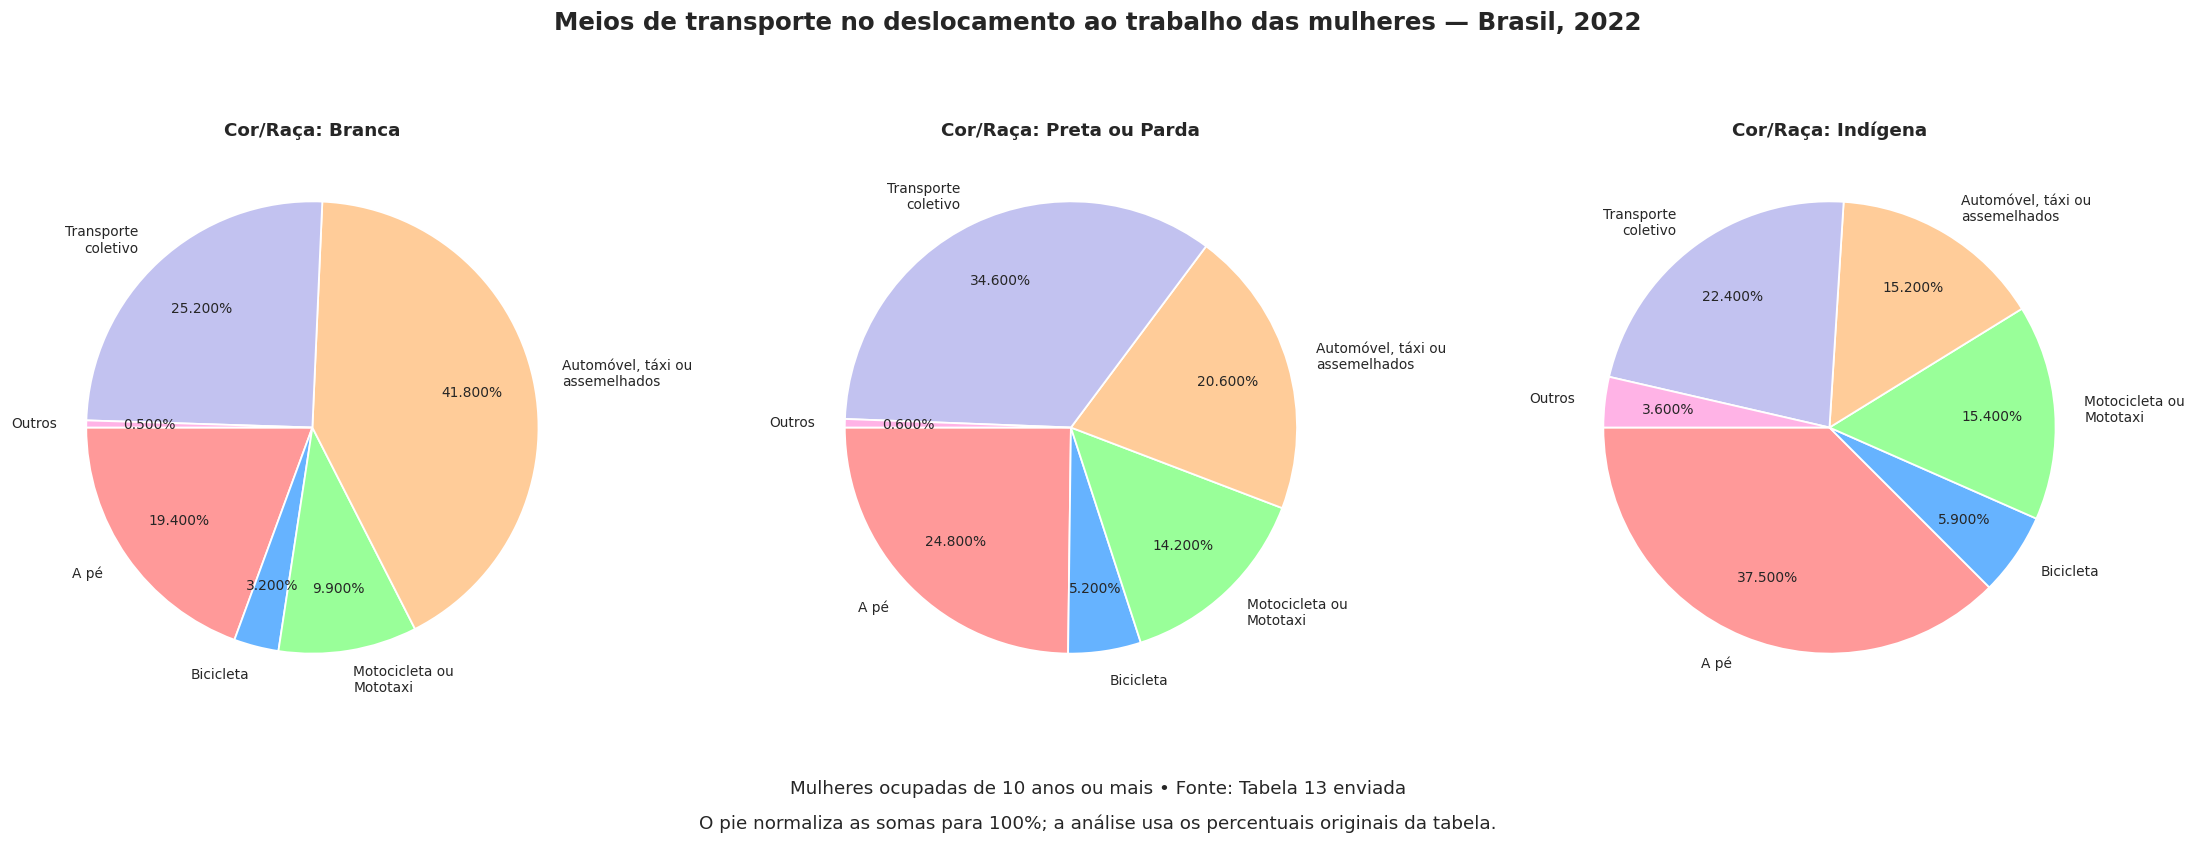

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(21, 8))
cores = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99', '#c2c2f0', '#ffb3e6']
rotulos = ['A pé', 'Bicicleta', 'Motocicleta ou\nMototaxi',
           'Automóvel, táxi ou\nassemelhados', 'Transporte\ncoletivo', 'Outros']
for i, col in enumerate(grupos):
    axes[i].pie(
        df[col], labels=rotulos, autopct='%1.3f%%',
        startangle=180, colors=cores,
        pctdistance=0.72, labeldistance=1.13,
        textprops={'fontsize': 9},
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.2},
    )
    axes[i].set_title(f'Cor/Raça: {col}', fontsize=12, fontweight='bold')
plt.suptitle('Meios de transporte no deslocamento ao trabalho das mulheres — Brasil, 2022',
             fontsize=16, fontweight='bold')
fig.text(0.5, 0.09, 'Mulheres ocupadas de 10 anos ou mais • Fonte: Tabela 13 enviada', ha='center')
fig.text(0.5, 0.05, 'O pie normaliza as somas para 100%; a análise usa os percentuais originais da tabela.', ha='center')
plt.tight_layout(rect=[0.02, 0.14, 0.98, 0.92], w_pad=4)
plt.savefig('grafico_transporte.png', dpi=300, bbox_inches='tight')
plt.show()


### Análise dos gráficos
O automóvel é o meio mais frequente entre mulheres brancas (41,8%); o transporte coletivo, entre pretas ou pardas (34,6%); e o deslocamento a pé, entre indígenas (37,5%). Essas diferenças descrevem os grupos, mas a tabela sozinha não explica suas causas.

As diferenças abaixo são em **pontos percentuais (p.p.)**, calculadas como primeiro grupo menos segundo. Por exemplo, 41,8% − 20,6% = **21,2 p.p.**, e não uma diferença relativa de 21,2%.

| Meio | Brancas − pretas ou pardas | Brancas − indígenas | Pretas ou pardas − indígenas |
|---|---:|---:|---:|
| A pé | −5,4 | −18,1 | −12,7 |
| Bicicleta | −2,0 | −2,7 | −0,7 |
| Motocicleta ou mototáxi | −4,3 | −5,5 | −1,2 |
| Automóvel, táxi ou assemelhados | +21,2 | +26,6 | +5,4 |
| Transporte coletivo | −9,4 | +2,8 | +12,2 |
| Outros | −0,1 | −3,1 | −3,0 |

Assim, mulheres pretas ou pardas têm maior participação que brancas nos deslocamentos a pé, por bicicleta, motocicleta, transporte coletivo e outros; brancas têm maior participação em automóvel. Indígenas têm as maiores participações em deslocamento a pé, bicicleta, motocicleta e outros entre os três grupos.

**Arredondamento:** os valores de pretas ou pardas somam 100,0%; os de indígenas, 100,0%; os de brancas, 100,0%. Três casas decimais nos gráficos são apenas formatação: a fonte tem uma casa decimal.


In [5]:
diferencas = df[['Meio de Transporte']].copy()
for a, b in [('Branca', 'Preta ou Parda'), ('Branca', 'Indígena'), ('Preta ou Parda', 'Indígena')]:
    diferencas[f'{a} − {b} (p.p.)'] = (df[a] - df[b]).round(3)
display(diferencas)


Meio de Transporte,Branca − Preta ou Parda (p.p.),Branca − Indígena (p.p.),Preta ou Parda − Indígena (p.p.)
A pé,-5.4,-18.1,-12.7
Bicicleta,-2.0,-2.7,-0.7
Motocicleta ou Mototaxi,-4.3,-5.5,-1.2
"Automóvel, taxi ou assemelhados",21.2,26.6,5.4
Transporte coletivo,-9.4,2.8,12.2
Outros,-0.1,-3.1,-3.0


## Parte 2 — Leitura da aba BR GR UF MU e seleção territorial

In [6]:
if ARQUIVO_EXCEL.exists():
    br_gr_uf_mu_excel = pd.read_excel(ARQUIVO_EXCEL, sheet_name="BR GR UF MU", header=None)
    display(br_gr_uf_mu_excel.head(15))
else:
    print("A tabela territorial abaixo foi reconstruída do PDF, pois o Excel não foi anexado.")


A tabela territorial abaixo foi reconstruída do PDF, pois o Excel não foi anexado.


In [7]:
nomes_estados = ['Rondônia', 'Acre', 'Amazonas', 'Roraima', 'Pará', 'Amapá', 'Tocantins',
    'Maranhão', 'Piauí', 'Ceará', 'Rio Grande do Norte', 'Paraíba', 'Pernambuco', 'Alagoas',
    'Sergipe', 'Bahia', 'Minas Gerais', 'Espírito Santo', 'Rio de Janeiro', 'São Paulo',
    'Paraná', 'Santa Catarina', 'Rio Grande do Sul', 'Mato Grosso do Sul', 'Mato Grosso', 'Goiás']
estados = territorios.loc[territorios['Localidade'].isin(nomes_estados)].copy()
ufs = territorios.loc[territorios['Localidade'].isin(nomes_estados + ['Distrito Federal'])].copy()
municipios = territorios.loc[territorios['Localidade'].str.contains(r'\([A-Z]{2}\)$', regex=True)].copy()
assert len(estados) == 26 and len(ufs) == 27 and len(municipios) == 5570
display(estados[['Localidade']].reset_index(drop=True))
print('26 estados. O Distrito Federal está separado em ufs, pois não é um estado.')


26 estados. O Distrito Federal está separado em ufs, pois não é um estado.


Localidade
Rondônia
Acre
Amazonas
Roraima
Pará
Amapá
Tocantins
Maranhão
Piauí
Ceará


### O que se pode responder às quatro perguntas?
**As quatro respostas gerais são indetermináveis com este PDF.** Ele não traz contagens nem a distribuição geral de todas as mulheres por modal. Não é correto somar ou tirar a média simples dos percentuais raciais para obter o total geral.

Para calcular quantidades seria necessário o número de mulheres ocupadas de cada grupo em cada território; para a taxa geral seria necessário ponderar pelos respectivos totais. Também seria preciso garantir a cobertura de todos os grupos raciais. Os códigos seguintes respondem à versão possível: **maior/menor percentual observado por cor/raça**, mantendo todos os empates e excluindo ausências. Um município com 100% em um grupo não necessariamente tem mais mulheres em número absoluto.


In [8]:
perguntas = [
    'Estado com mais mulheres no transporte coletivo (quantidade geral)',
    'Estado com menos mulheres no transporte coletivo (quantidade geral)',
    'Cidade com mais mulheres de bicicleta (quantidade geral)',
    'Cidade com mais mulheres de carro (quantidade geral)',
]
display(pd.DataFrame({'Pergunta': perguntas,
    'Resposta': ['Não determinável: a fonte contém apenas percentuais por cor/raça.'] * 4}))

def extremos_por_grupo(base, modo, maior=True):
    respostas = []
    for grupo in grupos:
        coluna = f'{grupo} | {modo}'
        validos = base.dropna(subset=[coluna])
        if validos.empty:
            continue
        extremo = validos[coluna].max() if maior else validos[coluna].min()
        for _, linha in validos.loc[validos[coluna].eq(extremo)].iterrows():
            respostas.append({'Cor/Raça': grupo, 'Localidade': linha['Localidade'],
                              'Percentual': extremo})
    return pd.DataFrame(respostas)


Pergunta,Resposta
Estado com mais mulheres no transporte coletivo (quantidade geral),Não determinável: a fonte contém apenas percentuais por cor/raça.
Estado com menos mulheres no transporte coletivo (quantidade geral),Não determinável: a fonte contém apenas percentuais por cor/raça.
Cidade com mais mulheres de bicicleta (quantidade geral),Não determinável: a fonte contém apenas percentuais por cor/raça.
Cidade com mais mulheres de carro (quantidade geral),Não determinável: a fonte contém apenas percentuais por cor/raça.


### 1. Maior percentual de transporte coletivo por grupo — estados

In [9]:
display(extremos_por_grupo(estados, 'Transporte coletivo'))

Cor/Raça,Localidade,Percentual
Branca,Rio de Janeiro,44.5
Preta ou Parda,Rio de Janeiro,57.8
Indígena,Rio de Janeiro,54.4


### 2. Menor percentual observado de transporte coletivo por grupo — estados

In [10]:
display(extremos_por_grupo(estados, 'Transporte coletivo', maior=False))

Cor/Raça,Localidade,Percentual
Branca,Rondônia,4.5
Preta ou Parda,Rondônia,6.6
Indígena,Rondônia,1.9


### 3. Maior percentual de bicicleta por grupo — municípios

In [11]:
display(extremos_por_grupo(municipios, 'Bicicleta'))

Cor/Raça,Localidade,Percentual
Branca,Novo Santo Antônio (MT),94.1
Preta ou Parda,Morrinhos do Sul (RS),100.0
Indígena,Cujubim (RO),100.0
Indígena,Senador Guiomard (AC),100.0
Indígena,Caracaraí (RR),100.0
Indígena,Rorainópolis (RR),100.0
Indígena,Garrafão do Norte (PA),100.0
Indígena,Redenção (PA),100.0
Indígena,Soure (PA),100.0
Indígena,Bom Jesus do Tocantins (TO),100.0


### 4. Maior percentual de automóvel por grupo — municípios

In [12]:
display(extremos_por_grupo(municipios, 'Automóvel, taxi ou assemelhados'))

Cor/Raça,Localidade,Percentual
Branca,Sítio d'Abadia (GO),83.2
Preta ou Parda,Bom Jesus do Oeste (SC),100.0
Preta ou Parda,Tupanci do Sul (RS),100.0
Indígena,Guaraí (TO),100.0
Indígena,Campestre do Maranhão (MA),100.0
Indígena,Paraibano (MA),100.0
Indígena,Porto Rico do Maranhão (MA),100.0
Indígena,Rosário (MA),100.0
Indígena,Santo Antônio dos Lopes (MA),100.0
Indígena,Baraúna (RN),100.0


### Conclusão metodológica
Os rankings acima comparam percentuais dentro de cada grupo, não quantidades gerais. `NaN` não entra nos extremos e não foi tratado como zero. “Carro” foi interpretado como a categoria disponível **automóvel, táxi ou assemelhados**. Brasília aparece no recorte municipal do arquivo; o DF fica fora da lista dos 26 estados.

Para finalizar as respostas gerais exatamente como formuladas, solicite ao professor a base com contagens ou totais populacionais compatíveis. Se o Excel tiver apenas os mesmos percentuais do PDF, ele também não resolverá essa limitação.
